In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import io
import re
import networkx as nx
from math import prod

from io import StringIO
from itertools import product, combinations, permutations
from scipy.stats import pearsonr

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from matplotlib import pyplot as plt
from matplotlib import rcParams
import seaborn as sns

import logging

In [3]:
from utils.countryconverter import convert_country_df
from utils.geomapper import plot_lisa_map
from utils.utils import load_csv_files_from_folder, significance_stars
from utils.df_processing import pairwise_deltas, pairwise_deltas, get_value_diff
from analysis.regression import compute_deltas, regression_analysis, build_monadic_features, build_neighbor_features, ols_inference, summary_table
from analysis.regression import run_singular_regression, benjamini_hochberg
from data_handling import rta, interventions, energy

In [4]:
logger = logging.getLogger()
#logger.setLevel(logging.DEBUG)
logger.setLevel(logging.INFO)

In [5]:
POWER_DATA_DIR = "../data/raw/power/"
BASIC_PROCESSED_POWER_DATA_DIR = "../data/basic_preprocessed/power/"

PREDICTORS_DATA_DIR = "../data/raw/predictors/"
BASIC_PROCESSED_PREDICTORS_DATA_DIR = "../data/basic_preprocessed/predictors/"

RES_PATH = '../output/determinants/'

#### functions

In [6]:
def preprocess_df(df, cat, df_type='power', export_csv=True, print_convertions=False):
    logging.info(f"Processing {cat}")
    # renaming columns
    df.rename({v: k for k, v in td[cat].items()}, axis=1, inplace=True)
    if cat in TYPOS:  # removing typos in country names
        df = df.replace(TYPOS[cat])
    if 'year' in df.columns:
        # converting year column
        df['year']=df['year'].astype(int)
        # removing unwanted years before load-heavy operations
        df=df[df['year']>=YEAR_START[df_type]]
        df=df[df['year']<=YEAR_END[df_type]]
    # removing excessive columns
    df = df.filter(expected_keys)
    # renaming countries
    if 'country' in df.columns:  # monadic, mostly in power
        df = convert_country_df(df, 'country', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
    elif 'country_a' in df.columns:  # dyadic, mostly in predictors
        df = convert_country_df(df, 'country_a', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
        df = convert_country_df(df, 'country_b', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
        # clearing selfloop nonsense
        df=df[df['country_a']!=df['country_b']]
        
    # dropping none-s
    if cat in MISSING_VALUES:
        for mv in MISSING_VALUES[cat]:
            df['value']=df['value'].replace(mv, np.nan)
    if 'country' in df.columns:
        df=df.dropna(subset=['value', 'country'])
    elif 'country_a' in df.columns:
        df=df.dropna(subset=['value', 'country_a', 'country_b'])
    df['value']=df['value'].astype(float)

    if cat in REVERSING_VALUE_REQUIRED:
        df['value']=(df['value'].max() - df['value'])

    # dropping duiplicates
    df=df.drop_duplicates()
    
    # ranking
    if cat in RANKING_REQUIRED:
        groupby_columns = ['year']
        if 'indicator' in df.columns:
            groupby_columns += 'indicator',
        df['rank']=df.groupby(groupby_columns)['value'].rank(ascending=False, method='average')
    if export_csv:
        export_folder = BASIC_PROCESSED_POWER_DATA_DIR if df_type=='power' else BASIC_PROCESSED_PREDICTORS_DATA_DIR
        logging.info(f"Saving f'{export_folder}{cat}.csv'")
        df.to_csv(f'{export_folder}{cat}.csv', index=False)
    return df

# Data load

In [679]:
power_dfs = {}
logging.info("Loading power dfs")
#  Мельвиль А. Ю., Каберник В. В., Миронюк М. Г., Седашов Е. А., Стукал Д. К. Национальная мощь современных государств: концептуализация, операционализация, методы анализа и рейтинг . – Полис. Политические исследования. 2025. Том 34. № 5. С. 94-111. DOI: https://doi.org/10.17976/jpps/2025.05.07. EDN: VAPRNV
power_dfs['athlas'] = pd.read_excel(f"{POWER_DATA_DIR}/national_power_athlas_2020.xlsx", sheet_name='Scores Full')
#  https://dataverse.harvard.edu/file.xhtml?fileId=10756900&version=1.0
power_dfs['gpi'] = pd.read_excel(f"{POWER_DATA_DIR}/GPI with sub-components_1816-2050_20241007.xlsx", sheet_name="Global Power Index", skiprows=[0, 2, 3])
#  Singer, J. David, Stuart Bremer, and John Stuckey. (1972). “Capability Distribution, Uncertainty, and Major Power War, 1820-1965.” in Bruce Russett (ed) Peace, War, and Numbers, Beverly Hills: Sage, 19-48.
#  https://correlatesofwar.org/data-sets/national-material-capabilities/
power_dfs['cinc'] = pd.read_csv(f"{POWER_DATA_DIR}/NMC-70-abridged.csv")
#  World Bank Development Indicators
power_dfs['gdp'] = pd.read_csv(f"{POWER_DATA_DIR}/WorldBank_GDP_since1976.csv")
power_dfs['net_subsystem'] = pd.read_csv(f"../data/analysis.csv")
power_dfs['net_hitech'] = pd.read_csv(f"../data/analysis_hitech.csv")
power_dfs['net'] = pd.read_csv(f"../data/status_combined.csv")
# IHES
power_dfs['ihes'] = pd.read_csv(f"{POWER_DATA_DIR}ihes_data.csv", index_col='Unnamed: 0')

INFO:root:Loading power dfs


In [1021]:
predictor_dfs = {}
logging.info("Loading predictor dfs")
#  Bailey, Michael A., Anton Strezhnev, and Erik Voeten. 2017. Estimating dynamic state preferences from United Nations voting data. Journal of Conflict Resolution 61 (2): 430-56. (2025-07-28)
predictor_dfs['ipd'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}AgreementScoresAll_Mar2021.csv", encoding='latin-1')
#  Leeds, Brett Ashley, Jeffrey M. Ritter, Sara McLaughlin Mitchell, and Andrew G. Long. 2002. Alliance Treaty Obligations and Provisions, 1815-1944. International Interactions 28: 237-260.
#  No non-aggression pacts dyadic version
predictor_dfs['atop'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}atop/atop5_1ddyr_NNA.csv")
#  Bruno Pellegrino, Enrico Spolaore, Romain Wacziarg, Barriers to Global Capital Allocation, The Quarterly Journal of Economics, Volume 140, Issue 4, November 2025, Pages 3067–3131
#  https://www.geopoliticaldistance.org/geographic-distance
predictor_dfs['geodistance'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}geodist_PSW24.csv")
predictor_dfs['cultdistance'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}cultural_distance_PSW2024.csv")
predictor_dfs['langdistance'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}linguistic_distance_PSW2024.csv")
#  https://mgimo.ru/about/structure/student-org/nso/gpi/docs/spatial-data/
#predictor_dfs['geopol_distance'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}geopol_borders/geopolitics.txt", sep='\s+', skiprows=1, header=None, names=['source', 'target', 'weight'])
#uses nonstandard ids
predictor_dfs['economy_net'] = pd.read_csv(f"../data/preprocessed/subsystem_level/df_economy_2022.csv")
predictor_dfs['human_net'] = pd.read_csv(f"../data/preprocessed/subsystem_level/df_human_2022.csv")
predictor_dfs['security_net'] = pd.read_csv(f"../data/preprocessed/subsystem_level/df_security_2022.csv")
# https://rtais.wto.org/
predictor_dfs['rta'] = rta.process_rta_data(file_path=f'{PREDICTORS_DATA_DIR}AllRTAs_fixeu.csv')
# MGIMO Spatial Data
predictor_dfs['de_jure_borders'] = pd.read_excel(f"{PREDICTORS_DATA_DIR}Страны-соседи.xlsx")
predictor_dfs['unfunding'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}UNfunding.csv")
# UCDP/PRIO
predictor_dfs['ucdp'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}ucdp_dyadic_v26_1.csv")
# SIPRI. https://doi.org/10.55163/CQGC9685 
predictor_dfs['milexp'] = pd.read_excel(f"{PREDICTORS_DATA_DIR}SIPRI-Milex-data-1949-2025_v1.2.xlsx", sheet_name='Constant (2024) US$', skiprows=5)
predictor_dfs['energy'] = energy.load_oil()
#predictor_dfs['nonintervention'] = interventions.load_interventions()

INFO:root:Loading predictor dfs


In [1600]:
predictor_dfs['milexp'] = pd.read_excel(f"{PREDICTORS_DATA_DIR}SIPRI-Milex-data-1949-2025_v1.2.xlsx", sheet_name='Constant (2024) US$', skiprows=5)

In [1586]:
predictor_dfs['ucdp'] = pd.read_csv(f"{PREDICTORS_DATA_DIR}ucdp_dyadic_v26_1.csv")

In [1928]:
predictor_dfs['energy'] = energy.load_oil()

INFO:root:reading 2013_2024_mirror.csv


['2013_2024_mirror.csv', '2001_2012_mirror.csv', '1989_2000_mirror.csv', '1985_1988_mirror.csv', '1985_1988.csv', '1989_2000.csv', '2001_2012.csv', '2013_2024.csv']


INFO:root:reading 2001_2012_mirror.csv
INFO:root:reading 1989_2000_mirror.csv
INFO:root:reading 1985_1988_mirror.csv
INFO:root:reading 1985_1988.csv
INFO:root:reading 1989_2000.csv
INFO:root:reading 2001_2012.csv
INFO:root:reading 2013_2024.csv
INFO:root:Removing 47 rows from <StringArray>
['CAN', 'MEX', 'USA', 'RUS', 'NGA', 'AGO', 'ARE', 'VEN', 'NOR', 'BRA',
 ...
 'CYM', 'KIR', 'MSR', 'GRL', 'COM', 'GUF', 'KNA', 'SLE', 'PLW', 'NPL']
Length: 194, dtype: str, years [2022 2024 2023 2014 2021 2013 2012 2011 2019 2018 2008 2017 2010 2015
 2020 2016 2007 2009 2006 2005 2004 2003 2000 2002 1991 1992 2001 1996
 1997 1999 1995 1993 1994 1998 1990 1989 1988]


In [1007]:
predictor_dfs['rta'] = rta.process_rta_data(file_path=f'{PREDICTORS_DATA_DIR}AllRTAs_fixeu.csv')


In [1777]:
global_predictor_dfs = {}
logging.info("Loading predictor dfs")
# https://www.eia.gov/dnav/scipy.pet/hist/LeafHandler.ashx?n=pet&s=rbrte&f=a
# https://www.officialdata.org/us-cpi (inflation data)
global_predictor_dfs['oil']= pd.read_csv(f'{PREDICTORS_DATA_DIR}Europe_Brent_Spot_Price_FOB.csv', skiprows=4)

INFO:root:Loading predictor dfs


In [165]:
#predictor_dfs['economy_net'] = pd.read_csv(f"../data/preprocessed/subsystem_level/df_economy_2022.csv")

In [34]:
original_dfs = {**power_dfs, **predictor_dfs, **global_predictor_dfs}  # to retrieve without reloading

# Data preprocessing

#### Setup

In [7]:
FILTER_UPPER_POWER_CATS = False  # в анализе участвуют только средние державы и выше
FILTER_UPPER_THRESHOLD = 2.5
FILTER_THRESHOLDS = {
    'all':(0,4), 
    'greatplus':(2.5,4), 
    'middleplus':(1.5,4), 
    'small':(0,1.5)
}
FILTER_YEARS_ALL = False
FILTER_YEARS = {
    'allyears':[],
    'stableyears':[1989,1990,1991,1992,1993,1994,2008,2009,2014,2015,2016,2017,2018,2019,2020,2021,2022],  # годы изменения миропорядка
    'turmoilyears':[1985,1986,1987,1988,1995,1996,1997,1998,1989,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2010,2011,2012,2013],
}

#  translation_dict
td = {
    'athlas':{   # + rank
        'value':'Scores_OUT',
        'country':'ISO_A3',
        'year':'Year'
    },
    'gpi':{
        'year':'Unnamed: 0',
        'country':'country',
        'value':'value'
    },
    'cinc':{
        'country':'ccode',
        'value':'cinc',
        'year':'year'
    },
    'gdp':{
        'country':'Country Code',
        'value':'value',
        'year':'year',
        'indicator':'Series Name'
    },
    'net_subsystem':  # + rank
    {
        'country':'ego',
        'year':'year',
        'value':'centrality',
        'indicator':'subsystem'
    },
    'net_hitech':
    {
        'country':'ego',
        'year':'year',
        'value':'centrality'
    },
    'net':  # + rank_combined
    {
        'country':'ego',
        'year':'year',
        'value':'weighted_centrality'
    },
    'ipd':
    {
        'country_a': 'iso3c.x',#'Countryname.x','ccode1',
        'country_b':'iso3c.y', #Countryname.y','ccode2'
        'year':'year',
        'value':'IdealPointDistance'
    },
    'geodistance':
    {
        'country_a':'countrycode_1',
        'country_b':'countrycode_2',
        'value':'avg_distance_km'
    },
    'cultdistance':
    {
        'country_a':'countrycode_1',
        'country_b':'countrycode_2',
        'value':'cultdist',
        'year':'year'
    },
    'langdistance':
    {
        'country_a':'countrycode_1',
        'country_b':'countrycode_2',
        'value':'lingdist_tree_weighted'
    },
    'geopol_distance':
    {
        'country_a':'source',
        'country_b':'target',
        'value':'weight'
    },
    'atop':
    {
        'value':'defense',
        'year':'year',
        'country_a':'stateA',
        'country_b':'stateB'
    },
    'atop_nato':
    {
        'value':'defense',
        'year':'year',
        'country_a':'stateA',
        'country_b':'stateB'
    },
    'ihes':
    {
        'value':'power_rates',
        'year':'wave',
        'country':'Alpha3_Code'
    },
    'economy_net':
    {
        'year':'year',
        'country_a':'ego',
        'country_b':'alter',
        'value':'value'
    },
    'human_net':
    {
        'year':'year',
        'country_a':'ego',
        'country_b':'alter',
        'value':'value'
    },
    'security_net':
    {
        'year':'year',
        'country_a':'ego',
        'country_b':'alter',
        'value':'value'
    },
    'rta':
    {
        'year':'year',
        'country_a':'ego',
        'country_b':'alter',
        'value':'value'
    },
    'rta_eia':
    {
        'year':'year',
        'country_a':'ego',
        'country_b':'alter',
        'value':'value'
    },
    'ihes_roles':
    {
        'value':'roles',
        'year':'wave',
        'country':'Alpha3_Code'
    },
    'ihes_new_roles':
    {
        'value':'roles_new',
        'year':'wave',
        'country':'Alpha3_Code'
    },
    'de_jure_borders':
    {
        'country_a':'level_0',
        'country_b':'Государство',
        'value':0
    },
    'unfunding':
    {
        'year':'calendar_year',
        'value':'amount',
        'country':'government_donor'
    },
    'ucdp':
    {
        'value':'value',
        'year':'year',
        'country':'gwno_a'
    },
    'milexp':
    {
        'value':'value',
        'year':'year',
        'country':'Country'
    },
    'energy_exp':
    {
        'value':'primaryValue',
        'year':'period',
        'country':'reporterISO'
    },
    'energy_imp':
    {
        'value':'primaryValue',
        'year':'period',
        'country':'partnerISO'
    }
}
NUMERIC_TYPES = {
    'athlas': None,
    'gpi': None,
    'cinc':'cow',
    'gdp':None,
    'net_subsystem':None,
    'net_hitech':None,
    'net':None,
    'ipd':None,  # Чехословакия не подтягивается
    'geodistance':None,
    'cultdistance':None,
    'langdistance':None,
    'geopol_distance':'iso', #unknown
    'atop':'cow',
    'atop_nato':'cow',
    'ihes':None,
    'economy_net':None,
    'human_net':None,
    'security_net':None,
    'rta':None,
    'rta_eia':None,
    'ihes_roles':None,
    'ihes_new_roles':None,
    'de_jure_borders':None,
    'unfunding':None,
    'ucdp':'cow',
    'milexp':None,
    'energy_exp':None,
    'energy_imp':None
}
RANKING_REQUIRED = ['athlas', 'net_subsystem', 'net']
TYPOS={
        'de_jure_borders':{'Соединные Штаты Америки':'США', 'Мадагаксар':'Мадагаскар', 'Центроальноафриканская Республика':'Центральноафриканская Республика'}
      }

REVERSING_VALUE_REQUIRED = []#['de_jure_borders']#['human_net','economy_net','security_net']
HAS_THRESHOLD = ['atop','atop_nato', 'rta', 'rta_eia', 'economy_net','de_jure_borders']
MISSING_VALUES = {
    'gdp': ['..'],
    'gpi': [1.000000e-08],
    'milexp': ['xxx','...','…']
}

YEAR_START={
    'power':1985,
    'predictor':1980  #  to enable analysis with temporal lag up to 5 years
}

YEAR_END={
    'power':2022,
    'predictor':2022
}

In [8]:
expected_keys = {key for inner in td.values() for key in inner.keys()}
expected_keys.update(['rank'])

## Additional dfs

In [727]:
NATO_ATOP_ID = 3180
# Getting NATO_only data
predictor_dfs['atop_nato'] = predictor_dfs['atop'][(predictor_dfs['atop']['atopid1']==NATO_ATOP_ID)|
                                                   (predictor_dfs['atop']['atopid2']==NATO_ATOP_ID)|
                                                   (predictor_dfs['atop']['atopid3']==NATO_ATOP_ID)|
                                                   (predictor_dfs['atop']['atopid4']==NATO_ATOP_ID)]
# Europe
#predictor_dfs['atop_nato'] = predictor_dfs['atop'][(predictor_dfs['atop']['atopid1']==3130)|(predictor_dfs['atop']['atopid2']==3130)|(predictor_dfs['atop']['atopid3']==3130)|(predictor_dfs['atop']['atopid4']==3130)]

In [728]:
predictor_dfs['atop_nato'] = preprocess_df(predictor_dfs['atop_nato'], 'atop_nato', 'predictor')

INFO:root:Processing atop_nato
INFO:root:Saving f'../data/basic_preprocessed/predictors/atop_nato.csv'


In [747]:
#temporary fix, only run once
if predictor_dfs['atop_nato'].shape[0]<100000:
    predictor_dfs['atop_nato']=predictor_dfs['atop_nato'].merge(predictor_dfs['atop'], on=['country_a', 'country_b', 'year'], how='right', suffixes=('', '_'))
    predictor_dfs['atop_nato']['value'] = predictor_dfs['atop_nato']['value'].fillna(0)
    predictor_dfs['atop_nato'] = predictor_dfs['atop_nato'].drop('value_', axis=1)

#### Unpivoting data + dataset-specific cleanup

In [1018]:
power_dfs['gpi'] = pd.melt(power_dfs['gpi'], id_vars='Unnamed: 0', value_name='value', var_name='country')

In [686]:
gdp = pd.melt(power_dfs['gdp'].drop(['Series Code'], axis=1), id_vars=['Country Name','Country Code','Series Name'], value_name='value', var_name='year')
gdp['year']=gdp.apply(lambda x: x['year'][0:4], axis=1)
gdp = gdp.dropna(subset=['value'])
power_dfs['gdp'] = gdp

In [931]:
power_dfs['ihes_roles'] = power_dfs['ihes'].copy()
power_dfs['ihes_new_roles'] = power_dfs['ihes'].copy()

In [932]:
power_dfs['ihes']['wave']=power_dfs['ihes']['wave'].apply(lambda x: x[0:4])
power_dfs['ihes_roles']['wave']=power_dfs['ihes']['wave'].apply(lambda x: x[0:4])
power_dfs['ihes_new_roles']['wave']=power_dfs['ihes']['wave'].apply(lambda x: x[0:4])

In [1008]:
predictor_dfs['rta'] = predictor_dfs['rta'][predictor_dfs['rta']['Status']=='In Force']
predictor_dfs['rta_eia'] = predictor_dfs['rta'][(predictor_dfs['rta']['Type'].str.contains('CU'))&(predictor_dfs['rta']['Type'].str.contains('EIA'))]
predictor_dfs['rta'] = rta.create_pair_year_df(predictor_dfs['rta'])
predictor_dfs['rta_eia'] = rta.create_pair_year_df(predictor_dfs['rta_eia'])

In [777]:
predictor_dfs['de_jure_borders'] = pd.DataFrame(predictor_dfs['de_jure_borders'].dropna(subset='Государство').set_index('Государство').astype(float).fillna(0).unstack()).reset_index()

In [1564]:
predictor_dfs['unfunding']['value'] = predictor_dfs['unfunding']['value'].apply(lambda x: x.replace(' ', ''))

In [1587]:
predictor_dfs['ucdp']['value'] = 1
predictor_dfs['ucdp']['gwno_a']=predictor_dfs['ucdp']['gwno_a'].apply(lambda x: x.split(','))
predictor_dfs['ucdp'] = predictor_dfs['ucdp'].explode('gwno_a')
predictor_dfs['ucdp'] = predictor_dfs['ucdp'].groupby(['gwno_a','year']).sum().reset_index()

In [1605]:
predictor_dfs['milexp'] = pd.melt(predictor_dfs['milexp'], id_vars='Country', value_name='value', var_name='year').replace({'Notes':None}).dropna()

In [1930]:
#predictor_dfs['energy']=predictor_dfs['energy'][predictor_dfs['energy']['cmdCode'].astype(str).str.contains('27')] # no need
predictor_dfs['energy_exp'] = predictor_dfs['energy'][['reporterISO','period','primaryValue']].groupby(['reporterISO','period']).sum().reset_index()
predictor_dfs['energy_imp'] = predictor_dfs['energy'][['partnerISO','period','primaryValue']].groupby(['partnerISO','period']).sum().reset_index()
del predictor_dfs['energy']

#### Preprocessing_main

In [933]:
for power_cat in power_dfs: #  ['ihes','ihes_roles','ihes_new_roles']
    power_dfs[power_cat] = preprocess_df(power_dfs[power_cat], power_cat, 'power')

for predictor_cat in predictor_dfs:
    predictor_dfs[predictor_cat] = preprocess_df(predictor_dfs[predictor_cat], predictor_cat, 'predictor')

INFO:root:Processing ihes
INFO:root:Saving f'../data/basic_preprocessed/power/ihes.csv'
INFO:root:Processing ihes_roles
INFO:root:Saving f'../data/basic_preprocessed/power/ihes_roles.csv'
INFO:root:Processing ihes_new_roles
INFO:root:Saving f'../data/basic_preprocessed/power/ihes_new_roles.csv'


In [1932]:
predictor_dfs['energy_exp'] = preprocess_df(predictor_dfs['energy_exp'], 'energy_exp', 'predictor')
predictor_dfs['energy_imp'] = preprocess_df(predictor_dfs['energy_imp'], 'energy_imp', 'predictor')

INFO:root:Processing energy_exp
INFO:root:Saving f'../data/basic_preprocessed/predictors/energy_exp.csv'
INFO:root:Processing energy_imp
INFO:root:Saving f'../data/basic_preprocessed/predictors/energy_imp.csv'


In [900]:
power_dfs['net_hitech'] = preprocess_df(power_dfs['net_hitech'], 'net_hitech', 'power')

INFO:root:Processing net_hitech
INFO:root:Saving f'../data/basic_preprocessed/power/net_hitech.csv'


In [1009]:
predictor_dfs['rta'] = preprocess_df(predictor_dfs['rta'], 'rta', 'predictor')
predictor_dfs['rta_eia'] = preprocess_df(predictor_dfs['rta_eia'], 'rta_eia', 'predictor')

INFO:root:Processing rta
INFO:root:Saving f'../data/basic_preprocessed/predictors/rta.csv'
INFO:root:Processing rta_eia
INFO:root:Saving f'../data/basic_preprocessed/predictors/rta_eia.csv'


### Loading already preprocessed

In [9]:
power_dfs = load_csv_files_from_folder(BASIC_PROCESSED_POWER_DATA_DIR)
predictor_dfs = load_csv_files_from_folder(BASIC_PROCESSED_PREDICTORS_DATA_DIR)

### Filtering

### Post-preprocess additional dfs

In [11]:
gdp = power_dfs['gdp']
power_dfs['gdp_nominal'] = gdp[gdp['indicator']=='GDP (constant 2015 US$)']
power_dfs['gdp_ppp'] = gdp[gdp['indicator']=='GDP, PPP (constant 2021 international $)']
nominal = power_dfs['gdp_nominal'].merge(gdp[gdp['indicator']=='GDP per capita (constant 2015 US$)'], on = ['country', 'year'], suffixes = ('_nominal','_percapita'))
nominal['value'] = nominal['value_nominal'] * nominal['value_percapita']
ppp = power_dfs['gdp_ppp'].merge(gdp[gdp['indicator']=='GDP per capita, PPP (constant 2021 international $)'], on = ['country', 'year'], suffixes = ('_ppp','_percapita'))
ppp['value'] = ppp['value_ppp'] * ppp['value_percapita']
power_dfs['gdp_beckley'] = nominal[['country','year','value']]
power_dfs['gdp_beckley_ppp'] = ppp[['country','year','value']]
power_dfs['gdp_beckley'].to_csv(f'{BASIC_PROCESSED_POWER_DATA_DIR}gdp_beckley.csv', index=False)
power_dfs['gdp_beckley_ppp'].to_csv(f'{BASIC_PROCESSED_POWER_DATA_DIR}gdp_beckley_ppp.csv', index=False)

In [12]:
# Getting gdp_per_capita_diff_data
_df = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP per capita, PPP (constant 2021 international $)'].drop(['indicator'],axis=1)
predictor_dfs['devdiff'] = get_value_diff(_df)

In [13]:
predictor_dfs['netdiff'] = get_value_diff(power_dfs['net'])

In [14]:
predictor_dfs['combined'] = predictor_dfs['geodistance'].merge(predictor_dfs['netdiff'], on=['country_a', 'country_b'], how='right')
predictor_dfs['combined']['value'] = predictor_dfs['combined']['value_x'] * predictor_dfs['combined']['value_y']
#predictor_dfs['combined']['value'] = predictor_dfs['geodistance']['value'] * (predictor_dfs['ipd']['value'])# * predictor_dfs['netdiff']['value']# * (predictor_dfs['ipd']['value'].apply(lambda x: 1/x))

In [15]:
predictor_dfs['energy'] = predictor_dfs['energy_exp'].merge(predictor_dfs['energy_imp'], on=['country','year'], how='outer', suffixes=('_exp','_imp')).fillna(0)
predictor_dfs['energy'] = predictor_dfs['energy'].merge(power_dfs['gdp_nominal'], on=['country','year'])
predictor_dfs['energy']['surplus'] = predictor_dfs['energy']['value_exp'] - predictor_dfs['energy']['value_imp']
predictor_dfs['energy']['exp_share'] = predictor_dfs['energy']['value_exp']/predictor_dfs['energy']['value']
predictor_dfs['energy']['imp_share'] = predictor_dfs['energy']['value_imp']/predictor_dfs['energy']['value']
predictor_dfs['energy']['surplus_share'] = predictor_dfs['energy']['surplus']/predictor_dfs['energy']['value']
predictor_dfs['energy'].loc[
    predictor_dfs['energy']['surplus_share'] > 1,
    'surplus_share'
] = 1
predictor_dfs['energy'].loc[
    predictor_dfs['energy']['surplus_share'] < -1,
    'surplus_share'
] = -1
predictor_dfs['energy'] = predictor_dfs['energy'].rename({'surplus_share':'value','value':'gdp_nominal'}, axis=1)

In [16]:
_df=(predictor_dfs['human_net']
    .merge(predictor_dfs['security_net'], on=['country_a','country_b','year'], suffixes=('_human','_security'))
    .merge(predictor_dfs['economy_net'], on=['country_a','country_b','year'], suffixes=('','_economy'))
    .rename({'value':'value_economy'}, axis=1)
)
predictor_dfs['net_combined']=_df.copy()
# Бонферрони p=q=1
predictor_dfs['net_combined']['value'] = 1 / np.sqrt(
    (_df.value_human * _df.value_security +
     _df.value_human * _df.value_economy +
     _df.value_security * _df.value_economy) / 3
)


# Analysis NEW

### Функции и константы для пространственного анализа

In [17]:
import warnings
import logging

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import libpysal
from libpysal.weights import W, full2W, KNN

import geopandas as gpd
from esda.moran import Moran, Moran_Local

from spreg import ML_Lag, ML_Error, ML_Lag_Regimes

In [18]:
import numpy as np
import pandas as pd


_AGG = {
    'mean':   'mean',
    'min':    'min',
    'max':    'max',
    'median': 'median',
    'std':    'std',
    'sum':    'sum',
}


def _reduce_vals(vals, agg):
    """Скалярная агрегация массива (без NaN)."""
    if len(vals) == 0:
        return np.nan
    if agg == 'mean':   return float(np.mean(vals))
    if agg == 'min':    return float(np.min(vals))
    if agg == 'max':    return float(np.max(vals))
    if agg == 'median': return float(np.median(vals))
    if agg == 'std':    return float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
    if agg == 'sum':    return float(np.sum(vals))
    raise ValueError(agg)


def build_exog_neighbors(df,
                         w,
                         country_names,
                         side_a='country_a',
                         side_b='country_b',
                         year_col='year',
                         value_col='value',
                         agg='mean',
                         strategy='binary',
                         year=None,
                         k=5,
                         threshold=None,
                         row_standardize=True,
                         drop_isolates_nan=True,
                         name_prefix='ipd',
                         fillna=None,
                         log=False):
    """
    Строит exog (n_countries, 1), используя только соседей из W.

    Параметры
    ---------
    df : pd.DataFrame — dyadic IPD (value, year, country_a, country_b)
    w  : libpysal W   — матрица весов
    country_names : list[str] — порядок регионов (совпадает с y и w.id_order)

    strategy : {'binary', 'weighted', 'topk'}
        'binary'   — все соседи (W[i,j] > 0) с равным весом; усредняем/берём
                     min/max/std по значениям IPD соседей.
        'weighted' — все соседи, но с весами W[i,j]. Для agg='mean'/'sum'
                     даёт взвешенное среднее/сумму; для 'min'/'max' веса
                     игнорируются (взятие экстремума не взвешивается).
        'topk'     — только k сильнейших соседей (по W[i,j] > 0).

    agg : {'mean','min','max','median','std','sum'}
        Как агрегировать IPD по соседям.
    year : int, optional — конкретный год; None = усреднить по годам.
    k : int — для strategy='topk'.
    threshold : float, optional — если задан, дополнительно оставляет только
        соседей с W[i,j] >= threshold (работает со всеми стратегиями).
    row_standardize : bool — нормировать ли веса W[i,·] в сумму 1
        при strategy='weighted'.
    drop_isolates_nan : bool — если True, у стран без соседей X = NaN
        (потом можно fillna).
    """
    if agg not in _AGG:
        raise ValueError(f"agg должен быть одним из {list(_AGG)}")
    if strategy not in {'binary', 'weighted', 'topk'}:
        raise ValueError("strategy ∈ {'binary','weighted','topk'}")

    country_names = list(country_names)
    n = len(country_names)

    # ---- проверка, что country_names ⊂ w.id_order ----
    id_order = list(w.id_order)
    name_to_w = {c: i for i, c in enumerate(id_order)}
    missing = [c for c in country_names if c not in name_to_w]
    if missing:
        raise ValueError(f"Регионы отсутствуют в w.id_order: {missing[:10]}")

    # ---- шаг 1: матрица M[r, p] (IPD, усреднённая по годам) ----
    cols = [side_a, side_b, year_col, value_col]
    d = df[cols].copy()
    if year is not None:
        d = d[d[year_col] == year]
    if d.empty:
        raise ValueError("После фильтра по year данных не осталось.")

    d[value_col] = pd.to_numeric(d[value_col], errors='coerce')
    if log:
        d[value_col] = np.log1p(d[value_col])

    # делаем IPD симметричным (a,b) → (b,a)
    long = pd.concat([
        d[[side_a, side_b, value_col]].rename(
            columns={side_a: 'focal', side_b: 'partner'}),
        d[[side_b, side_a, value_col]].rename(
            columns={side_b: 'focal', side_a: 'partner'}),
    ], ignore_index=True)

    # значение для пары = mean по годам (если year=None) или единственное значение
    pair_ser = long.groupby(['focal', 'partner'], sort=False)[value_col].mean()

    idx = pd.MultiIndex.from_product([country_names, country_names],
                                     names=['focal', 'partner'])
    M = pair_ser.reindex(idx).values.reshape(n, n)   # (n, n), NaN где нет пары

    # ---- шаг 2: W_sub в порядке country_names ----
    sub = [name_to_w[c] for c in country_names]
    W_sparse = w.sparse
    W_sub = np.asarray(W_sparse[sub][:, sub].todense())  # (n, n)

    # ---- шаг 3: агрегация по соседям ----
    X = np.full(n, np.nan)

    for i in range(n):
        row = W_sub[i]

        # --- отбор соседей ---
        if strategy == 'topk':
            # только положительные соседи
            pos = np.where(row > 0)[0]
            if pos.size == 0:
                continue
            # top-k по весу
            order = pos[np.argsort(-row[pos])]
            neigh = order[:k]
        else:
            # binary / weighted: все положительные соседи
            neigh = np.where(row > 0)[0]

        if neigh.size == 0:
            continue

        # дополнительный порог
        if threshold is not None:
            neigh = neigh[row[neigh] >= threshold]
            if neigh.size == 0:
                continue

        vals = M[i, neigh]
        wts = row[neigh]
        valid = ~np.isnan(vals)
        if not valid.any():
            continue
        vals = vals[valid]
        wts = wts[valid]

        # --- агрегация ---
        if strategy == 'binary' or agg in ('min', 'max', 'median'):
            X[i] = _reduce_vals(vals, agg)

        elif strategy == 'weighted':
            if agg == 'mean':
                w_use = wts / wts.sum() if row_standardize else wts
                X[i] = float(np.sum(w_use * vals) /
                             (w_use.sum() if not row_standardize libpysalelse 1.0))
            elif agg == 'sum':
                w_use = wts / wts.sum() if row_standardize else wts
                X[i] = float(np.sum(w_use * vals))
            elif agg == 'std':
                w_use = wts / wts.sum() if row_standardize else wts
                m = np.sum(w_use * vals) / (w_use.sum() if not row_standardize
                                            else 1.0)
                X[i] = float(np.sqrt(np.sum(w_use * (vals - m) ** 2) /
                                     (w_use.sum() if not row_standardize
                                      else 1.0)))

        elif strategy == 'topk':
            X[i] = _reduce_vals(vals, agg)

    X = X.reshape(-1, 1)

    # ---- имя ----
    parts = [name_prefix]
    if year is not None:
        parts.append(str(year))
    parts.append(strategy)
    parts.append(agg)
    name = '_'.join(parts)

    if fillna is not None:
        X = np.where(np.isnan(X), fillna, X)

    return X, [name]

In [19]:
# ======================================================================
# ПАРАМЕТРЫ (можно изменить)
# ======================================================================
HORIZON = 1                # горизонт изменения (1, 2 или 3 года)
K_NEIGHBORS = 5            # количество ближайших соседей для матрицы весов
WEIGHT_TYPE = 'inverse'#'inverse'    # 'inverse' (обратное расстояние) или 'binary' (1/0)
YEAR_FOR_MORAN = None      # если None – усредняем по всем годам; иначе укажите год
HIERARCHY_MEASURE = 'cinc'
PREDICTOR_MEASURE = 'geodistance'#'de_jure_borders'
RANDOM_TIE_BREAK = False
RANKS=True
MIN_OBS=30
RANDOM_SEED=10

def get_distance_matrix(df_x, delta_mean):
    """Преобразуем df_x (country_a, country_b, value) в квадратную матрицу расстояний
    Оставляем только страны, присутствующие в delta_mean"""
    countries = set(delta_mean['country'].tolist())
    dist_matrix = pd.pivot_table(df_x, values='value', index='country_a', columns='country_b', aggfunc='mean')
    # Симметризуем (на случай если есть пропуски)
    dist_matrix = dist_matrix.combine_first(dist_matrix.T)
    # Ограничиваемся нашими странами
    common_countries = [c for c in countries if c in dist_matrix.index and c in dist_matrix.columns]
    logging.info(f"Стран, по которым есть расстояния и дельты: {len(common_countries)}")
    dist_matrix = dist_matrix.loc[common_countries, common_countries]
    return dist_matrix

# Функция для построения весов на основе K ближайших соседей
def OLD_build_weights_knn(dist_matrix, k=K_NEIGHBORS, weight_type=WEIGHT_TYPE):
    n = dist_matrix.shape[0]
    W = np.zeros((n, n))
    for i, country_i in enumerate(dist_matrix.index):
        # Сортируем расстояния до других стран (исключая саму себя, если расстояние 0)
        distances = dist_matrix.iloc[i].copy()
        distances = distances.drop(country_i, errors='ignore')
        nearest = distances.nsmallest(k)
        for country_j, dist_ij in nearest.items():
            j = dist_matrix.columns.get_loc(country_j)
            if weight_type == 'inverse':
                # Обратное расстояние (избегаем деления на 0)
                if dist_ij > 0:
                    W[i, j] = 1.0 / dist_ij
                else:
                    W[i, j] = 0.0
            elif weight_type == 'binary':
                W[i, j] = 1.0
            else:
                raise ValueError("weight_type должен быть 'inverse' или 'binary'")
    # Нормировка строк (сумма весов в строке = 1)
    row_sums = W.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1  # избегаем деления на 0
    W_normalized = W / row_sums
    logging.info(f"Матрица весов построена: {W_normalized.shape}")
    return W_normalized, dist_matrix.index

def build_weights_knn(dist_matrix, k=K_NEIGHBORS, weight_type=WEIGHT_TYPE):
    """
    Строит строко-нормированную матрицу пространственных весов W.

    Параметры
    ---------
    dist_matrix : pd.DataFrame
        Квадратная матрица (страны × страны). Содержит либо геометрические
        расстояния (для weight_type='inverse'), либо признаки смежности
        (для weight_type='binary'): значение ≠ NaN — есть связь,
        NaN — связи нет.
    k : int
        Число ближайших соседей. Используется только при weight_type='inverse'.
    weight_type : {'inverse', 'binary'}
        'inverse' — K ближайших соседей с весами 1/d.
        'binary'  — матрица смежности: вес 1 при наличии значения в dist_matrix,
                    иначе 0. Параметр k игнорируется.

    Возвращает
    ----------
    W_normalized : np.ndarray (n, n)
        Строко-нормированная матрица весов (сумма весов в строке = 1).
    country_names : pd.Index
        Страны в порядке строк/столбцов W.
    """
    n = dist_matrix.shape[0]
    country_names = dist_matrix.index

    # ------------------------------------------------------------------
    # 1. Матрица смежности (binary)
    # ------------------------------------------------------------------
    if weight_type == 'binary':
        # Наличие значения, кроме нуля (не NaN) = наличие связи
        mask = (dist_matrix.notna() & (dist_matrix != 0)).values.astype(float)
        
        # Убираем петли на диагонали (страна не может быть соседом самой себе)
        np.fill_diagonal(mask, 0.0)

        W = mask

        # Диагностика
        deg = W.sum(axis=1)
        avg_deg = deg.mean()
        n_isolated = int((deg == 0).sum())
        logging.info(
            f"Матрица смежности построена: {W.shape}, "
            f"средняя степень = {avg_deg:.2f}, "
            f"изолированных вершин = {n_isolated}"
        )
        if n_isolated > 0:
            logging.warning(
                f"Обнаружено {n_isolated} изолированных стран "
                f"(без соседей в матрице смежности). "
                f"Они получат нулевые строки в W и будут отфильтрованы позже."
            )

        row_sums = W.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0  # защита от деления на 0
        W_normalized = W / row_sums
        return W_normalized, country_names

    # ------------------------------------------------------------------
    # 2. K ближайших соседей (inverse)
    # ------------------------------------------------------------------
    elif weight_type == 'inverse':
        W = np.zeros((n, n))
        for i, country_i in enumerate(dist_matrix.index):
            distances = (
                dist_matrix.iloc[i]
                .drop(labels=[country_i], errors='ignore')
                .dropna()  # NaN в матрице смежности не должны попадать в nsmallest
            )
            if distances.empty:
                continue
            k_eff = min(k, len(distances))
            nearest = distances.nsmallest(k_eff)
            for country_j, dist_ij in nearest.items():
                j = dist_matrix.columns.get_loc(country_j)
                W[i, j] = 1.0 / dist_ij if dist_ij > 0 else 0.0

        row_sums = W.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0
        W_normalized = W / row_sums
        logging.info(
            f"Матрица весов построена (K={k}, {weight_type}): "
            f"{W_normalized.shape}"
        )
        return W_normalized, country_names

    else:
        raise ValueError("weight_type должен быть 'inverse' или 'binary'")


def get_spatial_lag(delta_vector, W_matrix, country_names):
    """ВЫЧИСЛЕНИЕ ПРОСТРАНСТВЕННОГО ЛАГА"""
    
    # Проверка на NaN
    nan_mask = np.isnan(delta_vector)
    if nan_mask.any():
        logging.info(f"Внимание: {nan_mask.sum()} стран имеют NaN в средних дельтах. Они будут исключены.")
        delta_vector = delta_vector[~nan_mask]
        W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
        country_names = country_names[~nan_mask]
    
    # Пространственный лаг: W * delta
    lag_vector = W_matrix @ delta_vector
    #return lag_vector, delta_vector
    return lag_vector, delta_vector, W_matrix, country_names

def prepare_year_data(data_year, delta_col, dist_matrix, common_countries,
                      k_neighbors, weight_type, random_tie_break=False, seed=None,
                      ranks=True):
    """
    Принимает DataFrame data_year с колонками ['country', delta_col],
    возвращает y, W_matrix, country_names.
    Если ranks=True, ранжирует значения delta_col; иначе использует исходные.
    Также выполняет фильтрацию изолированных стран.
    """
    # Оставляем только страны из common_countries
    data_year = data_year[data_year['country'].isin(common_countries)]
    if len(data_year) < 3:
        return None, None, None

    # Ранжирование или использование исходных значений
    if ranks:
        if random_tie_break:
            if seed is not None:
                np.random.seed(seed)
            noise = np.random.uniform(-1e-6, 1e-6, size=len(data_year))
            delta_noisy = data_year[delta_col].values + noise
            ranks_sorted = rankdata(delta_noisy, method='ordinal')
            country_to_rank = dict(zip(data_year['country'], ranks_sorted))
            data_year = data_year.copy()
            data_year['rank'] = data_year['country'].map(country_to_rank).values
        else:
            data_sorted = data_year.sort_values([delta_col, 'country'])
            ranks_sorted = rankdata(data_sorted[delta_col].values, method='ordinal')
            country_to_rank = dict(zip(data_sorted['country'], ranks_sorted))
            data_year = data_year.copy()
            data_year['rank'] = data_year['country'].map(country_to_rank).values
        y = data_year['rank'].values
    else:
        y = data_year[delta_col].values

    # Построение весов
    countries_year = data_year['country'].tolist()
    dist_sub = dist_matrix.loc[countries_year, countries_year]
    W_year, country_names = build_weights_knn(dist_sub, k=k_neighbors, weight_type=weight_type)
    country_names = list(country_names)

    # Приводим порядок стран к порядку в data_year (если нужно)
    if country_names != countries_year:
        idx = [country_names.index(c) for c in countries_year]
        W_year = W_year[np.ix_(idx, idx)]
        country_names = countries_year.copy()

    # Фильтрация изолированных
    row_sums = W_year.sum(axis=1)
    keep_mask = row_sums > 0
    if (~keep_mask).any():
        y = y[keep_mask]
        W_year = W_year[keep_mask][:, keep_mask]
        country_names = [country_names[i] for i in range(len(country_names)) if keep_mask[i]]

    return y, W_year, country_names
def plot_spatial_lag(lag_vector, delta_vector, savename=None, 
                     hierarchy_name=None, k_neighbors=K_NEIGHBORS, weight_type=WEIGHT_TYPE,
                     horizon=HORIZON, predictor_measure=PREDICTOR_MEASURE, ranks=False
                    ):
    if ranks:
        delta_vector = rankdata(delta_vector)
        lag_vector = rankdata(lag_vector)
        ranked_label_file = '_ranked'
        ranked_name = ' по рангам'
    else:
        ranked_label_file = ''
        ranked_name = ' '
        
    plt.figure(figsize=(8, 6))
    sns.regplot(x=lag_vector, y=delta_vector, ci=95, scatter_kws={'alpha': 0.7})
    plt.xlabel('Пространственный лаг (средневзвешенное изменение иерархии соседей)')
    plt.ylabel('Cреднее изменение иерархии)')
    
    if hierarchy_name:
        plt.title(f'Связь между изменением иерархии{ranked_name} ({hierarchy_name}) и лагом\n (K={k_neighbors}, weight({predictor_measure})={weight_type}, h={horizon})')
    else:
        plt.title(f'Связь между изменением иерархии{ranked_name} и лагом\n(K={k_neighbors}, weight({predictor_measure})={weight_type}, h={horizon})')
    if savename is None:
        savename = f'spatial_lag{ranked_label_file}_{str(hierarchy_name)}_{str(predictor_measure)}'
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{RES_PATH}/{savename}.png', dpi=350)
    plt.show()

def basic_corr(lag_vector, delta_vector):
    pearson_r, pearson_p = stats.pearsonr(lag_vector, delta_vector)
    spearman_r, spearman_p = stats.spearmanr(lag_vector, delta_vector)
    logging.info("=== Корреляция между изменением положения в иерархии и пространственным лагом ===")
    logging.info(f"Пирсон: r = {pearson_r:.4f}, p-value = {pearson_p:.4f}")
    logging.info(f"Спирмен: r = {spearman_r:.4f}, p-value = {spearman_p:.4f}")
    res_dict = {
        'pearson':
        {
            'r':pearson_r,
            'p':pearson_p
        },
        'spearman':
        {
            'r':spearman_r,
            'p':spearman_p
        }
    }
    return res_dict

def get_moran(delta_vector, W_matrix, country_names, permutations=999, ranks=False):
    
    if ranks:
        logging.info('converting to ranked data')
        ranks = rankdata(delta_vector)  # по возрастанию
        delta_vector = ranks
        ranked_label = 'Ранговый '
    else:
        ranked_label = ''

    logging.info(f"=== {ranked_label}Moran's I ===")
    # Создаём объект весов libpysal из матрицы
    w = full2W(W_matrix, ids=list(country_names))
    
    moran = Moran(delta_vector, w, permutations=permutations)
    
    logging.info(f"I = {moran.I:.4f}")
    logging.info(f"p-value (перестановочный) = {moran.p_sim:.4f}")
    logging.info(f"Ожидаемое I при отсутствии автокорреляции: {moran.EI:.4f}")
    if moran.p_sim < 0.05:
        logging.info(f"{ranked_label} Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.")
    else:
        logging.info(f"{ranked_label} Moran's I НЕ значим.")
    return moran

"""def compute_sar(delta_vector, w, include_sem=True, ranks=False, hierarchy_name=None, weight_type=None, display_results=True):
    # Подготовка данных: зависимая переменная - ранги, независимая - константа (или другие переменные, если есть)
    # В пространственной модели с лагом (SAR) зависимая переменная моделируется как
    #   y = rho * W * y + X * beta + epsilon
    # Мы будем использовать только константу в X, чтобы оценить чистый пространственный эффект.

    if ranks:
        logging.info('converting to ranked data')
        ranks = rankdata(delta_vector)  # по возрастанию
        delta_vector = ranks
        ranked_label = ' на рангах'
    else:
        ranked_label = ''
    
    X = np.ones((len(delta_vector), 1))  # константа
    y = delta_vector
    
    # Оценка модели SAR методом максимального правдоподобия
    model_sar = ML_Lag(y, X, w=w, name_y=hierarchy_name, name_x=['const'], name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная регрессия (SAR){ranked_label} ===")
        logging.info(model_sar.summary)
    if include_sem:
        # Если нужно также оценить SEM (пространственная ошибка)
        model_sem = ML_Error(y, X, w=w, name_y=hierarchy_name, name_x=['const'], name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) на рангах ===")
            logging.info(model_sem.summary)
        return model_sar, model_sem
    return model_sar
"""
def plot_lisa_for_year(year, df_y, df_x, hierarchy_measure, horizon,
                       k_neighbors, weight_type, shapefile_path,
                       random_tie_break=False, seed=None,
                       min_obs=10, ranks=True, permutations=999,
                       figsize=(12, 10), save_path=None):
    """
    Строит LISA-карту локальных индикаторов пространственной автокорреляции
    для изменений индекса иерархии в указанный год.
    """
    # 1. Вычисляем изменение индекса для выбранного года
    df_y_for_deltas = df_y[['country', 'year', 'value']]
    delta_year = compute_deltas(df_y_for_deltas, horizons=(horizon,), year=year)
    if delta_year.empty:
        logging.warning(f"Нет данных за {year} год")
        return

    # 2. Ограничиваем странами, для которых есть расстояния
    all_countries = sorted(set(df_y['country']))
    delta_mean_for_dist = pd.DataFrame({'country': all_countries})
    full_dist_matrix = get_distance_matrix(df_x, delta_mean_for_dist)
    common_countries = full_dist_matrix.index.tolist()

    data = delta_year[delta_year['country'].isin(common_countries)]
    if len(data) < min_obs:
        logging.warning(f"Недостаточно наблюдений для {year} года")
        return

    # 3. Подготовка данных: ранжирование, веса, фильтрация изолированных
    y, W_year, country_names = prepare_year_data(
        data, 'delta_mean', full_dist_matrix, common_countries,
        k_neighbors, weight_type, random_tie_break,
        seed + year if seed is not None else None,
        ranks=ranks
    )
    if y is None or len(y) < min_obs:
        logging.warning(f"Слишком мало стран после фильтрации для {year}")
        return

    # 4. Вычисляем локальный Moran's I
    w = full2W(W_year, ids=country_names)
    moran_loc = Moran_Local(y, w, permutations=permutations, seed=seed)

    # 5. Определяем значимость и квадранты
    sig = moran_loc.p_sim < 0.05
    q = moran_loc.q

    lisa_df = pd.DataFrame({
        'country': country_names,
        'p_sim': moran_loc.p_sim,
        'q': q
    })
    lisa_df['significant'] = sig
    lisa_df['cluster'] = 'Нет значимости'
    lisa_df.loc[sig & (q == 1), 'cluster'] = 'High-High'
    lisa_df.loc[sig & (q == 3), 'cluster'] = 'Low-Low'
    lisa_df.loc[sig & (q == 4), 'cluster'] = 'High-Low'
    lisa_df.loc[sig & (q == 2), 'cluster'] = 'Low-High'

    # 6. Загружаем шейп-файл и сопоставляем названия
    def _normalize_country_name(name):
        if not isinstance(name, str):
            return name
        name = name.strip().lower()
        name = name.replace('turkey', 'türkiye')
        name = ''.join(ch for ch in name if ch.isalnum())
        return name

    gdf = gpd.read_file(shapefile_path).set_index('STATE_en_U')
    gdf['norm_name'] = gdf.index.map(_normalize_country_name)
    lisa_df['norm_country'] = lisa_df['country'].map(_normalize_country_name)
    cluster_map = dict(zip(lisa_df['norm_country'], lisa_df['cluster']))
    gdf['cluster'] = gdf['norm_name'].map(cluster_map).fillna('Нет данных')

    # 7. Строим карту
    plot_lisa_map(gdf, year, horizon, k_neighbors, weight_type, figsize, save_path)
def prepare_deltas(df_y, hierarchy_measure, horizon):
    """
    Вычисляет изменения индекса иерархии для заданного горизонта.
    Возвращает DataFrame с колонками country, year и delta_{horizon}.
    """
    # Переименовываем столбец иерархии в 'value' для совместимости с compute_deltas
    df_y_value = df_y[['country', 'year', hierarchy_measure]].rename(
        columns={hierarchy_measure: 'value'}
    )
    deltas_df = compute_deltas(
        df_y_value,
        horizons=(horizon,),
        year=None,
        return_yearly_mean=False
    )
    return deltas_df


def prepare_distance_matrix(df_x, df_y):
    """
    Готовит матрицу расстояний, ограниченную странами из df_y.
    Возвращает dist_matrix и список common_countries.
    """
    all_countries = sorted(set(df_y['country']))
    delta_mean_for_dist = pd.DataFrame({'country': all_countries})
    dist_matrix = get_distance_matrix(df_x, delta_mean_for_dist)
    common_countries = dist_matrix.index.tolist()
    return dist_matrix, common_countries


def rank_delta_values(data_year, delta_col, random_tie_break=False, seed=None):
    """
    Ранжирует изменения индекса внутри года.
    Возвращает копию data_year с добавленным столбцом rank_in_year.
    """
    if random_tie_break:
        if seed is not None:
            np.random.seed(seed)
        noise = np.random.uniform(-1e-6, 1e-6, size=len(data_year))
        delta_noisy = data_year[delta_col].values + noise
        ranks_sorted = rankdata(delta_noisy, method='ordinal')
        country_to_rank = dict(zip(data_year['country'], ranks_sorted))
        ranks = data_year['country'].map(country_to_rank).values
    else:
        data_year_sorted = data_year.sort_values([delta_col, 'country']).reset_index(drop=True)
        ranks_sorted = rankdata(data_year_sorted[delta_col].values, method='ordinal')
        country_to_rank = dict(zip(data_year_sorted['country'], ranks_sorted))
        ranks = data_year['country'].map(country_to_rank).values

    data_year = data_year.copy()
    data_year['rank_in_year'] = ranks
    return data_year


def filter_isolated(W_year, country_names, rank_vals):
    """
    Удаляет изолированные страны (с нулевой суммой весов) из матрицы весов,
    списка стран и вектора значений.
    Возвращает отфильтрованные W_year, country_names, rank_vals.
    """
    row_sums = W_year.sum(axis=1)
    keep_mask = row_sums > 0
    if (~keep_mask).any():
        rank_vals = rank_vals[keep_mask]
        W_year = W_year[keep_mask][:, keep_mask]
        country_names = [country_names[i] for i in range(len(country_names)) if keep_mask[i]]
    return W_year, country_names, rank_vals


def compute_sar_metrics(rank_vals, W_year, country_names, weight_type):
    """
    Оценивает SAR-модель и возвращает rho и p-value.
    """
    w = full2W(W_year, ids=country_names)
    try:
        model_sar = compute_sar(
            rank_vals, w,
            include_sem=False,
            ranks=False,
            hierarchy_name='rank_in_year',
            weight_type=weight_type,
            display_results=False
        )
        rho = model_sar.rho
        se_rho = np.nan
        if hasattr(model_sar, 'vm'):
            se_rho = np.sqrt(model_sar.vm[1, 1])
        elif hasattr(model_sar, 'se_rho'):
            se_rho = model_sar.se_rho
        else:
            try:
                z_rho = model_sar.z_stat[1][2]
                se_rho = rho / z_rho
            except:
                se_rho = np.nan
        if not np.isnan(se_rho):
            z_rho = rho / se_rho
            rho_p = 2 * (1 - norm.cdf(abs(z_rho)))
        else:
            rho_p = np.nan
        return rho, rho_p
    except Exception as e:
        logging.error(f"Ошибка SAR: {e}")
        return np.nan, np.nan


def process_year(data_year, dist_matrix, common_countries, year, delta_col,
                 k_neighbors, weight_type, random_tie_break=False, seed=None,
                 min_obs=10):
    """
    Обрабатывает один год: ранжирование, веса, Moran's I и SAR.
    Возвращает словарь с результатами или None, если данных недостаточно.
    """
    # 1. Отбираем страны, присутствующие в матрице расстояний
    data_year = data_year[data_year['country'].isin(common_countries)].copy()

    #страхуемся от дубликатов стран внутри года
    n_before = len(data_year)
    data_year = data_year.drop_duplicates(subset=['country'], keep='first')
    if len(data_year) < n_before:
        logging.warning(
            f"[{year}] Удалено {n_before - len(data_year)} дубликатов стран "
            f"(осталось {len(data_year)})"
        )

    if len(data_year) < min_obs:
        logging.warning(f"Недостаточно данных в {year}")
        return None

    # 2. Подготовка данных: ранжирование, веса, фильтрация изолированных
    #    (prepare_year_data уже включает фильтрацию по common_countries, но data_year уже отфильтрован)
    y, W_year, country_names = prepare_year_data(
        data_year, delta_col, dist_matrix, common_countries,
        k_neighbors, weight_type, random_tie_break,
        seed + year if seed is not None else None
    )

    # Если данных слишком мало (например, меньше 3) или после фильтрации изолированных
    if y is None or len(y) < min_obs:
        logging.warning(f"Недостаточно наблюдений после фильтрации в {year}")
        return None

    # 3. Moran's I
    moran = get_moran(y, W_year, country_names, permutations=999, ranks=False)
    moran_I = moran.I
    moran_p = moran.p_sim

    # 4. SAR
    rho, rho_p = compute_sar_metrics(y, W_year, country_names, weight_type)

    return {
        'year': year,
        'n_obs': len(y),
        'moran_I': moran_I,
        'moran_p': moran_p,
        'rho': rho,
        'rho_p': rho_p
    }


def run_yearly_analysis(deltas_df, delta_col, dist_matrix, common_countries,
                        k_neighbors, weight_type, random_tie_break=False,
                        seed=None, min_obs=10):
    """
    Выполняет анализ по всем годам и возвращает DataFrame с результатами.
    """
    years = sorted(deltas_df['year'].unique())
    results = []
    for year in years:
        logging.info(f'year is {year}')
        data_year = deltas_df[deltas_df['year'] == year][['country', delta_col]].dropna()
        res = process_year(
            data_year, dist_matrix, common_countries, year, delta_col,
            k_neighbors, weight_type, random_tie_break, seed, min_obs
        )
        if res is not None:
            results.append(res)
    return pd.DataFrame(results)


def plot_yearly_results(results_df, hierarchy_name=None, predictor_measure=None,
                       weight_type=None, horizon=None, k_neighbors=None):
    """
    Строит графики Moran's I и rho по годам.
    """
    if results_df.empty:
        print("Нет данных для построения графиков.")
        return

    plt.figure(figsize=(12, 5))
    
    # График Moran's I
    plt.subplot(1, 2, 1)
    plt.plot(results_df['year'], results_df['moran_I'], marker='o', linestyle='-', color='b')
    sig = results_df['moran_p'] < 0.05
    plt.scatter(results_df['year'][sig], results_df['moran_I'][sig],
                color='red', s=60, zorder=5, label='p < 0.05')
    plt.axhline(0, color='gray', linestyle='--', alpha=0.7)
    plt.xlabel('Год')
    plt.ylabel("Moran's I")
    #plt.title('Пространственная автокорреляция рангов изменения индекса иерархии')
    if hierarchy_name:
        plt.title(f'Пространственная автокорреляция рангов изменения индекса иерархии ({hierarchy_name})\n (K={k_neighbors}, weight({predictor_measure})={weight_type})')
    else:
        plt.title(f'Пространственная автокорреляция рангов изменения индекса иерархии\n(K={k_neighbors}, weight({predictor_measure})={weight_type})')

    plt.grid(alpha=0.3)
    plt.legend()

    # График rho (SAR)
    plt.subplot(1, 2, 2)
    plt.plot(results_df['year'], results_df['rho'], marker='s', linestyle='-', color='g')
    sig_rho = results_df['rho_p'] < 0.05
    plt.scatter(results_df['year'][sig_rho], results_df['rho'][sig_rho],
                color='red', s=60, zorder=5, label='p < 0.05')
    plt.axhline(0, color='gray', linestyle='--', alpha=0.7)
    plt.xlabel('Год')
    plt.ylabel('ρ')
    plt.title(f'Коэффициент пространственного лага (SAR) ({hierarchy_name})')
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.savefig(f'{RES_PATH}/yearly_analysis/{hierarchy_name}_{predictor_measure}_{weight_type}.png', dpi=350)
    plt.show()

def run_yearly_spatial_analysis(df_y, df_x, hierarchy_measure, horizon,
                         k_neighbors, weight_type, predictor_measure,
                         random_tie_break=False, seed=None, min_obs=10):
    """
    Выполняет полный цикл пространственного анализа по годам:
    подготовка дельт, матрицы расстояний, расчёт Moran's I и SAR,
    вывод таблицы результатов и построение графиков.

    Параметры:
        df_y : DataFrame с колонками ['country', 'year', 'value'].
        df_x : DataFrame с колонками ['country_a', 'country_b', 'value'] (расстояния).
        hierarchy_measure : str, название столбца с индексом (обычно 'value').
        horizon : int, горизонт изменения.
        k_neighbors : int, число ближайших соседей.
        weight_type : str, 'binary' или 'inverse'.
        predictor_measure : str, название меры расстояния (для подписей графиков).
        random_tie_break : bool, добавлять ли случайный шум при ранжировании.
        seed : int или None, зерно для воспроизводимости.
        min_obs : int, минимальное число наблюдений для включения года.

    Возвращает:
        results_df : DataFrame с результатами по годам.
    """
    # 1. Подготовка данных
    deltas_df = prepare_deltas(df_y, 'value', horizon)
    delta_col = f'delta_{horizon}'

    # 2. Матрица расстояний
    dist_matrix, common_countries = prepare_distance_matrix(df_x, df_y)

    # 3. Анализ по годам
    results_df = run_yearly_analysis(
        deltas_df, delta_col, dist_matrix, common_countries,
        k_neighbors=k_neighbors,
        weight_type=weight_type,
        random_tie_break=random_tie_break,
        seed=seed,
        min_obs=min_obs
    )

    # 4. Вывод таблицы
    logging.info("\nСводная таблица по годам:")
    logging.info(results_df.to_string(index=False))

    # 5. Графики
    plot_yearly_results(
        results_df,
        k_neighbors=k_neighbors,
        weight_type=weight_type,
        predictor_measure=predictor_measure,
        hierarchy_name=hierarchy_measure
    )

    return results_df

def _prepare_data(y, exog=None, add_const=True, exog_names=None):
    """
    Вспомогательная функция: формирует матрицу X и список имён переменных.
    
    Параметры:
        y : одномерный массив зависимой переменной (используется только для определения n)
        exog : ndarray (n, k) или None
        add_const : bool, добавлять ли константу, если exog передан
        exog_names : список имён для столбцов exog (без константы)
    
    Возвращает:
        X : ndarray (n, p)
        name_x : list of str
    """
    n = len(y)
    if exog is None:
        X = np.ones((n, 1))
        name_x = ['const']
    else:
        exog = np.asarray(exog)
        if exog.ndim == 1:
            exog = exog.reshape(-1, 1)
        if add_const:
            X = np.hstack([np.ones((n, 1)), exog])
            if exog_names is None:
                names = ['const'] + [f'x{i+1}' for i in range(exog.shape[1])]
            else:
                if len(exog_names) != exog.shape[1]:
                    raise ValueError("Длина exog_names должна совпадать с числом столбцов exog")
                names = ['const'] + list(exog_names)
        else:
            X = exog
            if exog_names is None:
                names = [f'x{i+1}' for i in range(exog.shape[1])]
            else:
                if len(exog_names) != exog.shape[1]:
                    raise ValueError("Длина exog_names должна совпадать с числом столбцов exog")
                names = list(exog_names)
        name_x = names
    return X, name_x


def compute_sar(delta_vector, w, include_sem=True, ranks=False, hierarchy_name=None,
                weight_type=None, display_results=True,
                exog=None, add_const=True, exog_names=None):
    """
    Оценка пространственной авторегрессионной модели (SAR) и, опционально, модели
    пространственной ошибки (SEM). Теперь поддерживает произвольный набор объясняющих
    переменных (например, dummy для категорий).

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        include_sem : bool
            Если True, дополнительно оценивается SEM.
        ranks : bool
            Если True, зависимая переменная ранжируется.
        hierarchy_name : str, optional
            Имя зависимой переменной для отображения.
        weight_type : str, optional
            Имя матрицы весов для отображения.
        display_results : bool
            Печатать ли сводку модели.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы). Если None, используется только константа.
        add_const : bool
            Добавлять ли константу к exog (если exog передан). По умолчанию True.
        exog_names : list of str, optional
            Имена столбцов exog (без константы). Если None, генерируются 'x1', 'x2', ...

    Возвращает:
        model_sar или кортеж (model_sar, model_sem)
    """
    # Ранжирование зависимой переменной
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const, exog_names=exog_names)

    # Имя зависимой переменной
    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # SAR
    model_sar = ML_Lag(y, X, w=w, name_y=name_y, name_x=name_x, name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная регрессия (SAR){ranked_label} ===")
        logging.info(model_sar.summary)

    if include_sem:
        model_sem = ML_Error(y, X, w=w, name_y=name_y, name_x=name_x, name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) ===")
            logging.info(model_sem.summary)
        return model_sar, model_sem
    return model_sar

def compute_sdm(delta_vector, w, include_sem=False, ranks=False, hierarchy_name=None,
                weight_type=None, display_results=True,
                exog=None, add_const=True, exog_names=None,
                w_lags=1, display_impacts=False):
    """
    Оценка пространственной модели Дарбина (SDM) и, опционально, модели
    пространственной ошибки (SEM) на тех же данных.

    Модель Дарбина:
        y = ρ * W * y + X * β + W * X * θ + ε

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        include_sem : bool
            Если True, дополнительно оценивается SEM (для сравнения).
        ranks : bool
            Если True, зависимая переменная ранжируется.
        hierarchy_name : str, optional
            Имя зависимой переменной для отображения.
        weight_type : str, optional
            Имя матрицы весов для отображения.
        display_results : bool
            Печатать ли сводку модели.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы). Если None,
            используется только константа.
        add_const : bool
            Добавлять ли константу к exog (если exog передан). По умолчанию True.
        exog_names : list of str, optional
            Имена столбцов exog (без константы). Если None, генерируются
            'x1', 'x2', ...
        w_lags : int
            Порядок пространственных лагов экзогенных переменных.
            w_lags=1 соответствует классической модели Дарбина.
        display_impacts : bool
            Печатать ли прямые, косвенные и полные эффекты (spatial impacts).

    Возвращает:
        model_sdm или кортеж (model_sdm, model_sem)
    """
    # Ранжирование зависимой переменной
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const,
                              exog_names=exog_names)

    # Имя зависимой переменной
    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # SDM: ML_Lag с пространственными лагами экзогенных переменных (w_lags=1)
    model_sdm = ML_Lag(y, X, w=w, w_lags=w_lags,
                       name_y=name_y, name_x=name_x, name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная модель Дарбина (SDM){ranked_label} ===")
        logging.info(model_sdm.summary)

    # Прямые / косвенные / полные эффекты (spatial impacts)
    if display_impacts:
        try:
            impacts = model_sdm.spatial_impacts  # spreg >= 1.1
            if display_results:
                logging.info("\n=== Пространственные эффекты (SDM) ===")
                logging.info(impacts.summary)
        except Exception as e:
            logging.warning(f"Не удалось рассчитать пространственные эффекты: {e}")

    # Опционально — оценка SEM на тех же данных (для сравнения моделей)
    if include_sem:
        model_sem = ML_Error(y, X, w=w, name_y=name_y,
                             name_x=name_x, name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) ===")
            logging.info(model_sem.summary)
        return model_sdm, model_sem

    return model_sdm

def compute_sar_regimes(delta_vector, w, regimes, include_sem=True, ranks=False,
                        hierarchy_name=None, weight_type=None, display_results=True,
                        exog=None, add_const=True, exog_names=None, regime_lag_sep=False):
    """
    Оценка пространственной модели с пространственными режимами (spatial regimes).
    Для каждой группы (категории) оцениваются свои коэффициенты, включая пространственный
    параметр (rho для SAR, lambda для SEM).

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        regimes : array_like (n,)
            Одномерный массив меток групп для каждого наблюдения.
            Либо список списков индексов (будет преобразован в одномерный список меток).
        include_sem : bool
            Оценивать ли также SEM с режимами.
        ranks : bool
            Ранжировать зависимую переменную.
        hierarchy_name : str, optional
            Имя зависимой переменной.
        weight_type : str, optional
            Имя матрицы весов.
        display_results : bool
            Печатать ли сводку.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы).
        add_const : bool
            Добавлять ли константу к exog.
        exog_names : list of str, optional
            Имена переменных exog.
        regime_lag_sep : bool

    Возвращает:
        model_sar_regimes или кортеж (model_sar_regimes, model_sem_regimes)
    """
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const, exog_names=exog_names)

    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # Проверка regimes
    if regimes is None:
        raise ValueError("regimes не может быть None")
    if len(regimes) != len(y):
        raise ValueError(f"Длина regimes ({len(regimes)}) не совпадает с длиной y ({len(y)})")

    # Преобразуем regimes в одномерный список (это требование spreg)
    if isinstance(regimes, (np.ndarray, pd.Series)):
        regimes = regimes.tolist()
    elif isinstance(regimes, list):
        # Если это список списков, преобразуем в одномерный список меток
        if len(regimes) > 0 and isinstance(regimes[0], list):
            n = len(y)
            regime_labels = np.empty(n, dtype=int)
            for label, indices in enumerate(regimes):
                for idx in indices:
                    regime_labels[idx] = label
            regimes = regime_labels.tolist()
        else:
            # Уже одномерный список — оставляем как есть
            pass
    else:
        raise TypeError("regimes должен быть списком, numpy-массивом или pandas Series")

    # Дополнительная проверка: после преобразования длина должна сохраниться
    if len(regimes) != len(y):
        raise ValueError("После преобразования длина regimes не совпадает с y")

    # Оценка SAR с режимами
    model_sar_regimes = ML_Lag(y, X, w=w, regimes=regimes,
                               name_y=name_y, name_x=name_x, name_w=weight_type, regime_lag_sep=regime_lag_sep)
    if display_results:
        logging.info(f"=== Пространственная регрессия с режимами (SAR){ranked_label} ===")
        logging.info(model_sar_regimes.summary)

    if include_sem:
        model_sem_regimes = ML_Error(y, X, w=w, regimes=regimes,
                                     name_y=name_y, name_x=name_x, name_w=weight_type, regime_lag_sep=regime_lag_sep)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки с режимами (SEM) ===")
            logging.info(model_sem_regimes.summary)
        return model_sar_regimes, model_sem_regimes
    return model_sar_regimes

_AGG_FUNCS = {
    'mean':   lambda v: float(np.mean(v)),
    'min':    lambda v: float(np.min(v)),
    'max':    lambda v: float(np.max(v)),
    'median': lambda v: float(np.median(v)),
    'std':    lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else np.nan,
}

def _remove_isolates(W_matrix, country_names, min_obs=1):
    """
    Удаляет изоляты из матрицы весов и списка стран.
    Изолят — наблюдение, у которого сумма весов по строке равна 0.
    """
    # Суммы по строкам: поддержка dense numpy и scipy.sparse
    if hasattr(W_matrix, "toarray"):
        row_sums = np.asarray(W_matrix.sum(axis=1)).ravel()
    else:
        row_sums = np.asarray(W_matrix).sum(axis=1)

    keep = row_sums > 0
    n_removed = int((~keep).sum())

    if n_removed:
        logging.info(f"Удалено изолятов: {n_removed}")

    country_names = [c for c, k in zip(country_names, keep) if k]

    if len(country_names) == 0:
        raise ValueError("После удаления изолятов не осталось наблюдений.")
    if len(country_names) < min_obs:
        logging.warning(
            f"После удаления изолятов осталось {len(country_names)} наблюдений, "
            f"что меньше min_obs={min_obs}."
        )

    if hasattr(W_matrix, "tocsr"):
        W_matrix = W_matrix.tocsr()[keep][:, keep]
    else:
        W_matrix = np.asarray(W_matrix)[keep][:, keep]

    return W_matrix, country_names


def _compute_hostility_score(ipd_df, countries, w=None, year=None,
                             agg='mean', min_partners=1):
    """
    Для каждой страны из `countries` считает агрегат IPD по её окружению.

    Окружение:
      * w=None    → все партнёры из IPD (глобальное окружение);
      * w задана  → только соседи по матрице W (дружественное окружение).

    IPD симметричен: (a, b) и (b, a) дают один и тот же вклад.
    """
    df = ipd_df[['country_a', 'country_b', 'year', 'value']].copy()
    if year is not None:
        df = df[df['year'] == year]
    df['value'] = pd.to_numeric(df['value'], errors='coerce')

    # симметричное разворачивание
    long = pd.concat([
        df[['country_a', 'country_b', 'value']].rename(
            columns={'country_a': 'focal', 'country_b': 'partner'}),
        df[['country_b', 'country_a', 'value']].rename(
            columns={'country_b': 'focal', 'country_a': 'partner'}),
    ], ignore_index=True)

    # средний IPD для пары по годам
    pair = long.groupby(['focal', 'partner'], sort=False)['value'].mean()

    score = {}
    if w is None:
        grouped = pair.groupby(level='focal')
        for c in countries:
            if c not in grouped.groups:
                score[c] = np.nan
                continue
            vals = grouped.get_group(c).values
            vals = vals[~np.isnan(vals)]
            score[c] = (_AGG_FUNCS[agg](vals)
                        if len(vals) >= min_partners else np.nan)
    else:
        id_order = list(w.id_order)
        idx_of = {c: i for i, c in enumerate(id_order)}
        n = len(id_order)
        M = np.full((n, n), np.nan)
        for (f, p), v in pair.items():
            if f in idx_of and p in idx_of:
                M[idx_of[f], idx_of[p]] = v
        W_dense = np.asarray(w.sparse.todense())

        for c in countries:
            if c not in idx_of:
                score[c] = np.nan
                continue
            i = idx_of[c]
            neigh = np.where(W_dense[i] > 0)[0]
            vals = M[i, neigh]
            vals = vals[~np.isnan(vals)]
            score[c] = (_AGG_FUNCS[agg](vals)
                        if len(vals) >= min_partners else np.nan)

    return pd.Series(score, name='hostility_score')


def add_power_cat(df_y, ihes_cats=None, ignore_super=False,
                  ipd_df=None, w=None,
                  hostility_year=None, hostility_agg='mean',
                  hostility_thresholds=(1.0, 2.0, 3.0),
                  hostility_labels=('friendly', 'neutral', 'tense', 'hostile'),
                  min_partners=1, country_label='country'):
    """
    Добавляет к df_y три колонки:

      * 'category'         — уровень могущества (power category) по ihes;
      * 'hostility_score'  — агрегированный IPD окружения (число);
      * 'hostility'        — категория враждебности окружения.

    Параметры
    ---------
    df_y : pd.DataFrame
        Должен содержать колонку 'country'.
    ihes_cats : pd.DataFrame, optional
        Таблица с колонками 'country', 'year', 'value'.
        По умолчанию — power_dfs['ihes'].
    ignore_super : bool
        Если True, 'superpower' не выделяется (как в исходной версии).
    ipd_df : pd.DataFrame, optional
        Двусторонняя панель IPD с колонками value, year, country_a, country_b.
        По умолчанию — predictor_dfs['ipd'].
    w : libpysal W, optional
        Если задана, «окружение» страны = её соседи по W.
        Если None — все партнёры из IPD.
    hostility_year : int, optional
        Конкретный год. Если None — среднее по всем годам.
    hostility_agg : {'mean','min','max','median','std'}
        Как сворачивать IPD по партнёрам.
    hostility_thresholds : tuple of 3 floats
        Границы четырёх категорий: < t1, [t1, t2), [t2, t3), >= t3.
    hostility_labels : tuple of 4 str
        Имена категорий в том же порядке.
    min_partners : int
        Минимальное число партнёров для score (иначе NaN → 'unknown').
    """
    # --- 1. Power category (без изменений) ---
    def get_power_cat(x):
        if (x > 3.5) and not ignore_super:
            return 'superpower'
        if x > 2.5:
            return 'great power'
        if x > 1.5:
            return 'middle power'
        return 'small power'

    df_out = df_y.copy()

    if ihes_cats is None:
        ihes_cats = power_dfs['ihes']
    ihes_cats = ihes_cats.copy()
    ihes_cats['category'] = ihes_cats['value'].apply(get_power_cat)
    ihes_cats = (ihes_cats.drop(['year', 'value'], axis=1)
                          .drop_duplicates(subset='country'))
    df_out = df_out.merge(ihes_cats, left_on=country_label,right_on='country', how='left')
    df_out['category'] = df_out['category'].fillna('small power')

    # --- 2. Hostility category (новое) ---
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    countries = df_out[country_label].dropna().unique().tolist()
    scores = _compute_hostility_score(
        ipd_df, countries, w=w, year=hostility_year,
        agg=hostility_agg, min_partners=min_partners,
    )

    thresholds = tuple(hostility_thresholds)
    labels = tuple(hostility_labels)
    
    if len(labels) != len(thresholds) + 1:
        raise ValueError(
            f"Число меток ({len(labels)}) должно быть на 1 больше числа "
            f"порогов ({len(thresholds)}): ожидалось {len(thresholds) + 1} меток."
        )
    
    def get_hostility_cat(x):
        if pd.isna(x):
            return 'unknown'
        for i, t in enumerate(thresholds):
            if x < t:
                return labels[i]
        return labels[-1]


    hostility_df = pd.DataFrame({
        'country': scores.index,
        'hostility_score': scores.values,
    })
    hostility_df['hostility'] = hostility_df['hostility_score'].apply(get_hostility_cat)

    df_out = df_out.merge(hostility_df, on='country', how='left')
    df_out['hostility'] = df_out['hostility'].fillna('unknown')

    return df_out

In [20]:
def spatial_analysis_pipeline(df_y, df_x, horizon, k_neighbors, weight_type,
                              year_for_moran, hierarchy_measure, predictor_measure,
                              random_tie_break=False, seed=None, min_obs=10,
                              permutations=999, include_sem=True,
                              include_regimes=True, regime_lag_sep=False,
                              ignore_super=False, remove_isolates=False,
                              secondary_predictor=None,
                              secondary_weight_type='inverse',
                              # NEW параметры режимов и враждебности:
                              regime_by='power',       # 'power' | 'hostility' | None
                              ipd_df=None,             # двусторонняя панель IPD
                              hostility_year=None,
                              hostility_agg='mean',
                              hostility_thresholds=(1.0, 2.0, 3.0),
                              hostility_labels=('friendly', 'neutral',
                                                'tense', 'hostile'),
                              hostility_use_w=True,    # True → только соседи по W
                              hostility_min_partners=1):
    """
     regime_by : str | None
        'power'     — режимы по категориям державности (как раньше);
        'hostility' — режимы по категориям враждебности окружения;
        None        — режимная модель не оценивается.
    ipd_df : DataFrame, optional
        Двусторонняя панель IPD. По умолчанию — predictor_dfs['ipd'].
    hostility_use_w : bool
        Если True, «окружение» страны = её соседи по W (локально).
        Если False — все партнёры из IPD (глобально).
    """
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    # 1. Изменения иерархии
    deltas = compute_deltas(
        df_y,
        horizons=(horizon,),
        year=year_for_moran,
        return_yearly_mean=True
    )

    # NEW: пока НЕ категоризируем — W ещё не построен.
    # Категоризацию (power + hostility) делаем после build_weights_knn.

    # 2. Матрица расстояний
    dist_matrix = get_distance_matrix(df_x, deltas)

    # 3. Матрица весов
    W_matrix, country_names = build_weights_knn(
        dist_matrix,
        k=k_neighbors,
        weight_type=weight_type
    )

    W_matrix_2 = None
    country_names_2 = None
    if secondary_predictor:
        raise NotImplementedError("Did not finish implementation")
        # dist_matrix_2 = get_distance_matrix(secondary_predictor, deltas)
        # W_matrix_2, country_names_2 = build_weights_knn(
        #     dist_matrix_2, k=k_neighbors, weight_type=secondary_weight_type)

    # NEW: категоризация — после W, чтобы враждебность можно было считать
    # локально (по соседям).
    deltas = add_power_cat(
        deltas,
        ignore_super=ignore_super,
        ipd_df=ipd_df,
        w=(full2W(W_matrix, ids=list(country_names)) if hostility_use_w else None),
        hostility_year=hostility_year,
        hostility_agg=hostility_agg,
        hostility_thresholds=hostility_thresholds,
        hostility_labels=hostility_labels,
        min_partners=hostility_min_partners,
    )

    # 3a. Удаление изолятов (CHANGED: безопасно, если W_matrix_2 отсутствует)
    if remove_isolates:
        W_matrix, country_names = _remove_isolates(
            W_matrix, country_names, min_obs=min_obs
        )
        if W_matrix_2 is not None:
            W_matrix_2, country_names_2 = _remove_isolates(
                W_matrix_2, country_names_2, min_obs=min_obs
            )

    # 4. Вектор изменений
    delta_vector = (deltas.set_index('country')
                         .reindex(country_names)['delta_mean'].values)

    # 5. Пространственный лаг
    lag_vector, delta_vector, W_matrix, country_names = get_spatial_lag(
        delta_vector, W_matrix, country_names
    )
    if secondary_predictor and W_matrix_2 is not None:
        lag_vector_2, delta_vector_2, W_matrix_2, country_names_2 = get_spatial_lag(
            delta_vector, W_matrix_2, country_names_2
        )

    check = pd.DataFrame({'delta': delta_vector, 'lag': lag_vector},
                         index=country_names)

    # 6. Графики
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=False)
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=True)

    # 7. Корреляции
    corr = basic_corr(lag_vector, delta_vector)

    # 8. Moran's I
    moran = get_moran(delta_vector, W_matrix,
                      country_names=country_names,
                      permutations=permutations, ranks=False)
    moran_ranked = get_moran(delta_vector, W_matrix,
                             country_names=country_names,
                             permutations=permutations, ranks=True)
    binary = (delta_vector > 0).astype(int)
    moran_bin = Moran(binary, full2W(W_matrix, ids=list(country_names)),
                      permutations=permutations)
    logging.info(f"Moran's I для бинарной переменной: "
                 f"{moran_bin.I:.4f}, p = {moran_bin.p_sim:.4f}")

    # 9. SAR
    deltas_for_exog = (deltas[deltas['country'].isin(country_names)].copy()
                             .set_index('country')
                             .reindex(country_names))

    dummies = pd.get_dummies(deltas_for_exog['category'],
                             prefix='reg', drop_first=True)
    exog = np.column_stack([deltas_for_exog['delta_mean'].values, dummies.values])
    exog_names = ['delta_mean'] + list(dummies.columns)

    w = full2W(W_matrix, ids=list(country_names))

    sar_model = compute_sar(
        delta_vector, w,
        include_sem=include_sem, ranks=True,
        hierarchy_name=hierarchy_measure,
        weight_type=predictor_measure,
        exog=None, exog_names=None
    )
    if secondary_predictor and W_matrix_2 is not None:
        w_2 = full2W(W_matrix_2, ids=list(country_names))
        sar_model = compute_sar(
            delta_vector, w,
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=None, exog_names=None,
            w_2=w_2
        )

    # 10. Пространственные режимы (NEW: переключатель)
    sar_regimes_model = None

    if include_regimes and regime_by is not None:
        if regime_by == 'power':
            regime_col = 'category'
        elif regime_by == 'hostility':
            regime_col = 'hostility'
        else:
            raise ValueError(f"regime_by='{regime_by}' не поддерживается")

        if regime_col not in deltas_for_exog.columns:
            raise KeyError(f"Колонка '{regime_col}' отсутствует в deltas. "
                           f"Проверьте add_power_cat и его параметры.")

        if regime_col == 'hostility':
            keep = deltas_for_exog[regime_col] != 'unknown'
            n_drop = (~keep).sum()
            if n_drop:
                logging.info(f"Исключены страны с hostility='unknown': {n_drop}")
                deltas_for_exog = deltas_for_exog[keep]
                delta_vector    = delta_vector[keep.values]
    
                # привести w к новой выборке
                kept = list(deltas_for_exog.index)
                pos = [list(country_names).index(c) for c in kept]
                W_sub = W_matrix[np.ix_(pos, pos)]
                w = full2W(W_sub, ids=kept)
                country_names = kept

        exog_regimes = deltas_for_exog[['delta_mean']].values
        exog_names_regimes = ['delta_mean']
        regimes_vector = deltas_for_exog[regime_col].values

        logging.info(f"=== Пространственные режимы: {regime_by} ===")
        logging.info(f"Распределение режимов: "
                     f"{pd.Series(regimes_vector).value_counts().to_dict()}")

        dist = pd.Series(regimes_vector).value_counts()
        print("Размеры режимов:")
        print(dist)
        print("Мин. размер режима:", dist.min(), "| Число столбцов X ≈",
              1 + exog.shape[1])   # +1 за константу


        sar_regimes_model = compute_sar_regimes(
            delta_vector, w,
            regimes=list(regimes_vector),
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=exog_regimes,
            exog_names=exog_names_regimes,
            regime_lag_sep=regime_lag_sep
        )
        print(deltas_for_exog.groupby('hostility')['delta_mean']
            .agg(['count','mean','std','min','max']))

    # 11. Анализ по годам
    yearly_results_df = run_yearly_spatial_analysis(
        df_y, df_x,
        hierarchy_measure=hierarchy_measure,
        horizon=horizon, k_neighbors=k_neighbors,
        weight_type=weight_type,
        predictor_measure=predictor_measure,
        random_tie_break=random_tie_break, seed=seed,
        min_obs=min_obs
    )


    results = {
        'deltas': deltas,
        'dist_matrix': dist_matrix,
        'W_matrix': W_matrix,
        'country_names': country_names,
        'delta_vector': delta_vector,
        'lag_vector': lag_vector,
        'corr': corr,
        'moran': moran,
        'moran_ranked': moran_ranked,
        'moran_bin': moran_bin,
        'sar_model': sar_model,
        'sar_regimes_model': sar_regimes_model,
        'regime_by': regime_by,           # NEW
        'yearly_results_df': yearly_results_df,
    }
    return results

#### Гипотезы №3.2, №3.4

INFO:root:Starting spatial analysis for geodistance with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)


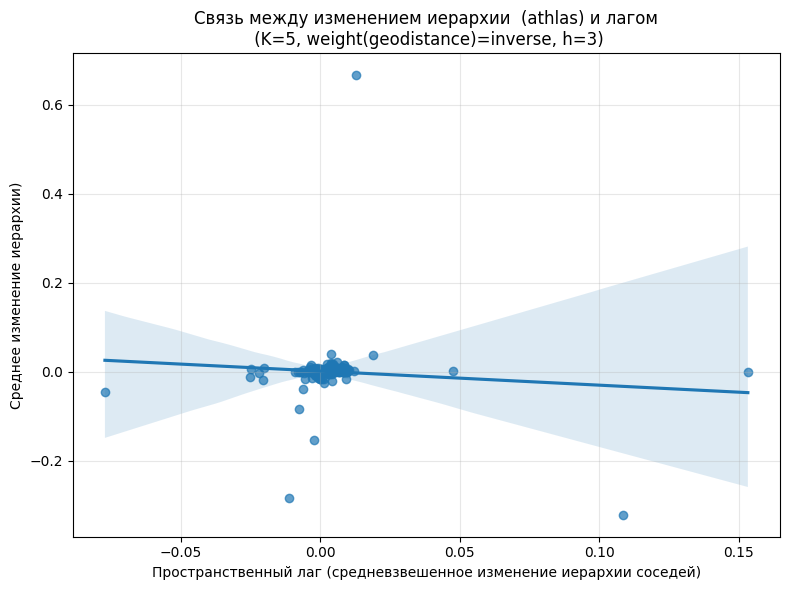

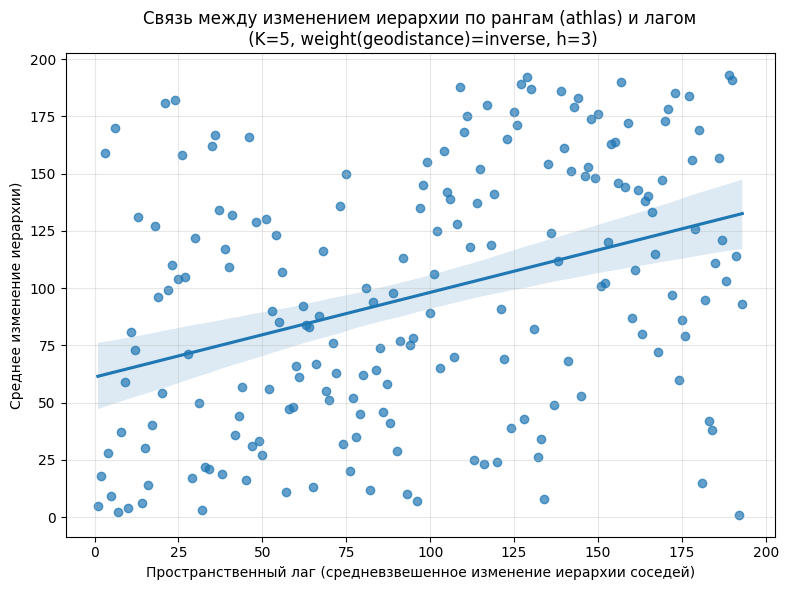

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0851, p-value = 0.2391
INFO:root:Спирмен: r = 0.3701, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.0230
INFO:root:p-value (перестановочный) = 0.1260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1282, p = 0.0040
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0936
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1119
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0215
INFO:root:p-value (перестановочный) = 0.2390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0040
INFO:root:p-value (перестановочный) = 0.4900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0550
INFO:root:p-value (перестановочный) = 0.1500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0276
INFO:root:p-value (перестановочный) = 0.3280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0146
INFO:root:p-value (перестановочный) = 0.4220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0330
INFO:root:p-value (перестановочный) = 0.1810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0585
INFO:root:p-value (перестановочный) = 0.0820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0592
INFO:root:p-value (перестановочный) = 0.0900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1577
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0881
INFO:root:p-value (перестановочный) = 0.0380
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0088
INFO:root:p-value (перестановочный) = 0.3570
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0191
INFO:root:p-value (перестановочный) = 0.2810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0709
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0260
INFO:root:p-value (перестановочный) = 0.2520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0027
INFO:root:p-value (перестановочный) = 0.4200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.1820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0391
INFO:root:p-value (перестановочный) = 0.1840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0353
INFO:root:p-value (перестановочный) = 0.1780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0424
INFO:root:p-value (перестановочный) = 0.1580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1093
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1314
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0331
INFO:root:p-value (перестановочный) = 0.1970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0594
INFO:root:p-value (перестановочный) = 0.0930
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0739
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1995    192  0.093644    0.020  0.199972 0.046075
 1996    193  0.111930    0.006  0.240566 0.013112
 1997    193  0.021489    0.239  0.051780 0.637770
 1998    193 -0.004009    0.490 -0.010417 0.926881
 1999    193 -0.054980    0.150 -0.153980 0.200472
 2000    193 -0.027559    0.328 -0.074394 0.524035
 2001    193 -0.014572    0.422 -0.039850 0.729074
 2002    193  0.032950    

ML_Lag
ML_Lag


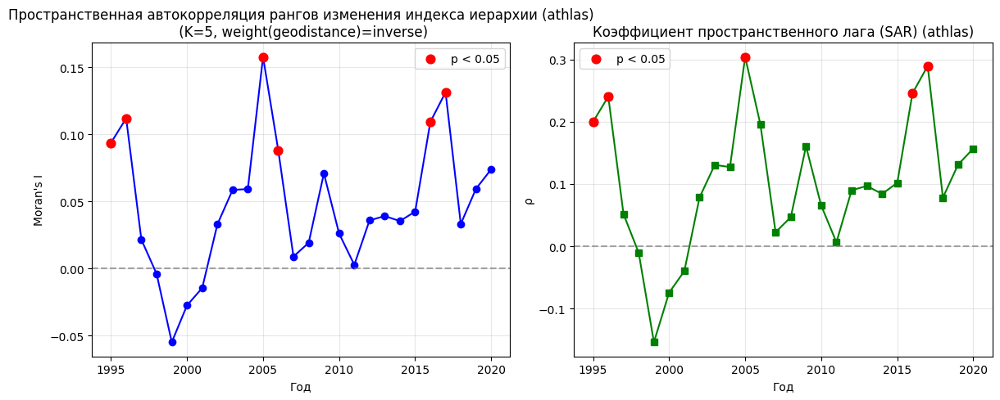

INFO:root:Starting spatial analysis for de_jure_borders with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


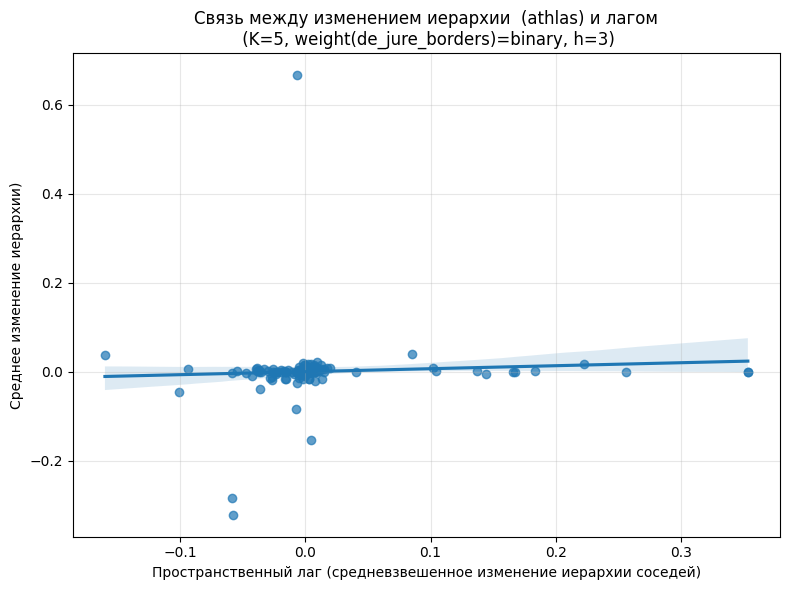

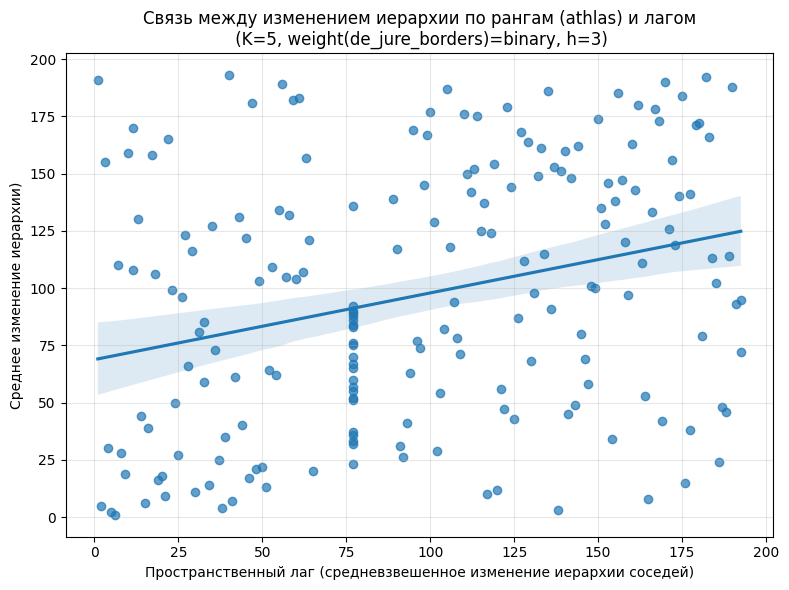

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0634, p-value = 0.3812
INFO:root:Спирмен: r = 0.2909, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0679
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2521
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1689, p = 0.0040
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:year is 1994
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.62, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0970
INFO:root:p-value (перестановочный) = 0.0340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1825
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (193, 193), средняя 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0309
INFO:root:p-value (перестановочный) = 0.2410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0830
INFO:root:p-value (перестановочный) = 0.0610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0494
INFO:root:p-value (перестановочный) = 0.1660
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (193,

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2008
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0783
INFO:root:p-value (перестановочный) = 0.0800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1139
INFO:root:p-value (перестановочный) = 0.0190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1406
INFO:root:p-value (перестановочный) = 0.0130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значи

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0356
INFO:root:p-value (перестановочный) = 0.2460
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0711
INFO:root:p-value (перестановочный) = 0.0810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0808
INFO:root:p-value (перестановочный) = 0.0610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (193,

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


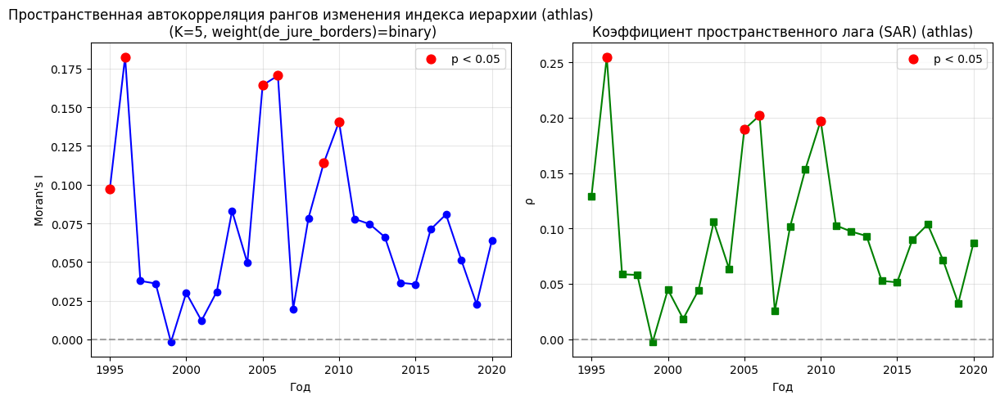

INFO:root:Starting spatial analysis for geodistance with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 182


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)


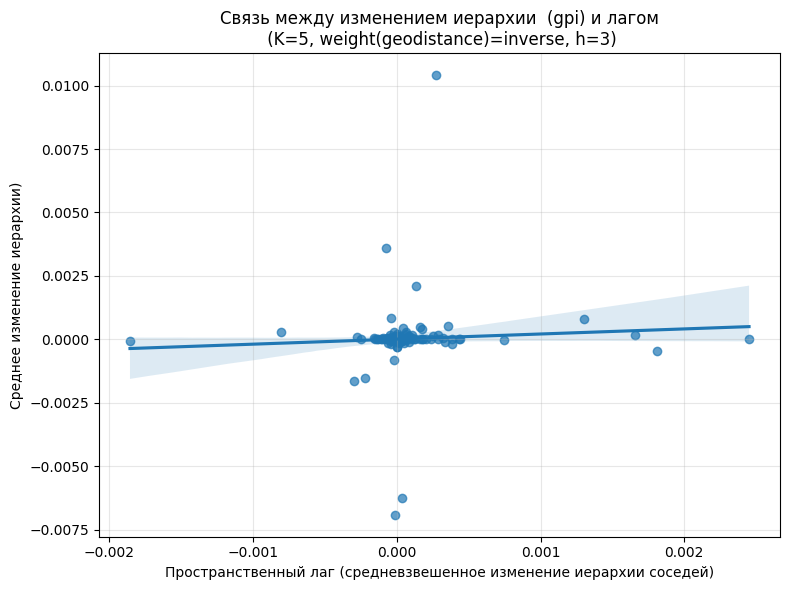

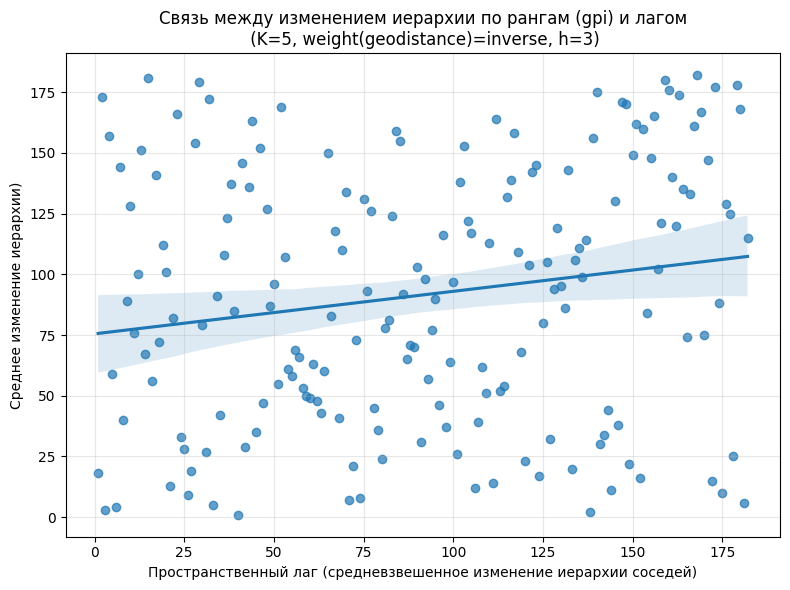

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0603, p-value = 0.4188
INFO:root:Спирмен: r = 0.1751, p-value = 0.0181
INFO:root:=== Moran's I ===
INFO:root:I = 0.0182
INFO:root:p-value (перестановочный) = 0.1370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1667
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1207, p = 0.0070
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (170, 170)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0691
INFO:root:p-value (перестановочный) = 0.0610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (170, 170)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0636
INFO:root:p-value (перестановочный) = 0.0740
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1663
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1472
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1846
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1035
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2548
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2316
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2063
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1154
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0081
INFO:root:p-value (перестановочный) = 0.3760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0348
INFO:root:p-value (перестановочный) = 0.2450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0273
INFO:root:p-value (перестановочный) = 0.2040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0294
INFO:root:p-value (перестановочный) = 0.2520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0848
INFO:root:p-value (перестановочный) = 0.0380
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1395
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2241
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1513
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1261
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1103
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1567
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1344
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3039
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3093
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3832
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2497
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1882
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0273
INFO:root:p-value (перестановочный) = 0.2320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0960
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1186
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1051
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1412
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1225
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1159
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0543
INFO:root:p-value (перестановочный) = 0.1390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho        rho_p
 1988    170  0.069055    0.061  0.154571 1.588354e-01
 1989    170  0.063581    0.074  0.144710 1.901379e-01
 1990    173  0.166308    0.002  0.307879 1.327417e-03
 1991    173  0.147164    0.002  0.280747 4.326210e-03
 1992    173  0.184581    0.002  0.338344 2.760532e-04
 1993    182  0.103516    0.008  0.215333 3.323270e-02
 1994    182  0.254780    0.001  0.433516 9.521229e-08
 1995    182  0.231594    0.001  0.402402 1.859774e-06
 1996    182  0.206296    0.001  0.382800 9.227042e-06
 1997    182  0.115445    0.010  0.237721 1.668915e-02
 1998    182  0.008059    0.376  0.020949 8.551042e-01
 1999    182 -0.034831    0.245 -0.101537 4.

ML_Lag


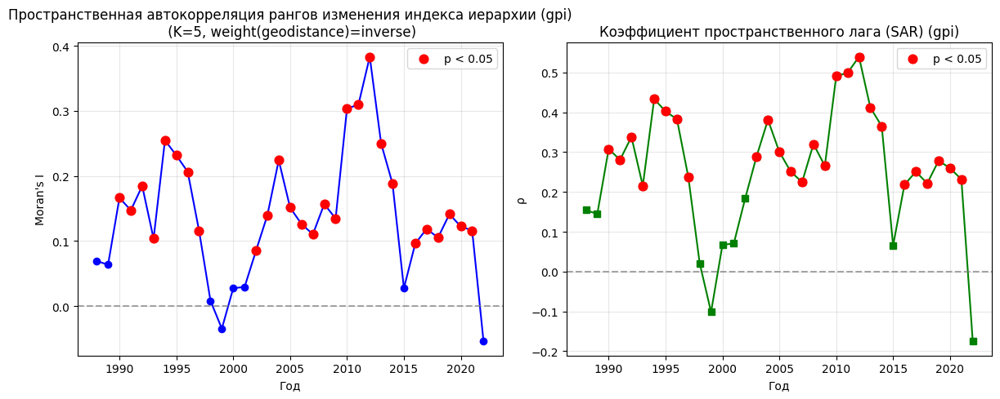

INFO:root:Starting spatial analysis for de_jure_borders with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20


(3,) None


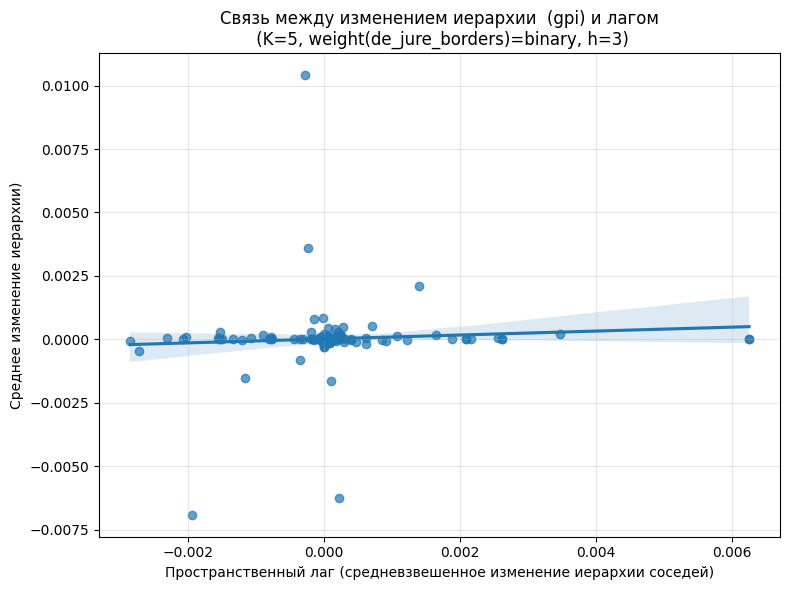

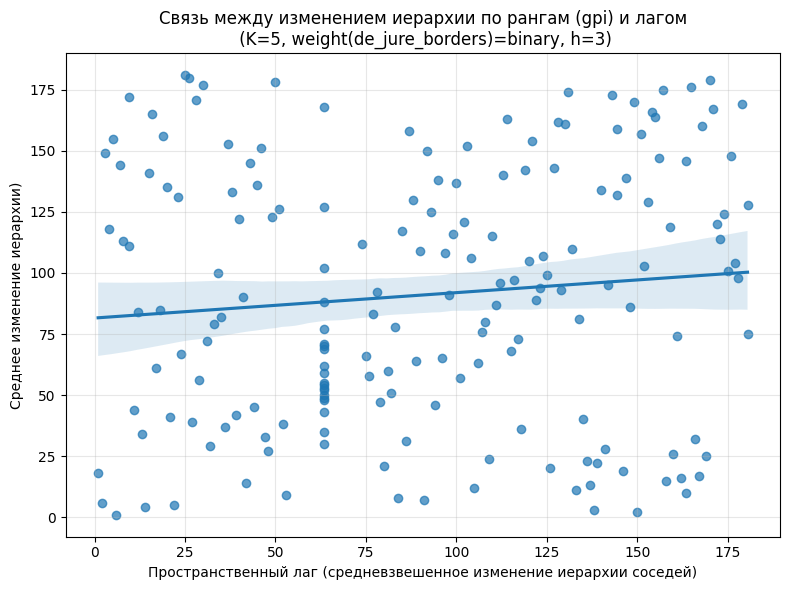

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0724, p-value = 0.3327
INFO:root:Спирмен: r = 0.1039, p-value = 0.1640
INFO:root:=== Moran's I ===
INFO:root:I = 0.0760
INFO:root:p-value (перестановочный) = 0.0270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1854
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1364, p = 0.0170
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Samoa', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Seychelles', ' is an isl

INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (169, 169), средняя степень = 3.46, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1492
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (169, 169), средняя степень = 3.46, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1519
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (172, 172), средняя степень = 3.52, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1995
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2934
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2555
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1658
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2001
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0149
INFO:root:p-value (перестановочный) = 0.4560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1206
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2364
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I знач

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2008
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2226
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1813
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.3790
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2015
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1230
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1718
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1709
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2021
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0627
INFO:root:p-value (перестановочный) = 0.1440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0258
INFO:root:p-value (перестановочный) = 0.3610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho        rho_p
 1988    149  0.149223    0.010  0.185187 6.152467e-02
 1989    149  0.151924    0.005  0.200748 4.124333e-02
 1990    152  0.153450    0.007  0.207600 3.363628e-02
 1991    152  0.121361    0.021  0.168799 8.955350e-02
 1992    152  0.187176    0.002  0.241077 1.211690e-02


ML_Lag
ML_Lag
ML_Lag


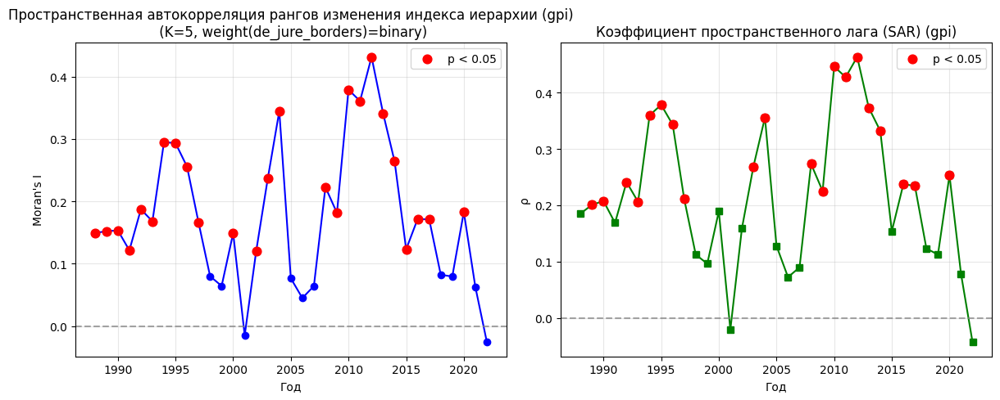

INFO:root:Starting spatial analysis for geodistance with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)


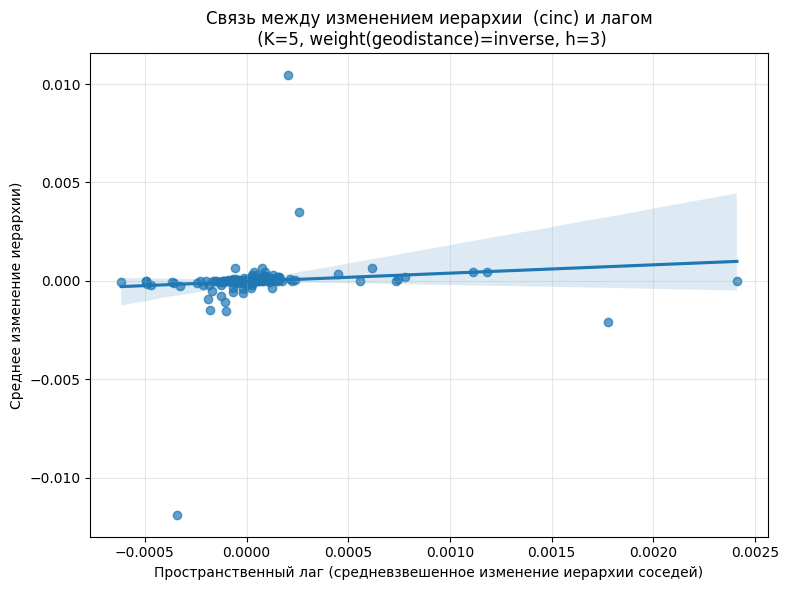

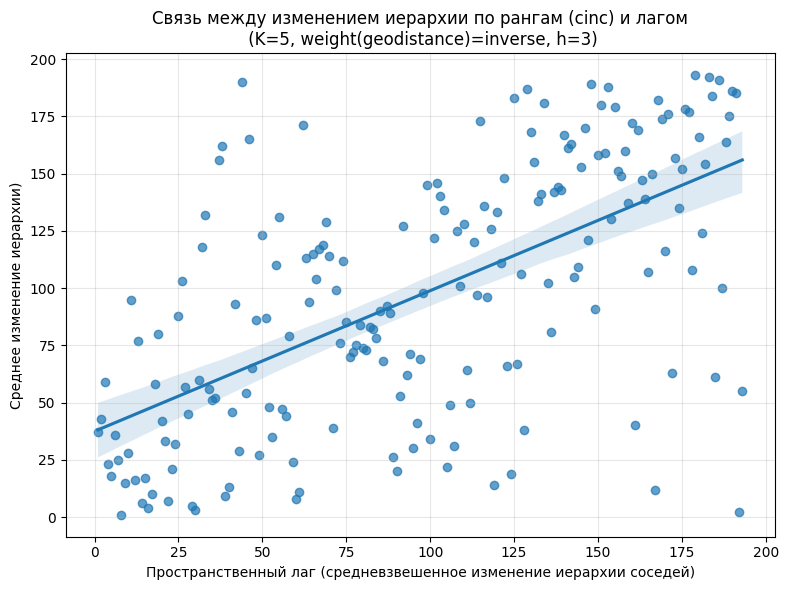

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1047, p-value = 0.1473
INFO:root:Спирмен: r = 0.6140, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0259
INFO:root:p-value (перестановочный) = 0.0520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4789
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.4040, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0850
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2044
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1894
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1849
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2313
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (159, 159)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2117
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (175, 175)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1100
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (179, 179)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0766
INFO:root:p-value (перестановочный) = 0.0510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1297
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2416
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2690
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1825
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1526
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1132
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1224
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1272
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1198
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2043
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2549
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1918
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2708
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2924
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2469
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3402
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3044
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3360
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2805
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1883
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2470
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1749
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2145
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2081
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1786
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2120
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    155 0.084959    0.045 0.188278 9.204520e-02
 1989    155 0.204403    0.001 0.393045 2.115936e-05
 1990    155 0.189367    0.002 0.341223 4.837062e-04
 1991    155 0.184900    0.001 0.352356 2.670511e-04
 1992    155 0.231270    0.001 0.415768 3.828680e-06
 1993    159 0.211744    0.001 0.397083 1.315388e-05
 1994    175 0.110044    0.011 0.237347 1.900207e-02
 1995    179 0.076554    0.051 0.173437 9.932464e-02
 1996    185 0.129695    0.006 0.262345 6.646141e-03
 1997    186 0.241640    0.001 0.392357 3.889280e-06
 1998    186 0.268954    0.001 0.466368 1.862168e

ML_Lag


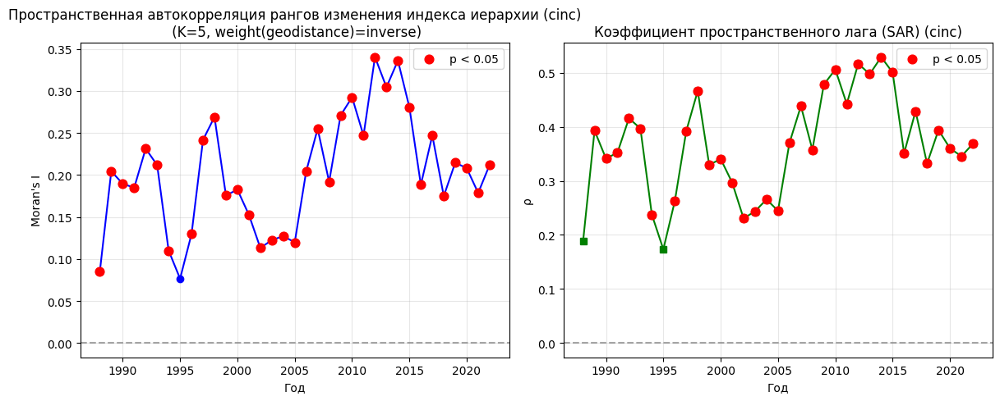

INFO:root:Starting spatial analysis for de_jure_borders with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


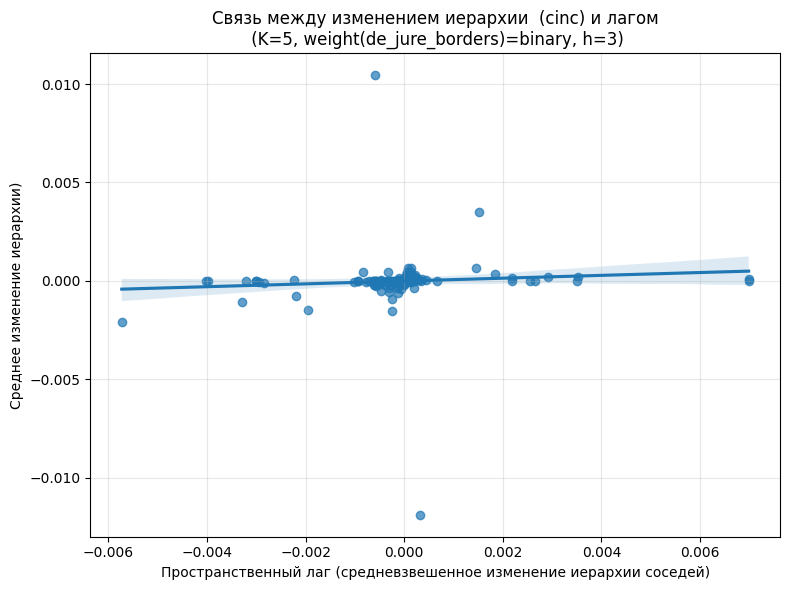

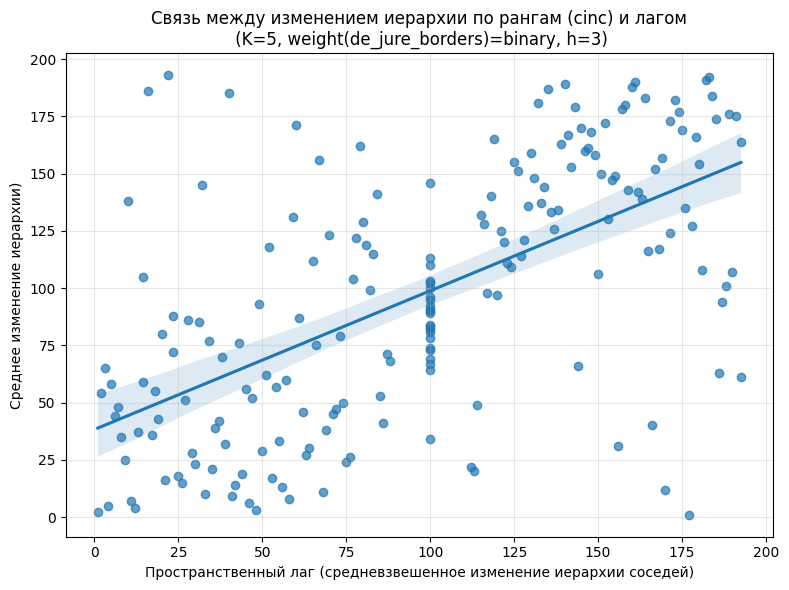

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0756, p-value = 0.2961
INFO:root:Спирмен: r = 0.6053, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0900
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.6962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.5106, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0637
INFO:root:p-value (перестановочный) = 0.1630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0072
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.1834
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0072
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.1544
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемо

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (179, 179), средняя степень = 3.60, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1430
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.69, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1041
INFO:root:p-value (перестановочный) = 0.0320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.3254
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0805
INFO:root:p-value (перестановочный) = 0.0890
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1417
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1902
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значи

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2008
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2884
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3639
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4152
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4289
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4000
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2521
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2583
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2597
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1996
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag


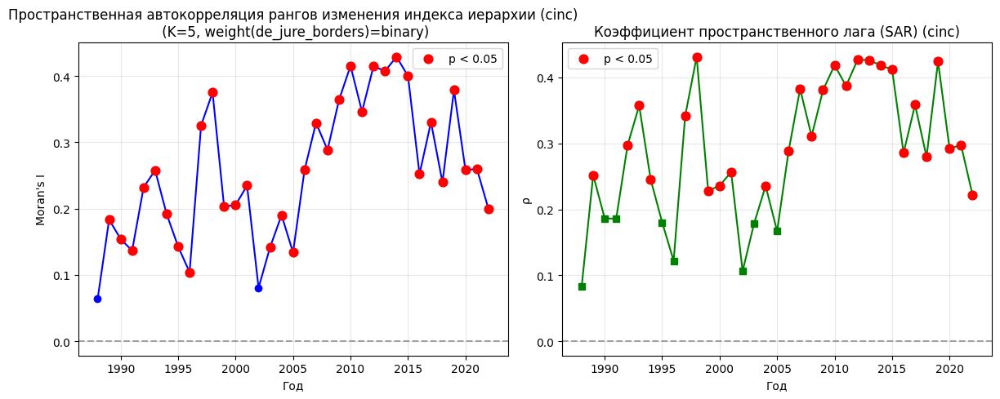

INFO:root:Starting spatial analysis for geodistance with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


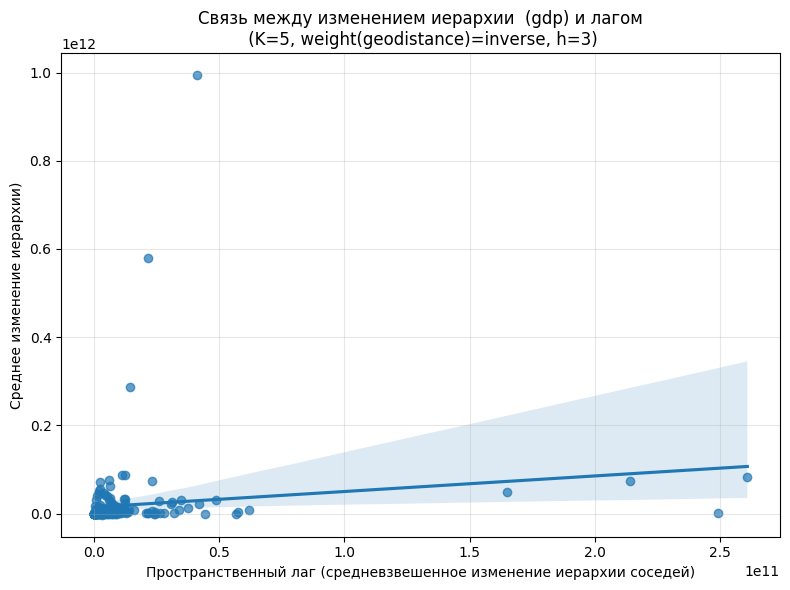

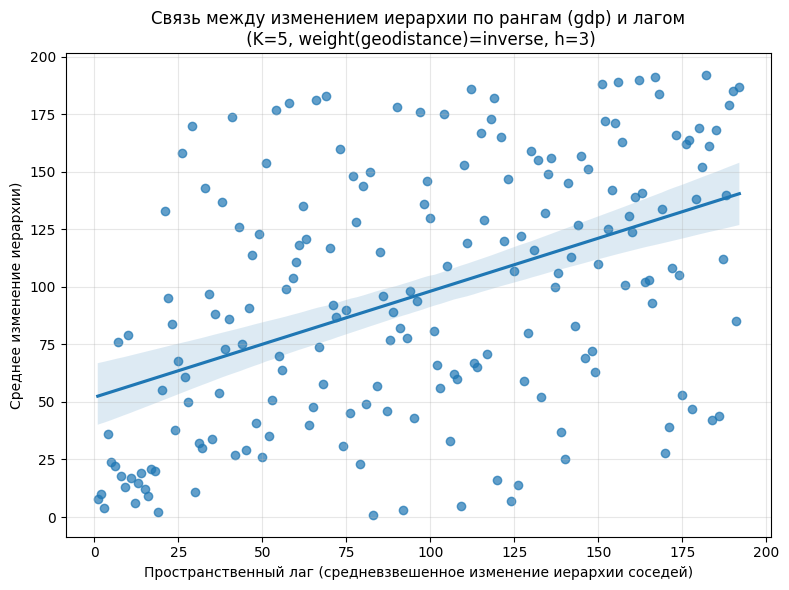

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1358, p-value = 0.0603
INFO:root:Спирмен: r = 0.4606, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0522
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3448
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0888, p = 0.0360
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (160, 160)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3655
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3182
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (164, 164)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3954
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3916
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (166, 166)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3967
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4051
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3998
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3790
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3362
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3159
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3015
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3040
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3071
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3364
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3021
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2941
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3173
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3512
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3453
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3369
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2608
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2737
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3589
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3134
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2542
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2841
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3060
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2929
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3058
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3216
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2445
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1465
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1757
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    160 0.365462    0.001 0.516644 5.746537e-11
 1989    161 0.318238    0.001 0.474291 1.359675e-08
 1990    164 0.395380    0.001 0.552372 5.906386e-14
 1991    165 0.391605    0.001 0.553111 3.885781e-14
 1992    166 0.396726    0.001 0.562705 4.884981e-15
 1993    184 0.405069    0.001 0.587016 0.000000e+00
 1994    184 0.399800    0.001 0.612770 0.000000e+00
 1995    185 0.378958    0.001 0.596122 0.000000e+00
 1996    185 0.336207    0.001 0.541285 1.310063e-14
 1997    186 0.334736    0.001 0.528666 1.392220e-13
 1998    187 0.315897    0.001 0.509767 3.965495e

ML_Lag


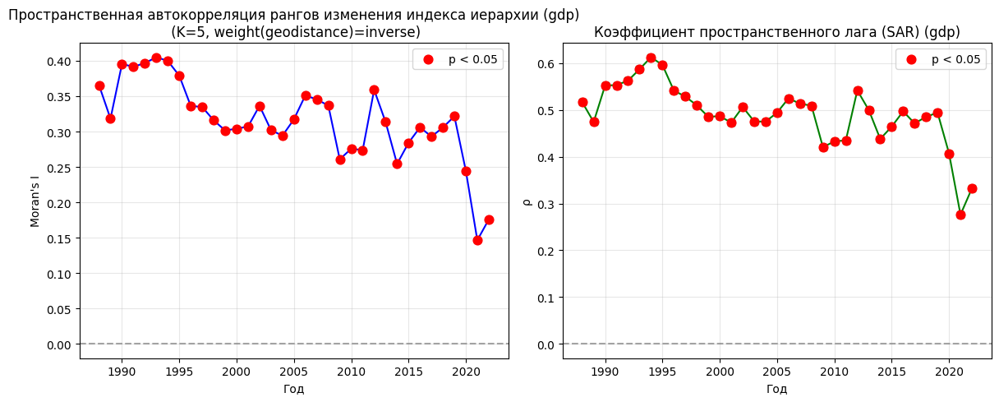

INFO:root:Starting spatial analysis for de_jure_borders with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.64, изолированных вершин = 23
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


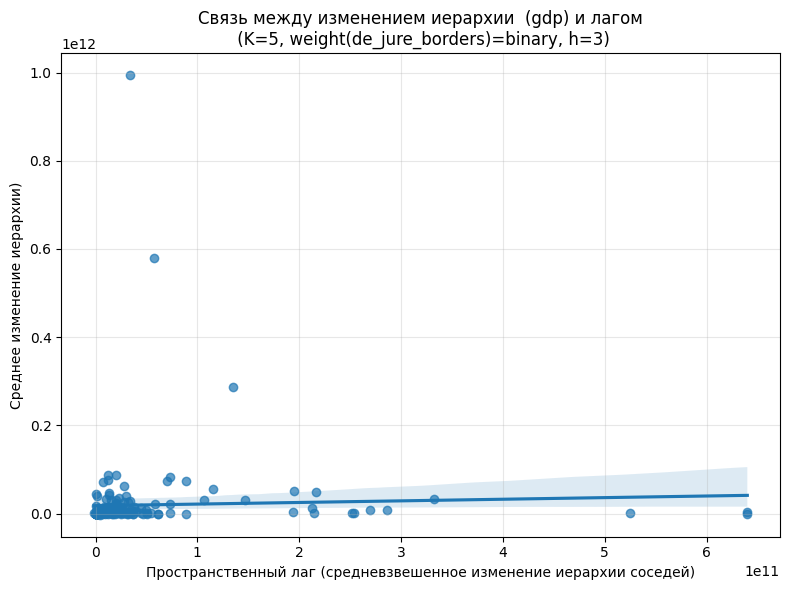

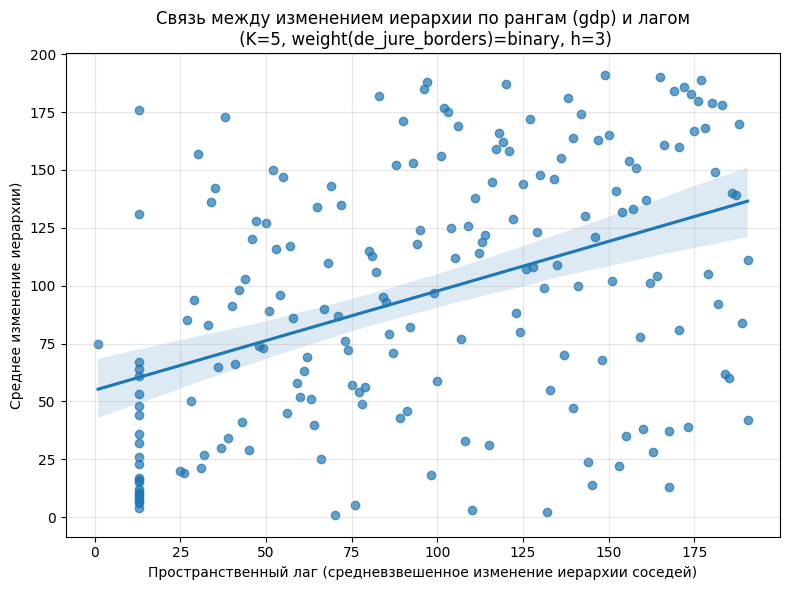

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0387, p-value = 0.5952
INFO:root:Спирмен: r = 0.4284, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0403
INFO:root:p-value (перестановочный) = 0.0530
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2245
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1243, p = 0.0410
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.05, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.5139
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0074
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 3.06, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4859
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0073
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 3.06, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1995
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3551
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2678
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2041
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2119
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2188
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2217
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2134
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 200

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2764
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2356
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1928
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2014
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2546
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 202

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


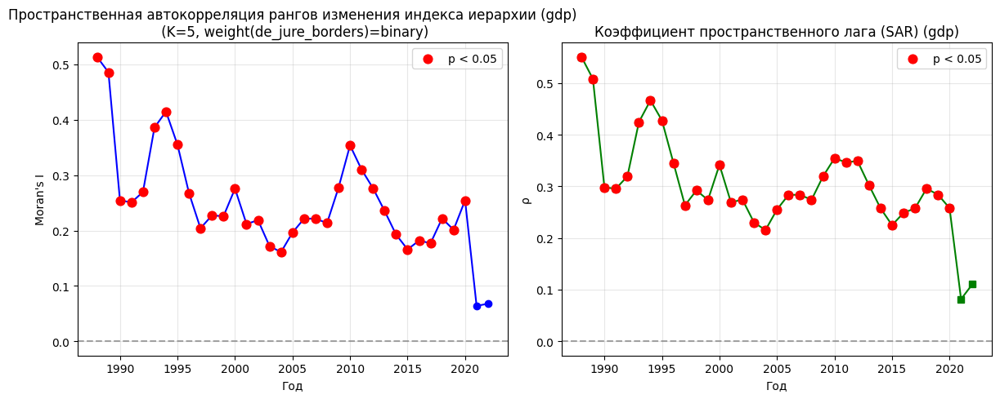

INFO:root:Starting spatial analysis for geodistance with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


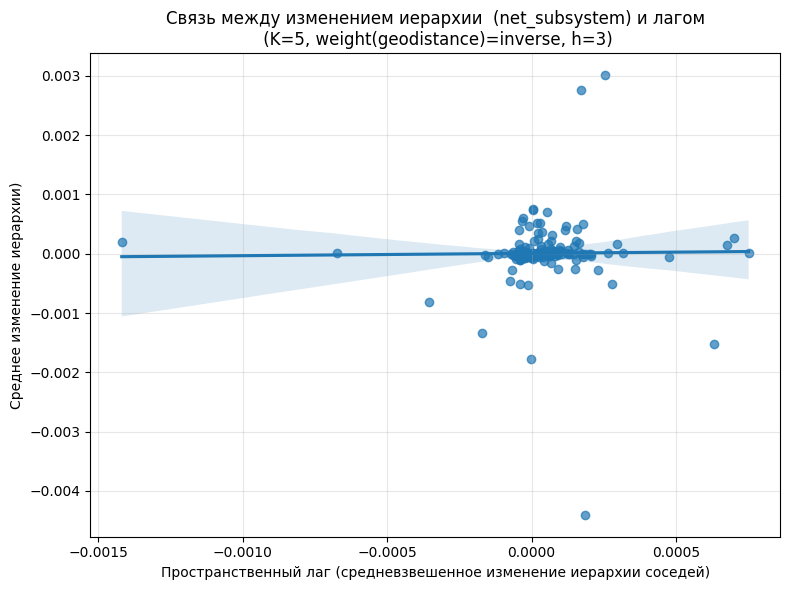

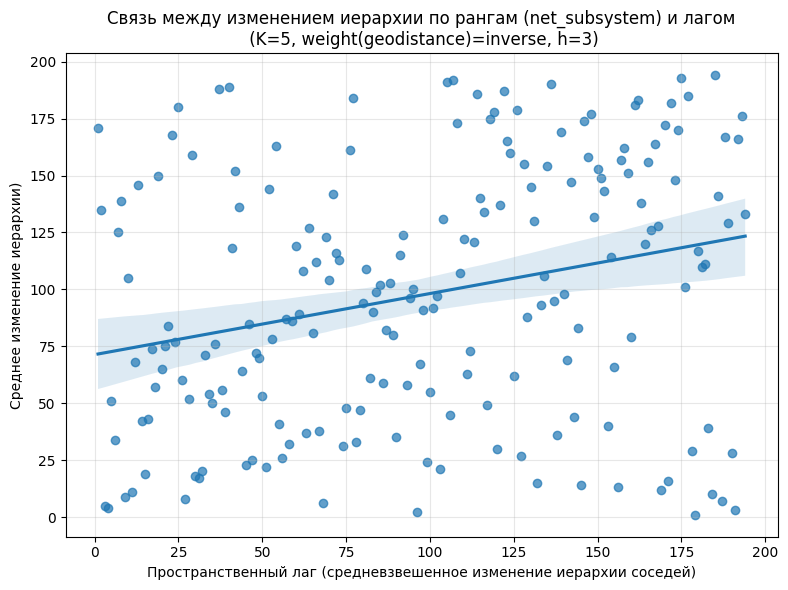

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0138, p-value = 0.8489
INFO:root:Спирмен: r = 0.2683, p-value = 0.0002
INFO:root:=== Moran's I ===
INFO:root:I = 0.0047
INFO:root:p-value (перестановочный) = 0.3480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2000
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2571, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0712
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0586
INFO:root:p-value (перестановочный) = 0.1170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0370
INFO:root:p-value (перестановочный) = 0.2010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0265
INFO:root:p-value (перестановочный) = 0.2440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0177
INFO:root:p-value (перестановочный) = 0.3000
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0510
INFO:root:p-value (перестановочный) = 0.1220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0147
INFO:root:p-value (перестановочный) = 0.3300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0599
INFO:root:p-value (перестановочный) = 0.0850
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0485
INFO:root:p-value (перестановочный) = 0.1340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0282
INFO:root:p-value (перестановочный) = 0.2490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0546
INFO:root:p-value (перестановочный) = 0.1060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0022
INFO:root:p-value (перестановочный) = 0.4200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0422
INFO:root:p-value (перестановочный) = 0.2140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0217
INFO:root:p-value (перестановочный) = 0.3780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0133
INFO:root:p-value (перестановочный) = 0.4470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1102
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0569
INFO:root:p-value (перестановочный) = 0.0780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0099
INFO:root:p-value (перестановочный) = 0.3790
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0543
INFO:root:p-value (перестановочный) = 0.1520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0446
INFO:root:p-value (перестановочный) = 0.2170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0357
INFO:root:p-value (перестановочный) = 0.2540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0997
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0349
INFO:root:p-value (перестановочный) = 0.2640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0010
INFO:root:p-value (перестановочный) = 0.4580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0095
INFO:root:p-value (перестановочный) = 0.4880
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0368
INFO:root:p-value (перестановочный) = 0.2400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0498
INFO:root:p-value (перестановочный) = 0.1760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0133
INFO:root:p-value (перестановочный) = 0.3440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.3080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0076
INFO:root:p-value (перестановочный) = 0.4790
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0012
INFO:root:p-value (перестановочный) = 0.4490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0496
INFO:root:p-value (перестановочный) = 0.1560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0575
INFO:root:p-value (перестановочный) = 0.0920
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1021
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0068
INFO:root:p-value (перестановочный) = 0.3600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    161  0.071248    0.063  0.171993 0.122369
 1989    161  0.058635    0.117  0.140352 0.217425
 1990    161  0.036978    0.201  0.085727 0.466744
 1991    161  0.026457    0.244  0.057368 0.631865
 1992    161  0.017710    0.300  0.039301 0.745206
 1993    165  0.051020    0.122  0.119541 0.295058
 1994    182  0.014664    0.330  0.036984 0.744609
 1995    185  0.059903    0.085  0.140288 0.185934
 1996    187  0.048496    0.134  0.120825 0.258103
 1997    188  0.028156    0.249  0.062801 0.569312
 1998    188  0.054574    0.106  0.123415 0.246306
 1999    188 -0.002193    0.420 -0.005785 0.959655
 2000    188 -0.042157    0.214 -0.114837 

ML_Lag


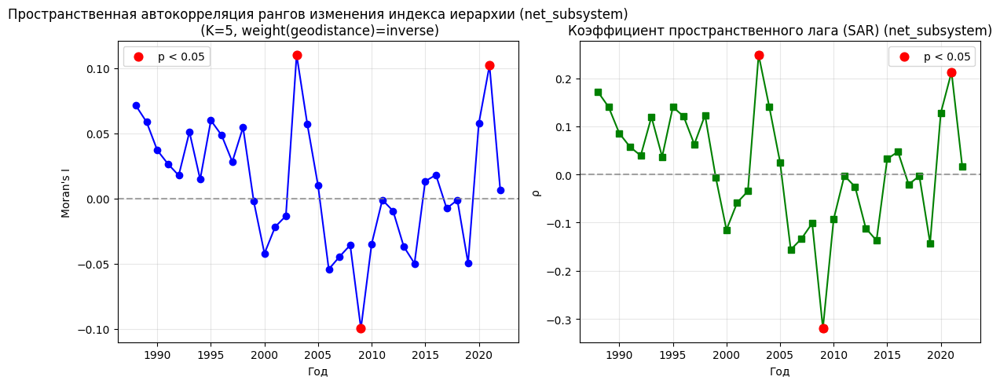

INFO:root:Starting spatial analysis for de_jure_borders with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


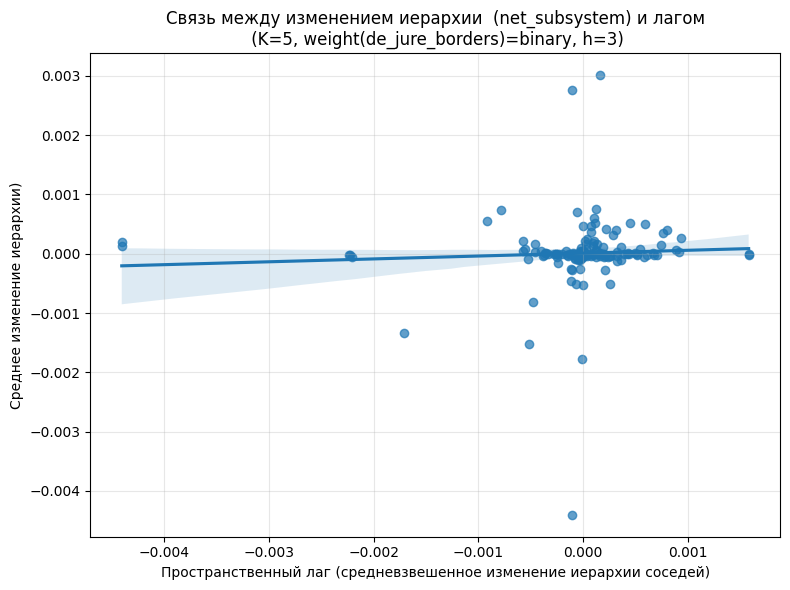

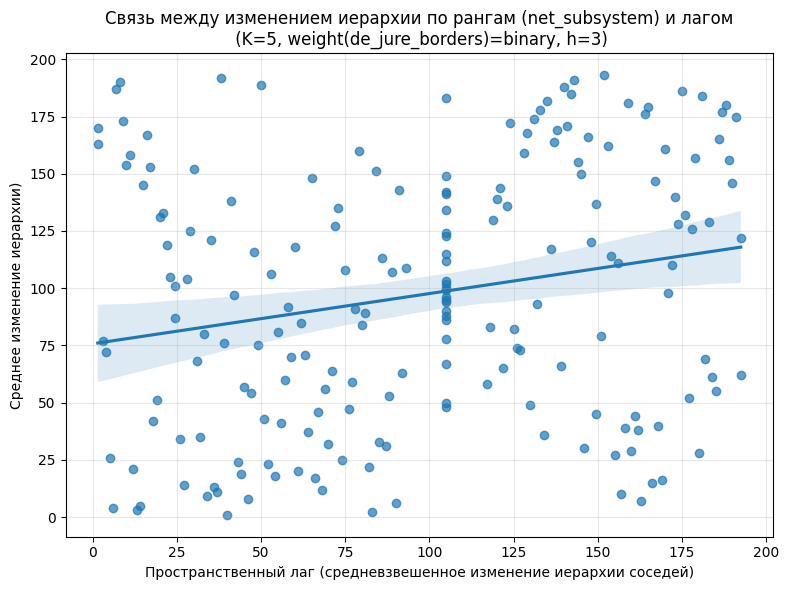

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0600, p-value = 0.4075
INFO:root:Спирмен: r = 0.2191, p-value = 0.0022
INFO:root:=== Moran's I ===
INFO:root:I = 0.0840
INFO:root:p-value (перестановочный) = 0.0320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1812
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2353, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0303
INFO:root:p-value (перестановочный) = 0.2690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = -0.0164
INFO:root:p-value (перестановочный) = 0.4360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1310
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.61, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0942
INFO:root:p-value (перестановочный) = 0.0600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0608
INFO:root:p-value (перестановочный) = 0.1170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (187, 187), средняя степень = 3.65, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0024
INFO:root:p-value (перестановочный) = 0.4280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (187, 187), средняя степень 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0034
INFO:root:p-value (перестановочный) = 0.4630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0103
INFO:root:p-value (перестановочный) = 0.3890
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0956
INFO:root:p-value (перестановочный) = 0.0460
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2008
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0526
INFO:root:p-value (перестановочный) = 0.2230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0572
INFO:root:p-value (перестановочный) = 0.1920
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0186
INFO:root:p-value (перестановочный) = 0.4110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (1

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0635
INFO:root:p-value (перестановочный) = 0.1600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0231
INFO:root:p-value (перестановочный) = 0.3590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0516
INFO:root:p-value (перестановочный) = 0.1590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (19

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0888
INFO:root:p-value (перестановочный) = 0.0680
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0633
INFO:root:p-value (перестановочный) = 0.1270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0403
INFO:root:p-value (перестановочный) = 0.2730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   mora

ML_Lag
ML_Lag
ML_Lag
ML_Lag


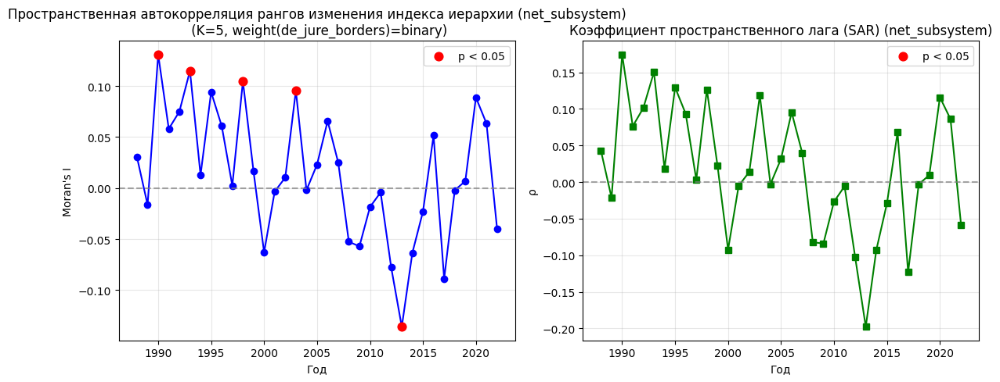

INFO:root:Starting spatial analysis for geodistance with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


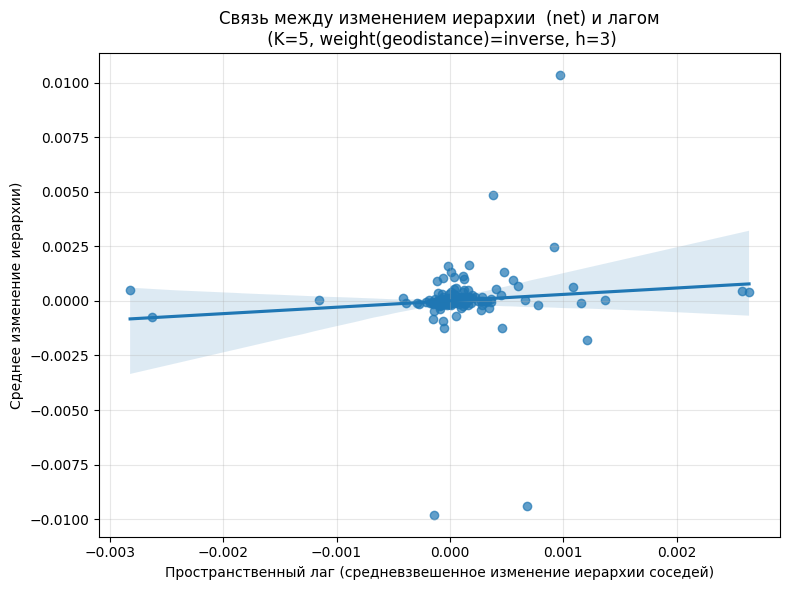

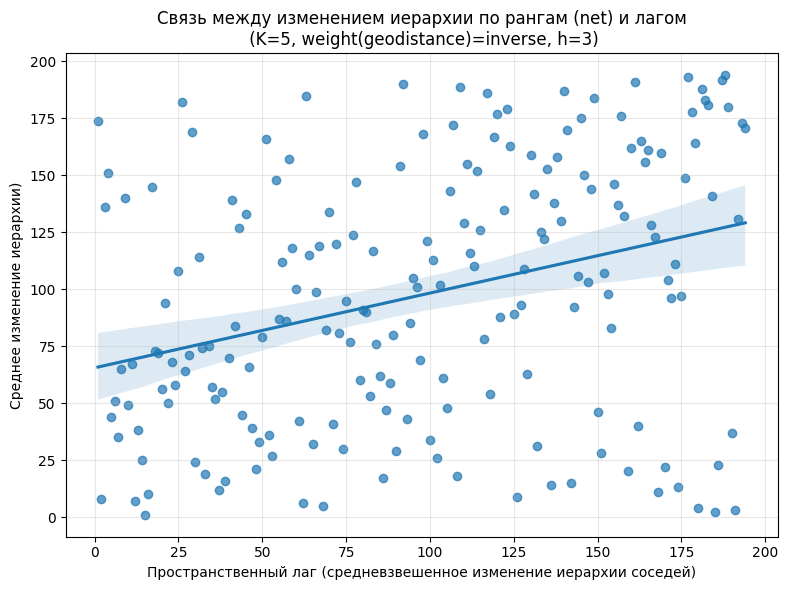

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1026, p-value = 0.1546
INFO:root:Спирмен: r = 0.3281, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.0780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1921
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2335, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0987
INFO:root:p-value (перестановочный) = 0.0310
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0873
INFO:root:p-value (перестановочный) = 0.0310
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0216
INFO:root:p-value (перестановочный) = 0.2810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0048
INFO:root:p-value (перестановочный) = 0.3990
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0228
INFO:root:p-value (перестановочный) = 0.3810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0496
INFO:root:p-value (перестановочный) = 0.1200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0031
INFO:root:p-value (перестановочный) = 0.4590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1582
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0409
INFO:root:p-value (перестановочный) = 0.1810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0063
INFO:root:p-value (перестановочный) = 0.4700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0080
INFO:root:p-value (перестановочный) = 0.4840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0225
INFO:root:p-value (перестановочный) = 0.2650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0576
INFO:root:p-value (перестановочный) = 0.0860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1238
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1429
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1499
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0503
INFO:root:p-value (перестановочный) = 0.1250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1016
INFO:root:p-value (перестановочный) = 0.0130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0577
INFO:root:p-value (перестановочный) = 0.0970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0410
INFO:root:p-value (перестановочный) = 0.1410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1306
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0146
INFO:root:p-value (перестановочный) = 0.4100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0508
INFO:root:p-value (перестановочный) = 0.0970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0639
INFO:root:p-value (перестановочный) = 0.0670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0957
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1159
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1182
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1027
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0247
INFO:root:p-value (перестановочный) = 0.2480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.1800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0239
INFO:root:p-value (перестановочный) = 0.2580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0727
INFO:root:p-value (перестановочный) = 0.0420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0639
INFO:root:p-value (перестановочный) = 0.0700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1279
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1342
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    161  0.098711    0.031  0.214978 0.046142
 1989    161  0.087304    0.031  0.199472 0.067501
 1990    161  0.021602    0.281  0.052854 0.659726
 1991    161  0.004812    0.399  0.012091 0.921490
 1992    161 -0.022792    0.381 -0.060919 0.631367
 1993    165  0.049559    0.120  0.112643 0.325903
 1994    182 -0.003052    0.459 -0.007788 0.946531
 1995    185  0.158207    0.001  0.311770 0.000765
 1996    187  0.040921    0.181  0.098450 0.363464
 1997    188 -0.006320    0.470 -0.015622 0.891835
 1998    188 -0.007996    0.484 -0.020292 0.860105
 1999    188  0.0225

ML_Lag


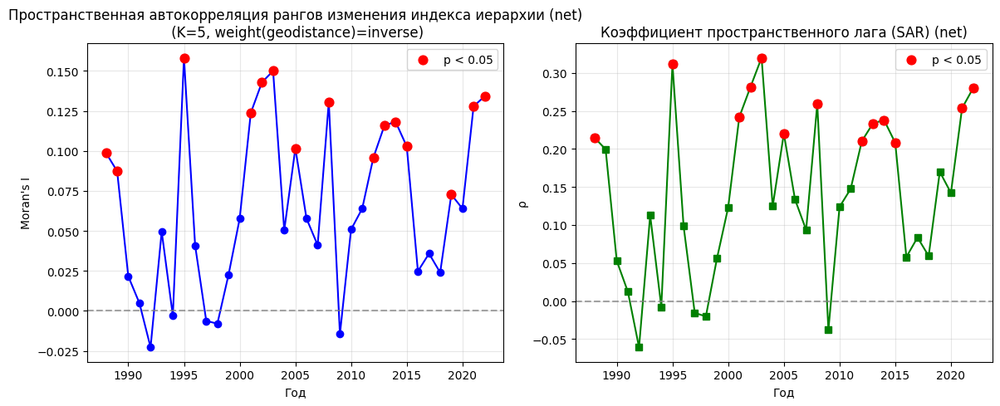

INFO:root:Starting spatial analysis for de_jure_borders with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


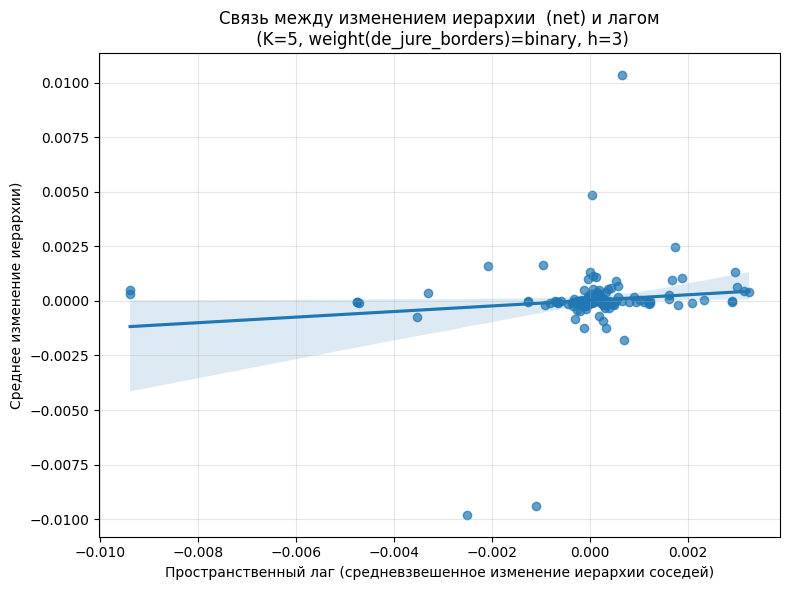

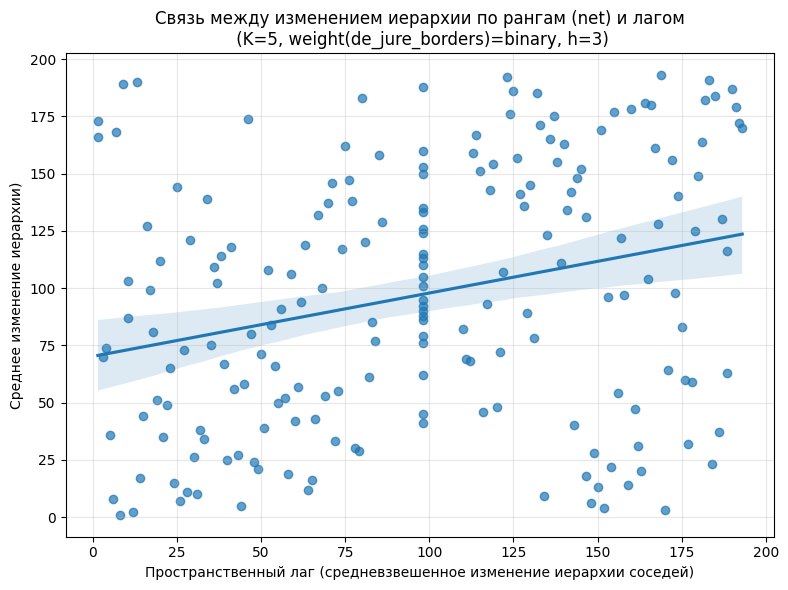

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1344, p-value = 0.0623
INFO:root:Спирмен: r = 0.2764, p-value = 0.0001
INFO:root:=== Moran's I ===
INFO:root:I = 0.1602
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1671
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1714, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0726
INFO:root:p-value (перестановочный) = 0.1260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0787
INFO:root:p-value (перестановочный) = 0.0940
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0465
INFO:root:p-value (перестановочный) = 0.2160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.61, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2177
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0729
INFO:root:p-value (перестановочный) = 0.1010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (187, 187), средняя степень = 3.65, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0638
INFO:root:p-value (перестановочный) = 0.1480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year i

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.1337
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1539
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1006
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2009
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0624
INFO:root:p-value (перестановочный) = 0.1690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0738
INFO:root:p-value (перестановочный) = 0.0900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0642
INFO:root:p-value (перестановочный) = 0.1210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (192

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0916
INFO:root:p-value (перестановочный) = 0.0400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0329
INFO:root:p-value (перестановочный) = 0.2520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0215
INFO:root:p-value (перестановочный) = 0.2900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ зн

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    142  0.072575    0.126  0.092216 0.370385
 1989    142  0.078720    0.094  0.095164 0.354865
 1990    142  0.046465    0.216  0.056754 0.585030
 1991    142  0.055221    0.148  0.068555 0.508248
 1992    142  0.033095    0.273  0.039775 0.703078
 1993    146  0.119217    0.018  0.152063 0.129743
 1994    161  0.026742    0.297  0.041979 0.677765
 1995    164  0.217689    0.001  0.292052 0.001235
 1996    167  0.072902    0.101  0.105153 0.281860
 1997    167 -0.063817    0.148 -0.100064 0.324690
 1998    167 -0.049113    0.233 -0.076078 0.453098
 1999    167  0.049958    0.166  0.072511 0.462373
 2000    167  0.042912    0.219  0.059286 0.549321
 2001    167  0.057821    0.138  0.080487 0.413579
 2002    167  0.133722    0.012  0.169196 0.076389
 2003    167  0.153905    0.004  0.204369 0.029775
 2004    168  0.100565    0.043  0.129552 0.178855
 2005    168  0.084151    0.062  0.

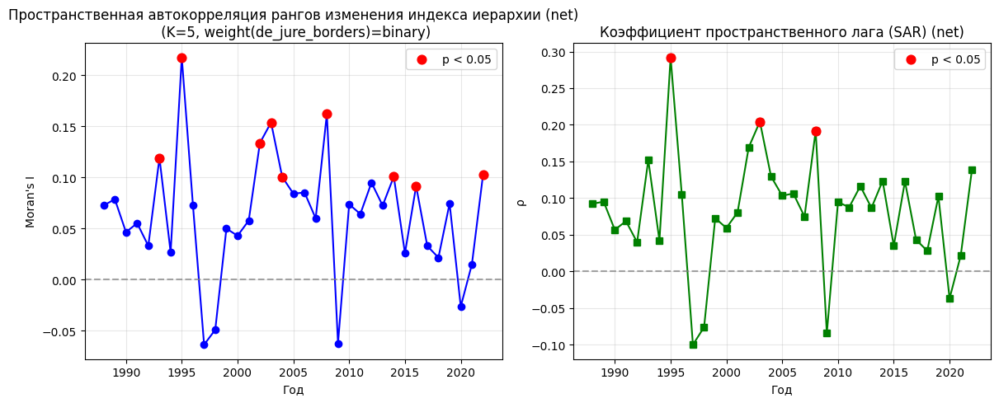

INFO:root:Starting spatial analysis for geodistance with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


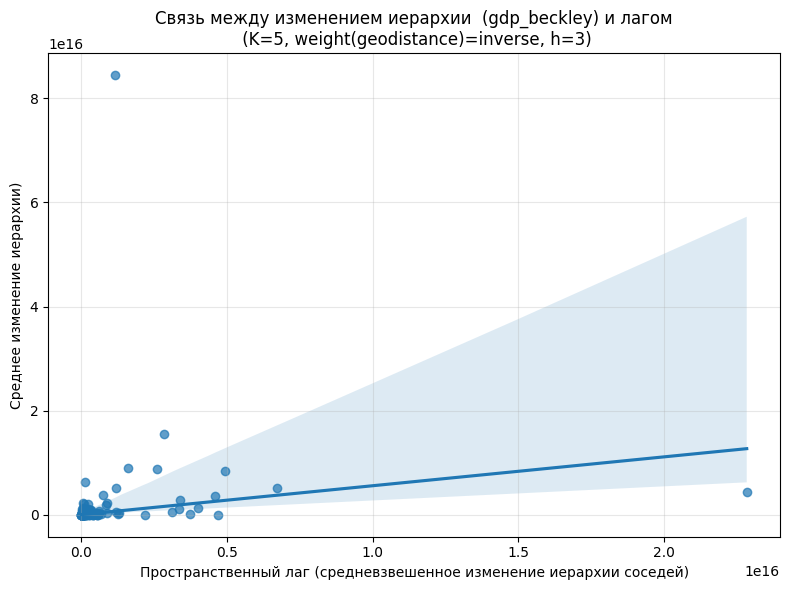

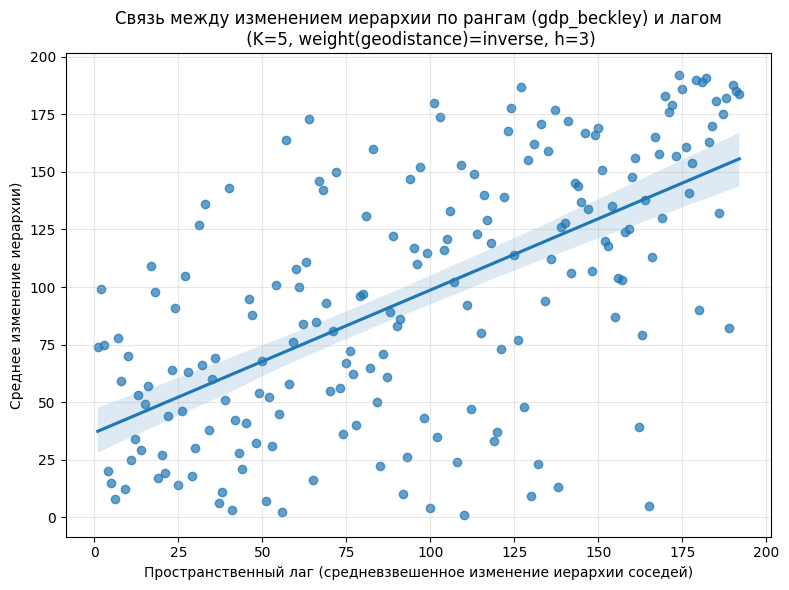

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1373, p-value = 0.0576
INFO:root:Спирмен: r = 0.6201, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0418
INFO:root:p-value (перестановочный) = 0.0350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4701
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0472, p = 0.1640
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (160, 160)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3850
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3656
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (164, 164)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2795
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2197
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (166, 166)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1917
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3512
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3676
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3863
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4644
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5171
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5214
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3891
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4427
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4314
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4904
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4650
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4633
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4983
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5454
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5483
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4883
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1381
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2618
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1503
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3904
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3416
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2593
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3126
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3668
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4102
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4356
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4467
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2495
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1887
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3064
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    160 0.385018    0.001 0.547331 3.248513e-13
 1989    161 0.365607    0.001 0.512983 8.664092e-11
 1990    164 0.279460    0.001 0.446645 1.883942e-07
 1991    165 0.219737    0.001 0.394486 1.435605e-05
 1992    166 0.191711    0.001 0.372777 6.125840e-05
 1993    184 0.351225    0.001 0.531410 1.234568e-13
 1994    184 0.367641    0.001 0.557203 4.440892e-16
 1995    185 0.386276    0.001 0.595388 0.000000e+00
 1996    185 0.464428    0.001 0.649769 0.000000e+00
 1997    186 0.517117    0.001 0.682178 0.000000e+00
 1998    187 0.521400    0.001 0.678249 0.000000e

ML_Lag


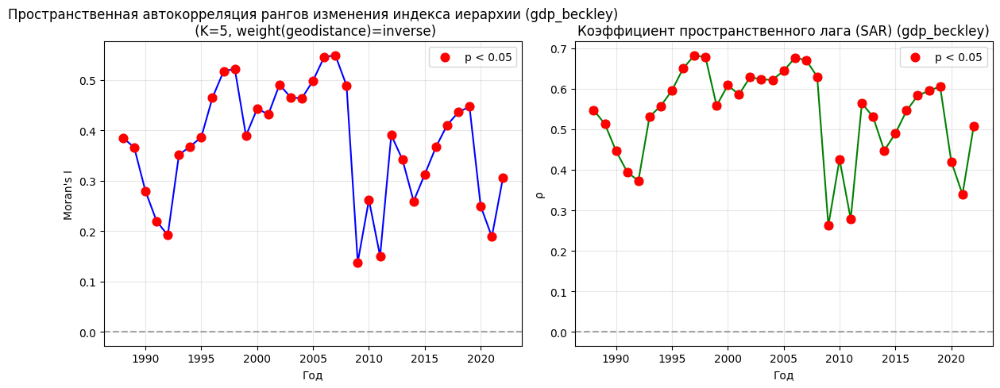

INFO:root:Starting spatial analysis for de_jure_borders with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.64, изолированных вершин = 23
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


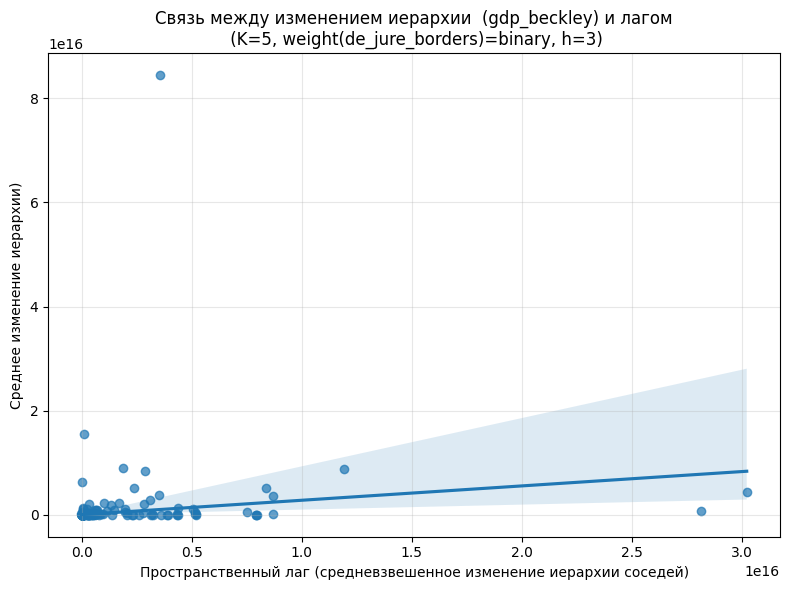

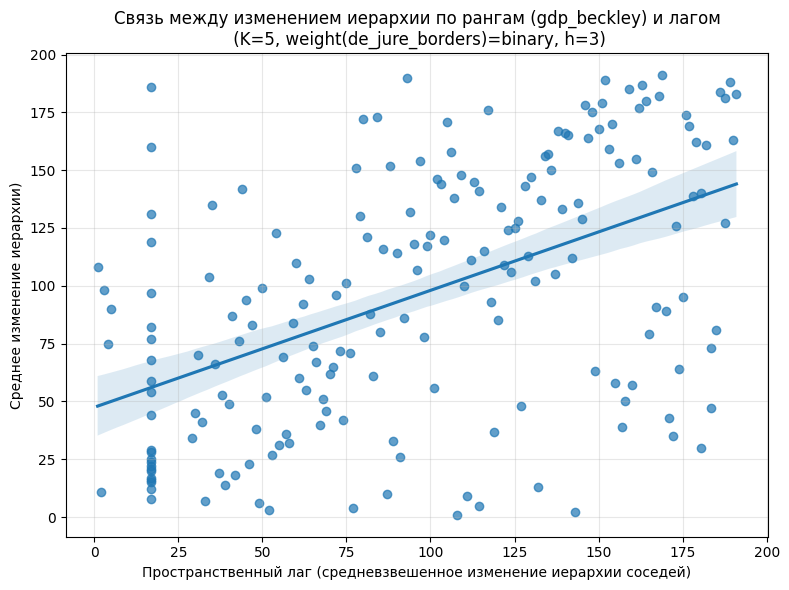

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1169, p-value = 0.1071
INFO:root:Спирмен: r = 0.5051, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0723
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3840
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0274, p = 0.2210
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.05, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3892
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0074
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 3.06, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3341
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0073
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 3.06, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3657
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3611
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4071
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3802
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3319
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3495
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2009
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1860
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3449
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.61, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1613
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2016
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2394
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2758
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3572
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    137 0.389188    0.001 0.415230 7.329462e-07
 1989    138 0.334080    0.001 0.345650 9.210757e-05
 1990    141 0.358709    0.001 0.364925 2.299886e-05
 1991    142 0.245071    0.001 0.270691 3.077644e-03
 1992    143 0.220839    0.001 0.269574 3.970787e-03
 1993    161 0.346038    0.001 0.383251 4.959546e-06
 1994    161 0.380845    0.001 0.421332 2.218361e-07
 1995    162 0.365681    0.001 0.415448 3.711756e-07
 1996    162 0.361080    0.001 0.425388 1.524109e-07
 1997    162 0.407131    0.001 0.478624 5.260927e-10
 1998    163 0.443873    0.001 0.511315 8.220091e-12
 1999    163 0.336751    0.001 0.382874 5.682514e-06
 2000    165 0.437866    0.001 0.485178 2.307059e-10
 2001    165 0.374543    0.001 0.433075 7.358981e-08
 2002    165 0.380194    0.001 0.425302 1.525488e-07
 2003    166 0.331941    0.001 0.382940 5.241346e-06
 2004    166 0.349506    0.001 0.395771 1.981200e-06

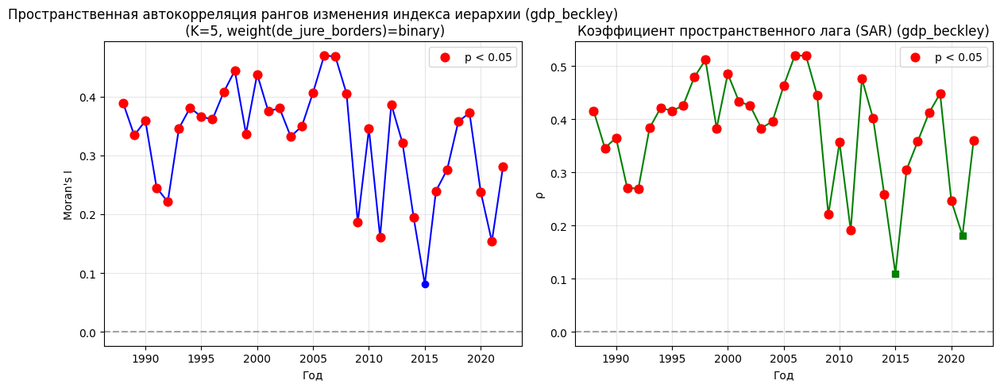

INFO:root:Starting spatial analysis for geodistance with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 186


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)


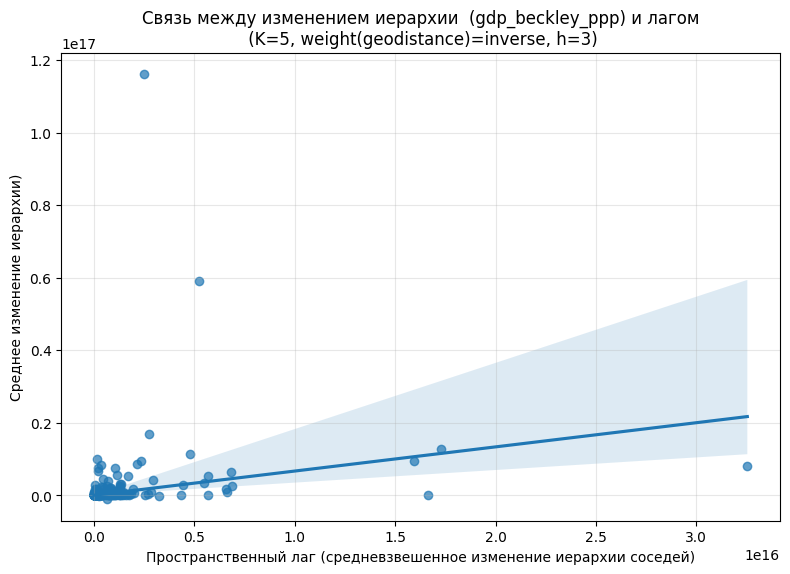

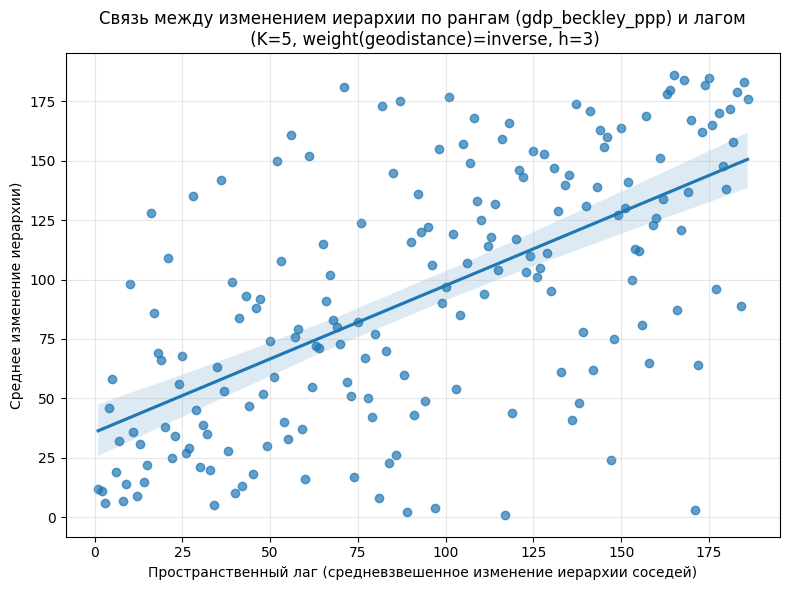

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1792, p-value = 0.0144
INFO:root:Спирмен: r = 0.6178, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0615
INFO:root:p-value (перестановочный) = 0.0300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4600
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0354, p = 0.1950
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (179, 179)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3747
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994
INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3926
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3950
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4448
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4960
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4920
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3687
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4203
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4186
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4897
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4378
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4505
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4777
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5385
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5388
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4815
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1796
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2800
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1648
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3821
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3368
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2429
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3123
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3505
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3923
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4214
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4460
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2443
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1710
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2761
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1993    179 0.374669    0.001 0.547506 8.881784e-15
 1994    180 0.392633    0.001 0.580771 0.000000e+00
 1995    180 0.394967    0.001 0.605542 0.000000e+00
 1996    180 0.444787    0.001 0.630040 0.000000e+00
 1997    181 0.495998  

ML_Lag
ML_Lag


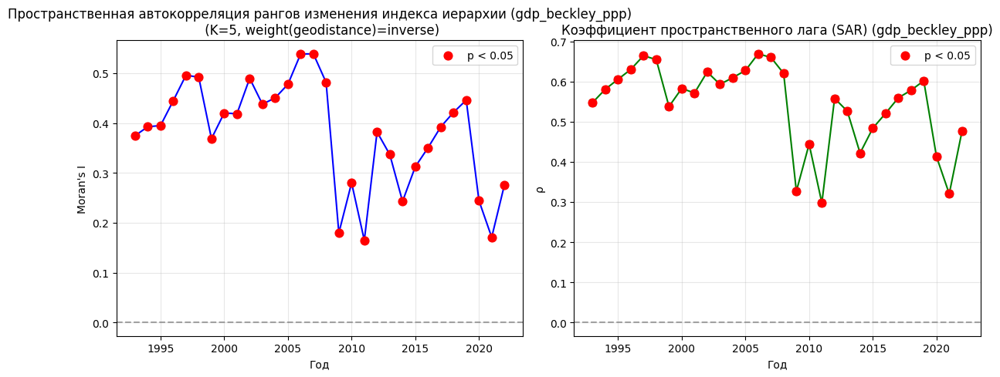

INFO:root:Starting spatial analysis for de_jure_borders with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 185
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24


(3,) None


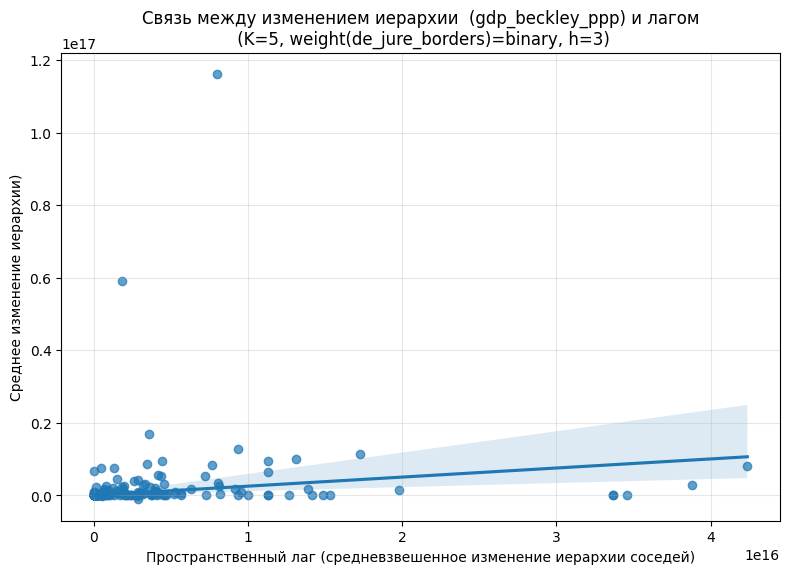

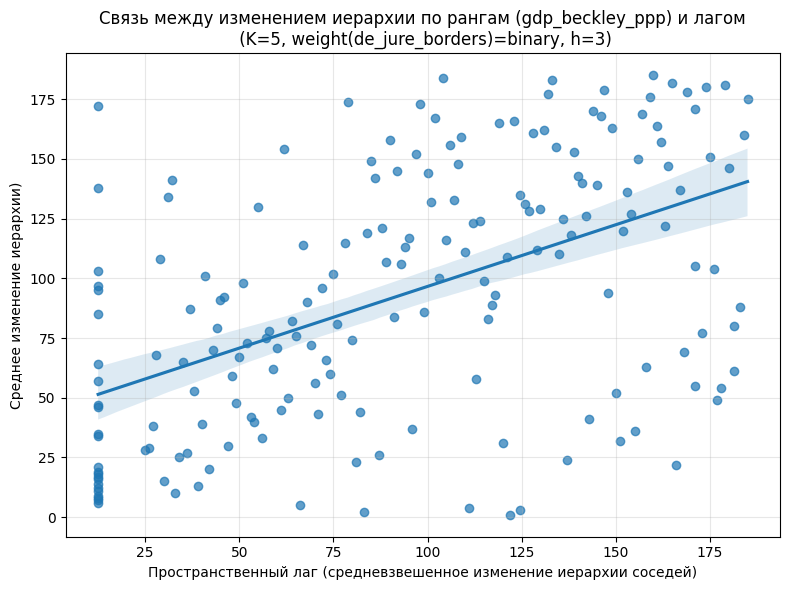

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1055, p-value = 0.1531
INFO:root:Спирмен: r = 0.5161, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0775
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3683
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0305, p = 0.3910
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1990
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 3.40, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3378
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.40, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3739
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.40, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2000
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 3.48, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.4013
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 3.48, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3586
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 3.48, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3817
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.4341
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3742
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3597
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3089
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.1856
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3415
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3638
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.2317
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


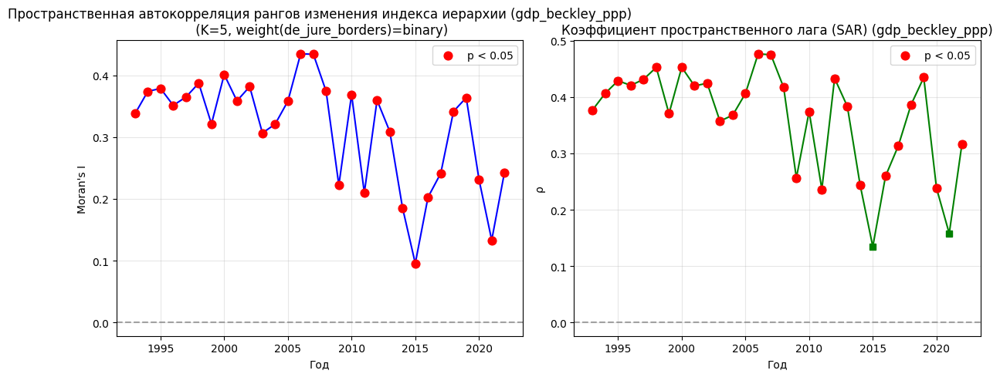

INFO:root:Starting spatial analysis for geodistance with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


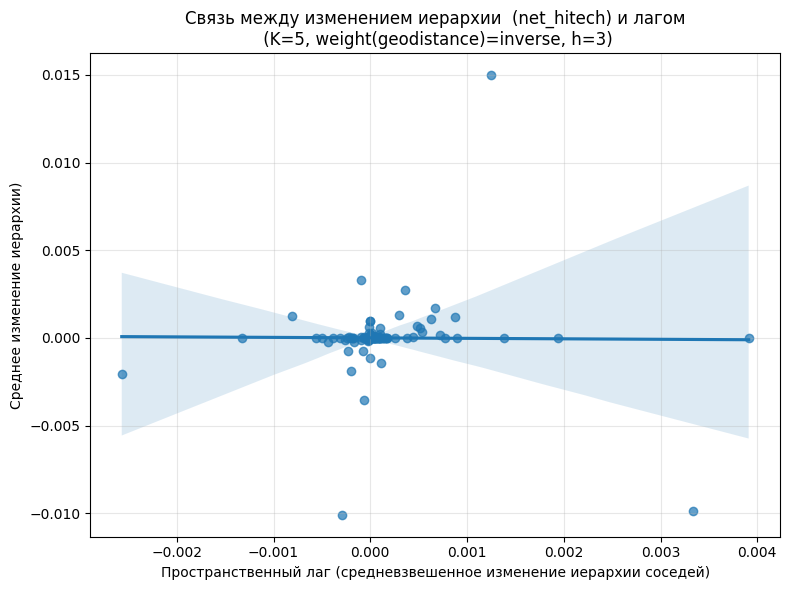

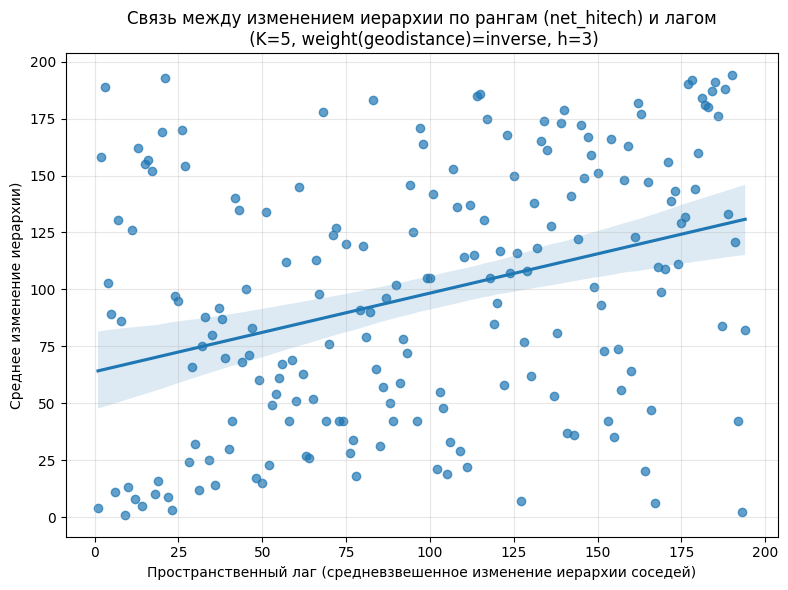

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0087, p-value = 0.9037
INFO:root:Спирмен: r = 0.3451, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.0028
INFO:root:p-value (перестановочный) = 0.4720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2369
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2696, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0797
INFO:root:p-value (перестановочный) = 0.0480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0260
INFO:root:p-value (перестановочный) = 0.2290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0885
INFO:root:p-value (перестановочный) = 0.0320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1446
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0229
INFO:root:p-value (перестановочный) = 0.2810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0172
INFO:root:p-value (перестановочный) = 0.4460
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (178, 178)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0881
INFO:root:p-value (перестановочный) = 0.0270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0170
INFO:root:p-value (перестановочный) = 0.3100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0267
INFO:root:p-value (перестановочный) = 0.2420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0775
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1564
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0927
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0163
INFO:root:p-value (перестановочный) = 0.3320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0262
INFO:root:p-value (перестановочный) = 0.2420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0661
INFO:root:p-value (перестановочный) = 0.0640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0770
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0960
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0650
INFO:root:p-value (перестановочный) = 0.0760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0572
INFO:root:p-value (перестановочный) = 0.0830
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0227
INFO:root:p-value (перестановочный) = 0.2510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1257
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1237
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0911
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0641
INFO:root:p-value (перестановочный) = 0.0750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0609
INFO:root:p-value (перестановочный) = 0.0760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0621
INFO:root:p-value (перестановочный) = 0.0880
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0596
INFO:root:p-value (перестановочный) = 0.0840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0462
INFO:root:p-value (перестановочный) = 0.1300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1554
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1405
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0873
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0861
INFO:root:p-value (перестановочный) = 0.0300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0083
INFO:root:p-value (перестановочный) = 0.3700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0076
INFO:root:p-value (перестановочный) = 0.3870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0662
INFO:root:p-value (перестановочный) = 0.0480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    158  0.079738    0.048  0.172837 0.123768
 1989    158  0.025991    0.229  0.057321 0.635225
 1990    158  0.088522    0.032  0.182469 0.101787
 1991    158  0.144630    0.005  0.279846 0.006626
 1992    158  0.022910    0.281  0.064942 0.589356
 1993    161 -0.017157    0.446 -0.051573 0.682902
 1994    178  0.088100    0.027  0.205695 0.045707
 1995    181  0.017015    0.310  0.041383 0.715798
 1996    186  0.026698    0.242  0.067363 0.542373
 1997    187  0.077492    0.045  0.168734 0.103039
 1998    187  0.156420    0.001  0.313112 0.000666
 1999    187  0.0927

ML_Lag


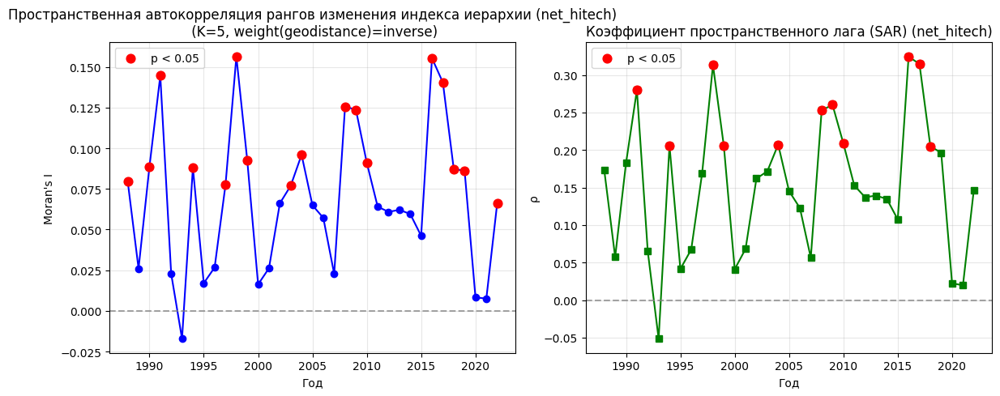

INFO:root:Starting spatial analysis for de_jure_borders with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


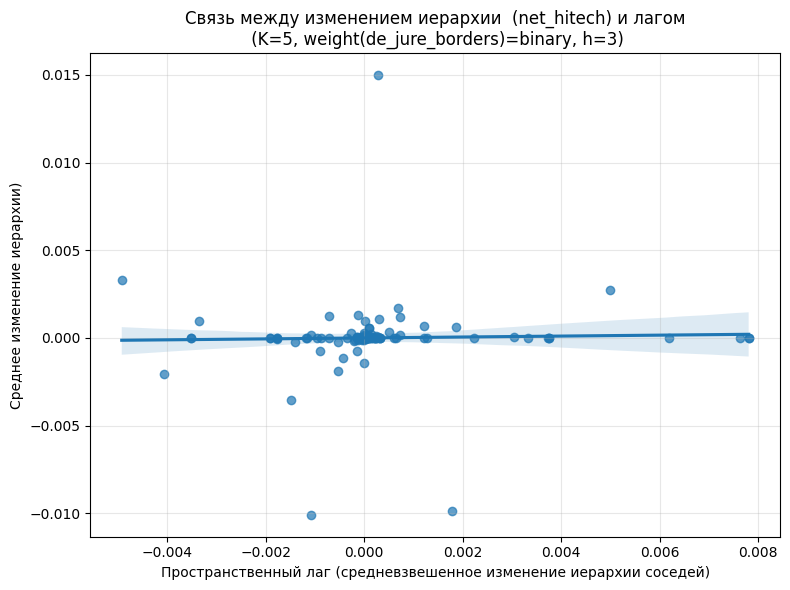

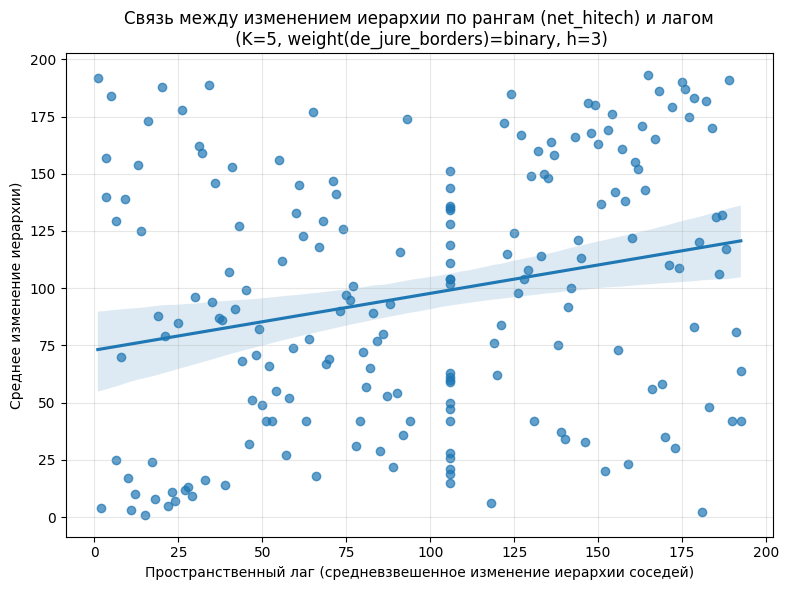

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0253, p-value = 0.7272
INFO:root:Спирмен: r = 0.2479, p-value = 0.0005
INFO:root:=== Moran's I ===
INFO:root:I = 0.0272
INFO:root:p-value (перестановочный) = 0.1200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2297
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2625, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0505
INFO:root:p-value (перестановочный) = 0.2080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.1122
INFO:root:p-value (перестановочный) = 0.0510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.0822
INFO:root:p-value (перестановочный) = 0.1240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ знач

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1995
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.60, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.3420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.69, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0429
INFO:root:p-value (перестановочный) = 0.2090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0833
INFO:root:p-value (перестановочный) = 0.0700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (186,

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = -0.0010
INFO:root:p-value (перестановочный) = 0.4620
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0714
INFO:root:p-value (перестановочный) = 0.1010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0392
INFO:root:p-value (перестановочный) = 0.2150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1053
INFO:root:p-value (перестановочный) = 0.0410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0945
INFO:root:p-value (перестановочный) = 0.0420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2029
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0364
INFO:root:p-value (перестановочный) = 0.2460
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0868
INFO:root:p-value (перестановочный) = 0.0820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1463
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2018
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0980
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1089
INFO:root:p-value (перестановочный) = 0.0330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0947
INFO:root:p-value (перестановочный) = 0.0460
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


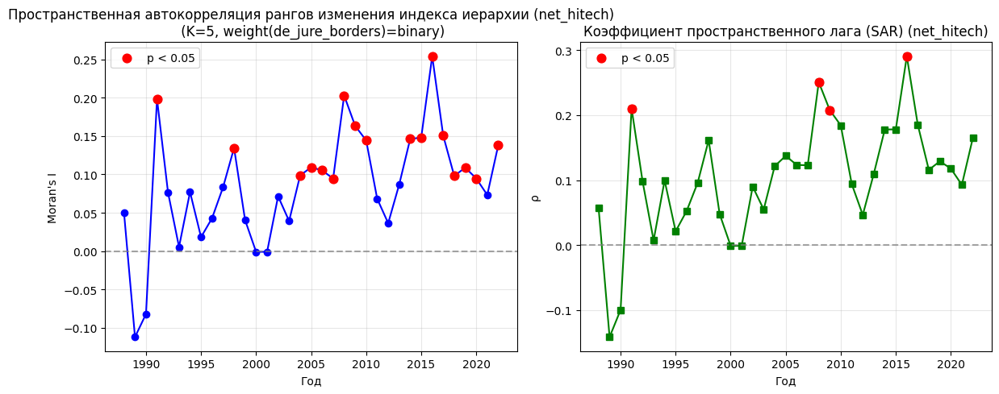

In [901]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['geodistance','de_jure_borders']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

#### Гипотеза о связке пространства и дружественности

INFO:root:Starting spatial analysis for geodistance with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)


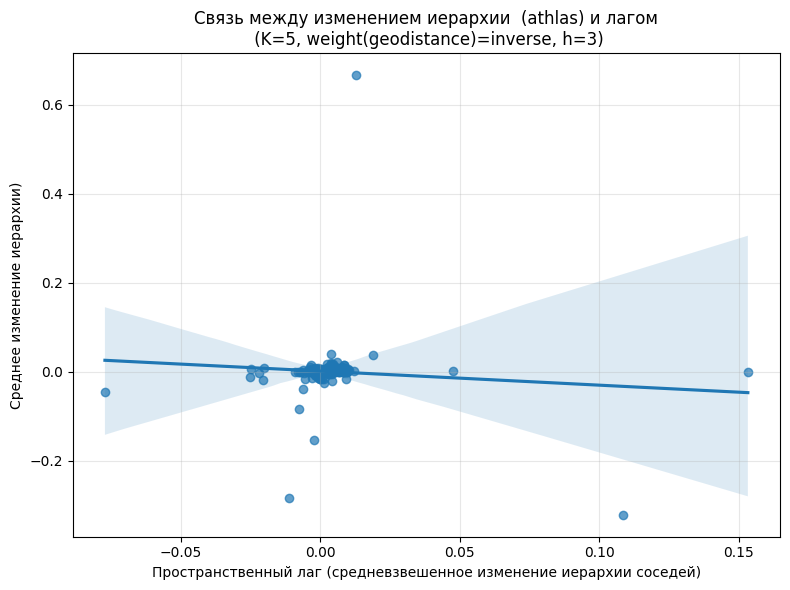

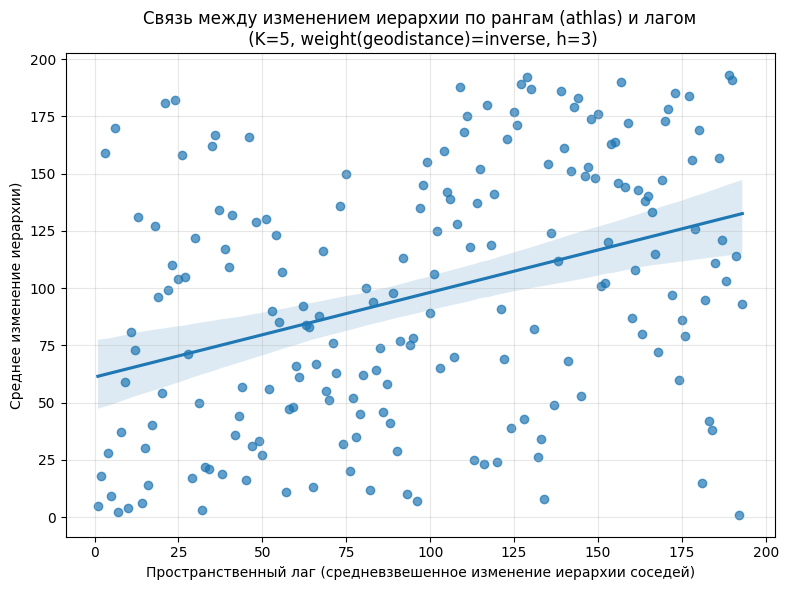

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0851, p-value = 0.2391
INFO:root:Спирмен: r = 0.3701, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.0230
INFO:root:p-value (перестановочный) = 0.1360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1282, p = 0.0090
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    51
tense       47
hostile     47
neutral     47
Name: count, dtype: int64
Мин. размер режима: 47 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      51  0.003786  0.006910 -0.005712  0.040290
hostile       47 -0.010581  0.044160 -0.283977  0.017868
neutral       47 -0.000318  0.023488 -0.153605  0.020835
tense         47  0.009224  0.109013 -0.321061  0.666065
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0936
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1119
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0215
INFO:root:p-value (перестановочный) = 0.2630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0040
INFO:root:p-value (перестановочный) = 0.4540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0550
INFO:root:p-value (перестановочный) = 0.1250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0276
INFO:root:p-value (перестановочный) = 0.3430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0146
INFO:root:p-value (перестановочный) = 0.4260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0330
INFO:root:p-value (перестановочный) = 0.2130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0585
INFO:root:p-value (перестановочный) = 0.0890
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0592
INFO:root:p-value (перестановочный) = 0.0910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1577
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0881
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0088
INFO:root:p-value (перестановочный) = 0.3660
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0191
INFO:root:p-value (перестановочный) = 0.3080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0709
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0260
INFO:root:p-value (перестановочный) = 0.2390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0027
INFO:root:p-value (перестановочный) = 0.4150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.1900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0391
INFO:root:p-value (перестановочный) = 0.1350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0353
INFO:root:p-value (перестановочный) = 0.1750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0424
INFO:root:p-value (перестановочный) = 0.1420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1093
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1314
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0331
INFO:root:p-value (перестановочный) = 0.1910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0594
INFO:root:p-value (перестановочный) = 0.0760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0739
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1995    192  0.093644    0.020  0.199972 0.046075
 1996    193  0.111930    0.012  0.240566 0.013112
 1997    193  0.021489    0.263  0.051780 0.637770
 1998    193 -0.004009    0.454 -0.010417 0.926881
 1999    193 -0.054980    0.125 -0.153980 0.200472
 2000    193 -0.027559    0.343 -0.074394 0.524035
 200

ML_Lag
ML_Lag


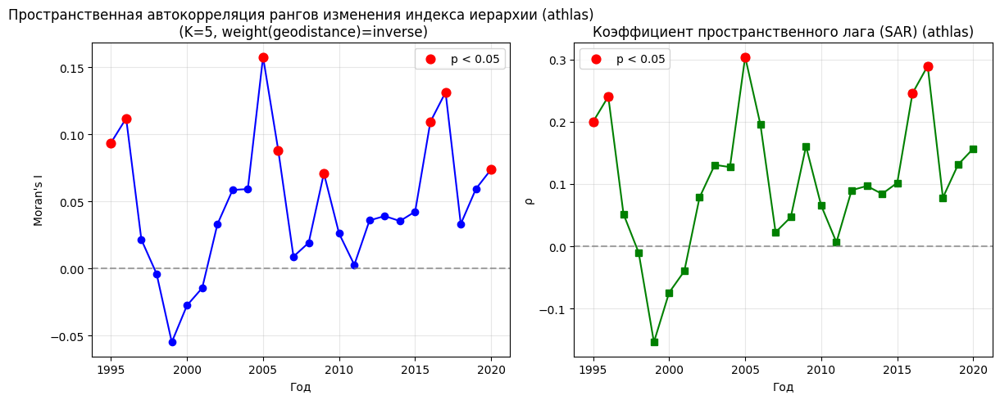

INFO:root:Starting spatial analysis for de_jure_borders with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


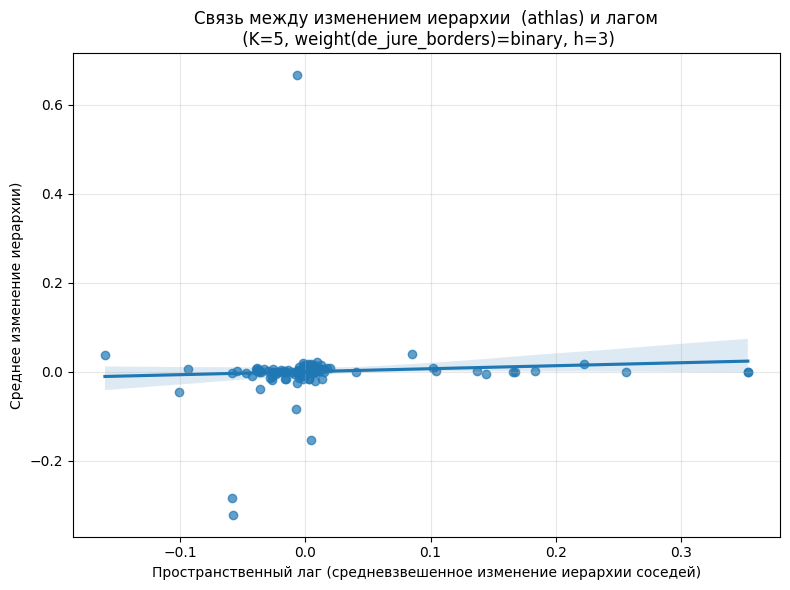

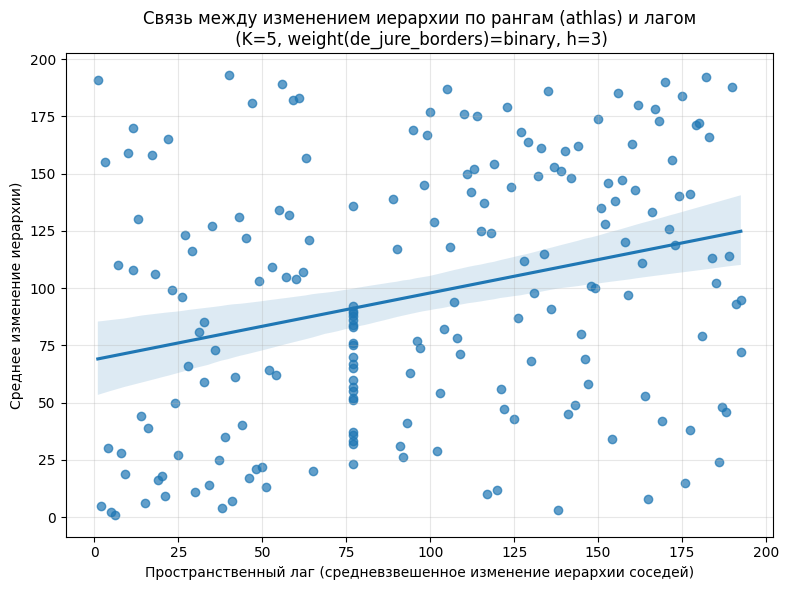

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0634, p-value = 0.3812
INFO:root:Спирмен: r = 0.2909, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0679
INFO:root:p-value (перестановочный) = 0.0170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2521
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1689, p = 0.0020
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:year is 1994
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.62, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0970
INFO:root:p-value (перестановочный) = 0.0390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1825
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (193, 193), средняя 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0309
INFO:root:p-value (перестановочный) = 0.2670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0830
INFO:root:p-value (перестановочный) = 0.0550
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0494
INFO:root:p-value (перестановочный) = 0.1730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (193,

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2008
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0783
INFO:root:p-value (перестановочный) = 0.0800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1139
INFO:root:p-value (перестановочный) = 0.0280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1406
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значи

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0366
INFO:root:p-value (перестановочный) = 0.2280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0356
INFO:root:p-value (перестановочный) = 0.2440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0711
INFO:root:p-value (перестановочный) = 0.0870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:r

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0638
INFO:root:p-value (перестановочный) = 0.1010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1995    169  0.096992    0.039  0.129031 0.180224
 1996    170  0.182484    0.002  0.254854 0.005220
 1997    170  0.037798    0.212  0.058579 0.551914
 1998    170  0.036118    0.228  0.057935 0.556362
 1999    170 -0.001752    0.461 -0.002734 0.978147
 2000    170  0.030064    0.245  0.044723 0.650820
 2001    170  0.012106    0.371  0.018302 0.853900
 2002    170  0.030886    0.267  0.044189 0.654759
 2003    170  0.082956    0.055  0.105810 0.276088
 2004    170  0.049436    0.173  0.063574 0.517987
 2005    170  0.164182    0.003  0.189395 0.044295
 2006    170  0.170400    0.00

ML_Lag
ML_Lag


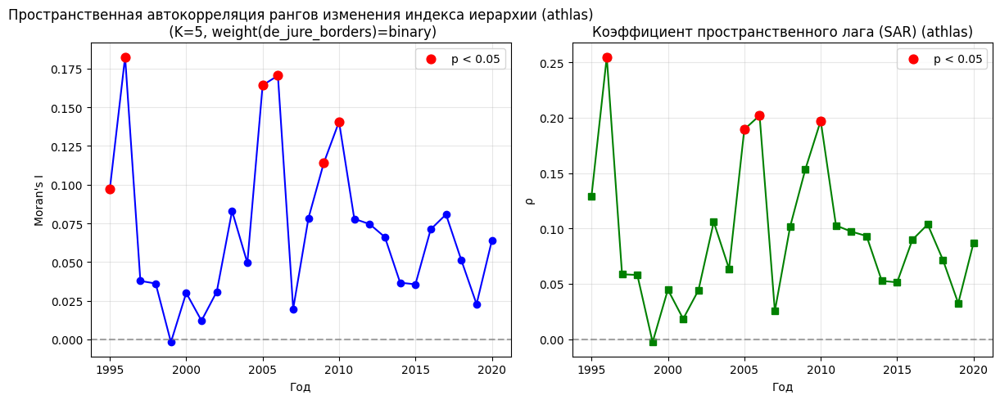

INFO:root:Starting spatial analysis for geodistance with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 182


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)


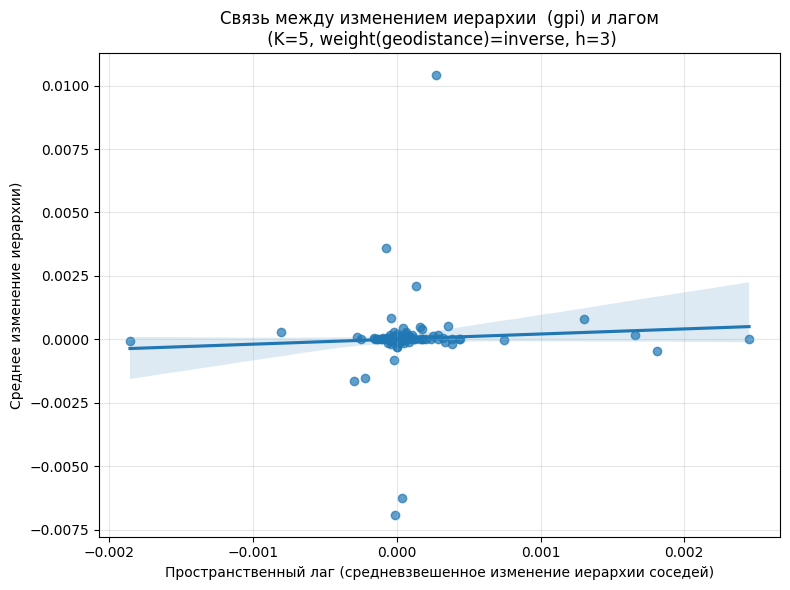

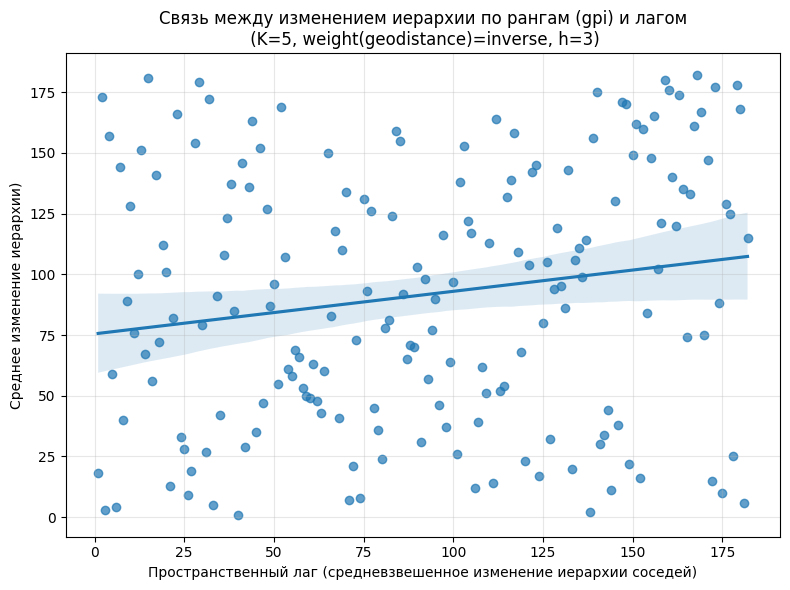

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0603, p-value = 0.4188
INFO:root:Спирмен: r = 0.1751, p-value = 0.0181
INFO:root:=== Moran's I ===
INFO:root:I = 0.0182
INFO:root:p-value (перестановочный) = 0.1140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1667
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1207, p = 0.0140
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    49
tense       45
neutral     45
hostile     41
Name: count, dtype: int64
Мин. размер режима: 41 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      49  0.000067  0.000312 -0.000300  0.002097
hostile       41 -0.000178  0.001278 -0.006906  0.003599
neutral       45 -0.000129  0.000931 -0.006233  0.000140
tense         45  0.000319  0.001555 -0.000468  0.010411
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (170, 170)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0691
INFO:root:p-value (перестановочный) = 0.0690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (170, 170)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0636
INFO:root:p-value (перестановочный) = 0.0880
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1663
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1472
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (173, 173)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1846
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1035
INFO:root:p-value (перестановочный) = 0.0170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2548
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2316
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2063
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1154
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0081
INFO:root:p-value (перестановочный) = 0.3750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0348
INFO:root:p-value (перестановочный) = 0.2580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0273
INFO:root:p-value (перестановочный) = 0.2470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0294
INFO:root:p-value (перестановочный) = 0.2040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0848
INFO:root:p-value (перестановочный) = 0.0360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1395
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2241
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1513
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1261
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1103
INFO:root:p-value (перестановочный) = 0.0150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1567
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1344
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3039
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3093
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3832
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2497
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1882
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0273
INFO:root:p-value (перестановочный) = 0.2450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0960
INFO:root:p-value (перестановочный) = 0.0280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1186
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1051
INFO:root:p-value (перестановочный) = 0.0130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1412
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1225
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1159
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0543
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho        rho_p
 1988    170  0.069055    0.069  0.154571 1.588354e-01
 1989    170  0.063581    0.088  0.144710 1.901379e-01
 1990    173  0.166308    0.002  0.307879 1.327417e-03
 1991    173  0.147164    0.003  0.280747 4.326210e-03
 1992    173  0.184581    0.002  0.338344 2.760532e-04
 1993    182  0.103516    0.017  0.215333 3.323270e-02
 1994    182  0.254780    0.001  0.433516 9.521229e-08
 1995    182  0.231594    0.001  0.402402 1.859774e-06
 1996    182  0.206296    0.001  0.382800 9.227042e-06
 1997    182  0.115445    0.006  0.237721 1.668915e-02
 1998    182  0.008059    0.375  0.020949 8.551042e-01
 1999    182 -0.034831    0.258 -0.101537 4.

ML_Lag


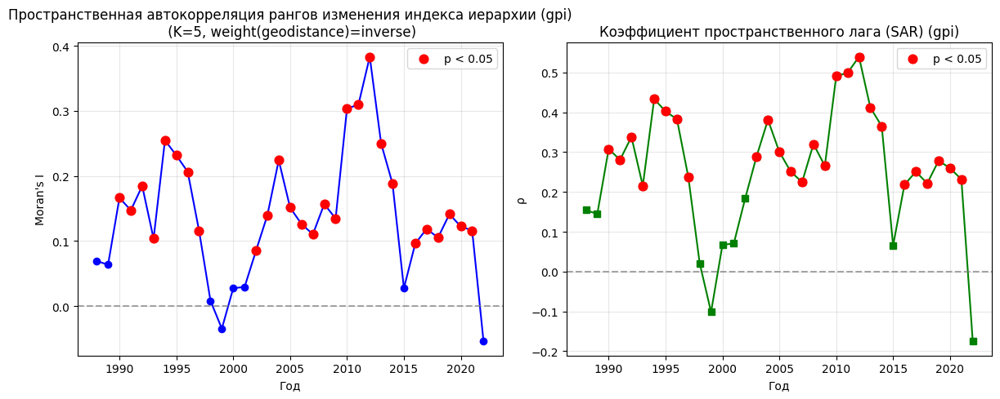

INFO:root:Starting spatial analysis for de_jure_borders with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20


(3,) None


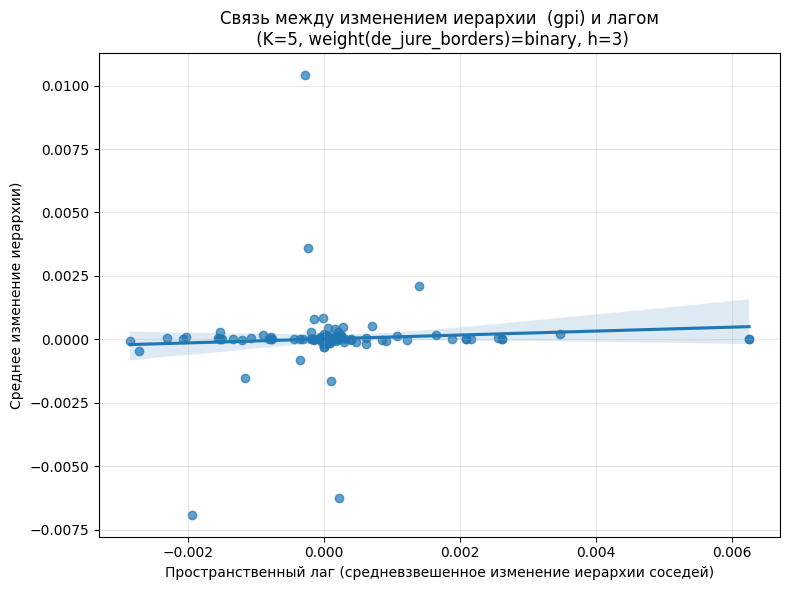

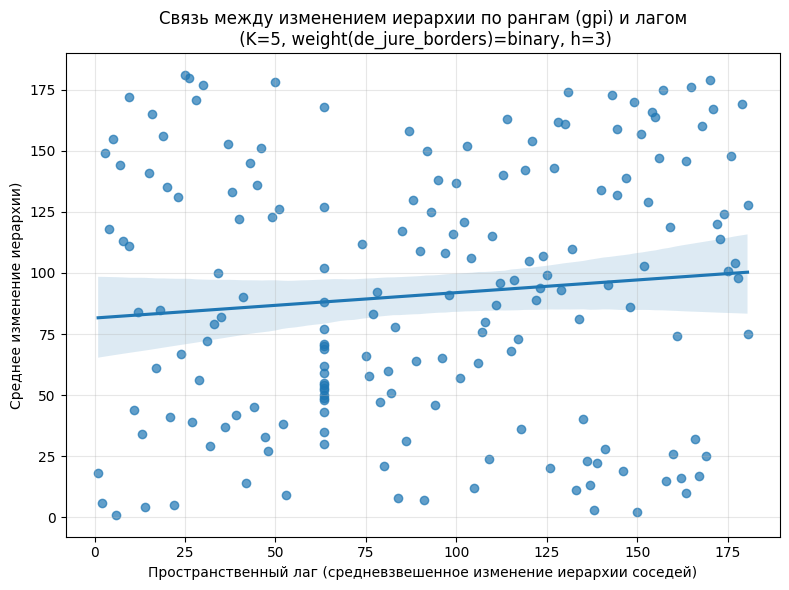

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0724, p-value = 0.3327
INFO:root:Спирмен: r = 0.1039, p-value = 0.1640
INFO:root:=== Moran's I ===
INFO:root:I = 0.0760
INFO:root:p-value (перестановочный) = 0.0360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1854
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1364, p = 0.0160
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Samoa', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Seychelles', ' is an isl

INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (169, 169), средняя степень = 3.46, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1492
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (169, 169), средняя степень = 3.46, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1519
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (172, 172), средняя степень = 3.52, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2934
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2555
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INF

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2001
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0149
INFO:root:p-value (перестановочный) = 0.4430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1206
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2364
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I знач

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2006
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0449
INFO:root:p-value (перестановочный) = 0.1850
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0642
INFO:root:p-value (перестановочный) = 0.1150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2226
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иера

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2013
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.3411
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2638
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1230
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2019
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0795
INFO:root:p-value (перестановочный) = 0.0790
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.1828
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 3.72, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0627
INFO:root:p-value (перестановочный) = 0.1030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ зн

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho        rho_p
 1988    149  0.149223    0.006  0.185187 6.152467e-02
 1989    149  0.151924    0.012  0.200748 4.124333e-02
 1990    152  0.153450    0.009  0.207600 3.363628e-02
 1991    152  0.121361    0.018  0.168799 8.955350e-02
 1992    152  0.187176    0.004  0.241077 1.211690e-02
 1993    161  0.167855    0.005  0.206045 3.322252e-02
 1994    161  0.294756    0.001  0.359651 4.520059e-05
 1995    161  0.293355    0.001  0.378114 1.362673e-05
 1996    161  0.255532    0.001  0.343039 1.211655e-04
 1997    161  0.165820    0.002  0.210940 2.888113e-02
 1998    161  0.079815    0.084  0.112431 2.634358e-01
 1999    161  0.064292    0.125  0.096465 3.398743e-01
 2000    161  0.148852    0.004  0.189277 5.226780e-02
 2001    161 -0.014944    0.443 -0.020500 8.438026e-01
 2002    161  0.120633    0.022  0.158628 1.084106e-01
 2003    161  0.236379    0.001  0.268677 4.108557e-03
 2004    161  0.34

ML_Lag


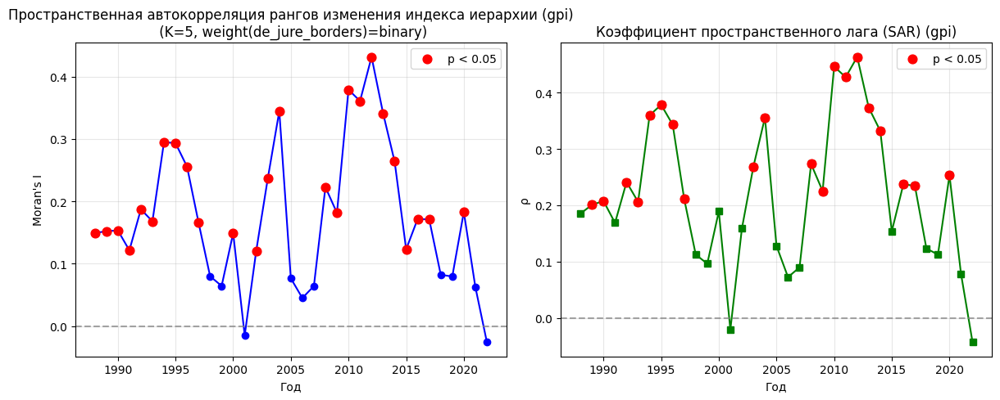

INFO:root:Starting spatial analysis for geodistance with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)


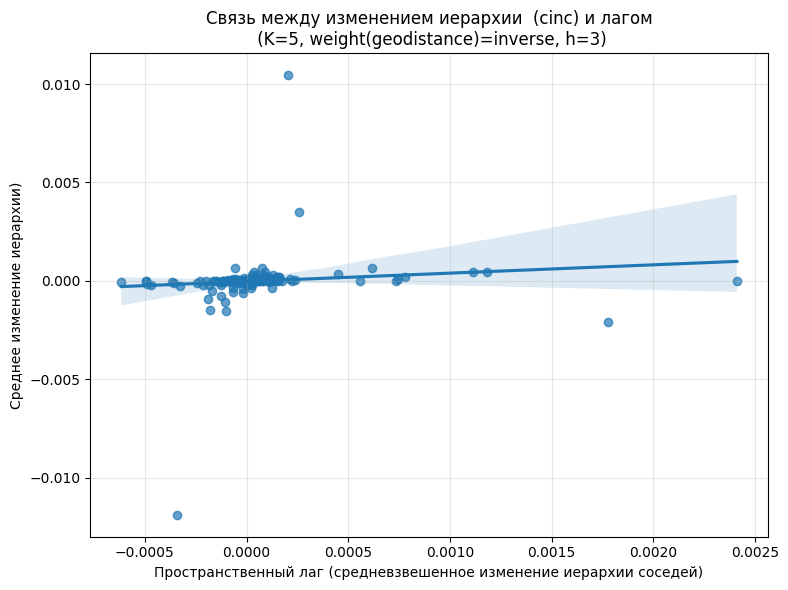

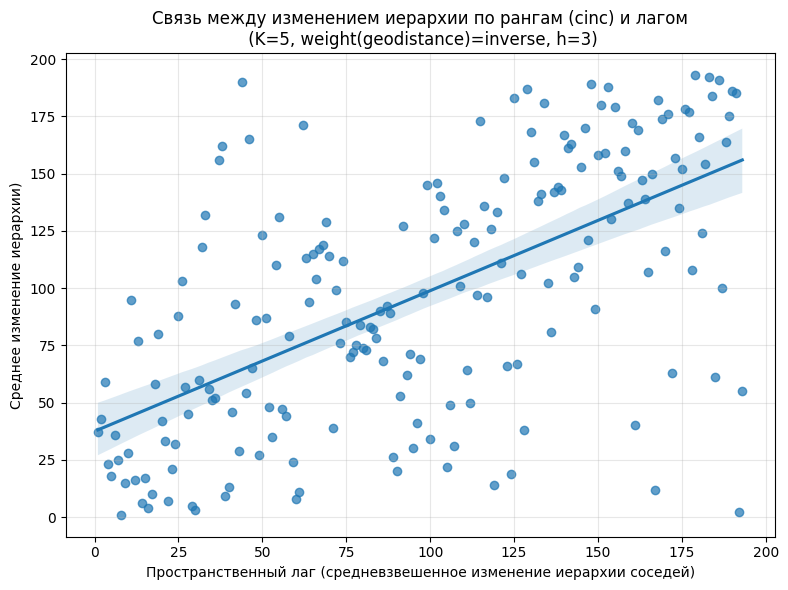

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1047, p-value = 0.1473
INFO:root:Спирмен: r = 0.6140, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0259
INFO:root:p-value (перестановочный) = 0.0650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4789
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.4040, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    51
tense       47
hostile     47
neutral     47
Name: count, dtype: int64
Мин. размер режима: 47 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      51  0.000089  0.000504 -0.000431  0.003514
hostile       47 -0.000144  0.000366 -0.001520  0.000663
neutral       47 -0.000237  0.001739 -0.011892  0.000215
tense         47  0.000215  0.001586 -0.002104  0.010455
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0850
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2044
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1894
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1849
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (155, 155)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2313
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (159, 159)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2117
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (175, 175)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1100
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (179, 179)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0766
INFO:root:p-value (перестановочный) = 0.0500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1297
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2416
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2690
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1825
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1526
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1132
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1224
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1272
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1198
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2043
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2549
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1918
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2708
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2924
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2469
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3402
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3044
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3360
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2805
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1883
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2470
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1749
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2145
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2081
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1786
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2120
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    155 0.084959    0.044 0.188278 9.204520e-02
 1989    155 0.204403    0.001 0.393045 2.115936e-05
 1990    155 0.189367    0.001 0.341223 4.837062e-04
 1991    155 0.184900    0.001 0.352356 2.670511e-04
 1992    155 0.231270    0.001 0.415768 3.828680e-06
 1993    159 0.211744    0.001 0.397083 1.315388e-05
 1994    175 0.110044    0.012 0.237347 1.900207e-02
 1995    179 0.076554    0.050 0.173437 9.932464e-02
 1996    185 0.129695    0.004 0.262345 6.646141e-03
 1997    186 0.241640    0.001 0.392357 3.889280e-06
 1998    186 0.268954    0.001 0.466368 1.862168e

ML_Lag


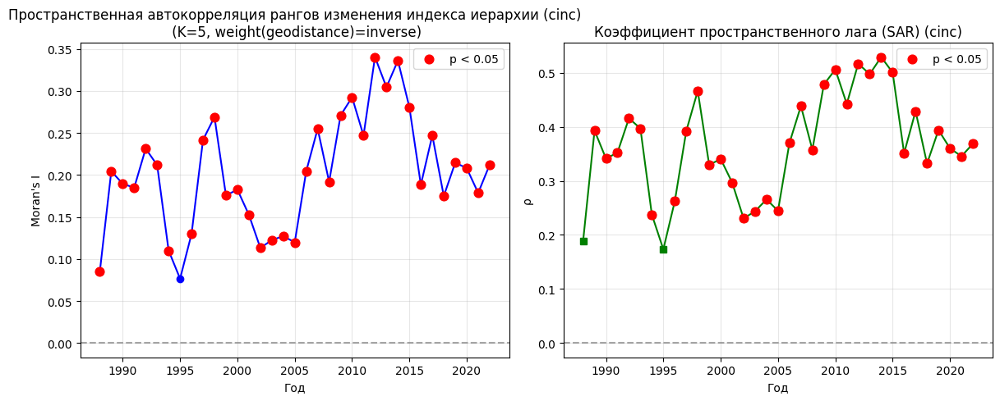

INFO:root:Starting spatial analysis for de_jure_borders with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


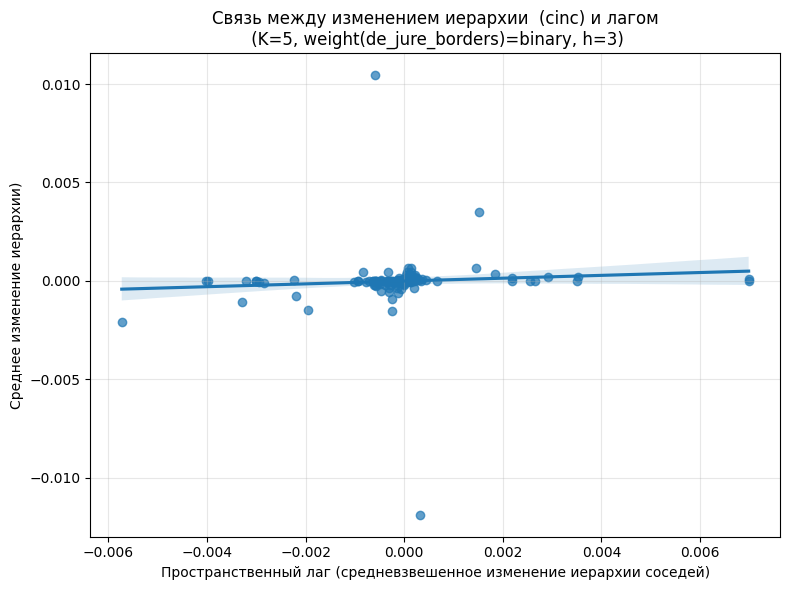

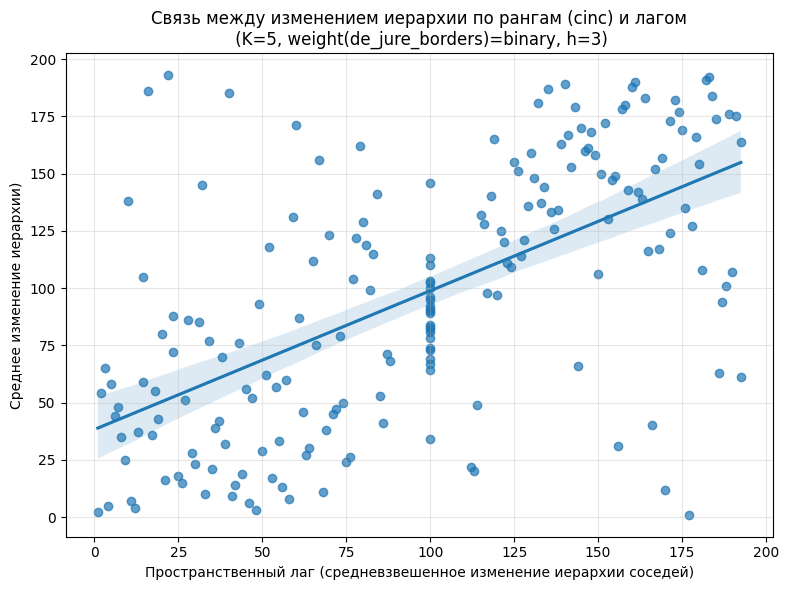

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0756, p-value = 0.2961
INFO:root:Спирмен: r = 0.6053, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0900
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.6962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.5106, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0637
INFO:root:p-value (перестановочный) = 0.1450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0072
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.1834
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0072
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 3.25, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.1544
INFO:

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 3.60, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1430
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.69, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1041
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (186

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.2055
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.2347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0805
INFO:root:p-value (перестановочный) = 0.0640
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2582
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3294
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2884
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4147
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4073
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4289
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2396
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3787
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2583
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


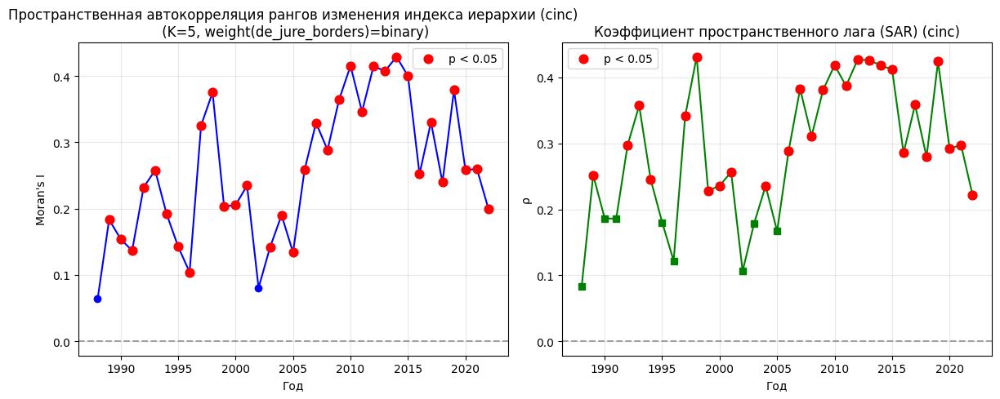

INFO:root:Starting spatial analysis for geodistance with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


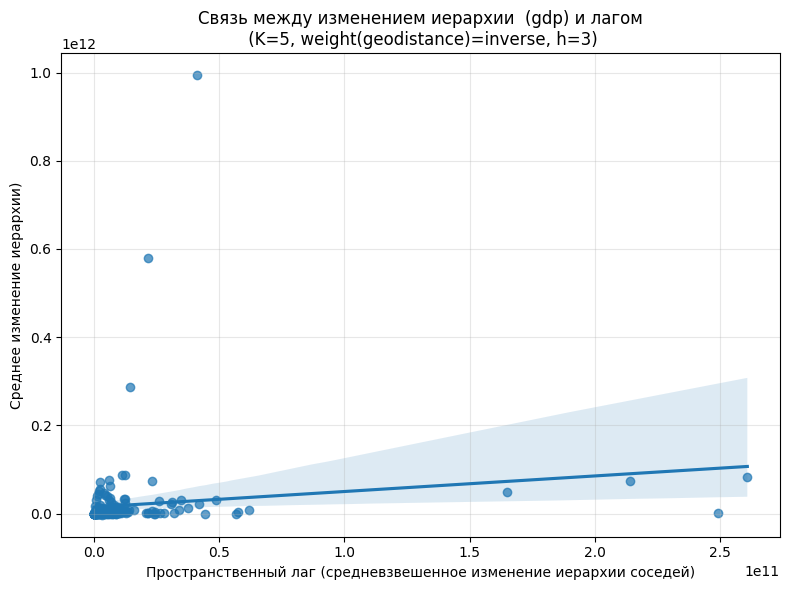

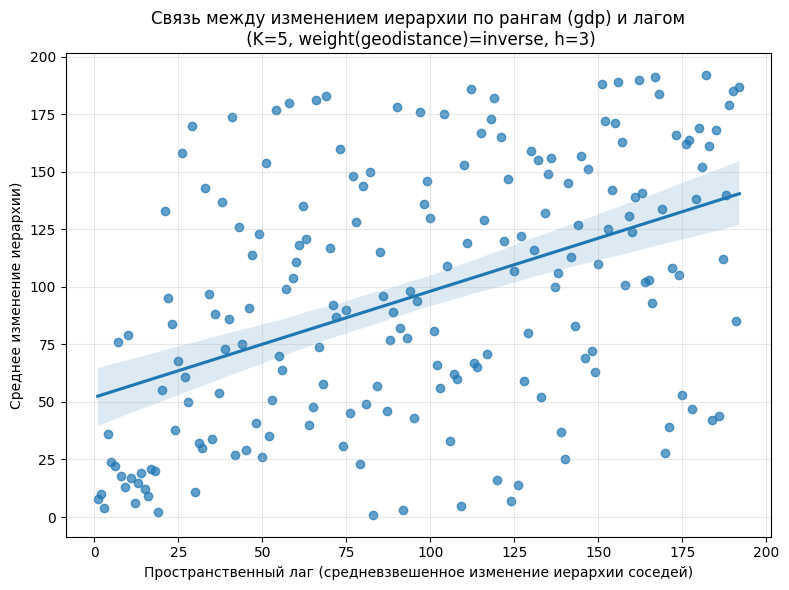

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1358, p-value = 0.0603
INFO:root:Спирмен: r = 0.4606, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0522
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3448
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0888, p = 0.0390
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

ML_Lag
ML_Error
Размеры режимов:
friendly    51
neutral     47
tense       46
hostile     46
Name: count, dtype: int64
Мин. размер режима: 46 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count          mean           std           min           max
hostility                                                               
friendly      51  1.161105e+10  4.136404e+10  1.314329e+06  2.860355e+11
hostile       46  2.621232e+10  8.600365e+10 -1.530939e+09  5.793686e+11
neutral       47  5.531186e+09  1.152594e+10  1.584767e+07  5.587947e+10
tense         46  3.589586e+10  1.462579e+11 -5.860436e+08  9.941091e+11
(3,) None


INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица весов построена (K=5, inverse): (160, 160)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3655
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3182
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (164, 164)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3954
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3916
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (166, 166)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3967
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4051
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3998
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3790
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3362
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3159
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3015
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3040
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3071
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3364
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3021
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2941
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3173
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3512
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3453
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3369
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2608
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2737
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3589
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3134
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2542
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2841
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3060
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2929
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3058
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3216
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2445
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1465
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag


INFO:root:year is 2022
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    160 0.365462    0.001 0.516644 5.746537e-11
 1989    161 0.318238    0.001 0.474291 1.359675e-08
 1990    164 0.395380    0.001 0.552372 5.906386e-14
 1991    165 0.391605    0.001 0.553111 3.885781e-14
 1992    166 0.396726    0.001 0.562705 4.884981e-15
 1993    184 0.405069    0.001 0.587016 0.000000e+00
 1994    184 0.399800    0.001 0.612770 0.000000e+00
 1995    185 0.378958    0.001 0.596122 0.000000e+00
 1996    185 0.336207    0.001 0.541285 1.310063e-14
 1997    186 0.334736    0.001 0.528666 1.392220e-13
 1998    187 0.315897    0

ML_Lag
ML_Lag


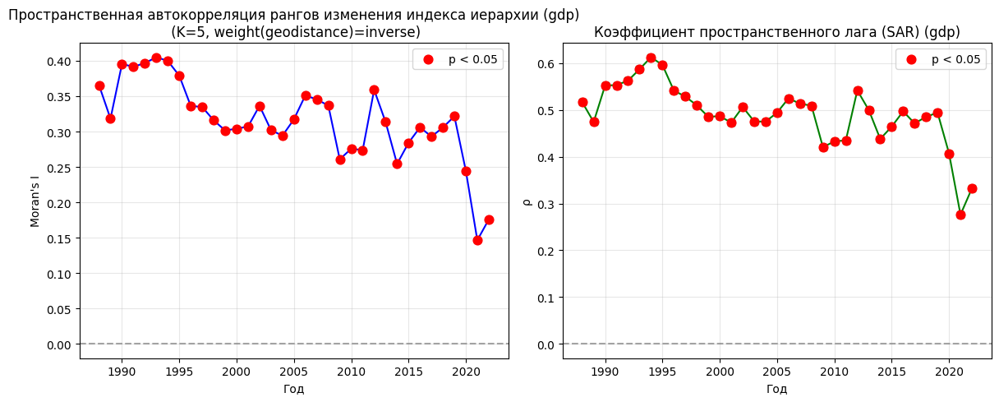

INFO:root:Starting spatial analysis for de_jure_borders with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.64, изолированных вершин = 23
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


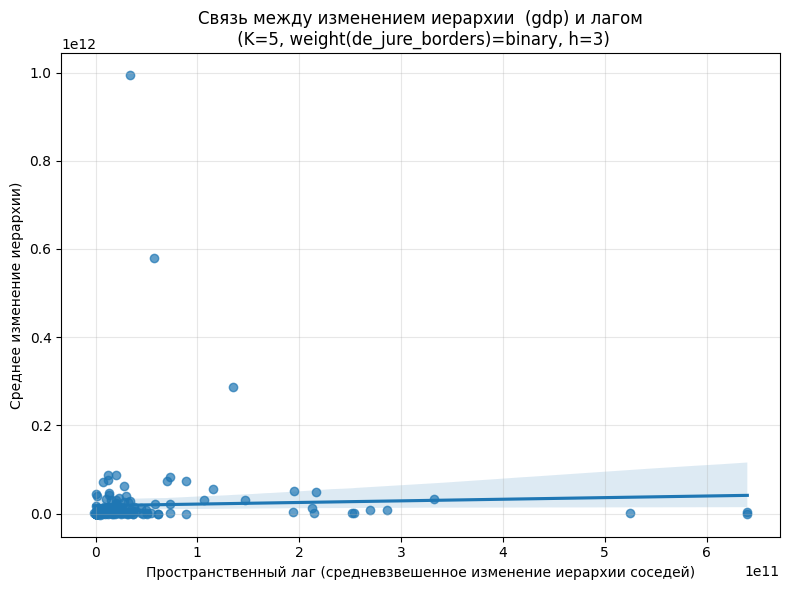

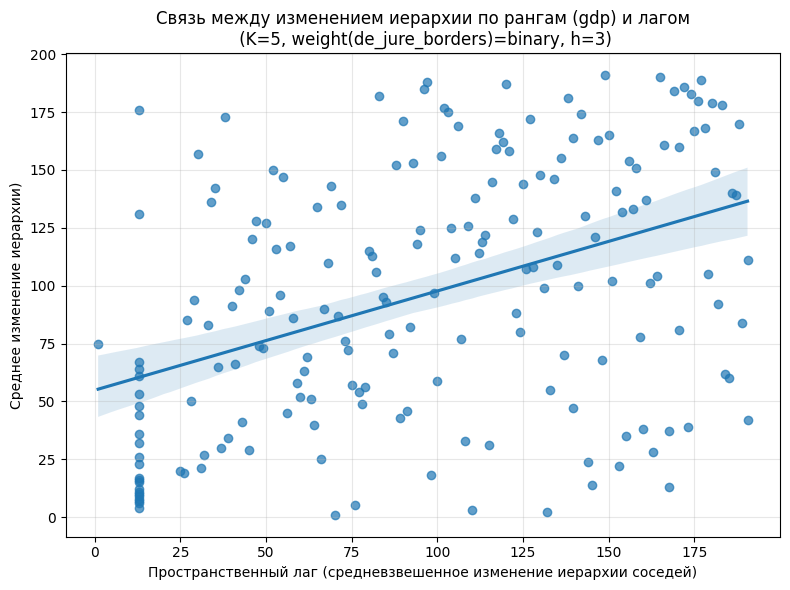

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0387, p-value = 0.5952
INFO:root:Спирмен: r = 0.4284, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0403
INFO:root:p-value (перестановочный) = 0.0500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2245
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1243, p = 0.0390
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.05, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.5139
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0074
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 3.06, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4859
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0073
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 3.06, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4150
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3551
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2678
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2757
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2119
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2188
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2214
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2217
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2134
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2764
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2356
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1928
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2219
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2014
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2546
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


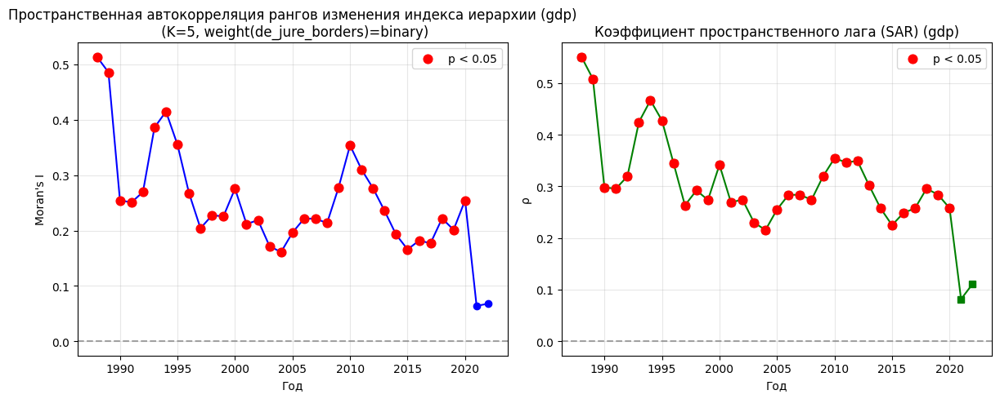

INFO:root:Starting spatial analysis for geodistance with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


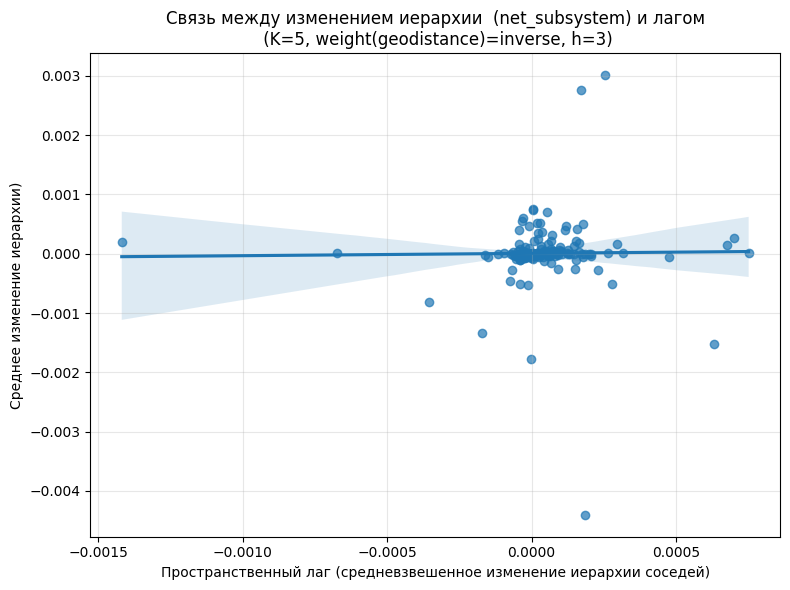

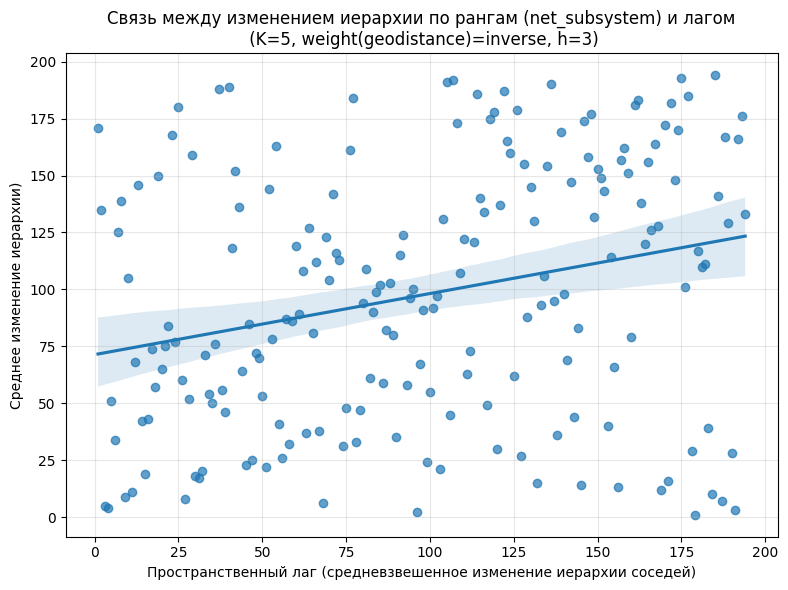

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0138, p-value = 0.8489
INFO:root:Спирмен: r = 0.2683, p-value = 0.0002
INFO:root:=== Moran's I ===
INFO:root:I = 0.0047
INFO:root:p-value (перестановочный) = 0.4130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2000
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2571, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    51
tense       47
hostile     47
neutral     47
Name: count, dtype: int64
Мин. размер режима: 47 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      51  0.000009  0.000143 -0.000467  0.000711
hostile       47 -0.000024  0.000853 -0.004403  0.003009
neutral       47 -0.000046  0.000271 -0.001773  0.000412
tense         47  0.000096  0.000509 -0.001517  0.002766
(3,) None


INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0712
INFO:root:p-value (перестановочный) = 0.0620
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0586
INFO:root:p-value (перестановочный) = 0.1110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0370
INFO:root:p-value (перестановочный) = 0.2030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0265
INFO:root:p-value (перестановочный) = 0.2450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0177
INFO:root:p-value (перестановочный) = 0.2920
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0510
INFO:root:p-value (перестановочный) = 0.1270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0147
INFO:root:p-value (перестановочный) = 0.3100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0599
INFO:root:p-value (перестановочный) = 0.0860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0485
INFO:root:p-value (перестановочный) = 0.1390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0282
INFO:root:p-value (перестановочный) = 0.2030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0546
INFO:root:p-value (перестановочный) = 0.1050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0022
INFO:root:p-value (перестановочный) = 0.4630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0422
INFO:root:p-value (перестановочный) = 0.2110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0217
INFO:root:p-value (перестановочный) = 0.3640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0133
INFO:root:p-value (перестановочный) = 0.4320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1102
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0569
INFO:root:p-value (перестановочный) = 0.1060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0099
INFO:root:p-value (перестановочный) = 0.3340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0543
INFO:root:p-value (перестановочный) = 0.1330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0446
INFO:root:p-value (перестановочный) = 0.1780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0357
INFO:root:p-value (перестановочный) = 0.2780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0997
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0349
INFO:root:p-value (перестановочный) = 0.2600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0010
INFO:root:p-value (перестановочный) = 0.4480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0095
INFO:root:p-value (перестановочный) = 0.4520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0368
INFO:root:p-value (перестановочный) = 0.2410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0498
INFO:root:p-value (перестановочный) = 0.1590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0133
INFO:root:p-value (перестановочный) = 0.2970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.2670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0076
INFO:root:p-value (перестановочный) = 0.4860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0012
INFO:root:p-value (перестановочный) = 0.4600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0496
INFO:root:p-value (перестановочный) = 0.1660
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0575
INFO:root:p-value (перестановочный) = 0.0860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1021
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0068
INFO:root:p-value (перестановочный) = 0.3940
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    161  0.071248    0.062  0.171993 0.122369
 1989    161  0.058635    0.111  0.140352 0.217425
 1990    161  0.036978    0.203  0.085727 0.466744
 1991    161  0.026457    0.245  0.057368 0.631865
 1992    161  0.017710    0.292  0.039301 0.745206
 1993    165  0.051020    0.127  0.119541 0.295058
 1994    182  0.014664    0.310  0.036984 0.744609
 1995    185  0.059903    0.086  0.140288 0.185934
 1996    187  0.048496    0.139  0.120825 0.258103
 1997    188  0.028156    0.203  0.062801 0.569312
 1998    188  0.054574    0.105  0.123415 0.246306
 1999    188 -0.002193    0.463 -0.005785 0.959655
 2000    188 -0.042157    0.211 -0.114837 

ML_Lag


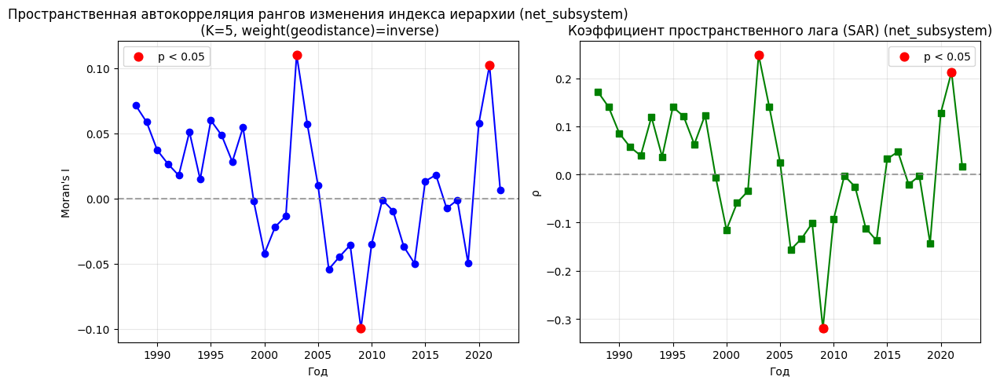

INFO:root:Starting spatial analysis for de_jure_borders with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


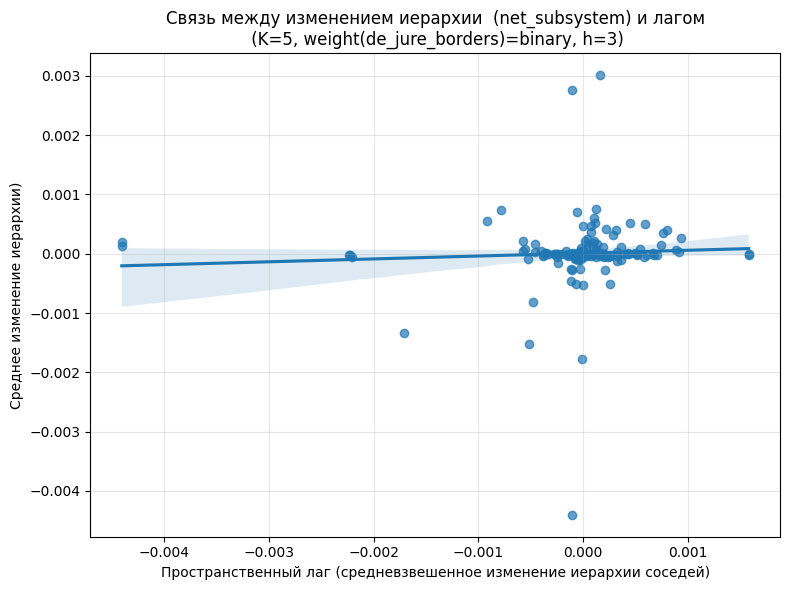

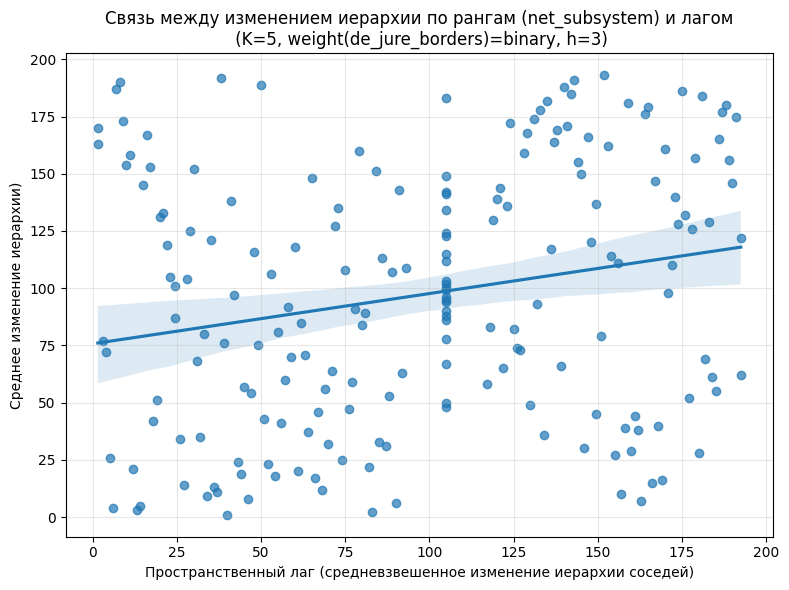

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0600, p-value = 0.4075
INFO:root:Спирмен: r = 0.2191, p-value = 0.0022
INFO:root:=== Moran's I ===
INFO:root:I = 0.0840
INFO:root:p-value (перестановочный) = 0.0290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1812
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2353, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0303
INFO:root:p-value (перестановочный) = 0.3050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = -0.0164
INFO:root:p-value (перестановочный) = 0.4610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1310
INFO:root:p-value (перестановочный) = 0.0320
INFO:root:Ожидаемое I при отсутс

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.61, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0942
INFO:root:p-value (перестановочный) = 0.0380
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0608
INFO:root:p-value (перестановочный) = 0.1290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (187, 187), средняя степень = 3.65, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.0024
INFO:root:p-value (перестановочный) = 0.4310
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0630
INFO:root:p-value (перестановочный) = 0.1720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (187, 187), средняя степень = 3.65, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0034
INFO:root:p-value (перестановочный) = 0.4730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0103
INFO:root:p-value (перестановочный) = 0.3740
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0956
INFO:root:p-value (перестановочный) = 0.0470

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2006
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0658
INFO:root:p-value (перестановочный) = 0.1270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0250
INFO:root:p-value (перестановочный) = 0.2800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0526
INFO:root:p-value (перестановочный) = 0.2330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (192

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2012
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0778
INFO:root:p-value (перестановочный) = 0.1030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.1360
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0635
INFO:root:p-value (перестановочный) = 0.1510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2018
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = -0.0021
INFO:root:p-value (перестановочный) = 0.4800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0069
INFO:root:p-value (перестановочный) = 0.4130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0888
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иер

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    142  0.030262    0.305  0.042684 0.682310
 1989    142 -0.016398    0.461 -0.021496 0.838601
 1990    142  0.130957    0.032  0.174282 0.081456
 1991    142  0.058079    0.160  0.076411 0.459954
 1992    142  0.075032    0.104  0.101275 0.323925
 1993    146  0.114940    0.034  0.150236 0.134683
 1994    161  0.012777    0.378  0.018635 0.854396
 1995    164  0.094164    0.038  0.129320 0.184743
 1996    167  0.060825    0.129  0.093337 0.341236
 1997    167  0.002367    0.431  0.003255 0.974104
 1998    167  0.104706    0.036  0.126253 0.193203
 1999    167  0.016547    0.346  0.022630 0.820742
 2000    167 -0.063035    0.172 -0.092293 0.363404
 2001    167 -0.003410    0.473 -0.005049 0.959897
 2002    167  0.010329    0.374  0.013887 0.889614
 2003    167  0.095584    0.047  0.118215 0.224371
 2004    168 -0.002039    0.481 -0.002761 0.977923
 2005    168  0.023100    0.311  0.

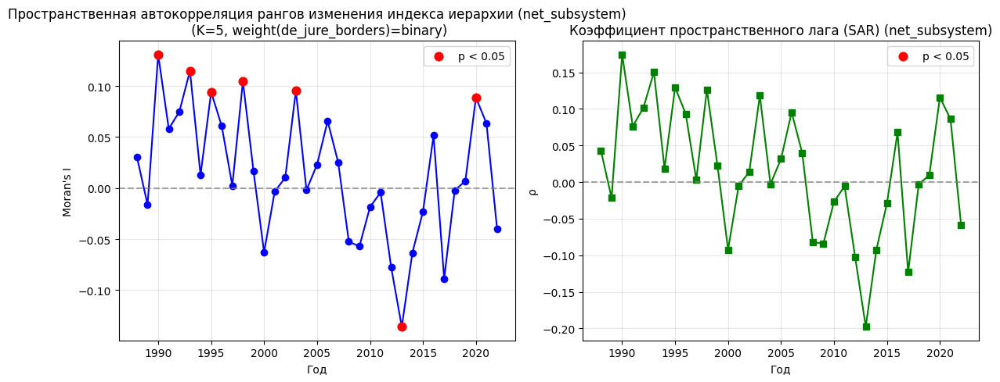

INFO:root:Starting spatial analysis for geodistance with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


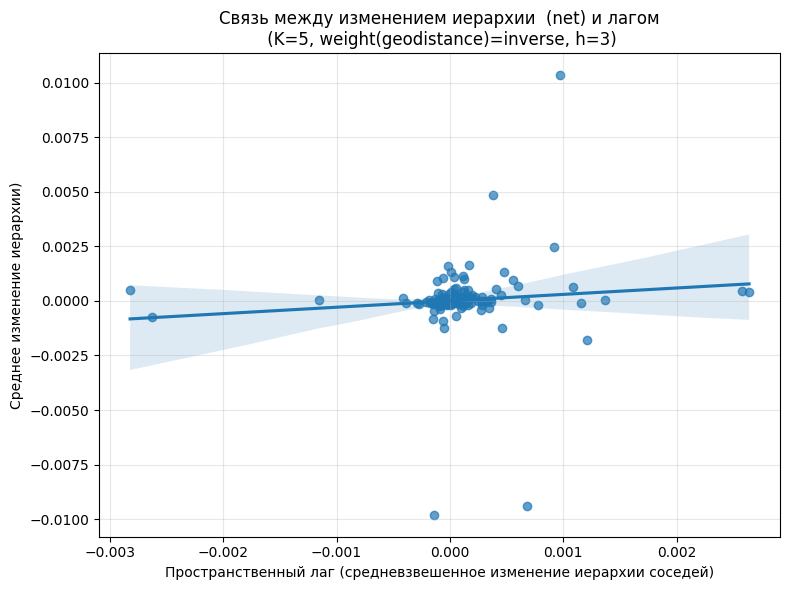

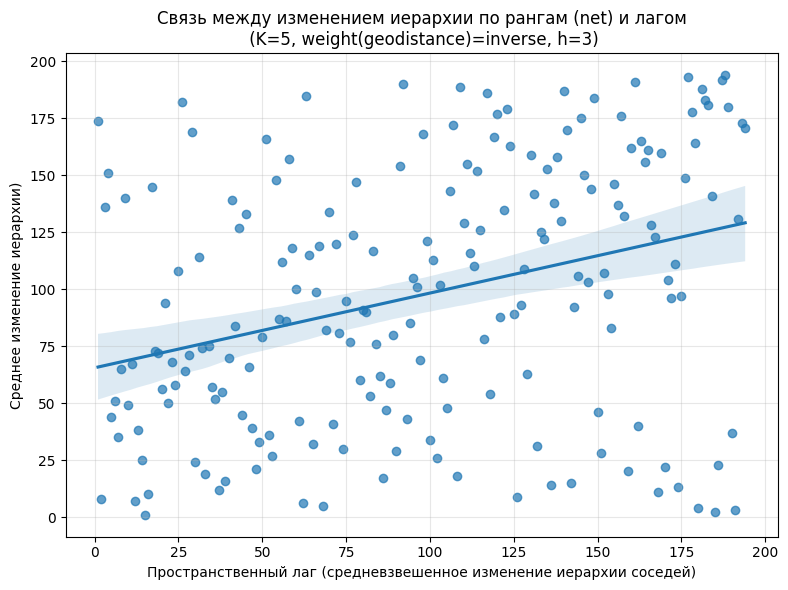

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1026, p-value = 0.1546
INFO:root:Спирмен: r = 0.3281, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.0650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1921
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2335, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    51
tense       47
hostile     47
neutral     47
Name: count, dtype: int64
Мин. размер режима: 47 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      51 -0.000010  0.000259 -0.000823  0.001010
hostile       47 -0.000094  0.002588 -0.009800  0.010350
neutral       47 -0.000049  0.000136 -0.000466  0.000432
tense         47  0.000245  0.000880 -0.001799  0.004872
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0987
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0873
INFO:root:p-value (перестановочный) = 0.0350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0216
INFO:root:p-value (перестановочный) = 0.2570
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0048
INFO:root:p-value (перестановочный) = 0.3730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0228
INFO:root:p-value (перестановочный) = 0.4100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0496
INFO:root:p-value (перестановочный) = 0.1190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0031
INFO:root:p-value (перестановочный) = 0.4470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1582
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0409
INFO:root:p-value (перестановочный) = 0.1700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0063
INFO:root:p-value (перестановочный) = 0.4750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0080
INFO:root:p-value (перестановочный) = 0.4810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0225
INFO:root:p-value (перестановочный) = 0.2660
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0576
INFO:root:p-value (перестановочный) = 0.0950
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (188, 188)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1238
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1429
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1499
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0503
INFO:root:p-value (перестановочный) = 0.1240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1016
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0577
INFO:root:p-value (перестановочный) = 0.1010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0410
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1306
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0146
INFO:root:p-value (перестановочный) = 0.4160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0508
INFO:root:p-value (перестановочный) = 0.1260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0639
INFO:root:p-value (перестановочный) = 0.0840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0957
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1159
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1182
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1027
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0247
INFO:root:p-value (перестановочный) = 0.2370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.1800
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0239
INFO:root:p-value (перестановочный) = 0.2510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0727
INFO:root:p-value (перестановочный) = 0.0530
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0639
INFO:root:p-value (перестановочный) = 0.0650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1279
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1342
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    161  0.098711    0.022  0.214978 0.046142
 1989    161  0.087304    0.035  0.199472 0.067501
 1990    161  0.021602    0.257  0.052854 0.659726
 1991    161  0.004812    0.373  0.012091 0.921490
 1992    161 -0.022792    0.410 -0.060919 0.631367
 1993    165  0.049559    0.119  0.112643 0.325903
 1994    182 -0.003052    0.447 -0.007788 0.946531
 1995    185  0.158207    0.001  0.311770 0.000765
 1996    187  0.040921    0.170  0.098450 0.363464
 1997    188 -0.006320    0.475 -0.015622 0.891835
 1998    188 -0.007996    0.481 -0.020292 0.860105
 1999    188  0.0225

ML_Lag


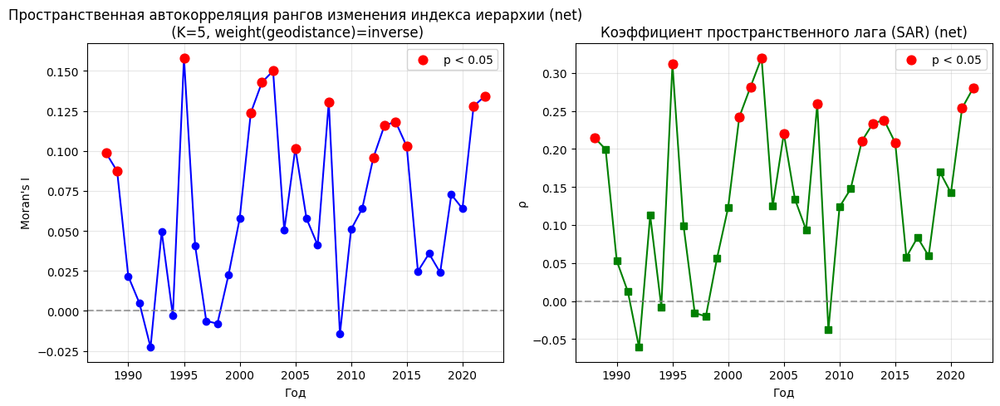

INFO:root:Starting spatial analysis for de_jure_borders with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


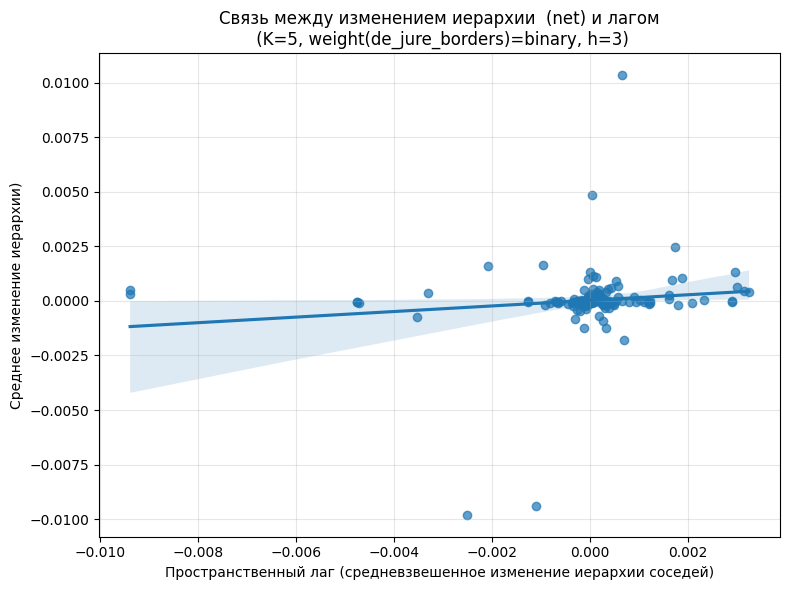

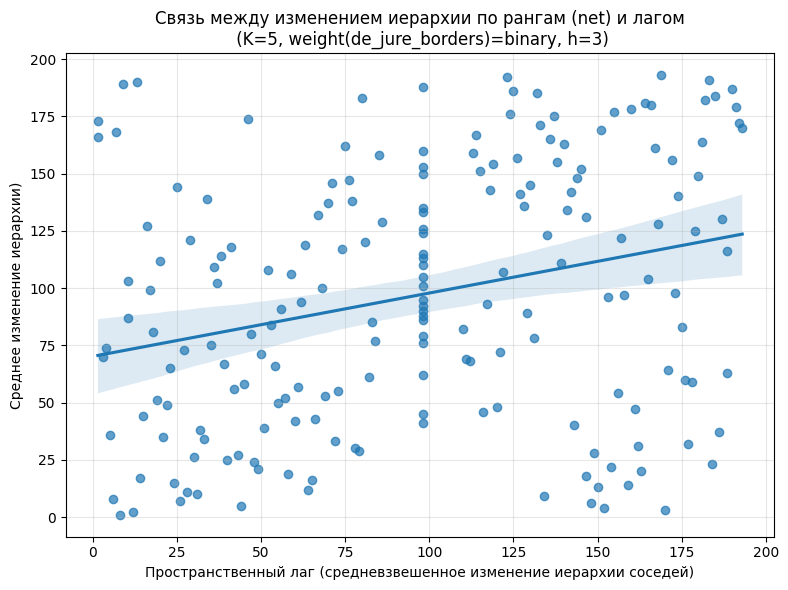

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1344, p-value = 0.0623
INFO:root:Спирмен: r = 0.2764, p-value = 0.0001
INFO:root:=== Moran's I ===
INFO:root:I = 0.1602
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1671
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1714, p = 0.0040
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0726
INFO:root:p-value (перестановочный) = 0.1160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0787
INFO:root:p-value (перестановочный) = 0.0980
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.31, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0465
INFO:root:p-value (перестановочный) = 0.2230
INFO:root:Ожидаемое I при отсутст

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.61, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = 0.2177
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0729
INFO:root:p-value (перестановочный) = 0.0870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (187, 187), средняя степень = 3.65, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0638
INFO:root:p-value (перестановочный) = 0.1760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year i

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.1337
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1539
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag


INFO:root:year is 2004
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1006
INFO:root:p-value (перестановочный) = 0.0490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0842
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0853
INFO:root:p-value (перестановочный) = 0.0600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ зн

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0624
INFO:root:p-value (перестановочный) = 0.1750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0738
INFO:root:p-value (перестановочный) = 0.0830
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0642
INFO:root:p-value (перестановочный) = 0.1110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0949
INFO:root:p-value (перестановочный) = 0.0430


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0258
INFO:root:p-value (перестановочный) = 0.3110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0916
INFO:root:p-value (перестановочный) = 0.0520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0329
INFO:root:p-value (перестановочный) = 0.2410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0215
INFO:root:p-value (перестановочный) = 0.3070
I

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:=== Moran's I ===
INFO:root:I = 0.0150
INFO:root:p-value (перестановочный) = 0.3420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1029
INFO:root:p-value (перестановочный) = 0.0320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    142  0.072575    0.116  0.092216 0.370385
 1989    142  0.078720    0.098  0.095164 0.354865
 1990    142  0.046465    0.223  0.056754 0.585030
 1991    142  0.055221    0.185  0.068555 0.508248
 1992    142  0.033095    0.264  0.039775 0.703078
 1993    146  0.119217    0.028  0.152063 0.129743
 1994    161  0.026742   

ML_Lag
ML_Lag


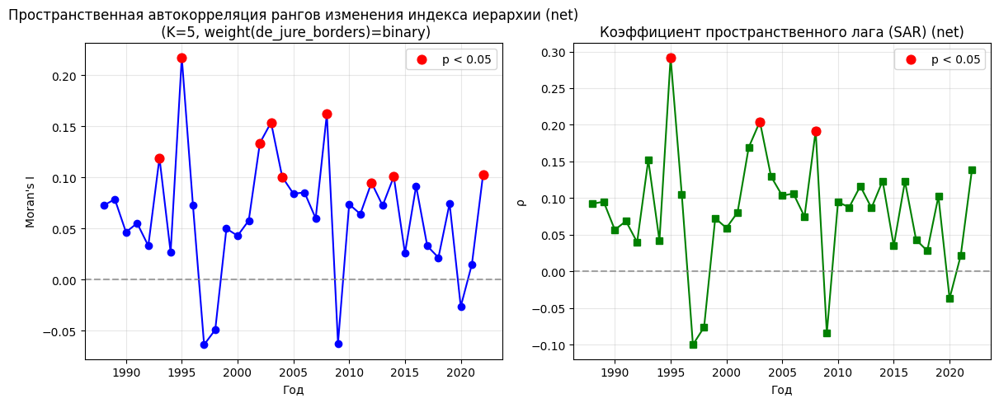

INFO:root:Starting spatial analysis for geodistance with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


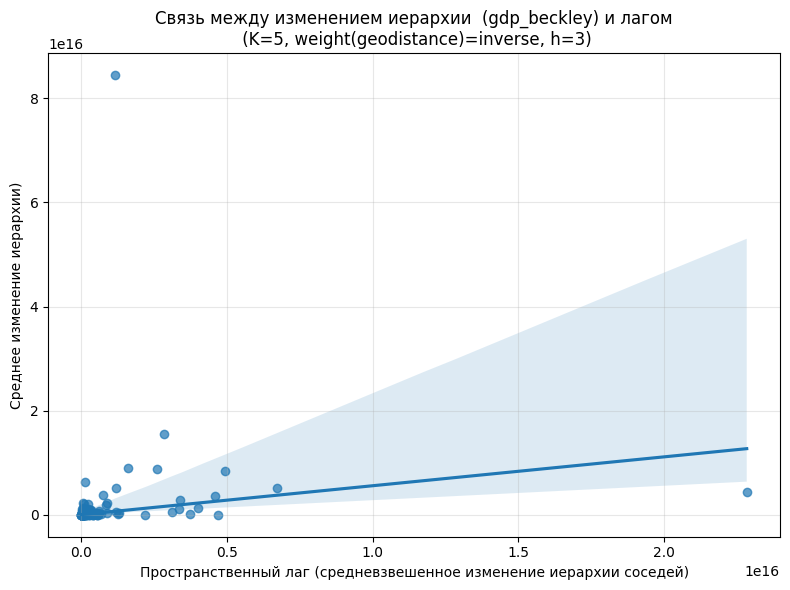

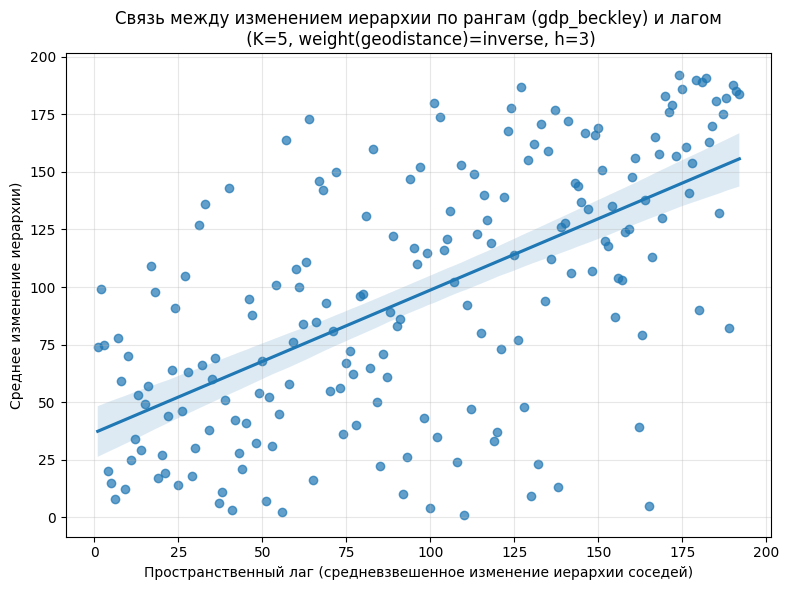

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1373, p-value = 0.0576
INFO:root:Спирмен: r = 0.6201, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0418
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4701
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0472, p = 0.1780
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
Размеры режимов:
friendly    51
neutral     47
tense       46
hostile     46
Name: count, dtype: int64
Мин. размер режима: 46 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count          mean           std           min           max
hostility                                                               
friendly      51  8.745878e+13  3.028767e+14 -6.915501e+11  1.959832e+15
hostile       46  2.863955e+15  1.248580e+16 -2.106965e+13  8.443062e+16
neutral       47  5.225833e+13  1.339254e+14 -1.408589e+11  6.154427e+14
tense         46  1.043493e+15  2.689204e+15 -3.042379e+13  1.541302e+16
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (160, 160)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3850
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3656
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (164, 164)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2795
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (165, 165)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2197
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (166, 166)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1917
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3512
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3676
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3863
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4644
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5171
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5214
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3891
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4427
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4314
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4904
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4650
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4633
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4983
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5454
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5483
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4883
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1381
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2618
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1503
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3904
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3416
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2593
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3126
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3668
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4102
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4356
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4467
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2495
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1887
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (189, 189)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3064
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    160 0.385018    0.001 0.547331 3.248513e-13
 1989    161 0.365607    0.001 0.512983 8.664092e-11
 1990    164 0.279460    0.001 0.446645 1.883942e-07
 1991    165 0.219737    0.001 0.394486 1.435605e-05
 1992    166 0.191711    0.001 0.372777 6.125840e-05
 1993    184 0.351225    0.001 0.531410 1.234568e-13
 1994    184 0.367641    0.001 0.557203 4.440892e-16
 1995    185 0.386276    0.001 0.595388 0.000000e+00
 1996    185 0.464428    0.001 0.649769 0.000000e+00
 1997    186 0.517117    0.001 0.682178 0.000000e+00
 1998    187 0.521400    0.001 0.678249 0.000000e

ML_Lag


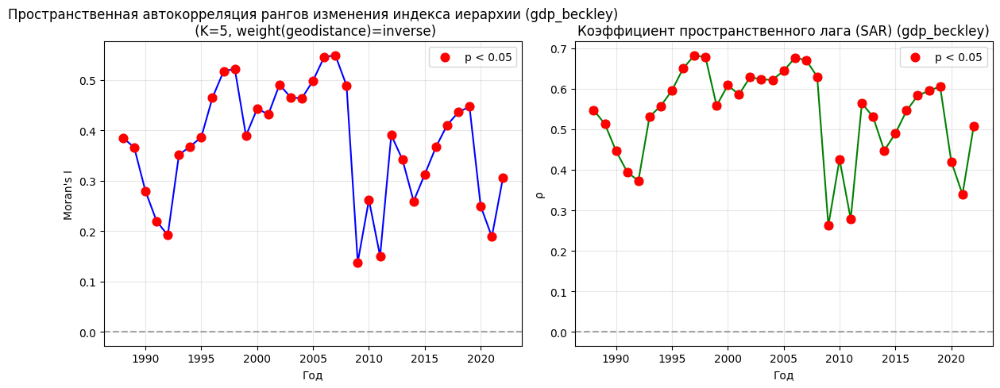

INFO:root:Starting spatial analysis for de_jure_borders with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.64, изолированных вершин = 23
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


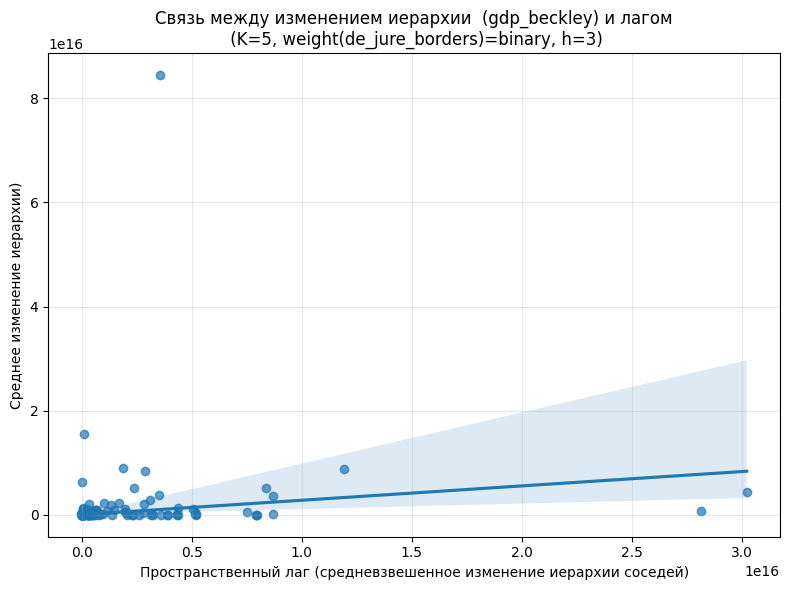

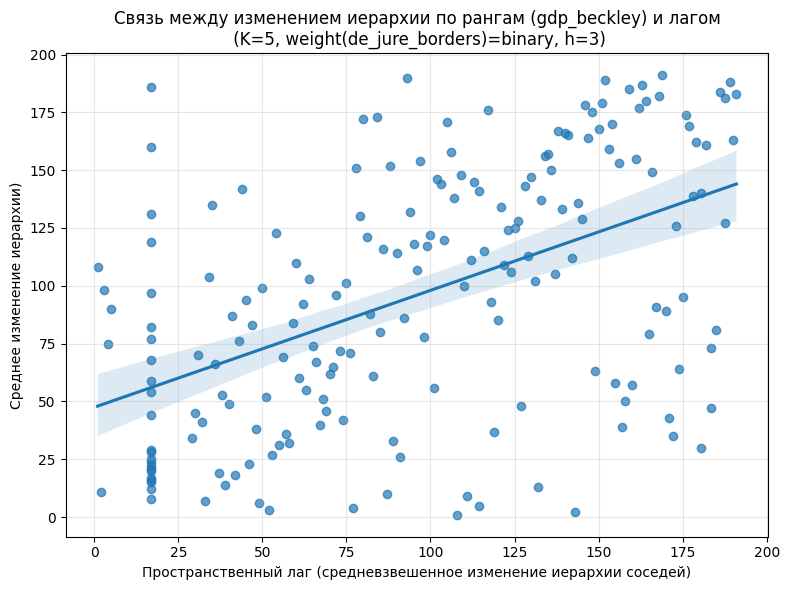

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1169, p-value = 0.1071
INFO:root:Спирмен: r = 0.5051, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0723
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3840
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0274, p = 0.2050
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 3.05, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3892
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0074
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 3.06, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3341
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0073
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 3.06, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3808
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3657
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.44, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3611
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4379
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3745
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.51, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3802
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2007
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4677
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.4047
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.57, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1860
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2013
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3213
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1946
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0809
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2019
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.3723
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2382
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (188, 188), средняя степень = 3.55, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1537
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


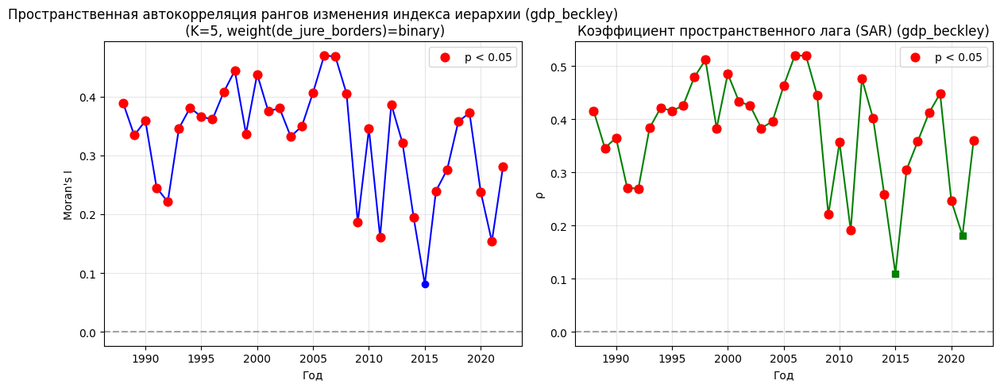

INFO:root:Starting spatial analysis for geodistance with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 186


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)


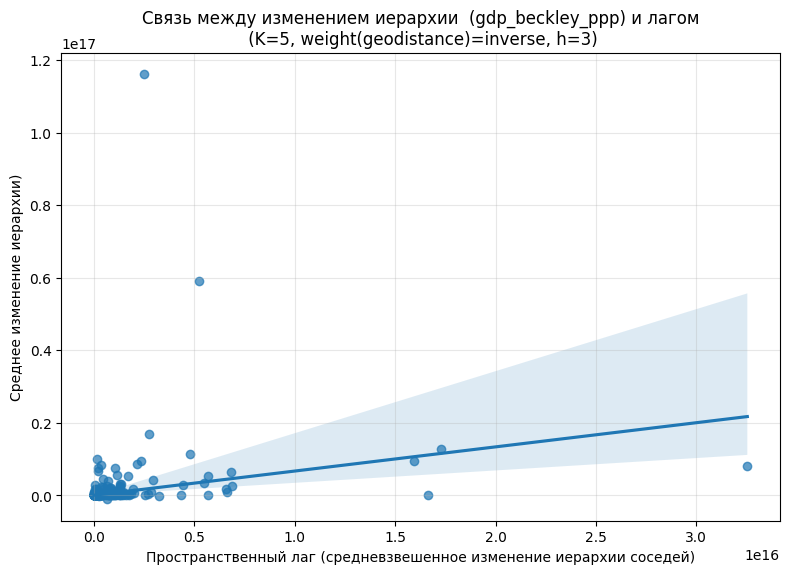

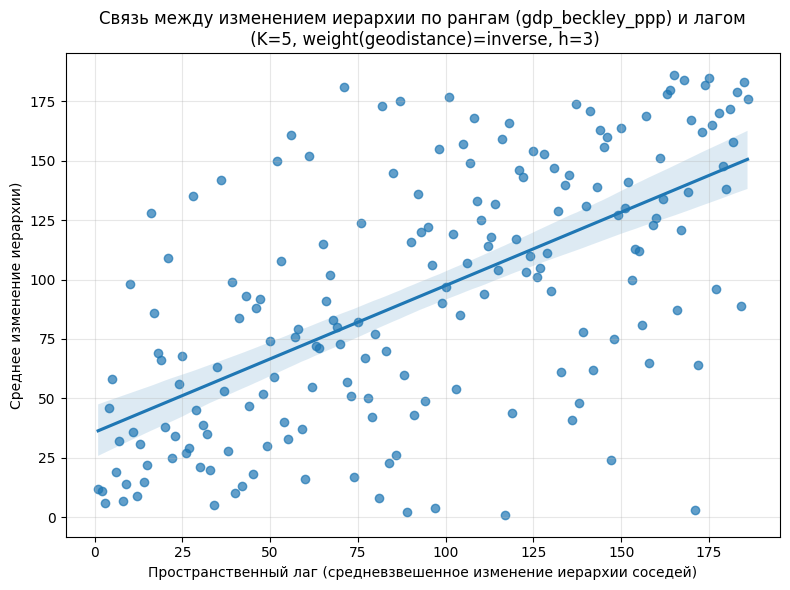

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1792, p-value = 0.0144
INFO:root:Спирмен: r = 0.6178, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0615
INFO:root:p-value (перестановочный) = 0.0290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4600
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0354, p = 0.1840
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
Размеры режимов:
friendly    51
neutral     46
tense       45
hostile     43
Name: count, dtype: int64
Мин. размер режима: 43 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count          mean           std           min           max
hostility                                                               
friendly      51  6.082991e+14  1.749981e+15  2.018799e+10  8.546000e+15
hostile       43  4.800350e+15  1.774744e+16 -7.847308e+13  1.161817e+17
neutral       46  4.484195e+14  1.530334e+15  2.111566e+11  9.908597e+15
tense         45  2.995754e+15  9.041390e+15 -1.162947e+15  5.918847e+16
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (179, 179)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3747
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994
INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3926
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3950
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица весов построена (K=5, inverse): (180, 180)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4448
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4960
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4920
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3687
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4203
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4186
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица весов построена (K=5, inverse): (184, 184)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4897
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4378
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4505
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4777
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5385
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.5388
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4815
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag


INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1796
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag


INFO:root:year is 2010
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2800
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1648
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3821
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3368
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2429
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3123
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3505
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.3923
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4214
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.4460
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2443
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1710
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022
INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.2761
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1993    179 0.374669    0.001 0.547506 8.881784e-15
 1994    180 0.392633    0.001 0.580771 0.000000e+00
 1995    180 0.394967    0.001 0.605542 0.000000e+00
 1996    180 0.444787    0.001 0.630040 0.000000e+00
 1997    181 0.495998  

ML_Lag
ML_Lag


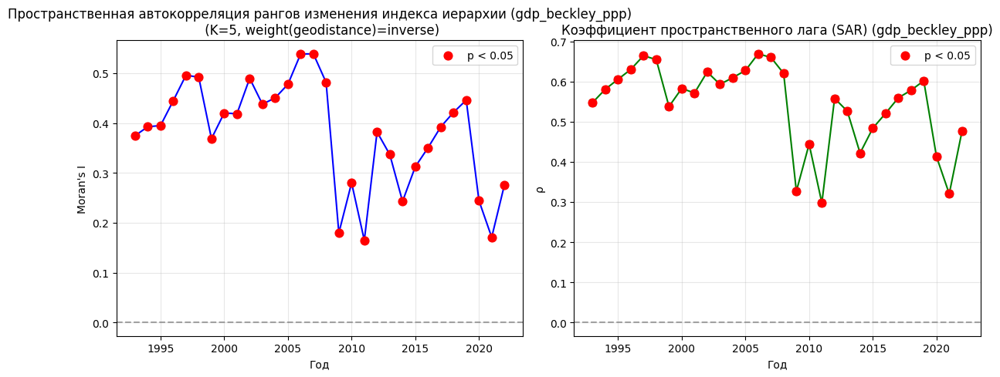

INFO:root:Starting spatial analysis for de_jure_borders with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 185
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24


(3,) None


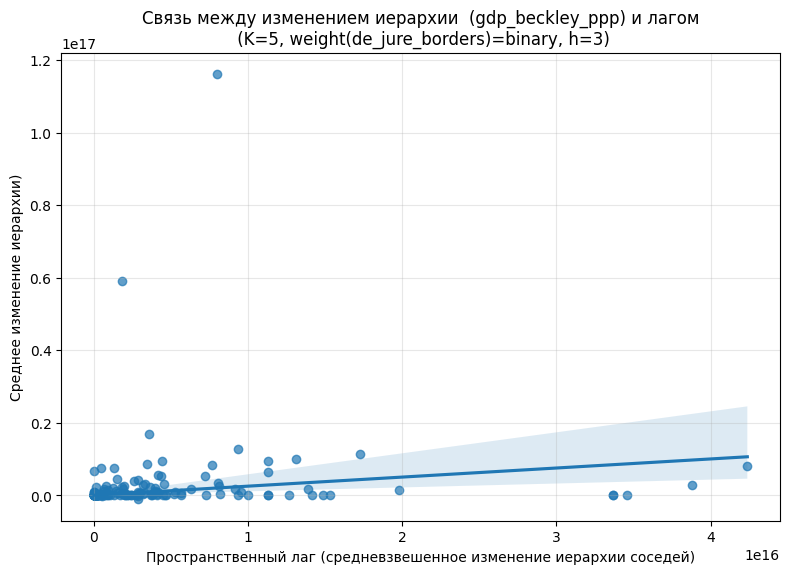

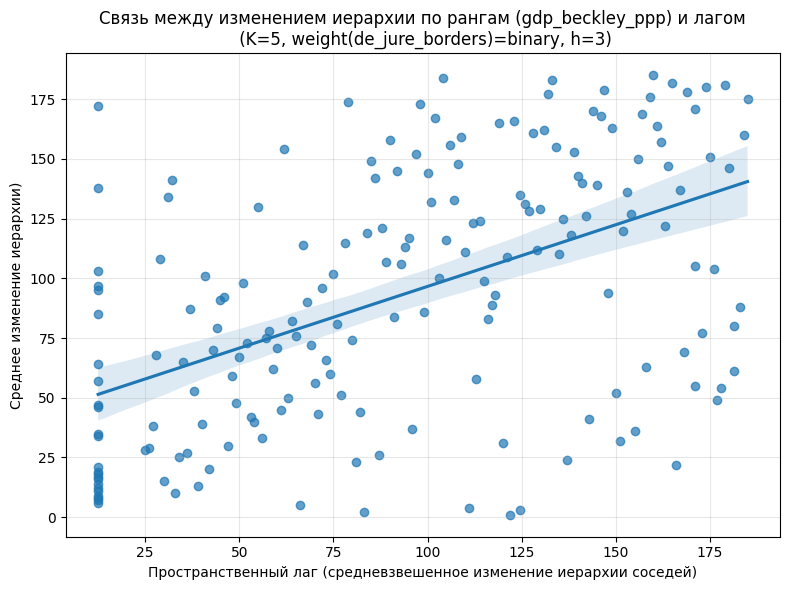

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1055, p-value = 0.1531
INFO:root:Спирмен: r = 0.5161, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0775
INFO:root:p-value (перестановочный) = 0.0190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3683
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0305, p = 0.3630
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 185
INFO:root:year is 1990
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 3.40, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3378
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.40, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3739
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.40, изолиро

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3212
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 3.48, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.4013
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 3.48, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3586
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2006
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.4347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.4341
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3742
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2012
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3597
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3089
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 3.53, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.1856
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2414
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3415
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.54, изолированных вершин = 24
INFO:root:=== Moran's I ===
INFO:root:I = 0.3638
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1993    155 0.337840    0.001 0.376997 1.224835e-05
 1994    156 0.373889    0.001 0.406667 1.222339e-06
 1995    156 0.378732    0.001 0.428798 1.830732e-07
 1996    156 0.351334    0.001 0.420461 3.842835e-07
 1997    156 0.364883    0.001 0.431261 1.461118e-07
 1998    157 0.387243    0.001 0.452459 2.204149e-08
 1999    157 0.321221    0.001 0.370380 1.970964e-05
 2000    159 0.401283    0.001 0.452638 1.798507e-08
 2001    159 0.358623    0.001 0.419707 4.073221e-07
 2002    159 0.381651    0.001 0.424244 2.736358e-07
 2003    160 0.306566    0.001 0.357138 4.313989e-05
 2004    160 0.321012    0.001 0.367677 2.197167e-05
 2005    160 0.358148    0.001 0.406156 1.337157e-06
 2006    160 0.434729    0.001 0.476489 1.406373e-09
 2007    160 0.434071    0.001 0.474835 1.706552e-09
 2008    160 0.374168    0.001 0.416976 5.470552e-07
 2009    160 0.222401    0.001 0.256437 5.883609e-03
 2010    160 0.368871    0.001 0.374

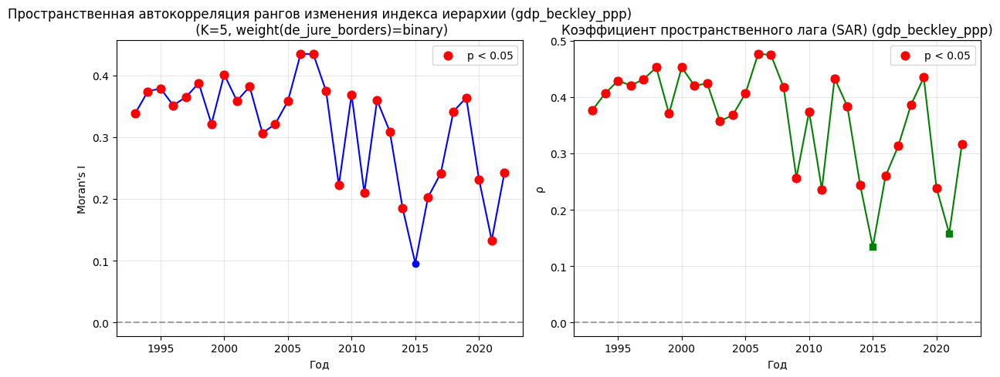

INFO:root:Starting spatial analysis for geodistance with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 194


(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)


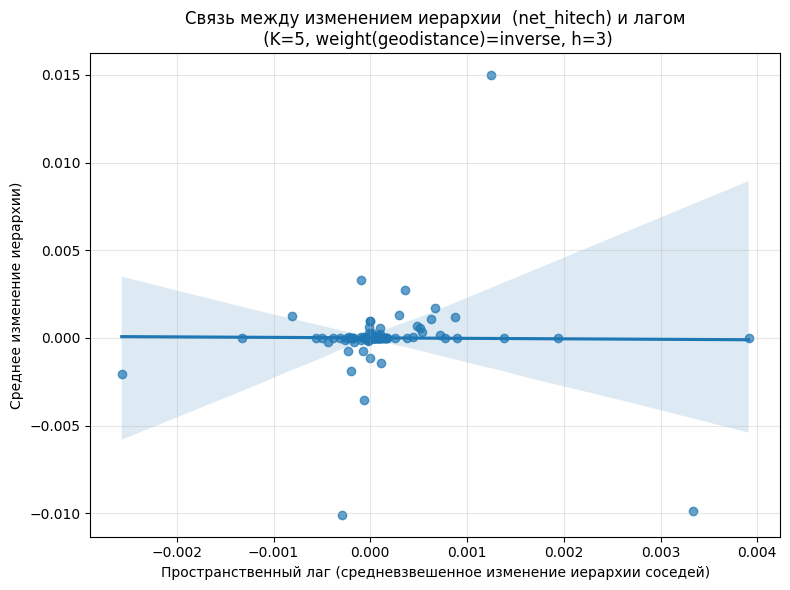

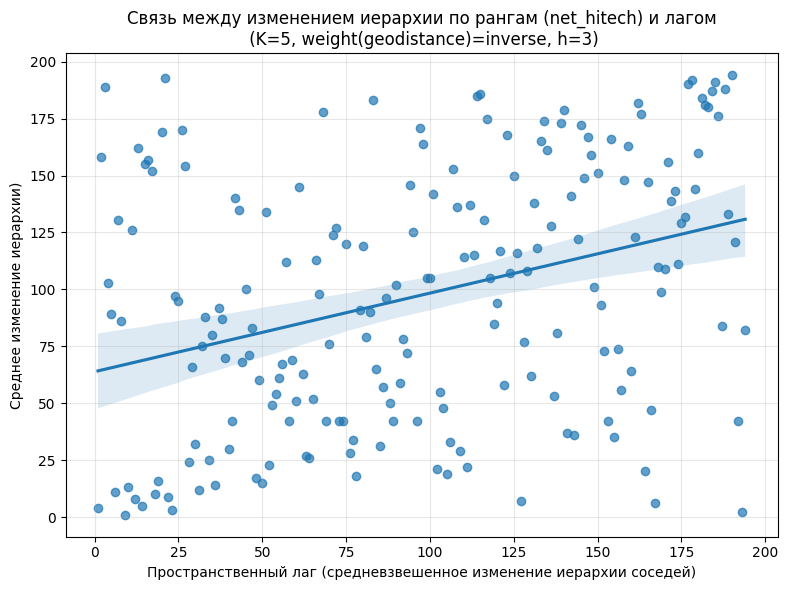

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0087, p-value = 0.9037
INFO:root:Спирмен: r = 0.3451, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.0028
INFO:root:p-value (перестановочный) = 0.4960
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2369
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2696, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
Размеры режимов:
friendly    51
tense       47
hostile     47
neutral     47
Name: count, dtype: int64
Мин. размер режима: 47 | Число столбцов X ≈ 5
ML_Lag_Regimes
ML_Error_Regimes
           count      mean       std       min       max
hostility                                               
friendly      51  0.000074  0.000308 -0.000201  0.001701
hostile       47 -0.000298  0.001701 -0.010081  0.002739
neutral       47  0.000016  0.000146 -0.000107  0.000944
tense         47  0.000212  0.002689 -0.009841  0.014969
(3,) None


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0797
INFO:root:p-value (перестановочный) = 0.0500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0260
INFO:root:p-value (перестановочный) = 0.2350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0885
INFO:root:p-value (перестановочный) = 0.0390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1446
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (158, 158)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0229
INFO:root:p-value (перестановочный) = 0.2910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1993
INFO:root:Матрица весов построена (K=5, inverse): (161, 161)
INFO:root:=== Moran's I ===
INFO:root:I = -0.0172
INFO:root:p-value (перестановочный) = 0.4260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1994


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (178, 178)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0881
INFO:root:p-value (перестановочный) = 0.0290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0170
INFO:root:p-value (перестановочный) = 0.3040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0267
INFO:root:p-value (перестановочный) = 0.2330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0775
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1564
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0927
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0163
INFO:root:p-value (перестановочный) = 0.3120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица весов построена (K=5, inverse): (187, 187)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0262
INFO:root:p-value (перестановочный) = 0.2500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (190, 190)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0661
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0770
INFO:root:p-value (перестановочный) = 0.0510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0960
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0650
INFO:root:p-value (перестановочный) = 0.0720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0572
INFO:root:p-value (перестановочный) = 0.0990
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0227
INFO:root:p-value (перестановочный) = 0.2690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1257
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1237
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0911
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0641
INFO:root:p-value (перестановочный) = 0.0680
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0609
INFO:root:p-value (перестановочный) = 0.0780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0621
INFO:root:p-value (перестановочный) = 0.0750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0596
INFO:root:p-value (перестановочный) = 0.0860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0462
INFO:root:p-value (перестановочный) = 0.1340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1554
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.1405
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0873
INFO:root:p-value (перестановочный) = 0.0150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0861
INFO:root:p-value (перестановочный) = 0.0330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0083
INFO:root:p-value (перестановочный) = 0.3690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0076
INFO:root:p-value (перестановочный) = 0.3540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022


ML_Lag
ML_Lag


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0662
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    158  0.079738    0.050  0.172837 0.123768
 1989    158  0.025991    0.235  0.057321 0.635225
 1990    158  0.088522    0.039  0.182469 0.101787
 1991    158  0.144630    0.004  0.279846 0.006626
 1992    158  0.022910    0.291  0.064942 0.589356
 1993    161 -0.017157    0.426 -0.051573 0.682902
 1994    178  0.088100    0.029  0.205695 0.045707
 1995    181  0.017015    0.304  0.041383 0.715798
 1996    186  0.026698    0.233  0.067363 0.542373
 1997    187  0.077492    0.044  0.168734 0.103039
 1998    187  0.156420    0.004  0.313112 0.000666
 1999    187  0.092723    0.024  0.205267 0.041691
 2000    187  0.016265    0.312  0.041012 

ML_Lag


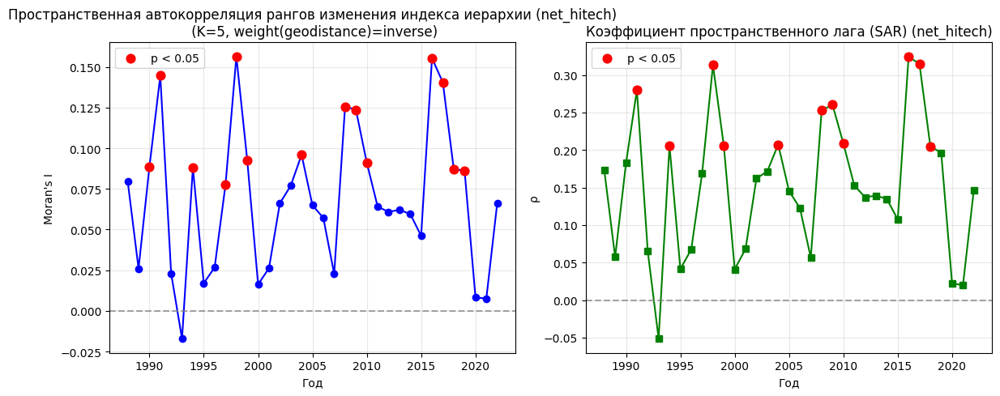

INFO:root:Starting spatial analysis for de_jure_borders with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23


(3,) None


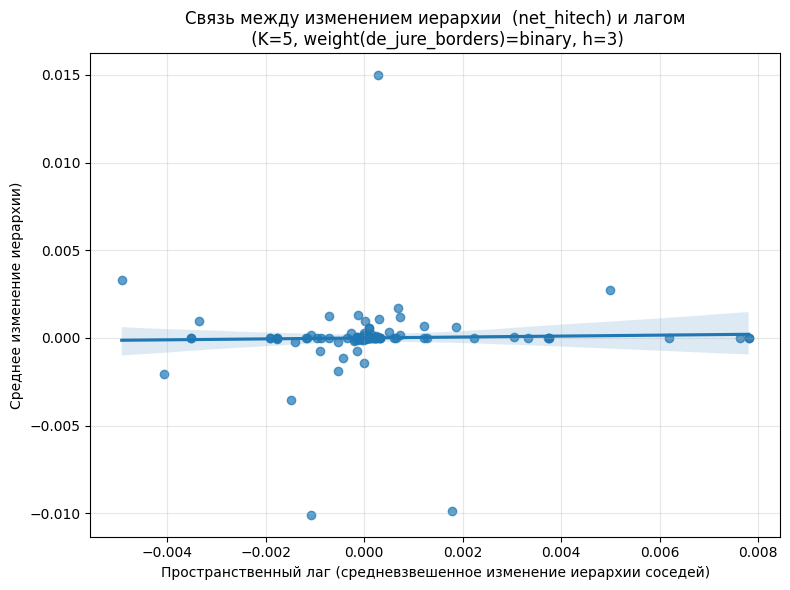

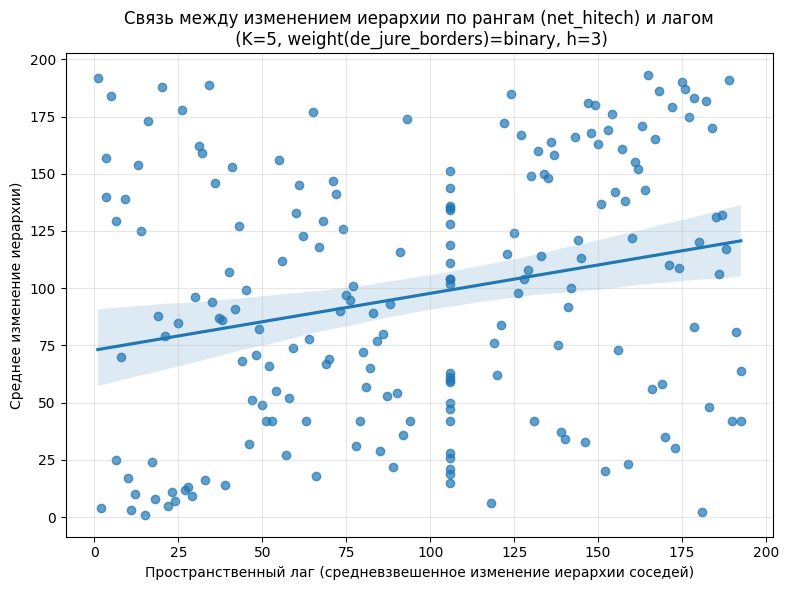

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0253, p-value = 0.7272
INFO:root:Спирмен: r = 0.2479, p-value = 0.0005
INFO:root:=== Moran's I ===
INFO:root:I = 0.0272
INFO:root:p-value (перестановочный) = 0.1190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2297
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2625, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Iceland', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Micronesia (Federated States of)', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no ne

INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0505
INFO:root:p-value (перестановочный) = 0.2000
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.1122
INFO:root:p-value (перестановочный) = 0.0580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 3.34, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.0822
INFO:root:p-value (перестановочный) = 0.1170
INFO:root:Ожидаемое I при отсут

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (180, 180), средняя степень = 3.60, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.3300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (185, 185), средняя степень = 3.69, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.0429
INFO:root:p-value (перестановочный) = 0.1980
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (186, 186), средняя степень = 3.67, изолированных вершин = 19
INFO:root:=== Moran's I ===
INFO:root:I = 0.0833
INFO:root:p-value (перестановочный) = 0.0700
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (186, 186), средняя степень 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2002
INFO:root:Матрица смежности построена: (189, 189), средняя степень = 3.61, изолированных вершин = 22
INFO:root:=== Moran's I ===
INFO:root:I = 0.0714
INFO:root:p-value (перестановочный) = 0.0920
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0392
INFO:root:p-value (перестановочный) = 0.1990
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (190, 190), средняя степень = 3.59, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0986
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иера

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (191, 191), средняя степень = 3.58, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.2029
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1633
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (192, 192), средняя степень = 3.60, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1443
INFO:root:p-value (перестан

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0868
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1463
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.1480
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (193, 193),

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0310
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0947
INFO:root:p-value (перестановочный) = 0.0470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.65, изолированных вершин = 23
INFO:root:=== Moran's I ===
INFO:root:I = 0.0732
INFO:root:p-value (перестановочный) = 0.0900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0059
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (193, 193), средняя степень = 3.

ML_Lag
ML_Lag
ML_Lag
ML_Lag


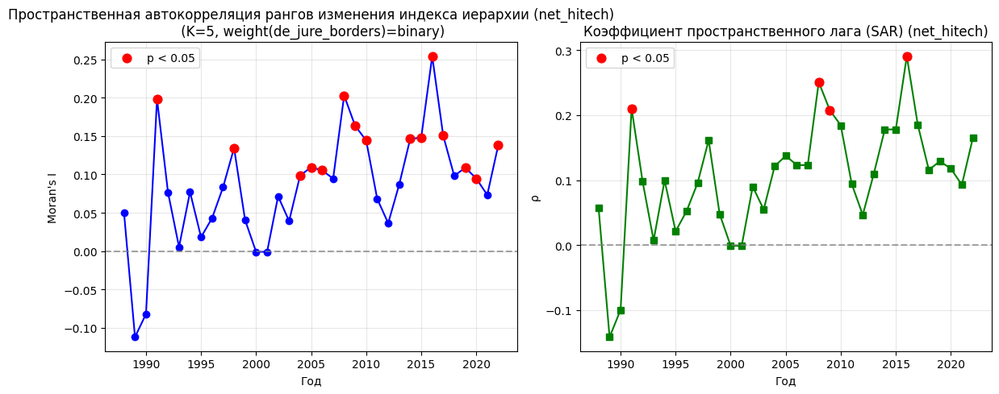

In [1234]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['geodistance','de_jure_borders']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            regime_by='hostility',
            ipd_df=predictor_dfs['ipd'],
            hostility_use_w=False,           # все партнёры IPD
            hostility_year=2010,
            hostility_agg='mean',
            hostility_thresholds=(0.71, 0.84, 1.14),
            include_regimes=True)

        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [25]:
def print_spatial_results(results, predictor_1, predictor_2):
    for power in results:
        moran_i = round(results[power][predictor_1]['moran_ranked'].I, 3)
        moran_p = results[power][predictor_1]['moran_ranked'].p_sim
        print(f"{power} Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_1})")
        moran_i = round(results[power][predictor_1]['moran_bin'].I, 3)
        moran_p = results[power][predictor_1]['moran_bin'].p_sim
        print(f"{power} binary Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_1})")
        moran_i = round(results[power][predictor_2]['moran_ranked'].I, 3)
        moran_p = results[power][predictor_2]['moran_ranked'].p_sim
        print(f"{power} Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_2})")
        moran_i = round(results[power][predictor_2]['moran_bin'].I, 3)
        moran_p = results[power][predictor_2]['moran_bin'].p_sim
        print(f"{power} binary Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_2})")
    print("===========================================")
    print("============SPATIAL REGRESSION=============")
    for power in results:
        print(results[power][predictor_1]['sar_model'][0].summary)
        print(results[power][predictor_2]['sar_model'][0].summary)
    print("===========================================")
    print("==============SPATIAL REGIMES===============")
    for power in results:
        print(results[power][predictor_1]['sar_regimes_model'][0].summary)
        print(results[power][predictor_2]['sar_regimes_model'][0].summary)

In [ ]:
print_spatial_results(results, 'geodistance','de_jure_borders')

In [ ]:
for power in results:
    print(results[power]['geodistance']['sar_model'][0].summary)
    print(results[power]['de_jure_borders']['sar_model'][0].summary)

In [906]:
for power in results:
    print(results[power]['geodistance']['sar_regimes_model'][0].summary)
    print(results[power]['de_jure_borders']['sar_regimes_model'][0].summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG - REGIMES (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      : geodistance
Dependent Variable  :      athlas                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :           9
S.D. dependent var  :     55.8585                Degrees of Freedom    :         184
Pseudo R-squared    :      0.7266
Spatial Pseudo R-squared:  0.7231
Log likelihood      :   -925.1820
Sigma-square ML     :    848.7127                Akaike info criterion :    1868.364
S.E of regression   :     29.1327                Schwarz criterion     :    1897.728

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------------

In [24]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter[0]}..{years_filter[-1]} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['geodistance', 'de_jure_borders']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

INFO:root:Фильтр по годам: 1985..2013 (n=26)
INFO:root:Starting Moran for geodistance / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0302
INFO:root:p-value (перестановочный) = 0.1150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0233
INFO:root:p-value (перестановочный) = 0.2520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[athlas/geodistance] Moran (binary): I = 0.00

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0237
INFO:root:p-value (перестановочный) = 0.2010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0596
INFO:root:p-value (перестановочный) = 0.0810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[gpi/geodistance] Moran (binary): I = 0.0676, p_sim = 0.0610
INFO:root:Starting Moran for de_jure_borders / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица смежности 

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Trinidad and Tobago', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Samoa', ' is an island (no neighbors)')
('WARNING: ', 'Tonga', ' is an island (no neighbors)')
('WARNING: ', 'Jamaica', ' is an island (no neighbors)

INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0222
INFO:root:p-value (перестановочный) = 0.1140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4128
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/geodistance] Moran (binary): I = 0.2854, p_sim = 0.0010
INFO:root:Starting Moran for de_jure_borders / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Ст

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0629
INFO:root:p-value (перестановочный) = 0.0330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3577
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/geodistance] Moran (binary): I = -0.0212, p_sim = 0.4560
INFO:root:Starting Moran for de_

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0337
INFO:root:p-value (перестановочный) = 0.2300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1067
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_subsystem/geodistance] Moran (binary): I = 0.2326, p_sim = 0.0010
INFO:root:Starting Moran for de_jure_borders / net_subsystem
INFO:root:Размер таблицы дельт: (1

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0741
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1476
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/geodistance] Moran (binary): I = 0.2155, p_sim = 0.0010
INFO:root:Starting Moran for de_j

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0446
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.5299
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/geodistance] Moran (binary): I = -0.0430, p_sim = 0.1960
INFO:root:Starting Moran

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0672
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.5319
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/geodistance] Moran (binary): I = 0.1826, p_sim = 0.0030
INFO:root:Starting Mo

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Trinidad and Tobago', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no nei

INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0123
INFO:root:p-value (перестановочный) = 0.1770
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1527
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_hitech/geodistance] Moran (binary): I = 0.1122, p_sim = 0.0060
INFO:root:Starting Moran for de_jure_borders / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)


('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (191, 191)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0786
INFO:root:p-value (перестановочный) = 0.0390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3807
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_nominal/geodistance] Moran (binary): I = -0.0212, p_sim = 0.4100
INFO:root:Starting Moran

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
(

INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0546
INFO:root:p-value (перестановочный) = 0.0590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3749
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_ppp/geodistance] Moran (binary): I = 0.1826, p_sim = 0.0070
INFO:root:Starting Moran for de_jure_borders / gdp_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:r

('WARNING: ', 'Comoros', ' is an island (no neighbors)')
('WARNING: ', 'Cabo Verde', ' is an island (no neighbors)')
('WARNING: ', 'Sao Tome and Principe', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Fiji', ' is an island (no neighbors)')
('WARNING: ', 'Malta', ' is an island (no neighbors)')
('WARNING: ', 'New Zealand', ' is an island (no neighbors)')
('WARNING: ', 'Trinidad and Tobago', ' is an island (no neighbors)')
('WARNING: ', 'Vanuatu', ' is an island (no neighbors)')
('WARNING: ', 'Marshall Islands', ' is an island (no neighbors)')
('WARNING: ', 'Mauritius', ' is an island (no neighbors)')
('WARNING: ', 'Madagascar', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Nauru', ' is an island (no neighbors)')
('WARNING: ', 'Maldives', ' is an island (no neighbors)')
('WARNING: ', 'Palau', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no nei

In [23]:
# --- Русские названия индексов иерархии ---
POWER_LABELS = {
    'athlas':              'Индекс национальной мощи',
    'gpi':                 'Глобальный индекс власти',
    'cinc':                'Индекс CINC',
    'gdp':                 'ВВП (номинал)',
    'net':                 'Системно-сетевой индекс',
    'gdp_beckley':         'Индекс Бэкли',
    'gdp_beckley_ppp':     'Индекс Бэкли (ППС)',
}

# --- Звёздочки значимости ---
def _stars(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return 'ns'
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    if p < 0.10:  return '†'
    return 'ns'

def _fmt(I, p, decimals=3):
    """Форматирует I с звёздочками и запятой как десятичным разделителем."""
    if I is None or (isinstance(I, float) and np.isnan(I)):
        return '—'
    s = f"{I:.{decimals}f}".replace('.', ',')
    return f"{s}{_stars(p)}"

In [22]:
def build_moran_table(results, decimals=3):
    """
    Строит сводную таблицу Moran's I по всем индексам и предикторам.

    Параметры
    ---------
    results : dict
        Словарь вида results[power][predictor] = {
            'moran':        {'I': ..., 'p_sim': ...},
            'moran_binary': {'I': ..., 'p_sim': ...},
            ...
        }
    decimals : int
        Число знаков после запятой.

    Возвращает
    ----------
    pd.DataFrame
        Таблица с русскими названиями индексов и колонками по предикторам.
    """
    rows = []
    for power, by_pred in results.items():
        if power not in POWER_LABELS:
            continue
        row = {'Индекс положения в иерархии': POWER_LABELS[power]}

        for predictor, label in [
            ('geodistance',    'расстояния по популяционным центрам'),
            ('de_jure_borders', 'соседства по юридическим границам'),
            ('atop','членство в военных альянсах'),
            ('atop_nato','членство в НАТО'),
            ('rta','членство в региональных торговых соглашениях'),
            ('rta_eia','членство в региональных торговых соглашениях уровня ТС/эк.союза')
        ]:
            if predictor not in by_pred:
                row[f'I|{predictor}']       = np.nan
                row[f'Ibin|{predictor}']    = np.nan#'—'
                continue
            
            m    = by_pred[predictor].get('moran')        or {}
            mbin = by_pred[predictor].get('moran_binary') or {}

            row[f'I|{predictor}']    = _fmt(m.get('I'),    m.get('p_sim'),    decimals)
            row[f'Ibin|{predictor}'] = _fmt(mbin.get('I'), mbin.get('p_sim'), decimals)

        rows.append(row)

    df = pd.DataFrame(rows).set_index('Индекс положения в иерархии')

    # Переупорядочиваем колонки в нужном порядке
    df = df[[
        'I|geodistance',    'Ibin|geodistance',
        'I|de_jure_borders', 'Ibin|de_jure_borders',
        'I|atop', 'Ibin|atop',
        'I|atop_nato','Ibin|atop_nato',
        'I|rta', 'Ibin|rta',
        'I|rta_eia', 'Ibin|rta_eia'
    ]]
    df.columns = [
        'I Морана для расстояния по популяционным центрам',
        'Бинарный I Морана (по знаку) для расстояния по популяционным центрам',
        'I Морана для соседства по юридическим границам',
        'Бинарный I Морана (по знаку) для соседства по юридическим границам',
        'I Морана для псевдососедства по военным альянсам',
        'Бинарный I Морана (по знаку) для псевдососедства по военным альянсам',
        'I Морана для псевдососедства по НАТО',
        'Бинарный I Морана (по знаку) для псевдососедства по НАТО',
        'I Морана для псевдососедства по рег.торговым соглашениям',
        'Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям',
        'I Морана для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза',
        'Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза',
    ]
    return df.dropna(axis=1)

In [896]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_stableyears.csv')

#### Гипотезы №3.1, №3.3

INFO:root:Starting spatial analysis for atop with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17


(3,) None
                                     delta       lag
country_a                                           
Afghanistan                       0.001384  0.000000
Albania                          -0.000497 -0.018136
Algeria                           0.005680  0.003813
Andorra                           0.000010  0.000000
Angola                            0.011403  0.002650
Antigua and Barbuda              -0.000019 -0.006380
Argentina                         0.009503 -0.006677
Armenia                          -0.000104 -0.017714
Australia                        -0.002278 -0.142985
Austria                          -0.016895 -0.007155
Azerbaijan                        0.007296 -0.015844
Bahamas                          -0.000151 -0.006375
Bahrain                           0.006147  0.002837
Bangladesh                        0.009360  0.000000
Barbados                         -0.000105 -0.006377
Belarus                           0.000811 -0.017828
Belgium                          -0.

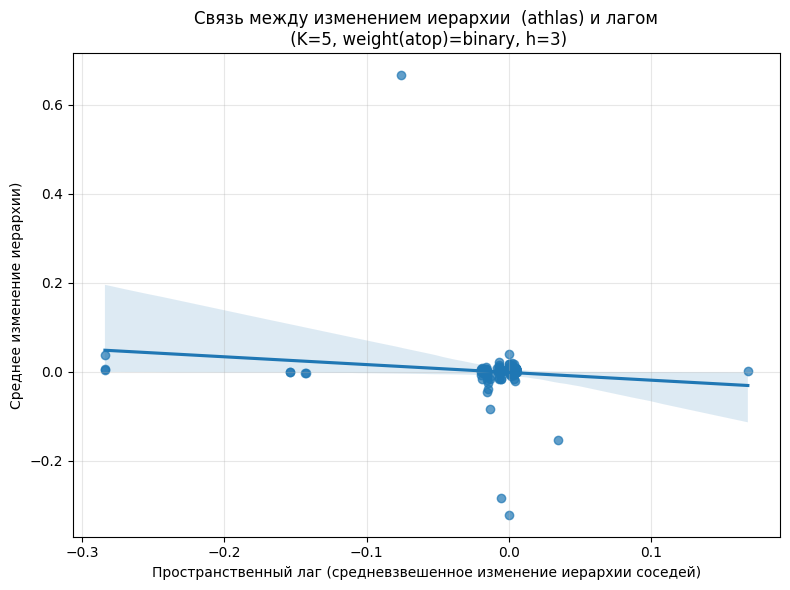

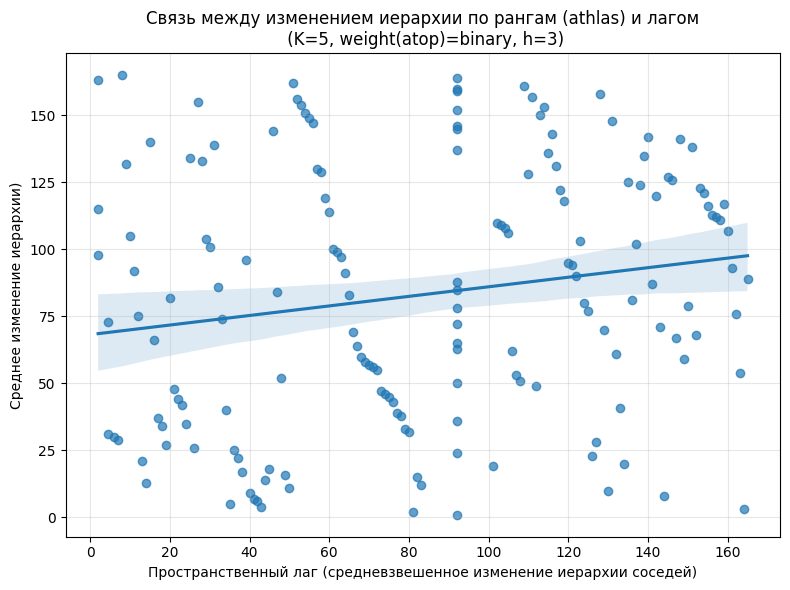

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.1272, p-value = 0.1036
INFO:root:Спирмен: r = 0.1783, p-value = 0.0220
INFO:root:=== Moran's I ===
INFO:root:I = -0.1031
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1010
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1189, p = 0.0030
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM 

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:year is 1994
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 20.58, изолированных вершин = 20
INFO:root:=== Moran's I ===
INFO:root:I = -0.0385
INFO:root:p-value (перестановочный) = 0.1640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0595
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0076
INFO:root:p-value (перестановочный

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0313
INFO:root:p-value (перестановочный) = 0.2190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0517
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0053
INFO:root:p-value (перестановочный) = 0.3400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0420
INFO:root:p-value (перестановочный) = 0.0

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0607
INFO:root:p-value (перестановочный) = 0.0260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0860
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0833
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0331
INFO:root:p-value (перестановочный) = 0.1000
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0925
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0272
INFO:root:p-value (перестановочный) = 0.1230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0930
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0952
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1995    144 -0.038500    0.164 -0.213320 0.335675
 1996    148 -0.059549    0.045 -0.332975 0.142164
 1997    148 -0.007564    0.492 -0.026197 0.900044
 1998    148  0.130849    0.001  0.429578 0.003960
 1999    148  0.144633    0.002  0.457654 0.001494
 2000    148  0.077259    0.00

ML_Lag
ML_Lag


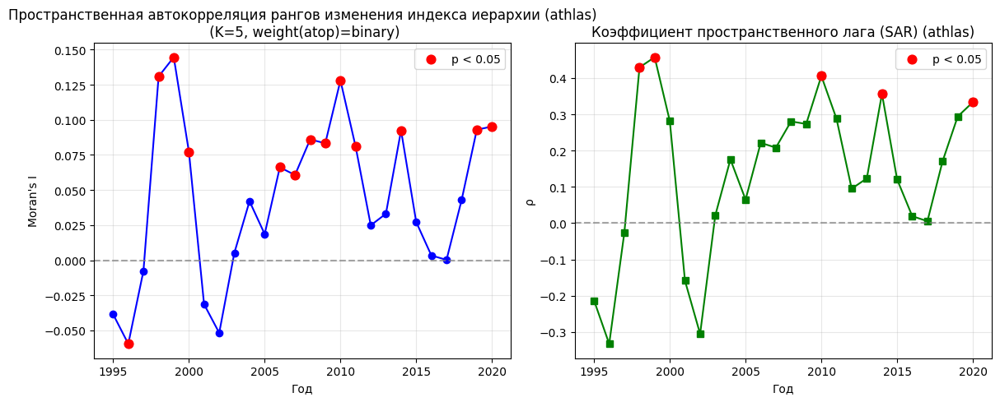

INFO:root:Starting spatial analysis for atop_nato with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136


(3,) None
                                     delta       lag
country_a                                           
Afghanistan                       0.001384  0.000000
Albania                          -0.000497 -0.018136
Algeria                           0.005680  0.000000
Andorra                           0.000010  0.000000
Angola                            0.011403  0.000000
Antigua and Barbuda              -0.000019  0.000000
Argentina                         0.009503  0.000000
Armenia                          -0.000104  0.000000
Australia                        -0.002278  0.000000
Austria                          -0.016895  0.000000
Azerbaijan                        0.007296  0.000000
Bahamas                          -0.000151  0.000000
Bahrain                           0.006147  0.000000
Bangladesh                        0.009360  0.000000
Barbados                         -0.000105  0.000000
Belarus                           0.000811  0.000000
Belgium                          -0.

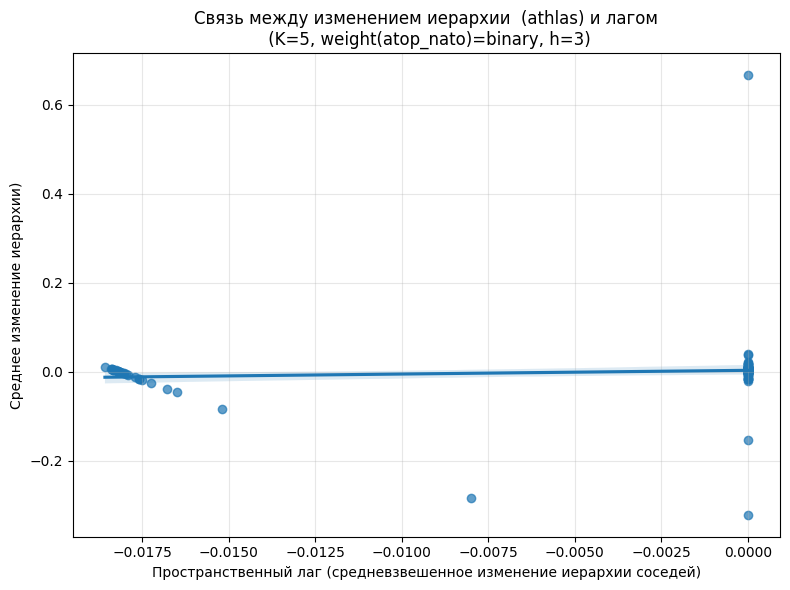

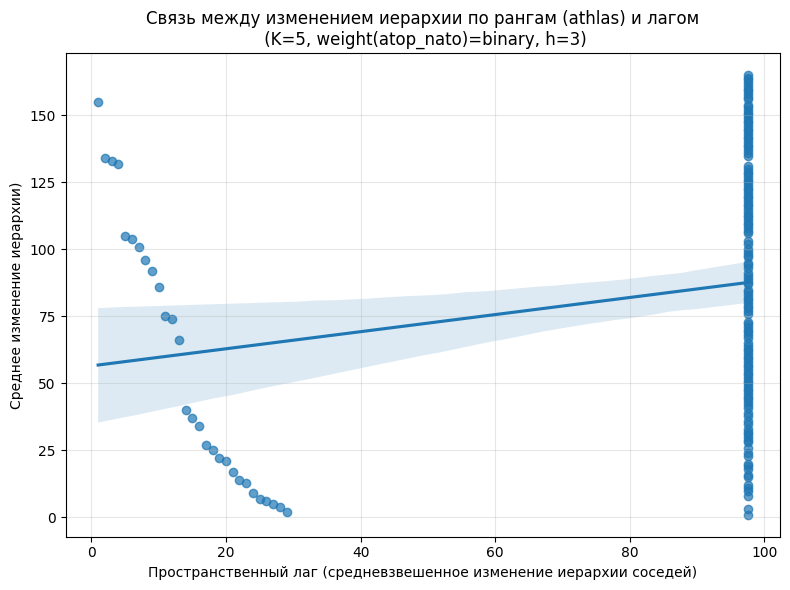

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0879, p-value = 0.2617
INFO:root:Спирмен: r = 0.2115, p-value = 0.0064
INFO:root:=== Moran's I ===
INFO:root:I = 0.0555
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2765
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1147, p = 0.0240
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:year is 1994
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.61, изолированных вершин = 136
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 1999
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:year is 2002
INFO:root:

Нет данных для построения графиков.
(3,) None
                                         delta       lag
country_a                                               
Afghanistan                       1.211493e-05  0.000000
Albania                          -1.663295e-06 -0.000240
Algeria                           5.892724e-05  0.000034
Angola                            1.727349e-05 -0.000012
Argentina                        -1.345043e-04 -0.000227
Armenia                           6.832615e-06 -0.000764
Australia                         2.241564e-04 -0.003457
Austria                          -2.507411e-05 -0.000008
Azerbaijan                        4.182415e-05 -0.000589
Bahamas                           3.330616e-06 -0.000232
Bahrain                           1.179767e-05  0.000060
Bangladesh                        1.276640e-04  0.000000
Barbados                         -1.647435e-06 -0.000231
Belarus                          -4.483530e-06 -0.000762
Belgium                          -9.964456

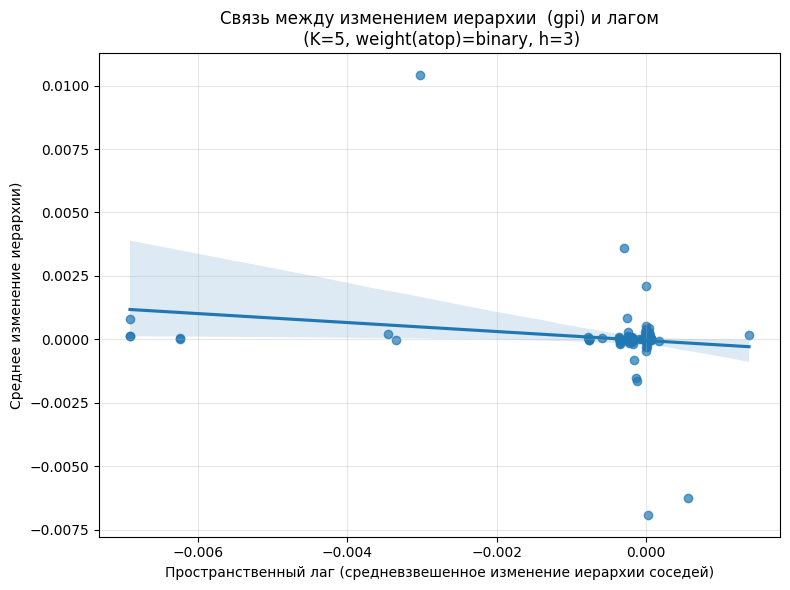

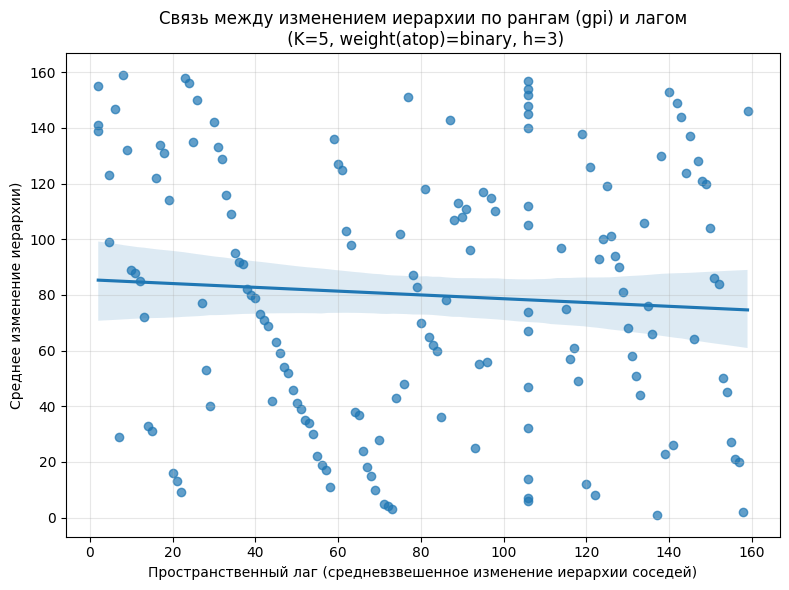

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.1847, p-value = 0.0197
INFO:root:Спирмен: r = -0.0681, p-value = 0.3935
INFO:root:=== Moran's I ===
INFO:root:I = -0.2127
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.1035
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0086, p = 0.3370
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMU

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam', ' is an island (no neighbors)')
('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Bang

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (147, 147), средняя степень = 19.99, изолированных вершин = 14
INFO:root:=== Moran's I ===
INFO:root:I = 0.0154
INFO:root:p-value (перестановочный) = 0.2340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0076
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (147, 147), средняя степень = 19.99, изолированных вершин = 14
INFO:root:=== Moran's I ===
INFO:root:I = -0.0816
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0076
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 19.65, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0742
INFO:root:p-value (перестановочный) = 0.0150
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1961
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0088
INFO:root:p-value (перестановочный) = 0.2730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0209
INFO:root:p-value (перестановочный) = 0.1820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0195
INFO:root:p-value (перестановочный) = 0.3820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0247
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0141
INFO:root:p-value (перестановочный) = 0.2370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0424
INFO:root:p-value (перестановочный) = 0.07

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0300
INFO:root:p-value (перестановочный) = 0.1370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0804
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0812
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (159, 159

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1958
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.2003
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0335
INFO:root:p-value (перестановочный) = 0.1190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (159, 159

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0852
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = -0.0487
INFO:root:p-value (перестановочный) = 0.0980
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0654
INFO:root:p-value (перестановочный) = 0.0220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (159, 1

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


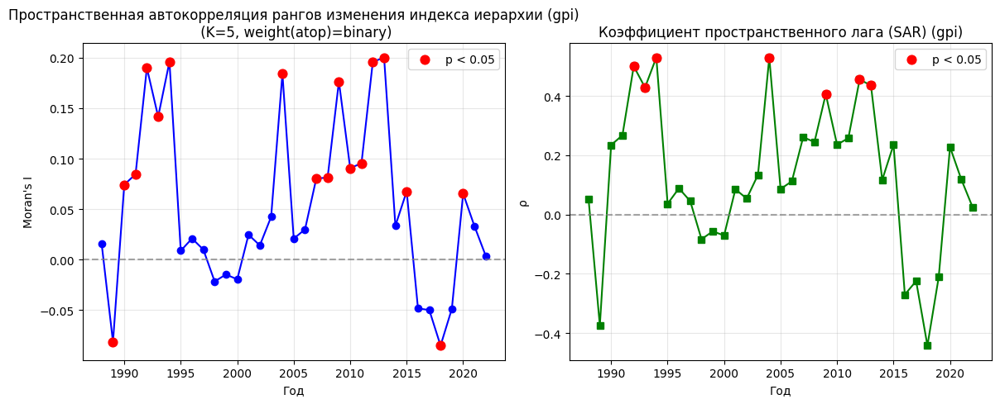

INFO:root:Starting spatial analysis for atop_nato with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130


(3,) None
                                         delta       lag
country_a                                               
Afghanistan                       1.211493e-05  0.000000
Albania                          -1.663295e-06 -0.000240
Algeria                           5.892724e-05  0.000000
Angola                            1.727349e-05  0.000000
Argentina                        -1.345043e-04  0.000000
Armenia                           6.832615e-06  0.000000
Australia                         2.241564e-04  0.000000
Austria                          -2.507411e-05  0.000000
Azerbaijan                        4.182415e-05  0.000000
Bahamas                           3.330616e-06  0.000000
Bahrain                           1.179767e-05  0.000000
Bangladesh                        1.276640e-04  0.000000
Barbados                         -1.647435e-06  0.000000
Belarus                          -4.483530e-06  0.000000
Belgium                          -9.964456e-05 -0.000237
Belize               

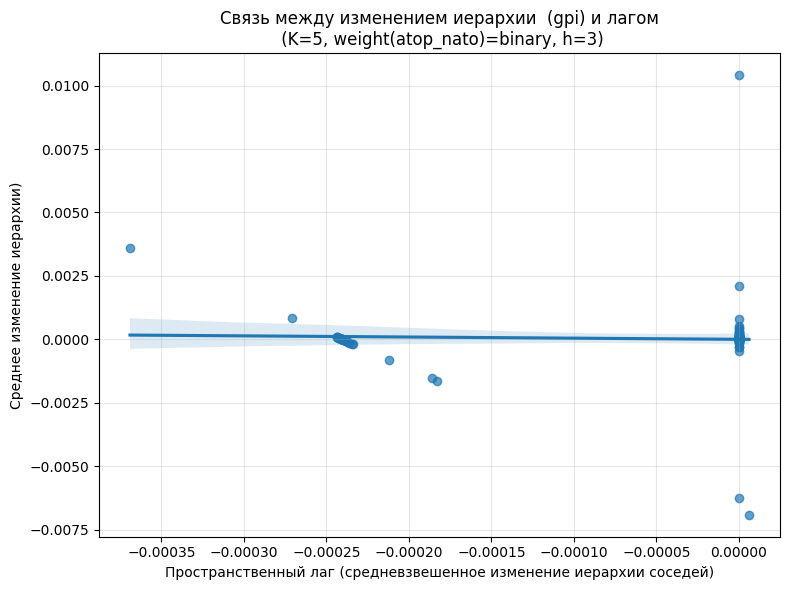

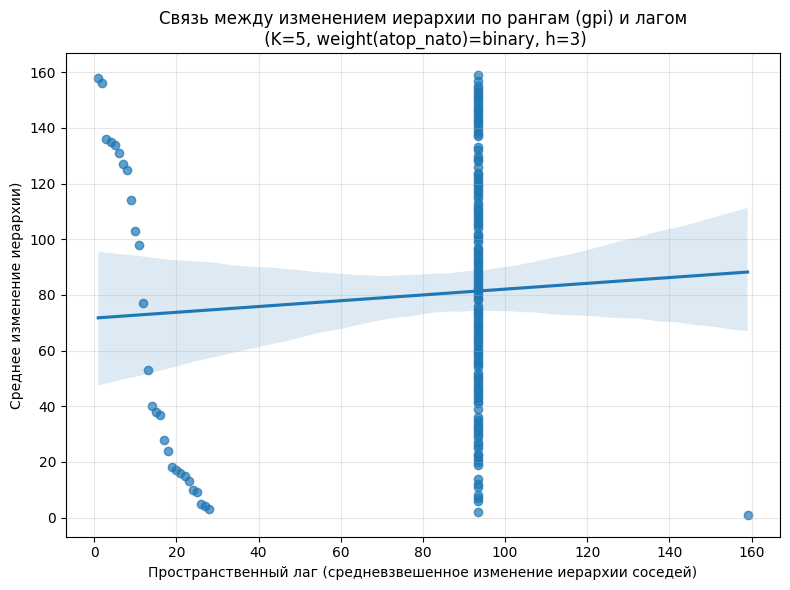

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0356, p-value = 0.6558
INFO:root:Спирмен: r = 0.0701, p-value = 0.3798
INFO:root:=== Moran's I ===
INFO:root:I = -0.0110
INFO:root:p-value (перестановочный) = 0.2010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0873
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2920, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNING: ', 'Bolivia (Plurinational State of)', ' is an island (no neighbors)')
('WARNING: ', 'Bosnia and Herzegovina', ' is an isla

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (147, 147), средняя степень = 4.08, изолированных вершин = 122
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (147, 147), средняя степень = 4.08, изолированных вершин = 122
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 4.00, изолированных вершин = 125
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 4.00, изолированных вершин = 125
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 4.00, изолированных вершин = 125
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130
INFO:root:year is 1995
INFO:root:Матрица смежности постр

Нет данных для построения графиков.
(3,) None
                                         delta       lag
country_a                                               
Afghanistan                       1.640998e-04  0.000000
Albania                          -2.682657e-05 -0.000287
Algeria                           9.102532e-05  0.000052
Andorra                          -4.862404e-08  0.000000
Angola                            1.491738e-04  0.000029
Antigua and Barbuda               1.080001e-08 -0.000050
Argentina                        -9.993877e-05 -0.000047
Armenia                           8.828826e-06 -0.001535
Australia                        -6.280261e-05 -0.000534
Austria                          -6.691081e-05 -0.000256
Azerbaijan                        2.708462e-05 -0.001357
Bahamas                           4.442889e-08 -0.000050
Bahrain                           2.377660e-05  0.000069
Bangladesh                        3.645669e-04  0.000000
Barbados                          9.687220

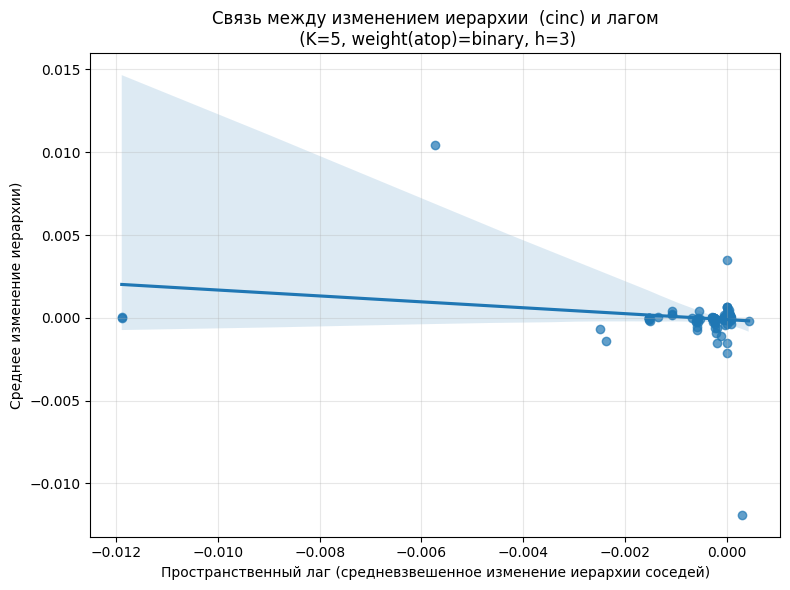

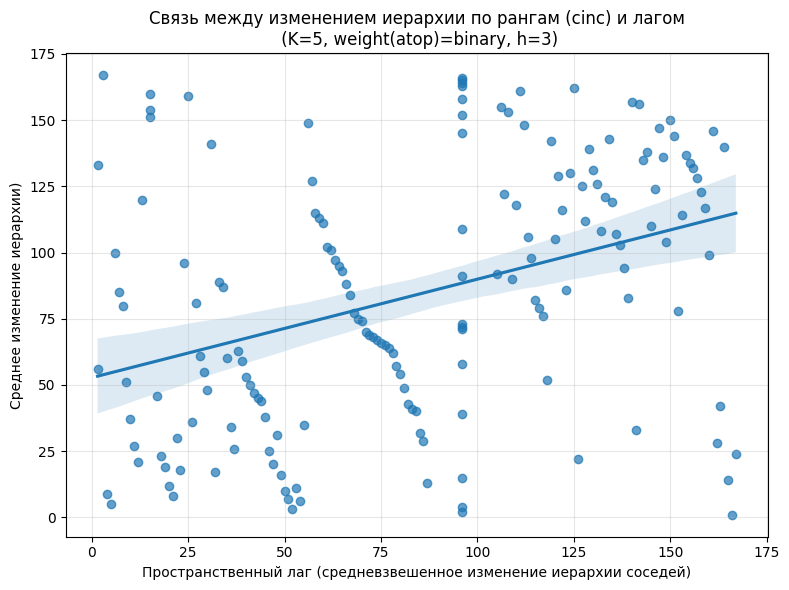

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.1938, p-value = 0.0121
INFO:root:Спирмен: r = 0.3717, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.2350
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3403
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.3679, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM 

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (139, 139), средняя степень = 20.40, изолированных вершин = 11
INFO:root:=== Moran's I ===
INFO:root:I = -0.0066
INFO:root:p-value (перестановочный) = 0.4580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0079
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (139, 139), средняя степень = 20.40, изолированных вершин = 11
INFO:root:=== Moran's I ===
INFO:root:I = 0.1473
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0079
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (139, 139), средняя степень = 20.40, изолированных вершин = 11
INFO:root:=== Moran's I ===
INFO:root:I = 0.1295
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0794
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 20.99, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = -0.0104
INFO:root:p-value (перестановочный) = 0.4650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = -0.0381
INFO:root:p-value (перестановочный) = 0.1480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Mor

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1619
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.2878
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.17, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.1480
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2006
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.2193
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1941
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1657
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:О

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2011
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1855
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.2514
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1617
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:О

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2016
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1159
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1790
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1061
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:О

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2021
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1383
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.2674
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho        rho_p
 1988    128 -0.006583    0.458 -0.019021 9.325791e-01
 1989    128  0.147305    0.001  0.449749 4.220096e-03
 1990    128  0.12

ML_Lag
ML_Lag
ML_Lag


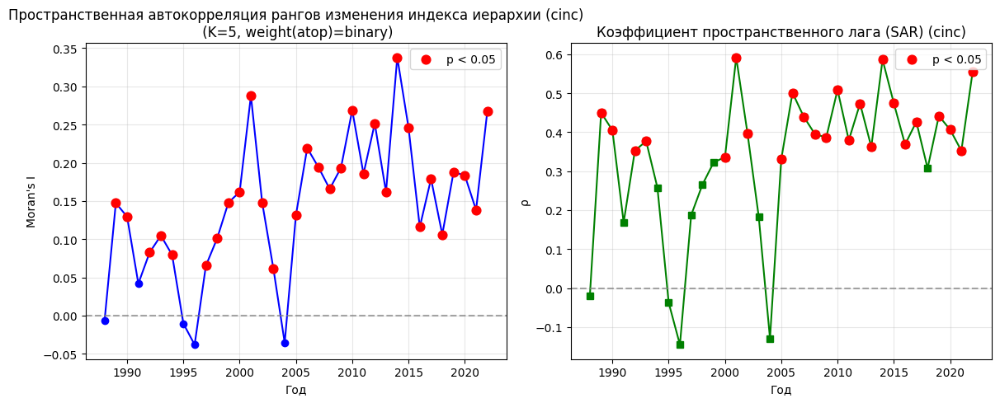

INFO:root:Starting spatial analysis for atop_nato with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


(3,) None
                                         delta       lag
country_a                                               
Afghanistan                       1.640998e-04  0.000000
Albania                          -2.682657e-05 -0.000287
Algeria                           9.102532e-05  0.000000
Andorra                          -4.862404e-08  0.000000
Angola                            1.491738e-04  0.000000
Antigua and Barbuda               1.080001e-08  0.000000
Argentina                        -9.993877e-05  0.000000
Armenia                           8.828826e-06  0.000000
Australia                        -6.280261e-05  0.000000
Austria                          -6.691081e-05  0.000000
Azerbaijan                        2.708462e-05  0.000000
Bahamas                           4.442889e-08  0.000000
Bahrain                           2.377660e-05  0.000000
Bangladesh                        3.645669e-04  0.000000
Barbados                          9.687220e-08  0.000000
Belarus              

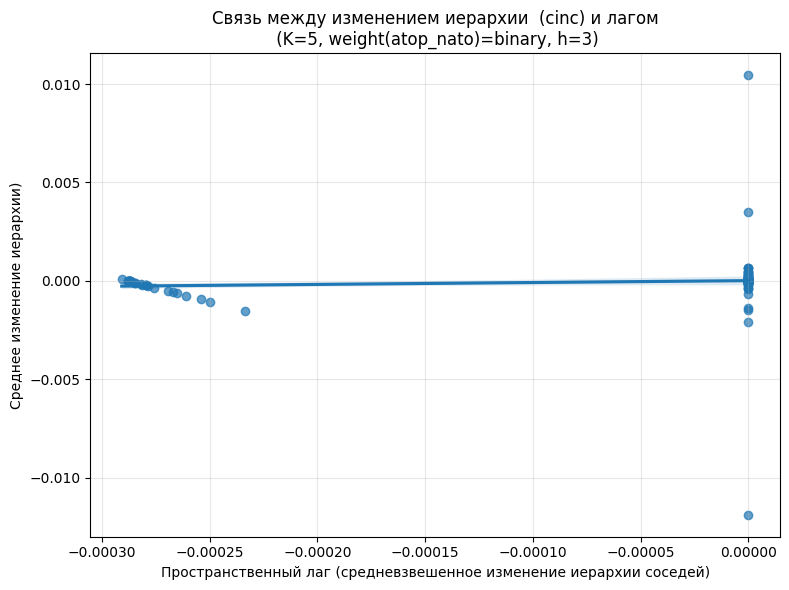

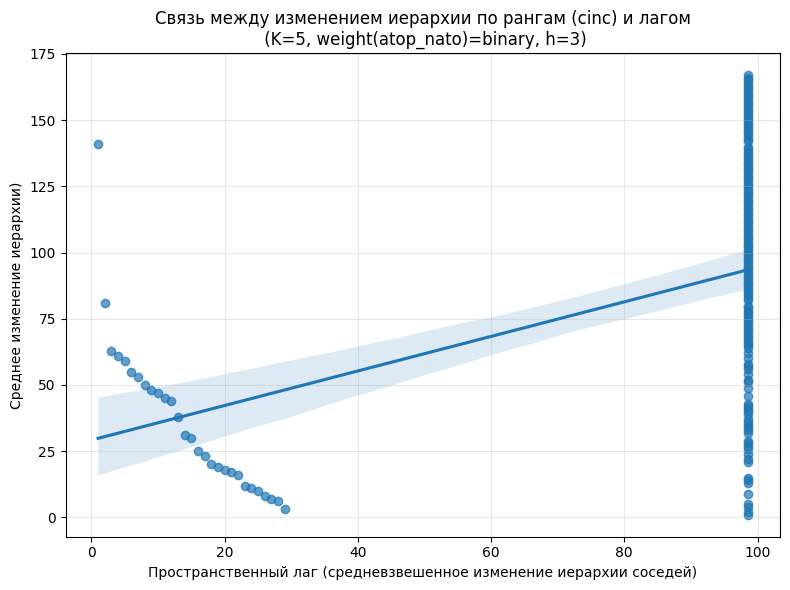

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0779, p-value = 0.3169
INFO:root:Спирмен: r = 0.4306, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0310
INFO:root:p-value (перестановочный) = 0.0480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:I = 0.9831
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.9821, p = 0.0010
INFO:root:converting to ranked data


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   atop_nato
Dependent Variable  :        cinc                Number of Observations:         167
Mean dependent var  :     84.0000                Number of Variables   :           2
S.D. dependent var  :     48.3529                Degrees of Freedom    :         165
Pseudo R-squared    :      0.2161
Spatial Pseudo R-squared:  0.2092
Log likelihood      :   -867.6475
Sigma-square ML     :   1899.2555                Akaike info criterion :    1739.295
S.E of regression   :     43.5804                Schwarz criterion     :    1745.531

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z

ML_Lag
ML_Error


INFO:root:=== Пространственная регрессия с режимами (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG - REGIMES (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   atop_nato
Dependent Variable  :        cinc                Number of Observations:         167
Mean dependent var  :     84.0000                Number of Variables   :           9
S.D. dependent var  :     48.3529                Degrees of Freedom    :         158
Pseudo R-squared    :      0.5909
Spatial Pseudo R-squared:  0.5533
Log likelihood      :   -809.9052
Sigma-square ML     :    951.1695                Akaike info criterion :    1637.810
S.E of regression   :     30.8410                Schwarz criterion     :    1665.872

------------------------------------------------------------------------------------
            Variable     Coefficient 

ML_Lag_Regimes
ML_Error_Regimes
(3,) None


INFO:root:year is 2005
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.64, изолированных вершин = 135
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.64, изолированных вершин = 135
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.64, изолированных вершин = 135
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.64, изолированных вершин = 135
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135


Нет данных для построения графиков.
(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       2.595417e+09  0.000000e+00
Albania                           1.013540e+09  4.087399e+10
Algeria                           1.325953e+10  5.269951e+09
Andorra                           9.320394e+07  0.000000e+00
Angola                            7.193395e+09  2.020444e+09
Antigua and Barbuda               4.816445e+07  2.550427e+10
Argentina                         2.355512e+10  2.476967e+10
Armenia                           9.783190e+08  1.101915e+10
Australia                         4.367451e+10  2.928714e+11
Austria                           1.083383e+10  1.761615e+10
Azerbaijan                        4.187245e+09  1.734925e+10
Bahamas                           1.647848e+08  2.550062e+10
Bahrain                           2.210637e+09  9.322719e+09
Bangladesh                        3.142

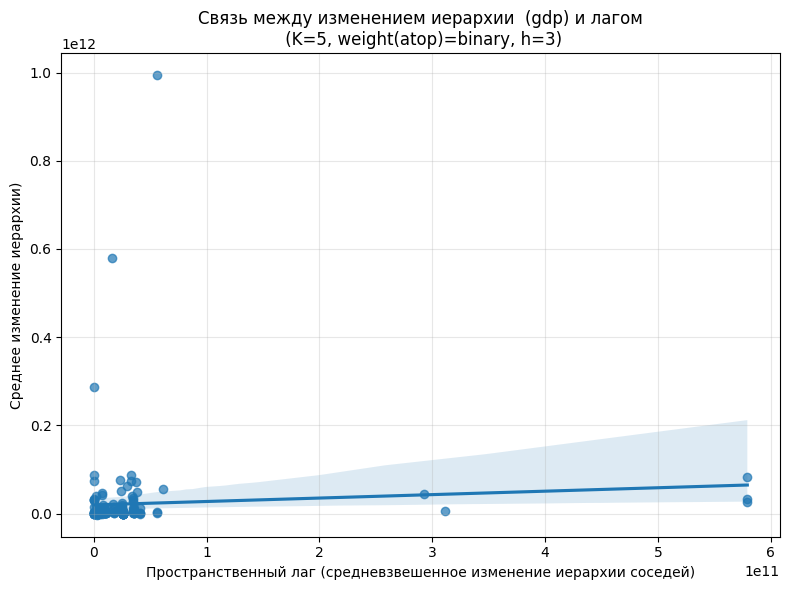

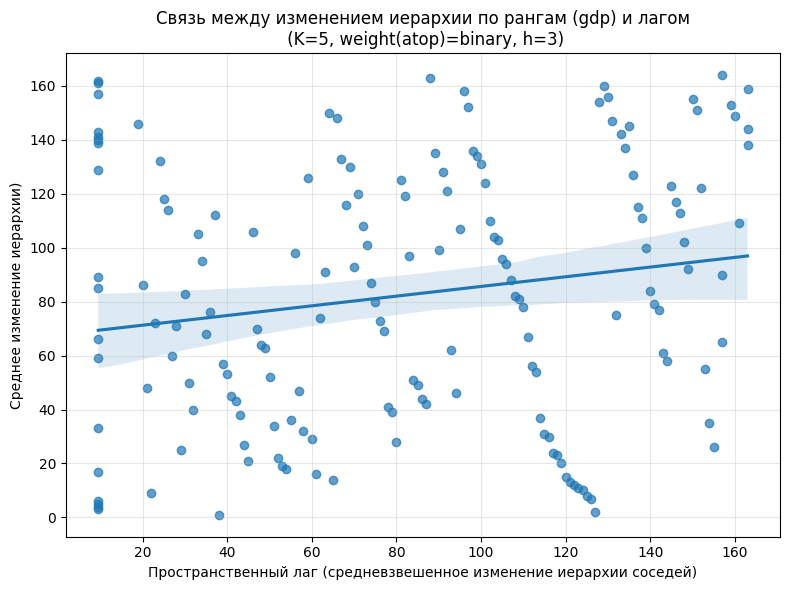

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0695, p-value = 0.3766
INFO:root:Спирмен: r = 0.1794, p-value = 0.0215
INFO:root:=== Moran's I ===
INFO:root:I = 0.0732
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2033
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0001, p = 0.3000
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Cuba', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' i

INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (136, 136), средняя степень = 19.85, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.4937
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0083
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (137, 137), средняя степень = 19.73, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.4238
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0083
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 19.35, изол

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3233
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.29, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.3764
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.29, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.3476
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2664
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.37, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.2697
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.37, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.3157
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:=== Moran's I ===
INFO:root:I = 0.2508
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.24, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.2629
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.24, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.2421
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция из

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:=== Moran's I ===
INFO:root:I = 0.0971
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1084
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1101
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция из

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:=== Moran's I ===
INFO:root:I = 0.2797
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.2973
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.2178
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция из

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


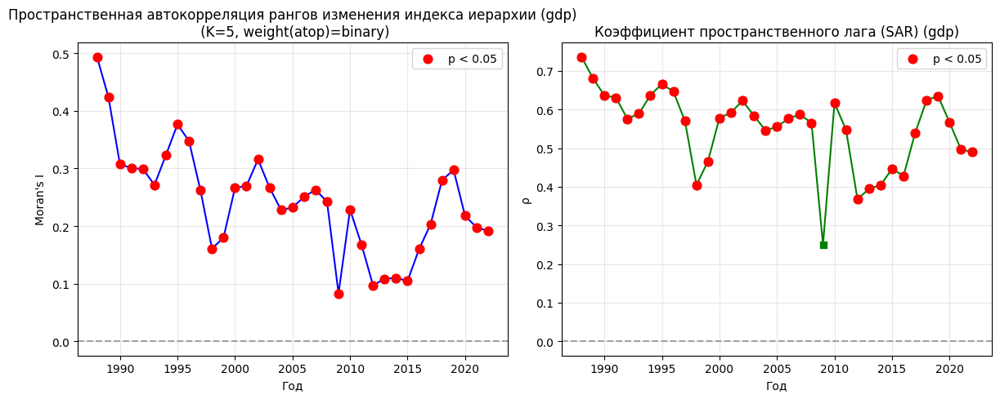

INFO:root:Starting spatial analysis for atop_nato with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135


(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       2.595417e+09  0.000000e+00
Albania                           1.013540e+09  4.087399e+10
Algeria                           1.325953e+10  0.000000e+00
Andorra                           9.320394e+07  0.000000e+00
Angola                            7.193395e+09  0.000000e+00
Antigua and Barbuda               4.816445e+07  0.000000e+00
Argentina                         2.355512e+10  0.000000e+00
Armenia                           9.783190e+08  0.000000e+00
Australia                         4.367451e+10  0.000000e+00
Austria                           1.083383e+10  0.000000e+00
Azerbaijan                        4.187245e+09  0.000000e+00
Bahamas                           1.647848e+08  0.000000e+00
Bahrain                           2.210637e+09  0.000000e+00
Bangladesh                        3.142719e+10  0.000000e+00
Barbados      

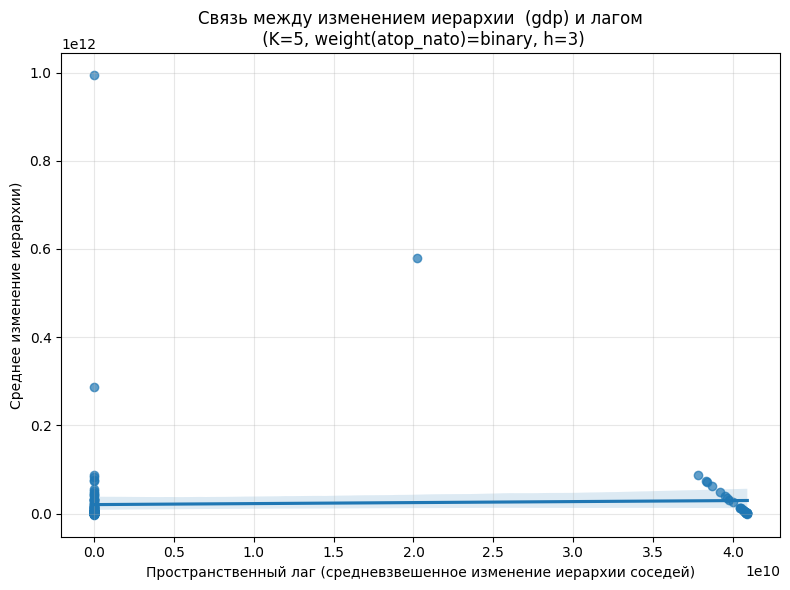

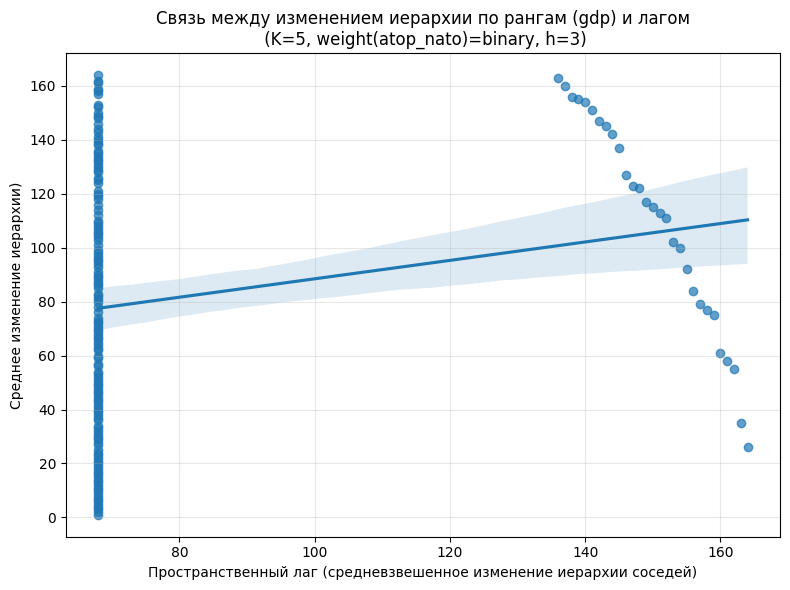

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0372, p-value = 0.6362
INFO:root:Спирмен: r = 0.2271, p-value = 0.0035
INFO:root:=== Moran's I ===
INFO:root:I = -0.0105
INFO:root:p-value (перестановочный) = 0.3550
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3069
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0250, p = 0.4810
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (136, 136), средняя степень = 2.51, изолированных вершин = 117
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (137, 137), средняя степень = 2.50, изолированных вершин = 118
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 2.44, изолированных вершин = 121
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.43, изолированных вершин = 122
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (142, 142), средняя степень = 2.41, изолированных вершин = 123
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 4.75, изолированных вершин = 131
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 4.75, изолированных вершин = 131
INFO:root:year is 1995
INFO:root:Матрица смежности постр

Нет данных для построения графиков.
(3,) None
                                         delta       lag
country_a                                               
Afghanistan                      -2.721578e-05  0.000000
Albania                          -9.592636e-06 -0.000009
Algeria                          -2.603243e-04  0.000006
Andorra                          -5.165282e-07  0.000000
Angola                            1.025325e-04 -0.000013
Antigua and Barbuda              -1.538842e-05 -0.000095
Argentina                        -2.731150e-04 -0.000087
Armenia                          -3.289162e-05 -0.000206
Australia                         4.646250e-04 -0.000659
Austria                           5.033339e-04  0.000064
Azerbaijan                        4.583924e-05 -0.000152
Bahamas                          -1.265911e-05 -0.000096
Bahrain                           3.074190e-06  0.000021
Bangladesh                       -6.030664e-05  0.000000
Barbados                         -3.053730

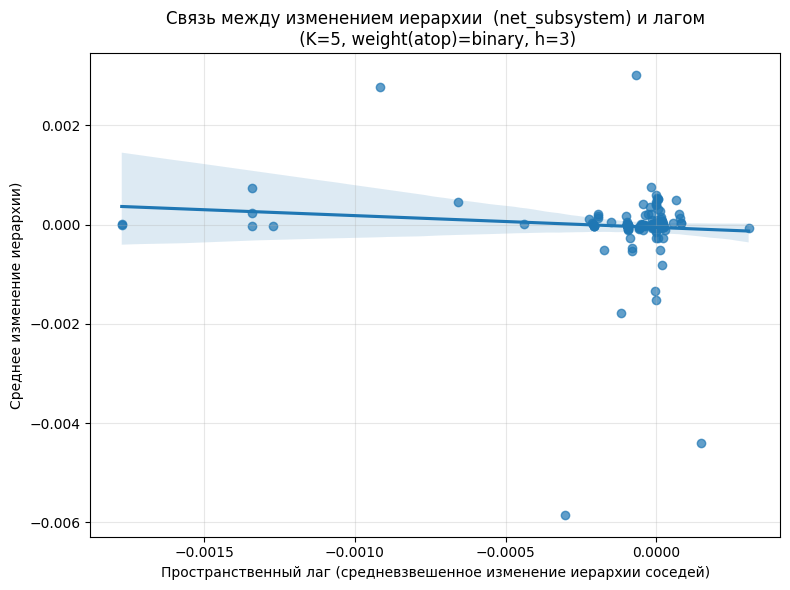

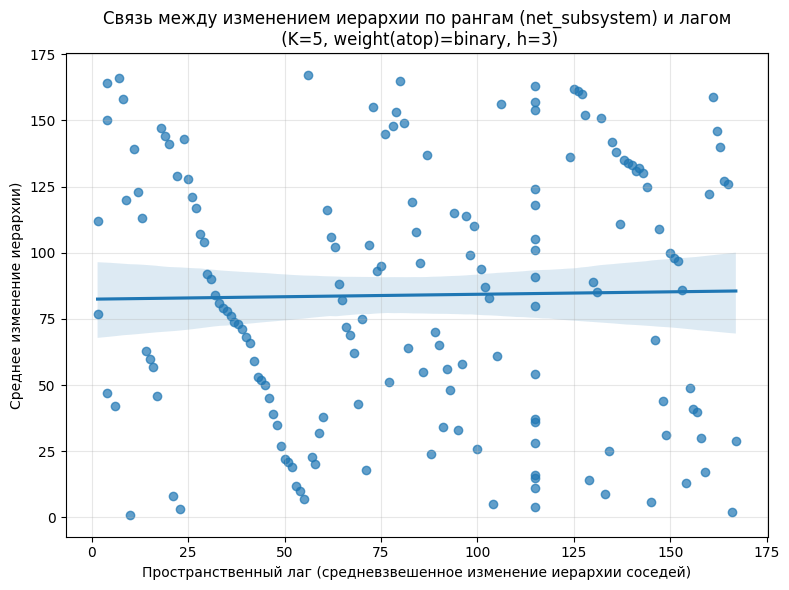

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0979, p-value = 0.2080
INFO:root:Спирмен: r = 0.0185, p-value = 0.8127
INFO:root:=== Moran's I ===
INFO:root:I = -0.0448
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1136
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2729, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM 

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = 0.0029
INFO:root:p-value (перестановочный) = 0.3110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = 0.0039
INFO:root:p-value (перестановочный) = 0.3110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = -0.0137
INFO:root:p-value (перестановочный) = 0.4620
INFO:root:Ожидаемое I при отс

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0477
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.18, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0754
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.0343
INFO:root:p-value (перестановочный) = 0.1950
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (164, 16

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0089
INFO:root:p-value (перестановочный) = 0.2970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.0477
INFO:root:p-value (перестановочный) = 0.0810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = -0.0737
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 20.92, изолированных вершин = 17
INFO:root:=== Mor

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0381
INFO:root:p-value (перестановочный) = 0.1630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 20.92, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0025
INFO:root:p-value (перестановочный) = 0.3590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0099
INFO:root:p-value (перестановочный) = 0.2750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0250
INFO:root:p-value (перестановочный) = 0.2

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0242
INFO:root:p-value (перестановочный) = 0.2910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0323
INFO:root:p-value (перестановочный) = 0.2240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0677
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:y

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0003
INFO:root:p-value (перестановочный) = 0.3960
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0653
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0110
INFO:root:p-value (перестановочный) = 0.2490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Mor

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


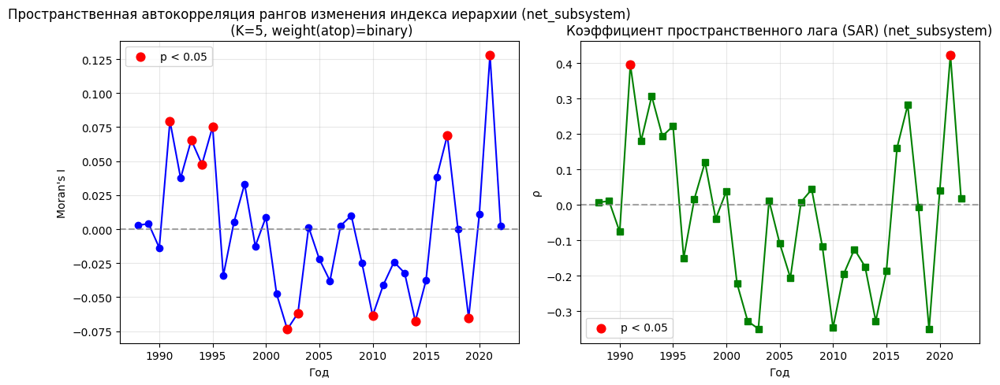

INFO:root:Starting spatial analysis for atop_nato with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


(3,) None
                                         delta       lag
country_a                                               
Afghanistan                      -2.721578e-05  0.000000
Albania                          -9.592636e-06 -0.000009
Algeria                          -2.603243e-04  0.000000
Andorra                          -5.165282e-07  0.000000
Angola                            1.025325e-04  0.000000
Antigua and Barbuda              -1.538842e-05  0.000000
Argentina                        -2.731150e-04  0.000000
Armenia                          -3.289162e-05  0.000000
Australia                         4.646250e-04  0.000000
Austria                           5.033339e-04  0.000000
Azerbaijan                        4.583924e-05  0.000000
Bahamas                          -1.265911e-05  0.000000
Bahrain                           3.074190e-06  0.000000
Bangladesh                       -6.030664e-05  0.000000
Barbados                         -3.053730e-05  0.000000
Belarus              

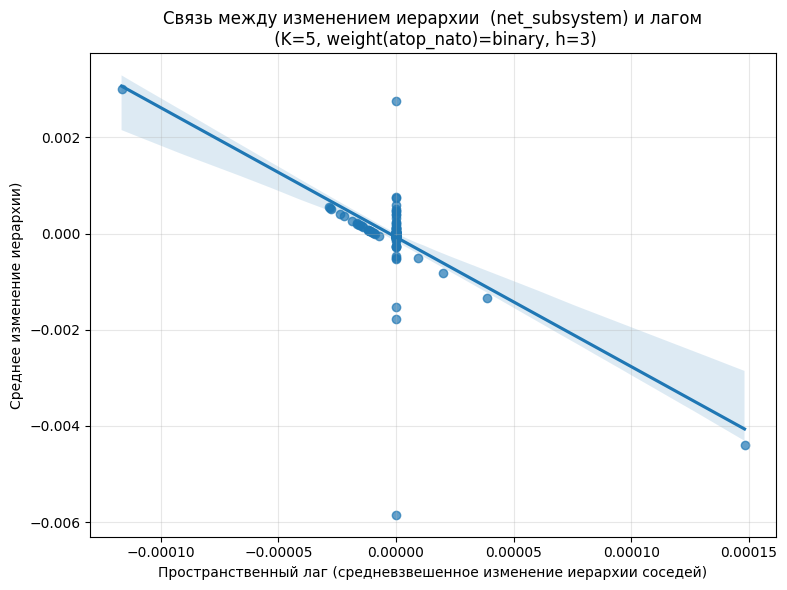

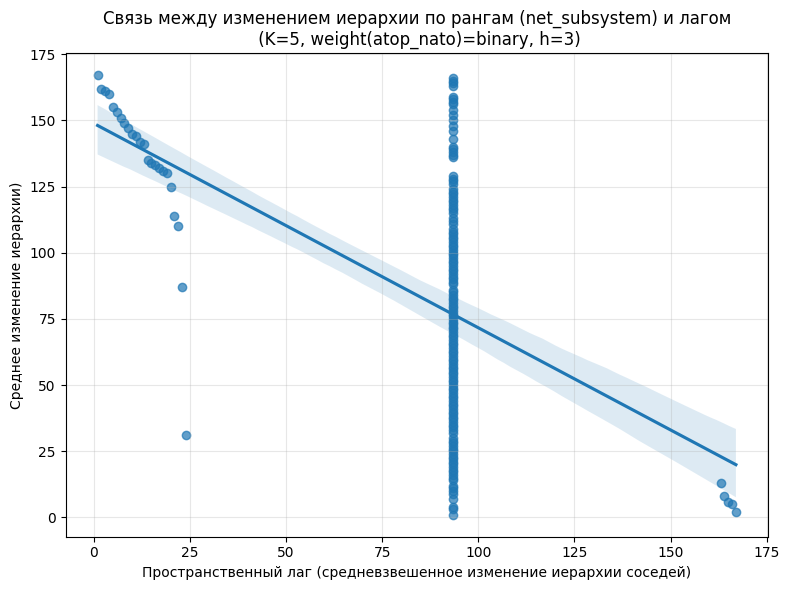

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.6141, p-value = 0.0000
INFO:root:Спирмен: r = -0.5096, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.0791
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3123
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.6391, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (146, 146), средняя степень = 3.16, изолированных вершин = 124
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 4.36, изолированных вершин = 13

Нет данных для построения графиков.
(3,) None
                                     delta       lag
country_a                                           
Afghanistan                      -0.000063  0.000000
Albania                          -0.000036  0.000010
Algeria                          -0.000400 -0.000030
Andorra                          -0.000004  0.000000
Angola                            0.000084 -0.000059
Antigua and Barbuda              -0.000057 -0.000420
Argentina                        -0.000466 -0.000407
Armenia                          -0.000089 -0.000013
Australia                         0.001335 -0.004807
Austria                           0.000975  0.000362
Azerbaijan                        0.000058  0.000097
Bahamas                          -0.000052 -0.000420
Bahrain                           0.000006 -0.000013
Bangladesh                       -0.000142  0.000000
Barbados                         -0.000108 -0.000418
Belarus                           0.000076 -0.000033


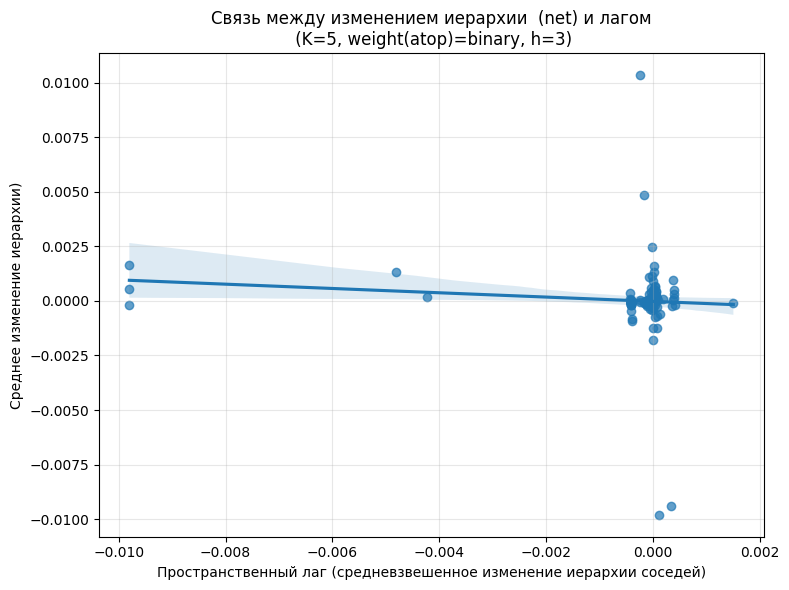

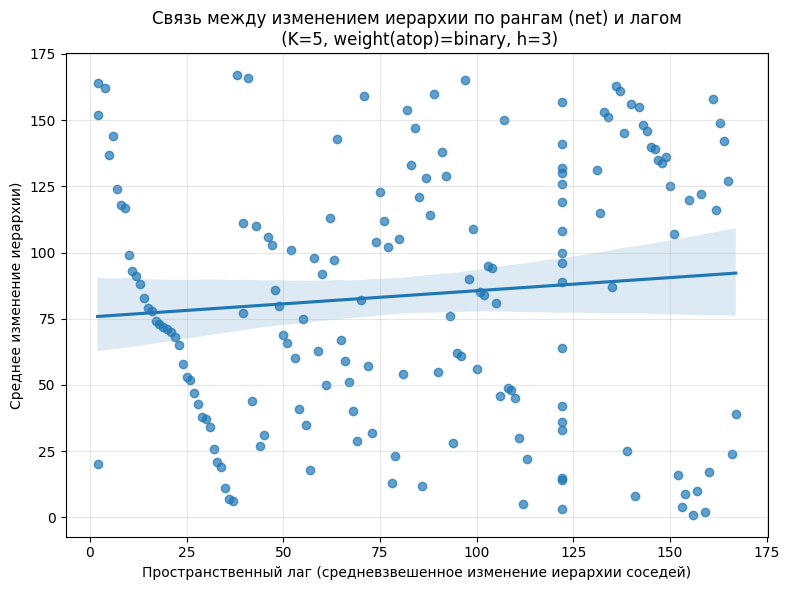

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0948, p-value = 0.2229
INFO:root:Спирмен: r = 0.0991, p-value = 0.2025
INFO:root:=== Moran's I ===
INFO:root:I = -0.1016
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1151
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2419, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM 

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = 0.0034
INFO:root:p-value (перестановочный) = 0.3470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = 0.0000
INFO:root:p-value (перестановочный) = 0.4040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 20.46, изолированных вершин = 13
INFO:root:=== Moran's I ===
INFO:root:I = 0.0440
INFO:root:p-value (перестановочный) = 0.0770
INFO:root:Ожидаемое I при отсу

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0043
INFO:root:p-value (перестановочный) = 0.4260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.18, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.1259
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0481
INFO:root:p-value (перестановочный) = 0.0470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (164, 16

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1020
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0652
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.05, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0423
INFO:root:p-value (перестановочный) = 0.0690
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (165, 165

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0270
INFO:root:p-value (перестановочный) = 0.2730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 20.92, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0381
INFO:root:p-value (перестановочный) = 0.0780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0534
INFO:root:p-value (перестановочный) = 0.0270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Mora

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0029
INFO:root:p-value (перестановочный) = 0.3620
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 21.13, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0057
INFO:root:p-value (перестановочный) = 0.3160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0046
INFO:root:p-value (перестановочный) = 0.4140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0333
INFO:root:p-value (перестановочный) = 0.09

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0699
INFO:root:p-value (перестановочный) = 0.0140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0775
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0842
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


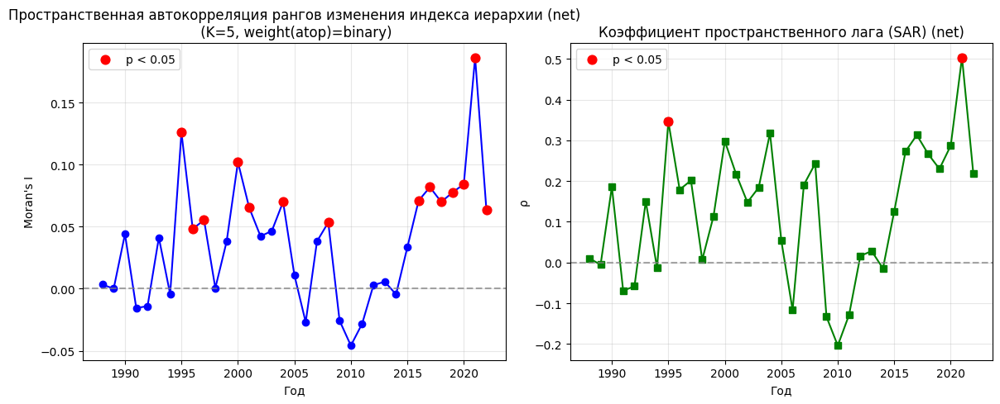

INFO:root:Starting spatial analysis for atop_nato with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


(3,) None
                                     delta       lag
country_a                                           
Afghanistan                      -0.000063  0.000000
Albania                          -0.000036  0.000010
Algeria                          -0.000400  0.000000
Andorra                          -0.000004  0.000000
Angola                            0.000084  0.000000
Antigua and Barbuda              -0.000057  0.000000
Argentina                        -0.000466  0.000000
Armenia                          -0.000089  0.000000
Australia                         0.001335  0.000000
Austria                           0.000975  0.000000
Azerbaijan                        0.000058  0.000000
Bahamas                          -0.000052  0.000000
Bahrain                           0.000006  0.000000
Bangladesh                       -0.000142  0.000000
Barbados                         -0.000108  0.000000
Belarus                           0.000076  0.000000
Belgium                           0.

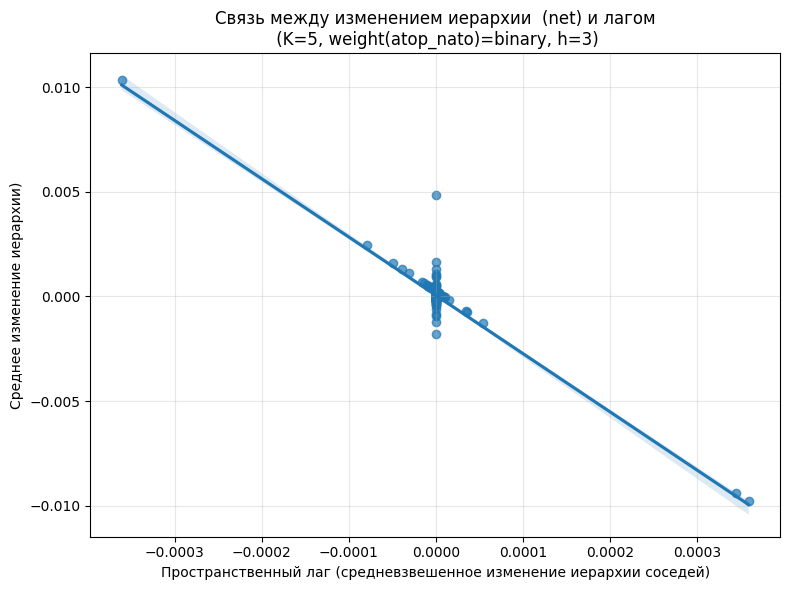

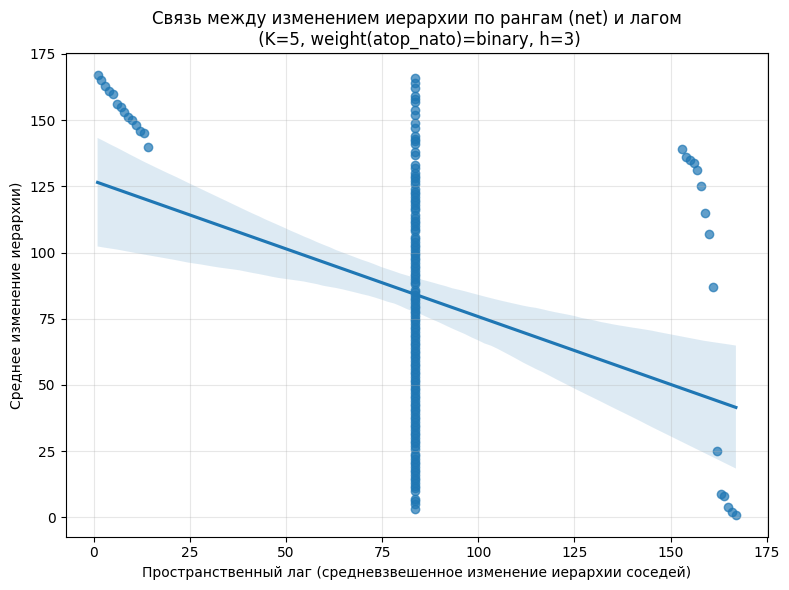

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.9370, p-value = 0.0000
INFO:root:Спирмен: r = -0.3378, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = -0.1814
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3480
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.5707, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (143, 143), средняя степень = 2.94, изолированных вершин = 122
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (146, 146), средняя степень = 3.16, изолированных вершин = 124
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 4.36, изолированных вершин = 134
INFO:root:year is 1995
INFO:root:Матрица смежности постр

Нет данных для построения графиков.
(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       8.718105e+11  0.000000e+00
Albania                           5.482717e+12  4.556733e+15
Algeria                           4.689801e+13  9.057772e+13
Andorra                           5.785767e+12  0.000000e+00
Angola                            1.614488e+13  5.665325e+12
Antigua and Barbuda               1.458812e+12  2.726500e+15
Argentina                         3.725304e+14  2.714904e+15
Armenia                           5.023388e+12  1.047609e+14
Australia                         6.325820e+15  4.248731e+16
Austria                           1.085462e+15  1.529463e+15
Azerbaijan                        2.397306e+13  2.256678e+14
Bahamas                           8.271459e+12  2.726287e+15
Bahrain                           6.420328e+13  1.738407e+14
Bangladesh                        4.011

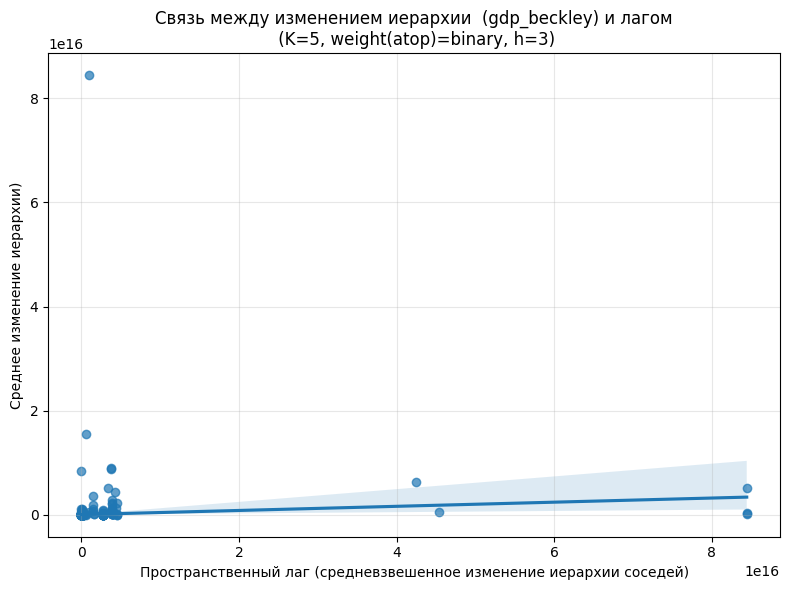

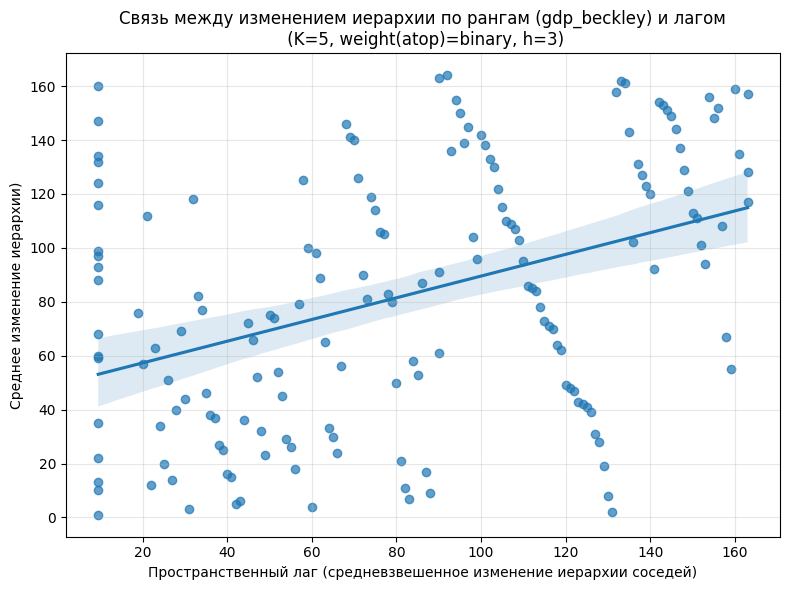

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0310, p-value = 0.6933
INFO:root:Спирмен: r = 0.4024, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0607
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4866
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0145, p = 0.1540
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Cuba', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' i

INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (136, 136), средняя степень = 19.85, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.5151
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0083
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (137, 137), средняя степень = 19.73, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.4603
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0083
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 19.35, изол

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3106
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.29, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.4761
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.29, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.5343
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4319
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.37, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.4263
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.37, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.5088
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.5014
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.24, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.5197
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.24, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.5015
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1806
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1858
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.1734
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4582
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.35, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.5252
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran's I ===
INFO:root:I = 0.5384
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    121 0.515079    0.001 0.743739 0.000000e+00
 1989    122 0.460327    0.001 0.704556 1.358913e-13
 1990    123 0.260200    0.001 0.566270 1.386442e-05
 1991    124 0.165756    0.001 0.441924 5.220079e-03
 1992    128 0.168234    0.001 0.374430 2.409703e-02
 1993    143 0.209109    0.001 0.498898 4.085290e-04
 1994    143 0.310637    0.001 0.613466 1.524902e-07
 1995    143 0.476092    0.001 0.714431 1.287859e-14
 1996    143 0.534272    0.001 0.754058 0.000000e+00
 1997    143 0.509005    0.001 0.741726 0.000000e+00
 1998    143 0.418900    0.001 0.664604 2.427516e-10
 1999    143 0.373505    0.001 0.661677 3.805645e-10
 2000    144 0.431929    0.001 0.702999 1.865175e-13
 2001    144 0.426270    0.001 0.717450 5.773160e-15
 2002    144 0.508841    0.001 0.752991 0.000000e+00
 2003    144 0.480416    0.001 0.740235 0.000000e+00
 2004    144 0.462000    0.001 0.729843 2.220446e-16

ML_Lag


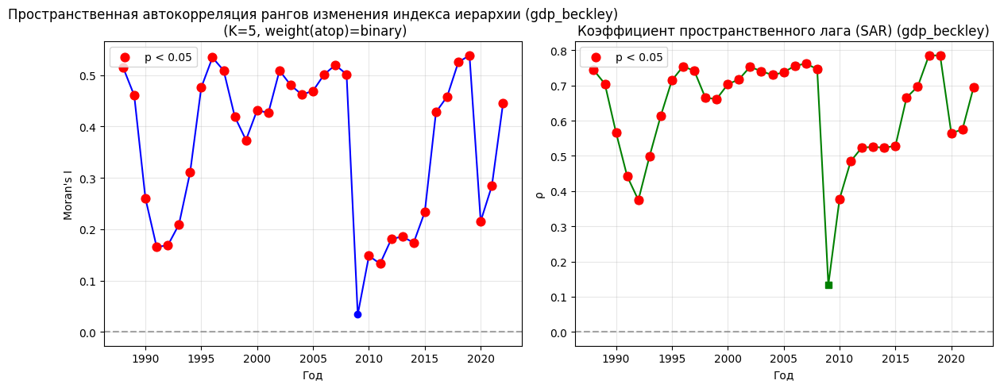

INFO:root:Starting spatial analysis for atop_nato with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135


(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       8.718105e+11  0.000000e+00
Albania                           5.482717e+12  4.556733e+15
Algeria                           4.689801e+13  0.000000e+00
Andorra                           5.785767e+12  0.000000e+00
Angola                            1.614488e+13  0.000000e+00
Antigua and Barbuda               1.458812e+12  0.000000e+00
Argentina                         3.725304e+14  0.000000e+00
Armenia                           5.023388e+12  0.000000e+00
Australia                         6.325820e+15  0.000000e+00
Austria                           1.085462e+15  0.000000e+00
Azerbaijan                        2.397306e+13  0.000000e+00
Bahamas                           8.271459e+12  0.000000e+00
Bahrain                           6.420328e+13  0.000000e+00
Bangladesh                        4.011990e+13  0.000000e+00
Barbados      

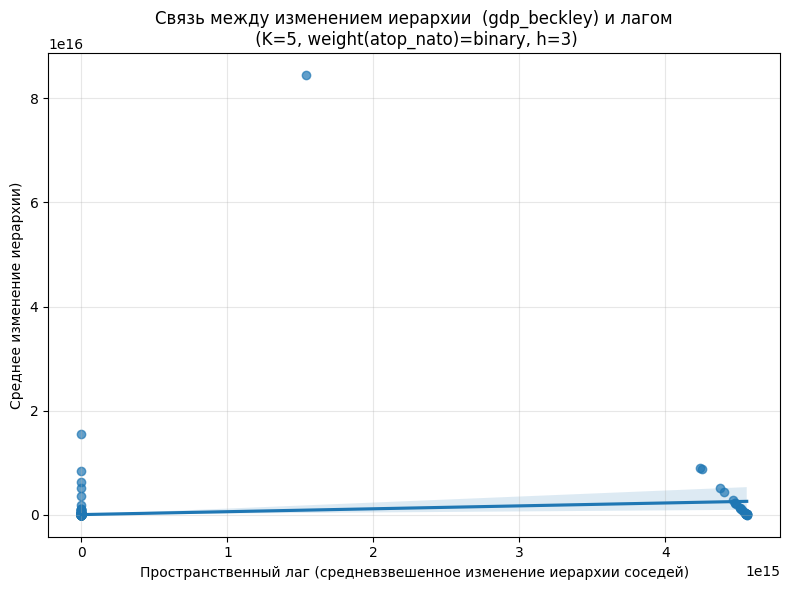

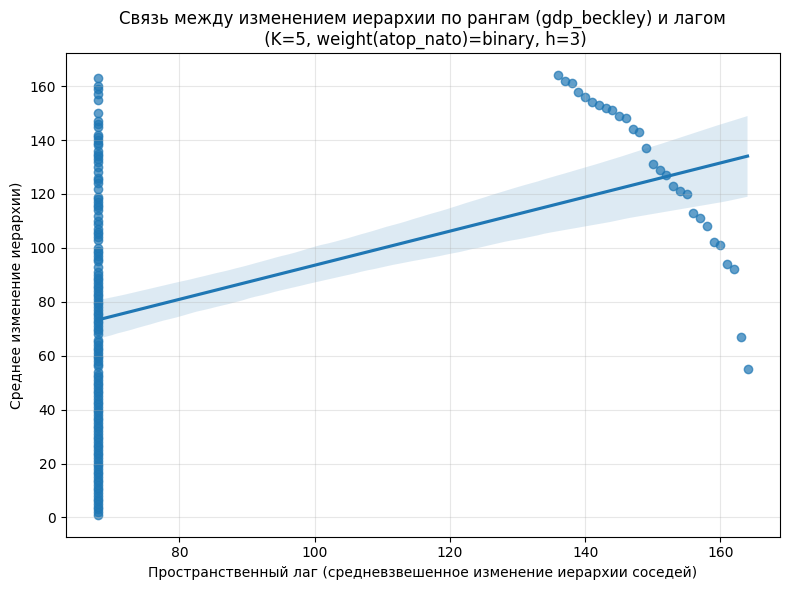

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0944, p-value = 0.2290
INFO:root:Спирмен: r = 0.4206, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0545
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.9308
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0581, p = 0.1600
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (136, 136), средняя степень = 2.51, изолированных вершин = 117
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (137, 137), средняя степень = 2.50, изолированных вершин = 118
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 2.44, изолированных вершин = 121
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.43, изолированных вершин = 122
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (142, 142), средняя степень = 2.41, изолированных вершин = 123
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 4.75, изолированных вершин = 131
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 4.75, изолированных вершин = 131
INFO:root:year is 1995
INFO:root:Матрица смежности постр

Нет данных для построения графиков.
(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       2.400421e+13  0.000000e+00
Albania                           7.439311e+13  7.357725e+15
Algeria                           6.011625e+14  5.063814e+14
Andorra                           1.520829e+13  0.000000e+00
Angola                            1.900775e+14  5.166985e+13
Antigua and Barbuda               3.302619e+12  4.223662e+15
Argentina                         1.962836e+15  4.160451e+15
Armenia                           7.001300e+13  1.612227e+15
Australia                         6.628844e+15  5.852835e+16
Austria                           2.055044e+15  3.015486e+15
Azerbaijan                        3.388186e+14  2.242640e+15
Bahamas                           1.022730e+13  4.223438e+15
Bahrain                           3.516873e+14  1.006459e+15
Bangladesh                        8.825

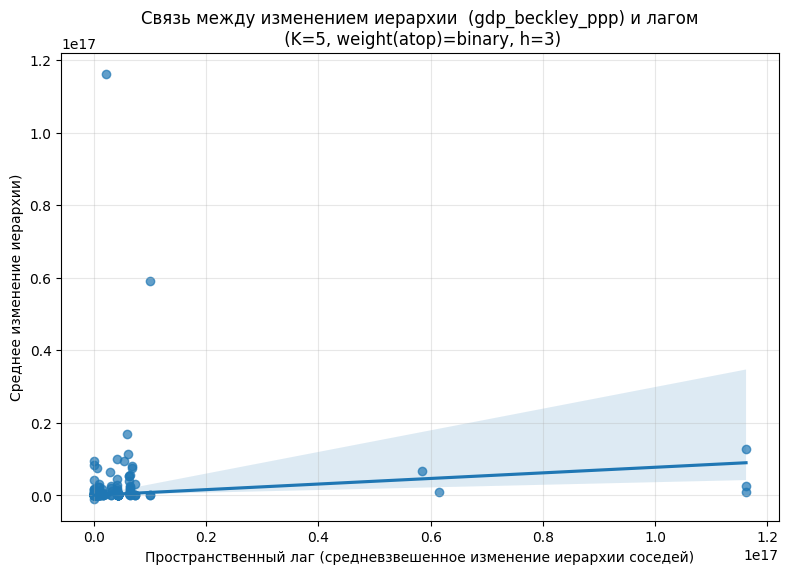

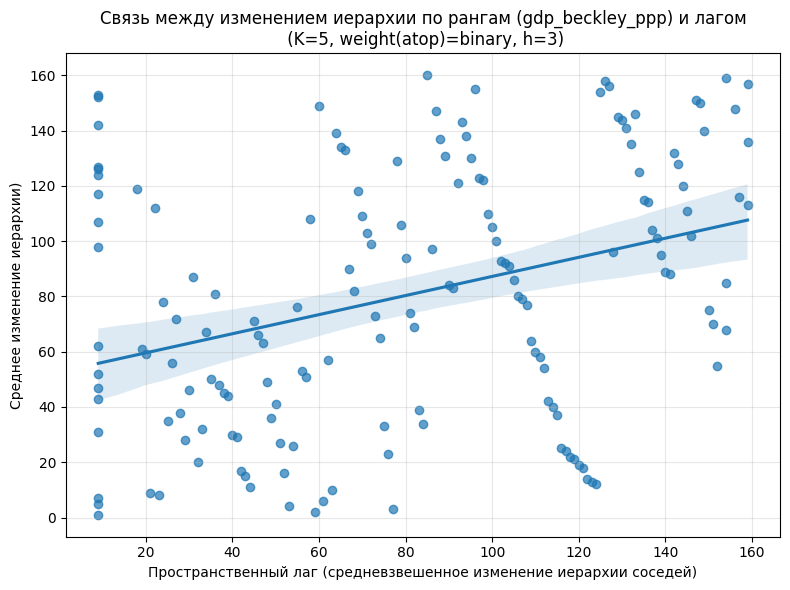

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0637, p-value = 0.4236
INFO:root:Спирмен: r = 0.3454, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.1124
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4245
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0038, p = 0.2160
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:Стран, по которым есть расстояния и дельты: 160
INFO:root:year is 1990
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 20.97, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.2333
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0072
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 21.06, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.3322
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 21.06, изол

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (157, 157), средняя степень = 20.92, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.3435
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (158, 158), средняя степень = 21.15, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.4074
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (158, 158), средняя степень = 21.15, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.4092
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутств

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2005
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.01, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.4110
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.01, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.4551
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.01, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.4765
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:О

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1486
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.01, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1682
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 21.01, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1708
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0071
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.4219
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 21.11, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.5058
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 21.11, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.5222
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


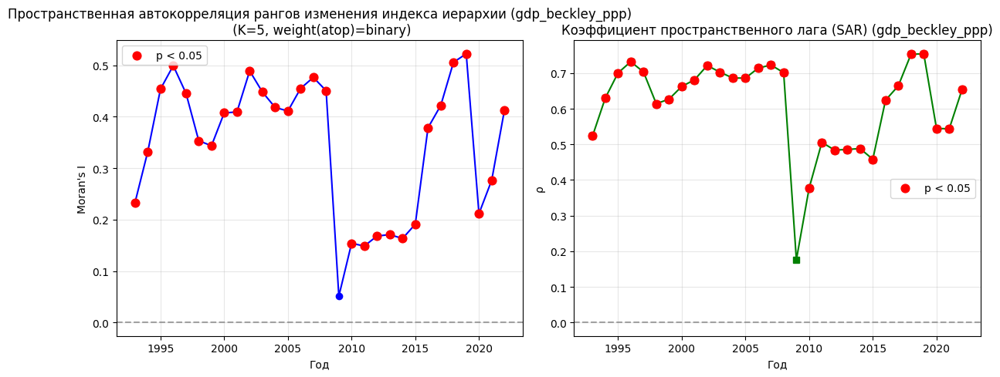

INFO:root:Starting spatial analysis for atop_nato with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 160
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 5.08, изолированных вершин = 131


(3,) None
                                         delta           lag
country_a                                                   
Afghanistan                       2.400421e+13  0.000000e+00
Albania                           7.439311e+13  7.357725e+15
Algeria                           6.011625e+14  0.000000e+00
Andorra                           1.520829e+13  0.000000e+00
Angola                            1.900775e+14  0.000000e+00
Antigua and Barbuda               3.302619e+12  0.000000e+00
Argentina                         1.962836e+15  0.000000e+00
Armenia                           7.001300e+13  0.000000e+00
Australia                         6.628844e+15  0.000000e+00
Austria                           2.055044e+15  0.000000e+00
Azerbaijan                        3.388186e+14  0.000000e+00
Bahamas                           1.022730e+13  0.000000e+00
Bahrain                           3.516873e+14  0.000000e+00
Bangladesh                        8.825985e+14  0.000000e+00
Barbados      

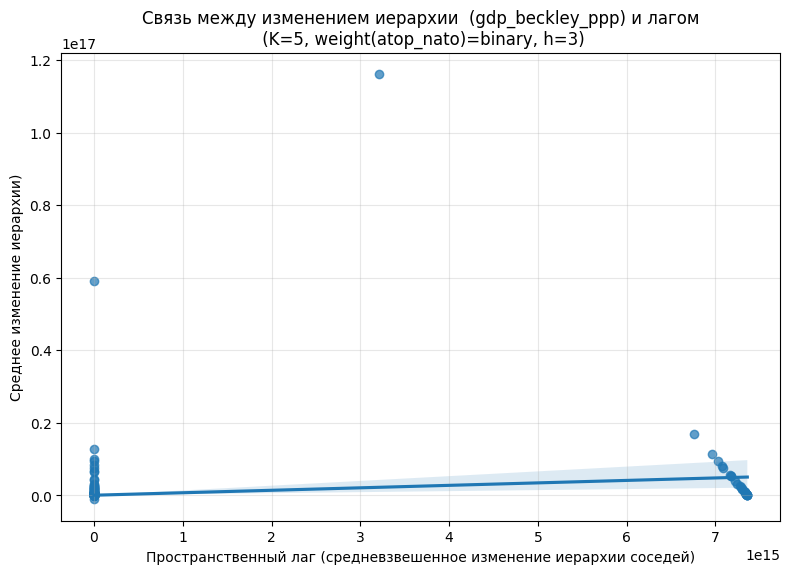

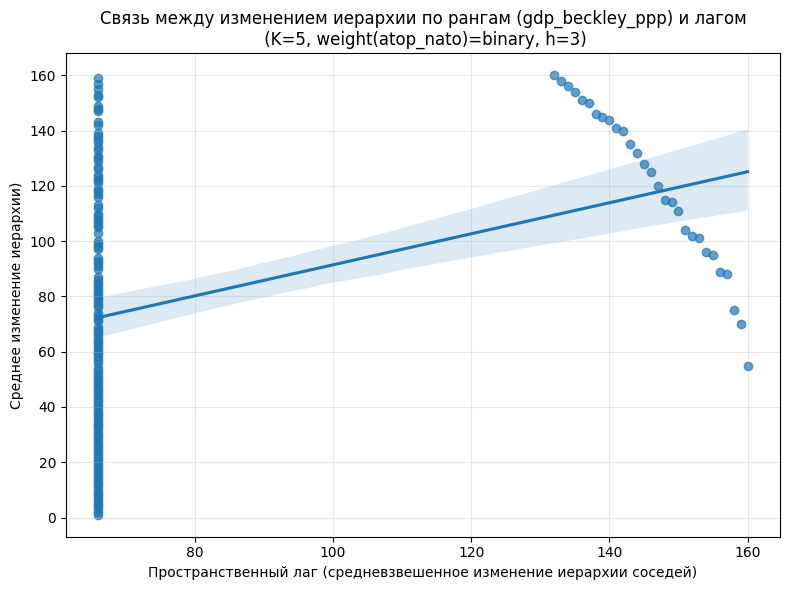

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1131, p-value = 0.1546
INFO:root:Спирмен: r = 0.3771, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0620
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.7436
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0256, p = 0.4460
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1990
INFO:root:year is 1991
INFO:root:year is 1992
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (155, 155), средняя степень = 4.88, изолированных вершин = 127
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 4.85, изолированных вершин = 128
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 4.85, изолированных вершин = 128
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 4.85, изолированных вершин = 128
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 4.85, изолированных вершин = 128
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 4.82, изолированных вершин = 129
INFO:root:year is 1999
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 4.82, изолированных вершин = 129
INFO:root:year is 2000
INFO:root:Матрица смежности постр

Нет данных для построения графиков.
(3,) None
                                     delta       lag
country_a                                           
Afghanistan                      -0.000012  0.000000
Albania                          -0.000012 -0.000568
Algeria                          -0.000012  0.000020
Andorra                          -0.000010  0.000000
Angola                           -0.000008  0.000002
Antigua and Barbuda              -0.000011 -0.000304
Argentina                        -0.000107 -0.000301
Armenia                          -0.000006  0.000044
Australia                        -0.000005 -0.005047
Austria                           0.000025 -0.000168
Azerbaijan                       -0.000007  0.000051
Bahamas                          -0.000042 -0.000303
Bahrain                          -0.000007  0.000048
Bangladesh                       -0.000012  0.000000
Barbados                         -0.000103 -0.000302
Belarus                           0.000012  0.000041


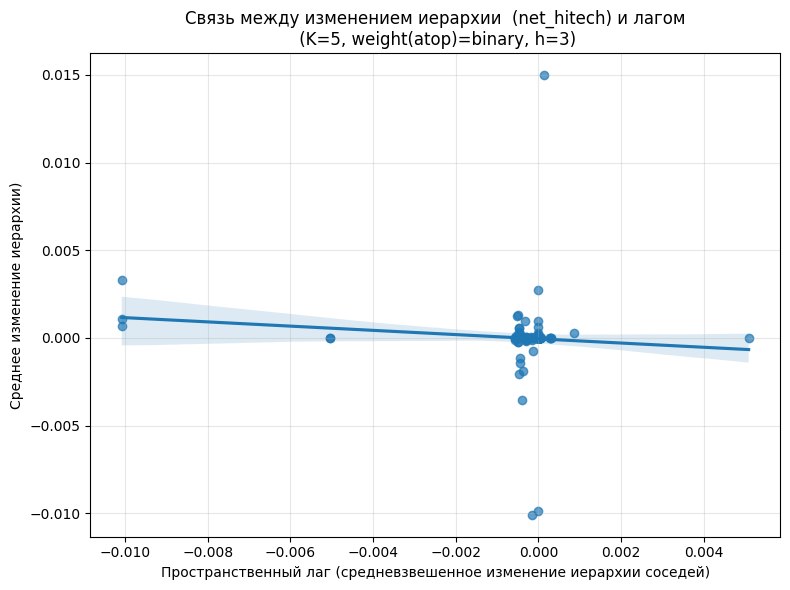

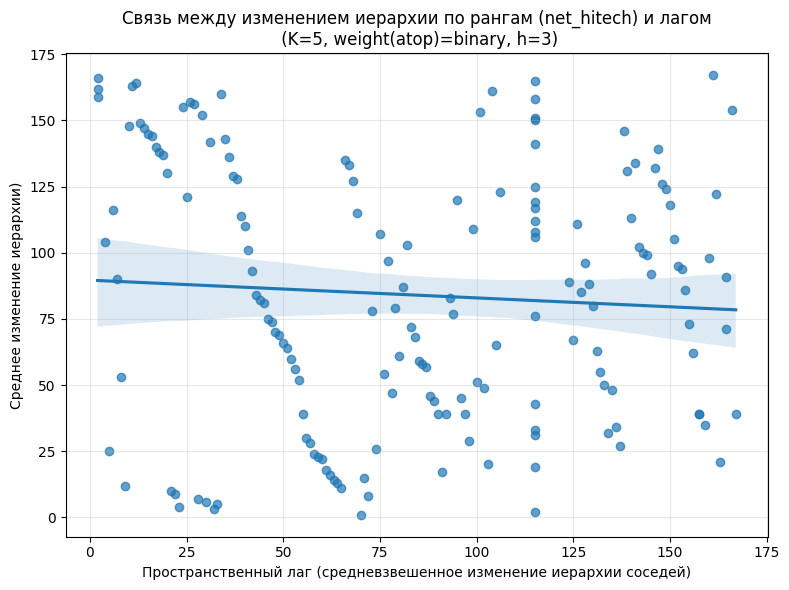

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.1071, p-value = 0.1683
INFO:root:Спирмен: r = -0.0671, p-value = 0.3890
INFO:root:=== Moran's I ===
INFO:root:I = -0.1058
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0239
INFO:root:p-value (перестановочный) = 0.1720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:Moran's I для бинарной переменной: 0.1321, p = 0.0020
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
---------------------------------

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 20.48, изолированных вершин = 12
INFO:root:=== Moran's I ===
INFO:root:I = -0.0219
INFO:root:p-value (перестановочный) = 0.3300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 20.48, изолированных вершин = 12
INFO:root:=== Moran's I ===
INFO:root:I = -0.0261
INFO:root:p-value (перестановочный) = 0.2740
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 20.48, изолированных вершин = 12
INFO:root:=== Moran's I ===
INFO:root:I = 0.0818
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0078
INFO:root: Moran's I знач

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1995
INFO:root:Матрица смежности построена: (158, 158), средняя степень = 20.86, изолированных вершин = 14
INFO:root:=== Moran's I ===
INFO:root:I = -0.0704
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0070
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = -0.0699
INFO:root:p-value (перестановочный) = 0.0110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = -0.0273
INFO:root:p-value (перестановочный) = 0.2430
INFO:roo

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0600
INFO:root:p-value (перестановочный) = 0.0190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (161, 161), средняя степень = 21.30, изолированных вершин = 15
INFO:root:=== Moran's I ===
INFO:root:I = 0.0272
INFO:root:p-value (перестановочный) = 0.1500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (162, 162), средняя степень = 21.17, изолированных вершин = 16
INFO:root:=== Moran's I ===
INFO:root:I = 0.0252
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0380
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0516
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.04, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0440
INFO:root:p-value (перестановочный) = 0.0830
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0069
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0019
INFO:root:p-value (перестановочный) = 0

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0145
INFO:root:p-value (перестановочный) = 0.4100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.0863
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = 0.1199
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (165, 16

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0154
INFO:root:p-value (перестановочный) = 0.4080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0318
INFO:root:p-value (перестановочный) = 0.2140
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0415
INFO:root:p-value (перестановочный) = 0.1220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0068
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0382
INFO:root:p-value (перестановочный) = 0

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


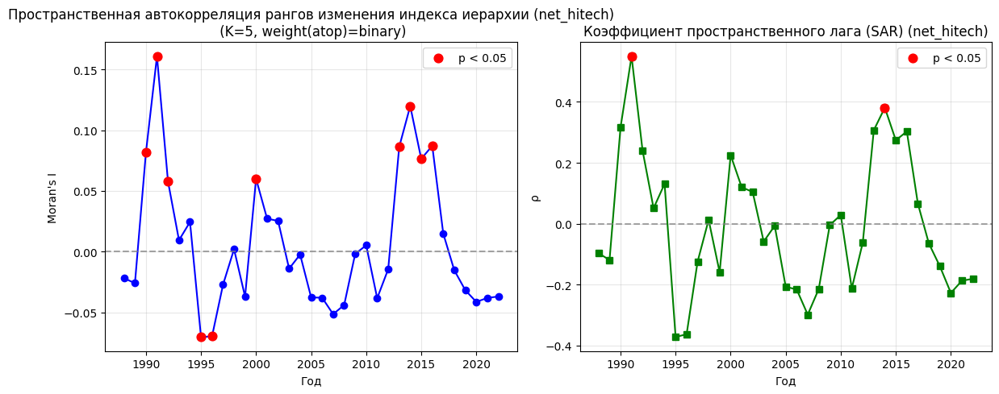

INFO:root:Starting spatial analysis for atop_nato with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


(3,) None
                                     delta       lag
country_a                                           
Afghanistan                      -0.000012  0.000000
Albania                          -0.000012 -0.000568
Algeria                          -0.000012  0.000000
Andorra                          -0.000010  0.000000
Angola                           -0.000008  0.000000
Antigua and Barbuda              -0.000011  0.000000
Argentina                        -0.000107  0.000000
Armenia                          -0.000006  0.000000
Australia                        -0.000005  0.000000
Austria                           0.000025  0.000000
Azerbaijan                       -0.000007  0.000000
Bahamas                          -0.000042  0.000000
Bahrain                          -0.000007  0.000000
Bangladesh                       -0.000012  0.000000
Barbados                         -0.000103  0.000000
Belarus                           0.000012  0.000000
Belgium                          -0.

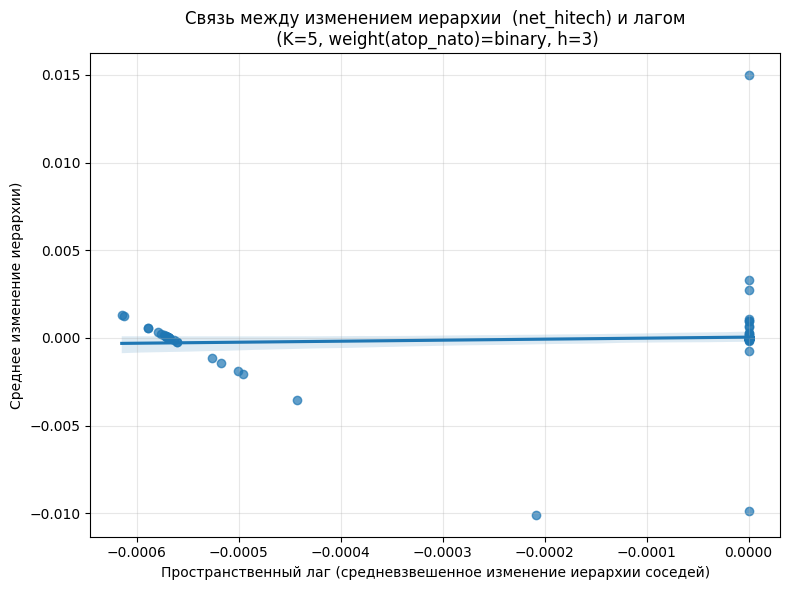

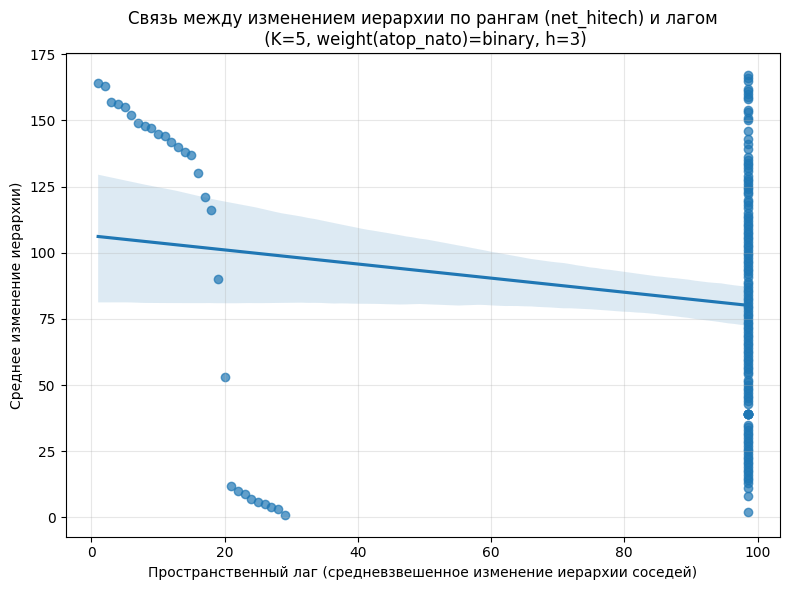

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0725, p-value = 0.3520
INFO:root:Спирмен: r = -0.1760, p-value = 0.0229
INFO:root:=== Moran's I ===
INFO:root:I = 0.0504
INFO:root:p-value (перестановочный) = 0.0340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0058
INFO:root:p-value (перестановочный) = 0.2330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:Moran's I для бинарной переменной: 0.3599, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:year is 1985
INFO:root:year is 1986
INFO:root:year is 1987
INFO:root:year is 1988
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.98, изолированных вершин = 120
INFO:root:year is 1989
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.98, изолированных вершин = 120
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.98, изолированных вершин = 120
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 3.00, изолированных вершин = 119
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (140, 140), средняя степень = 3.00, изолированных вершин = 119
INFO:root:year is 1993
INFO:root:Матрица смежности построена: (141, 141), средняя степень = 2.98, изолированных вершин = 120
INFO:root:year is 1994
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 3.85, изолированных вершин = 131
INFO:root:year is 1995
INFO:root:Матрица смежности постр

Нет данных для построения графиков.


In [969]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['atop','atop_nato']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            remove_isolates=False  # Они и так убираются, просто на другом этапе. Диагностический параметр
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [971]:
print_spatial_results(results, 'atop','atop_nato')

athlas Moran's I=0.101** (atop)
athlas binary Moran's I=0.119** (atop)
athlas Moran's I=0.276** (atop_nato)
athlas binary Moran's I=0.115* (atop_nato)
gpi Moran's I=-0.103** (atop)
gpi binary Moran's I=0.009 (atop)
gpi Moran's I=0.087* (atop_nato)
gpi binary Moran's I=0.292** (atop_nato)
cinc Moran's I=0.34** (atop)
cinc binary Moran's I=0.368** (atop)
cinc Moran's I=0.983** (atop_nato)
cinc binary Moran's I=0.982** (atop_nato)
gdp Moran's I=0.203** (atop)
gdp binary Moran's I=0.0 (atop)
gdp Moran's I=0.307** (atop_nato)
gdp binary Moran's I=0.025 (atop_nato)
net_subsystem Moran's I=0.114** (atop)
net_subsystem binary Moran's I=0.273** (atop)
net_subsystem Moran's I=0.312** (atop_nato)
net_subsystem binary Moran's I=0.639** (atop_nato)
net Moran's I=0.115** (atop)
net binary Moran's I=0.242** (atop)
net Moran's I=0.348** (atop_nato)
net binary Moran's I=0.571** (atop_nato)
gdp_beckley Moran's I=0.487** (atop)
gdp_beckley binary Moran's I=0.015 (atop)
gdp_beckley Moran's I=0.931** (atop

In [1026]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['atop', 'atop_nato']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

INFO:root:Фильтр по годам: [1985, 1986, 1987, 1988, 1995, 1996, 1997, 1998, 1989, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2010, 2011, 2012, 2013] (n=26)
INFO:root:Starting Moran for atop / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17
INFO:root:=== Moran's I ===
INFO:root:I = -0.0895
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0497
INFO:root:p-value (перестановочный) = 0.0510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[athlas/atop] Moran (binary): I = 0.0581, p_sim = 0.0

(1,) None
('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', '

INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136
INFO:root:=== Moran's I ===
INFO:root:I = 0.0567
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2257
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[athlas/atop_nato] Moran (binary): I = 0.1340, p_sim = 0.0200
INFO:root:Starting Moran for atop / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), сред

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130
INFO:root:=== Moran's I ===
INFO:root:I = 0.1118
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1390
INFO:root:p-value (перестановочный) = 0.0210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gpi/atop_nato] Moran (binary): I = 0.1077, p_sim = 0.0370
INFO:root:Starting Moran for atop / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средня

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNING: ', 'Bolivia (Plurinational State of)', ' is an island (no neighbors)')
('WARNING: ', 'Bosnia and Herzegovina', ' is an isla

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138
INFO:root:=== Moran's I ===
INFO:root:I = 0.0350
INFO:root:p-value (перестановочный) = 0.0370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.7709
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/atop_nato] Moran (binary): I = 0.5503, p_sim = 0.0010
INFO:root:Starting Moran for atop / gdp
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 163
INFO:root:Матрица смежности построена: (163, 163), средня

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 163
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.98, изолированных вершин = 134
INFO:root:=== Moran's I ===
INFO:root:I = -0.0013
INFO:root:p-value (перестановочный) = 0.4420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3781
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/atop_nato] Moran (binary): I = 0.0188, p_sim = 0.4410
INFO:root:Starting Moran for atop / net_subsystem
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Mora

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138
INFO:root:=== Moran's I ===
INFO:root:I = -0.0814
INFO:root:p-value (перестановочный) = 0.0150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0655
INFO:root:p-value (перестановочный) = 0.0640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[net_subsystem/atop_nato] Moran (binary): I = 0.3825, p_sim = 0.0010
INFO:root:Starting Moran for atop / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17
INFO:root:=== Mora

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138
INFO:root:=== Moran's I ===
INFO:root:I = -0.0122
INFO:root:p-value (перестановочный) = 0.3050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1479
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/atop_nato] Moran (binary): I = 0.4044, p_sim = 0.0010
INFO:root:Starting Moran for atop / gdp_beckley
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 163
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 21.25, изолированных вершин = 18
INFO:root:=== Moran'

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 163
INFO:root:Матрица смежности построена: (163, 163), средняя степень = 4.98, изолированных вершин = 134
INFO:root:=== Moran's I ===
INFO:root:I = 0.0904
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.9749
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/atop_nato] Moran (binary): I = 0.0382, p_sim = 0.3020
INFO:root:Starting Moran for atop / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена:

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130
INFO:root:=== Moran's I ===
INFO:root:I = 0.1107
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.7522
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/atop_nato] Moran (binary): I = 0.0192, p_sim = 0.4920
INFO:root:Starting Moran for atop / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: 

('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138
INFO:root:=== Moran's I ===
INFO:root:I = 0.0105
INFO:root:p-value (перестановочный) = 0.1260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.0258
INFO:root:p-value (перестановочный) = 0.4020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[net_hitech/atop_nato] Moran (binary): I = 0.1017, p_sim = 0.0370


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

In [1027]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_atop_stableyears.csv')
table

,I Морана для псевдососедства по военным альянсам,Бинарный I Морана (по знаку) для псевдососедства по военным альянсам,I Морана для псевдососедства по НАТО,Бинарный I Морана (по знаку) для псевдососедства по НАТО
Индекс положения в иерархии,,,,
Индекс национальной мощи,"-0,090**","0,058*","0,057*","0,134*"
Глобальный индекс власти,"0,005n/a","0,013n/a","0,112**","0,108*"
Индекс CINC,"-0,226**","0,226**","0,035*","0,550**"
ВВП (номинал),"0,155**","0,038*","-0,001n/a","0,019n/a"
Системно-сетевой индекс,"-0,264**","0,202**","-0,012n/a","0,404**"
Индекс Бэкли,"0,052**","0,012n/a","0,090**","0,038n/a"
Индекс Бэкли (ППС),"0,112**","-0,021n/a","0,111**","0,019n/a"


INFO:root:Фильтр по годам: [1989, 1990, 1991, 1992, 1993, 1994, 2008, 2009, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022] (n=17)
INFO:root:Starting Moran for atop / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 21.26, изолированных вершин = 17


                                                country      value  year  \
0                                         United States  14.015760  1991   
1                                                 Japan   4.769256  1991   
2     United Kingdom of Great Britain and Northern I...   2.755997  1991   
3                                               Germany   2.553649  1991   
4                                    Russian Federation   4.653323  1991   
...                                                 ...        ...   ...   
5596                                             Monaco  -0.269849  2020   
5597                                   Marshall Islands  -0.269910  2020   
5598                                             Tuvalu  -0.270004  2020   
5599                                            Andorra  -0.270760  2020   
5600                                           Kiribati  -0.270797  2020   

       rank  
0       1.0  
1       2.0  
2       4.0  
3       5.0  
4       3.0  
...

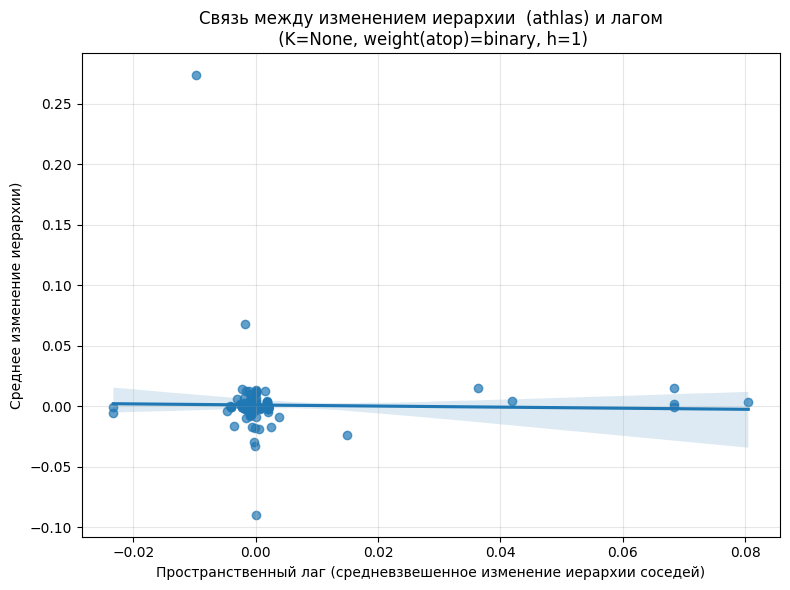

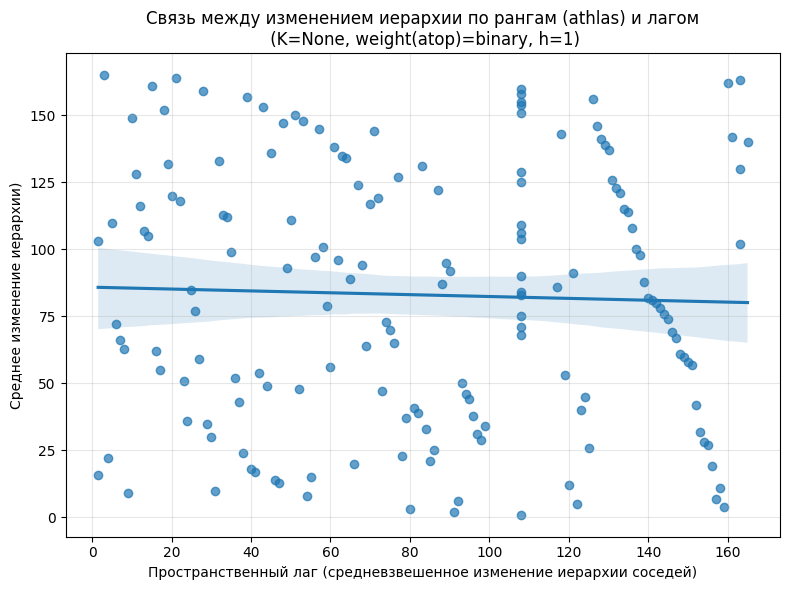

INFO:root:=== Moran's I ===
INFO:root:I = -0.0137
INFO:root:p-value (перестановочный) = 0.2580
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0498
INFO:root:p-value (перестановочный) = 0.0400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[athlas/atop] Moran (binary): I = 0.0155, p_sim = 0.2600
INFO:root:Starting Moran for atop_nato / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 165
INFO:root:Матрица смежности построена: (165, 165), средняя степень = 4.92, изолированных вершин = 136


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

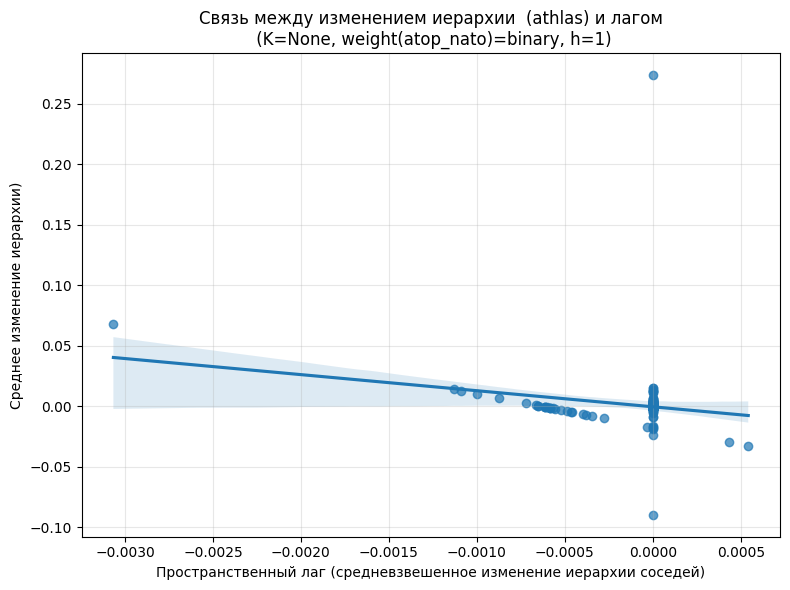

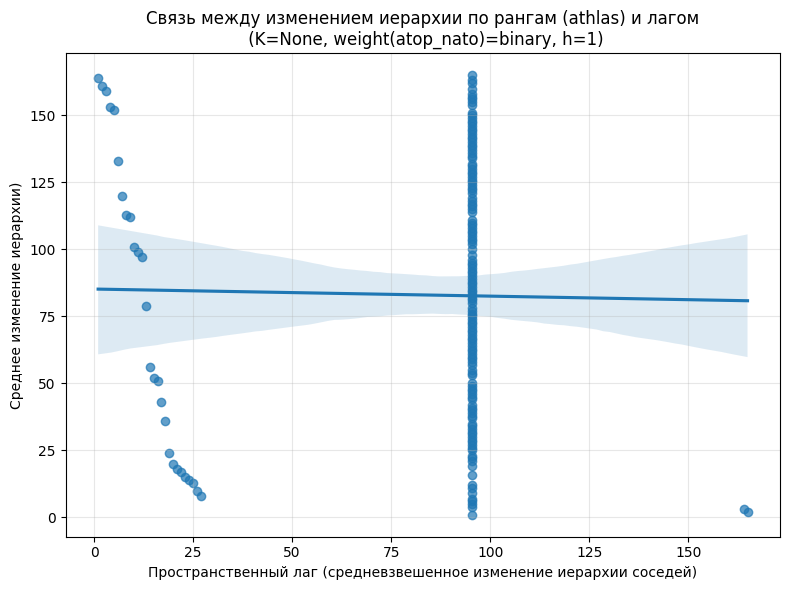

INFO:root:=== Moran's I ===
INFO:root:I = -0.0120
INFO:root:p-value (перестановочный) = 0.1640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0275
INFO:root:p-value (перестановочный) = 0.1330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[athlas/atop_nato] Moran (binary): I = -0.0303, p_sim = 0.3540
INFO:root:Starting Moran for atop / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 20.53, изолированных вершин = 15


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

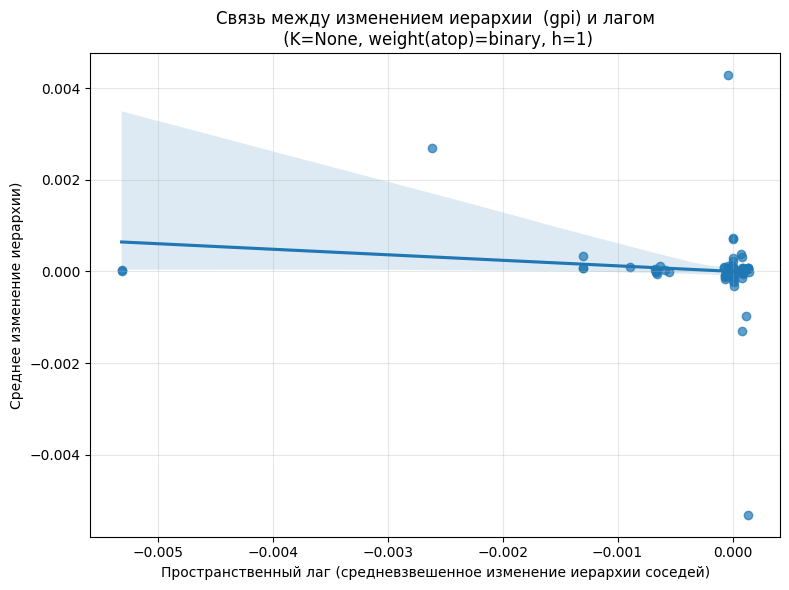

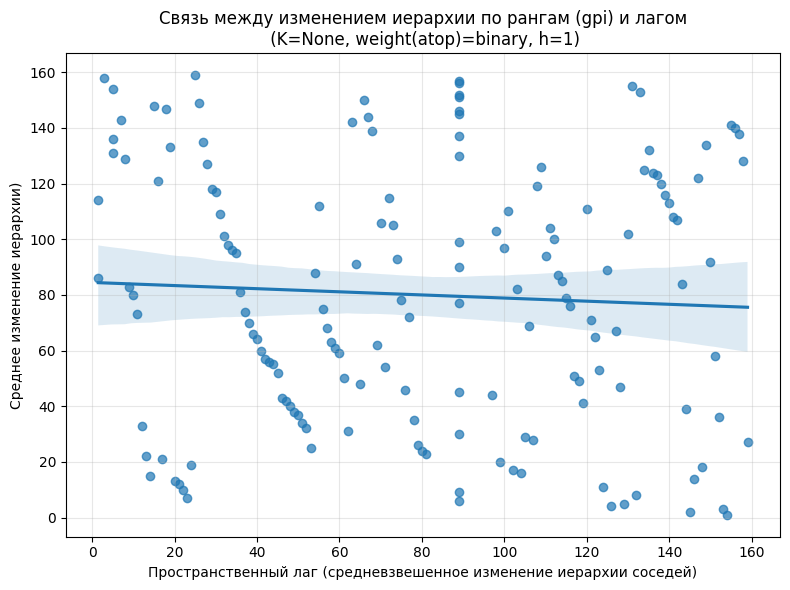

INFO:root:=== Moran's I ===
INFO:root:I = -0.1599
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.0563
INFO:root:p-value (перестановочный) = 0.0370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gpi/atop] Moran (binary): I = -0.0082, p_sim = 0.4910
INFO:root:Starting Moran for atop_nato / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 159
INFO:root:Матрица смежности построена: (159, 159), средняя степень = 5.11, изолированных вершин = 130


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam', ' is an island (no neighbors)')
('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Bang

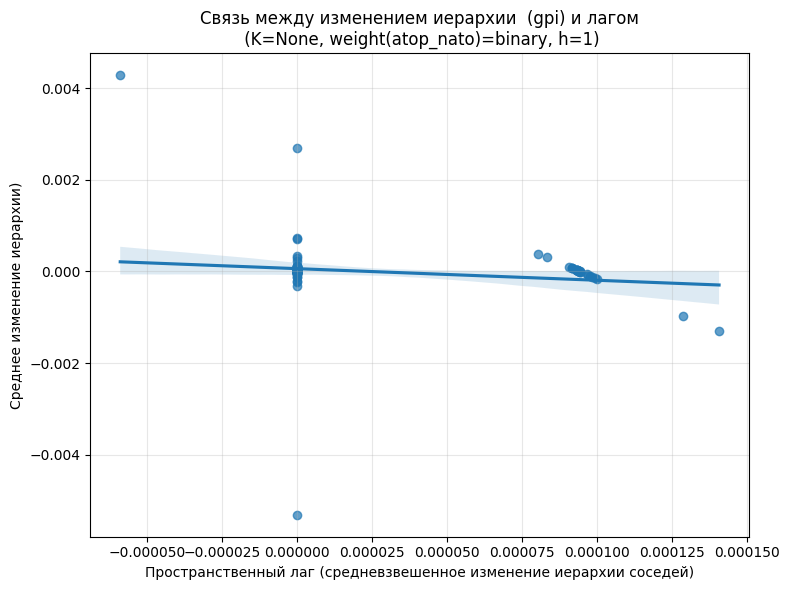

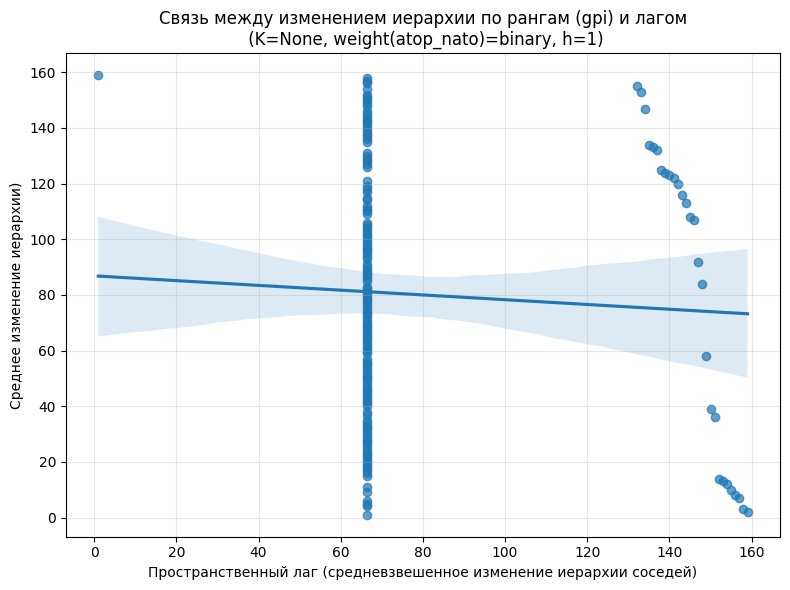

INFO:root:=== Moran's I ===
INFO:root:I = -0.0570
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.0419
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gpi/atop_nato] Moran (binary): I = -0.0080, p_sim = 0.3710
INFO:root:Starting Moran for atop / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNING: ', 'Bolivia (Plurinational State of)', ' is an island (no neighbors)')
('WARNING: ', 'Bosnia and Herzegovina', ' is an isla

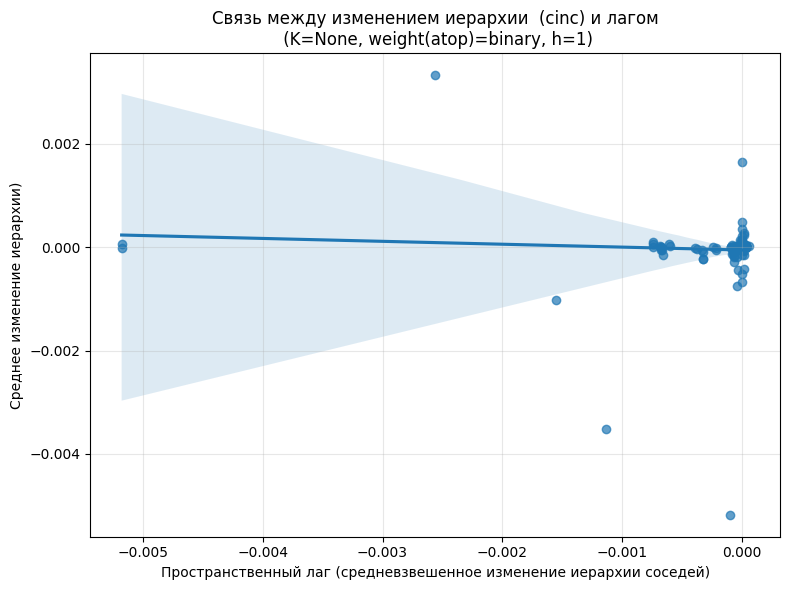

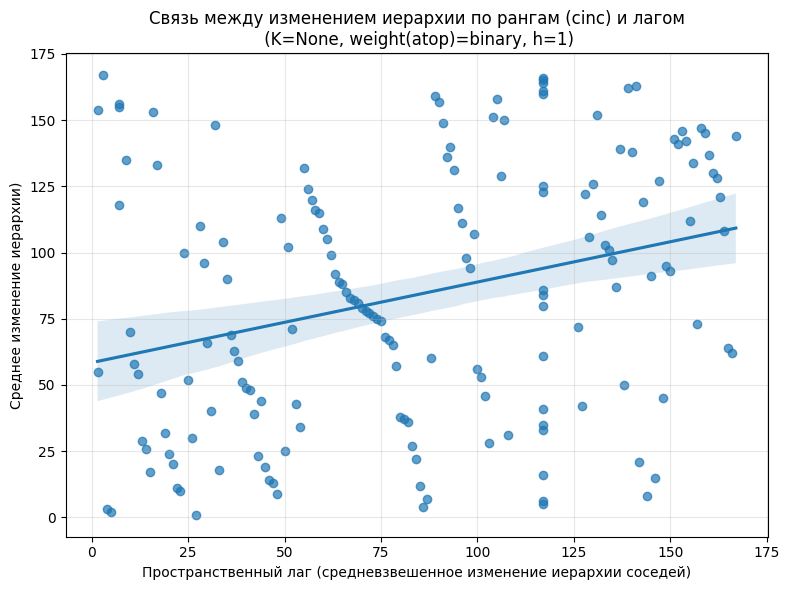

INFO:root:=== Moran's I ===
INFO:root:I = -0.0743
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2238
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/atop] Moran (binary): I = 0.2011, p_sim = 0.0010
INFO:root:Starting Moran for atop_nato / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

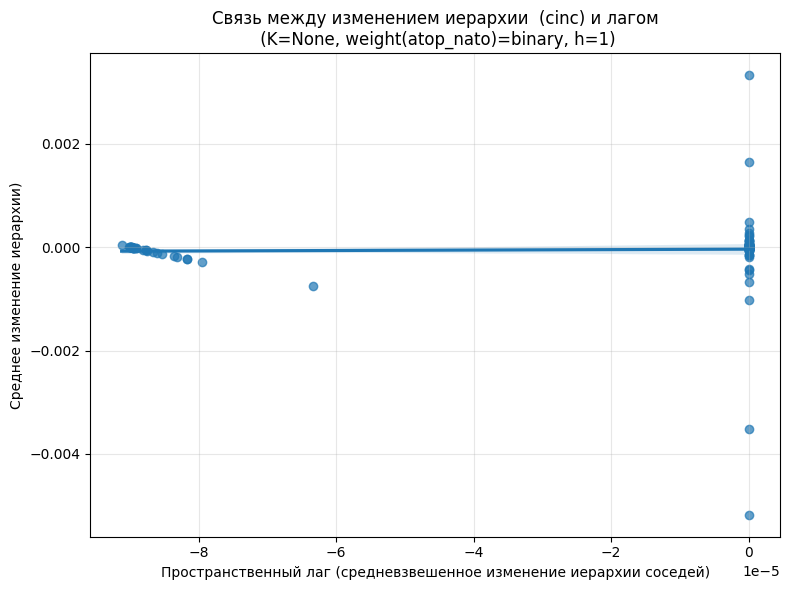

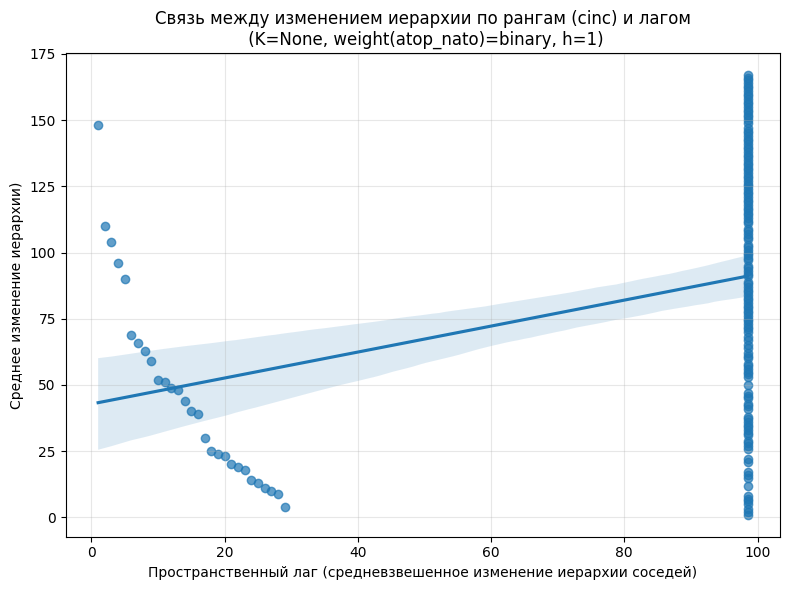

INFO:root:=== Moran's I ===
INFO:root:I = 0.0024
INFO:root:p-value (перестановочный) = 0.3430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.5868
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/atop_nato] Moran (binary): I = 0.3709, p_sim = 0.0010
INFO:root:Starting Moran for atop / gdp
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.35, изолированных вершин = 18


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

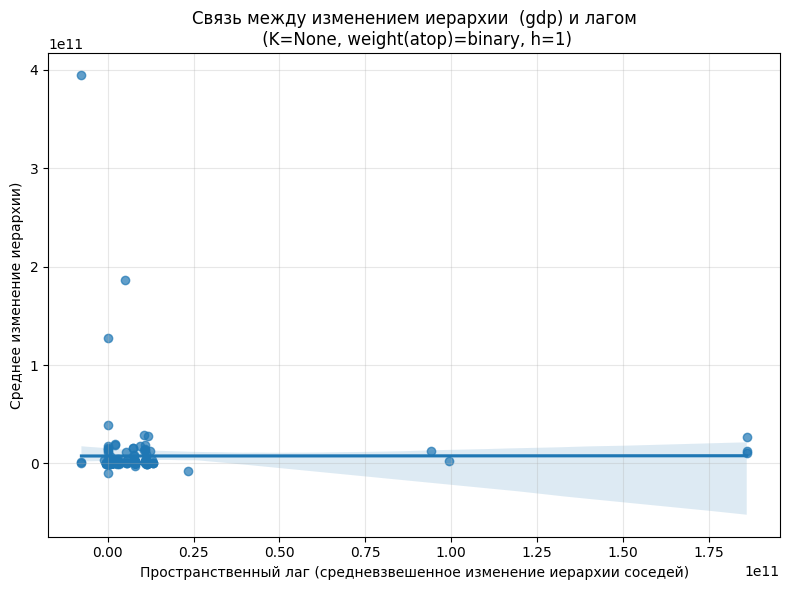

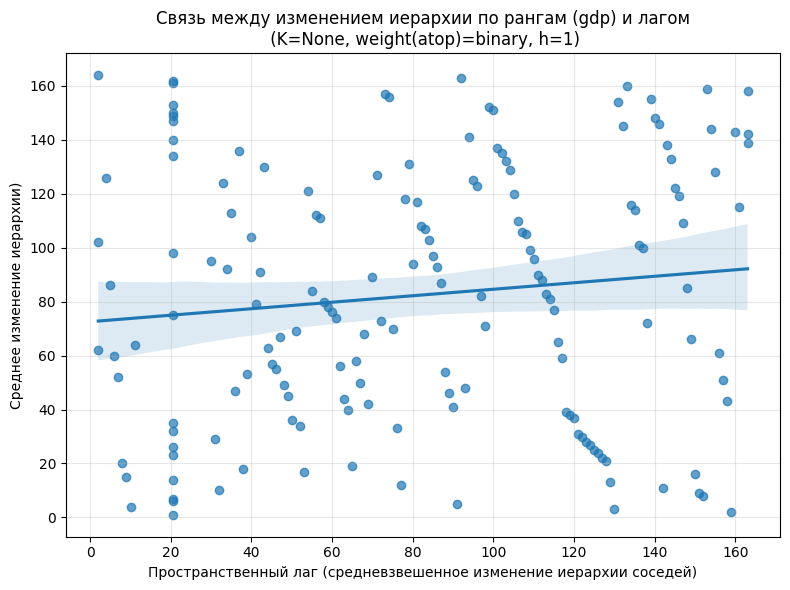

INFO:root:=== Moran's I ===
INFO:root:I = 0.0050
INFO:root:p-value (перестановочный) = 0.1940
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1287
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/atop] Moran (binary): I = 0.0270, p_sim = 0.1100
INFO:root:Starting Moran for atop_nato / gdp
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Cuba', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' i

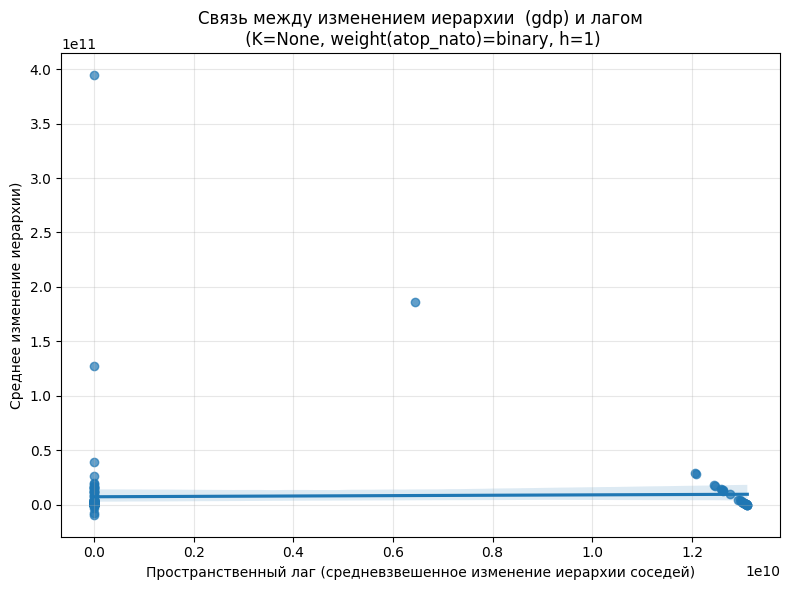

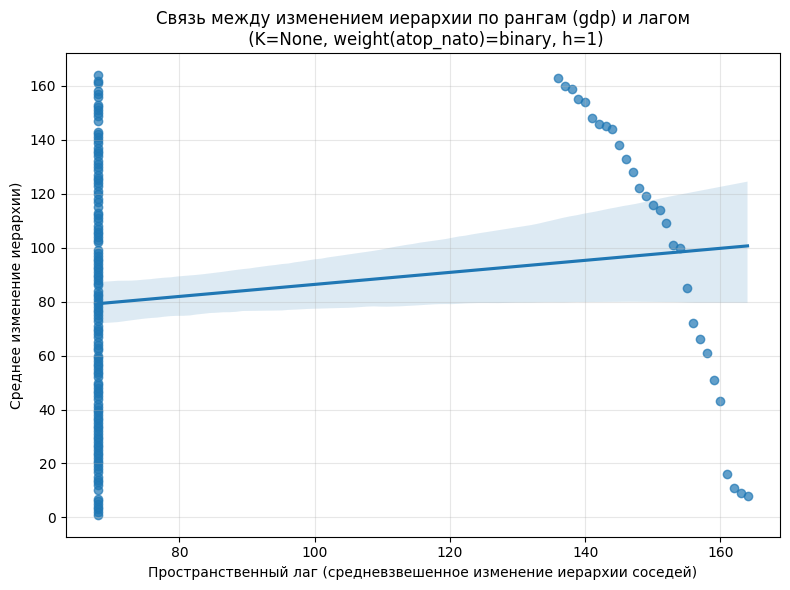

INFO:root:=== Moran's I ===
INFO:root:I = -0.0121
INFO:root:p-value (перестановочный) = 0.3960
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1417
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/atop_nato] Moran (binary): I = -0.0364, p_sim = 0.0030
INFO:root:Starting Moran for atop / net_subsystem
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

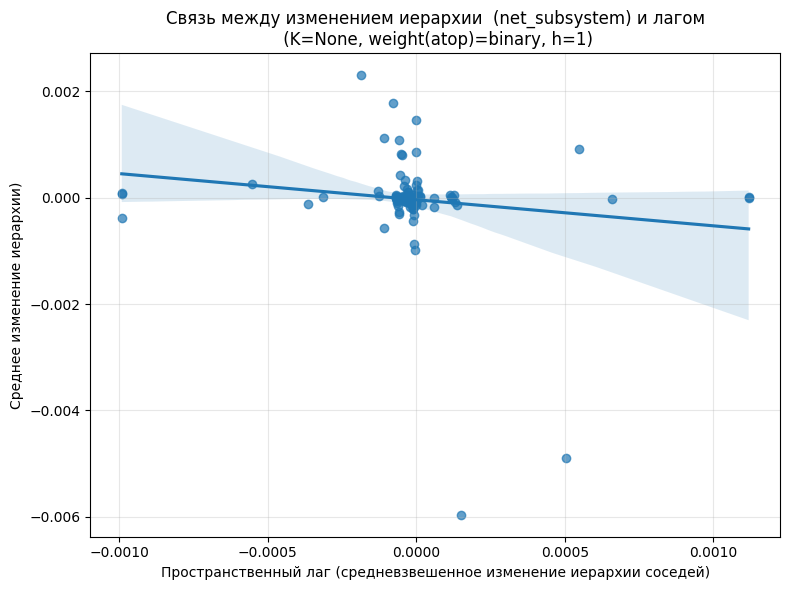

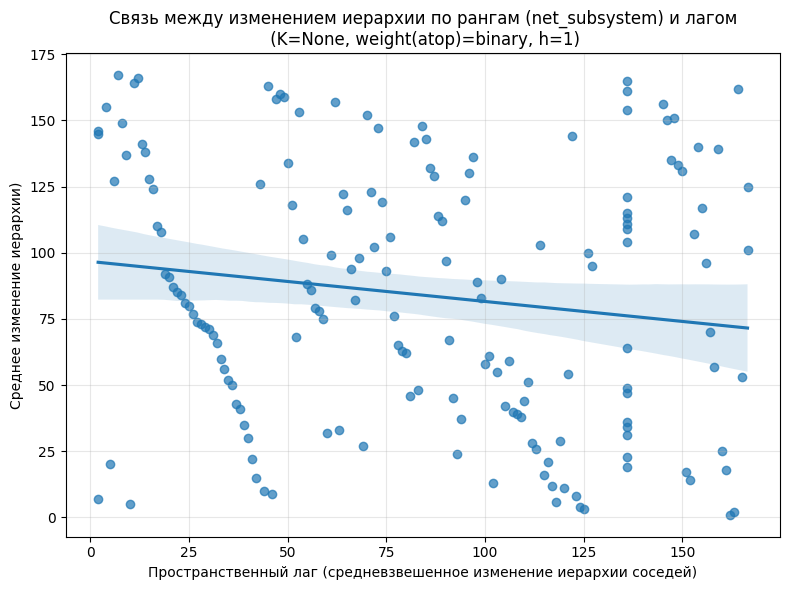

INFO:root:=== Moran's I ===
INFO:root:I = -0.0517
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0477
INFO:root:p-value (перестановочный) = 0.0540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[net_subsystem/atop] Moran (binary): I = 0.1540, p_sim = 0.0010
INFO:root:Starting Moran for atop_nato / net_subsystem
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

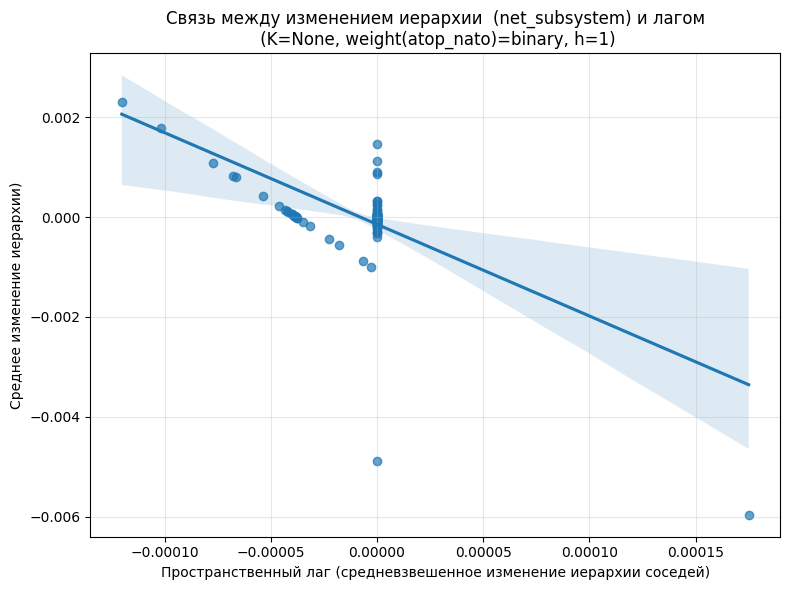

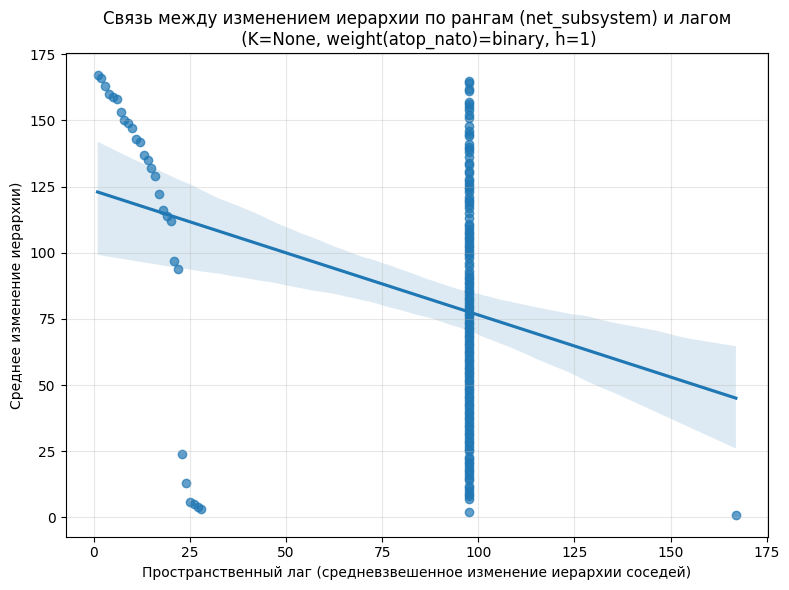

INFO:root:=== Moran's I ===
INFO:root:I = -0.1274
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1729
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_subsystem/atop_nato] Moran (binary): I = 0.4441, p_sim = 0.0010
INFO:root:Starting Moran for atop / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

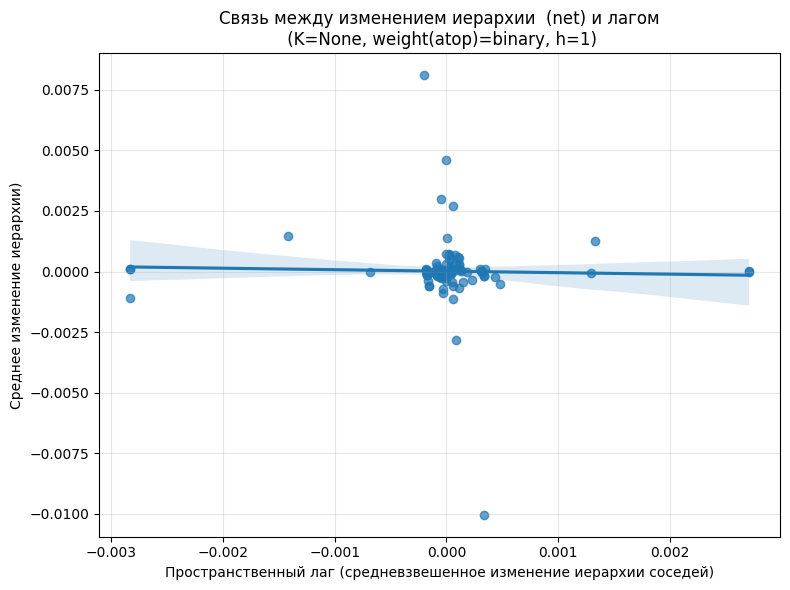

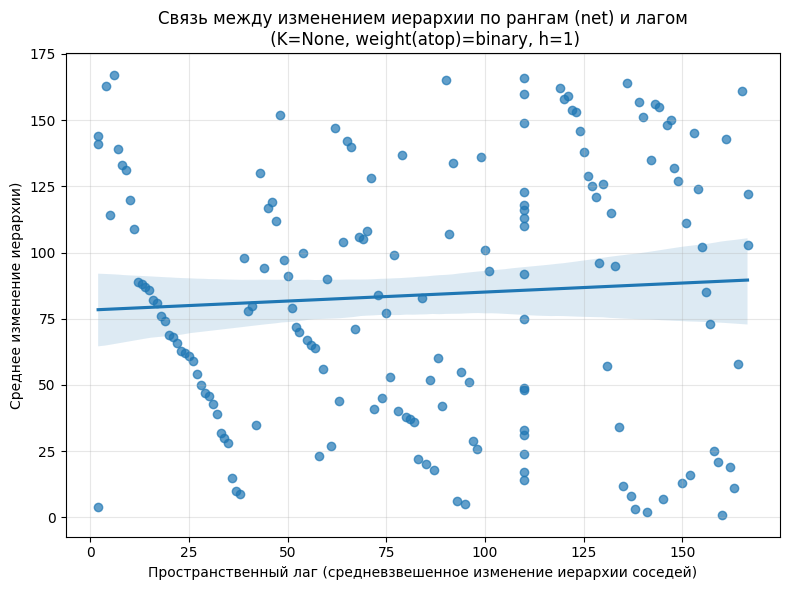

INFO:root:=== Moran's I ===
INFO:root:I = -0.0139
INFO:root:p-value (перестановочный) = 0.3250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0657
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/atop] Moran (binary): I = 0.1479, p_sim = 0.0010
INFO:root:Starting Moran for atop_nato / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

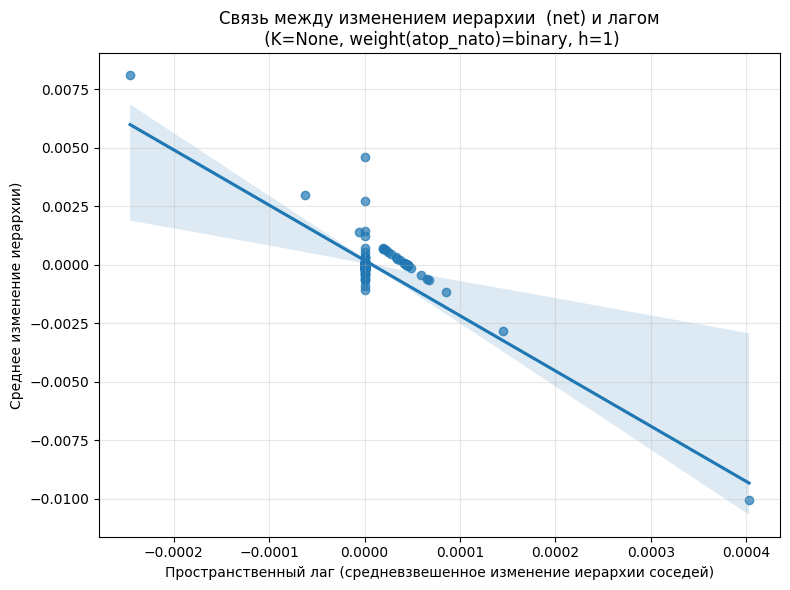

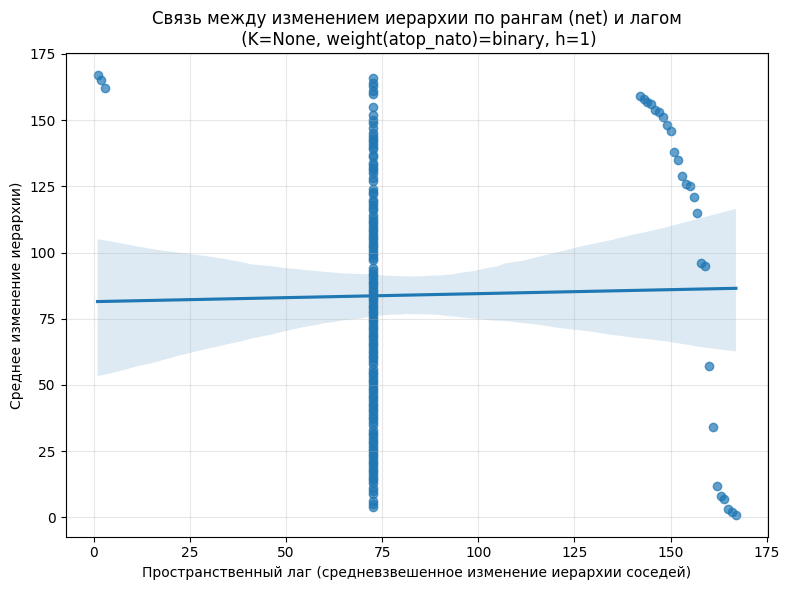

INFO:root:=== Moran's I ===
INFO:root:I = -0.1707
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1577
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/atop_nato] Moran (binary): I = 0.4070, p_sim = 0.0010
INFO:root:Starting Moran for atop / gdp_beckley
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 21.35, изолированных вершин = 18


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

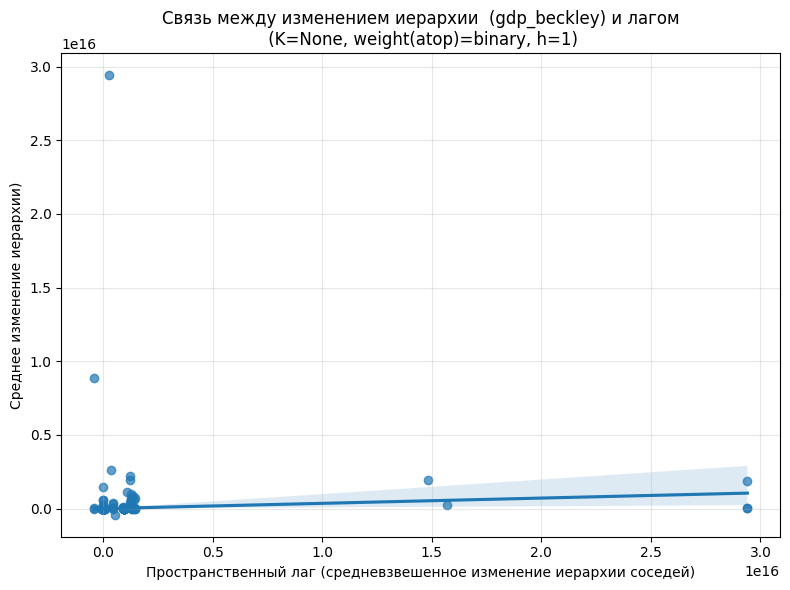

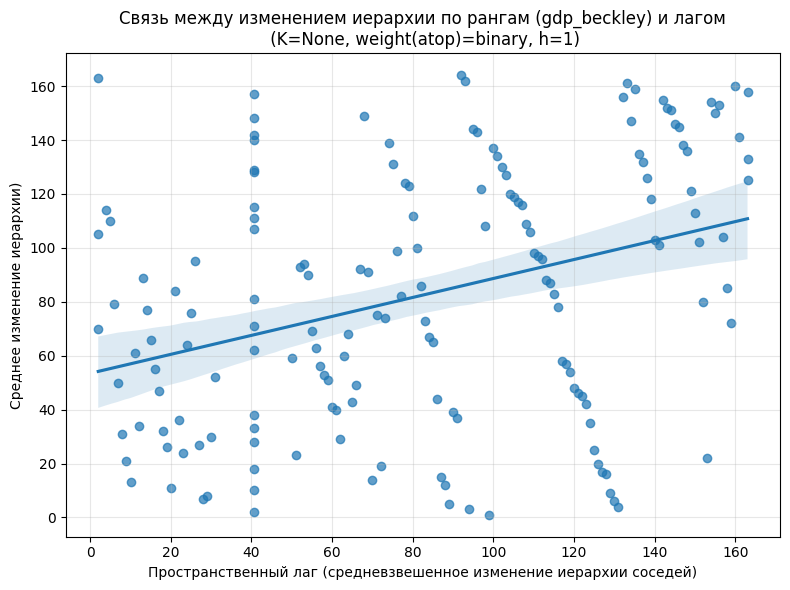

INFO:root:=== Moran's I ===
INFO:root:I = 0.0482
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3586
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/atop] Moran (binary): I = 0.0297, p_sim = 0.1000
INFO:root:Starting Moran for atop_nato / gdp_beckley
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 164
INFO:root:Матрица смежности построена: (164, 164), средняя степень = 4.95, изолированных вершин = 135


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Cuba', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' i

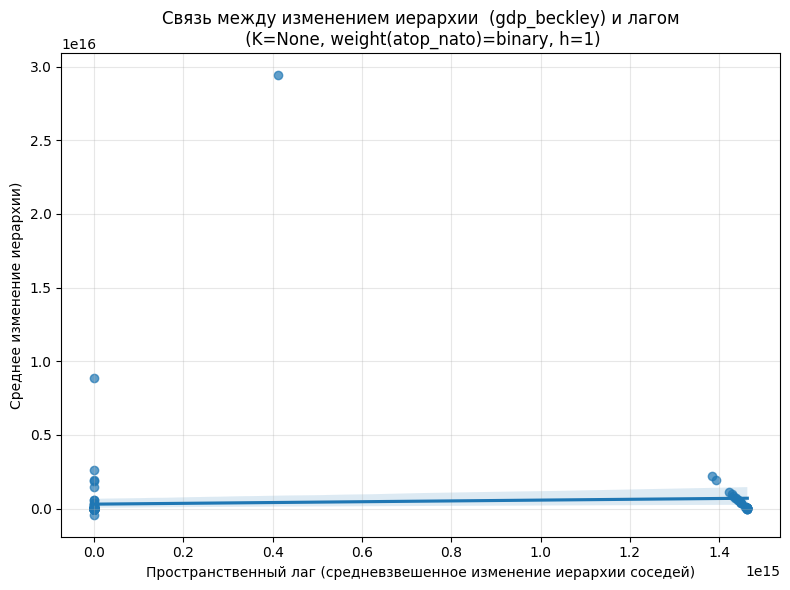

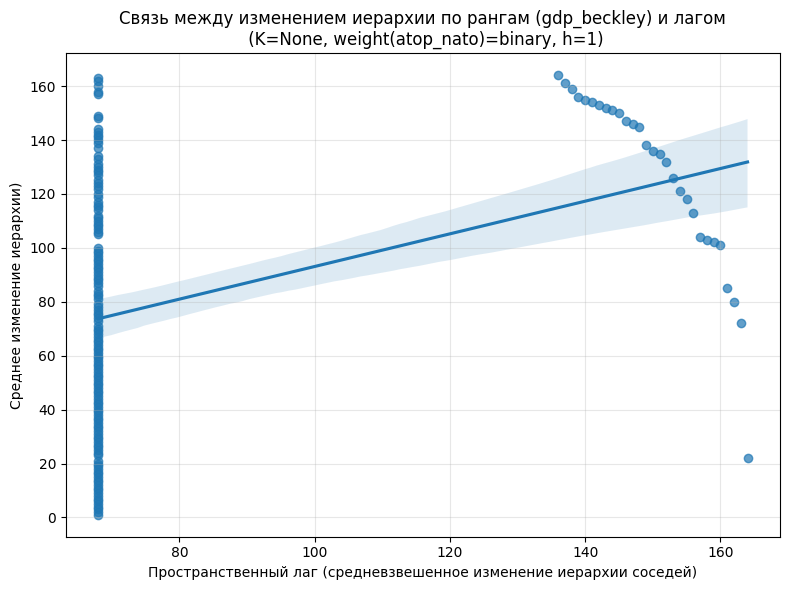

INFO:root:=== Moran's I ===
INFO:root:I = 0.0127
INFO:root:p-value (перестановочный) = 0.2230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.8641
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/atop_nato] Moran (binary): I = 0.1567, p_sim = 0.0130
INFO:root:Starting Moran for atop / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

INFO:root:Стран, по которым есть расстояния и дельты: 160
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 21.11, изолированных вершин = 17


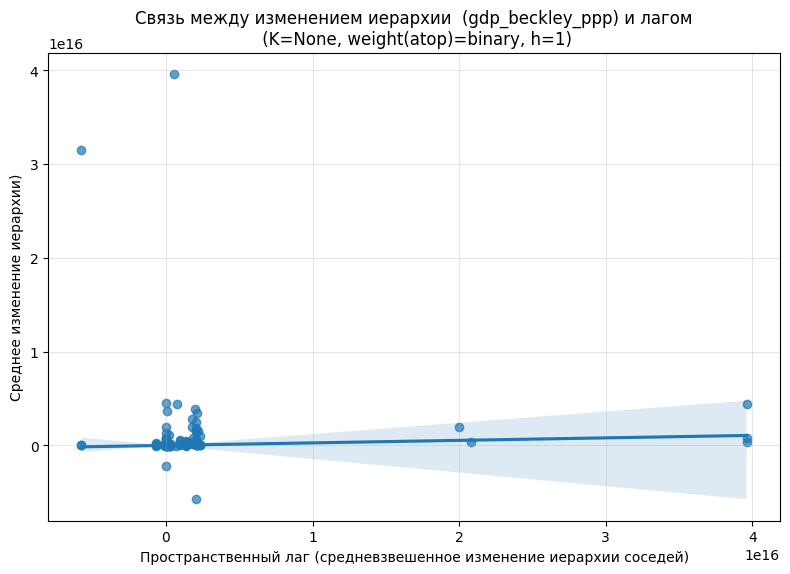

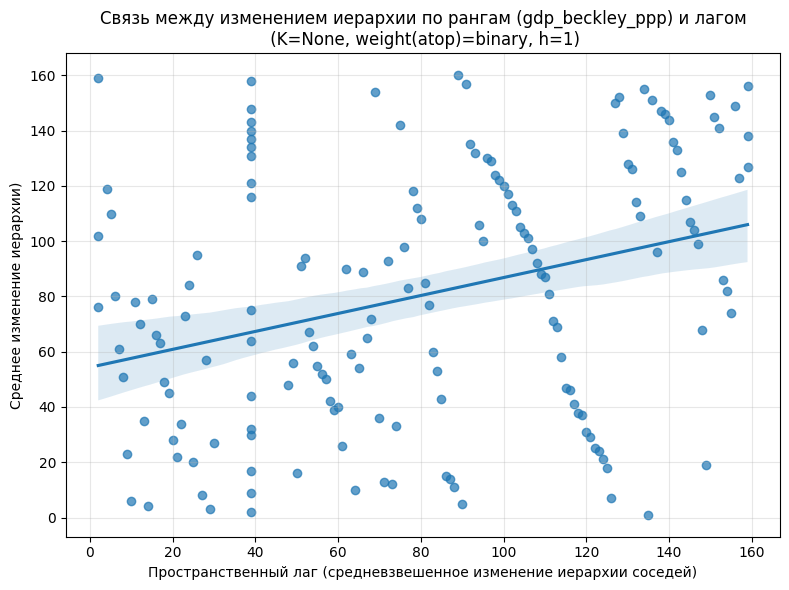

INFO:root:=== Moran's I ===
INFO:root:I = -0.0162
INFO:root:p-value (перестановочный) = 0.3000
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3352
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/atop] Moran (binary): I = 0.0033, p_sim = 0.3070
INFO:root:Starting Moran for atop_nato / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 160
INFO:root:Матрица смежности построена: (160, 160), средняя степень = 5.08, изолированных вершин = 131


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

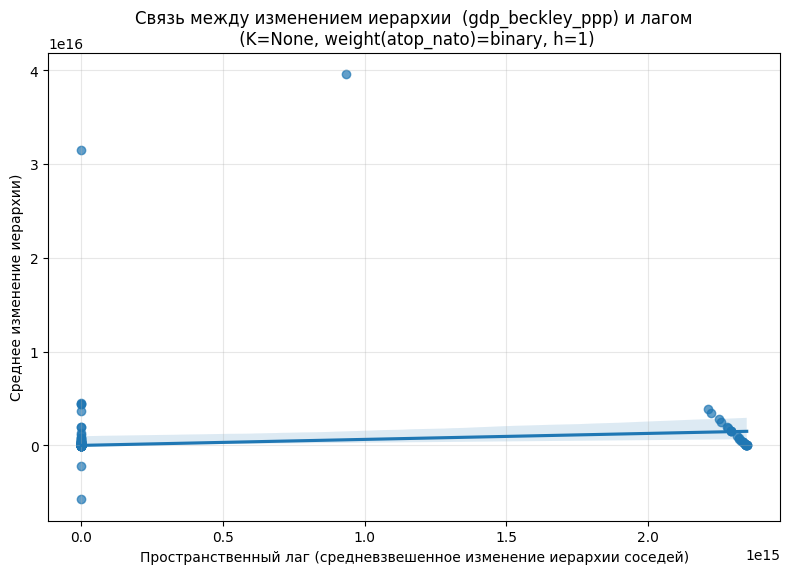

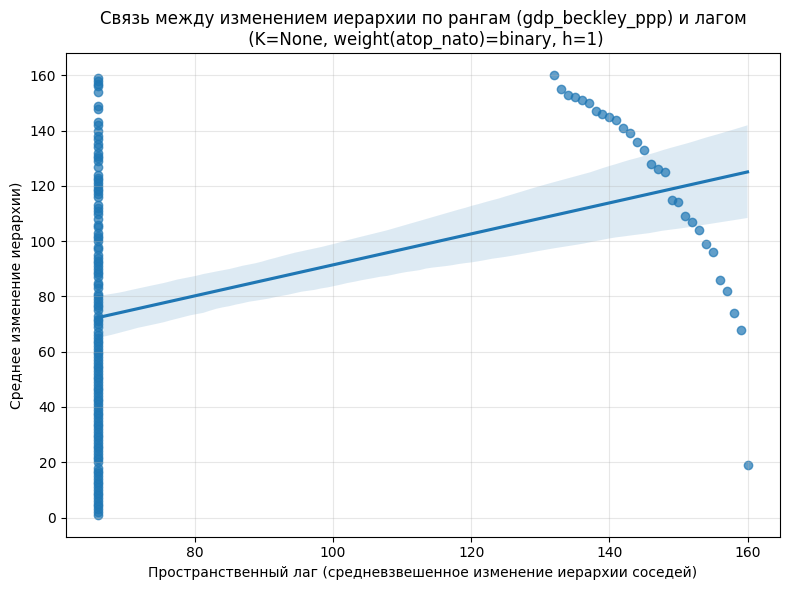

INFO:root:=== Moran's I ===
INFO:root:I = 0.0271
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.7451
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0063
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/atop_nato] Moran (binary): I = 0.1371, p_sim = 0.0270
INFO:root:Starting Moran for atop / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 21.14, изолированных вершин = 17


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

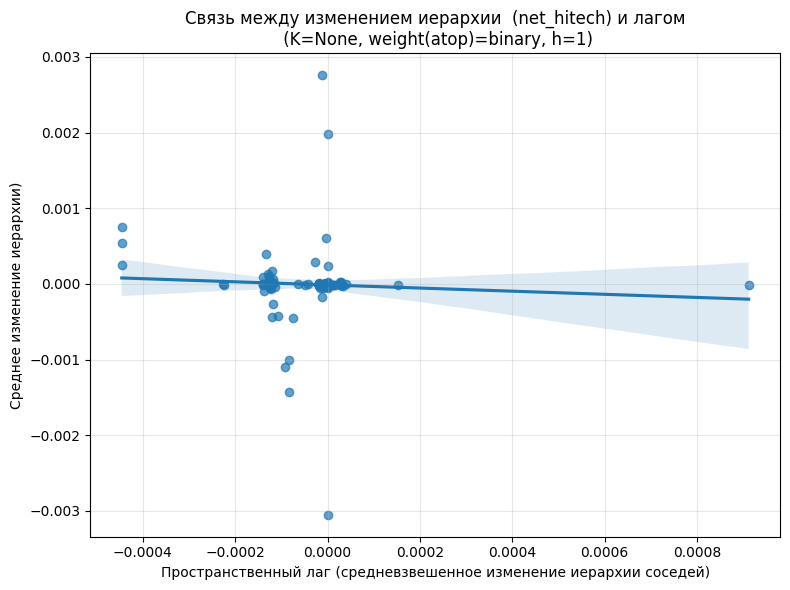

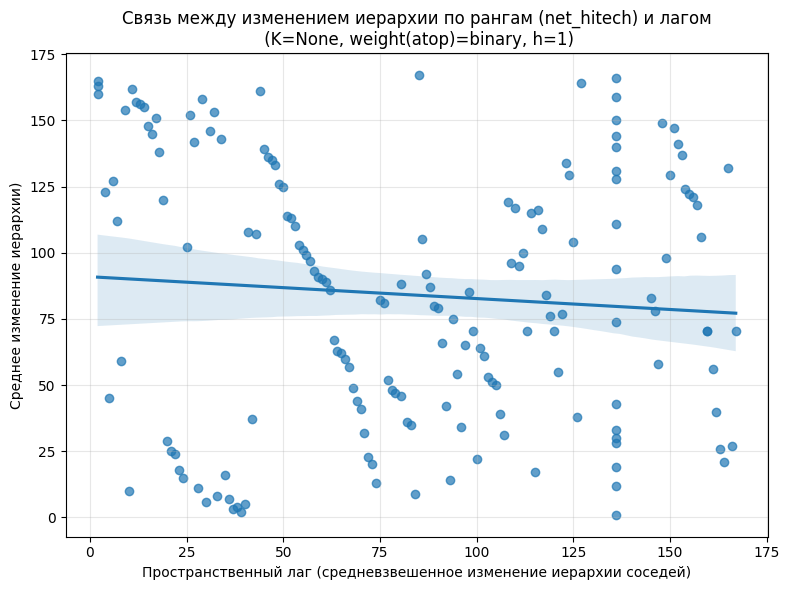

INFO:root:=== Moran's I ===
INFO:root:I = -0.0159
INFO:root:p-value (перестановочный) = 0.2870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.0031
INFO:root:p-value (перестановочный) = 0.4300
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[net_hitech/atop] Moran (binary): I = 0.1251, p_sim = 0.0020
INFO:root:Starting Moran for atop_nato / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 167
INFO:root:Матрица смежности построена: (167, 167), средняя степень = 4.86, изолированных вершин = 138


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'India', ' is an island (no neighbors)')
('WARNING: ', 'Indonesia', ' is an island (no neighbors)')
('WARNING: ', 'Iran, Islamic Republic of', ' is an island (no neighbors)')
('WARNING: ', 'Israel', ' is an island (no neighbors)')
('WARNING: ', 'Japan', ' is an island (no neighbors)')
('WARNING: ', 'Kiribati', ' is an island (no neighbors)')
('WARNING: ', 'Pakistan', ' is an island (no neighbors)')
('WARNING: ', 'Papua New Guinea', ' is an island (no neighbors)')
('WARNING: ', 'Republic of Moldova', ' is an island (no neighbors)')
('WARNING: ', 'Republic of North Macedonia', ' is an island (no neighbors)')
('WARNING: ', 'Serbia', ' is an island (no neighbors)')
('WARNING: ', 'Tuvalu', ' is an island (no neighbors)')
('WARNING: ', 'Ukraine', ' is an island (no neighbors)')
('WARNING: ', 'Viet Nam',

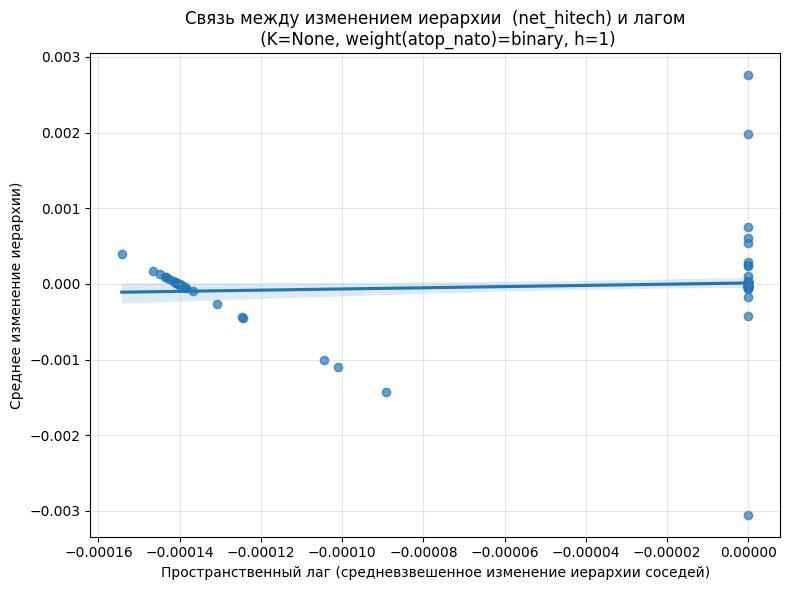

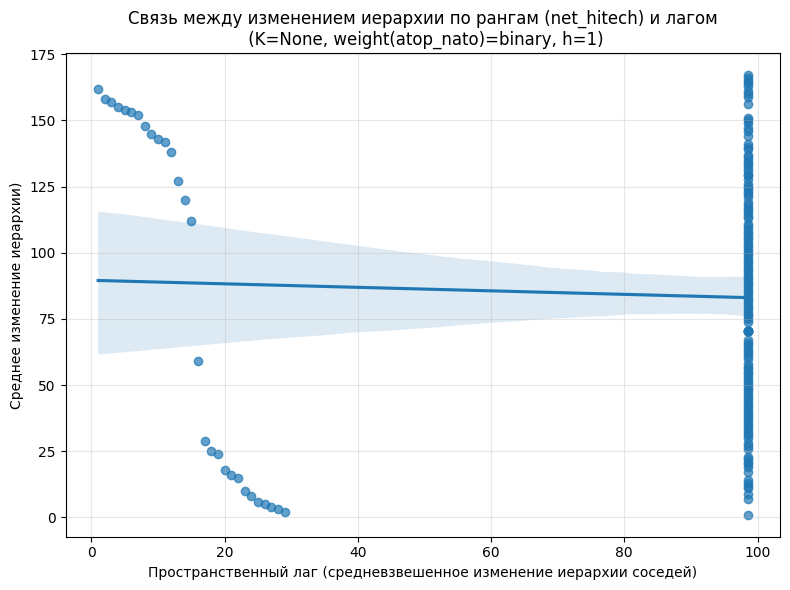

INFO:root:=== Moran's I ===
INFO:root:I = 0.0688
INFO:root:p-value (перестановочный) = 0.0190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = -0.0654
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_hitech/atop_nato] Moran (binary): I = 0.1640, p_sim = 0.0190


('WARNING: ', 'Afghanistan', ' is an island (no neighbors)')
('WARNING: ', 'Algeria', ' is an island (no neighbors)')
('WARNING: ', 'Andorra', ' is an island (no neighbors)')
('WARNING: ', 'Angola', ' is an island (no neighbors)')
('WARNING: ', 'Antigua and Barbuda', ' is an island (no neighbors)')
('WARNING: ', 'Argentina', ' is an island (no neighbors)')
('WARNING: ', 'Armenia', ' is an island (no neighbors)')
('WARNING: ', 'Australia', ' is an island (no neighbors)')
('WARNING: ', 'Austria', ' is an island (no neighbors)')
('WARNING: ', 'Azerbaijan', ' is an island (no neighbors)')
('WARNING: ', 'Bahamas', ' is an island (no neighbors)')
('WARNING: ', 'Bahrain', ' is an island (no neighbors)')
('WARNING: ', 'Bangladesh', ' is an island (no neighbors)')
('WARNING: ', 'Barbados', ' is an island (no neighbors)')
('WARNING: ', 'Belarus', ' is an island (no neighbors)')
('WARNING: ', 'Belize', ' is an island (no neighbors)')
('WARNING: ', 'Benin', ' is an island (no neighbors)')
('WARNIN

In [985]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
_years_filter = FILTER_YEARS['stableyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['atop', 'atop_nato']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue
        print(df_y_sub)

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        print(deltas)

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        lag_vector, delta_vector, W_matrix, country_names = get_spatial_lag(
        delta_vector, W_matrix, country_names)

        plot_spatial_lag(
            lag_vector, delta_vector,
            hierarchy_name=power,
            predictor_measure=predictor,
            k_neighbors=None,
            weight_type=weight_type,
            horizon=1,
            ranks=False,
            savename='testyearly.png'
        )
        plot_spatial_lag(
            lag_vector, delta_vector,
            hierarchy_name=power,
            predictor_measure=predictor,
            k_neighbors=None,
            weight_type=weight_type,
            horizon=1,
            ranks=True,
            savename='testyearly.png'
        )
        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [986]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_atop_turmoilyears.csv')
table

,I Морана для расстояния по популяционным центрам,Бинарный I Морана (по знаку) для расстояния по популяционным центрам,I Морана для соседства по юридическим границам,Бинарный I Морана (по знаку) для соседства по юридическим границам,I Морана для псевдососедства по военным альянсам,Бинарный I Морана (по знаку) для псевдососедства по военным альянсам,I Морана для псевдососедства по НАТО,Бинарный I Морана (по знаку) для псевдососедства по НАТО
Индекс положения в иерархии,,,,,,,,
Индекс национальной мощи,—,—,—,—,"-0,014n/a","0,016n/a","-0,012n/a","-0,030n/a"
Глобальный индекс власти,—,—,—,—,"-0,160**","-0,008n/a","-0,057†","-0,008n/a"
Индекс CINC,—,—,—,—,"-0,074**","0,201**","0,002n/a","0,371**"
ВВП (номинал),—,—,—,—,"0,005n/a","0,027n/a","-0,012n/a","-0,036**"
Системно-сетевой индекс,—,—,—,—,"-0,014n/a","0,148**","-0,171**","0,407**"
Индекс Бэкли,—,—,—,—,"0,048**","0,030n/a","0,013n/a","0,157*"
Индекс Бэкли (ППС),—,—,—,—,"-0,016n/a","0,003n/a","0,027†","0,137*"


### Гипотеза 1.3

INFO:root:Starting spatial analysis for rta with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0


(3,) None


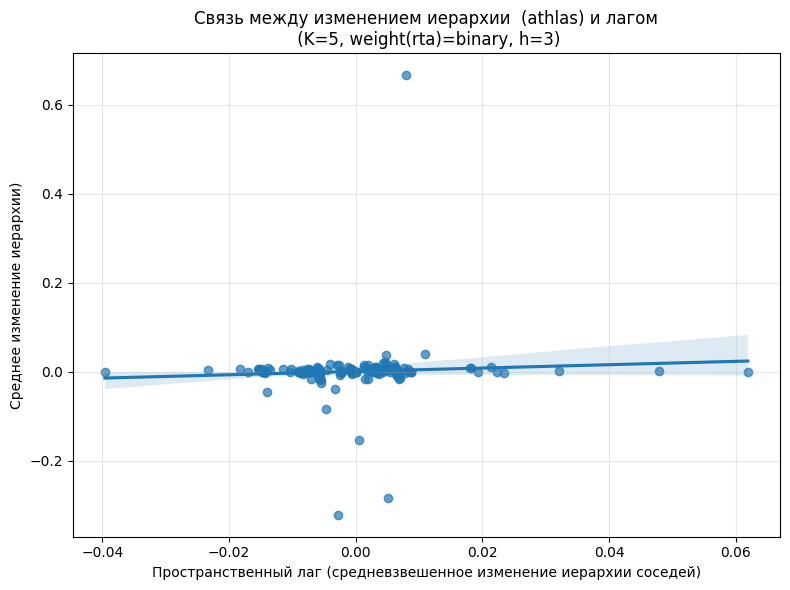

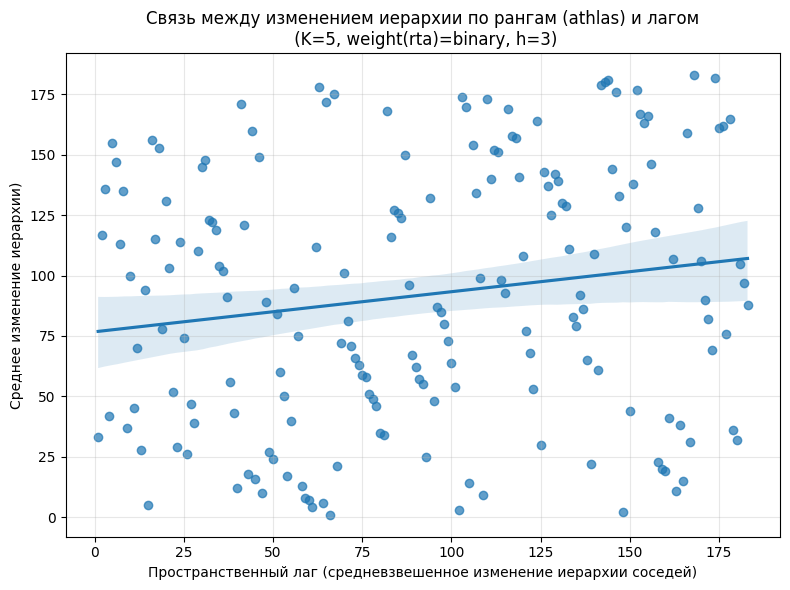

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0639, p-value = 0.3901
INFO:root:Спирмен: r = 0.1659, p-value = 0.0248
INFO:root:=== Moran's I ===
INFO:root:I = 0.0109
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1201
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0906, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.0793
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0548
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0325
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0042
INFO:root:p-value (перестановочный) = 0.4340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0166
INFO:root:p-value (перестановочный) = 0.2760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0128
INFO:root:p-value (перестановочный) = 0.3560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (183, 183), средняя степе

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0839
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0233
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0238
INFO:root:p-value (перестановочный) = 0.0610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0243
INFO:root:p-value (перестановочный) = 0.0520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0035
INFO:root:p-value (перестановочный) = 0.4050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0126
INFO:root:p-value (перестановочный) = 0.1510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0419
INFO:root:p-value (перестановочный) = 0.0090


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0306
INFO:root:p-value (перестановочный) = 0.0410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0139
INFO:root:p-value (перестановочный) = 0.1350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0564
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (183, 183),

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


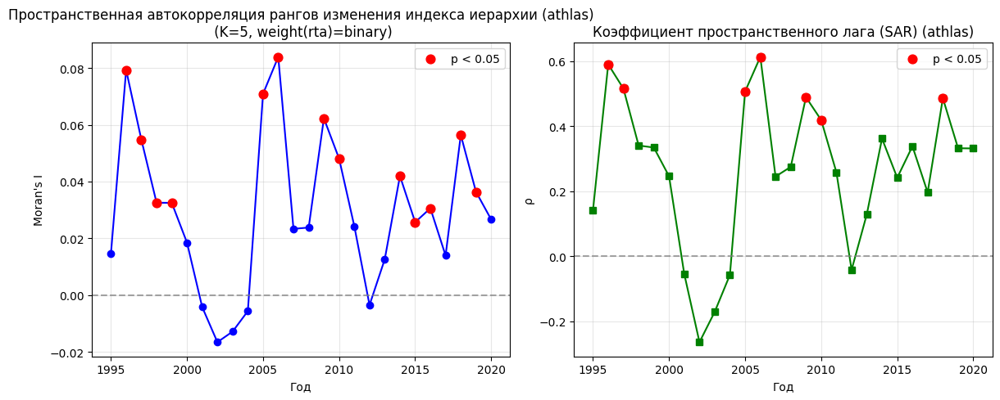

INFO:root:Starting spatial analysis for rta_eia with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


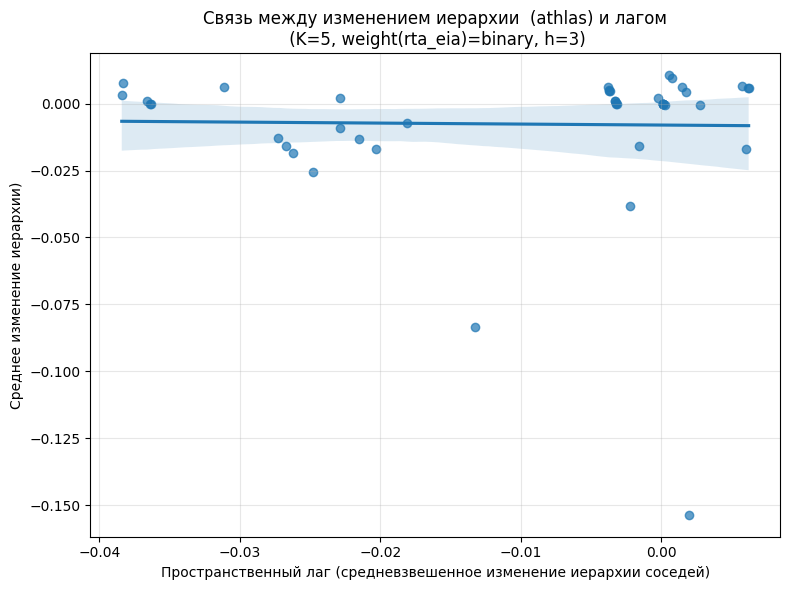

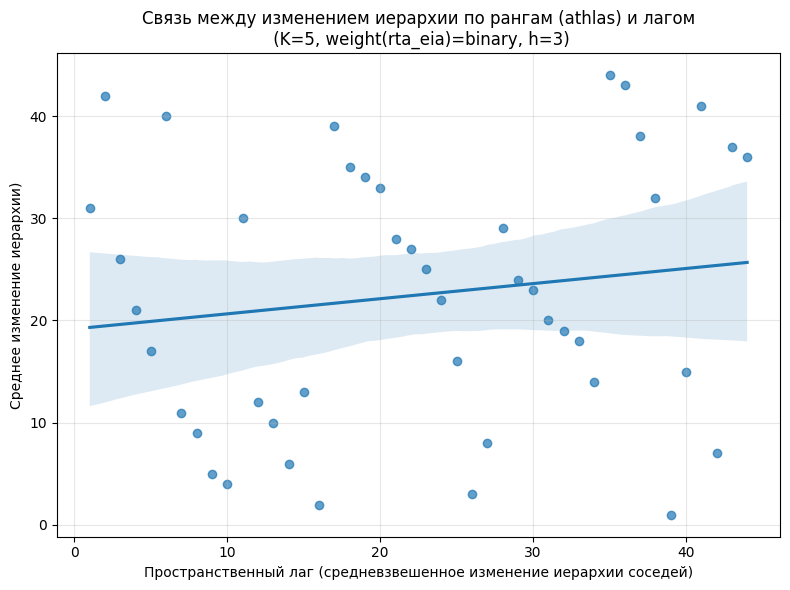

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0192, p-value = 0.9017
INFO:root:Спирмен: r = 0.1479, p-value = 0.3382
INFO:root:=== Moran's I ===
INFO:root:I = -0.0100
INFO:root:p-value (перестановочный) = 0.3200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2007
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1607, p = 0.0500
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.1150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1226
INFO:root:p-value (перестановочный) = 0.0780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2367
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2647
INF

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2013
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2316
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1720
INFO:root:p-value (перестановочный) = 0.0360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2590
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


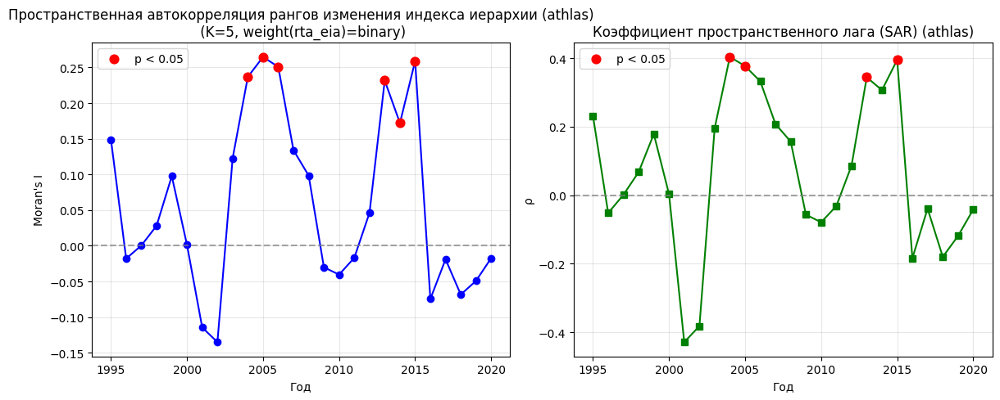

INFO:root:Starting spatial analysis for rta with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 175
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0


(3,) None


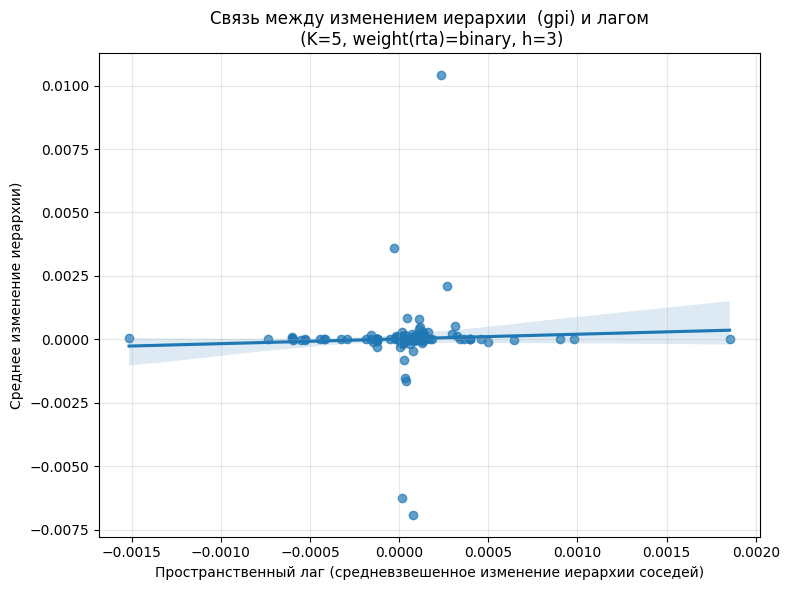

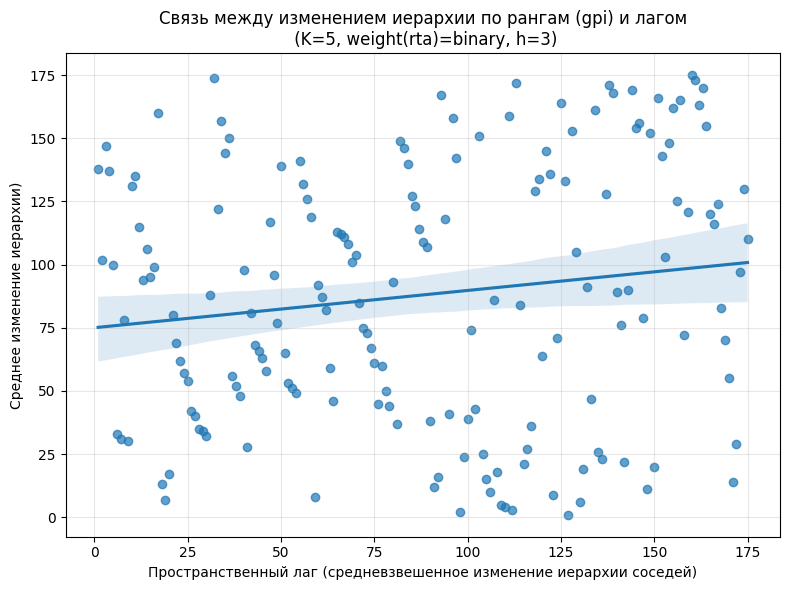

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0465, p-value = 0.5415
INFO:root:Спирмен: r = 0.1474, p-value = 0.0515
INFO:root:=== Moran's I ===
INFO:root:I = 0.0116
INFO:root:p-value (перестановочный) = 0.0770
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0838
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0493, p = 0.0060
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = -0.0171
INFO:root:p-value (перестановочный) = 0.3080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0062
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 44.65, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0886
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (166, 166), средняя степень = 44.65, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0946
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0061
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (166, 166)

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1987
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1505
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1492
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0002
INFO:root:p-value (перестановочный) = 0.3330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0079
INFO:root:p-value (перестановочный) = 0.2030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0322
INFO:root:p-value (перестановочный) = 0.0280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1307
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0210
INFO:root:p-value (перестановочный) = 0.1950
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0091
INFO:root:p-value (перестановочный) = 0.1670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1311
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1548
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1459
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1101
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0323
INFO:root:p-value (перестановочный) = 0.0260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0167
INFO:root:p-value (перестановочный) = 0.0970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (175, 175),

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0315
INFO:root:p-value (перестановочный) = 0.0360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0321
INFO:root:p-value (перестановочный) = 0.0260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0206
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (175, 175),

ML_Lag
ML_Lag
ML_Lag
ML_Lag


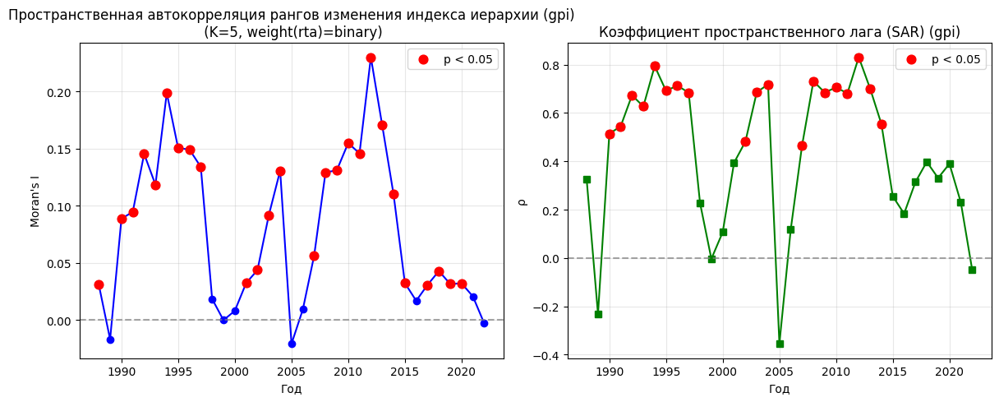

INFO:root:Starting spatial analysis for rta_eia with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0


(3,) None


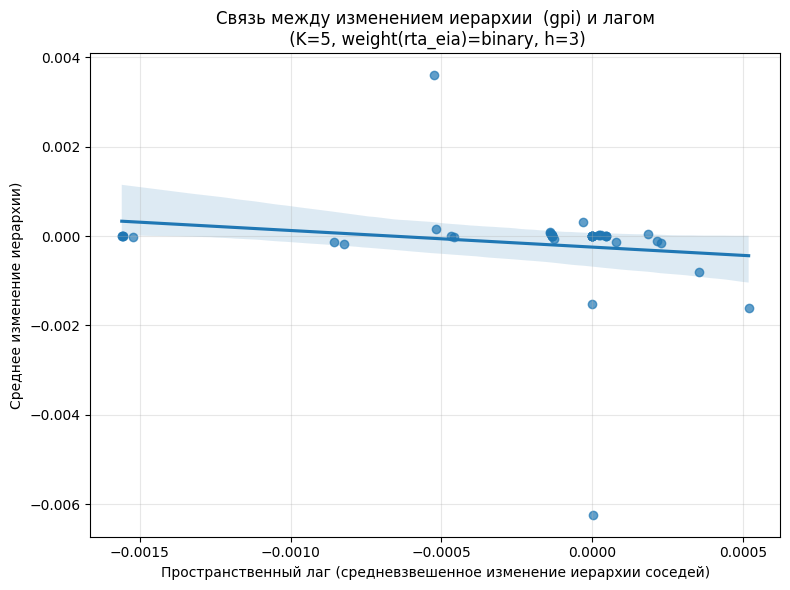

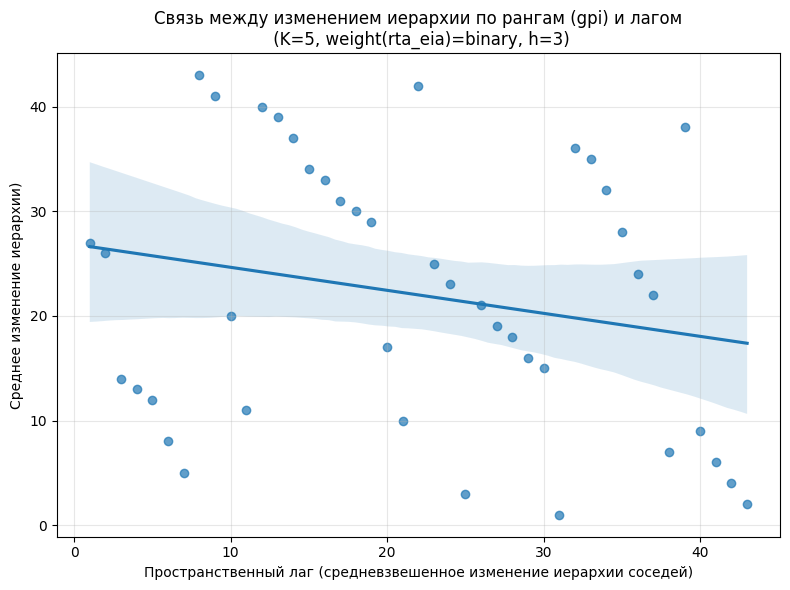

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.1732, p-value = 0.2667
INFO:root:Спирмен: r = -0.2199, p-value = 0.1566
INFO:root:=== Moran's I ===
INFO:root:I = -0.0808
INFO:root:p-value (перестановочный) = 0.1400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1575
INFO:root:p-value (перестановочный) = 0.0590
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:Moran's I для бинарной переменной: 0.1740, p = 0.0360
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1996
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3048
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1440
INFO:root:p-value (перестановочный) = 0.0620
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.1157
INFO:root:p-value (перестановочный) = 0.1840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
IN

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0243
INFO:root:p-value (перестановочный) = 0.3000
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1795
INFO:root:p-value (перестановочный) = 0.0330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2043
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (43, 43), средняя

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0514
INFO:root:p-value (перестановочный) = 0.1950
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0636
INFO:root:p-value (перестановочный) = 0.1970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1645
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INF

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


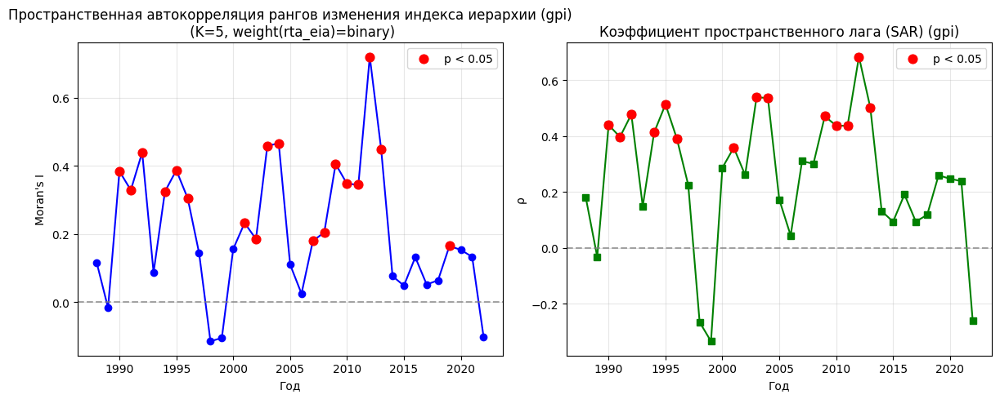

INFO:root:Starting spatial analysis for rta with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0


(3,) None


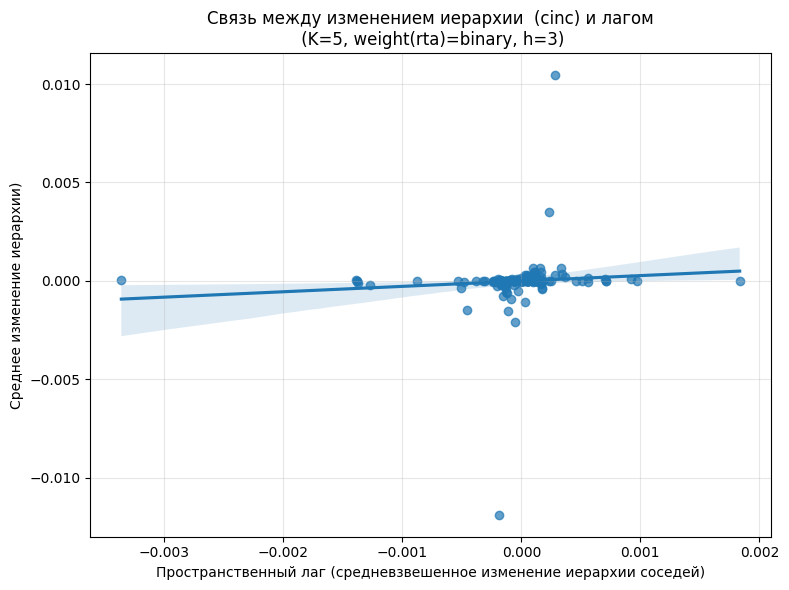

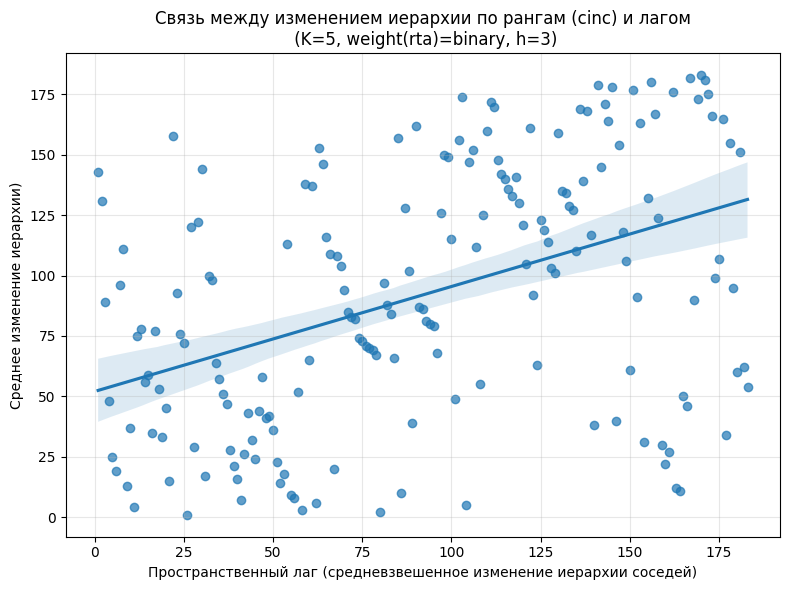

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0937, p-value = 0.2073
INFO:root:Спирмен: r = 0.4344, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0320
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2597
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2175, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LI

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.0754
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 43.65, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0247
INFO:root:p-value (перестановочный) = 0.0570
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (150, 150), средняя степень = 43.65, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0748
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0067
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (150, 150),

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0725
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0060
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (173, 173), средняя степень = 45.32, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0702
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 46.09, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0609
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1999
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 46.09, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1347
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 46.09, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1360
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 46.09, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1415
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0407
INFO:root:p-value (перестановочный) = 0.0120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (182, 182), средняя степень = 45.41, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0774
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (182, 182), средняя степень = 45.41, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1550
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2009
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1234
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1205
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1073
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:=== Moran's I ===
INFO:root:I = 0.1881
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1728
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0880
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изме

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1398
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1421
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0609
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag


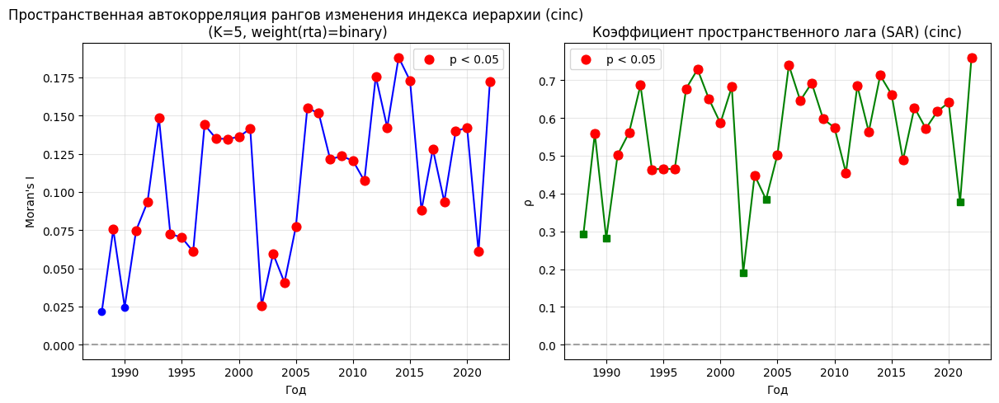

INFO:root:Starting spatial analysis for rta_eia with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


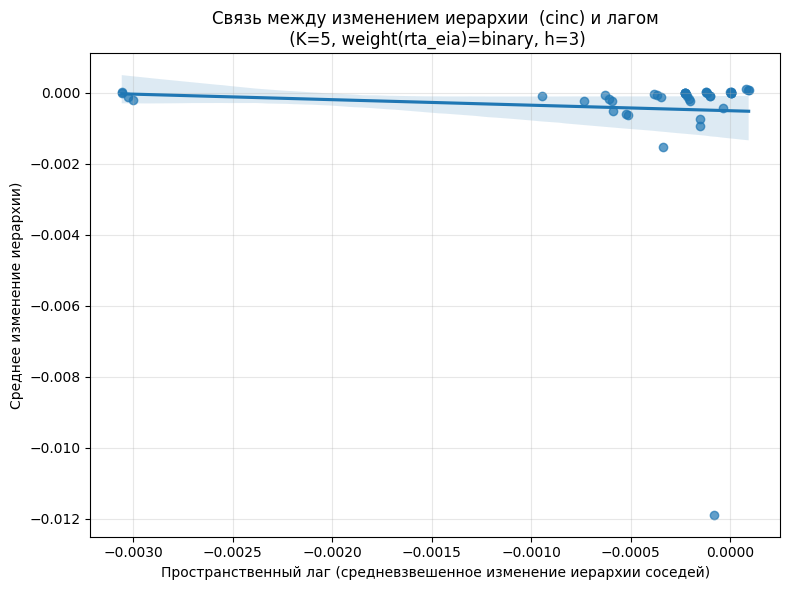

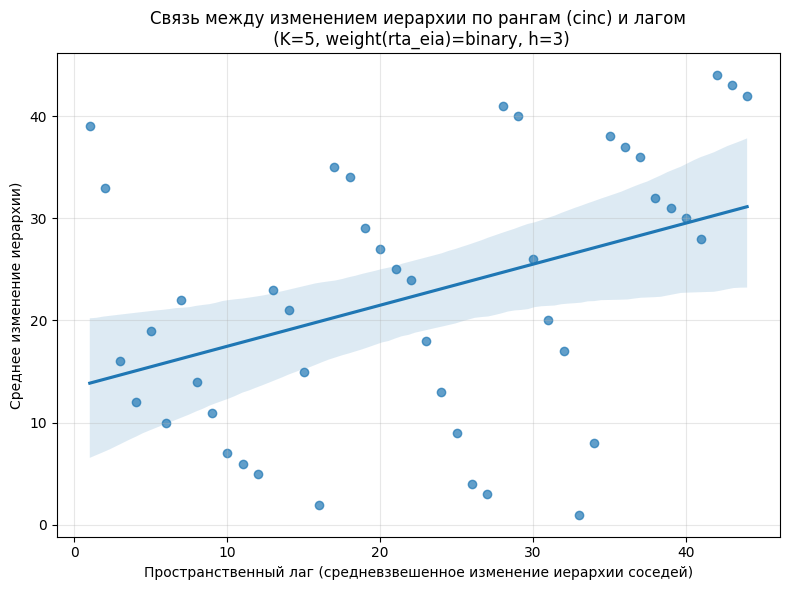

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0737, p-value = 0.6347
INFO:root:Спирмен: r = 0.4014, p-value = 0.0069
INFO:root:=== Moran's I ===
INFO:root:I = -0.0348
INFO:root:p-value (перестановочный) = 0.3420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4444
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.3146, p = 0.0030
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1996
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1471
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2941
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2450
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2006
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3460
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.4575
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5417
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2017
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2762
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2878
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.4019
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


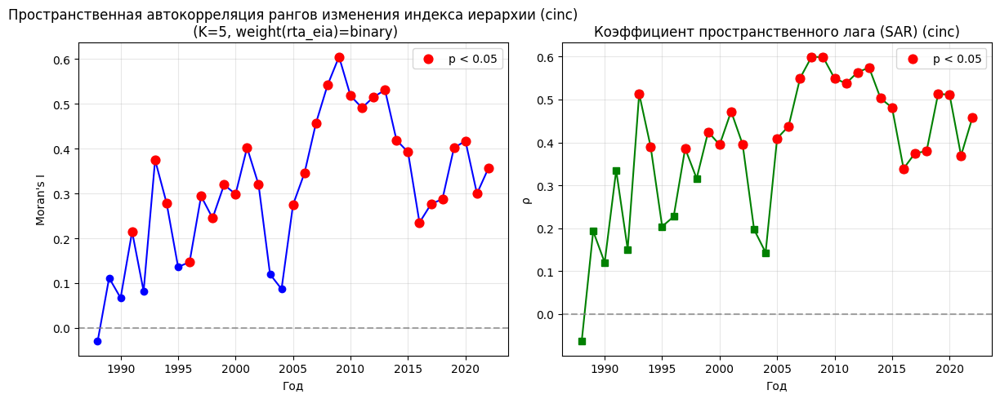

INFO:root:Starting spatial analysis for rta with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.43, изолированных вершин = 0
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


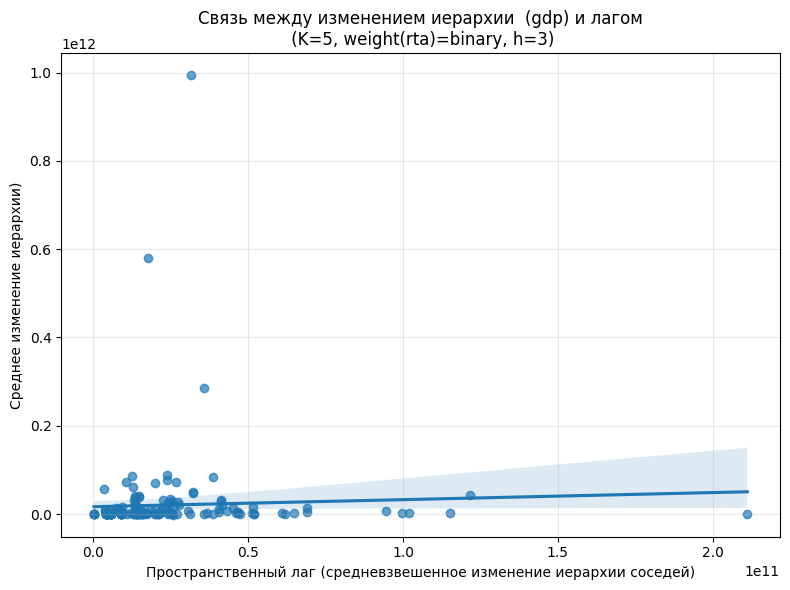

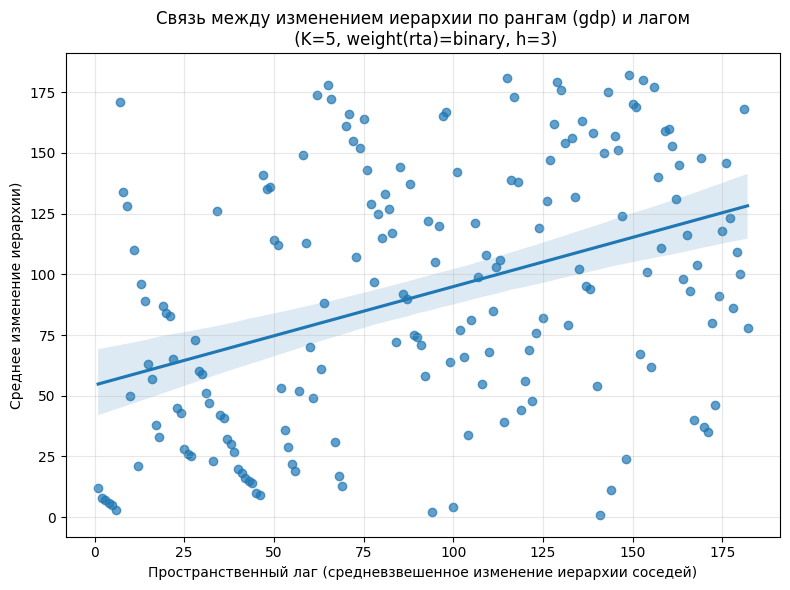

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0453, p-value = 0.5437
INFO:root:Спирмен: r = 0.4054, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0127
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2638
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0118, p = 0.4470
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.1867
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 41.38, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3053
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 41.38, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3067
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1994
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 44.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3064
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3211
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3411
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.22, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2194
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1999
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.22, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1790
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 200

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.30, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2151
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2003
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2040
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INF

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2599
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2520
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 200

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2167
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2562
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2529
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2195
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1836
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1783
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2018
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.45, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2128
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2240
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0752
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2022
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1364
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    153 0.184860    0.001 0.744109 6.116496e-09
 1989    154 0.186747    0.001 0.713293 2.102464e-07
 1990    157 0.305264    0.001 0.816992 0.000000e+00
 1991    157 0.306743    0.001 0.816059 0.000000e+00
 1992    158 0.300961    0.001 0.803079 4.440892e-15
 1993    175 0.271650    0.001 0.801020 6.439294e-15
 1994    175 0.306377    0.001 0.840164 0.000000e+00
 1995    176 0.321059    0.001 0.841896 0.000000e+00
 1996    176 0.341088    0.001 0.869660 0.000000e+00
 1997    177 0.305796    0.001 0.813660

ML_Lag


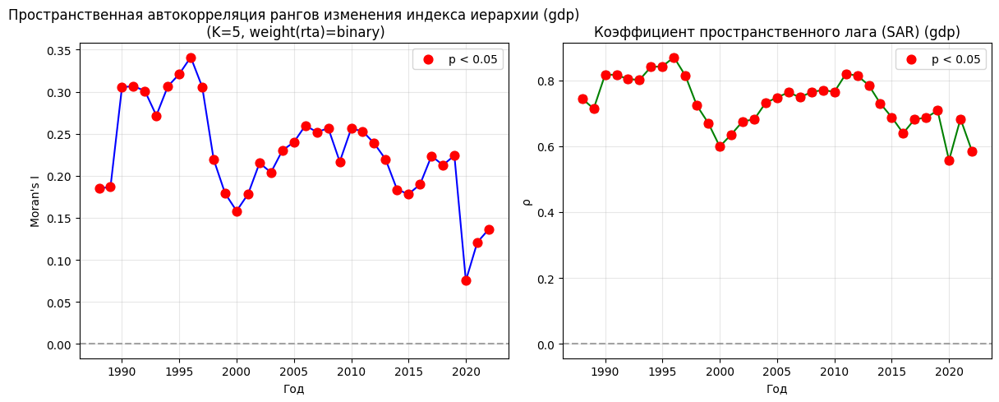

INFO:root:Starting spatial analysis for rta_eia with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


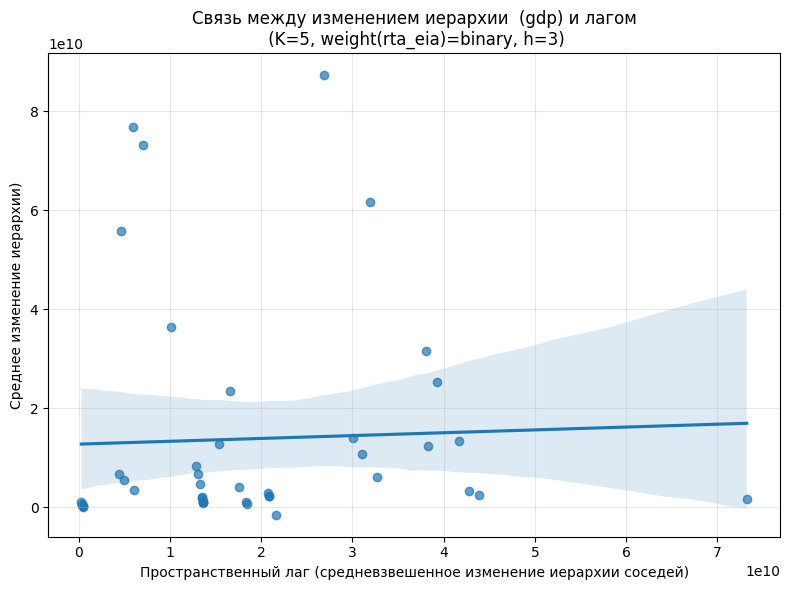

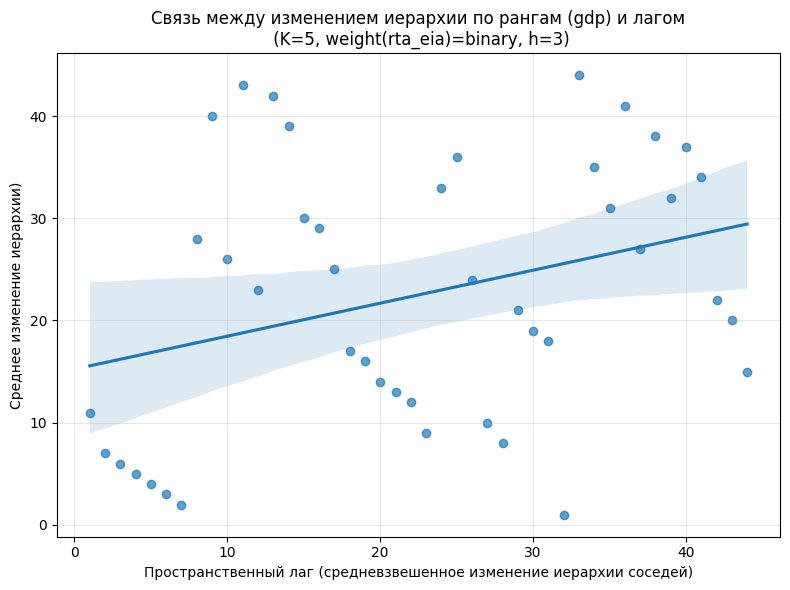

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0394, p-value = 0.7998
INFO:root:Спирмен: r = 0.3226, p-value = 0.0327
INFO:root:=== Moran's I ===
INFO:root:I = 0.0269
INFO:root:p-value (перестановочный) = 0.2320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3901
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0233, p = 0.4130
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.4051
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5143
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5428
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорре

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2758
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2878
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2007
INFO

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0148
INFO:root:p-value (перестановочный) = 0.4050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0739
INFO:root:p-value (перестановочный) = 0.1520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5007
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
IN

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


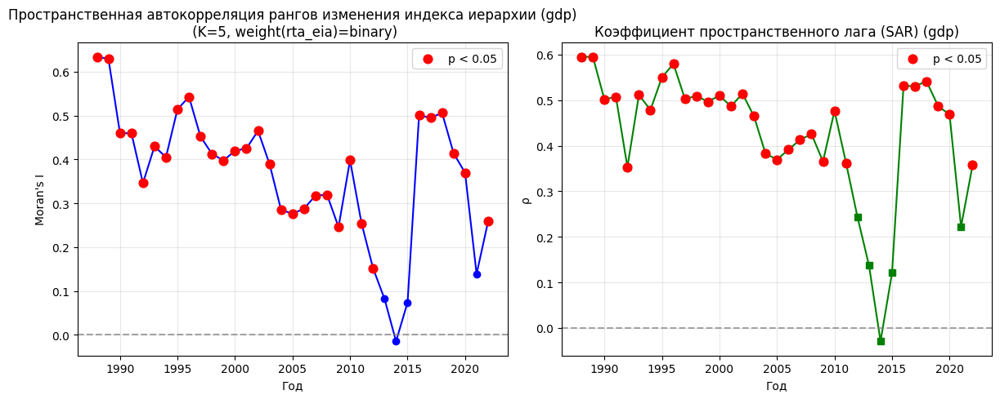

INFO:root:Starting spatial analysis for rta with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0


(3,) None


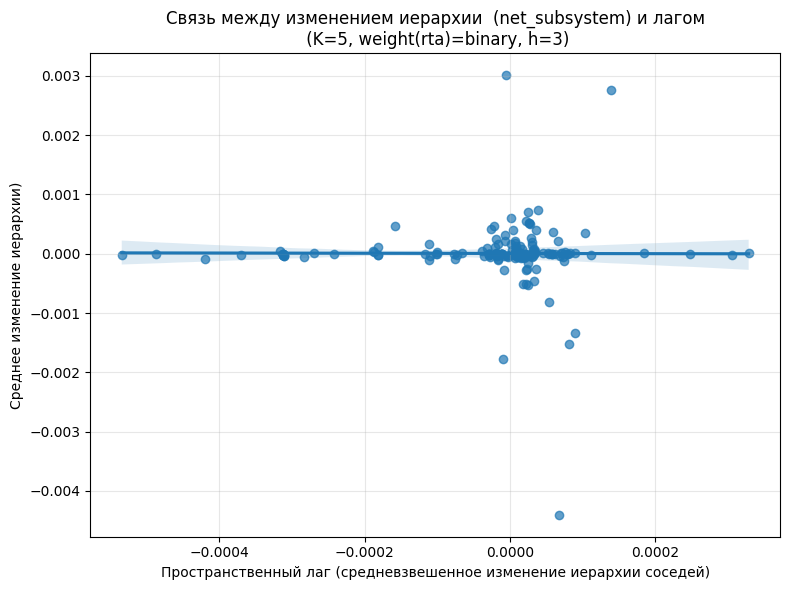

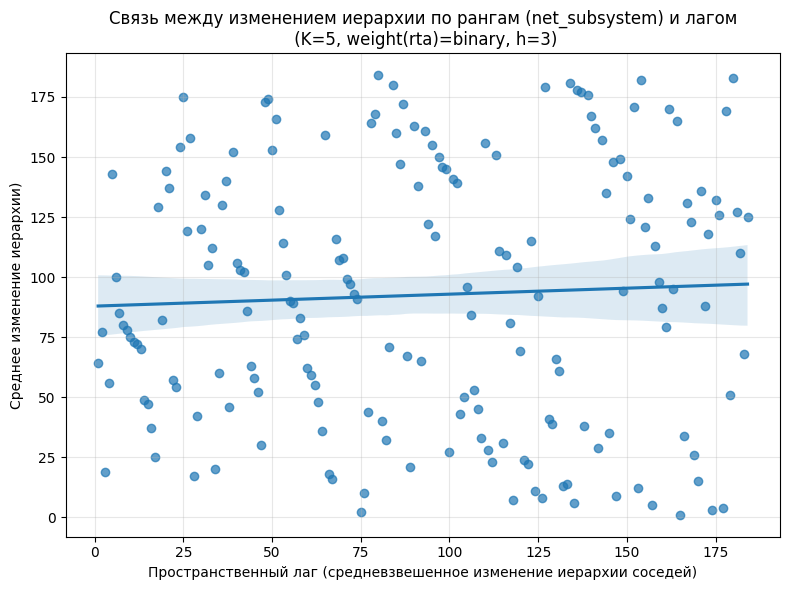

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0042, p-value = 0.9547
INFO:root:Спирмен: r = 0.0499, p-value = 0.5015
INFO:root:=== Moran's I ===
INFO:root:I = -0.0010
INFO:root:p-value (перестановочный) = 0.3640
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0781
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1430, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.0282
INFO:root:p-value (перестановочный) = 0.0430
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 43.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0156
INFO:root:p-value (перестановочный) = 0.1270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 43.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0147
INFO:root:p-value (перестановочный) = 0.3870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1992
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 43.58, изолированных вершин = 0
INFO:root:=== Moran's

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0041
INFO:root:p-value (перестановочный) = 0.4010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 45.79, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0227
INFO:root:p-value (перестановочный) = 0.0610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0306
INFO:root:p-value (перестановочный) = 0.0500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0059
INFO:root:p-value (перестановочный) = 0.475

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1999
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0179
INFO:root:p-value (перестановочный) = 0.0970
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0192
INFO:root:p-value (перестановочный) = 0.0870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0094
INFO:root:p-value (перестановочный) = 0.4440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (182

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0106
INFO:root:p-value (перестановочный) = 0.4290
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0123
INFO:root:p-value (перестановочный) = 0.3790
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0001
INFO:root:p-value (перестановочный) = 0.3600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (183, 183), средняя степе

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0101
INFO:root:p-value (перестановочный) = 0.4520
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0255
INFO:root:p-value (перестановочный) = 0.0910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0246
INFO:root:p-value (перестановочный) = 0.1190
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (184, 184), средняя степе

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2014
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0153
INFO:root:p-value (перестановочный) = 0.2890
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0086
INFO:root:p-value (перестановочный) = 0.4780
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0178
INFO:root:p-value (перестановочный) = 0.0750
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (18

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0156
INFO:root:p-value (перестановочный) = 0.3010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0094
INFO:root:p-value (перестановочный) = 0.4390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0067
INFO:root:p-value (перестановочный) = 0.4900
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0100
INFO:root:p-value (перестановочный) = 0.44

ML_Lag
ML_Lag
ML_Lag
ML_Lag


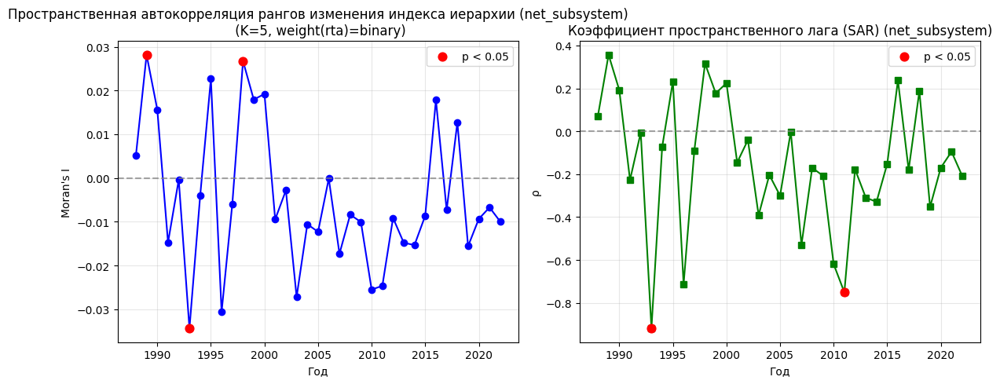

INFO:root:Starting spatial analysis for rta_eia with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


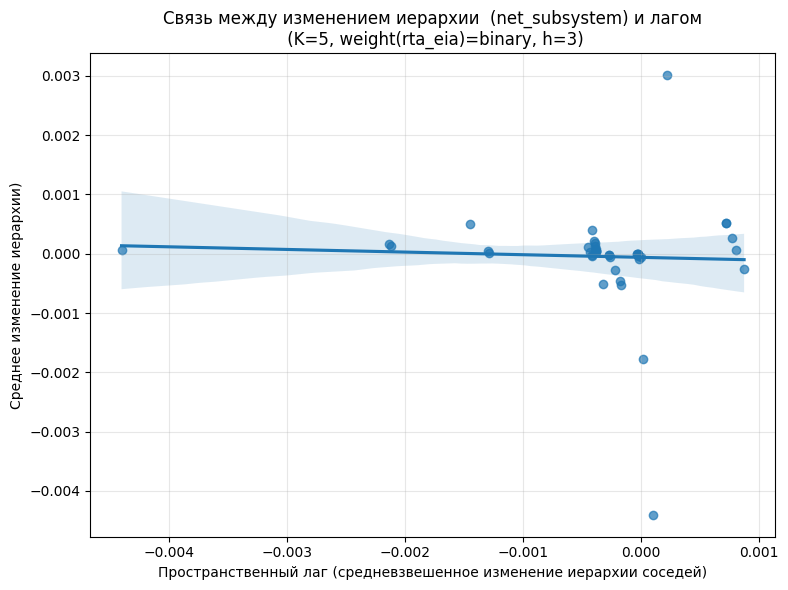

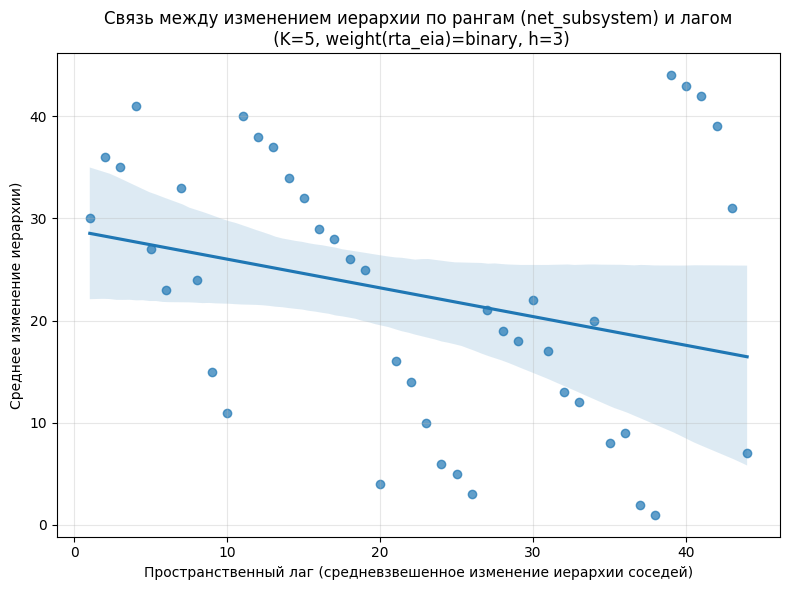

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0446, p-value = 0.7736
INFO:root:Спирмен: r = -0.2809, p-value = 0.0647
INFO:root:=== Moran's I ===
INFO:root:I = -0.0449
INFO:root:p-value (перестановочный) = 0.3110
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2416
INFO:root:p-value (перестановочный) = 0.0090
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.3850, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
---------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3139
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0442
INFO:root:p-value (перестановочный) = 0.2130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2146
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (44, 44), средняя

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0179
INFO:root:p-value (перестановочный) = 0.4230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.1051
INFO:root:p-value (перестановочный) = 0.1870
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0777
INFO:root:p-value (перестановочный) = 0.3260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0041
INFO:root:p-value (перестановочный) = 0.3540
INFO:ro

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2016
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1316
INFO:root:p-value (перестановочный) = 0.0730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0685
INFO:root:p-value (перестановочный) = 0.3720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1390
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (44, 44), сре

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


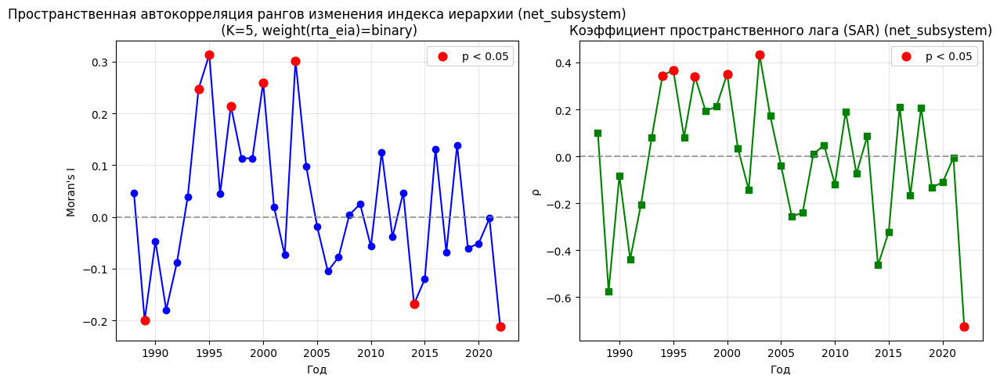

INFO:root:Starting spatial analysis for rta with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0


(3,) None


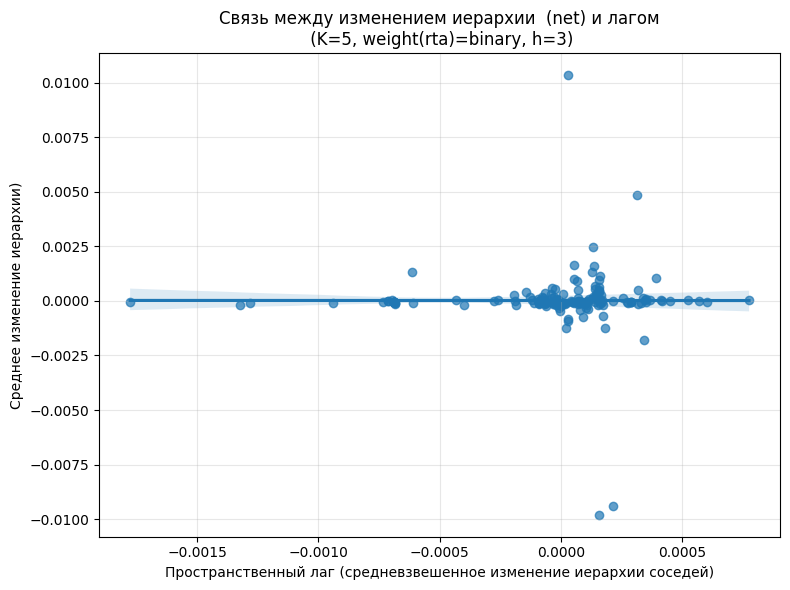

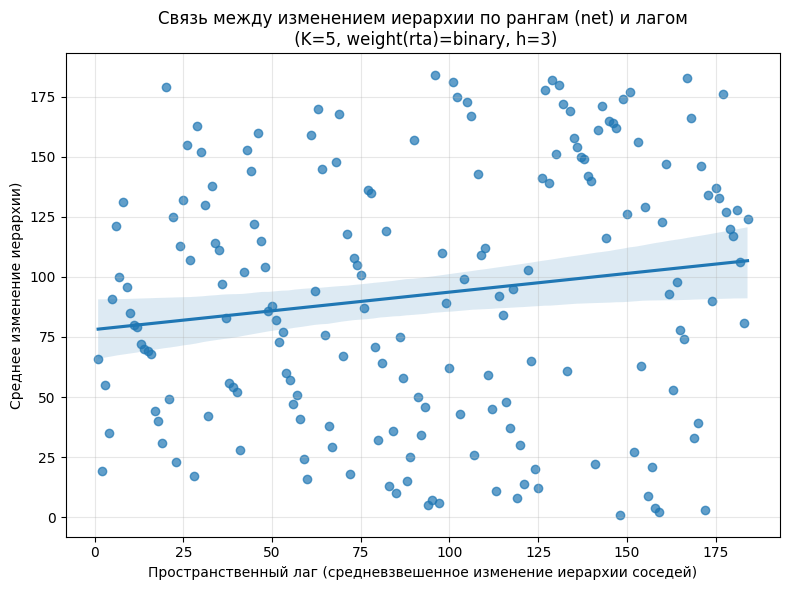

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0005, p-value = 0.9950
INFO:root:Спирмен: r = 0.1556, p-value = 0.0349
INFO:root:=== Moran's I ===
INFO:root:I = -0.0001
INFO:root:p-value (перестановочный) = 0.3240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0932
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1538, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.0378
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 43.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0512
INFO:root:p-value (перестановочный) = 0.0060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (156, 156), средняя степень = 43.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0619
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0067
INFO:root:p-value (перестановочный) = 0.2400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 45.79, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0540
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0037
INFO:root:p-value (перестановочный) = 0.4260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 1999
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0583
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0253
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0707
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значи

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2003
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0343
INFO:root:p-value (перестановочный) = 0.0280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2004
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0239
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0164
INFO:root:p-value (перестановочный) = 0.0990
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ зн

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2007
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0156
INFO:root:p-value (перестановочный) = 0.2850
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0137
INFO:root:p-value (перестановочный) = 0.1350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0196
INFO:root:p-value (перестановочный) = 0.2060
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (18

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2011
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0097
INFO:root:p-value (перестановочный) = 0.1770
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0072
INFO:root:p-value (перестановочный) = 0.2180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0124
INFO:root:p-value (перестановочный) = 0.1500
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2014
INFO:root:Матрица смежности построена: (184,

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2015
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0169
INFO:root:p-value (перестановочный) = 0.0990
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0198
INFO:root:p-value (перестановочный) = 0.0730
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0447
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иера

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2019
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0782
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0047
INFO:root:p-value (перестановочный) = 0.2680
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0332
INFO:root:p-value (перестановочный) = 0.0250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значи

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs   moran_I  moran_p       rho    rho_p
 1988    156  0.039393    0.028  0.451082 0.035821
 1989    156  0.037836    0.020  0.426139 0.053582
 1990    156  0.051241    0.006  0.504028 0.012538
 1991    156  0.061944    0.004  0.614189 0.000352
 1992    156  0.058791    0.005  0.591213 0.000926
 1993    160  0.041850    0.019  0.424165 0.057607
 1994    176  0.006739    0.240  0.092347 0.738923
 1995    179  0.053993    0.005  0.333745 0.147640
 1996    180 -0.003738    0.426 -0.055900 0.852353
 1997    180  0.000692    0.320  0.009913 0.972748
 1998    180 -0.002083    0.375 -0.033866 0.909220
 1999    180  0.058255    0.004  0.397290 0.068349
 2000    180  0.025269    0.056  0.216988 0.393839
 2001    180  0.070656    0.001  0.536442 0.003791
 2002    182  0.055327    0.003  0.425815 0.041022
 2003    183  0.034251    0.028  0.326283 0.152839
 2004    183  0.023900    0.056  0.309683 0.181188
 2005    183  0.016368    0.099  0.

ML_Lag


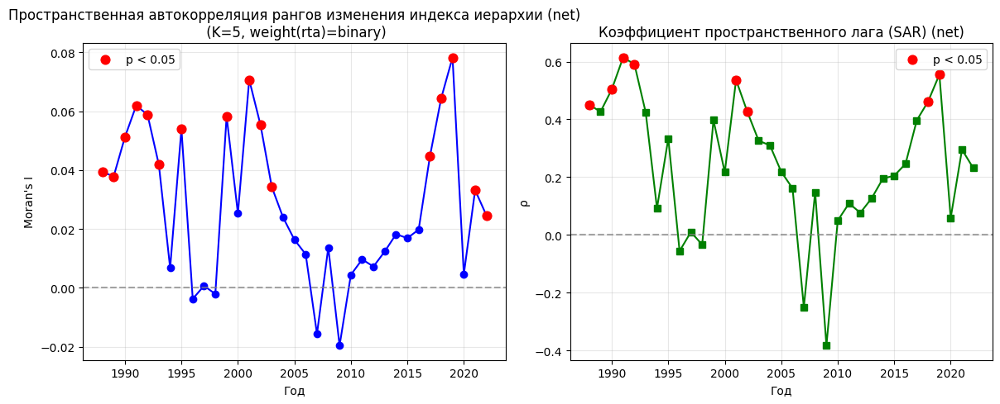

INFO:root:Starting spatial analysis for rta_eia with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


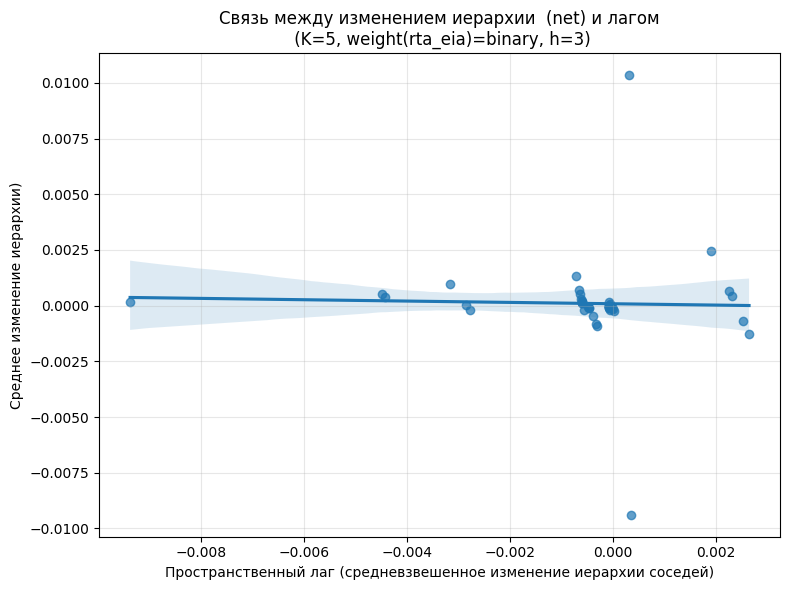

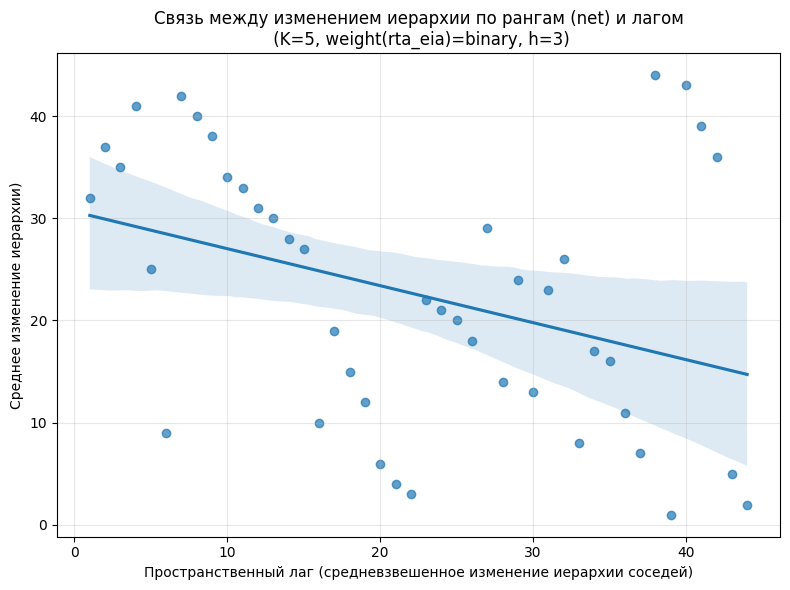

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0273, p-value = 0.8603
INFO:root:Спирмен: r = -0.3617, p-value = 0.0159
INFO:root:=== Moran's I ===
INFO:root:I = -0.0248
INFO:root:p-value (перестановочный) = 0.3420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0921
INFO:root:p-value (перестановочный) = 0.1180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:Moran's I для бинарной переменной: 0.3574, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1131
INFO:root:p-value (перестановочный) = 0.0930
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1345
INFO:root:p-value (перестановочный) = 0.0670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0741
INFO:root:p-value (перестановочный) = 0.3150
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1999
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, из

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0891
INFO:root:p-value (перестановочный) = 0.2510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2226
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0135
INFO:root:p-value (перестановочный) = 0.2910
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
IN

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2018
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1885
INFO:root:p-value (перестановочный) = 0.0240
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0893
INFO:root:p-value (перестановочный) = 0.1340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0523
INFO:root:p-value (перестановочный) = 0.4330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
IN

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


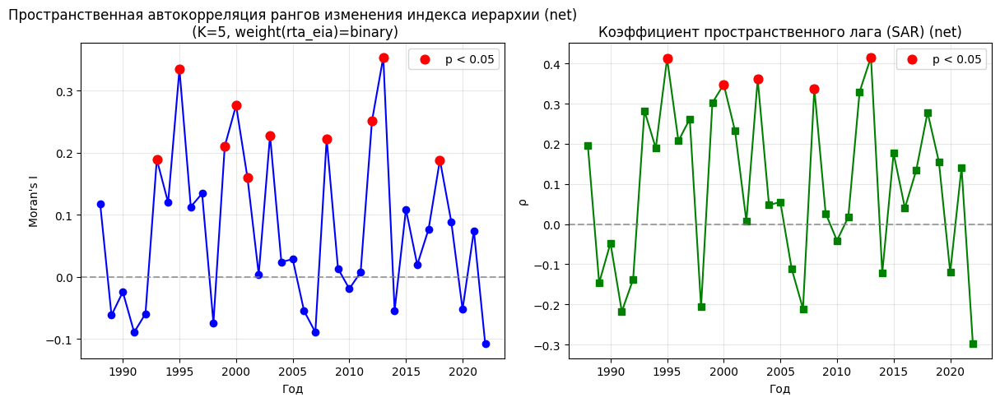

INFO:root:Starting spatial analysis for rta with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.43, изолированных вершин = 0
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


(3,) None


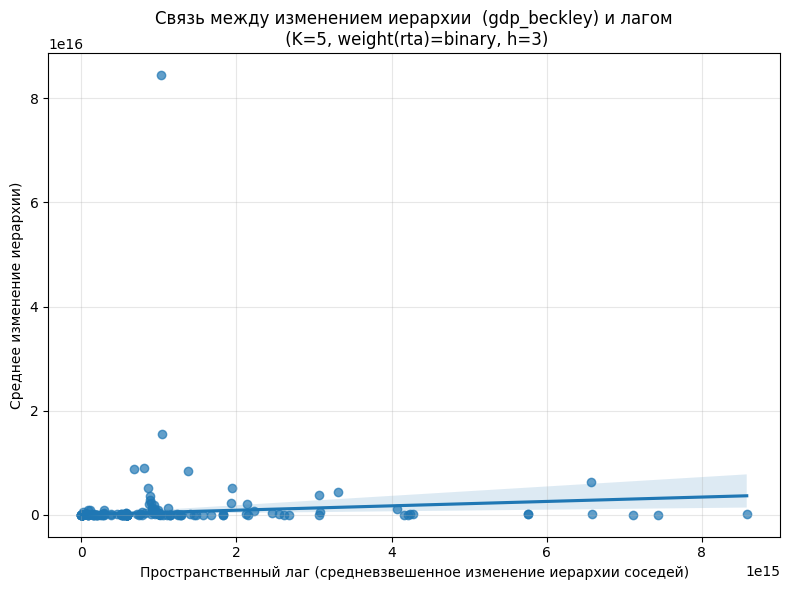

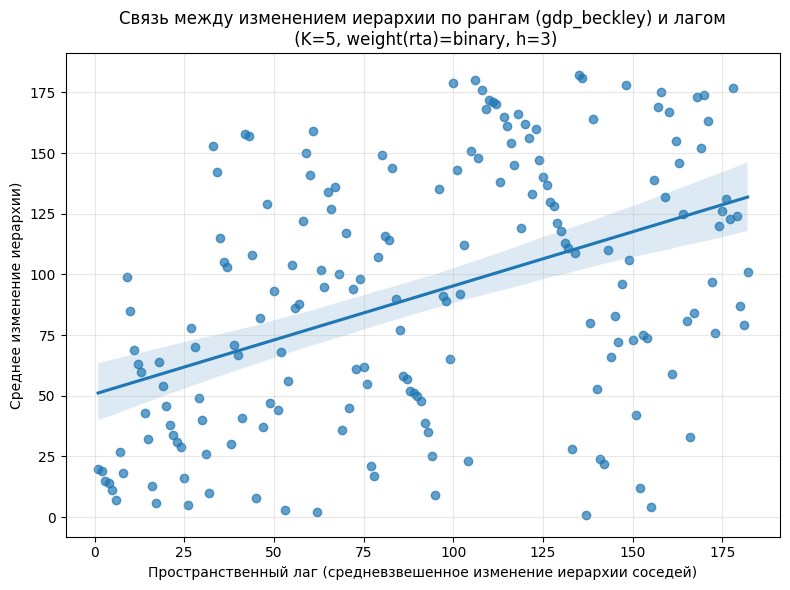

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0324, p-value = 0.6637
INFO:root:Спирмен: r = 0.4458, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0074
INFO:root:p-value (перестановочный) = 0.0450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2819
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0194, p = 0.1820
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.1774
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0065
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 41.38, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1015
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (157, 157), средняя степень = 41.38, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0654
INFO:root:p-value (перестановочный) = 0.0050
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0064
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2265
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2833
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.98, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3530
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.22, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2018
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.30, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2167
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.30, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2261
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2926
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3138
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3425
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1448
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1756
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1786
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2014
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1792
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2139
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.45, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2838
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2019
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3108
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0773
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (180, 180), средняя степень = 45.54, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1492
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожид

ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1988    153 0.201178    0.001 0.741464 8.930296e-09
 1989    154 0.177442    0.001 0.660784 1.849297e-05
 1990    157 0.101549    0.001 0.435708 3.774585e-02
 1991    157 0.065357    0.005 0.315939 1.795201e-01
 1992    158 0.107400    0.001 0.480821 1.473748e-02
 1993    175 0.163888    0.001 0.669446 4.898985e-06
 1994    175 0.226462    0.001 0.772654 8.689272e-12
 1995    176 0.283315    0.001 0.834331 0.000000e+00
 1996    176 0.352970    0.001 0.902042 0.000000e+00
 1997    177 0.362386    0.001 0.885527 0.000000e+00
 1998    178 0.289821    0.001 0.840280 0.000000e+00
 1999    178 0.201763    0.001 0.740130 2.691839e-09
 2000    180 0.216737    0.001 0.729027 1.149814e-08
 2001    180 0.226142    0.001 0.730145 9.921348e-09
 2002    180 0.284251    0.001 0.784284 5.602185e-13
 2003    181 0.233836    0.001 0.724381 1.940895e-08
 2004    181 0.292585    0.001 0.810952 2.220446e-16

ML_Lag


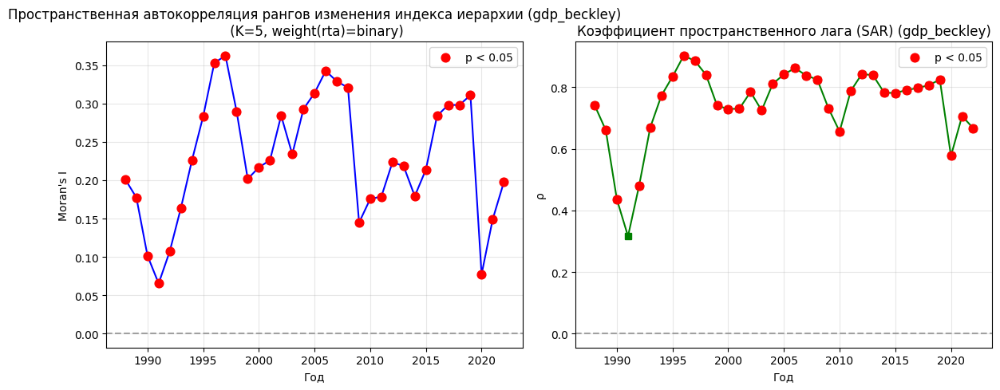

INFO:root:Starting spatial analysis for rta_eia with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


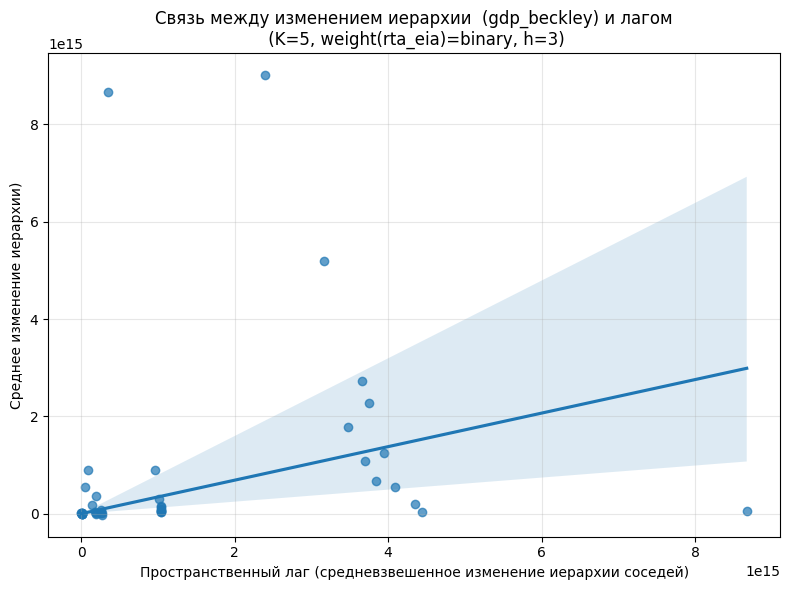

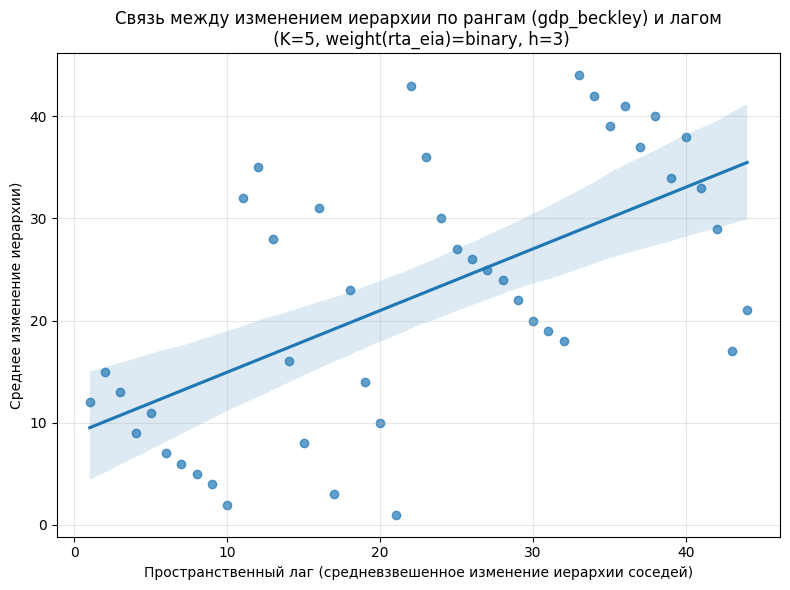

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1844, p-value = 0.2309
INFO:root:Спирмен: r = 0.6035, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.1733
INFO:root:p-value (перестановочный) = 0.0340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.6150
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0476, p = 0.1990
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM L

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.6737
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.7020
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.6372
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорре

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.5518
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2008
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5536
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2009
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0520
INFO:root:p-value (перестановочный) = 0.2010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (44, 44), средняя

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2018
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.7382
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.6590
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3337
INFO:root:p-value (перестановочный) = 0.0040
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


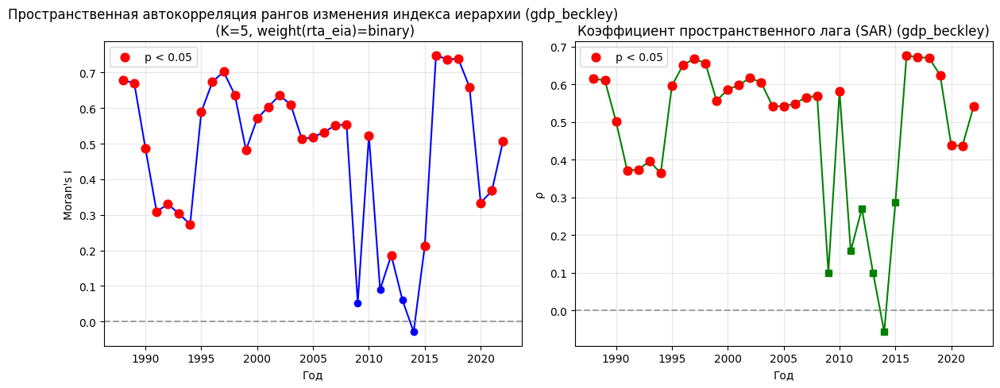

INFO:root:Starting spatial analysis for rta with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 178
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.06, изолированных вершин = 0


(3,) None


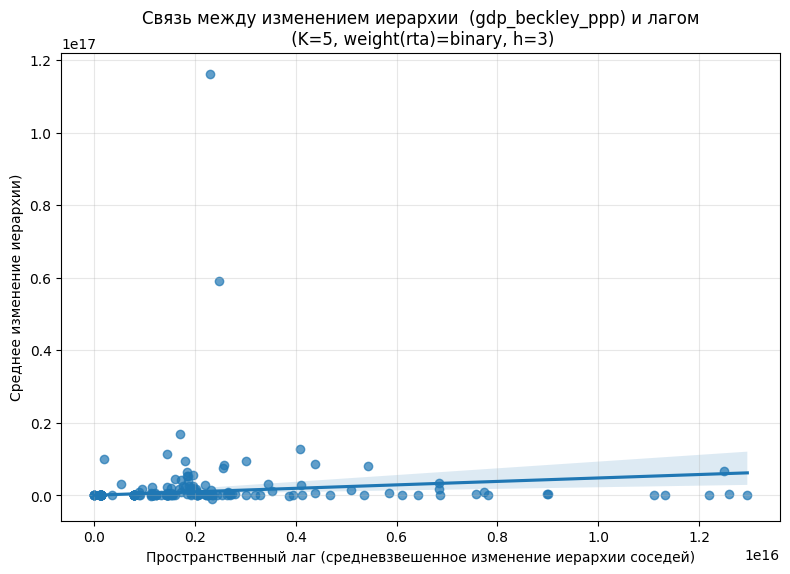

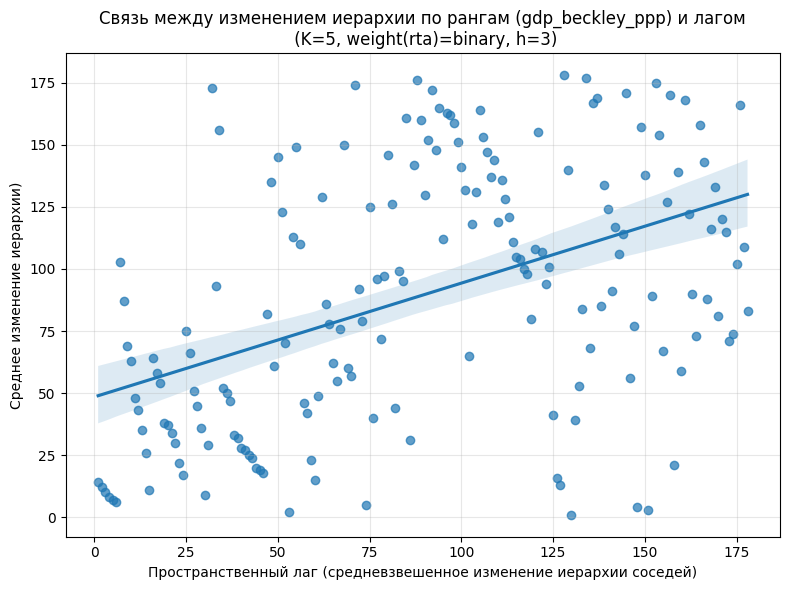

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0256, p-value = 0.7341
INFO:root:Спирмен: r = 0.4582, p-value = 0.0000
INFO:root:=== Moran's I ===
INFO:root:I = 0.0066
INFO:root:p-value (перестановочный) = 0.1120
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3009
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: -0.0222, p = 0.1300
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.2635
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (172, 172), средняя степень = 44.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2973
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (172, 172), средняя степень = 44.58, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3638
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:Матрица смежности построена: (174, 174), средняя степень = 44.83, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2039
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.91, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2103
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (176, 176), средняя степень = 44.91, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2272
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.2989
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3143
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.3465
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1632
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2046
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2137
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.1955
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2200
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.06, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.2867
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3181
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.06, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0747
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.06, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1450
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag


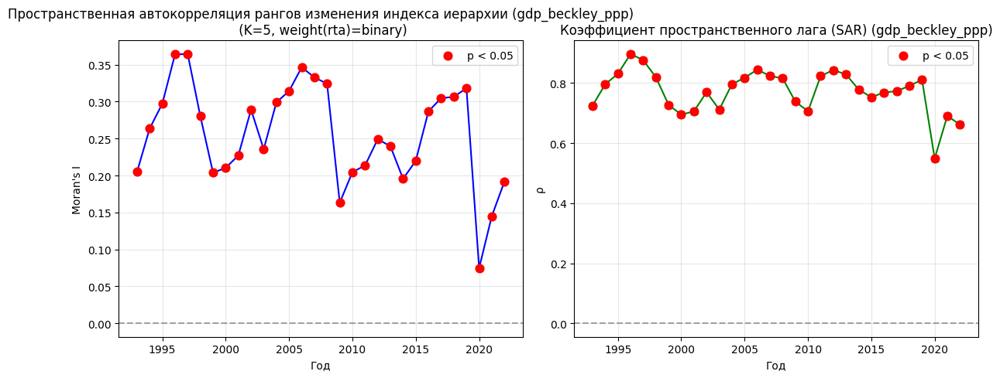

INFO:root:Starting spatial analysis for rta_eia with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0


(3,) None


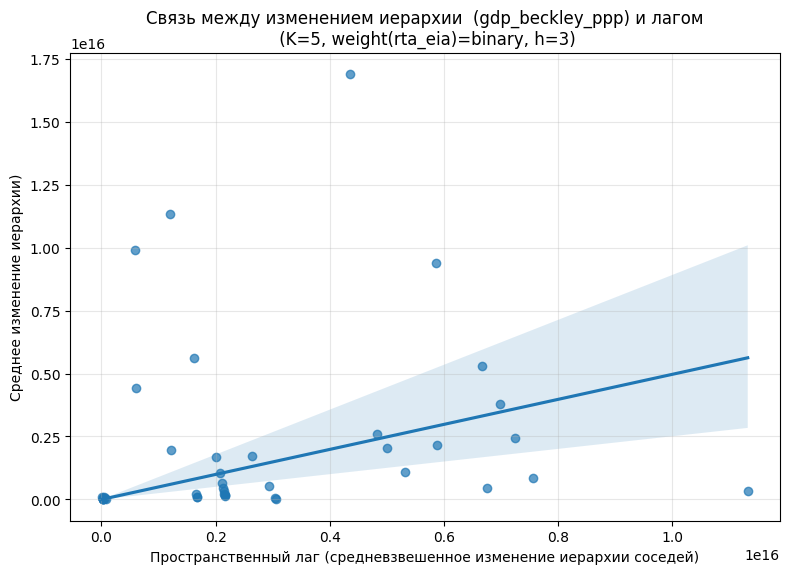

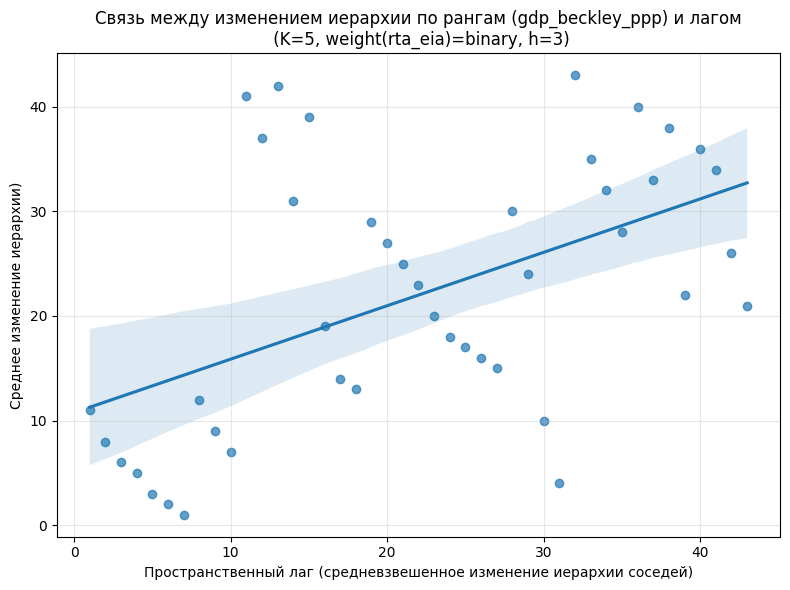

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1670, p-value = 0.2844
INFO:root:Спирмен: r = 0.5106, p-value = 0.0005
INFO:root:=== Moran's I ===
INFO:root:I = 0.1237
INFO:root:p-value (перестановочный) = 0.0600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.5714
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: nan, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
---------------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.5715
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5932
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2002
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.5718
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:r

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2011
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1745
INFO:root:p-value (перестановочный) = 0.0350
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1819
INFO:root:p-value (перестановочный) = 0.0390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2013
INFO:root:Матрица смежности построена: (43, 43), средняя степень = 5.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0749
INFO:root:p-value (перестановочный) = 0.1560
INFO:root:Ожидаемое I п

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.3940
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0238
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:
Сводная таблица по годам:
INFO:root: year  n_obs  moran_I  moran_p      rho        rho_p
 1993     43 0.358304    0.004 0.446483 2.341962e-03
 1994     43 0.360293    0.002 0.436774 3.338236e-03
 1995     43 0.649876    0.001 0.624833 2.859079e-09
 1996     43 0.720719    0.001 0.675390 2.744471e-13
 1997     43 0.659132    0.001 0.625773 2.497239e-09
 1998     43 0.583854    0.001 0.616788 8.706911e-09
 1999     43 0.536925    0.001 0.594003 1.381816e-07
 2000     43 0.571522    0.001 0.591903 1.737618e-07
 2001     43 0.593246    0.001 0.601828 5.676001e-08
 2002     43 0.571786    0.001 0.575574 9.075913e-07
 2003     43 0.497403    0.001 0.526730 4.267524e-05
 2004     43 0.456619    0.001 0.499632 2.127081e-04
 2005     43 0.485307    0.001 0

ML_Lag


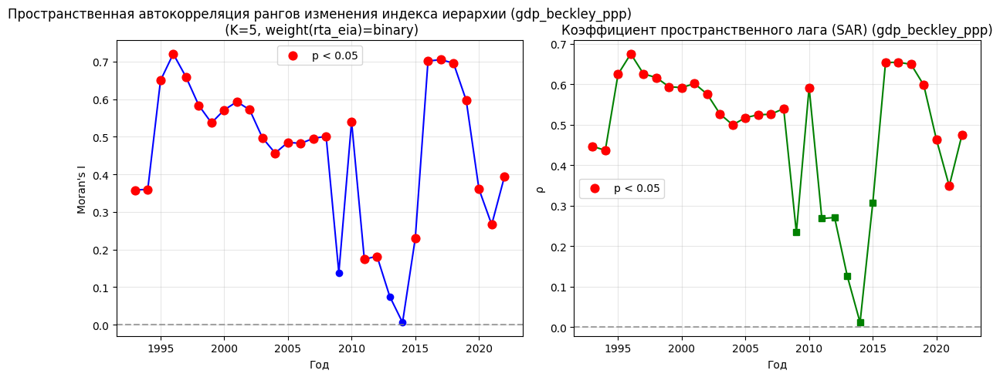

INFO:root:Starting spatial analysis for rta with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0


(3,) None


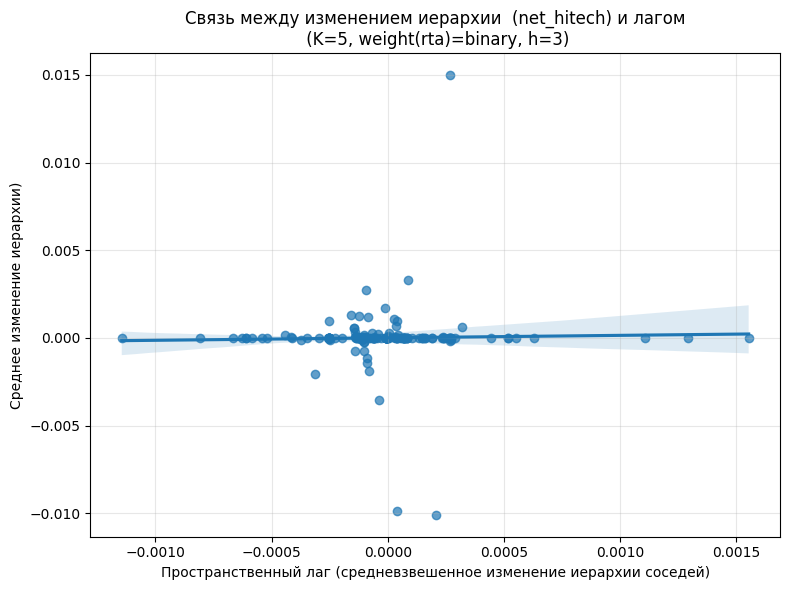

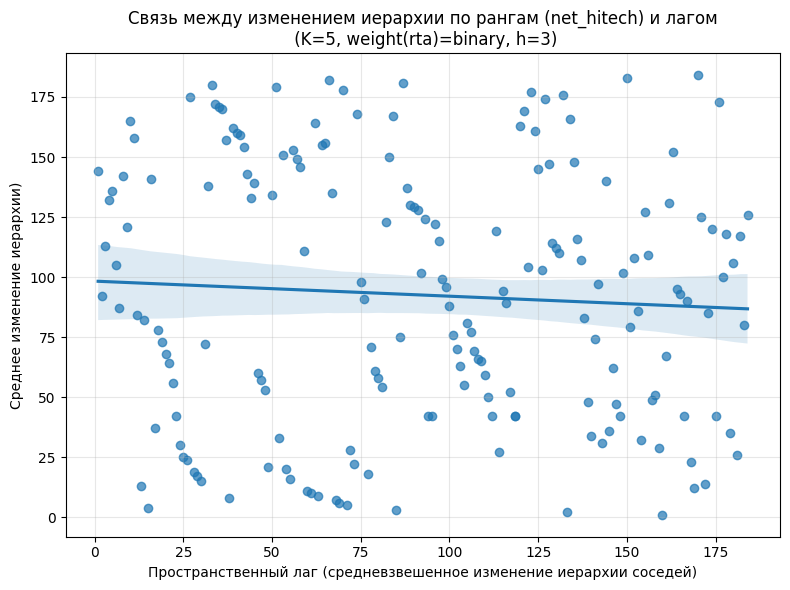

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0251, p-value = 0.7354
INFO:root:Спирмен: r = -0.0627, p-value = 0.3976
INFO:root:=== Moran's I ===
INFO:root:I = 0.0045
INFO:root:p-value (перестановочный) = 0.2070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0812
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.0891, p = 0.0010
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag


INFO:root:I = 0.0333
INFO:root:p-value (перестановочный) = 0.0330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0066
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1990
INFO:root:Матрица смежности построена: (153, 153), средняя степень = 44.10, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0506
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0066
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 1991
INFO:root:Матрица смежности построена: (153, 153), средняя степень = 44.10, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0611
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0066
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0064
INFO:root:p-value (перестановочный) = 0.4510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0058
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1995
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 45.28, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0121
INFO:root:p-value (перестановочный) = 0.3820
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 46.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0137
INFO:root:p-value (перестановочный) = 0.3360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 46.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0323
INFO:root:p-value (перестановочный) = 0.026

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0359
INFO:root:p-value (перестановочный) = 0.0200
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2000
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 46.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0427
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2001
INFO:root:Матрица смежности построена: (179, 179), средняя степень = 46.17, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0237
INFO:root:p-value (перестановочный) = 0.0440
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0263
INFO:root:p-value (перестановочный) = 0.0420
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2005
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0103
INFO:root:p-value (перестановочный) = 0.1650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0070
INFO:root:p-value (перестановочный) = 0.2180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.49, изолированных вершин = 0
INFO:root:=== Moran's 

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0167
INFO:root:p-value (перестановочный) = 0.2560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2010
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0341
INFO:root:p-value (перестановочный) = 0.0260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2011
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0271
INFO:root:p-value (перестановочный) = 0.0890
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2012
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0527
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2015
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0376
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:year is 2016
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0345
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.


ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = 0.0090
INFO:root:p-value (перестановочный) = 0.1600
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2020
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0023
INFO:root:p-value (перестановочный) = 0.3720
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2021
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0039
INFO:root:p-value (перестановочный) = 0.2830
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2022
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0055
INFO:root:p-value (перестановочный) = 0.2590


ML_Lag
ML_Lag
ML_Lag
ML_Lag


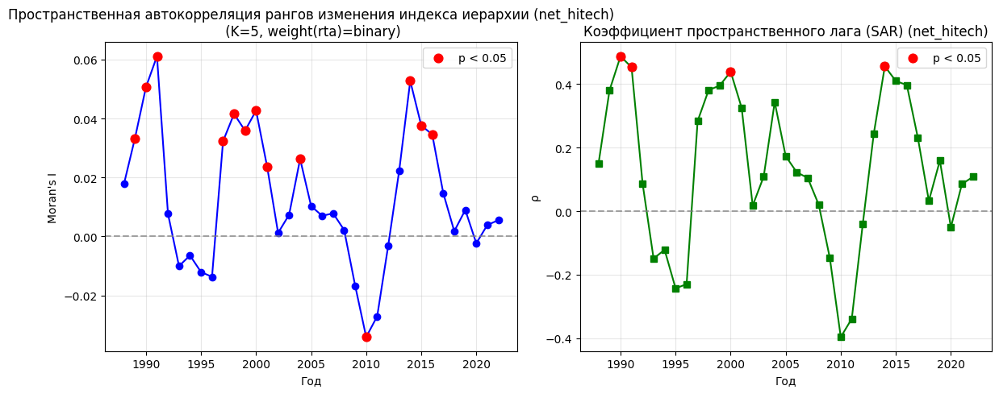

INFO:root:Starting spatial analysis for rta_eia with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0


(3,) None


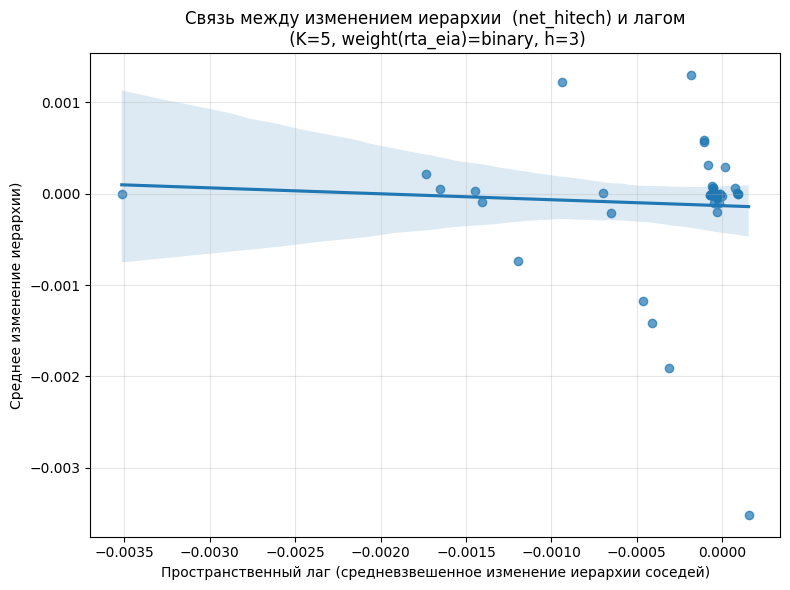

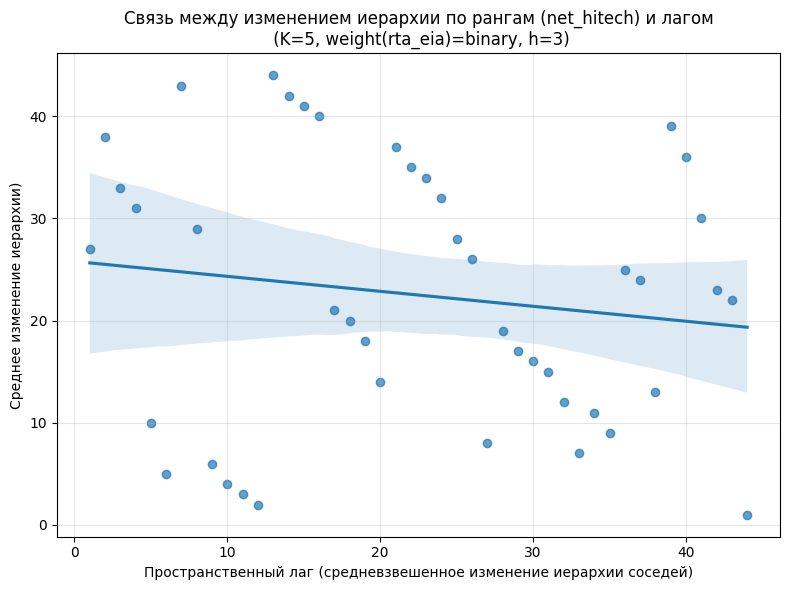

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0609, p-value = 0.6946
INFO:root:Спирмен: r = -0.1464, p-value = 0.3429
INFO:root:=== Moran's I ===
INFO:root:I = -0.0570
INFO:root:p-value (перестановочный) = 0.3490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2962
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.3935, p = 0.0020
INFO:root:converting to ranked data
INFO:root:=== Пространственная регрессия (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
---------------------------------

ML_Lag
ML_Error
ML_Lag_Regimes
ML_Error_Regimes
(3,) None
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:I = -0.0370
INFO:root:p-value (перестановочный) = 0.4860
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0244
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1996
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0669
INFO:root:p-value (перестановочный) = 0.3360
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1997
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0398
INFO:root:p-value (перестановочный) = 0.2260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 1998
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0353
INFO:root:p-value (перестановочный) = 0.2430
INFO:roo

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2005
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0210
INFO:root:p-value (перестановочный) = 0.4490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2006
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0192
INFO:root:p-value (перестановочный) = 0.2840
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2007
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1547
INFO:root:p-value (перестановочный) = 0.0490
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
IN

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


INFO:root:year is 2016
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0187
INFO:root:p-value (перестановочный) = 0.4450
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2017
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.1055
INFO:root:p-value (перестановочный) = 0.2340
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2018
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.1032
INFO:root:p-value (перестановочный) = 0.1070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root: Moran's I НЕ значим.
INFO:root:year is 2019
INFO:root:Матрица смежности построена: (44, 44), ср

ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag
ML_Lag


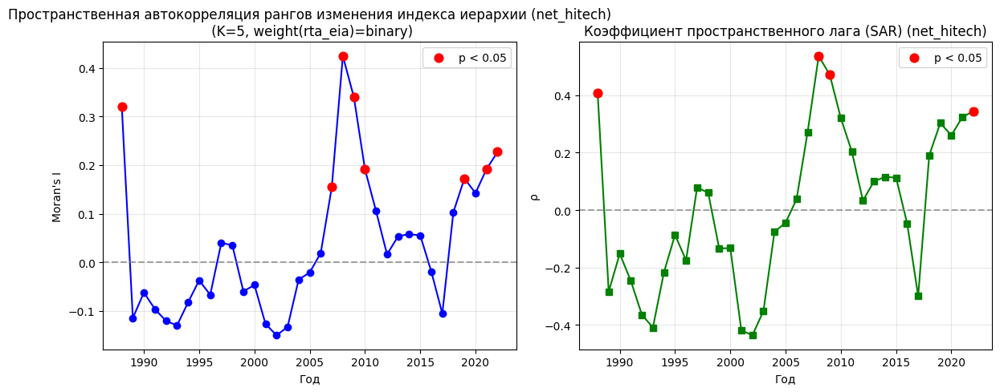

In [1014]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['rta', 'rta_eia']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            remove_isolates=False  # Они и так убираются, просто на другом этапе. Диагностический параметр
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [1015]:
print_spatial_results(results, 'rta','rta_eia')

athlas Moran's I=0.12** (rta)
athlas binary Moran's I=0.091** (rta)
athlas Moran's I=0.201* (rta_eia)
athlas binary Moran's I=0.161† (rta_eia)
gpi Moran's I=0.084** (rta)
gpi binary Moran's I=0.049** (rta)
gpi Moran's I=0.157† (rta_eia)
gpi binary Moran's I=0.174* (rta_eia)
cinc Moran's I=0.26** (rta)
cinc binary Moran's I=0.218** (rta)
cinc Moran's I=0.444** (rta_eia)
cinc binary Moran's I=0.315** (rta_eia)
gdp Moran's I=0.264** (rta)
gdp binary Moran's I=-0.012 (rta)
gdp Moran's I=0.39** (rta_eia)
gdp binary Moran's I=-0.023 (rta_eia)
net_subsystem Moran's I=0.078** (rta)
net_subsystem binary Moran's I=0.143** (rta)
net_subsystem Moran's I=0.242** (rta_eia)
net_subsystem binary Moran's I=0.385** (rta_eia)
net Moran's I=0.093** (rta)
net binary Moran's I=0.154** (rta)
net Moran's I=0.092 (rta_eia)
net binary Moran's I=0.357** (rta_eia)
gdp_beckley Moran's I=0.282** (rta)
gdp_beckley binary Moran's I=-0.019 (rta)
gdp_beckley Moran's I=0.615** (rta_eia)
gdp_beckley binary Moran's I=-0.0

In [1041]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['rta', 'rta_eia']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

INFO:root:Фильтр по годам: [1985, 1986, 1987, 1988, 1995, 1996, 1997, 1998, 1989, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2010, 2011, 2012, 2013] (n=26)
INFO:root:Starting Moran for rta / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0075
INFO:root:p-value (перестановочный) = 0.1380
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0355
INFO:root:p-value (перестановочный) = 0.0170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[athlas/rta] Moran (binary): I = 0.0209, p_sim = 0.0710


(1,) None
(1,) None


INFO:root:Starting Moran for rta / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 175
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0129
INFO:root:p-value (перестановочный) = 0.0740
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0530
INFO:root:p-value (перестановочный) = 0.0070
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gpi/rta] Moran (binary): I = 0.0561, p_sim = 0.0040
INFO:root:Starting Moran for rta_eia / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица смежности построена: (43, 43), средняя

(1,) None
(1,) None


INFO:root:Starting Moran for rta / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0292
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2564
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/rta] Moran (binary): I = 0.1618, p_sim = 0.0010
INFO:root:Starting Moran for rta_eia / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расс

(1,) None
(1,) None


INFO:root:[cinc/rta_eia] Moran (binary): I = 0.2180, p_sim = 0.0200
INFO:root:Starting Moran for rta / gdp
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0072
INFO:root:p-value (перестановочный) = 0.1210
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2867
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/rta] Moran (binary): I = -0.0115, p_sim = 0.4320
INFO:root:Starting Moran for rta_eia / gdp
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран, по которым есть расстояния 

(1,) None
(1,) None


INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/rta_eia] Moran (binary): I = nan, p_sim = 0.0010
INFO:root:Starting Moran for rta / net_subsystem
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0046
INFO:root:p-value (перестановочный) = 0.4320
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0397
INFO:root:p-value (перестановочный) = 0.0130
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляц

(1,) None
(1,) None


INFO:root:Starting Moran for rta / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0019
INFO:root:p-value (перестановочный) = 0.3610
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0503
INFO:root:p-value (перестановочный) = 0.0080
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/rta] Moran (binary): I = 0.0830, p_sim = 0.0010
INFO:root:Starting Moran for rta_eia / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средня

(1,) None
(1,) None


INFO:root:Starting Moran for rta / gdp_beckley
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица смежности построена: (181, 181), средняя степень = 45.16, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0062
INFO:root:p-value (перестановочный) = 0.0480
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3218
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/rta] Moran (binary): I = -0.0091, p_sim = 0.4650
INFO:root:Starting Moran for rta_eia / gdp_beckley
INFO:root:Размер таблицы дельт: (192, 2)
INFO:root:Стран

(1,) None
(1,) None


INFO:root:Starting Moran for rta / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 177
INFO:root:Матрица смежности построена: (177, 177), средняя степень = 44.77, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0022
INFO:root:p-value (перестановочный) = 0.1670
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3394
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/rta] Moran (binary): I = 0.0268, p_sim = 0.0380
INFO:root:Starting Moran for rta_eia / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица см

(1,) None
(1,) None


INFO:root:Starting Moran for rta / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0044
INFO:root:p-value (перестановочный) = 0.1930
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0708
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_hitech/rta] Moran (binary): I = 0.0785, p_sim = 0.0010
INFO:root:Starting Moran for rta_eia / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построе

(1,) None
(1,) None


INFO:root:[net_hitech/rta_eia] Moran (binary): I = 0.2355, p_sim = 0.0190


In [1042]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_rta_turmoilyears.csv')
table

,I Морана для псевдососедства по рег.торговым соглашениям,Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям,I Морана для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза,Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза
Индекс положения в иерархии,,,,
Индекс национальной мощи,"0,007ns","0,021†","-0,012ns","-0,006ns"
Глобальный индекс власти,"0,013†","0,056**","-0,050ns","0,286**"
Индекс CINC,"0,029**","0,162**","-0,038ns","0,218*"
ВВП (номинал),"0,007ns","-0,011ns","-0,044ns",—
Системно-сетевой индекс,"-0,002ns","0,083**","0,227*","0,532**"
Индекс Бэкли,"0,006*","-0,009ns","0,140†",—
Индекс Бэкли (ППС),"0,002ns","0,027*","0,041ns",—


In [1043]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
_years_filter = FILTER_YEARS['stableyears']
#_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['rta', 'rta_eia']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

INFO:root:Фильтр по годам: [1989, 1990, 1991, 1992, 1993, 1994, 2008, 2009, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022] (n=17)
INFO:root:Starting Moran for rta / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0173
INFO:root:p-value (перестановочный) = 0.0160
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0228
INFO:root:p-value (перестановочный) = 0.0770
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I НЕ значим.
INFO:root:[athlas/rta] Moran (binary): I = 0.0426, p_sim = 0.0080
INFO:root:Starting Moran for rta_eia / athlas
INFO:roo

(1,) None
(1,) None


INFO:root:Starting Moran for rta / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 175
INFO:root:Матрица смежности построена: (175, 175), средняя степень = 46.24, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0074
INFO:root:p-value (перестановочный) = 0.1410
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0997
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0057
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gpi/rta] Moran (binary): I = 0.0450, p_sim = 0.0080
INFO:root:Starting Moran for rta_eia / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица смежности построена: (43, 43), средняя

(1,) None
(1,) None


INFO:root:[gpi/rta_eia] Moran (binary): I = -0.0120, p_sim = 0.4150
INFO:root:Starting Moran for rta / cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 183
INFO:root:Матрица смежности построена: (183, 183), средняя степень = 45.56, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0281
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1830
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[cinc/rta] Moran (binary): I = 0.1351, p_sim = 0.0010
INFO:root:Starting Moran for rta_eia / cinc
INFO:root:

(1,) None
(1,) None


INFO:root:[cinc/rta_eia] Moran (binary): I = 0.3074, p_sim = 0.0060
INFO:root:Starting Moran for rta / gdp
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 182
INFO:root:Матрица смежности построена: (182, 182), средняя степень = 45.45, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0164
INFO:root:p-value (перестановочный) = 0.0470
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2300
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/rta] Moran (binary): I = 0.0592, p_sim = 0.0060
INFO:root:Starting Moran for rta_eia / gdp
INFO:root:Раз

(1,) None
(1,) None


INFO:root:I = 0.3371
INFO:root:p-value (перестановочный) = 0.0020
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0233
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp/rta_eia] Moran (binary): I = 0.0742, p_sim = 0.1470
INFO:root:Starting Moran for rta / net_subsystem
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0112
INFO:root:p-value (перестановочный) = 0.3400
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0353
INFO:root:p-value (перестановочный) = 0.0180
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается прост

(1,) None
(1,) None


INFO:root:[net_subsystem/rta_eia] Moran (binary): I = 0.2324, p_sim = 0.0130
INFO:root:Starting Moran for rta / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = -0.0024
INFO:root:p-value (перестановочный) = 0.4260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0650
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net/rta] Moran (binary): I = 0.0698, p_sim = 0.0010
INFO:root:Starting Moran for rta_eia / net
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть ра

(1,) None
(1,) None


INFO:root:Starting Moran for rta / gdp_beckley
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 182
INFO:root:Матрица смежности построена: (182, 182), средняя степень = 45.45, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0064
INFO:root:p-value (перестановочный) = 0.0630
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2498
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley/rta] Moran (binary): I = 0.0212, p_sim = 0.0700
INFO:root:Starting Moran for rta_eia / gdp_beckley
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности пост

(1,) None
(1,) None


INFO:root:Starting Moran for rta / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 178
INFO:root:Матрица смежности построена: (178, 178), средняя степень = 45.06, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0111
INFO:root:p-value (перестановочный) = 0.0560
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2735
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[gdp_beckley_ppp/rta] Moran (binary): I = 0.0475, p_sim = 0.0090
INFO:root:Starting Moran for rta_eia / gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 43
INFO:root:Матрица см

(1,) None
(1,) None


INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 184
INFO:root:Матрица смежности построена: (184, 184), средняя степень = 45.64, изолированных вершин = 0
INFO:root:=== Moran's I ===
INFO:root:I = 0.0077
INFO:root:p-value (перестановочный) = 0.1540
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.0339
INFO:root:p-value (перестановочный) = 0.0260
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0055
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[net_hitech/rta] Moran (binary): I = 0.0419, p_sim = 0.0090
INFO:root:Starting Moran for rta_eia / net_hitech
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 44
INFO:root:Матрица смежности построена: (44, 44), средняя степень = 5.86, изолиров

(1,) None
(1,) None


In [1044]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_rta_stableyears.csv')
table

,I Морана для псевдососедства по рег.торговым соглашениям,Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям,I Морана для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза,Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза
Индекс положения в иерархии,,,,
Индекс национальной мощи,"0,017*","0,043**","0,146*","0,152*"
Глобальный индекс власти,"0,007ns","0,045**","0,008ns","-0,012ns"
Индекс CINC,"0,028**","0,135**","-0,025ns","0,307**"
ВВП (номинал),"0,016*","0,059**","0,218*","0,074ns"
Системно-сетевой индекс,"-0,002ns","0,070**","0,015ns","0,283**"
Индекс Бэкли,"0,006†","0,021†","0,255*","0,234*"
Индекс Бэкли (ППС),"0,011†","0,048**","0,195**","0,336**"


### Гипотеза 12

In [2186]:
import numpy as np
import pandas as pd
import logging
from scipy import stats

# ======================================================================
# ОСНОВНОЙ ТЕСТ Г-12
# ======================================================================
def test_hypothesis_G12(df_y, name_y, df_x, horizon=3, k_neighbors=5,
                        weight_type='inverse',
                        year_for_deltas=None,
                        hostility_year=None,
                        hostility_agg='mean',
                        hostility_thresholds=(0.7, 1.1),
                        hostility_labels=('friendly', 'neutral', 'hostile'),
                        base_category=None,        # NEW: None → авто
                        ipd_df=None,
                        w_for_hostility=True,
                        exclude_outliers_sd=3.0,
                        rank_y=True,
                        rank_hostility=True,
                        verbose=True, 
                        years_filter='allyears'):

    """
    Прямой тест гипотезы Г-12.

    Модель:
        delta_mean_i = rho * W delta_mean_i +
                       alpha + sum_g beta_g * 1[hostility_i = g] +
                       epsilon_i

    где base-категория — 'neutral'. Тестируем H0: beta_friendly = 0
    против H1: beta_friendly > 0 (с учётом знака athlas).

    Возвращает dict с моделями: dummies, continuous, robust.
    """
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    df_y = df_y[~df_y['year'].isin(FILTER_YEARS[years_filter])]
    
    # --- 1. Дельты ---
    deltas = compute_deltas(
        df_y, horizons=(horizon,), year=year_for_deltas,
        return_yearly_mean=(year_for_deltas is None)
    )
    logging.info(f"Дельт: {deltas.shape}")
    if rank_y:
        deltas['delta_mean']=deltas.rank(ascending=False).reset_index()['delta_mean']

    # --- 2. Матрица весов (нужна до hostility, если w_for_hostility=True) ---
    dist_matrix = get_distance_matrix(df_x, deltas)
    W_matrix, country_names = build_weights_knn(
        dist_matrix, k=k_neighbors, weight_type=weight_type
    )

    # --- 3. Hostility score / категория ---
    w_obj = full2W(W_matrix, ids=list(country_names))
    deltas = add_power_cat(
        deltas,
        ignore_super=False,
        ipd_df=ipd_df,
        w=(w_obj if w_for_hostility else None),
        hostility_year=hostility_year,
        hostility_agg=hostility_agg,
        hostility_thresholds=hostility_thresholds,
        hostility_labels=hostility_labels,
    )
    if rank_hostility:
        deltas['hostility_score'] = deltas['hostility_score'].rank()

    # --- 4. Выравниваем векторы ---
    deltas_idx = deltas.set_index('country').reindex(country_names)
    y_raw = deltas_idx['delta_mean'].values
    hostility = deltas_idx['hostility'].values
    hostility_score = deltas_idx['hostility_score'].values

    # --- 5. Выбрасываем unknown и NaN ---
    keep = (hostility != 'unknown') & ~pd.isna(y_raw) & ~pd.isna(hostility_score)
    n_drop_unknown = (hostility == 'unknown').sum()
    n_drop_nan = pd.isna(y_raw).sum()
    logging.info(f"Исключено: unknown={n_drop_unknown}, NaN={n_drop_nan}")

    y_clean = y_raw[keep]
    hostility_clean = hostility[keep]
    score_clean = hostility_score[keep]
    names_clean = [country_names[i] for i in range(len(country_names)) if keep[i]]

    # --- 6. Убираем выбросы по |y - median| > k*MAD ---
    if exclude_outliers_sd is not None:
        med = np.median(y_clean)
        mad = np.median(np.abs(y_clean - med))
        # 1.4826 * MAD ≈ SD для нормальных
        sd_robust = 1.4826 * mad
        outlier_mask = np.abs(y_clean - med) > exclude_outliers_sd * sd_robust
        n_out = outlier_mask.sum()
        if n_out:
            logging.info(f"Выбросов удалено: {n_out} "
                         f"(порог {exclude_outliers_sd}×MAD)")
        keep2 = ~outlier_mask
        y_clean = y_clean[keep2]
        hostility_clean = hostility_clean[keep2]
        score_clean = score_clean[keep2]
        names_clean = [names_clean[i] for i in range(len(names_clean)) if keep2[i]]

    # Пересобираем W под финальную выборку
    id_order = list(w_obj.id_order)
    pos = [id_order.index(c) for c in names_clean]
    W_clean = W_matrix[np.ix_(pos, pos)]
    w_clean = full2W(W_clean, ids=names_clean)

    # --- 7. Диагностика ---
    if verbose:
        print("\n=== Распределение режимов ===")
        print(pd.Series(hostility_clean).value_counts())
        print("\n=== Средние delta_mean по режимам ===")
        print(pd.DataFrame({
            'hostility': hostility_clean,
            'delta_mean': y_clean
        }).groupby('hostility')['delta_mean']
          .agg(['count', 'mean', 'std', 'median']))

    # --- 8. Модель 1: SAR с dummy-режимами ---
    unique_cats = sorted(set(hostility_clean))
    
    # Базовая категория
    if base_category is None:
        # предпочитаем 'neutral', если есть; иначе самую крупную
        if 'neutral' in unique_cats:
            base = 'neutral'
        else:
            base = pd.Series(hostility_clean).value_counts().idxmax()
            logging.warning(
                f"'neutral' не найден среди {unique_cats}. "
                f"Базовая категория выбрана автоматически: '{base}'."
            )
    else:
        if base_category not in unique_cats:
            raise ValueError(
                f"base_category='{base_category}' отсутствует среди "
                f"меток: {unique_cats}"
            )
        base = base_category
    
    cats = [c for c in unique_cats if c != base]
    if len(cats) == 0:
        raise ValueError(
            f"Не осталось категорий для dummy-переменных. "
            f"Уникальные метки: {unique_cats}, базовая: '{base}'"
        )
    
    D = np.column_stack([(hostility_clean == c).astype(float) for c in cats])
    D_names = [f'reg_{c}' for c in cats]
    
    logging.info(f"Базовая категория: '{base}'; dummy: {D_names}")
    
    model_dummies = ML_Lag(
        y_clean, np.column_stack([np.ones(len(y_clean)), D]),
        w=w_clean,
        name_y=name_y,
        name_x=['const'] + D_names,
        name_w=f'w_{weight_type}'
    )


    # --- 9. Модель 2: SAR с continuous hostility_score ---
    # Нормируем score для интерпретируемости
    score_z = (score_clean - score_clean.mean()) / score_clean.std()

    model_continuous = ML_Lag(
        y_clean, np.column_stack([np.ones(len(y_clean)), score_z]),
        w=w_clean,
        name_y=name_y,
        name_x=['const', 'hostility_score_z'],
        name_w=f'w_{weight_type}'
    )
    logging.info("=== SAR с continuous hostility_score (z-нормирован) ===")
    logging.info(model_continuous.summary)
    logging.info("=== Dummy ===")
    
    logging.info(model_dummies.summary)

    #print(hostility_clean)
    
    #X, name_x = _prepare_data(y_clean, exog=None, add_const=True, exog_names=[])
    #print(name_x)
    # 9.1 - SAR REGIMES Encountered bug in library
    #model_sar_regimes = ML_Lag_Regimes(y_clean, X, w=w_clean, regimes=pd.Series(hostility_clean),
    #                           name_y=name_y, name_x=name_x, name_w=f'w_{weight_type}', regime_lag_sep=False)

    # --- 10. Сводка для гипотезы ---
    # Направление: athlas обычно 1=верх, тогда delta<0 = подъём.
    # Поэтому для Г-12 хотим beta_friendly < 0 (улучшение позиции).
    # Если у вас athlas 1=низ (проверьте!), знак переворачивается.
    summary = {
        'n_total': len(y_clean),
        'n_by_regime': pd.Series(hostility_clean).value_counts().to_dict(),
        'base_category': base,
        'categories': cats,
        'mean_delta_by_regime': pd.DataFrame({
            'hostility': hostility_clean,
            'delta_mean': y_clean
        }).groupby('hostility')['delta_mean'].mean().to_dict(),
        'model_dummies': model_dummies,
        'model_continuous': model_continuous,
        'y': y_clean,
        'hostility': hostility_clean,
        'hostility_score': score_clean,
        'names': names_clean,
        'w': w_clean,
    }

    return summary


# ======================================================================
# ЗАПУСК
# ======================================================================
res_12 = {}
for power_cat in power_dfs:
    if 'ihes' in power_cat:
        continue
    if 'subsystem' in power_cat:
        continue
    res_12[power_cat] = test_hypothesis_G12(
        df_y=power_dfs[power_cat],       # ← ваша таблица с athlas
        name_y=power_cat,
        df_x=predictor_dfs['geodistance'],                      # ← ваша таблица расстояний
        horizon=3,
        k_neighbors=5,
        year_for_deltas=None,           # усреднение по годам
        hostility_year=None,
        hostility_agg='mean',
        hostility_thresholds=(0.3, 0.7),
        hostility_labels=('friendly', 'neutral', 'hostile'),
        w_for_hostility=True,
        base_category='neutral',
        weight_type='inverse',
        verbose=False
    )

INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :      athlas                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :           3
S.D. dependent var  :     55.8585                Degrees of Freedom    :         190
Pseudo R-squared    :      0.1097
Spatial Pseudo R-squared:  0.0139
Log likelihood      :  -1042.4046
Sigma-square ML     :   2804.6821                Akaike info criterion :    2090.809
S.E of regression   :     52.9592             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gpi                Number of Observations:         181
Mean dependent var  :     91.4862                Number of Variables   :           3
S.D. dependent var  :     52.8288                Degrees of Freedom    :         178
Pseudo R-squared    :      0.0747
Spatial Pseudo R-squared:  0.0005
Log likelihood      :   -969.8880
Sigma-square ML     :   2596.2396                Akaike info criterion :    1945.776
S.E of regression   :     50.9533             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :        cinc                Number of Observations:         193
Mean dependent var  :     97.0570                Number of Variables   :           3
S.D. dependent var  :     55.9552                Degrees of Freedom    :         190
Pseudo R-squared    :      0.4102
Spatial Pseudo R-squared:  0.0569
Log likelihood      :  -1013.4126
Sigma-square ML     :   1926.7533                Akaike info criterion :    2032.825
S.E of regression   :     43.8948             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gdp                Number of Observations:         191
Mean dependent var  :     96.3246                Number of Variables   :           3
S.D. dependent var  :     55.6625                Degrees of Freedom    :         188
Pseudo R-squared    :      0.2944
Spatial Pseudo R-squared:  0.0260
Log likelihood      :  -1014.0266
Sigma-square ML     :   2239.5609                Akaike info criterion :    2034.053
S.E of regression   :     47.3240             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         net                Number of Observations:         193
Mean dependent var  :     97.7876                Number of Variables   :           3
S.D. dependent var  :     56.4389                Degrees of Freedom    :         190
Pseudo R-squared    :      0.1063
Spatial Pseudo R-squared:  0.0225
Log likelihood      :  -1043.5656
Sigma-square ML     :   2852.5258                Akaike info criterion :    2093.131
S.E of regression   :     53.4090             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_beckley                Number of Observations:         191
Mean dependent var  :     96.4084                Number of Variables   :           3
S.D. dependent var  :     55.7013                Degrees of Freedom    :         188
Pseudo R-squared    :      0.4154
Spatial Pseudo R-squared:  0.0412
Log likelihood      :  -1000.9699
Sigma-square ML     :   1888.1424                Akaike info criterion :    2007.940
S.E of regression   :     43.4528             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :gdp_beckley_ppp                Number of Observations:         185
Mean dependent var  :     93.3243                Number of Variables   :           3
S.D. dependent var  :     53.9303                Degrees of Freedom    :         182
Pseudo R-squared    :      0.4000
Spatial Pseudo R-squared:  0.0006
Log likelihood      :   -965.3367
Sigma-square ML     :   1812.5606                Akaike info criterion :    1936.673
S.E of regression   :     42.5742          

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :  net_hitech                Number of Observations:         193
Mean dependent var  :     98.2487                Number of Variables   :           3
S.D. dependent var  :     56.7601                Degrees of Freedom    :         190
Pseudo R-squared    :      0.1634
Spatial Pseudo R-squared:  0.0224
Log likelihood      :  -1041.4326
Sigma-square ML     :   2741.3601                Akaike info criterion :    2088.865
S.E of regression   :     52.3580             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :     gdp_ppp                Number of Observations:         185
Mean dependent var  :     93.3243                Number of Variables   :           3
S.D. dependent var  :     53.9303                Degrees of Freedom    :         182
Pseudo R-squared    :      0.2925
Spatial Pseudo R-squared:  0.0198
Log likelihood      :   -976.1736
Sigma-square ML     :   2102.5385                Akaike info criterion :    1958.347
S.E of regression   :     45.8534             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_nominal                Number of Observations:         191
Mean dependent var  :     96.4031                Number of Variables   :           3
S.D. dependent var  :     55.6996                Degrees of Freedom    :         188
Pseudo R-squared    :      0.3036
Spatial Pseudo R-squared:  0.0197
Log likelihood      :  -1013.7222
Sigma-square ML     :   2223.0492                Akaike info criterion :    2033.444
S.E of regression   :     47.1492             

ML_Lag
ML_Lag


In [2187]:
# ======================================================================
# ЗАПУСК
# ======================================================================
logging.info('unstable only')
res_12_unstable = {}
for power_cat in power_dfs:
    if 'ihes' in power_cat:
        continue
    if 'subsystem' in power_cat:
        continue
    res_12_unstable[power_cat] = test_hypothesis_G12(
        df_y=power_dfs[power_cat],       # ← ваша таблица с athlas
        name_y=power_cat,
        df_x=predictor_dfs['geodistance'],                      # ← ваша таблица расстояний
        horizon=3,
        k_neighbors=5,
        year_for_deltas=None,           # усреднение по годам
        hostility_year=None,
        hostility_agg='mean',
        hostility_thresholds=(0.3, 0.7),
        hostility_labels=('friendly', 'neutral', 'hostile'),
        w_for_hostility=True,
        base_category='neutral',
        weight_type='inverse',
        verbose=False,
        years_filter='stableyears'
    )

INFO:root:unstable only
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :      athlas                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :           3
S.D. dependent var  :     55.8585                Degrees of Freedom    :         190
Pseudo R-squared    :      0.0213
Spatial Pseudo R-squared:  0.0049
Log likelihood      :  -1048.3209
Sigma-square ML     :   3044.2624                Akaike info criterion :    2102.642
S.E of regression   :     55.1748             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gpi                Number of Observations:         181
Mean dependent var  :     91.4751                Number of Variables   :           3
S.D. dependent var  :     52.8281                Degrees of Freedom    :         178
Pseudo R-squared    :      0.0035
Spatial Pseudo R-squared:  0.0002
Log likelihood      :   -974.1379
Sigma-square ML     :   2766.5737                Akaike info criterion :    1954.276
S.E of regression   :     52.5982             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :        cinc                Number of Observations:         192
Mean dependent var  :     97.4219                Number of Variables   :           3
S.D. dependent var  :     55.8382                Degrees of Freedom    :         189
Pseudo R-squared    :      0.2842
Spatial Pseudo R-squared:  0.0493
Log likelihood      :  -1021.8499
Sigma-square ML     :   2297.6319                Akaike info criterion :    2049.700
S.E of regression   :     47.9336             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gdp                Number of Observations:         190
Mean dependent var  :     95.8316                Number of Variables   :           3
S.D. dependent var  :     55.3780                Degrees of Freedom    :         187
Pseudo R-squared    :      0.2810
Spatial Pseudo R-squared:  0.0115
Log likelihood      :  -1008.5312
Sigma-square ML     :   2247.5370                Akaike info criterion :    2023.062
S.E of regression   :     47.4082             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         net                Number of Observations:         192
Mean dependent var  :     98.2292                Number of Variables   :           3
S.D. dependent var  :     56.7726                Degrees of Freedom    :         189
Pseudo R-squared    :      0.0698
Spatial Pseudo R-squared:  0.0086
Log likelihood      :  -1042.5910
Sigma-square ML     :   3003.5869                Akaike info criterion :    2091.182
S.E of regression   :     54.8050             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_beckley                Number of Observations:         190
Mean dependent var  :     95.9000                Number of Variables   :           3
S.D. dependent var  :     55.4098                Degrees of Freedom    :         187
Pseudo R-squared    :      0.4808
Spatial Pseudo R-squared:  0.0028
Log likelihood      :   -985.2933
Sigma-square ML     :   1663.4513                Akaike info criterion :    1976.587
S.E of regression   :     40.7854             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :gdp_beckley_ppp                Number of Observations:         184
Mean dependent var  :     92.8043                Number of Variables   :           3
S.D. dependent var  :     53.6288                Degrees of Freedom    :         181
Pseudo R-squared    :      0.4831
Spatial Pseudo R-squared:  0.0002
Log likelihood      :   -947.5096
Sigma-square ML     :   1548.3596                Akaike info criterion :    1901.019
S.E of regression   :     39.3492          

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :  net_hitech                Number of Observations:         192
Mean dependent var  :     98.3073                Number of Variables   :           3
S.D. dependent var  :     56.7566                Degrees of Freedom    :         189
Pseudo R-squared    :      0.0468
Spatial Pseudo R-squared:  0.0032
Log likelihood      :  -1044.5945
Sigma-square ML     :   3078.6105                Akaike info criterion :    2095.189
S.E of regression   :     55.4852             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :     gdp_ppp                Number of Observations:         184
Mean dependent var  :     92.7989                Number of Variables   :           3
S.D. dependent var  :     53.6251                Degrees of Freedom    :         181
Pseudo R-squared    :      0.3195
Spatial Pseudo R-squared:  0.0222
Log likelihood      :   -966.4349
Sigma-square ML     :   1995.9079                Akaike info criterion :    1938.870
S.E of regression   :     44.6756             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
INFO:root:Исключено: unknown=1, NaN=1
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_nominal                Number of Observations:         190
Mean dependent var  :     95.8842                Number of Variables   :           3
S.D. dependent var  :     55.4039                Degrees of Freedom    :         187
Pseudo R-squared    :      0.3029
Spatial Pseudo R-squared:  0.0071
Log likelihood      :  -1006.6503
Sigma-square ML     :   2189.3748                Akaike info criterion :    2019.301
S.E of regression   :     46.7908             

ML_Lag
ML_Lag


In [2189]:
# ======================================================================
# ЗАПУСК
# ======================================================================
logging.info('stable only')
res_12_stable = {}
for power_cat in power_dfs:
    if 'ihes' in power_cat:
        continue
    if 'subsystem' in power_cat:
        continue
    res_12_stable[power_cat] = test_hypothesis_G12(
        df_y=power_dfs[power_cat],       # ← ваша таблица с athlas
        name_y=power_cat,
        df_x=predictor_dfs['geodistance'],                      # ← ваша таблица расстояний
        horizon=3,
        k_neighbors=5,
        year_for_deltas=None,           # усреднение по годам
        hostility_year=None,
        hostility_agg='mean',
        hostility_thresholds=(0.3, 0.7),
        hostility_labels=('friendly', 'neutral', 'hostile'),
        w_for_hostility=True,
        base_category='neutral',
        weight_type='inverse',
        verbose=False,
        years_filter='turmoilyears'
    )


INFO:root:stable only
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193


(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :      athlas                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :           3
S.D. dependent var  :     55.8585                Degrees of Freedom    :         190
Pseudo R-squared    :      0.0392
Spatial Pseudo R-squared:  0.0127
Log likelihood      :  -1046.9247
Sigma-square ML     :   2991.1532                Akaike info criterion :    2099.849
S.E of regression   :     54.6914             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (182, 182)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gpi                Number of Observations:         181
Mean dependent var  :     91.5746                Number of Variables   :           3
S.D. dependent var  :     52.8195                Degrees of Freedom    :         178
Pseudo R-squared    :      0.0912
Spatial Pseudo R-squared:  0.0070
Log likelihood      :   -968.8092
Sigma-square ML     :   2555.5277                Akaike info criterion :    1943.618
S.E of regression   :     50.5522             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=0, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :        cinc                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :           3
S.D. dependent var  :     55.8585                Degrees of Freedom    :         190
Pseudo R-squared    :      0.1394
Spatial Pseudo R-squared:  0.0037
Log likelihood      :  -1040.6777
Sigma-square ML     :   2732.5551                Akaike info criterion :    2087.355
S.E of regression   :     52.2738             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=3
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         gdp                Number of Observations:         189
Mean dependent var  :     95.3228                Number of Variables   :           3
S.D. dependent var  :     55.0840                Degrees of Freedom    :         186
Pseudo R-squared    :      0.2602
Spatial Pseudo R-squared:  0.0101
Log likelihood      :  -1006.0525
Sigma-square ML     :   2312.5187                Akaike info criterion :    2018.105
S.E of regression   :     48.0887             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :         net                Number of Observations:         193
Mean dependent var  :     97.4611                Number of Variables   :           3
S.D. dependent var  :     56.4991                Degrees of Freedom    :         190
Pseudo R-squared    :      0.0478
Spatial Pseudo R-squared:  0.0065
Log likelihood      :  -1048.6701
Sigma-square ML     :   3038.2798                Akaike info criterion :    2103.340
S.E of regression   :     55.1206             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=3
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_beckley                Number of Observations:         189
Mean dependent var  :     95.1587                Number of Variables   :           3
S.D. dependent var  :     54.9364                Degrees of Freedom    :         186
Pseudo R-squared    :      0.2722
Spatial Pseudo R-squared:  0.0156
Log likelihood      :  -1003.8128
Sigma-square ML     :   2255.6686                Akaike info criterion :    2013.626
S.E of regression   :     47.4939             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :gdp_beckley_ppp                Number of Observations:         185
Mean dependent var  :     93.1514                Number of Variables   :           3
S.D. dependent var  :     53.7729                Degrees of Freedom    :         182
Pseudo R-squared    :      0.2671
Spatial Pseudo R-squared:  0.0027
Log likelihood      :   -979.4678
Sigma-square ML     :   2181.3931                Akaike info criterion :    1964.936
S.E of regression   :     46.7054          

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (194, 194)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :  net_hitech                Number of Observations:         193
Mean dependent var  :     97.4715                Number of Variables   :           3
S.D. dependent var  :     56.2900                Degrees of Freedom    :         190
Pseudo R-squared    :      0.0347
Spatial Pseudo R-squared:  0.0029
Log likelihood      :  -1049.0667
Sigma-square ML     :   3057.4553                Akaike info criterion :    2104.133
S.E of regression   :     55.2943             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (186, 186)
INFO:root:Исключено: unknown=1, NaN=0
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  :     gdp_ppp                Number of Observations:         185
Mean dependent var  :     93.2919                Number of Variables   :           3
S.D. dependent var  :     53.9088                Degrees of Freedom    :         182
Pseudo R-squared    :      0.2597
Spatial Pseudo R-squared:  0.0082
Log likelihood      :   -980.6938
Sigma-square ML     :   2214.1003                Akaike info criterion :    1967.388
S.E of regression   :     47.0542             

ML_Lag
ML_Lag
(3,) None
index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['value', 'country_b', 'country_a']
col dupes  : 0
dtypes     :
 value        float64
country_b        str
country_a        str
dtype: object
pairs dup  : 0


INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:Исключено: unknown=1, NaN=3
INFO:root:Базовая категория: 'neutral'; dummy: ['reg_friendly', 'reg_hostile']
INFO:root:=== SAR с continuous hostility_score (z-нормирован) ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :   w_inverse
Dependent Variable  : gdp_nominal                Number of Observations:         189
Mean dependent var  :     95.3280                Number of Variables   :           3
S.D. dependent var  :     55.0872                Degrees of Freedom    :         186
Pseudo R-squared    :      0.2752
Spatial Pseudo R-squared:  0.0106
Log likelihood      :  -1004.7074
Sigma-square ML     :   2270.8030                Akaike info criterion :    2015.415
S.E of regression   :     47.6529             

ML_Lag
ML_Lag


### Гипотеза 12-Д

In [2201]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['allyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['ipd']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[~df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )
      
        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)
        
        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

INFO:root:Фильтр по годам: [] (n=0)
INFO:root:Starting Moran for ipd / athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
INFO:root:=== Moran's I ===
INFO:root:I = 0.0145
INFO:root:p-value (перестановочный) = 0.1170
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1005
INFO:root:p-value (перестановочный) = 0.0100
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:[athlas/ipd] Moran (binary): I = 0.1205, p_sim = 0.0020
INFO:root:Starting Moran for ipd / gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица весов построена (K=5, inverse): (181, 1

### Гипотеза о союзниках США

In [1285]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from scipy import stats


# ---------- OLS + HC3 ----------
def fit_ols(X, y):
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    n, k = X.shape
    lr = LinearRegression().fit(X, y)
    beta = np.concatenate([[lr.intercept_], lr.coef_])
    Xc = np.column_stack([np.ones(n), X])
    resid = y - Xc @ beta
    XtX_inv = np.linalg.inv(Xc.T @ Xc)
    h = np.clip(np.diag(Xc @ XtX_inv @ Xc.T), 0, 1 - 1e-12)
    meat = Xc.T @ (((resid ** 2) / (1 - h) ** 2)[:, None] * Xc)
    vcov = XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.diag(vcov))
    t = beta / se
    p = 2 * (1 - stats.t.cdf(np.abs(t), df=n - k - 1))
    return beta, se, p, vcov, n


nato_d = predictor_dfs['atop_nato']
nato_d = nato_d[nato_d['value'] == 1]
nato = {}
for y, g in nato_d.groupby('year'):
    a = set(g.loc[g['country_a'] == 'United States', 'country_b'])
    b = set(g.loc[g['country_b'] == 'United States', 'country_a'])
    nato[int(y)] = (a | b) - {'United States'}

all_c = sorted(set(predictor_dfs['security_net']['country_a']))
nato_ever = set().union(*nato.values())
cand = [c for c in all_c if c not in nato_ever]
pool = set(np.random.default_rng(42).choice(cand, size=40, replace=False))


# ---------- агрегация влияния ----------
sn = predictor_dfs['security_net'][['country_a', 'country_b', 'year', 'value']].copy()
sn['value'] = pd.to_numeric(sn['value'], errors='coerce')

def influence(country):
    sub = sn[sn['country_a'] == country]
    v_n, v_p = [], []
    for y, g in sub.groupby('year'):
        members = nato.get(int(y), set())
        v_n += g.loc[g['country_b'].isin(members), 'value'].tolist()
        v_p += g.loc[g['country_b'].isin(pool), 'value'].tolist()
    v_n = [v for v in v_n if pd.notna(v)]
    v_p = [v for v in v_p if pd.notna(v)]
    return (sum(v_n) if v_n else np.nan,
            sum(v_p) if v_p else np.nan)


# ---------- прогон по power_dfs ----------
rows = []

for power_name, power_df in power_dfs.items():
    deltas = compute_deltas(power_df, horizons=(3,),
                            year=None, return_yearly_mean=True)
    delta_ser = deltas.set_index('country')['delta_mean']

    df = pd.DataFrame({'country': delta_ser.index,
                       'delta': delta_ser.values})
    df[['infl_nato', 'infl_nonwest']] = df['country'].apply(
        lambda c: pd.Series(influence(c)))
    df = df.dropna()

    if len(df) < 20:
        print(f"[SKIP] {power_name}: n={len(df)}")
        continue

    df['rank_delta'] = df['delta'].rank()

    beta, se, p, vcov, n = fit_ols(df[['infl_nato', 'infl_nonwest']].values,
                                   df['rank_delta'].values)

    # тест β_nato > β_nonwest
    diff = beta[1] - beta[2]
    se_d = np.sqrt(vcov[1, 1] + vcov[2, 2] - 2 * vcov[1, 2])
    z = diff / se_d
    p_one = 1 - stats.norm.cdf(z)

    rows.append({
        'power': power_name,
        'n': n,
        'beta_nato': beta[1],  'p_nato': p[1],
        'beta_nonwest': beta[2], 'p_nonwest': p[2],
        'diff': diff, 'z_diff': z, 'p_one': p_one,
    })

res = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:+.4f}'.format)
print(res.to_string(index=False))

INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (182, 2)


(3,) None


INFO:root:Размер таблицы дельт: (195, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes: n=0
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


[SKIP] ihes_new_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None
          power   n  beta_nato  p_nato  beta_nonwest  p_nonwest    diff  z_diff   p_one
         athlas 193    -0.0069 +0.7215       +0.0035    +0.7875 -0.0104 -0.4492 +0.6734
            gpi 182    -0.0031 +0.7114       -0.0008    +0.9381 -0.0023 -0.1298 +0.5517
           cinc 195    -0.0112 +0.5599       +0.0111    +0.4537 -0.0223 -0.8739 +0.8089
            gdp 192    -0.0032 +0.8922       +0.0145    +0.1140 -0.0176 -0.8796 +0.8104
  net_subsystem 196    +0.0029 +0.7282       -0.0095    +0.3000 +0.0124 +0.8183 +0.2066
            net 196    +0.0047 +0.3795       -0.0135    +0.0990 +0.0182 +1.3753 +0.0845
    gdp_beckley 192    +0.0024 +0.9217       +0.0052    +0.6167 -0.0028 -0.1293 +0.5514
gdp_beckley_ppp 186    +0.0021 +0.9282       +0.0053    +0.6266 -0.0033 -0.1501 +0.5596
     net_hitech 196    -0.0074 +0.5011       +0.0054    +0.5242 -0.0128 -0.8676 +0.8072


### Гипотеза 8

In [1423]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]
df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

for power_cat in power_dfs:
    if 'gdp' in power_cat:
        continue
    elif 'beckley' in power_cat:
        continue
    elif 'subsystem' in power_cat:
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')
    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)
    
    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    
    features = df_x_ranked.merge(deltas_ranked, left_on=('country_b','year'), right_on=('country','year'), how='inner').dropna()
    print(power_cat)
    print(features[['value',f'delta_{horizons[0]}', 'value_gdp']].corr())
    
    print(features.head())
    try:
        res[power_cat]=regression_analysis(features, target=f'delta_{horizons[0]}', models=models, feature_columns=['value','value_gdp'])
    except ValueError as E:
        res[power_cat]=({'ValueError':E},None)
#print(res)

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 4647, после удаления пропусков в целевой: 4647
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0207 (±0.0083)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0207
INFO:root:Веса финальной модели (coefficient): {'value': -8.188862889675546, 'value_gdp': 2.5816497585717664}
INFO:root:Intercept: 96.3200
INFO:root:=== Сводная таблица результатов (топ-10) ===
INFO:root:
           Model    K Horizon  Mean_R2  Std_R2  Mean_RMSE  Mean_MAE
LinearRegression None    

(3,) None
(3,) None
athlas
            value  delta_3  value_gdp
value     +1.0000  -0.1457    +0.0136
delta_3   -0.1457  +1.0000    +0.0441
value_gdp +0.0136  +0.0441    +1.0000
       value  year                                          country_b  \
384  +2.0000  1994  United Kingdom of Great Britain and Northern I...   
395  +5.0000  1994                                            Germany   
413 +33.0000  1994                                 Russian Federation   
498 +25.0000  1994                                              Japan   
524 +16.0000  1995                                             Canada   

     value_gdp                                            country  delta_3  
384    +5.0000  United Kingdom of Great Britain and Northern I...  +3.0000  
395   +10.0000                                            Germany  +1.0000  
413  +164.0000                                 Russian Federation  +2.0000  
498   +15.0000                                              Japan  +4.0000

INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 4937, после удаления пропусков в целевой: 4937
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0237 (±0.0038)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0237
INFO:root:Веса финальной модели (coefficient): {'value': 5.318427675350561, 'value_gdp': 7.055326673991568}
INFO:root:Intercept: 95.7628
INFO:root:=== Сводная таблица результатов (топ-10) ===
INFO:root:
           Model    K Horizon  Mean_R2  Std_R2  Mean_RMSE  Mean_MAE
LinearRegression None    None  +0.0237 +0.0038   +55.4156  +47.7303
INFO:root:=== Лучшая конфигурация ===
INFO:root:Модель: LinearRegression
INFO:root:K: 

net
            value  delta_3  value_gdp
value     +1.0000  +0.0960    +0.0095
delta_3   +0.0960  +1.0000    +0.1267
value_gdp +0.0095  +0.1267    +1.0000
         value  year           country_b  value_gdp             country  \
1241  +22.0000  1993              Canada   +34.0000              Canada   
1242  +82.0000  1993             Bahamas  +127.0000             Bahamas   
1244 +101.0000  1993               Haiti  +134.0000               Haiti   
1245  +56.0000  1993  Dominican Republic   +40.0000  Dominican Republic   
1246  +70.0000  1993             Jamaica   +68.0000             Jamaica   

       delta_3  
1241   +6.0000  
1242 +132.0000  
1244 +106.0000  
1245  +48.0000  
1246  +68.0000  
(3,) None
ihes
           value  delta_3  value_gdp
value        NaN      NaN        NaN
delta_3      NaN      NaN        NaN
value_gdp    NaN      NaN        NaN
Empty DataFrame
Columns: [value, year, country_b, value_gdp, country, delta_3]
Index: []
(3,) None
ihes_roles
           value  

In [1443]:
pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


(3,) None
=== athlas ===
        term      coef      se        t       p   ci_low   ci_high signif
0      const +106.0420 +4.9721 +21.3276 +0.0000 +96.2945 +115.7896    ***
1      value   -0.1530 +0.0341  -4.4837 +0.0000  -0.2199   -0.0861    ***
2  value_gdp   +0.0498 +0.0330  +1.5107 +0.1309  -0.0148   +0.1145       
R²=0.0233  adj R²=0.0229  F=55.51  p=0.000e+00  SE=cluster-robust (G=184)

(3,) None
=== gpi ===
        term     coef      se        t       p   ci_low  ci_high signif
0      const +72.0947 +6.4319 +11.2090 +0.0000 +59.4853 +84.7041    ***
1      value  -0.1560 +0.0349  -4.4649 +0.0000  -0.2245  -0.0875    ***
2  value_gdp  +0.4081 +0.0367 +11.1253 +0.0000  +0.3362  +0.4800    ***
R²=0.1711  adj R²=0.1707  F=491.74  p=0.000e+00  SE=cluster-robust (G=175)

(3,) None
=== cinc ===
        term      coef      se        t       p    ci_low   ci_high signif
0      const +116.8000 +5.0084 +23.3210 +0.0000 +106.9814 +126.6186    ***
1      value   -0.3594 +0.0328 -10.9483 +0.00

In [2206]:
FILTER_YEARS['stableyears']

[1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 2008,
 2009,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021,
 2022]

In [2209]:
# Без лишних лет

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=stableyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term      coef      se        t       p   ci_low   ci_high signif
0      const +109.1554 +5.6946 +19.1681 +0.0000 +97.9896 +120.3212    ***
1      value   -0.1939 +0.0364  -5.3212 +0.0000  -0.2654   -0.1225    ***
2  value_gdp   +0.0556 +0.0357  +1.5583 +0.1193  -0.0144   +0.1257       
R²=0.0358  adj R²=0.0351  F=55.44  p=0.000e+00  SE=cluster-robust (G=183)

=== gpi ===
        term     coef      se        t       p   ci_low  ci_high signif
0      const +77.9008 +7.6138 +10.2315 +0.0000 +62.9717 +92.8299    ***
1      value  -0.1804 +0.0422  -4.2696 +0.0000  -0.2632  -0.0975    ***
2  value_gdp  +0.3737 +0.0446  +8.3891 +0.0000  +0.2864  +0.4611    ***
R²=0.1485  adj R²=0.1479  F=250.54  p=0.000e+00  SE=cluster-robust (G=174)

=== cinc ===
        term      coef      se        t       p    ci_low   ci_high signif
0      const +119.0224 +5.8608 +20.3081 +0.0000 +107.5307 +130.5141    ***
1      value   -0.3460 +0.0378  -9.1555 +0.0000   -0.4201   -0.2719    ***


In [1520]:
# Без лишних лет

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=turmoilyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


(3,) None
(3,) None
=== athlas ===
        term      coef      se        t       p   ci_low   ci_high signif
0      const +100.7403 +6.8557 +14.6943 +0.0000 +87.2935 +114.1872    ***
1      value   -0.0843 +0.0462  -1.8266 +0.0679  -0.1748   +0.0062      .
2  value_gdp   +0.0390 +0.0436  +0.8940 +0.3714  -0.0465   +0.1245       
R²=0.0081  adj R²=0.0069  F=6.74  p=1.211e-03  SE=cluster-robust (G=184)

(3,) None
=== gpi ===
        term     coef      se        t       p   ci_low  ci_high signif
0      const +63.2432 +6.2958 +10.0452 +0.0000 +50.8957 +75.5907    ***
1      value  -0.1194 +0.0364  -3.2838 +0.0010  -0.1908  -0.0481     **
2  value_gdp  +0.4588 +0.0355 +12.9294 +0.0000  +0.3892  +0.5283    ***
R²=0.2134  adj R²=0.2125  F=256.17  p=0.000e+00  SE=cluster-robust (G=175)

(3,) None
=== cinc ===
        term      coef      se        t       p    ci_low   ci_high signif
0      const +113.5614 +5.7464 +19.7622 +0.0000 +102.2917 +124.8312    ***
1      value   -0.3789 +0.0379 -10.0

In [2215]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country_b', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
                       term      coef       se        t       p    ci_low  \
0                     const +129.6576 +12.1161 +10.7013 +0.0000 +105.9042   
1                     value   -0.7117  +0.1554  -4.5813 +0.0000   -1.0163   
2                 value_gdp   +0.0437  +0.0322  +1.3582 +0.1745   -0.0194   
3          cat_middle power  -15.2390 +17.7043  -0.8608 +0.3894  -49.9478   
4           cat_small power  -26.0263 +12.6903  -2.0509 +0.0403  -50.9052   
5  cat_middle power_x_value   +0.5010  +0.1820  +2.7532 +0.0059   +0.1443   
6   cat_small power_x_value   +0.5898  +0.1595  +3.6987 +0.0002   +0.2772   

    ci_high signif  
0 +153.4109    ***  
1   -0.4071    ***  
2   +0.1067         
3  +19.4698         
4   -1.1473      *  
5   +0.8578     **  
6   +0.9024    ***  
R²=0.0359  adj R²=0.0346  F=28.79  p=0.000e+00  SE=cluster-robust (G=184)

=== gpi ===
                       term      coef       se        t       p    ci_low  \
0                     const +136.484

#### Deprecated

### Гипотеза 9

In [2242]:
def test_h9(power_dfs, nato_df, horizon=1, hegem=HEGEMON,
            min_partners=5, filter_years='allyears'):
    nato_df = predictor_dfs['atop_nato'][predictor_dfs['atop_nato']['value'] == 1.]
    nato_map = dict()
    for y in range(YEAR_START['predictor'], YEAR_END['predictor']):
        nato_map[y] = set(nato_df[nato_df['year'] == y]['country_a']) - {hegem}

    rows = []

    for power_name, power_df in power_dfs.items():

        deltas = compute_deltas(power_dfs[power_name], horizons=(horizon,),
                                year=None, return_yearly_mean=False)
        deltas_ranked = deltas.copy()
        deltas_ranked[f'delta_{horizon}'] = (
            deltas_ranked.groupby(['year'])
                         .rank(ascending=False)[f'delta_{horizon}']
        )
        deltas_ranked = deltas_ranked[~deltas_ranked['year'].isin(FILTER_YEARS[filter_years])]
        #print(deltas_ranked[deltas_ranked['country'].str.contains('China')])

        us = (deltas_ranked[deltas_ranked['country'] == hegem]
              [['year', f'delta_{horizon}']]
              .groupby('year')
              .mean()[f'delta_{horizon}'])
        us_dict = us.to_dict()

        recs = []
        for year, members in nato_map.items():
            if year not in us_dict:
                continue
            du = us_dict[year]
            sub = deltas_ranked[(deltas_ranked['year'] == year)
                                & (deltas_ranked['country'].isin(members))]
            for _, r in sub.iterrows():
                recs.append({'country': r['country'],
                             'year': year,
                             'delta': float(r[f'delta_{horizon}']),
                             'delta_us': float(du)})

        d = pd.DataFrame(recs).dropna()
        if len(d) < 30 or d['country'].nunique() < min_partners:
            rows.append({'power': power_name, 'n': len(d),
                         'n_partners': d['country'].nunique() if len(d) else 0,
                         'n_years': d['year'].nunique() if len(d) else 0,
                         'beta': np.nan, 'se': np.nan,
                         't': np.nan, 'p': np.nan})
            continue

        # country FE (demean)
        d = d.copy()
        d['y_dm'] = d['delta'] - d.groupby('country')['delta'].transform('mean')
        #print(d)

        try:
            r = ols_inference(
                X=d[['delta_us']],                     # DataFrame → имена сохранятся
                y=d['y_dm'].to_numpy(dtype=float),
                add_constant=True,                     # как было в fit_ols_cluster
                cluster=d['year'].to_numpy(),          # кластеризация по годам
            )
        except (np.linalg.LinAlgError, ValueError) as e:
            print(f"[SKIP] {power_name}: {e}")
            rows.append({'power': power_name, 'n': len(d),
                         'n_partners': d['country'].nunique(),
                         'n_years': d['year'].nunique(),
                         'beta': np.nan, 'se': np.nan,
                         't': np.nan, 'p': np.nan})
            continue

        rows.append({
            'power':        power_name,
            'n':            r['n'],
            'n_partners':   d['country'].nunique(),
            'n_years':      d['year'].nunique(),
            'beta':         r['params']['delta_us'],
            'se':           r['se']['delta_us'],
            't':            r['t']['delta_us'],
            'p':            r['p']['delta_us'],
        })

    return pd.DataFrame(rows)

In [2243]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Размер таблицы дельт: (7024, 3)
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Размер таблицы дельт: (99272, 3)
INFO:root:Размер таблицы дельт: (62631, 3)
INFO:root:Размер таблицы дельт: (7179, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (7055, 3)
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Размер таблицы дельт: (7079, 3)
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Размер таблицы дельт: (7055, 3)


=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===
          power     n  n_partners  n_years    beta      se        t       p
         athlas   578          28       25 +0.0787 +0.0340  +2.3158 +0.0209
            gpi   694          28       33 +0.0263 +0.0631  +0.4165 +0.6772
           cinc   693          28       33 +0.0766 +0.0583  +1.3144 +0.1892
            gdp 10312          28       33 +0.8992 +0.0754 +11.9287 +0.0000
  net_subsystem  6246          28       33 +0.1502 +0.0598  +2.5121 +0.0120
            net   694          28       33 -0.0336 +0.0379  -0.8860 +0.3759
           ihes     0           0        0     NaN     NaN      NaN     NaN
     ihes_roles     0           0        0     NaN     NaN      NaN     NaN
 ihes_new_roles     0           0        0     NaN     NaN      NaN     NaN
    gdp_beckley   694          28       33 +0.3112 +0.1329  +2.3410 +0.0195
gdp_beckley_ppp   623          28       28 +0.2929 +0.1266  +2.3131 +0.0210
     net_hitec

In [1523]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
    filter_years='stableyears'  # turmoil only
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Размер таблицы дельт: (7024, 3)
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Размер таблицы дельт: (99272, 3)


(1,) None
(1,) None
(1,) None
(1,) None


INFO:root:Размер таблицы дельт: (62631, 3)
INFO:root:Размер таблицы дельт: (7179, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (7055, 3)


(1,) None
(1,) None
(1,) None
(1,) None
(1,) None
(1,) None


INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Размер таблицы дельт: (7079, 3)


(1,) None
(1,) None
=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===
          power    n  n_partners  n_years     beta      se        t       p
         athlas  371          27       17  +0.1242 +0.0454  +2.7356 +0.0065
            gpi  413          27       20  +0.0187 +0.0883  +0.2112 +0.8328
           cinc  413          27       20  +0.0616 +0.0654  +0.9414 +0.3470
            gdp 6104          27       20  +1.0262 +0.0108 +95.3035 +0.0000
  net_subsystem 3717          27       20  +0.1471 +0.0745  +1.9737 +0.0485
            net  413          27       20  -0.0191 +0.0530  -0.3600 +0.7190
           ihes    0           0        0      NaN     NaN      NaN     NaN
     ihes_roles    0           0        0      NaN     NaN      NaN     NaN
 ihes_new_roles    0           0        0      NaN     NaN      NaN     NaN
    gdp_beckley  413          27       20  -0.0000 +2.4246  -0.0000 +1.0000
gdp_beckley_ppp  371          27       17 +12.5593 +5.6509  +2.2225 +0

In [1525]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
    filter_years='turmoilyears'  # stable only
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Размер таблицы дельт: (7024, 3)
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Размер таблицы дельт: (99272, 3)


(1,) None
(1,) None
(1,) None
(1,) None


INFO:root:Размер таблицы дельт: (62631, 3)
INFO:root:Размер таблицы дельт: (7179, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:Размер таблицы дельт: (7055, 3)
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Размер таблицы дельт: (7079, 3)


(1,) None
(1,) None
(1,) None
(1,) None
(1,) None
(1,) None
(1,) None
(1,) None
=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===
          power    n  n_partners  n_years    beta      se       t       p
         athlas  207          28        8 +0.0068 +0.0437 +0.1557 +0.8764
            gpi  267          28       12 +0.0457 +0.0939 +0.4873 +0.6264
           cinc  266          28       12 +0.0773 +0.1270 +0.6083 +0.5435
            gdp 4152          28       12 +0.7229 +0.1803 +4.0102 +0.0001
  net_subsystem 2403          28       12 +0.0583 +0.1386 +0.4209 +0.6739
            net  267          28       12 -0.0662 +0.0507 -1.3074 +0.1922
           ihes    0           0        0     NaN     NaN     NaN     NaN
     ihes_roles    0           0        0     NaN     NaN     NaN     NaN
 ihes_new_roles    0           0        0     NaN     NaN     NaN     NaN
    gdp_beckley  267          28       12 +0.3329 +0.1413 +2.3553 +0.0192
gdp_beckley_ppp  252          28

ВВП игнорим

### Гипотеза 13

In [2250]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)


=== athlas ===
        term     coef      se        t       p   ci_low  ci_high signif
0      const +76.4052 +7.2958 +10.4725 +0.0000 +62.1053 +90.7050    ***
1      value  +0.0023 +0.0011  +2.0177 +0.0436  +0.0001  +0.0045      *
2  value_gdp  +0.0045 +0.0016  +2.8455 +0.0044  +0.0014  +0.0077     **
R²=0.0178  adj R²=0.0178  F=443.13  p=0.000e+00  SE=cluster-robust (G=185)

=== gpi ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +50.0127 +5.2330 +9.5572 +0.0000 +39.7560 +60.2694    ***
1      value  +0.0035 +0.0008 +4.4568 +0.0000  +0.0020  +0.0050    ***
2  value_gdp  +0.0092 +0.0013 +6.9844 +0.0000  +0.0067  +0.0118    ***
R²=0.0988  adj R²=0.0987  F=3472.79  p=0.000e+00  SE=cluster-robust (G=177)



INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== cinc ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +68.5775 +7.0599 +9.7136 +0.0000 +54.7400 +82.4150    ***
1      value  +0.0073 +0.0010 +7.5957 +0.0000  +0.0054  +0.0091    ***
2  value_gdp  +0.0024 +0.0014 +1.7005 +0.0890  -0.0004  +0.0052      .
R²=0.0602  adj R²=0.0602  F=2090.03  p=0.000e+00  SE=cluster-robust (G=185)

=== net ===
        term     coef      se        t       p   ci_low  ci_high signif
0      const +86.9826 +5.9208 +14.6911 +0.0000 +75.3779 +98.5873    ***
1      value  -0.0006 +0.0011  -0.5107 +0.6096  -0.0027  +0.0016       
2  value_gdp  +0.0032 +0.0012  +2.6323 +0.0085  +0.0008  +0.0055     **
R²=0.0121  adj R²=0.0121  F=399.72  p=0.000e+00  SE=cluster-robust (G=186)

athlas    β=+0.0023  p=0.0436  p_FDR=0.0582  fail to reject
gpi       β=+0.0035  p=0.0000  p_FDR=0.0000  reject H0
cinc      β=+0.0073  p=0.0000  p_FDR=0.0000  reject H0
net       β=-0.0006  p=0.6096  p_FDR=0.6096  fail to reject


In [2252]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)


=== athlas ===
                       term     coef       se       t       p   ci_low  \
0                     const +86.4204 +22.6219 +3.8202 +0.0001 +42.0811   
1                     value  -0.0038  +0.0033 -1.1627 +0.2449  -0.0102   
2                 value_gdp  +0.0032  +0.0016 +2.0274 +0.0426  +0.0001   
3          cat_middle power -28.1771 +25.3054 -1.1135 +0.2655 -77.7760   
4           cat_small power  -6.5246 +22.4981 -0.2900 +0.7718 -50.6212   
5  cat_middle power_x_value  +0.0096  +0.0044 +2.1770 +0.0295  +0.0010   
6   cat_small power_x_value  +0.0073  +0.0034 +2.1393 +0.0324  +0.0006   

    ci_high signif  
0 +130.7597    ***  
1   +0.0026         
2   +0.0063      *  
3  +21.4217         
4  +37.5720         
5   +0.0182      *  
6   +0.0141      *  
R²=0.0345  adj R²=0.0343  F=290.89  p=0.000e+00  SE=cluster-robust (G=185)

=== gpi ===
                       term     coef       se       t       p   ci_low  \
0                     const +66.1356 +32.5520 +2.0317 +0.0422 

INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== cinc ===
                       term      coef       se       t       p    ci_low  \
0                     const +127.4580 +39.2168 +3.2501 +0.0012  +50.5931   
1                     value   +0.0001  +0.0043 +0.0218 +0.9826   -0.0084   
2                 value_gdp   +0.0043  +0.0014 +3.1033 +0.0019   +0.0016   
3          cat_middle power  -59.0289 +45.4319 -1.2993 +0.1939 -148.0755   
4           cat_small power  -63.9501 +38.3547 -1.6673 +0.0955 -139.1254   
5  cat_middle power_x_value   +0.0103  +0.0051 +1.9986 +0.0457   +0.0002   
6   cat_small power_x_value   +0.0051  +0.0044 +1.1672 +0.2431   -0.0035   

    ci_high signif  
0 +204.3229     **  
1   +0.0086         
2   +0.0070     **  
3  +30.0178         
4  +11.2252      .  
5   +0.0204      *  
6   +0.0137         
R²=0.0971  adj R²=0.0970  F=1168.99  p=0.000e+00  SE=cluster-robust (G=185)

=== net ===
                       term     coef       se       t       p   ci_low  \
0                     const +49.3330 +26.0834 +

#### Deprecated

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [1651]:
res = run_singular_regression(predictor_dfs['unfunding'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis13_UN_funding', rank_x=True)

INFO:root:Running singular regression (hypothesis13_UN_funding), gdp_ppp control is True
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:athlas
INFO:root:            value  delta_3  value_gdp
value     +1.0000  +0.0252    +0.1806
delta_3   +0.0252  +1.0000    -0.1796
value_gdp +0.1806  -0.1796    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 48899, после удаления пропусков в целевой: 48899
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0353 (±0.0012)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0353
INFO:root:Веса финальной мо

(3,) None
(3,) None
(3,) None
(3,) None
(3,) None


INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0034 (±0.0012)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0034
INFO:root:Веса финальной модели (coefficient): {'value': -2.692884393826267, 'value_gdp': -2.200672750059755}
INFO:root:Intercept: 95.6092
INFO:root:=== Сводная таблица результатов (топ-10) ===
INFO:root:
           Model    K Horizon  Mean_R2  Std_R2  Mean_RMSE  Mean_MAE
LinearRegression None    None  +0.0034 +0.0012   +62.1279  +54.9163
INFO:root:=== Лучшая конфигурация ===
INFO:root:Модель: LinearRegression
INFO:root:K: generic-режим
INFO:root:Горизонт: generic
INFO:root:Признаки: ['value', 'value_gdp']
INFO:root:Средний R²: 0.0034 ± 0.0012
INFO:root:=== Регрессионный анализ завершён ===
INFO:root:Checking hypothesis 13 for ihes
INFO:root:Размер таблицы дельт: (55, 3)
INFO:root:ihes
INFO:root:           value  delta_3  value_gdp
value        NaN      NaN        NaN
delta_3      NaN      NaN        NaN
value_gdp    NaN      NaN        NaN
INFO:root

(3,) None
(3,) None
(3,) None
(3,) None


In [1652]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

athlas 0.035
athlas {'value': 3.584416124768181, 'value_gdp': -11.452937443750791}
gpi 0.034
gpi {'value': 3.8975848467197047, 'value_gdp': -10.619577629032115}
cinc 0.065
cinc {'value': 14.860371989559244, 'value_gdp': -6.242748474817182}
net 0.003
net {'value': -2.692884393826267, 'value_gdp': -2.200672750059755}
net_hitech 0.036
net_hitech {'value': 9.197267187975186, 'value_gdp': -9.216341163820966}


### Гипотеза 11

In [1649]:
res=run_singular_regression(predictor_dfs['milexp'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis11_milexp', rank_x=True)

INFO:root:Running singular regression (hypothesis13_UN_funding), gdp_ppp control is True
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:athlas
INFO:root:            value  delta_3  value_gdp
value     +1.0000  +0.0690    +0.3026
delta_3   +0.0690  +1.0000    -0.1175
value_gdp +0.3026  -0.1175    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 3754, после удаления пропусков в целевой: 3754
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0229 (±0.0099)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0229
INFO:root:Веса финальной моде

(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None


INFO:root:Размер таблицы дельт: (7079, 3)
INFO:root:net_hitech
INFO:root:            value  delta_3  value_gdp
value     +1.0000  +0.0113    +0.2952
delta_3   +0.0113  +1.0000    -0.0736
value_gdp +0.2952  -0.0736    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 4303, после удаления пропусков в целевой: 4303
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0033 (±0.0021)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0033
INFO:root:Веса финальной модели (coefficient): {'value': 2.1597814199930947, 'value_gdp': -5.035324506578459}
INFO:root:Intercept: 94.1617
INFO:root:=== Сводная таблица результатов (топ-10) ===
INFO:r

(3,) None


In [1650]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

athlas 0.023
athlas {'value': 6.871656859994467, 'value_gdp': -9.09660607887765}
gpi 0.02
gpi {'value': -0.2514331853807559, 'value_gdp': -8.051324518005426}
cinc 0.029
cinc {'value': 8.92917311961571, 'value_gdp': -8.220160162190728}
net 0.006
net {'value': -3.3978631260700984, 'value_gdp': -3.25918505484479}
net_hitech 0.003
net_hitech {'value': 2.1597814199930947, 'value_gdp': -5.035324506578459}


In [62]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term       coef        se         t             p     ci_low  \
0      const  53.416248  6.922871  7.715909  1.532108e-14  39.843289   
1      value   0.308662  0.059157  5.217685  1.909814e-07   0.192680   
2  value_gdp   0.314596  0.049363  6.373061  2.077676e-10   0.217814   

     ci_high signif  
0  66.989206    ***  
1   0.424645    ***  
2   0.411378    ***  
R²=0.0310  adj R²=0.0305  F=59.94  p=0.000e+00  SE=cluster-robust (G=156)

=== gpi ===
        term       coef        se          t         p    ci_low    ci_high  \
0      const  12.210386  4.798135   2.544819  0.010968  2.803596  21.617175   
1      value   0.396212  0.046542   8.513070  0.000000  0.304967   0.487457   
2  value_gdp   0.703493  0.044226  15.906821  0.000000  0.616788   0.790198   

  signif  
0      *  
1    ***  
2    ***  
R²=0.1579  adj R²=0.1575  F=407.78  p=0.000e+00  SE=cluster-robust (G=156)

=== cinc ===
        term       coef        se         t             p     ci_low  \

In [2258]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=stableyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +37.9566 +8.5689 +4.4296 +0.0000 +21.1534 +54.7599    ***
1      value  +0.4326 +0.0768 +5.6322 +0.0000  +0.2820  +0.5832    ***
2  value_gdp  +0.4170 +0.0595 +7.0114 +0.0000  +0.3004  +0.5337    ***
R²=0.0473  adj R²=0.0466  F=59.81  p=0.000e+00  SE=cluster-robust (G=156)

=== gpi ===
        term    coef      se        t       p   ci_low  ci_high signif
0      const +3.2036 +6.7636  +0.4737 +0.6358 -10.0594 +16.4667       
1      value +0.4962 +0.0637  +7.7859 +0.0000  +0.3712  +0.6211    ***
2  value_gdp +0.7636 +0.0571 +13.3784 +0.0000  +0.6517  +0.8755    ***
R²=0.1464  adj R²=0.1457  F=208.74  p=0.000e+00  SE=cluster-robust (G=156)

=== cinc ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +36.7304 +8.1540 +4.5046 +0.0000 +20.7408 +52.7201    ***
1      value  +0.4068 +0.0762 +5.3398 +0.0000  +0.2574  +0.5562    ***
2  value_gdp  +0.4059 +0.061

In [2260]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=turmoilyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +70.6873 +9.6115 +7.3545 +0.0000 +51.8321 +89.5426    ***
1      value  +0.1644 +0.0788 +2.0866 +0.0371  +0.0098  +0.3189      *
2  value_gdp  +0.2100 +0.0668 +3.1455 +0.0017  +0.0790  +0.3409     **
R²=0.0155  adj R²=0.0140  F=10.52  p=2.919e-05  SE=cluster-robust (G=155)

=== gpi ===
        term     coef      se        t       p  ci_low  ci_high signif
0      const +16.7843 +5.3485  +3.1381 +0.0017 +6.2948 +27.2739     **
1      value  +0.3179 +0.0493  +6.4468 +0.0000 +0.2212  +0.4146    ***
2  value_gdp  +0.6774 +0.0449 +15.0926 +0.0000 +0.5894  +0.7654    ***
R²=0.1845  adj R²=0.1836  F=216.51  p=0.000e+00  SE=cluster-robust (G=156)

=== cinc ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +27.4798 +8.7799 +3.1299 +0.0018 +10.2605 +44.6990     **
1      value  +0.4571 +0.0717 +6.3717 +0.0000  +0.3164  +0.5979    ***
2  value_gdp  +0.4453 +0.061

In [2256]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']

logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
                       term      coef        se       t       p    ci_low  \
0                     const +422.9740 +167.2065 +2.5297 +0.0115  +95.1494   
1                     value   -2.3253   +1.1803 -1.9700 +0.0489   -4.6394   
2                 value_gdp   +0.2939   +0.0496 +5.9254 +0.0000   +0.1967   
3          cat_middle power -427.7796 +169.1373 -2.5292 +0.0115 -759.3898   
4           cat_small power -367.8076 +165.7876 -2.2185 +0.0266 -692.8504   
5  cat_middle power_x_value   +3.0989   +1.2101 +2.5609 +0.0105   +0.7264   
6   cat_small power_x_value   +2.6434   +1.1751 +2.2495 +0.0245   +0.3395   

    ci_high signif  
0 +750.7987      *  
1   -0.0111      *  
2   +0.3912    ***  
3  -96.1695      *  
4  -42.7648      *  
5   +5.4713      *  
6   +4.9473      *  
R²=0.0376  adj R²=0.0360  F=24.38  p=0.000e+00  SE=cluster-robust (G=156)

=== gpi ===
                       term     coef        se        t       p    ci_low  \
0                     const +57.2368

### Гипотеза 15

In [2261]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=stableyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term     coef       se       t       p   ci_low   ci_high signif
0      const +86.3292 +16.3725 +5.2728 +0.0000 +54.1512 +118.5072    ***
1      value  -0.8048  +0.5772 -1.3944 +0.1639  -1.9392   +0.3296       
2  value_gdp  +0.7240  +0.5458 +1.3266 +0.1853  -0.3486   +1.7967       
R²=0.0172  adj R²=0.0127  F=3.85  p=2.197e-02  SE=cluster-robust (G=65)

=== gpi ===
        term     coef       se       t       p   ci_low  ci_high signif
0      const +54.6518 +19.1721 +2.8506 +0.0046 +16.9729 +92.3306     **
1      value  -0.4690  +0.5638 -0.8319 +0.4059  -1.5769  +0.6390       
2  value_gdp  +2.6932  +0.7518 +3.5824 +0.0004  +1.2157  +4.1707    ***
R²=0.1227  adj R²=0.1188  F=31.19  p=2.101e-13  SE=cluster-robust (G=65)

=== cinc ===
        term     coef       se       t       p   ci_low   ci_high signif
0      const +69.8218 +15.5422 +4.4924 +0.0000 +39.2757 +100.3678    ***
1      value  -0.7344  +0.7104 -1.0338 +0.3018  -2.1306   +0.6618       
2  value_gdp  

In [2262]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp']


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=turmoilyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term     coef       se       t       p   ci_low  ci_high signif
0      const +62.9802 +18.3977 +3.4233 +0.0007 +26.7648 +99.1956    ***
1      value  +0.4171  +0.6186 +0.6744 +0.5006  -0.8005  +1.6348       
2  value_gdp  +0.9882  +0.5518 +1.7909 +0.0744  -0.0980  +2.0744      .
R²=0.0237  adj R²=0.0167  F=3.40  p=3.472e-02  SE=cluster-robust (G=48)

=== gpi ===
        term     coef       se       t       p   ci_low  ci_high signif
0      const +58.0427 +14.7510 +3.9348 +0.0001 +29.0452 +87.0403    ***
1      value  -1.1289  +0.3999 -2.8233 +0.0050  -1.9150  -0.3429     **
2  value_gdp  +2.4872  +0.4590 +5.4190 +0.0000  +1.5849  +3.3894    ***
R²=0.2067  adj R²=0.2029  F=53.17  p=0.000e+00  SE=cluster-robust (G=59)

=== cinc ===
        term     coef       se       t       p   ci_low  ci_high signif
0      const +59.5857 +18.3957 +3.2391 +0.0013 +23.4216 +95.7497     **
1      value  -0.8721  +0.5756 -1.5150 +0.1306  -2.0037  +0.2596       
2  value_gdp  +1.3435

In [2292]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

#df_x = predictor_dfs['ucdp']
df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=stableyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term      coef      se        t       p   ci_low   ci_high signif
0      const +107.5734 +7.8297 +13.7392 +0.0000 +92.2214 +122.9253    ***
1      value   -0.1423 +0.0524  -2.7140 +0.0067  -0.2450   -0.0395     **
2  value_gdp   +0.0289 +0.0390  +0.7392 +0.4599  -0.0477   +0.1054       
R²=0.0087  adj R²=0.0080  F=13.45  p=1.532e-06  SE=cluster-robust (G=184)

=== gpi ===
        term     coef      se       t       p   ci_low  ci_high signif
0      const +68.7000 +9.0065 +7.6278 +0.0000 +51.0404 +86.3597    ***
1      value  -0.0421 +0.0547 -0.7689 +0.4420  -0.1494  +0.0652       
2  value_gdp  +0.3325 +0.0509 +6.5310 +0.0000  +0.2327  +0.4324    ***
R²=0.1042  adj R²=0.1036  F=172.21  p=0.000e+00  SE=cluster-robust (G=175)

=== cinc ===
        term      coef      se        t       p   ci_low   ci_high signif
0      const +113.4024 +8.3258 +13.6207 +0.0000 +97.0777 +129.7270    ***
1      value   -0.2390 +0.0586  -4.0815 +0.0000  -0.3538   -0.1242    ***
2  valu

In [2291]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

#df_x = predictor_dfs['ucdp']
df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']

logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 8 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 8 for gpi
INFO:root:Размер таблицы дельт: (7018, 3)
INFO:root:Checking hypothesis 8 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 8 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
                       term      coef       se       t       p    ci_low  \
0                     const +112.8839 +45.3165 +2.4910 +0.0128  +24.0424   
1                     value   -0.1361  +0.2839 -0.4796 +0.6315   -0.6927   
2                 value_gdp   +0.0469  +0.0344 +1.3650 +0.1723   -0.0205   
3          cat_middle power  +27.5931 +47.3904 +0.5823 +0.5604  -65.3141   
4           cat_small power  -13.2521 +45.1184 -0.2937 +0.7690 -101.7051   
5  cat_middle power_x_value   -0.2795  +0.3004 -0.9304 +0.3522   -0.8685   
6   cat_small power_x_value   +0.0511  +0.2862 +0.1784 +0.8584   -0.5101   

    ci_high signif  
0 +201.7254      *  
1   +0.4204         
2   +0.1143         
3 +120.5002         
4  +75.2009         
5   +0.3095         
6   +0.6122         
R²=0.0140  adj R²=0.0127  F=11.20  p=1.889e-12  SE=cluster-robust (G=185)

=== gpi ===
                       term      coef       se        t       p    ci_low  \
0                     const +136.9336 +52.77

In [2289]:
#US ONLY
horizons=(1,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']


logging.info('Режим=allyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']
df_x_ranked = df_x_ranked[df_x_ranked['country']=='United States']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Режим=allyears
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 13 for gpi
INFO:root:Размер таблицы дельт: (7024, 3)
INFO:root:Checking hypothesis 13 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 13 for net
INFO:root:Размер таблицы дельт: (7179, 3)


=== athlas ===
        term     coef      se                      t       p   ci_low  \
0      const +84.2111 +0.0000  +426043467038864.6250 +0.0000 +84.2111   
1      value  +0.1972 +0.0000  +136755962774077.7812 +0.0000  +0.1972   
2  value_gdp  -0.5505 +0.0000 -3154470167381509.0000 +0.0000  -0.5505   

   ci_high signif  
0 +84.2111    ***  
1  +0.1972    ***  
2  -0.5505    ***  
R²=0.0920  adj R²=0.0164  F=1.22  p=3.139e-01  SE=cluster-robust (G=1)

=== gpi ===
        term     coef      se                     t       p   ci_low  ci_high  \
0      const +81.0163 +0.0000 +123013132046193.1562 +0.0000 +81.0163 +81.0163   
1      value  +0.3981 +0.0000 +113452366657444.7031 +0.0000  +0.3981  +0.3981   
2  value_gdp  +0.3573 +0.0000 +385182316909064.0625 +0.0000  +0.3573  +0.3573   

  signif  
0    ***  
1    ***  
2    ***  
R²=0.0967  adj R²=0.0344  F=1.55  p=2.290e-01  SE=cluster-robust (G=1)

=== cinc ===
        term     coef      se                     t       p   ci_low  ci_h

In [2290]:
df_x_ranked

,value,country,year,value_gdp,category
0,+65.0000,United States,1985,NaN,great power
1,+63.0000,United States,1986,NaN,great power
2,+63.0000,United States,1987,NaN,great power
3,+65.0000,United States,1988,NaN,great power
4,+62.5000,United States,1989,NaN,great power
5,+63.5000,United States,1990,NaN,great power
6,+70.0000,United States,1991,+155.0000,great power
7,+72.5000,United States,1992,+1.0000,great power
8,+77.0000,United States,1993,+2.0000,great power
9,+76.5000,United States,1994,+1.0000,great power


#### deprecated

In [1653]:
res=run_singular_regression(predictor_dfs['ucdp'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis15_conflicts', rank_x=True)

INFO:root:Running singular regression (hypothesis13_UN_funding), gdp_ppp control is True
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 13 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:athlas
INFO:root:            value  delta_3  value_gdp
value     +1.0000  -0.0291    +0.0301
delta_3   -0.0291  +1.0000    -0.0652
value_gdp +0.0301  -0.0652    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 726, после удаления пропусков в целевой: 726
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=-0.0106 (±0.0188)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=-0.0106
INFO:root:Веса финальной моде

(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None
(3,) None


INFO:root:            value  delta_3  value_gdp
value     +1.0000  -0.1121    +0.0280
delta_3   -0.1121  +1.0000    -0.0384
value_gdp +0.0280  -0.0384    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_3', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 848, после удаления пропусков в целевой: 848
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0024 (±0.0266)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0024
INFO:root:Веса финальной модели (coefficient): {'value': -6.0055707124902975, 'value_gdp': -1.9077455191222032}
INFO:root:Intercept: 94.7854
INFO:root:=== Сводная таблица результатов (топ-10) ===
INFO:root:
           Model    K Horizon  Mean_R2  Std_R2  Mean_RMSE 

In [1654]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

athlas -0.011
athlas {'value': -1.6937096044741424, 'value_gdp': -4.005531858206129}
gpi 0.022
gpi {'value': -7.946179374689897, 'value_gdp': -6.594745020931287}
cinc -0.011
cinc {'value': -7.429927296330289, 'value_gdp': -5.138638388630851}
net -0.009
net {'value': 2.7346529180909243, 'value_gdp': -1.54050656161789}
net_hitech 0.002
net_hitech {'value': -6.0055707124902975, 'value_gdp': -1.9077455191222032}


### Гипотезы 20.1, 20.2

In [1778]:
global_predictor_dfs['oil']=global_predictor_dfs['oil'].rename({'Constant 2015 US dollar':'value','Year':'year'}, axis=1)

In [2296]:
df_x = predictor_dfs['energy'][['country','year','value']]
df_x['value'] = (df_x['value'] > 0.03).astype(int) - (df_x['value'] < -0.10).astype(int)
df_x = df_x.merge(global_predictor_dfs['oil'], on='year', suffixes=('','_price'))
#df_x['value_price']=compute_deltas(df_x.rename({'value_price':'value','value':'value_'}, axis=1), horizons=horizons,
#                            year=None, return_yearly_mean=False)['delta_1']
df_x['value_price_c'] = df_x['value_price'] - df_x['value_price'].mean()
df_x['interaction'] = df_x['value'] * df_x['value_price_c']
df_x['interaction'] = df_x['value']*df_x['value_price_c']

In [2308]:
pvals = {}
coefs = {}
horizons=(1,)

for power_cat in power_dfs:
    if any(k in power_cat for k in ('subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 20 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    features = (df_x
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value','value_price_c','interaction']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

INFO:root:Checking hypothesis 20 for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:Checking hypothesis 20 for gpi
INFO:root:Размер таблицы дельт: (7024, 3)
INFO:root:Checking hypothesis 20 for cinc
INFO:root:Размер таблицы дельт: (7026, 3)
INFO:root:Checking hypothesis 20 for gdp
INFO:root:Размер таблицы дельт: (99272, 3)


=== athlas ===
            term     coef      se        t       p   ci_low   ci_high signif
0          const +97.5682 +1.6158 +60.3848 +0.0000 +94.4006 +100.7358    ***
1          value  +1.6685 +2.2267  +0.7493 +0.4537  -2.6968   +6.0337       
2  value_price_c  +0.0141 +0.0327  +0.4304 +0.6669  -0.0500   +0.0782       
3    interaction  +0.1002 +0.0585  +1.7123 +0.0869  -0.0145   +0.2149      .
R²=0.0020  adj R²=0.0015  F=3.54  p=1.412e-02  SE=cluster-robust (G=191)

=== gpi ===
            term     coef      se        t       p   ci_low  ci_high signif
0          const +93.4226 +1.3249 +70.5104 +0.0000 +90.8252 +96.0200    ***
1          value  -3.5041 +1.6221  -2.1602 +0.0308  -6.6841  -0.3241      *
2  value_price_c  -0.0119 +0.0240  -0.4955 +0.6203  -0.0590  +0.0352       
3    interaction  +0.0437 +0.0449  +0.9726 +0.3308  -0.0444  +0.1317       
R²=0.0010  adj R²=0.0005  F=2.09  p=9.912e-02  SE=cluster-robust (G=181)

=== cinc ===
            term     coef      se        t     

INFO:root:Checking hypothesis 20 for net
INFO:root:Размер таблицы дельт: (7179, 3)
INFO:root:Checking hypothesis 20 for gdp_beckley
INFO:root:Размер таблицы дельт: (7055, 3)
INFO:root:Checking hypothesis 20 for gdp_beckley_ppp
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 20 for gdp_ppp
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis 20 for gdp_nominal
INFO:root:Размер таблицы дельт: (7055, 3)


=== gdp ===
            term       coef      se         t       p     ci_low    ci_high  \
0          const +1459.3109 +3.9961 +365.1870 +0.0000 +1451.4787 +1467.1432   
1          value   -22.9696 +5.8671   -3.9150 +0.0001   -34.4690   -11.4702   
2  value_price_c    +0.7326 +0.0598  +12.2424 +0.0000    +0.6153    +0.8499   
3    interaction    -0.1331 +0.1102   -1.2082 +0.2270    -0.3491    +0.0828   

  signif  
0    ***  
1    ***  
2    ***  
3         
R²=0.0011  adj R²=0.0010  F=34.22  p=0.000e+00  SE=cluster-robust (G=192)

=== net ===
            term     coef      se        t       p   ci_low  ci_high signif
0          const +95.7974 +1.1339 +84.4846 +0.0000 +93.5745 +98.0202    ***
1          value  +1.2752 +1.8888  +0.6751 +0.4996  -2.4276  +4.9780       
2  value_price_c  +0.0659 +0.0371  +1.7798 +0.0752  -0.0067  +0.1386      .
3    interaction  -0.0172 +0.0483  -0.3568 +0.7213  -0.1119  +0.0774       
R²=0.0011  adj R²=0.0007  F=2.41  p=6.538e-02  SE=cluster-robust (G=19

In [2305]:
features[features['country'].str.contains('Russi')]

,country,year,value,Europe Brent Spot Price FOB Dollars per Barrel,value_price,value_price_c,interaction,delta_1
4637,Russian Federation,1990,0,+23.7600,+43.1011,-13.1857,-0.0000,+165.0000
4638,Russian Federation,1991,0,+20.0400,+34.8769,-21.4100,-0.0000,+184.0000
4639,Russian Federation,1992,0,+19.3200,+32.6342,-23.6527,-0.0000,+184.0000
4640,Russian Federation,1993,0,+17.0100,+27.9088,-28.3780,-0.0000,+185.0000
4641,Russian Federation,1994,0,+15.8600,+25.3602,-30.9267,-0.0000,+185.0000
4642,Russian Federation,1995,0,+17.0200,+26.4738,-29.8131,-0.0000,+185.0000
4643,Russian Federation,1996,1,+20.6400,+31.1896,-25.0972,-25.0972,+187.0000
4644,Russian Federation,1997,1,+19.1100,+28.2174,-28.0695,-28.0695,+26.0000
4645,Russian Federation,1998,1,+12.7600,+18.5533,-37.7336,-37.7336,+187.0000
4646,Russian Federation,1999,1,+17.9000,+25.4692,-30.8177,-30.8177,+9.0000


In [2298]:
res=run_singular_regression(df_x.rename({'interaction':'value','value':'value_'}, axis=1), power_dfs, gdp_df=power_dfs['gdp'], 
                            expermient_label='hypothesis20_oil', rank_x=True, horizons=horizons)

INFO:root:Running singular regression (hypothesis20_oil), gdp_ppp control is True
INFO:root:Размер таблицы дельт: (6081, 3)
INFO:root:Checking hypothesis20_oil for athlas
INFO:root:Размер таблицы дельт: (5601, 3)
INFO:root:athlas
INFO:root:            value  delta_1  value_gdp
value     +1.0000  +0.0289    +0.0428
delta_1   +0.0289  +1.0000    -0.0767
value_gdp +0.0428  -0.0767    +1.0000
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='delta_1', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 5083, после удаления пропусков в целевой: 5083
INFO:root:Специализированные колонки не найдены → режим 'generic' (произвольные признаки).
INFO:root:Режим 'generic': используется 2 признаков: ['value', 'value_gdp']
INFO:root:Режим generic: признаков = 2
INFO:root:Всего комбинаций для перебора: 1
INFO:root:Результаты: LinearRegression, features=2 -> R²=0.0036 (±0.0111)
INFO:root:Лучшая комбинация: модель=LinearRegression, R²=0.0036
INFO:root:Веса финальной модели (

### Гипотеза 14. Дисперсия ipd

In [2130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy import stats


# =========================================================
# 1. OLS + HC3 (интерсепт всегда сохраняется)
# =========================================================
def fit_ols(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    n = X.shape[0]

    Xc = np.column_stack([np.ones(n), X])

    keep = np.ones(Xc.shape[1], dtype=bool)
    keep[1:] = Xc[:, 1:].std(axis=0) > 0

    if keep.sum() < 2:
        return None

    Xc = Xc[:, keep]

    lr = LinearRegression(fit_intercept=False).fit(Xc, y)
    beta_eff = lr.coef_
    resid = y - Xc @ beta_eff

    XtX = Xc.T @ Xc
    try:
        XtX_inv = np.linalg.inv(XtX)
    except np.linalg.LinAlgError:
        XtX_inv = np.linalg.pinv(XtX)

    h = np.clip(np.diag(Xc @ XtX_inv @ Xc.T), 0, 1 - 1e-12)
    meat = Xc.T @ (((resid ** 2) / (1 - h) ** 2)[:, None] * Xc)
    vcov = XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.diag(vcov))
    t = beta_eff / se
    df = n - Xc.shape[1]
    p = 2 * (1 - stats.t.cdf(np.abs(t), df=df))

    ss_res = float(resid @ resid)
    ss_tot = float(((y - y.mean()) ** 2).sum())
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return {
        'beta': beta_eff,
        'se': se,
        't': t,
        'p': p,
        'r2': r2,
        'n': n,
        'keep': keep,
        'vcov': vcov,   # <— NEW
    }

# =========================================================
# 2b. Вспомогательные функции для режима категорий
# =========================================================
def _resolve_categories(countries, ipd_df, category_source, category_col,
                        min_partners=1, ihes_cats=None, **kwargs):
    """
    Возвращает pd.Series с категориями (индекс — country).
    Если category_source задан — берём из него,
    иначе строим через add_power_cat.
    """
    if category_source is not None:
        cs = category_source.copy()
        if 'country' in cs.columns:
            cs = cs.set_index('country')
        if category_col not in cs.columns:
            raise KeyError(
                f"Колонка '{category_col}' отсутствует в category_source. "
                f"Доступные: {list(cs.columns)}")
        return cs[category_col].reindex(countries)

    tmp = pd.DataFrame({'country': list(countries)})
    tmp = add_power_cat(
        tmp, ihes_cats=ihes_cats, ipd_df=ipd_df,
        min_partners=min_partners, country_label='country', **kwargs,
    )
    return tmp.set_index('country')[category_col].reindex(countries)


def _make_result_row(power, metric, category, n, beta, se,
                     expected_sign, r2, dfree, note=''):
    """Собирает одну строку итогового DataFrame."""
    if se is None or np.isnan(se) or se == 0 or np.isnan(beta):
        t_val, p_two, p_one = np.nan, np.nan, np.nan
    else:
        t_val = beta / se
        p_two = 2 * (1 - stats.t.cdf(abs(t_val), df=dfree))
        if expected_sign == 'negative':
            p_one = stats.t.cdf(t_val, df=dfree)
        else:
            p_one = 1 - stats.t.cdf(t_val, df=dfree)
    return {
        'power': power, 'metric': metric, 'category': category,
        'n': n, 'beta': beta, 'se': se,
        't': t_val, 'p_two': p_two, 'p_one': p_one,
        'r2': r2, 'expected': expected_sign, 'note': note,
    }


def _fit_interaction_by_category(df, metric, expected_sign, category_col,
                                 power_name, min_n_per_category=7):
    """
    Модель: rank_delta ~ metric * category.
    Возвращает по одной строке на каждую категорию (свой наклон).
    Reference category — первая по алфавиту.
    """
    rows = []
    sub = df[[metric, category_col, 'rank_delta']].dropna()

    if len(sub) < 20:
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 np.nan, np.nan, expected_sign,
                                 np.nan, np.nan, 'insufficient_n')]

    counts = sub[category_col].value_counts()
    valid_cats = counts[counts >= min_n_per_category].index.tolist()

    if len(valid_cats) < 2:
        # Категорий мало — считаем общий наклон
        fit = fit_ols(sub[[metric]].values, sub['rank_delta'].values)
        if fit is None:
            return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                     np.nan, np.nan, expected_sign,
                                     np.nan, np.nan, 'no_variance')]
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 fit['beta'][1], fit['se'][1],
                                 expected_sign, fit['r2'], fit['n'] - 2)]

    sub = sub[sub[category_col].isin(valid_cats)].copy()
    categories = sorted(valid_cats)
    ref_cat = categories[0]
    non_ref = categories[1:]

    # Dummy-кодирование; reference = первый
    dummies = pd.get_dummies(sub[category_col],
                             prefix='cat', drop_first=True).astype(float)
    dummy_cols = [f'cat_{c}' for c in non_ref]
    dummies = dummies.reindex(columns=dummy_cols).fillna(0.0)

    m = sub[metric].values.astype(float)
    D = dummies.values
    X = np.column_stack([m, D, m[:, None] * D])   # [metric, D…, metric×D…]

    fit = fit_ols(X, sub['rank_delta'].values)
    if fit is None:
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 np.nan, np.nan, expected_sign,
                                 np.nan, np.nan, 'no_variance')]

    if not fit['keep'].all():
        # какой-то регрессор оказался константным → индексы сместились
        return [_make_result_row(
            power_name, metric, 'ALL', len(sub),
            np.nan, np.nan, expected_sign, fit['r2'],
            fit['n'] - int(fit['keep'].sum()),
            'constant_regressor_dropped')]

    beta = fit['beta']
    vcov = fit['vcov']
    n_params = len(beta)
    dfree = fit['n'] - n_params

    k = len(non_ref)
    idx_metric = 1                  # 0 — intercept, 1 — metric
    idx_inter_start = 2 + k         # после metric и k дамми

    # --- reference category ---
    b_ref = beta[idx_metric]
    se_ref = np.sqrt(vcov[idx_metric, idx_metric])
    n_ref = int((sub[category_col] == ref_cat).sum())
    rows.append(_make_result_row(power_name, metric, ref_cat, n_ref,
                                 b_ref, se_ref, expected_sign,
                                 fit['r2'], dfree))

    # --- остальные категории: β_metric + β_(metric×D_cat) ---
    for i, cat in enumerate(non_ref):
        idx_int = idx_inter_start + i
        b_cat = beta[idx_metric] + beta[idx_int]
        var_cat = (vcov[idx_metric, idx_metric]
                   + vcov[idx_int, idx_int]
                   + 2 * vcov[idx_metric, idx_int])
        se_cat = np.sqrt(max(var_cat, 0.0))
        n_cat = int((sub[category_col] == cat).sum())
        rows.append(_make_result_row(power_name, metric, cat, n_cat,
                                     b_cat, se_cat, expected_sign,
                                     fit['r2'], dfree))

    return rows

# =========================================================
# 1b. Разрешение «соседства» для IPD-метрик
# =========================================================
def _build_neighbor_map(neighbors, labels=None, threshold=0.0):
    # готовый callable — отдаём как есть
    if callable(neighbors):
        return neighbors

    # dict: страна -> список соседей
    if isinstance(neighbors, dict):
        return lambda c: list(neighbors.get(c, []))

    # DataFrame: страна × страна с весами
    if isinstance(neighbors, pd.DataFrame):
        W = neighbors
    # numpy 2D: оборачиваем в DataFrame по labels
    elif isinstance(neighbors, np.ndarray):
        if neighbors.ndim != 2 or neighbors.shape[0] != neighbors.shape[1]:
            raise ValueError("neighbors ndarray must be square (N×N)")
        if labels is None:
            raise ValueError("labels required when neighbors is an ndarray")
        labels = list(labels)
        if len(labels) != neighbors.shape[0]:
            raise ValueError(
                f"labels length {len(labels)} != matrix size {neighbors.shape[0]}"
            )
        W = pd.DataFrame(neighbors, index=labels, columns=labels)
    else:
        raise TypeError(f"Unsupported neighbors type: {type(neighbors)}")

    def _f(c):
        if c not in W.index:
            return []
        row = W.loc[c].drop(labels=[c], errors='ignore')
        return row[row > threshold].index.tolist()

    return _f


def _allowed_partners(neighbor_map, focal):
    """
    Возвращает set партнёров для focal или None (без ограничений).
    Если focal отсутствует в явном словаре — не ограничиваем
    (словарь может быть разреженным).
    """
    if neighbor_map is None:
        return None
    if callable(neighbor_map) and not isinstance(neighbor_map, dict):
        return set(neighbor_map(focal))
    return neighbor_map.get(focal, None)

            
# =========================================================
# 2. Метрики разнообразия интересов по IPD
# =========================================================
def interest_diversity(ipd_df, target_countries, country_names, year=None,
                       min_partners=1, neighbors=None):
    """
    Метрики разнообразия IPD-окружения.

    neighbors : None | dict | pd.DataFrame | libpysal.W | callable
        Ограничение множества партнёров, по которым считаются метрики.
        None — все партнёры (поведение по умолчанию).
    """
    d = ipd_df[['country_a', 'country_b', 'year', 'value']].copy()
    d['value'] = pd.to_numeric(d['value'], errors='coerce')
    if year is not None:
        d = d[d['year'] == year]

    # симметричное разворачивание
    long = pd.concat([
        d[['country_a', 'country_b', 'value']].rename(
            columns={'country_a': 'focal', 'country_b': 'partner'}),
        d[['country_b', 'country_a', 'value']].rename(
            columns={'country_b': 'focal', 'country_a': 'partner'}),
    ], ignore_index=True).dropna(subset=['value'])

    # средний IPD по паре (по годам)
    pair = long.groupby(['focal', 'partner'])['value'].mean()

    neighbor_map = _build_neighbor_map(neighbors,labels=country_names)

    rows = []
    for c in target_countries:
        focal_mask = pair.index.get_level_values('focal') == c
        if not focal_mask.any():
            rows.append({'country': c, 'n_partners': 0,
                         'n_partners_used': 0,
                         'ipd_mean': np.nan, 'ipd_std': np.nan,
                         'ipd_iqr': np.nan, 'ipd_range': np.nan})
            continue

        v_series = pair[focal_mask]        # Series, index = partner

        # === фильтрация по «соседям» ===
        allowed = _allowed_partners(neighbor_map, c)
        if allowed is not None:
            partner_level = 'partner'          # или индекс уровня, см. ниже
            mask = v_series.index.get_level_values(partner_level).isin(allowed)
            v_series = v_series[mask]
        
        n_all = int(focal_mask.sum())
        n_used = len(v_series)

        if n_used < min_partners:
            rows.append({'country': c, 'n_partners': n_all,
                         'n_partners_used': n_used,
                         'ipd_mean': np.nan, 'ipd_std': np.nan,
                         'ipd_iqr': np.nan, 'ipd_range': np.nan})
            continue

        v = v_series.values
        q1, q3 = np.percentile(v, [25, 75])
        rows.append({
            'country': c,
            'n_partners': n_all,           # как раньше — все доступные
            'n_partners_used': n_used,     # NEW — после фильтра
            'ipd_mean':  float(np.mean(v)),
            'ipd_std':   float(np.std(v, ddof=1)) if n_used > 1 else np.nan,
            'ipd_iqr':   float(q3 - q1),
            'ipd_range': float(v.max() - v.min()),
        })
    return pd.DataFrame(rows).set_index('country')

# =========================================================
# 3. Основной тест Г-14
# =========================================================
def test_g14(power_dfs, ipd_df, horizon=3, min_partners=5,
             filter_years='allyears',
             use_categories=False, category_source=None,
             category_col='category', min_n_per_category=10,
             ihes_cats=None, neighbors=None, country_names=None,
             **category_kwargs):
    """
    ...
    neighbors : None | dict | DataFrame | libpysal.W | callable
        Ограничение партнёров при расчёте IPD-метрик.
        Пример: {'USA': ['CAN','MEX','GBR'], ...}
    """
    metrics = [
        ('ipd_mean',  'negative'),
        ('ipd_std',   'positive'),
        ('ipd_iqr',   'positive'),
        ('ipd_range', 'positive'),
    ]
    logging.info(f'filter_years={filter_years}, use_categories={use_categories}, '
                 f'neighbors={"off" if neighbors is None else "on"}')

    rows = []

    for power_name, power_df in power_dfs.items():
        deltas = compute_deltas(
            power_df[~power_df['year'].isin(FILTER_YEARS[filter_years])],
            horizons=(horizon,), year=None, return_yearly_mean=True)
        if deltas is None or len(deltas) == 0:
            continue
        delta_ser = deltas.set_index('country')['delta_mean']
        countries = delta_ser.index.tolist()

        div = interest_diversity(
            ipd_df[~ipd_df['year'].isin(FILTER_YEARS[filter_years])],
            countries, year=None, min_partners=min_partners,
            neighbors=neighbors, country_names=country_names)                     # <— NEW
        df = pd.DataFrame({'delta': delta_ser}).join(div)
        df = df.dropna(subset=['delta'])

        if len(df) < 20:
            print(f"[SKIP] {power_name}: n={len(df)}")
            continue

        if use_categories:
            cats = _resolve_categories(
                df.index, ipd_df, category_source, category_col,
                min_partners=min_partners, ihes_cats=ihes_cats,
                **category_kwargs)
            df[category_col] = cats

        df['rank_delta'] = df['delta'].rank()

        for metric, expected_sign in metrics:

            if use_categories:
                rows.extend(_fit_interaction_by_category(
                    df, metric, expected_sign, category_col, power_name,
                    min_n_per_category=min_n_per_category))
                continue

            sub = df[[metric, 'rank_delta']].dropna()
            if len(sub) < 20:
                rows.append(_make_result_row(
                    power_name, metric, 'ALL', len(sub),
                    np.nan, np.nan, expected_sign, np.nan, np.nan,
                    'insufficient_n'))
                continue

            fit = fit_ols(sub[[metric]].values, sub['rank_delta'].values)
            if fit is None:
                rows.append(_make_result_row(
                    power_name, metric, 'ALL', len(sub),
                    np.nan, np.nan, expected_sign, np.nan, np.nan,
                    'no_variance'))
                continue

            rows.append(_make_result_row(
                power_name, metric, 'ALL', len(sub),
                fit['beta'][1], fit['se'][1], expected_sign,
                fit['r2'], fit['n'] - 2))

    return pd.DataFrame(rows)




# =========================================================
# 4. Диагностика метрик
# =========================================================
def diagnose_metrics(power_dfs, ipd_df, horizon=3, min_partners=5,
                     neighbors=None, country_names=None):
    print("=== Диагностика метрик по power_dfs ===")
    print(f"    neighbors={'off' if neighbors is None else 'on'}")
    for power_name, power_df in power_dfs.items():
        deltas = compute_deltas(power_df, horizons=(horizon,),
                                year=None, return_yearly_mean=True)
        if deltas is None or len(deltas) == 0:
            continue
        countries = deltas['country'].tolist()
        div = interest_diversity(ipd_df, countries,
                                 min_partners=min_partners,
                                 neighbors=neighbors,
                                 country_names=country_names
                                )
        div = div[div['n_partners_used'] >= min_partners]

        print(f"\n[{power_name}]  стран: {len(div)}")
        for m in ['ipd_mean', 'ipd_std', 'ipd_iqr', 'ipd_range']:
            s = div[m].dropna()
            if s.empty:
                print(f"  {m:12s}  n=  0")
                continue
            print(f"  {m:12s}  n={len(s):3d}  mean={s.mean():+.4f}  "
                  f"std={s.std():.4f}  unique={s.nunique()}")


Г-14 подтверждается для материальных индексов (CINC, athlas, GPI): разнообразие IPD-окружения (низкий средний IPD и высокий разброс) значимо связано с ростом материальной мощи (β = −38…−70 для ipd_mean, R² = 0.05–0.15). Для экономических индексов (gdp, gdp_beckley, gdp_beckley_ppp) направление противоположно: рост связан с согласием с партнёрами (β = +47…+65, R² = 0.07–0.13). Для сетевых индексов связь слабее и противоречива. Мы интерпретируем это как двойственную роль разнообразия интересов: в силовой подсистеме оно даёт автономию и стимул к наращиванию мощи, в экономической — создаёт трение и снижает рост.



In [2034]:
interaction_info

,country_a,country_b,value
0,Afghanistan,Albania,+inf
1,Afghanistan,Algeria,+inf
2,Afghanistan,Andorra,+inf
3,Afghanistan,Angola,+inf
4,Afghanistan,Antigua and Barbuda,+inf
...,...,...,...
38123,Zimbabwe,Vanuatu,+inf
38124,Zimbabwe,Venezuela (Bolivarian Republic of),+inf
38125,Zimbabwe,Viet Nam,+inf
38126,Zimbabwe,Yemen,+inf


In [2043]:
interaction_info

,country_a,country_b,value
0,Afghanistan,Albania,+inf
1,Afghanistan,Algeria,+inf
2,Afghanistan,Andorra,+inf
3,Afghanistan,Angola,+inf
4,Afghanistan,Antigua and Barbuda,+inf
...,...,...,...
38123,Zimbabwe,Vanuatu,+inf
38124,Zimbabwe,Venezuela (Bolivarian Republic of),+inf
38125,Zimbabwe,Viet Nam,+inf
38126,Zimbabwe,Yemen,+inf


In [2054]:
interaction_info

,country_a,country_b,value
0,Algeria,France,+0.7122
1,Algeria,Indonesia,+21.4755
2,Algeria,Italy,+0.5290
3,Algeria,Kuwait,+31.4099
4,Algeria,Libya,+21.7317
...,...,...,...
7455,Zimbabwe,South Africa,+14.9097
7456,Zimbabwe,Sudan,+133.0318
7457,Zimbabwe,Uganda,+90.0737
7458,Zimbabwe,United Kingdom of Great Britain and Northern I...,+2.7720


In [2116]:
distance_matrix.loc['Russian Federation'].sort_values(ascending=True)[0:55]

India                                                  +0.0164
China, People's Republic of                            +0.0185
Viet Nam                                               +0.0389
Kazakhstan                                             +0.0439
Belarus                                                +0.0443
Poland                                                 +0.0482
Syrian Arab Republic                                   +0.0748
Tajikistan                                             +0.0753
Ukraine                                                +0.0808
Hungary                                                +0.0821
Kyrgyzstan                                             +0.0889
Mongolia                                               +0.0901
Uzbekistan                                             +0.0933
Türkiye                                                +0.0940
Armenia                                                +0.0990
Algeria                                                

In [2112]:
interaction_info[interaction_info['country_a']=='Russian Federation'].sort_values('value').head(50)

,country_a,country_b,value
5561,Russian Federation,India,+0.0164
5535,Russian Federation,"China, People's Republic of",+0.0185
5639,Russian Federation,Viet Nam,+0.0389
5571,Russian Federation,Kazakhstan,+0.0439
5523,Russian Federation,Belarus,+0.0443
5605,Russian Federation,Poland,+0.0482
5625,Russian Federation,Syrian Arab Republic,+0.0748
5626,Russian Federation,Tajikistan,+0.0753
5632,Russian Federation,Ukraine,+0.0808
5559,Russian Federation,Hungary,+0.0821


In [2120]:
interaction_info = predictor_dfs['net_combined'].groupby(['country_a','country_b']).mean()['value']
interaction_info = interaction_info.replace({np.inf:np.nan}).dropna().astype(float).reset_index()
distance_matrix = get_distance_matrix(interaction_info, power_dfs['net'])
W_interaction, country_names = build_weights_knn(distance_matrix, k=10, weight_type='inverse')

INFO:root:Стран, по которым есть расстояния и дельты: 190
INFO:root:Матрица весов построена (K=10, inverse): (190, 190)


index type : <class 'pandas.RangeIndex'> [0, 1, 2]
index names: [None]
columns    : ['country_a', 'country_b', 'value']
col dupes  : 0
dtypes     :
 country_a        str
country_b        str
value        float64
dtype: object
pairs dup  : 0


In [2131]:
# =========================================================
# 5. Запуск
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='allyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

INFO:root:Размер таблицы дельт: (193, 2)


=== Диагностика метрик по power_dfs ===
    neighbors=on
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)



[athlas]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (195, 2)



[gpi]  стран: 177
  ipd_mean      n=177  mean=+1.2991  std=0.5238  unique=177
  ipd_std       n=177  mean=+0.7624  std=0.2348  unique=177
  ipd_iqr       n=177  mean=+0.8412  std=0.4600  unique=177
  ipd_range     n=177  mean=+2.4110  std=0.7477  unique=177
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[cinc]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[net_subsystem]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[net]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[ihes_new_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[gdp_beckley]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp_beckley_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[net_hitech]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[gdp_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:filter_years=allyears, use_categories=False, neighbors=on
INFO:root:Размер таблицы дельт: (193, 2)



[gdp_nominal]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)


(3,) None


INFO:root:Размер таблицы дельт: (195, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes: n=0
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


[SKIP] ihes_new_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None

=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===
          power    metric category   n     beta       se       t   p_two   p_one      r2 expected note
         athlas  ipd_mean      ALL 186 +21.2831  +7.7532 +2.7451 +0.0066 +0.9967 +0.0377 negative     
         athlas   ipd_std      ALL 186 +23.0849 +16.6130 +1.3896 +0.1663 +0.0832 +0.0093 positive     
         athlas   ipd_iqr      ALL 186 -11.8152  +9.0536 -1.3050 +0.1935 +0.9032 +0.0091 positive     
         athlas ipd_range      ALL 186 +13.3877  +5.2645 +2.5430 +0.0118 +0.0059 +0.0317 positive     
            gpi  ipd_mean      ALL 177 +15.1460  +7.6594 +1.9774 +0.0496 +0.9752 +0.0226 negative     
            gpi   ipd_std      ALL 177 +44.7837 +16.4533 +2.7219 +0.0071 +0.0036 +0.0397 positive     
            gpi   ipd_iqr      ALL 177 +10.5450  +8.9386 +1.1797 +0.2397 +0.1199 +0.0084 positive     
            gpi ipd_range      ALL 177 +14.2491  +5.1943 +2.7432 +0.0067 +0.0034 +0.0407 positive     
    

In [2132]:
# =========================================================
# 6. Запуск по turmoil years
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='turmoilyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

INFO:root:Размер таблицы дельт: (193, 2)


=== Диагностика метрик по power_dfs ===
    neighbors=on
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)



[athlas]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (195, 2)



[gpi]  стран: 177
  ipd_mean      n=177  mean=+1.2991  std=0.5238  unique=177
  ipd_std       n=177  mean=+0.7624  std=0.2348  unique=177
  ipd_iqr       n=177  mean=+0.8412  std=0.4600  unique=177
  ipd_range     n=177  mean=+2.4110  std=0.7477  unique=177
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[cinc]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[net_subsystem]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[net]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[ihes_new_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[gdp_beckley]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp_beckley_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[net_hitech]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[gdp_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:filter_years=turmoilyears, use_categories=False, neighbors=on
INFO:root:Размер таблицы дельт: (193, 2)



[gdp_nominal]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)


(3,) None


INFO:root:Размер таблицы дельт: (195, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes: n=0
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


[SKIP] ihes_new_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None

=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===
          power    metric category   n     beta       se       t   p_two   p_one      r2 expected note
         athlas  ipd_mean      ALL 186  +9.7357  +8.4096 +1.1577 +0.2485 +0.8758 +0.0074 negative     
         athlas   ipd_std      ALL 186  -6.4151 +17.3066 -0.3707 +0.7113 +0.6443 +0.0006 positive     
         athlas   ipd_iqr      ALL 186  +7.6805  +8.9108 +0.8619 +0.3899 +0.1949 +0.0037 positive     
         athlas ipd_range      ALL 186  -3.9319  +5.6091 -0.7010 +0.4842 +0.7579 +0.0024 positive     
            gpi  ipd_mean      ALL 177  +6.6247  +8.0132 +0.8267 +0.4095 +0.7952 +0.0040 negative     
            gpi   ipd_std      ALL 177 +15.5230 +18.5594 +0.8364 +0.4041 +0.2020 +0.0044 positive     
            gpi   ipd_iqr      ALL 177  +2.3151  +9.2939 +0.2491 +0.8036 +0.4018 +0.0004 positive     
            gpi ipd_range      ALL 177  +6.0704  +5.9030 +1.0283 +0.3052 +0.1526 +0.0066 positive     
    

In [2133]:
# =========================================================
# 6. Запуск по turmoil years
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='stableyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

INFO:root:Размер таблицы дельт: (193, 2)


=== Диагностика метрик по power_dfs ===
    neighbors=on
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)



[athlas]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (195, 2)



[gpi]  стран: 177
  ipd_mean      n=177  mean=+1.2991  std=0.5238  unique=177
  ipd_std       n=177  mean=+0.7624  std=0.2348  unique=177
  ipd_iqr       n=177  mean=+0.8412  std=0.4600  unique=177
  ipd_range     n=177  mean=+2.4110  std=0.7477  unique=177
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[cinc]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[net_subsystem]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[net]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)



[ihes_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[ihes_new_roles]  стран: 29
  ipd_mean      n= 29  mean=+1.2907  std=0.5234  unique=29
  ipd_std       n= 29  mean=+0.7865  std=0.2019  unique=29
  ipd_iqr       n= 29  mean=+0.8790  std=0.4069  unique=29
  ipd_range     n= 29  mean=+2.4180  std=0.6554  unique=29
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[gdp_beckley]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (196, 2)



[gdp_beckley_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)



[net_hitech]  стран: 186
  ipd_mean      n=186  mean=+1.2862  std=0.5179  unique=186
  ipd_std       n=186  mean=+0.7574  std=0.2366  unique=186
  ipd_iqr       n=186  mean=+0.8385  std=0.4584  unique=186
  ipd_range     n=186  mean=+2.3926  std=0.7550  unique=186
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)



[gdp_ppp]  стран: 180
  ipd_mean      n=180  mean=+1.2793  std=0.5091  unique=180
  ipd_std       n=180  mean=+0.7536  std=0.2348  unique=180
  ipd_iqr       n=180  mean=+0.8274  std=0.4534  unique=180
  ipd_range     n=180  mean=+2.3851  std=0.7508  unique=180
(3,) None


INFO:root:filter_years=stableyears, use_categories=False, neighbors=on
INFO:root:Размер таблицы дельт: (193, 2)



[gdp_nominal]  стран: 185
  ipd_mean      n=185  mean=+1.2823  std=0.5166  unique=185
  ipd_std       n=185  mean=+0.7565  std=0.2369  unique=185
  ipd_iqr       n=185  mean=+0.8352  std=0.4575  unique=185
  ipd_range     n=185  mean=+2.3920  std=0.7570  unique=185
(3,) None


INFO:root:Размер таблицы дельт: (182, 2)


(3,) None


INFO:root:Размер таблицы дельт: (195, 2)


(3,) None


INFO:root:Размер таблицы дельт: (192, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (0, 2)
INFO:root:Размер таблицы дельт: (0, 2)
INFO:root:Размер таблицы дельт: (0, 2)
INFO:root:Размер таблицы дельт: (192, 2)


(3,) None
(3,) None
(3,) None
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (192, 2)


(3,) None

=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===
          power    metric category   n     beta       se       t   p_two   p_one      r2 expected note
         athlas  ipd_mean      ALL 186 +26.3926  +7.2992 +3.6158 +0.0004 +0.9998 +0.0597 negative     
         athlas   ipd_std      ALL 186 +22.6620 +17.6960 +1.2806 +0.2019 +0.1010 +0.0087 positive     
         athlas   ipd_iqr      ALL 186 -12.8715  +9.6446 -1.3346 +0.1837 +0.9082 +0.0106 positive     
         athlas ipd_range      ALL 186 +13.2039  +5.3075 +2.4878 +0.0137 +0.0069 +0.0303 positive     
            gpi  ipd_mean      ALL 177  +8.2347  +7.8381 +1.0506 +0.2949 +0.8526 +0.0068 negative     
            gpi   ipd_std      ALL 177 +16.8354 +16.9639 +0.9924 +0.3224 +0.1612 +0.0055 positive     
            gpi   ipd_iqr      ALL 177  +6.0828  +8.8894 +0.6843 +0.4947 +0.2474 +0.0027 positive     
            gpi ipd_range      ALL 177  +4.2002  +5.4073 +0.7768 +0.4383 +0.2192 +0.0034 positive     
    

In [2134]:
res_cat = test_g14(power_dfs, predictor_dfs['ipd'],
                   horizon=3, min_partners=5,
                   filter_years='allyears',
                   neighbors=W_interaction,
                   country_names=country_names,
                   use_categories=True,
                   category_col='category',      # 'category' | 'hostility' | ...
                   min_n_per_category=7,
                   ignore_super=True
                  )

print("\n=== Г-14: rank(Δ status) ~ metric * power_category ===")
print(res_cat.to_string(index=False))


INFO:root:filter_years=allyears, use_categories=True, neighbors=on
INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (182, 2)


(3,) None


INFO:root:Размер таблицы дельт: (195, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes: n=0
(3,) None


INFO:root:Размер таблицы дельт: (29, 2)


[SKIP] ihes_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


[SKIP] ihes_new_roles: n=0
(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (196, 2)


(3,) None


INFO:root:Размер таблицы дельт: (186, 2)


(3,) None


INFO:root:Размер таблицы дельт: (193, 2)


(3,) None

=== Г-14: rank(Δ status) ~ metric * power_category ===
          power    metric     category   n      beta        se       t   p_two   p_one      r2 expected note
         athlas  ipd_mean  great power   7  -56.0025  +97.5955 -0.5738 +0.5668 +0.2834 +0.0937 negative     
         athlas  ipd_mean middle power  17  +62.7949  +29.9919 +2.0937 +0.0377 +0.9812 +0.0937 negative     
         athlas  ipd_mean  small power 162  +17.8277   +7.8488 +2.2714 +0.0243 +0.9878 +0.0937 negative     
         athlas   ipd_std  great power   7 +232.5658 +459.4130 +0.5062 +0.6133 +0.3067 +0.0889 positive     
         athlas   ipd_std middle power  17 +142.5581  +78.6328 +1.8130 +0.0715 +0.0358 +0.0889 positive     
         athlas   ipd_std  small power 162  +12.0217  +16.0343 +0.7497 +0.4544 +0.2272 +0.0889 positive     
         athlas   ipd_iqr  great power   7  +66.1533  +84.9422 +0.7788 +0.4371 +0.2186 +0.0597 positive     
         athlas   ipd_iqr middle power  17  +12.7987  +49.6910

#### OLD Spatial analysis

INFO:root:Размер таблицы дельт: (185, 2)


(1,) 1994


INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена: (185, 185)


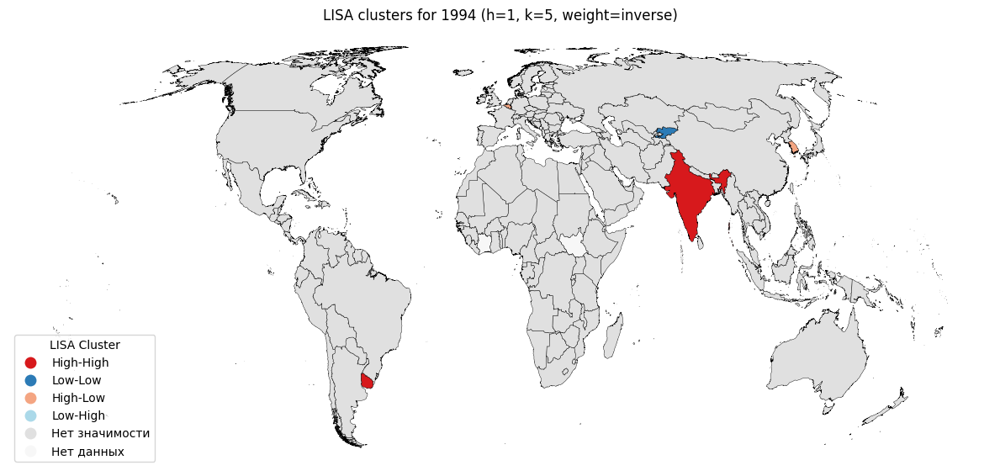

In [620]:
for y in range(YEAR_START, YEAR_END+1):
    plot_lisa_for_year(y, df_y, df_x, HIERARCHY_MEASURE, 3,
                       K_NEIGHBORS, WEIGHT_TYPE, '../geoshapes/v22_2608.shp',
                       random_tie_break=False, seed=None,
                       min_obs=10, ranks=True, permutations=999, 
                       save_path=f'{RES_PATH}lisa/{HIERARCHY_MEASURE}_{PREDICTOR_MEASURE}_{y}.png')

In [827]:
threshold = np.percentile(np.abs(delta_vector), 20)  # например, 20-й процентиль
mask = np.abs(delta_vector) > threshold
print(f"Осталось стран после фильтрации: {mask.sum()} из {len(delta_vector)}")

# Пересчитываем Moran для подвыборки
y_filt = delta_vector[mask]
W_filt = W_matrix[np.ix_(mask, mask)]
w_filt = full2W(W_filt, ids=list(np.array(country_names)[mask]))
moran_filt = Moran(rankdata(y_filt), w_filt, permutations=999)
print(f"Moran's I без малых изменений: {moran_filt.I:.4f}, p = {moran_filt.p_sim:.4f}")

Осталось стран после фильтрации: 154 из 193
('WARNING: ', 'Trinidad and Tobago', ' is an island (no neighbors)')
Moran's I без малых изменений: 0.5189, p = 0.0010


In [828]:
binary = (delta_vector > 0).astype(int)
moran_bin = Moran(binary, w, permutations=999)
print(f"Moran's I для бинарной переменной: {moran_bin.I:.4f}, p = {moran_bin.p_sim:.4f}")

Moran's I для бинарной переменной: 0.3362, p = 0.0010


## Гипотезы 2.1, 2.2. Hierarchy variance VS Alliance number

In [247]:
#status_combined = pd.read_csv('../data/status_combined.csv')
#hierarchy_variance=status_combined[['year', 'weighted_centrality']].groupby(['year']).var()

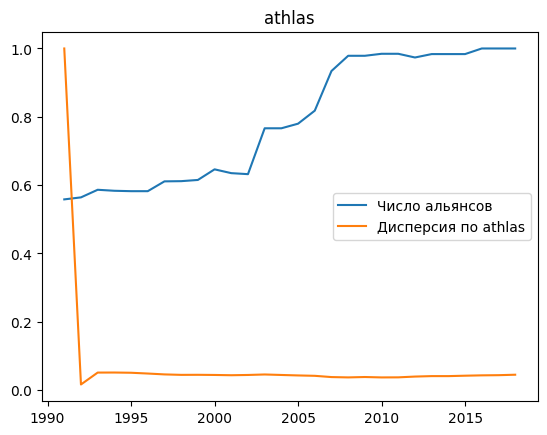

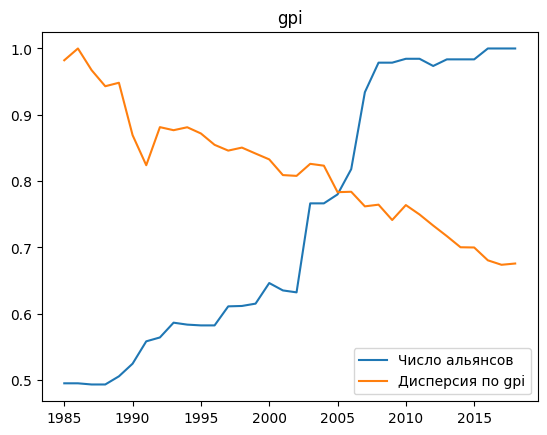

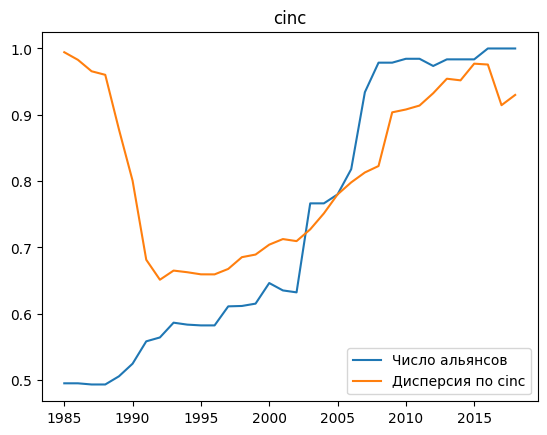

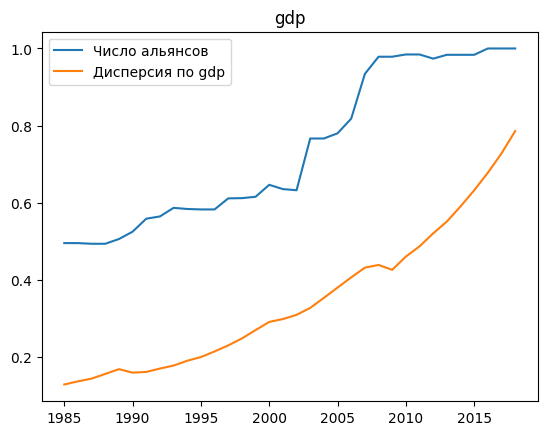

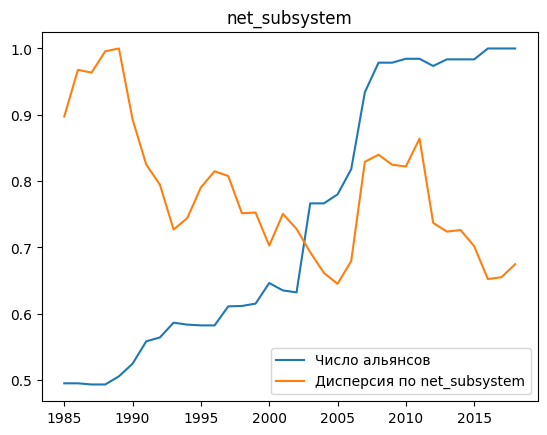

...

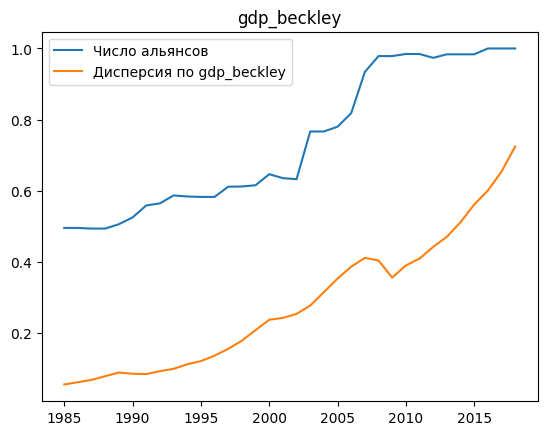

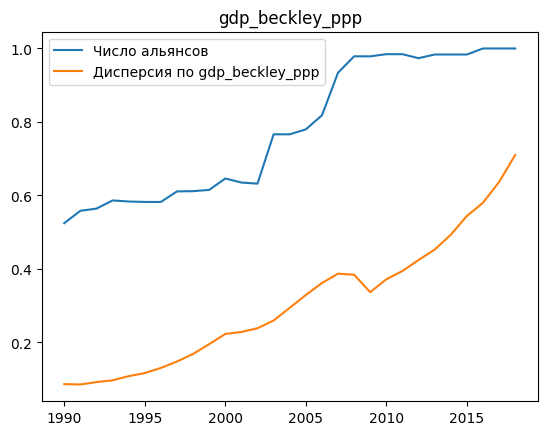

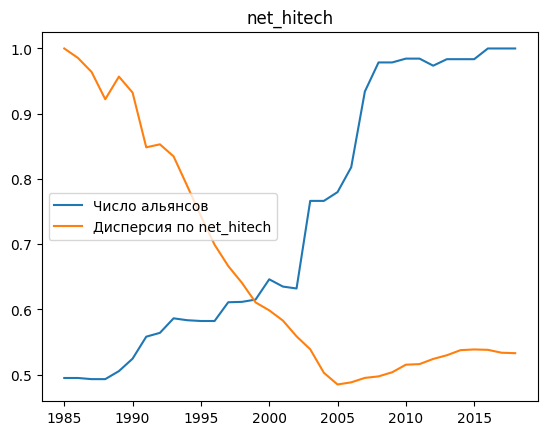

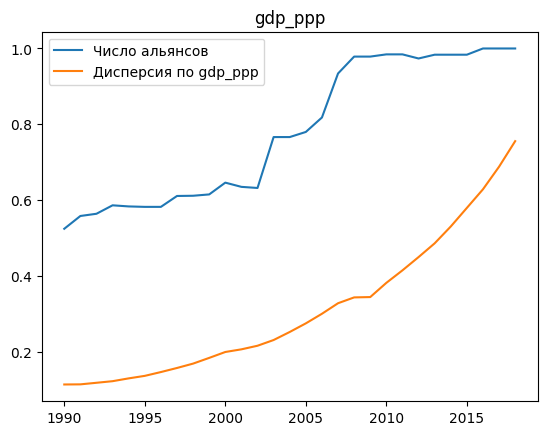

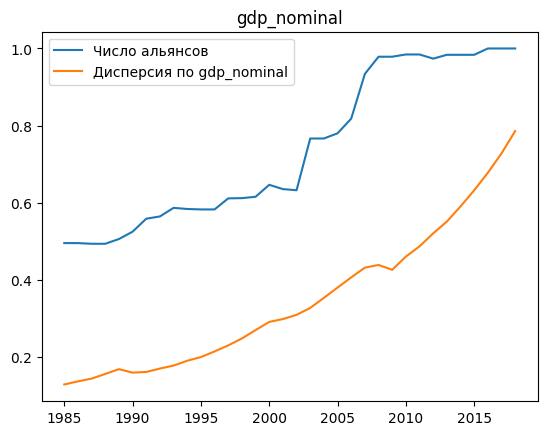

In [1803]:
corrs = {}
alliance_dyads = predictor_dfs['atop'].groupby('year').sum()
alliance_dyads['value']=alliance_dyads['value']/alliance_dyads['value'].max()
for y in power_dfs:
    if y == 'gdp':
        hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
    else:
        hierarchy_variance=power_dfs[y][['value','year']].groupby(['year']).var()
    hierarchy_variance=hierarchy_variance/hierarchy_variance.max()
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    plt.plot(features)
    plt.title(y)
    plt.legend(['Число альянсов',f"Дисперсия по {y}"])
    plt.savefig(f'{RES_PATH}variance/alliance_{y}.png', dpi=200)
    plt.show()
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [1073]:
hiearchy_variance_corr_alliance = pd.DataFrame.from_dict(corrs, orient='index')
hiearchy_variance_corr_alliance.to_csv(f'{RES_PATH}variance/hiearchy_variance_corr_alliance.csv')
hiearchy_variance_corr_alliance

,r,p_value,n
athlas,-0.259,1.828781e-01,28
gpi,-0.918,1.950797e-14,34
cinc,0.443,8.732269e-03,34
gdp,0.931,1.426476e-15,34
net_subsystem,-0.510,2.042983e-03,34
net,-0.880,6.852204e-12,34
gdp_beckley,0.936,5.093620e-16,34
gdp_beckley_ppp,0.912,5.520776e-12,29
net_hitech,-0.830,1.250255e-09,34


INFO:root:Размер таблицы дельт: (5601, 3)


(1,) None


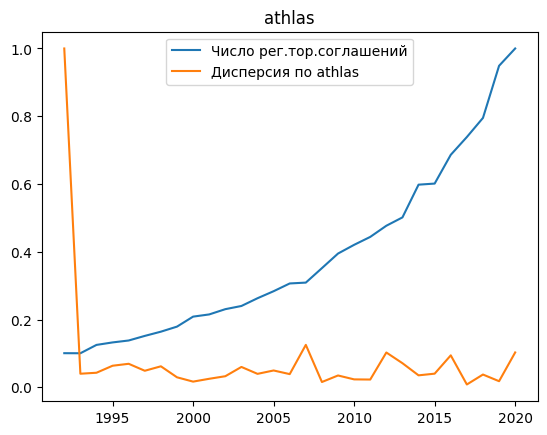

INFO:root:Размер таблицы дельт: (7024, 3)


(1,) None


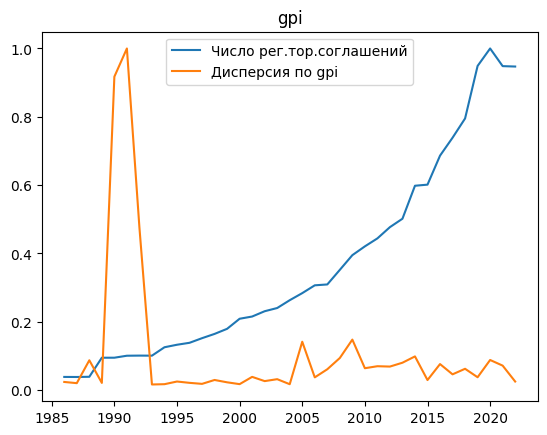

INFO:root:Размер таблицы дельт: (7026, 3)


(1,) None


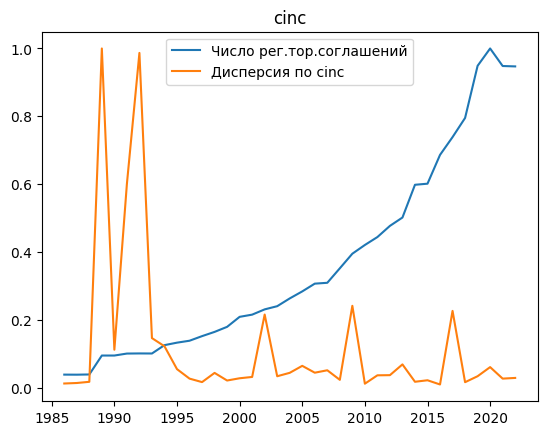

INFO:root:co country data found in Index(['value', 'year'], dtype='str')
INFO:root:Размер таблицы дельт: (1282214, 2)


(1,) None


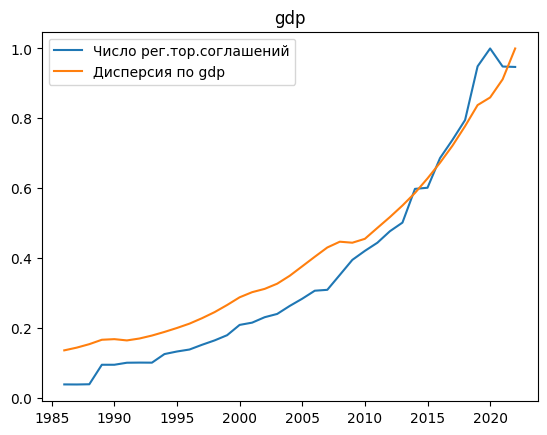

INFO:root:Размер таблицы дельт: (62631, 3)


(1,) None


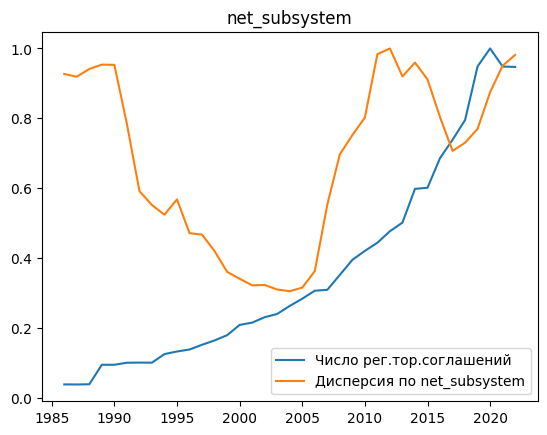

INFO:root:Размер таблицы дельт: (7179, 3)


(1,) None


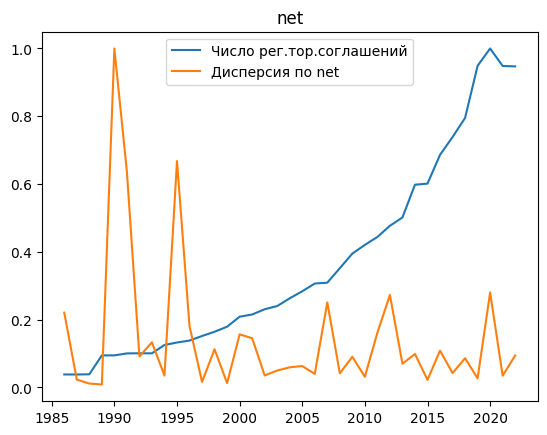

INFO:root:Размер таблицы дельт: (55, 3)


(1,) None


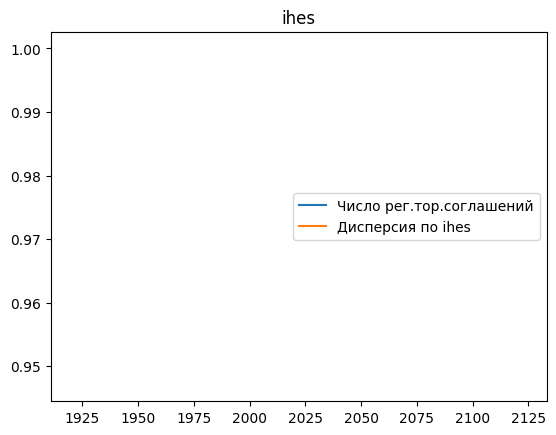

INFO:root:Размер таблицы дельт: (55, 3)


(1,) None


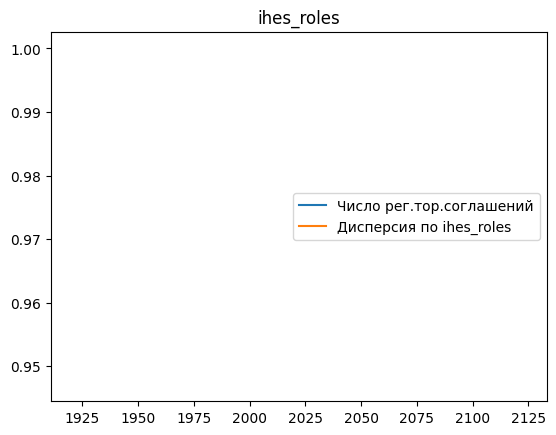

INFO:root:Размер таблицы дельт: (55, 3)


(1,) None


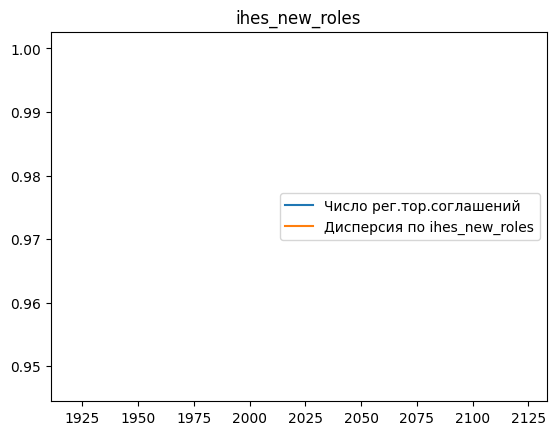

INFO:root:Размер таблицы дельт: (7055, 3)


(1,) None


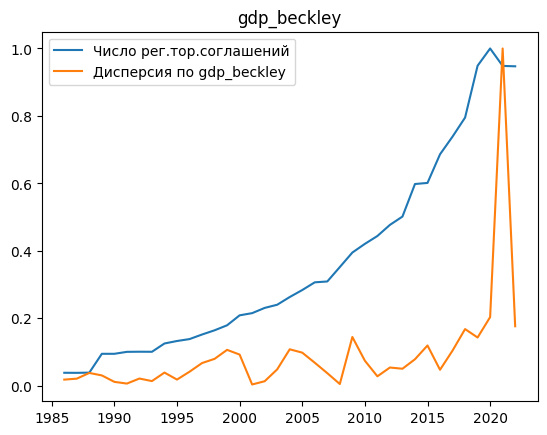

INFO:root:Размер таблицы дельт: (6081, 3)


(1,) None


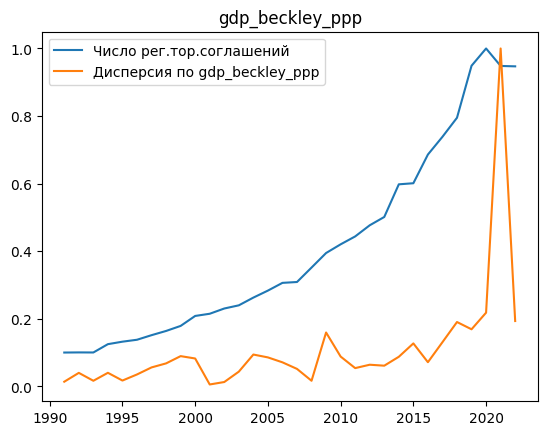

INFO:root:Размер таблицы дельт: (7079, 3)


(1,) None


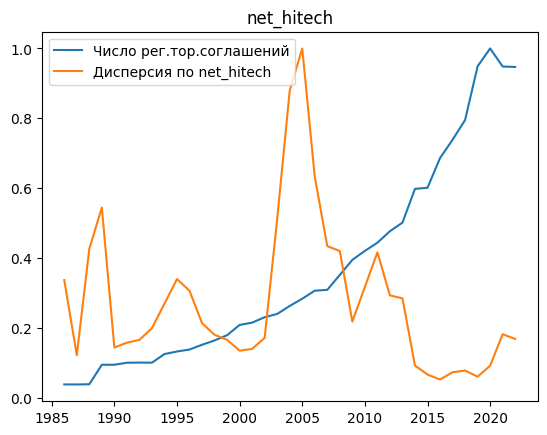

INFO:root:Размер таблицы дельт: (6081, 3)


(1,) None


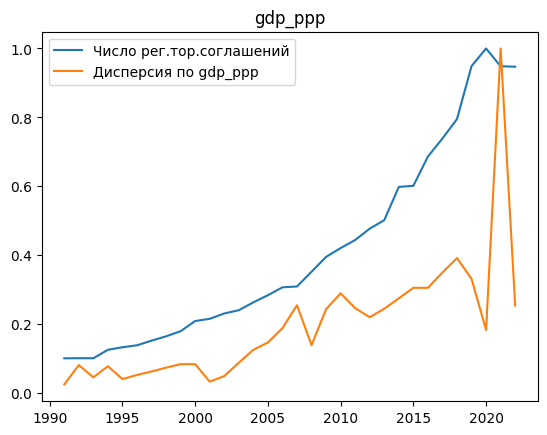

INFO:root:Размер таблицы дельт: (7055, 3)


(1,) None


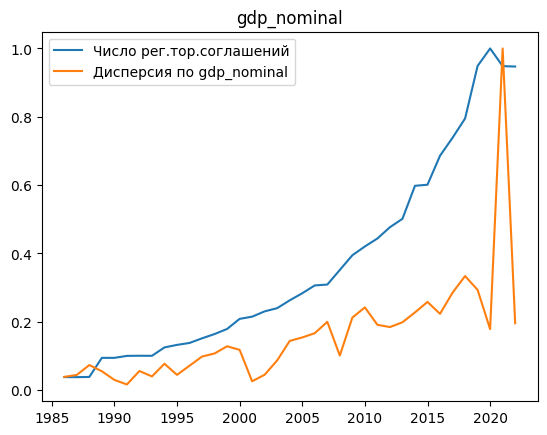

In [1805]:
corrs = {}
alliance_dyads = predictor_dfs['rta'].groupby('year').sum()
alliance_dyads['value']=alliance_dyads['value']/alliance_dyads['value'].max()
for y in power_dfs:
    if y == 'gdp':
        
        #hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
        hierarchy_measure=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']]
        deltas = compute_deltas(hierarchy_measure,
            horizons=(1,),
            return_yearly_mean=False
        )
        hierarchy_variance = deltas.groupby(['year']).var().rename({'delta_1':'value'}, axis=1).dropna()
    else:
        hierarchy_measure=power_dfs[y]
        deltas = compute_deltas(hierarchy_measure,
            horizons=(1,),
            return_yearly_mean=False
        )[['year','delta_1']]
        #print(deltas)
        hierarchy_variance = deltas.groupby(['year']).var().rename({'delta_1':'value'}, axis=1).dropna()
    hierarchy_variance=hierarchy_variance/hierarchy_variance.max()
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    plt.plot(features)
    plt.title(y)
    plt.legend(['Число рег.тор.соглашений',f"Дисперсия по {y}"])
    plt.savefig(f'{RES_PATH}/variance/rta_{y}.png', dpi=200)
    plt.show()
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [1047]:
corrs = {}
alliance_dyads = predictor_dfs['rta'].groupby('year').sum()
for y in power_dfs:
    if y == 'gdp':
        hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
    else:
        hierarchy_variance=power_dfs[y][['value','year']].groupby(['year']).var()#
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [1099]:
hiearchy_variance_corr_rta = pd.DataFrame.from_dict(corrs, orient='index')
hiearchy_variance_corr_rta.to_csv(f'{RES_PATH}variance/hiearchy_variance_corr_rta.csv')
hiearchy_variance_corr_rta

,r,p_value,n
athlas,-0.197,3.049472e-01,29
gpi,-0.208,2.161297e-01,37
cinc,-0.267,1.098495e-01,37
gdp,0.992,9.686653e-33,37
net_subsystem,0.386,1.829634e-02,37
net,-0.205,2.231493e-01,37
gdp_beckley,0.549,4.340534e-04,37
gdp_beckley_ppp,0.580,5.083644e-04,32
net_hitech,-0.323,5.120387e-02,37


# Joining status communities (Hypotheses No 1,4)

## Status communities and hiearchy

In [354]:
# альянс расширился за последние 3 года
allies_n = predictor_dfs['atop'].drop('country_b', axis=1).groupby(['year','country_a']).sum().reset_index()  # rta тоже нет
allies_n['delta_1'] = allies_n['value'] - allies_n['value'].shift(3)
allies_n=allies_n.rename({'country_a':'country'}, axis=1)

In [355]:
p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))

In [356]:
p.merge(allies_n, on=['country','year']).loc[:,'delta_1_x':'delta_1_y'].corr()

,delta_1_x,delta_2,delta_3,value,delta_1_y
delta_1_x,1.000000,0.744624,0.633475,-0.046032,-0.040145
delta_2,0.744624,1.000000,0.852835,-0.068151,-0.055040
delta_3,0.633475,0.852835,1.000000,-0.081872,-0.064708
value,-0.046032,-0.068151,-0.081872,1.000000,0.685499
delta_1_y,-0.040145,-0.055040,-0.064708,0.685499,1.000000


##### accession

## RTA

In [1299]:
from utils.utils import get_empty_country_df

In [1471]:
from scipy.stats import pearsonr
import numpy as np

In [1595]:
def get_continuos_data(
    df,
    year_start=YEAR_START['predictor'] - 5,
    year_end=YEAR_END['predictor'],
    filter_nonaligned=FILTER_NONALLIED,
    rolling=5,
    reverse=True
):
    empty_df = get_empty_country_df(years=[year_start, year_end])
    empty_df = (
        empty_df
        .reset_index()
        .drop('alter', axis=1)
        .drop_duplicates()
        .rename({'ego': 'country'}, axis=1)
    )

    df = df[['country', 'year', 'value']]
    empty_df = (
        empty_df
        .merge(df, on=['country', 'year'], how='left')
        .fillna(0)
    )

    # print(empty_df)

    if reverse:
        empty_df = (
            empty_df
            .set_index('year')#[::-1]
            .groupby(['country'])
            .rolling(rolling)
            .mean()[::-1]['value']#.mean()[::-1]['value']
            .reset_index()
        )
    else:
        empty_df = (
            empty_df
            .set_index('year')#[::-1]
            .groupby(['country'])
            .rolling(rolling)
            .mean()['value']
            #.mean()[::-1]['value']#.mean()[::-1]['value']
            .reset_index()
        )

    empty_df['value'] = empty_df['value'].fillna(0)
    empty_df = empty_df[['year', 'country', 'value']].sort_values('value')
    # empty_df = empty_df.replace(0.4, 0.2)   # закомментированная строка

    # Filtering countries never joining alliances
    if filter_nonaligned:   # используется параметр (а не глобальная FILTER_NONALLIED)
        empty_df = empty_df.merge(
            empty_df.groupby('country').sum()['value'] > 0,
            on='country',
            suffixes=('', '_bool')
        )
        empty_df = empty_df[empty_df['value_bool'] == True]

    return empty_df

In [1599]:
rta_m = rta.process_rta_data(f'{PREDICTORS_DATA_DIR}AllRTAs_fixeu.csv').rename({'Country':'country','Entry Year':'year'}, axis=1)
rta_m = rta_m[rta_m['Status']=='In Force']
rta_m['value'] = 1
rta_m['year'] = rta_m['year'].astype(int)

# Filtering Customs union AND Economic integration area only
rta_m=rta_m[(rta_m['Type'].str.contains('CU'))&(rta_m['Type'].str.contains('EIA'))]

EUONLY=False
FILTER_NONALLIED = True
REVERSE=False

rolling_rotate = (1, 3, 5, 10)  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
#rolling_rotate = (15, 20)  # Проверка гипотезы Г-1.1У
horizons = (1, 3, 5)  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
#horizons = (3,5)  # Проверка гипотезы Г-1.1У

if EUONLY:
    rta_m = rta_m[(rta_m['RTA Name']=='EU Treaty')|(rta_m['RTA Name']=='EU (28) Enlargement')|(rta_m['RTA Name'].str.contains('EC '))].sort_values('year').drop_duplicates(subset='country')

    #rta_m=rta_m[['country','year','value']]

In [1604]:
r = dict()
for rolling in rolling_rotate:
    rta_cdf = get_continuos_data(rta_m, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)
    rta_cdf['value'] = rta_cdf['value'].apply(lambda x: 1 if x>0 else 0)
    # fix
    if 'value_bool'  in rta_cdf.columns: 
        rta_cdf=rta_cdf.drop('value_bool', axis=1)
    if not EUONLY:
        rta_cdf.loc[9000]=[2012, 'Venezuela', 1]
    countries_all = set(rta_cdf['country'])
    for power_cat in FILTER_THRESHOLDS:
        filter_threshold = FILTER_THRESHOLDS[power_cat]
        keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
        if power_cat == 'small':
            filter_threshold = FILTER_THRESHOLDS['middleplus']
            keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
            keep_countries = countries_all - keep_countries
        if power_cat == 'all':
            keep_countries = countries_all
        print(power_cat, keep_countries)
        rta_cdf_power = rta_cdf[rta_cdf['country'].isin(keep_countries)]
        for years_cat in FILTER_YEARS:
            filter_years = FILTER_YEARS[years_cat]
            rta_cdf_years=rta_cdf_power[~rta_cdf_power['year'].isin(filter_years)]
            for power_df in power_dfs:
                if power_df == 'gdp':
                    continue
                if power_df == 'net_subsystem':
                    p = compute_deltas(power_dfs[power_df][power_dfs[power_df]['indicator'] == 'economy'],
                                       horizons=horizons)
                else:
                    p = compute_deltas(power_dfs[power_df], horizons=horizons)
        
                print(filter_years, years_cat)
                print(f"Power_df = {power_df}")
                print("P")
                print(p)
                features = p.merge(rta_cdf_years, on=['country', 'year'])
                print(features)
                if power_df not in r:
                    r[power_df] = dict()
        
                for horizon in horizons:
                    col = f'delta_{horizon}'
                    temp_df = features.loc[:, [col,'value']]
                    value_col = temp_df['value']
                    
                    mask = temp_df[col].notna() & value_col.notna()
                    if mask.sum() < 3:
                        print(f"mask.sum is {mask.sum()}")
                        continue
        
                    x = temp_df.loc[mask, col]
                    y = value_col[mask]
        
                    # Пропускаем, если одна из переменных постоянна (нулевая дисперсия)
                    if np.std(x) == 0 or np.std(y) == 0:
                        print("Zero dispersion")
                        continue
        
                    corr, p_val = pearsonr(x, y)
        
                    n_0=y.value_counts()[0]
                    n_1=y.value_counts()[1]
                    print(n_0, n_1)
                    if (n_1<10):
                        n_short_warn = f' (n1={n_1})'
                    else:
                        n_short_warn = ''
                    if (n_0<10):
                        n_short_warn = n_short_warn  + f' (n0={n_0})'
        
                    if corr is not None:
                        stars = significance_stars(p_val)
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = f"{corr:.3f}{stars}{n_short_warn}"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} OK')
                    else:
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = "NaN"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} NOOK')
if FILTER_NONALLIED:
    filter_nonallied_label = '_alliedonly'
else:
    filter_nonallied_label = ''
if EUONLY:
    eu_label = '_euonly'
else:
    eu_label = ''
if ~REVERSE:
    reverse_label = '_backwards'
else:
    reverse_label = ''
print(f'FILTER_NON_ALIGNED={FILTER_NONALLIED}')
if rolling_rotate == (15, 20):  # Проверка гипотезы Г-1.1У
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}rta_ingress_corr_longterm{filter_nonallied_label}{eu_label}{reverse_label}.csv')
elif rolling_rotate == (1, 3, 5, 10):  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}rta_ingress_corr{filter_nonallied_label}{eu_label}{reverse_label}.csv')
else:
    print("Unknown rolling_rotate, refusing to save")

all {'Estonia', 'Sweden', 'Kazakhstan', 'Venezuela', 'Finland', 'Russian Federation', 'Haiti', 'Croatia', 'Uganda', 'Austria', 'Hungary', 'Romania', 'Slovenia', 'Cyprus', 'Malta', 'Uruguay', 'Belarus', 'Kenya', 'Poland', 'Paraguay', 'Bulgaria', 'Latvia', 'Armenia', 'Brazil', 'Lithuania', 'Argentina', 'Suriname'}
[] allyears
Power_df = athlas
P
          country  year   delta_1   delta_3   delta_5
0     Afghanistan  1992       NaN       NaN       NaN
1     Afghanistan  1993  0.001685       NaN       NaN
2     Afghanistan  1994 -0.002678       NaN       NaN
3     Afghanistan  1995  0.017841  0.016848       NaN
4     Afghanistan  1996  0.010335  0.025498       NaN
...           ...   ...       ...       ...       ...
5596     Zimbabwe  2016 -0.000951 -0.003798 -0.013724
5597     Zimbabwe  2017 -0.002116 -0.004683 -0.008642
5598     Zimbabwe  2018  0.000137 -0.002930 -0.005777
5599     Zimbabwe  2019 -0.003055 -0.005035 -0.007601
5600     Zimbabwe  2020 -0.001903 -0.004821 -0.007888

[5601

In [ ]:
# Почему с R1 так мало?

In [1605]:
pd.DataFrame(r)

,athlas,gpi,cinc,net_subsystem,net,ihes,ihes_roles,ihes_new_roles,gdp_beckley,gdp_beckley_ppp,gdp_nominal,gdp_ppp
delta_1_r1_all_allyears,-0.001,0.007,0.012,0.001,0.013,NaN,NaN,NaN,-0.009,-0.026,-0.011,-0.017
delta_3_r1_all_allyears,-0.015,0.016,0.015,0.001,-0.011,NaN,NaN,NaN,-0.034,-0.019,-0.023,-0.015
delta_5_r1_all_allyears,0.023,0.021,0.020,0.018,-0.008,NaN,NaN,NaN,-0.044,-0.006,-0.018,-0.008
delta_1_r1_all_stableyears,-0.004,-0.002,0.028,0.003,0.044,NaN,NaN,NaN,-0.010,-0.028,-0.031,-0.035
delta_3_r1_all_stableyears,-0.013,0.013,0.028,-0.028,0.025,NaN,NaN,NaN,-0.034,-0.026,-0.036,-0.031
...,...,...,...,...,...,...,...,...,...,...,...,...
delta_3_r10_small_allyears,-0.116**,0.006,0.027,-0.000,0.072†,NaN,NaN,NaN,0.064†,0.045,0.061,0.023
delta_5_r10_small_allyears,-0.086*,0.025,0.052,0.010,0.104**,NaN,NaN,NaN,0.043,0.028,0.049,0.009
delta_1_r10_small_stableyears,-0.104*,-0.011,0.026,0.017,0.070,NaN,NaN,NaN,0.107*,0.034,0.043,-0.069
delta_3_r10_small_stableyears,-0.168**,-0.004,0.070,0.007,0.148**,NaN,NaN,NaN,0.151**,0.066,0.076,-0.043


## ATOP

In [1608]:
FILTER_NATO=False
FILTER_NONALLIED=True
FILTER_BILATERAL=False
REVERSE=False


rolling_rotate = (1, 3, 5, 10)  # Проверка гипотез Г-4, Г-4.1
horizons = (1, 3, 5)  # Проверка гипотез Г-4, Г-4.1

In [1609]:
atop_m = pd.read_csv(f'{PREDICTORS_DATA_DIR}atop/atop5_1m.csv')
atop_m = atop_m[atop_m['yrent']>=YEAR_START['predictor']]
atop_m = atop_m[atop_m['defense']==1]
atop_m = convert_country_df(atop_m, 'member', numeric_type='cow', print_convertions=False)
atop_m=atop_m.rename({'member':'country', 'yrent':'year','defense':'value'}, axis=1)

atop_m=atop_m.sort_values('year').drop_duplicates(subset=['atopid','country'])

# filtering NATO
atop_m_nato = atop_m[atop_m['atopid']==NATO_ATOP_ID]

if FILTER_BILATERAL:
    atop_m=atop_m[atop_m['bilat']==1]

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 680, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")


In [1610]:
r = dict()
for rolling in rolling_rotate:
    if FILTER_NATO:
        atop_cdf = get_continuos_data(atop_m_nato, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)#
    else:
        atop_cdf = get_continuos_data(atop_m, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)#
    atop_cdf['value'] = atop_cdf['value'].apply(lambda x: 1 if x>0 else 0)
    # fix
    if 'value_bool'  in atop_cdf.columns: 
        atop_cdf=atop_cdf.drop('value_bool', axis=1)
        atop_cdf=atop_cdf.sort_values('year').drop_duplicates()
    countries_all = set(atop_cdf['country'])
    for power_cat in FILTER_THRESHOLDS:
        filter_threshold = FILTER_THRESHOLDS[power_cat]
        keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
        if power_cat == 'small':
            filter_threshold = FILTER_THRESHOLDS['middleplus']
            keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
            keep_countries = countries_all - keep_countries
        if power_cat == 'all':
            keep_countries = countries_all
        print(power_cat, keep_countries)
        atop_cdf_power = atop_cdf[atop_cdf['country'].isin(keep_countries)]
        for years_cat in FILTER_YEARS:
            filter_years = FILTER_YEARS[years_cat]
            atop_cdf_years=atop_cdf_power[~atop_cdf_power['year'].isin(filter_years)]
            for power_df in power_dfs:
                if power_df == 'gdp':
                    continue
                if power_df == 'net_subsystem':
                    p = compute_deltas(power_dfs[power_df][power_dfs[power_df]['indicator'] == 'security'],
                                       horizons=horizons)
                else:
                    p = compute_deltas(power_dfs[power_df], horizons=horizons)
        
                print(filter_years, years_cat)
                print(f"Power_df = {power_df}")
                print("P")
                print(p)
                features = p.merge(atop_cdf_years, on=['country', 'year'])
                print(features)
                if power_df not in r:
                    r[power_df] = dict()
        
                for horizon in horizons:
                    col = f'delta_{horizon}'
                    temp_df = features.loc[:, [col,'value']]
                    value_col = temp_df['value']
                    
                    mask = temp_df[col].notna() & value_col.notna()
                    if mask.sum() < 3:
                        print(f"mask.sum is {mask.sum()}")
                        continue
        
                    x = temp_df.loc[mask, col]
                    y = value_col[mask]
        
                    # Пропускаем, если одна из переменных постоянна (нулевая дисперсия)
                    if np.std(x) == 0 or np.std(y) == 0:
                        print("Zero dispersion")
                        continue
        
                    corr, p_val = pearsonr(x, y)
        
                    n_0=y.value_counts()[0]
                    n_1=y.value_counts()[1]
                    print(n_0, n_1)
                    if (n_1<10):
                        n_short_warn = f' (n1={n_1})'
                    else:
                        n_short_warn = ''
                    if (n_0<10):
                        n_short_warn = n_short_warn  + f' (n0={n_0})'
        
                    if corr is not None:
                        stars = significance_stars(p_val)
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = f"{corr:.3f}{stars}{n_short_warn}"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} OK')
                    else:
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = "NaN"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} NOOK')
if FILTER_NONALLIED:
    filter_nonallied_label = '_alliedonly'
else:
    filter_nonallied_label = ''
if FILTER_NATO:
    nato_label = '_natoonly'
else:
    nato_label = ''
if FILTER_BILATERAL:
    bilat_label='nobilat'
else:
    bilat_label=''
if ~REVERSE:
    reverse_label = '_backwards'
else:
    reverse_label = ''

print(f'FILTER_NON_ALIGNED={FILTER_NONALLIED}')
if rolling_rotate == (15, 20):  
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}atop_ingress_corr_longterm{filter_nonallied_label}{nato_label}{bilat_label}{reverse_label}.csv')
elif rolling_rotate == (1, 3, 5, 10):  # Проверка гипотез Г-4, Г-4.1
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}atop_ingress_corr{filter_nonallied_label}{nato_label}{bilat_label}{reverse_label}.csv')
else:
    print("Unknown rolling_rotate, refusing to save")

all {'Bahamas', 'Saint Lucia', 'Sweden', 'Estonia', "Democratic People's Republic of Korea", 'Burkina Faso', 'Democratic Republic of the Congo', 'Central African Republic', 'Belgium', 'Guatemala', 'Malawi', 'Italy', 'Albania', 'Nigeria', 'Guyana', 'Antigua and Barbuda', 'Egypt', 'Poland', 'Kuwait', 'Ghana', 'France', 'Cameroon', 'Yemen', 'Honduras', 'Saudi Arabia', 'Azerbaijan', 'Spain', 'Zimbabwe', 'Mauritania', 'South Africa', 'Tunisia', 'Nicaragua', 'Guinea', 'Burundi', 'Canada', 'South Sudan', 'Tajikistan', "Côte d'Ivoire", 'Guinea-Bissau', 'Slovenia', 'Equatorial Guinea', 'Niger', 'Cyprus', 'Malta', 'Barbados', 'Namibia', 'Montenegro', 'Germany', 'Belize', 'United Arab Emirates', 'Algeria', 'Bosnia and Herzegovina', 'Kingdom of Eswatini', 'United Republic of Tanzania', 'Lithuania', 'Syrian Arab Republic', 'Sudan', 'Mozambique', 'Russian Federation', 'Uganda', 'Angola', 'Romania', 'Sao Tome and Principe', 'Hungary', 'Uzbekistan', 'Portugal', 'Grenada', 'Sierra Leone', 'United State

In [1607]:
pd.DataFrame(r)

,athlas,gpi,cinc,net_subsystem,net,ihes,ihes_roles,ihes_new_roles,gdp_beckley,gdp_beckley_ppp,gdp_nominal,gdp_ppp
delta_1_r1_all_allyears,0.025,-0.010,-0.053***,-0.001,0.003,NaN,NaN,NaN,-0.011,-0.018,-0.016,-0.031†
delta_3_r1_all_allyears,0.000,-0.020,-0.078***,-0.014,0.014,NaN,NaN,NaN,-0.015,-0.020,-0.021,-0.028
delta_5_r1_all_allyears,0.002,-0.024,-0.082***,-0.009,0.010,NaN,NaN,NaN,-0.015,-0.017,-0.016,-0.020
delta_1_r1_all_stableyears,0.018,-0.017,-0.024,-0.003,-0.015,NaN,NaN,NaN,-0.016,-0.010,-0.013,-0.010
delta_3_r1_all_stableyears,-0.001,0.027,-0.026,-0.022,-0.017,NaN,NaN,NaN,-0.017,-0.012,-0.016,-0.013
...,...,...,...,...,...,...,...,...,...,...,...,...
delta_3_r10_small_allyears,-0.033†,0.002,-0.036*,-0.027,-0.053**,NaN,NaN,NaN,-0.045**,-0.030,-0.009,0.012
delta_5_r10_small_allyears,-0.032,-0.015,-0.067***,-0.030†,-0.061***,NaN,NaN,NaN,-0.054**,-0.049**,-0.020,-0.019
delta_1_r10_small_stableyears,-0.064**,-0.013,-0.005,0.010,-0.016,NaN,NaN,NaN,-0.077***,-0.055*,-0.046*,-0.014
delta_3_r10_small_stableyears,-0.060*,-0.038†,-0.016,0.009,-0.045†,NaN,NaN,NaN,-0.125***,-0.090***,-0.085***,-0.040


In [1579]:
# По идее гипотеза была именно про статус. МБ иерархия восприятия и поменялась, проверить не можем - слишком мало новых альянсов в 2022-2026 (для КНДР работает)

### Гипотезы 19 IHES Analysis

In [2311]:
ihes = pd.read_csv(f"{POWER_DATA_DIR}ihes_data.csv", index_col='Unnamed: 0')

In [2387]:
SPHERES = ['economy', 'security', 'green','human']
specialised = dict()
unspecialised = dict()
res = dict()

delta_2022_2026 = pd.DataFrame((ihes[ihes['wave']=='2026'].set_index('states')['power_rates'] - ihes[ihes['wave']=='2022_2023'].set_index('states')['power_rates']).dropna())
delta_2022_2026 = delta_2022_2026.reset_index()

delta_2022_2025 = pd.DataFrame((ihes[ihes['wave']=='2025'].set_index('states')['power_rates'] - ihes[ihes['wave']=='2022_2023'].set_index('states')['power_rates']).dropna())
delta_2022_2025 = delta_2022_2025.reset_index()


for sphere in SPHERES:
    specialised[sphere] = set(ihes[(ihes[f'roles_{sphere}'] / ihes['roles']) > 0.4]['states'])
    unspecialised[sphere] = set(ihes[(ihes[f'roles_{sphere}'] / ihes['roles']) < 0.1]['states'])
    delta_2022_2026[f'specialised_{sphere}'] = delta_2022_2026['states'].apply(lambda x: x in specialised[sphere]) 
    delta_2022_2026[f'unspecialised_{sphere}'] = delta_2022_2026['states'].apply(lambda x: x in unspecialised[sphere])
    delta_2022_2025[f'specialised_{sphere}'] = delta_2022_2025['states'].apply(lambda x: x in specialised[sphere]) 
    delta_2022_2025[f'unspecialised_{sphere}'] = delta_2022_2025['states'].apply(lambda x: x in unspecialised[sphere]) 
    res[sphere, 2026] = dict()
    res[sphere, 2026]['r_specialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'specialised_{sphere}']).statistic, 3)
    res[sphere, 2026]['p-value_specialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'specialised_{sphere}']).pvalue, 3)
    res[sphere, 2026]['n_specialised'] = len(specialised[sphere])
    res[sphere, 2026]['r_unspecialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'unspecialised_{sphere}']).statistic, 3)
    res[sphere, 2026]['p-value_unspecialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'unspecialised_{sphere}']).pvalue, 3)
    res[sphere, 2026]['n_unspecialised'] = len(unspecialised[sphere])
    res[sphere, 2025] = dict()
    res[sphere, 2025]['r_specialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'specialised_{sphere}']).statistic, 3)
    res[sphere, 2025]['p-value_specialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'specialised_{sphere}']).pvalue, 3)
    res[sphere, 2025]['n_specialised'] = len(specialised[sphere])
    res[sphere, 2025]['r_unspecialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'unspecialised_{sphere}']).statistic, 3)
    res[sphere, 2025]['p-value_unspecialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'unspecialised_{sphere}']).pvalue, 3)
    res[sphere, 2025]['n_unspecialised'] = len(unspecialised[sphere])


In [2388]:
res

{('economy', 2026): {'r_specialised': np.float64(-0.268),
  'p-value_specialised': np.float64(0.177),
  'n_specialised': 15,
  'r_unspecialised': np.float64(0.664),
  'p-value_unspecialised': np.float64(0.0),
  'n_unspecialised': 2},
 ('economy', 2025): {'r_specialised': np.float64(-0.24),
  'p-value_specialised': np.float64(0.227),
  'n_specialised': 15,
  'r_unspecialised': np.float64(0.379),
  'p-value_unspecialised': np.float64(0.051),
  'n_unspecialised': 2},
 ('security', 2026): {'r_specialised': np.float64(0.69),
  'p-value_specialised': np.float64(0.0),
  'n_specialised': 9,
  'r_unspecialised': np.float64(-0.409),
  'p-value_unspecialised': np.float64(0.034),
  'n_unspecialised': 6},
 ('security', 2025): {'r_specialised': np.float64(0.492),
  'p-value_specialised': np.float64(0.009),
  'n_specialised': 9,
  'r_unspecialised': np.float64(-0.308),
  'p-value_unspecialised': np.float64(0.118),
  'n_unspecialised': 6},
 ('green', 2026): {'r_specialised': np.float64(-0.113),
  'p-v

In [2377]:
pearsonr(delta_2022_2026['power_rates'],delta_2022_2026['specialised_economy'] )

PearsonRResult(statistic=np.float64(-0.2675282006347676), pvalue=np.float64(0.17731083060502806))

In [2373]:
delta_2022_2026.set_index('states').corr()['power_rates']

power_rates              +1.0000
specialised_economy      -0.2675
unspecialised_economy    +0.6642
specialised_security     +0.6898
unspecialised_security   -0.4086
specialised_green        -0.1127
unspecialised_green      +0.5162
specialised_human            NaN
unspecialised_human      +0.5045
Name: power_rates, dtype: float64

In [2374]:
delta_2022_2025.set_index('states').corr()['power_rates']

power_rates              +1.0000
specialised_economy      -0.2405
unspecialised_economy    +0.3790
specialised_security     +0.4915
unspecialised_security   -0.3079
specialised_green        +0.0033
unspecialised_green      +0.1930
specialised_human            NaN
unspecialised_human      +0.4048
Name: power_rates, dtype: float64

In [2368]:
delta_2022_2025

,index,states,power_rates,specialised_economy,unspecialised_economy,specialised_security,unspecialised_security,specialised_green,unspecialised_green,specialised_human,unspecialised_human
0,0,Argentina,-0.0864,True,False,False,True,False,False,False,True
1,1,Australia,-0.0299,False,False,False,False,True,False,False,True
2,2,Brazil,-0.0732,True,False,False,True,True,False,False,True
3,3,Canada,-0.1474,False,False,False,False,False,False,False,False
4,4,China,+0.0669,False,False,False,False,False,False,False,False
5,5,Egypt,+0.0740,False,False,True,False,False,False,False,False
6,6,France,-0.0620,False,False,False,False,False,False,False,False
7,7,Germany,-0.1389,False,False,False,False,False,False,False,False
8,8,India,+0.0281,False,False,False,False,False,False,False,True
9,9,Indonesia,+0.1504,True,False,False,False,False,False,False,True


In [2330]:
specialised

{'economy': {'Argentina',
  'Brazil',
  'Chile',
  'Indonesia',
  'Italy',
  'Japan',
  'Kazakhstan',
  'Malaysia',
  'Mexico',
  'Nigeria',
  'Saudi Arabia',
  'South Korea',
  'UAE',
  'Venezuela',
  'Vietnam'},
 'security': {'Egypt',
  'Iran',
  'Israel',
  'North Korea',
  'Pakistan',
  'Poland',
  'Russia',
  'Turkey',
  'Ukraine'},
 'green': {'Australia', 'Brazil'},
 'human': set()}

# Analysis Combined

In [21]:
def _build_country_exog(df_x, exog_cols, country_names, agg='mean', year=None):
    """
    Агрегирует билатеральные exog-колонки df_x до странового уровня.

    Параметры
    ---------
    df_x : DataFrame
        Панель с колонками 'country_a', 'country_b' (и, опционально, 'year').
    exog_cols : list[str]
        Колонки df_x, которые надо превратить в страновые exog.
    country_names : iterable
        Итоговый (после всех фильтраций) список стран — под него reindex'им.
    agg : str | callable
        Агрегатор по партнёрам ('mean', 'sum', 'median', ...).
    year : int | None
        Если задан и есть колонка 'year' — берём только этот год.

    Возвращает
    ----------
    pd.DataFrame | None
        DataFrame с индексом country_names и колонками exog_cols,
        или None, если exog_cols пустой.
    """
    if exog_cols is None or len(exog_cols) == 0:
        return None

    exog_cols = list(exog_cols)
    missing = [c for c in exog_cols if c not in df_x.columns]
    if missing:
        raise KeyError(f"exog_cols отсутствуют в df_x: {missing}")

    dfx = df_x.copy()
    if year is not None and 'year' in dfx.columns:
        dfx = dfx[dfx['year'] == year]

    if 'country_a' not in dfx.columns or 'country_b' not in dfx.columns:
        raise ValueError(
            "Для агрегации exog df_x должен содержать 'country_a' и 'country_b'. "
            "Если exog уже страновые — соберите их отдельно."
        )

    rows_a = dfx[['country_a'] + exog_cols].rename(columns={'country_a': 'country'})
    rows_b = dfx[['country_b'] + exog_cols].rename(columns={'country_b': 'country'})
    long = pd.concat([rows_a, rows_b], ignore_index=True)

    country_exog = long.groupby('country')[exog_cols].agg(agg)
    country_exog = country_exog.reindex(country_names)
    return country_exog


def spatial_analysis_pipeline_combined(df_y, df_x, horizon, k_neighbors, weight_type,
                              year_for_moran, hierarchy_measure, predictor_measure,
                              random_tie_break=False, seed=None, min_obs=10,
                              permutations=999, include_sem=True,
                              include_regimes=True, regime_lag_sep=False,
                              ignore_super=False, remove_isolates=False,
                              secondary_predictor=None,
                              secondary_weight_type='inverse',
                              # NEW: exog из df_x → в пространственную регрессию
                              exog_cols=None,
                              exog_agg='mean',
                              exog_year=None,
                              # NEW параметры режимов и враждебности:
                              regime_by='power',       # 'power' | 'hostility' | None
                              ipd_df=None,
                              hostility_year=None,
                              hostility_agg='mean',
                              hostility_thresholds=(1.0, 2.0, 3.0),
                              hostility_labels=('friendly', 'neutral',
                                                'tense', 'hostile'),
                              hostility_use_w=True,
                              hostility_min_partners=1):
    """
    exog_cols : list[str] | None
        Колонки df_x (билатеральные), которые нужно агрегировать до странового
        уровня (см. exog_agg / exog_year) и передать в SAR / SAR-regimes
        как экзогенные регрессоры.
    exog_agg : str | callable
        Агрегация по партнёрам ('mean' по умолчанию).
    exog_year : int | None
        Если задан и в df_x есть 'year' — берём только этот год. None → все годы.

    regime_by : str | None
        'power'     — режимы по категориям державности (как раньше);
        'hostility' — режимы по категориям враждебности окружения;
        None        — режимная модель не оценивается.
    ipd_df : DataFrame, optional
        Двусторонняя панель IPD. По умолчанию — predictor_dfs['ipd'].
    hostility_use_w : bool
        Если True, «окружение» страны = её соседи по W (локально).
        Если False — все партнёры из IPD (глобально).
    """
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    # 1. Изменения иерархии
    deltas = compute_deltas(
        df_y,
        horizons=(horizon,),
        year=year_for_moran,
        return_yearly_mean=True
    )

    # 2. Матрица расстояний
    dist_matrix = get_distance_matrix(df_x, deltas)

    # 3. Матрица весов
    W_matrix, country_names = build_weights_knn(
        dist_matrix,
        k=k_neighbors,
        weight_type=weight_type
    )

    W_matrix_2 = None
    country_names_2 = None
    if secondary_predictor:
        raise NotImplementedError("Did not finish implementation")

    # NEW: категоризация — после W, чтобы враждебность считалась локально
    deltas = add_power_cat(
        deltas,
        ignore_super=ignore_super,
        ipd_df=ipd_df,
        w=(full2W(W_matrix, ids=list(country_names)) if hostility_use_w else None),
        hostility_year=hostility_year,
        hostility_agg=hostility_agg,
        hostility_thresholds=hostility_thresholds,
        hostility_labels=hostility_labels,
        min_partners=hostility_min_partners,
    )

    # 3a. Удаление изолятов
    if remove_isolates:
        W_matrix, country_names = _remove_isolates(
            W_matrix, country_names, min_obs=min_obs
        )
        if W_matrix_2 is not None:
            W_matrix_2, country_names_2 = _remove_isolates(
                W_matrix_2, country_names_2, min_obs=min_obs
            )

    # 4. Вектор изменений
    delta_vector = (deltas.set_index('country')
                         .reindex(country_names)['delta_mean'].values)

    # 5. Пространственный лаг
    lag_vector, delta_vector, W_matrix, country_names = get_spatial_lag(
        delta_vector, W_matrix, country_names
    )
    if secondary_predictor and W_matrix_2 is not None:
        lag_vector_2, delta_vector_2, W_matrix_2, country_names_2 = get_spatial_lag(
            delta_vector, W_matrix_2, country_names_2
        )

    check = pd.DataFrame({'delta': delta_vector, 'lag': lag_vector},
                         index=country_names)

    # NEW 5a. Страновой exog из df_x (агрегируем билатеральные колонки)
    country_exog = _build_country_exog(
        df_x,
        exog_cols=exog_cols,
        country_names=country_names,
        agg=exog_agg,
        year=exog_year,
    )
    if country_exog is not None:
        logging.info(f"Exog из df_x: {list(country_exog.columns)} | "
                     f"shape={country_exog.shape} | "
                     f"NaN={int(country_exog.isna().sum().sum())}")

    def _exog_matrix(exog_df):
        """DataFrame → (values, names) для compute_sar."""
        if exog_df is None or exog_df.shape[1] == 0:
            return None, None
        return exog_df.values.astype(float), list(exog_df.columns)

    # 6. Графики
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=False)
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=True)

    # 7. Корреляции
    corr = basic_corr(lag_vector, delta_vector)

    # 8. Moran's I
    moran = get_moran(delta_vector, W_matrix,
                      country_names=country_names,
                      permutations=permutations, ranks=False)
    moran_ranked = get_moran(delta_vector, W_matrix,
                             country_names=country_names,
                             permutations=permutations, ranks=True)
    binary = (delta_vector > 0).astype(int)
    moran_bin = Moran(binary, full2W(W_matrix, ids=list(country_names)),
                      permutations=permutations)
    logging.info(f"Moran's I для бинарной переменной: "
                 f"{moran_bin.I:.4f}, p = {moran_bin.p_sim:.4f}")

    # 9. SAR — теперь с exog из df_x
    deltas_for_exog = (deltas[deltas['country'].isin(country_names)].copy()
                             .set_index('country')
                             .reindex(country_names))

    w = full2W(W_matrix, ids=list(country_names))

    exog_values, exog_names = _exog_matrix(country_exog)

    sar_model = compute_sar(
        delta_vector, w,
        include_sem=include_sem, ranks=True,
        hierarchy_name=hierarchy_measure,
        weight_type=predictor_measure,
        exog=exog_values, exog_names=exog_names
    )
    if secondary_predictor and W_matrix_2 is not None:
        w_2 = full2W(W_matrix_2, ids=list(country_names))
        sar_model = compute_sar(
            delta_vector, w,
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=exog_values, exog_names=exog_names,
            w_2=w_2
        )

    # 10. Пространственные режимы
    sar_regimes_model = None

    if include_regimes and regime_by is not None:
        if regime_by == 'power':
            regime_col = 'category'
        elif regime_by == 'hostility':
            regime_col = 'hostility'
        else:
            raise ValueError(f"regime_by='{regime_by}' не поддерживается")

        if regime_col not in deltas_for_exog.columns:
            raise KeyError(f"Колонка '{regime_col}' отсутствует в deltas. "
                           f"Проверьте add_power_cat и его параметры.")

        if regime_col == 'hostility':
            keep = deltas_for_exog[regime_col] != 'unknown'
            n_drop = (~keep).sum()
            if n_drop:
                logging.info(f"Исключены страны с hostility='unknown': {n_drop}")
                deltas_for_exog = deltas_for_exog[keep]
                delta_vector    = delta_vector[keep.values]

                # привести w и country_exog к новой выборке
                kept = list(deltas_for_exog.index)
                pos = [list(country_names).index(c) for c in kept]
                W_sub = W_matrix[np.ix_(pos, pos)]
                w = full2W(W_sub, ids=kept)
                country_names = kept

                if country_exog is not None:
                    country_exog = country_exog.loc[kept]

        exog_regimes = deltas_for_exog[['delta_mean']].values
        exog_names_regimes = ['delta_mean']

        # NEW: подмешиваем страновые exog из df_x
        if country_exog is not None and country_exog.shape[1] > 0:
            ce = country_exog.values.astype(float)
            exog_regimes = np.column_stack([exog_regimes, ce])
            exog_names_regimes = exog_names_regimes + list(country_exog.columns)

        regimes_vector = deltas_for_exog[regime_col].values

        logging.info(f"=== Пространственные режимы: {regime_by} ===")
        logging.info(f"Распределение режимов: "
                     f"{pd.Series(regimes_vector).value_counts().to_dict()}")

        dist = pd.Series(regimes_vector).value_counts()
        print("Размеры режимов:")
        print(dist)
        print("Мин. размер режима:", dist.min(), "| Число столбцов X ≈",
              exog_regimes.shape[1] + 1)   # +1 за константу

        sar_regimes_model = compute_sar_regimes(
            delta_vector, w,
            regimes=list(regimes_vector),
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=exog_regimes,
            exog_names=exog_names_regimes,
            regime_lag_sep=regime_lag_sep
        )
        print(deltas_for_exog.groupby('hostility')['delta_mean']
            .agg(['count','mean','std','min','max']))

    # 11. Анализ по годам
    #yearly_results_df = run_yearly_spatial_analysis(
    #    df_y, df_x,
    #    hierarchy_measure=hierarchy_measure,
    #    horizon=horizon, k_neighbors=k_neighbors,
    #    weight_type=weight_type,
    #    predictor_measure=predictor_measure,
    #    random_tie_break=random_tie_break, seed=seed,
    #    min_obs=min_obs
    #)

    results = {
        'deltas': deltas,
        'dist_matrix': dist_matrix,
        'W_matrix': W_matrix,
        'country_names': country_names,
        'delta_vector': delta_vector,
        'lag_vector': lag_vector,
        'corr': corr,
        'moran': moran,
        'moran_ranked': moran_ranked,
        'moran_bin': moran_bin,
        'sar_model': sar_model,
        'sar_regimes_model': sar_regimes_model,
        'regime_by': regime_by,
        'country_exog': country_exog,          # NEW
        'exog_names': exog_names#,              # NEW
        #'yearly_results_df': yearly_results_df,
    }
    return results

In [22]:
predictor_dfs.keys()

dict_keys(['ipd', 'geodistance', 'cultdistance', 'langdistance', 'atop', 'atop_nato', 'economy_net', 'human_net', 'security_net', 'rta', 'de_jure_borders', 'rta_eia', 'unfunding', 'ucdp', 'milexp', 'energy', 'energy_exp', 'energy_imp', 'devdiff', 'netdiff', 'combined', 'net_combined'])

INFO:root:Starting spatial analysis for geodistance with athlas as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3) | NaN=0


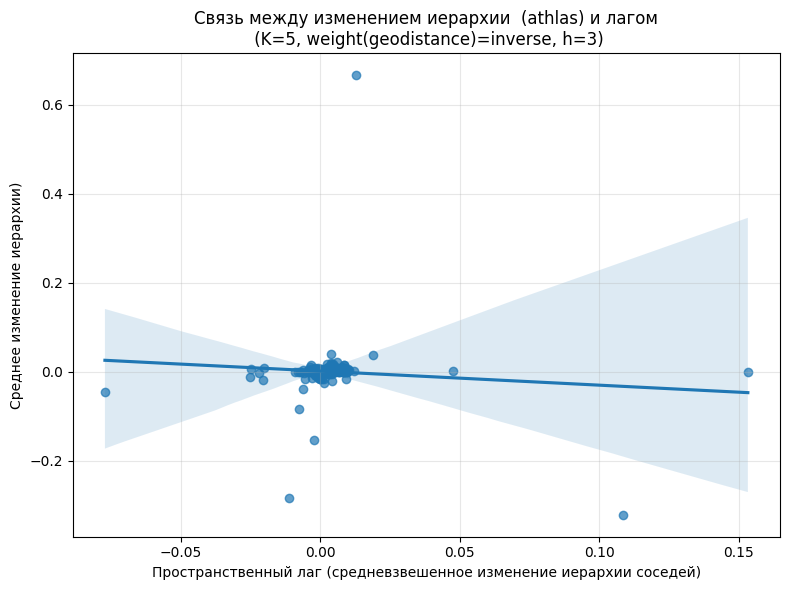

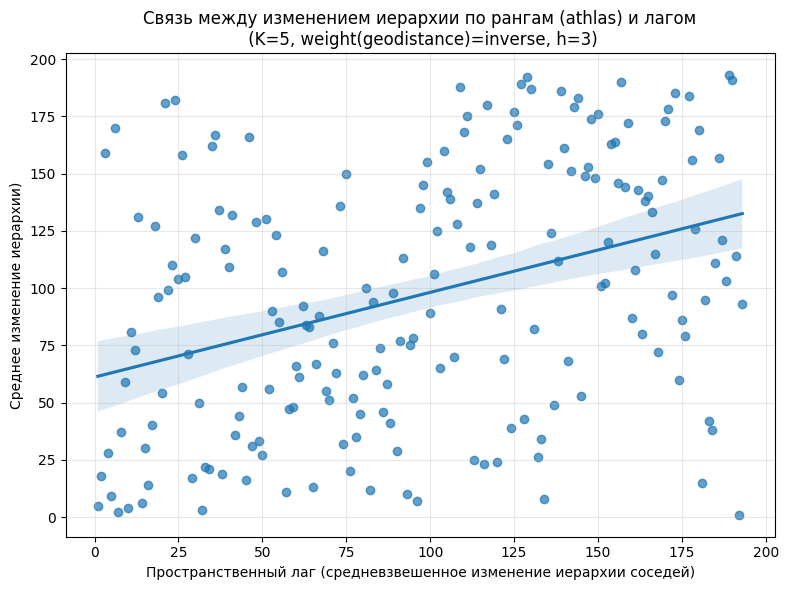

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0851, p-value = 0.2391
INFO:root:Спирмен: r = 0.3701, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0230
INFO:root:p-value (перестановочный) = 0.1220
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.12

ML_Lag
Размеры режимов:
small power     169
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     168  0.003957  0.053796 -0.153605  0.666065
hostile        1  0.007177       NaN  0.007177  0.007177
neutral       23 -0.011837  0.068845 -0.321061  0.037912
tense          1 -0.283977       NaN -0.283977 -0.283977


INFO:root:Starting spatial analysis for geodistance with gpi as hierarchy index
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(181, 3) | NaN=0


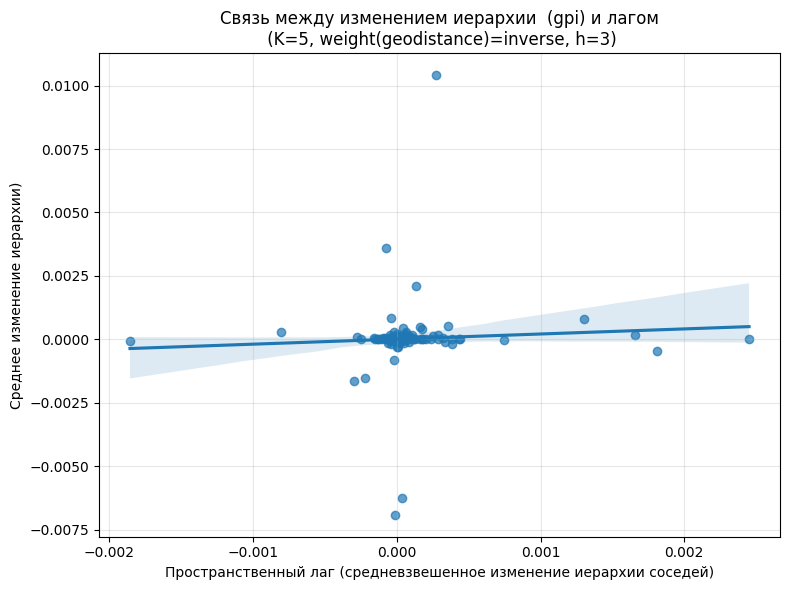

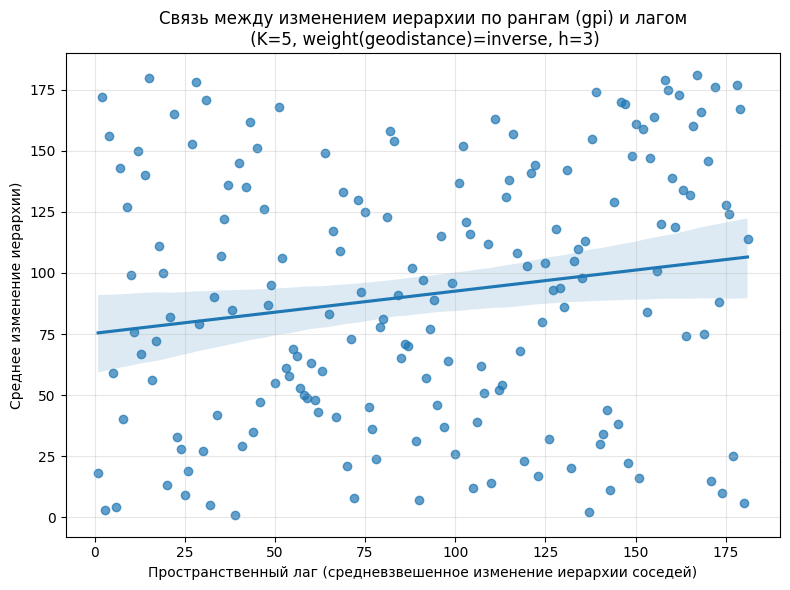

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0603, p-value = 0.4203
INFO:root:Спирмен: r = 0.1725, p-value = 0.0202
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.1370
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1640
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1207

ML_Lag
Размеры режимов:
small power     157
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     158  0.000064  0.001044 -0.006233  0.010411
hostile        1 -0.000315       NaN -0.000315 -0.000315
neutral       21  0.000076  0.000277 -0.000468  0.000847
tense          1 -0.006906       NaN -0.006906 -0.006906


INFO:root:Starting spatial analysis for geodistance with cinc as hierarchy index
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3) | NaN=0


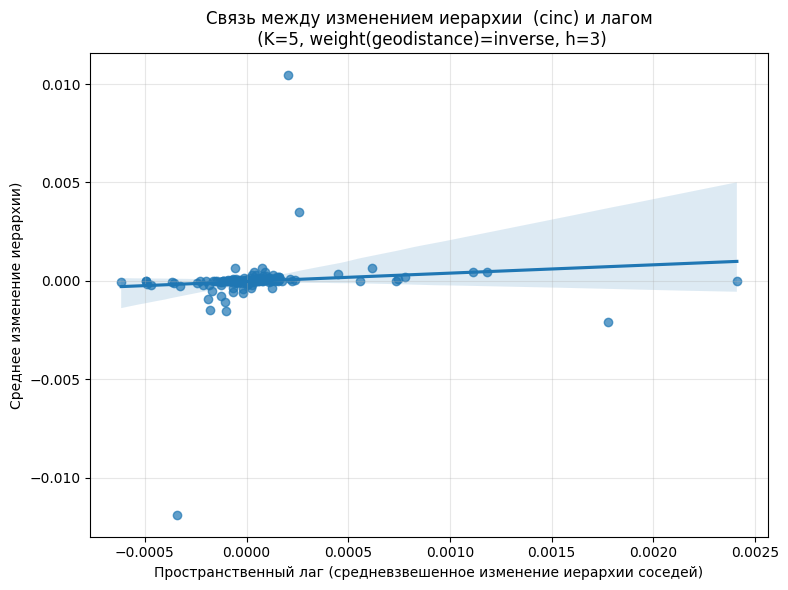

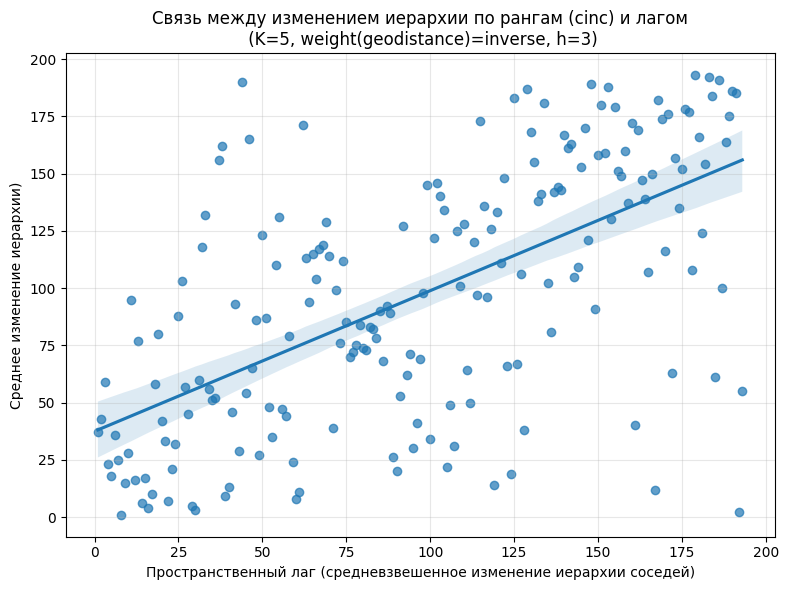

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1047, p-value = 0.1473
INFO:root:Спирмен: r = 0.6140, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0259
INFO:root:p-value (перестановочный) = 0.0650
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4789
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.4040

ML_Lag
Размеры режимов:
small power     169
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     168 -0.000009  0.001279 -0.011892  0.010455
hostile        1  0.000098       NaN  0.000098  0.000098
neutral       23 -0.000033  0.000499 -0.002104  0.000663
tense          1 -0.001074       NaN -0.001074 -0.001074


INFO:root:Starting spatial analysis for geodistance with gdp as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(191, 3) | NaN=0


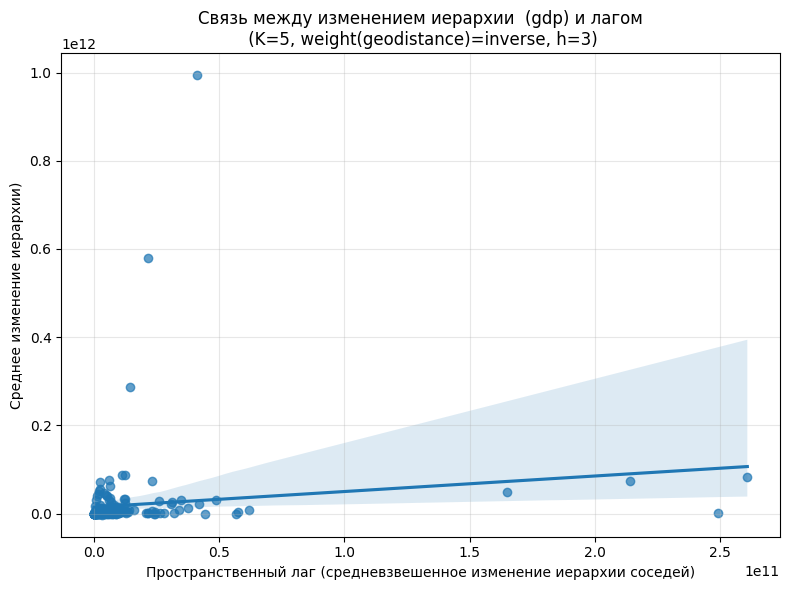

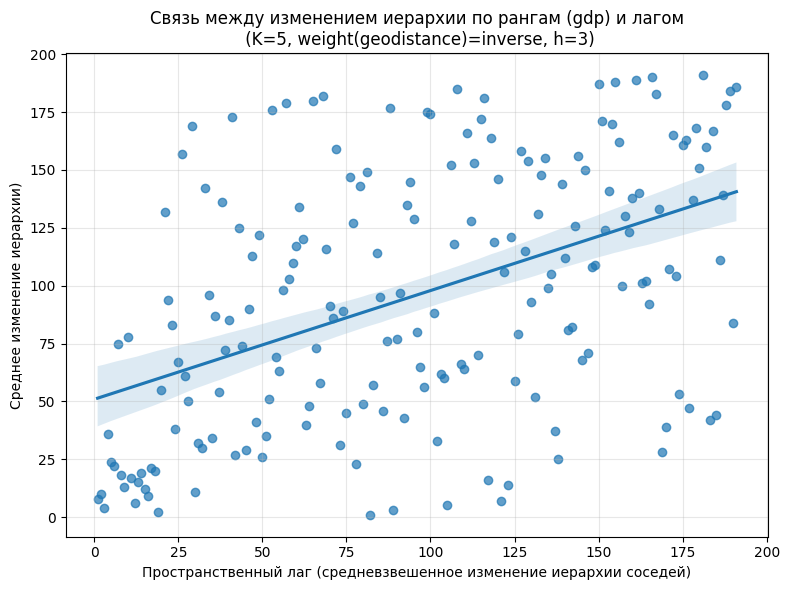

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1353, p-value = 0.0619
INFO:root:Спирмен: r = 0.4697, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0520
INFO:root:p-value (перестановочный) = 0.0390
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3508
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения 

ML_Lag
Размеры режимов:
small power     167
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count          mean           std           min           max
hostility                                                               
friendly     166  1.016582e+10  2.700664e+10 -2.529798e+09  2.860355e+11
hostile        1  1.398026e+10           NaN  1.398026e+10  1.398026e+10
neutral       23  6.198697e+10  2.050034e+11  2.634277e+06  9.941091e+11
tense          1  5.793686e+11           NaN  5.793686e+11  5.793686e+11


INFO:root:Starting spatial analysis for geodistance with net_subsystem as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3) | NaN=0


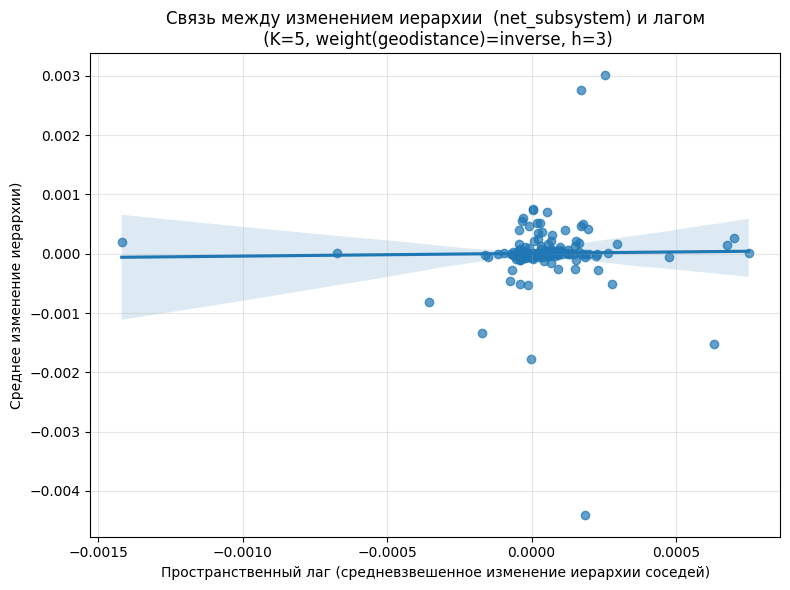

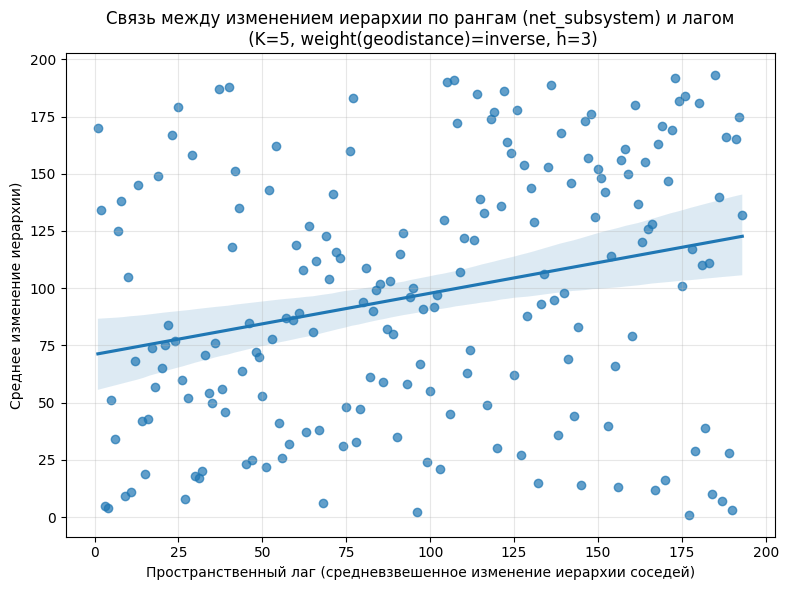

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0161, p-value = 0.8245
INFO:root:Спирмен: r = 0.2675, p-value = 0.0002
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0055
INFO:root:p-value (перестановочный) = 0.3760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1951
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2493

ML_Lag
Размеры режимов:
small power     169
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     168  0.000019  0.000511 -0.004403  0.003009
hostile        1  0.000462       NaN  0.000462  0.000462
neutral       23 -0.000029  0.000463 -0.001517  0.000743
tense          1 -0.001341       NaN -0.001341 -0.001341


INFO:root:Starting spatial analysis for geodistance with net as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3) | NaN=0


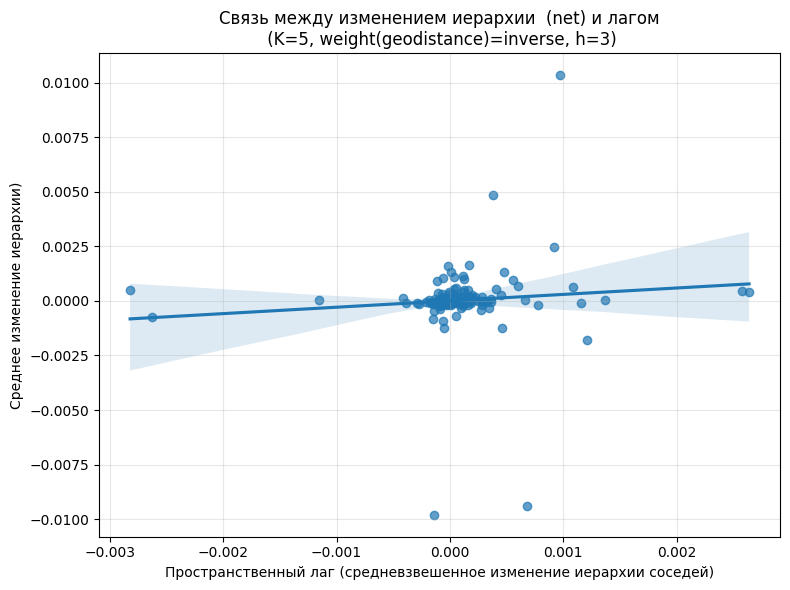

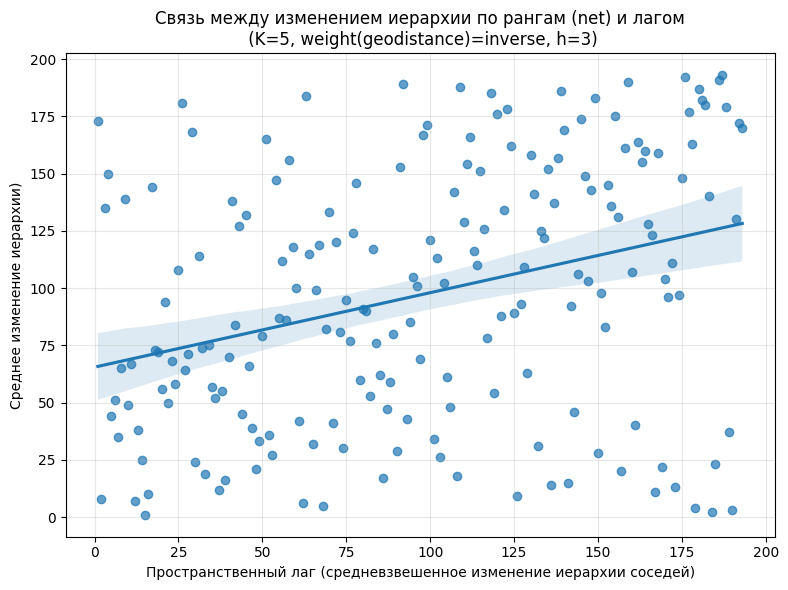

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1025, p-value = 0.1560
INFO:root:Спирмен: r = 0.3252, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0358
INFO:root:p-value (перестановочный) = 0.0810
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1894
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.2350

ML_Lag
Размеры режимов:
small power     169
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     168  0.000083  0.001205 -0.009384  0.010350
hostile        1 -0.000021       NaN -0.000021 -0.000021
neutral       23  0.000013  0.000728 -0.001799  0.001632
tense          1 -0.009800       NaN -0.009800 -0.009800


INFO:root:Starting spatial analysis for geodistance with gdp_beckley as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(191, 3) | NaN=0


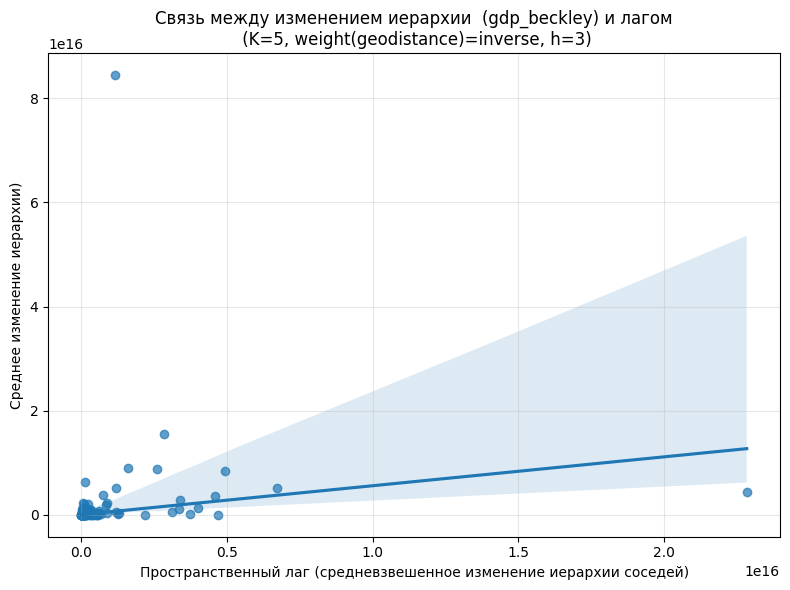

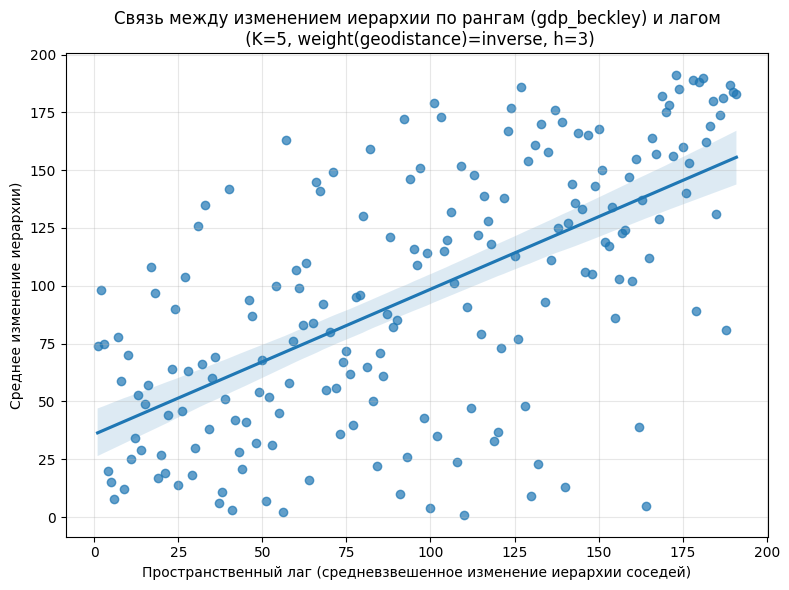

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1372, p-value = 0.0584
INFO:root:Спирмен: r = 0.6273, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0418
INFO:root:p-value (перестановочный) = 0.0280
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4721
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения 

ML_Lag
Размеры режимов:
small power     167
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count          mean           std           min           max
hostility                                                               
friendly     166  3.592905e+14  1.174040e+15 -3.042379e+13  9.009263e+15
hostile        1  1.161883e+15           NaN  1.161883e+15  1.161883e+15
neutral       23  1.800176e+15  3.818381e+15 -2.028576e+13  1.541302e+16
tense          1  8.443062e+16           NaN  8.443062e+16  8.443062e+16


INFO:root:Starting spatial analysis for geodistance with gdp_beckley_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 185
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(185, 3) | NaN=0


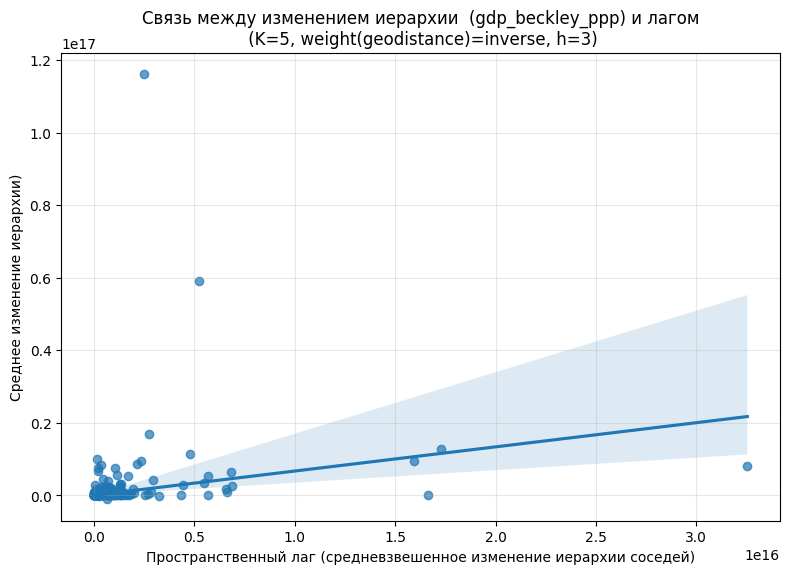

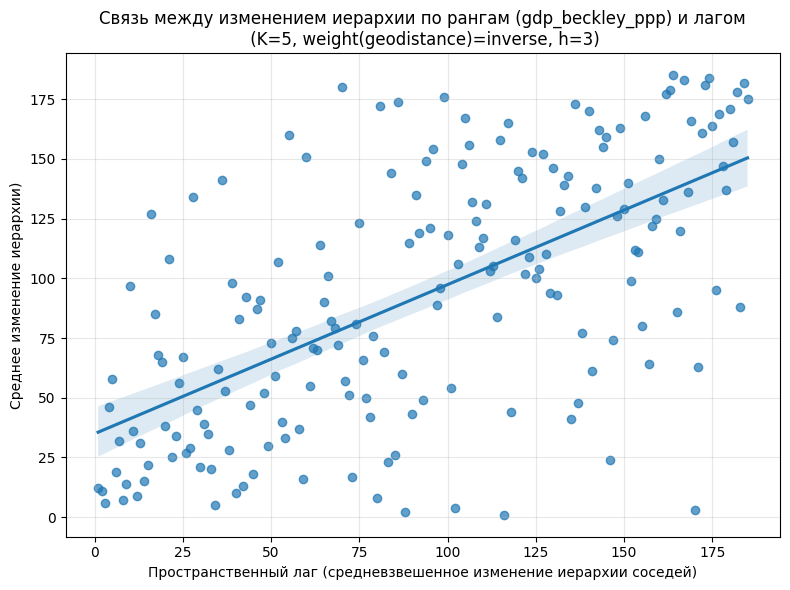

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1789, p-value = 0.0149
INFO:root:Спирмен: r = 0.6243, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0614
INFO:root:p-value (перестановочный) = 0.0270
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4624
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения 

ML_Lag
Размеры режимов:
small power     161
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count          mean           std           min           max
hostility                                                               
friendly     161  1.030639e+15  2.387502e+15 -1.162947e+15  1.689521e+16
hostile        1  1.638414e+15           NaN  1.638414e+15  1.638414e+15
neutral       22  4.960075e+15  1.269016e+16 -7.847308e+13  5.918847e+16
tense          1  1.161817e+17           NaN  1.161817e+17  1.161817e+17


INFO:root:Starting spatial analysis for geodistance with net_hitech as hierarchy index
INFO:root:Размер таблицы дельт: (196, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3) | NaN=0


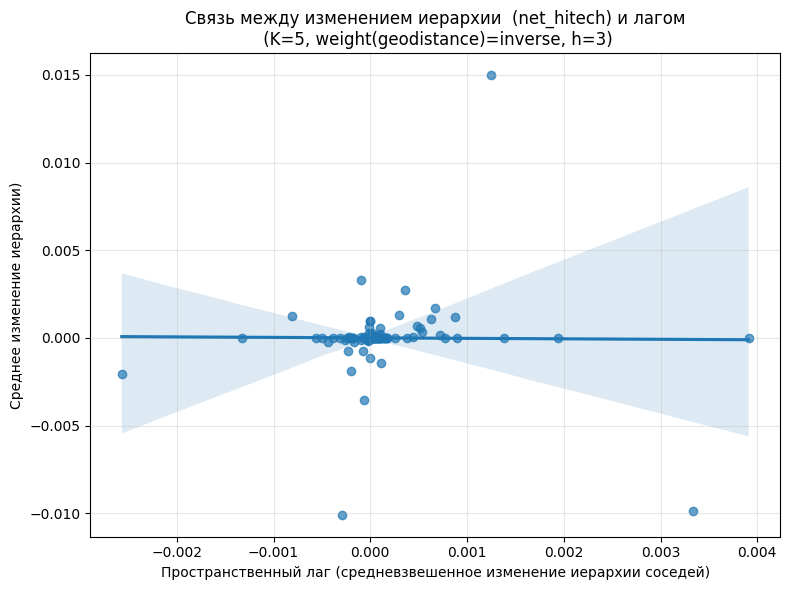

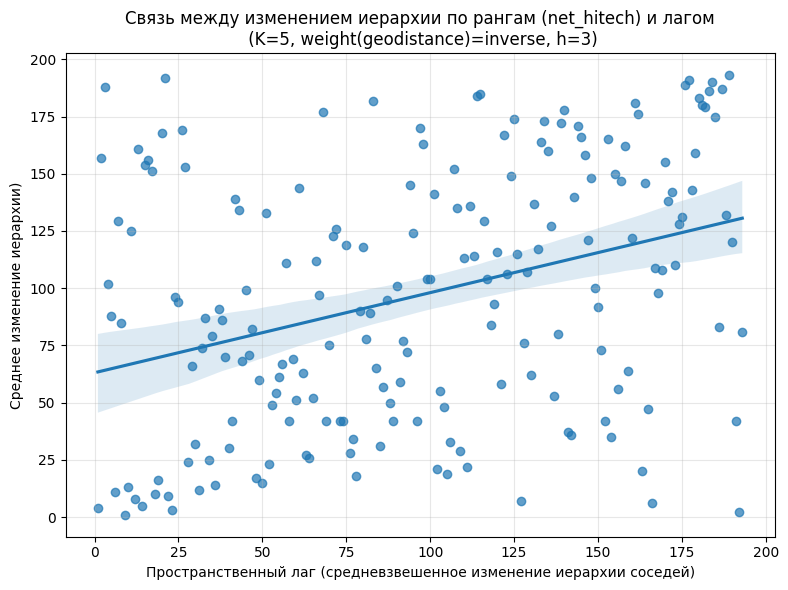

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0087, p-value = 0.9041
INFO:root:Спирмен: r = 0.3499, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0028
INFO:root:p-value (перестановочный) = 0.4760
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.2457
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.28

ML_Lag
Размеры режимов:
small power     169
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count      mean       std       min       max
hostility                                               
friendly     168  0.000113  0.001254 -0.003516  0.014969
hostile        1  0.000167       NaN  0.000167  0.000167
neutral       23 -0.000371  0.002222 -0.009841  0.003286
tense          1 -0.010081       NaN -0.010081 -0.010081


INFO:root:Starting spatial analysis for geodistance with gdp_nominal as hierarchy index
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(191, 3) | NaN=0


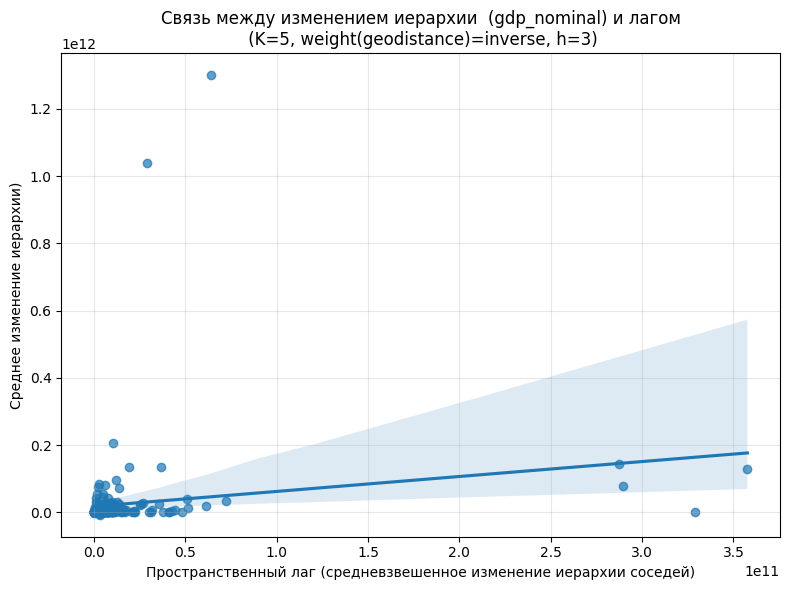

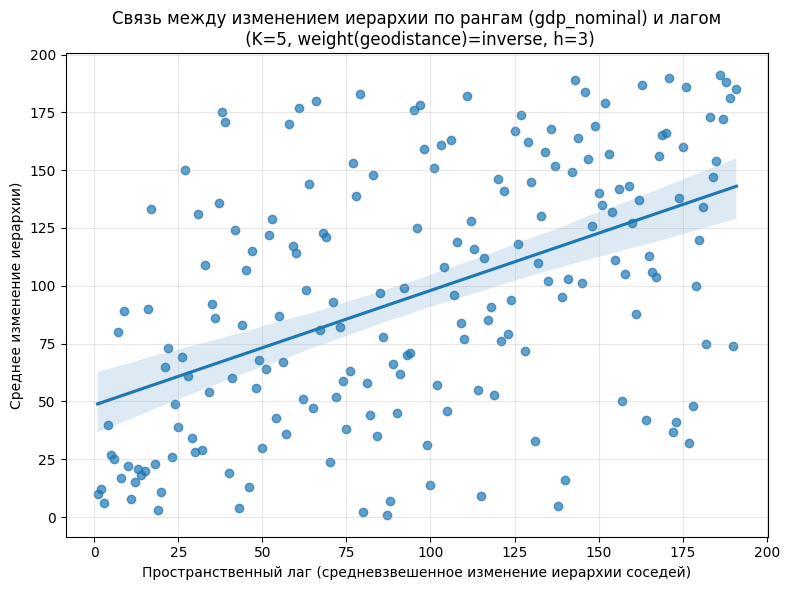

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1674, p-value = 0.0206
INFO:root:Спирмен: r = 0.4954, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0632
INFO:root:p-value (перестановочный) = 0.0230
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root: Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3607
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0053
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения 

ML_Lag
Размеры режимов:
small power     167
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count          mean           std           min           max
hostility                                                               
friendly     166  1.080969e+10  2.569720e+10 -6.919627e+09  2.060268e+11
hostile        1  2.493088e+10           NaN  2.493088e+10  2.493088e+10
neutral       23  8.261765e+10  2.687987e+11 -1.265033e+08  1.299317e+12
tense          1  1.039486e+12           NaN  1.039486e+12  1.039486e+12


INFO:root:Starting spatial analysis for geodistance with gdp_ppp as hierarchy index
INFO:root:Размер таблицы дельт: (186, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 185
INFO:root:Матрица весов построена (K=5, inverse): (185, 185)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Exog из df_x: ['value_ipd', 'value_rta', 'value_atop'] | shape=(185, 3) | NaN=0


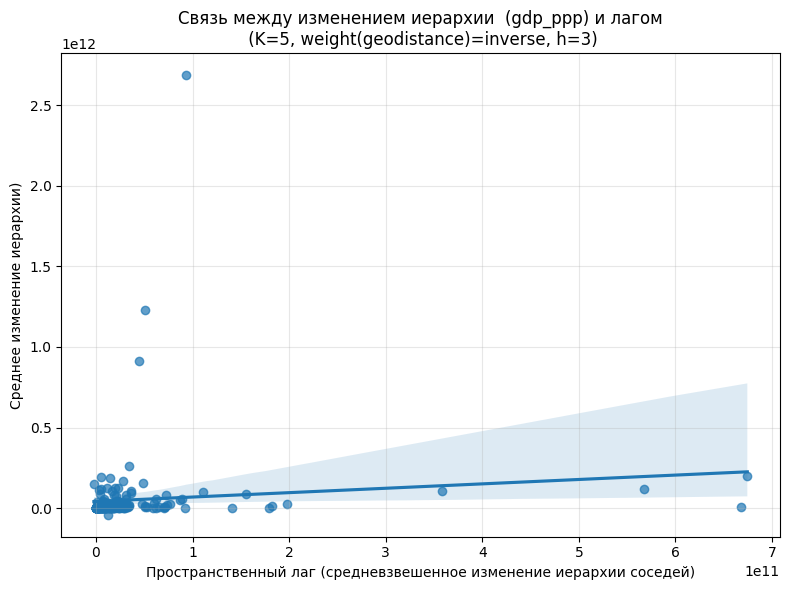

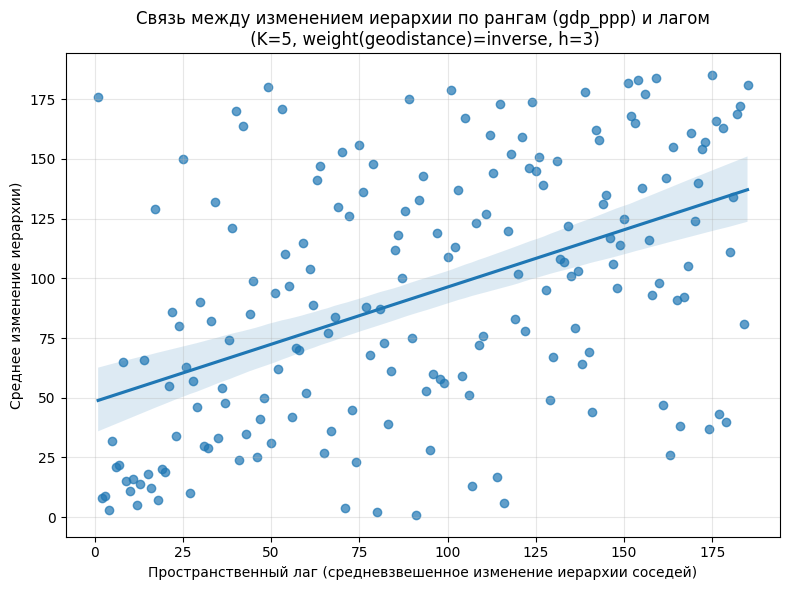

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1051, p-value = 0.1544
INFO:root:Спирмен: r = 0.4796, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0405
INFO:root:p-value (перестановочный) = 0.0510
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.3545
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0054
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I для бинарной переменной: 0.1170

ML_Lag
Размеры режимов:
small power     161
middle power     17
great power       7
Name: count, dtype: int64
Мин. размер режима: 7 | Число столбцов X ≈ 5
ML_Lag_Regimes
           count          mean           std           min           max
hostility                                                               
friendly     161  2.743840e+10  8.114394e+10 -4.163642e+10  9.113938e+11
hostile        1  3.019043e+10           NaN  3.019043e+10  3.019043e+10
neutral       22  1.680771e+11  5.660737e+11 -7.072082e+08  2.686211e+12
tense          1  1.226567e+12           NaN  1.226567e+12  1.226567e+12


In [61]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['geodistance']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        df_x = df_x.merge(predictor_dfs['ipd'], on = ['country_a', 'country_b'], suffixes = ('','_ipd'), how='right')
        df_x = df_x.merge(predictor_dfs['rta'], on = ['country_a', 'country_b','year'], suffixes = ('','_rta'), how='left').fillna(0)
        #df_x = df_x.merge(predictor_dfs['rta_eia'], on = ['country_a', 'country_b'], suffixes = ('','_rta_eia'), how='left').fillna(0) Не работает
        df_x = df_x.merge(predictor_dfs['atop'], on = ['country_a', 'country_b','year'], suffixes = ('','_atop'), how='left').fillna(0)
        #df_x = df_x.merge(predictor_dfs['devdiff'], on = ['country_a', 'country_b','year'], suffixes = ('','_devdiff'), how='left') слишком много пропусков
        df_x = df_x[df_x['year']>=1985]
        
        
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline_combined(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            ignore_super=True,
            include_sem=False,
            exog_cols=['value_ipd', 'value_rta', 'value_atop'],#,'value_devdiff'],
            regime_lag_sep=False,
            remove_isolates=False  # Они и так убираются, просто на другом этапе. Диагностический параметр
        )

In [54]:
for i in results:
    print(results[i]['geodistance']['sar_regimes_model'].summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG - REGIMES (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      : geodistance
Dependent Variable  :      athlas                Number of Observations:         193
Mean dependent var  :     97.0000                Number of Variables   :          19
S.D. dependent var  :     55.8585                Degrees of Freedom    :         174
Pseudo R-squared    :      0.8195
Spatial Pseudo R-squared:  0.8176
Log likelihood      :   -885.2186
Sigma-square ML     :    560.4284                Akaike info criterion :    1808.437
S.E of regression   :     23.6734                Schwarz criterion     :    1870.428

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------------

INFO:root:Spatial multi-space analysis: primary=geodistance, y=athlas
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:[primary] exog: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3)


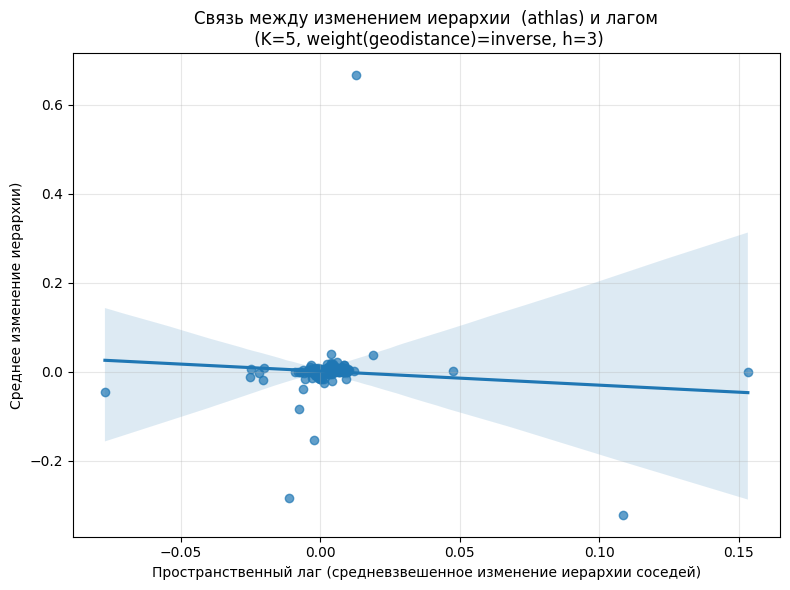

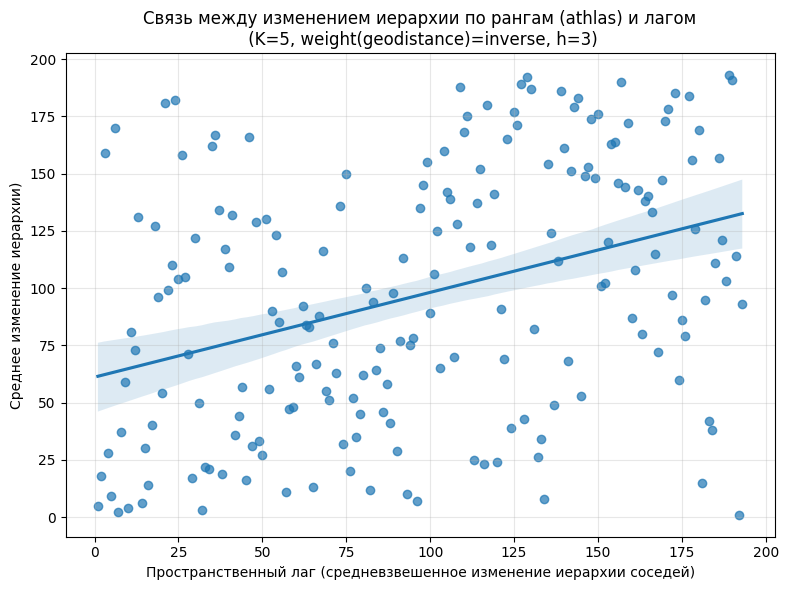

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = -0.0851, p-value = 0.2391
INFO:root:Спирмен: r = 0.3701, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = -0.0230
INFO:root:p-value (перестановочный) = 0.1250
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1962
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I (binary): 0.1282, p=0.0050
IN

ML_Lag
ML_Lag_Regimes


INFO:root:Spatial multi-space analysis: primary=geodistance, y=gpi
INFO:root:Размер таблицы дельт: (182, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 181
INFO:root:Матрица весов построена (K=5, inverse): (181, 181)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:[primary] exog: ['value_ipd', 'value_rta', 'value_atop'] | shape=(181, 3)


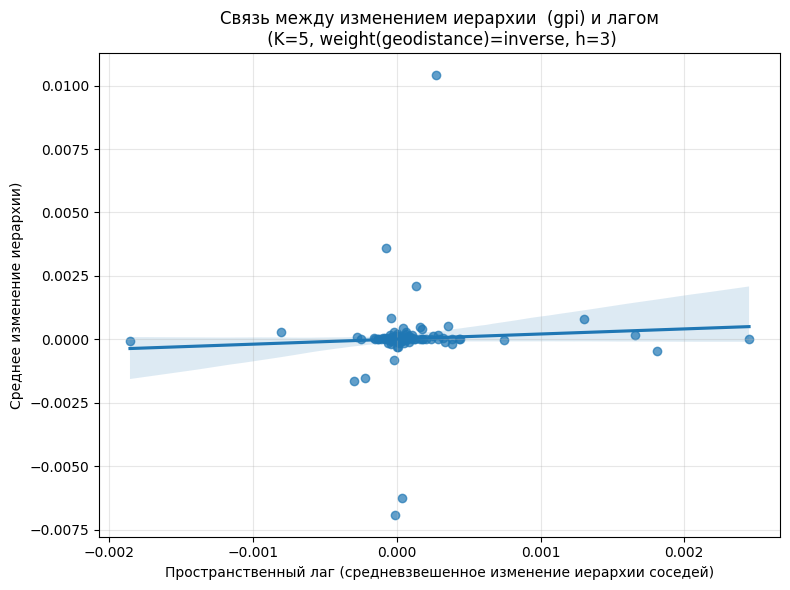

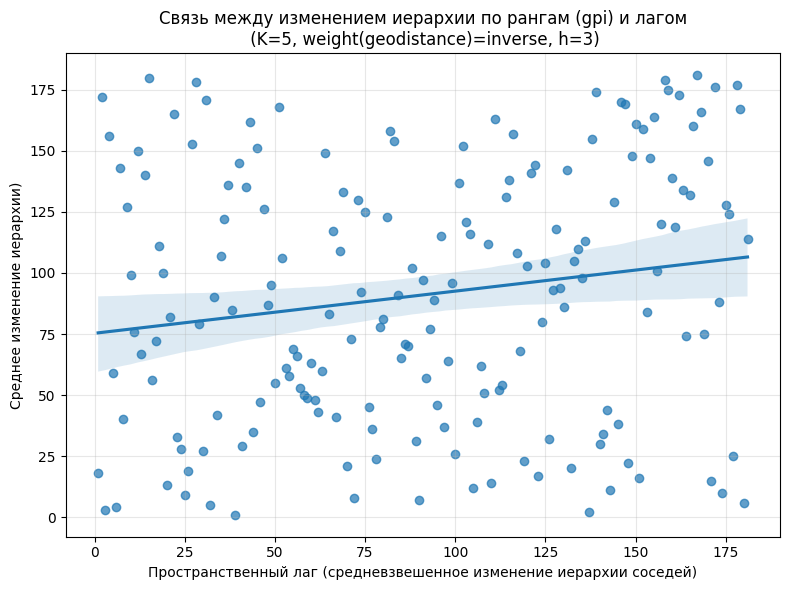

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.0603, p-value = 0.4203
INFO:root:Спирмен: r = 0.1725, p-value = 0.0202
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0181
INFO:root:p-value (перестановочный) = 0.1330
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.1640
INFO:root:p-value (перестановочный) = 0.0030
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0056
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I (binary): 0.1207, p=0.0070
INFO

ML_Lag


INFO:root:=== Пространственная регрессия с режимами (SAR) на рангах ===
INFO:root:REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG - REGIMES (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      : geodistance
Dependent Variable  :         gpi                Number of Observations:         181
Mean dependent var  :     91.0000                Number of Variables   :          16
S.D. dependent var  :     52.3943                Degrees of Freedom    :         165
Pseudo R-squared    :      0.6259
Spatial Pseudo R-squared:  0.6254
Log likelihood      :   -884.0575
Sigma-square ML     :   1021.1790                Akaike info criterion :    1800.115
S.E of regression   :     31.9559                Schwarz criterion     :    1851.291

------------------------------------------------------------------------------------
            Variable     Coefficient 

ML_Lag_Regimes


INFO:root:Spatial multi-space analysis: primary=geodistance, y=cinc
INFO:root:Размер таблицы дельт: (195, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 193
INFO:root:Матрица весов построена (K=5, inverse): (193, 193)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:[primary] exog: ['value_ipd', 'value_rta', 'value_atop'] | shape=(193, 3)


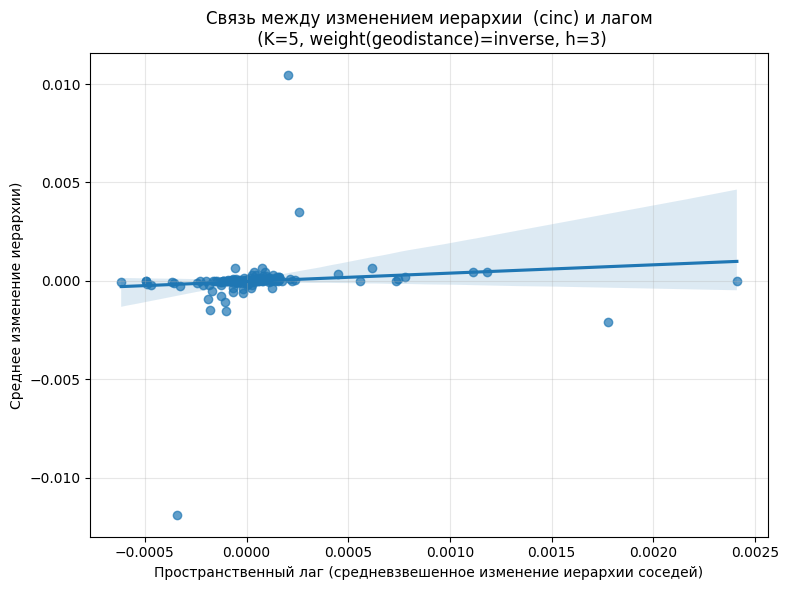

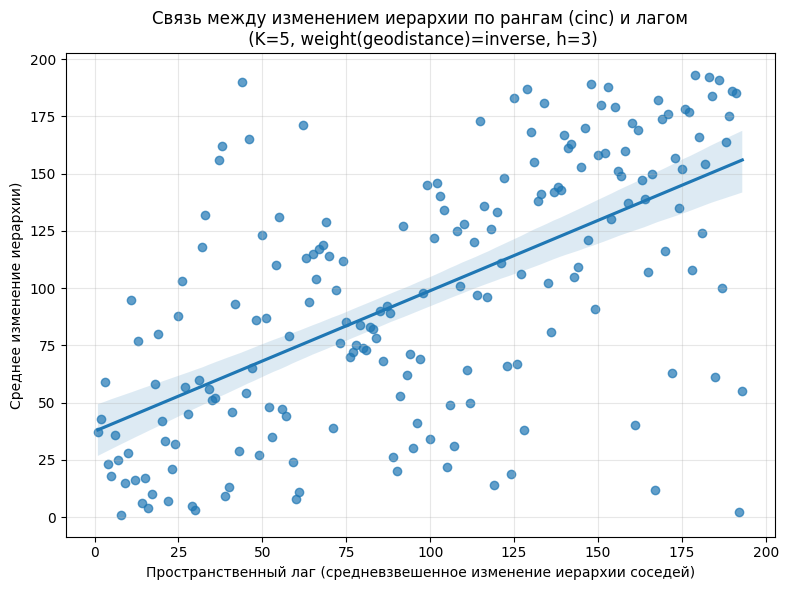

INFO:root:=== Корреляция между изменением положения в иерархии и пространственным лагом ===
INFO:root:Пирсон: r = 0.1047, p-value = 0.1473
INFO:root:Спирмен: r = 0.6140, p-value = 0.0000
INFO:root:=== Moran's I ===
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:I = 0.0259
INFO:root:p-value (перестановочный) = 0.0710
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root: Moran's I НЕ значим.
INFO:root:converting to ranked data
INFO:root:=== Ранговый Moran's I ===
INFO:root:I = 0.4789
INFO:root:p-value (перестановочный) = 0.0010
INFO:root:Ожидаемое I при отсутствии автокорреляции: -0.0052
INFO:root:Ранговый  Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.
INFO:root:Moran's I (binary): 0.4040, p=0.0010
INFO

ML_Lag
ML_Lag_Regimes


INFO:root:Spatial multi-space analysis: primary=geodistance, y=gdp
INFO:root:Размер таблицы дельт: (193, 2)
INFO:root:Стран, по которым есть расстояния и дельты: 192
INFO:root:Матрица весов построена (K=5, inverse): (192, 192)
/home/alex-server/Sync/Работа/Code/phd_thesis/.venv/lib/python3.11/site-packages/libpysal/weights/util.py:761: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=ids, **kwargs)
INFO:root:Внимание: 1 стран имеют NaN в средних дельтах. Они будут исключены.


TypeError: only integer scalar arrays can be converted to a scalar index

In [44]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['geodistance']:
        df_x_primary = predictor_dfs[predictor].copy()
        df_x_primary = df_x_primary.merge(
            predictor_dfs['ipd'],
            on=['country_a', 'country_b'],
            suffixes=('', '_ipd'), how='right'
        )
        df_x_primary = df_x_primary.merge(
            predictor_dfs['rta'],
            on=['country_a', 'country_b'],
            suffixes=('', '_rta'), how='left'
        ).fillna(0)
        df_x_primary = df_x_primary.merge(
            predictor_dfs['atop'],
            on=['country_a', 'country_b'],
            suffixes=('', '_atop'), how='left'
        ).fillna(0)

        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'
        df_y = power_dfs[power]

        # ---- дополнительные пространства ----
        # ВНИМАНИЕ: для ipd/rta/atop нужно заранее сделать "distance"-представление.
        # Пример: ipd_norm = 1 - ipd; rta_dist = 1 / (1 + rta); atop_dist = 1 - atop.
        # Ниже — иллюстрация; подставьте свои преобразования.
        def _to_space_distance(df, value_col):
            d = df[['country_a', 'country_b', 'year', value_col]].copy()
            # простая инверсия value → distance; замените на осмысленную
            d['distance'] = 1.0 / (1.0 + d[value_col].abs())
            return d[['country_a', 'country_b', 'year', 'distance']]

        extra_spaces = [
            {
                'name': 'ipd',
                'df_x': _to_space_distance(predictor_dfs['ipd'], 'value'),
                'k_neighbors': K_NEIGHBORS,
                'weight_type': 'inverse',
                'include_lag': True,
                'include_exog': None,   # exog уже в primary через merge
            },
            {
                'name': 'rta',
                'df_x': _to_space_distance(predictor_dfs['rta'], 'value'),
                'k_neighbors': K_NEIGHBORS,
                'weight_type': 'inverse',
                'include_lag': True,
            },
            {
                'name': 'atop',
                'df_x': _to_space_distance(predictor_dfs['atop'], 'value'),
                'k_neighbors': K_NEIGHBORS,
                'weight_type': 'inverse',
                'include_lag': True,
            },
        ]

        logging.info(f"Spatial multi-space analysis: primary={predictor}, y={power}")

        results[power][predictor] = spatial_analysis_pipeline_multi(
            df_y=df_y,
            df_x=df_x_primary,
            horizon=3,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            ignore_super=True,
            include_sem=False,
            exog_cols=['value_ipd', 'value_rta', 'value_atop'],
            regime_lag_sep=False,
            remove_isolates=False,
            extra_spaces=extra_spaces,      # NEW
        )

# Analysis OLD

### Various

In [1064]:
models={'Linear Regression': LinearRegression(),
            'Ridge': Ridge(alpha=1.0),
            'Lasso': Lasso(alpha=0.01)}

In [1065]:
#df_x = predictor_dfs['rta']#['geodistance']#['ipd']
#df_x = pairwise_deltas(df_y, True).rename({'delta':'value'}, axis=1)#predictor_dfs['economy_net']
#df_x = predictor_dfs['atop_nato']
df_x = predictor_dfs['combined']
df_y = power_dfs['net']

deltas = compute_deltas(df_y, horizons=(1, 2, 3))

features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20),return_neighbor_lists=True)

In [904]:
features.sample(10)#.loc[:,'top5_change_1y':]#[features['country_a']=='United States']

,country_a,year,top5_change_1y,top5_change_2y,top5_change_3y,top5_neighbors,top10_change_1y,top10_change_2y,top10_change_3y,top10_neighbors,top15_change_1y,top15_change_2y,top15_change_3y,top15_neighbors,top20_change_1y,top20_change_2y,top20_change_3y,top20_neighbors,country_a_change_1y
5301,Romania,2019,0.000059,-0.001151,-0.000917,"[Finland, Slovakia, Bulgaria, Ukraine, Hungary]",0.000059,-0.000545,-0.000354,"[Finland, Slovakia, Bulgaria, Ukraine, Hungary...",0.000084,-0.000291,-0.000139,"[Finland, Slovakia, Bulgaria, Ukraine, Hungary...",0.000120,-0.000150,-0.000021,"[Finland, Slovakia, Bulgaria, Ukraine, Hungary...",1.835508e-04
818,Botswana,1992,-0.000068,-0.000379,-0.000498,"[Namibia, Zambia, Georgia, Liberia, Burundi]",-0.000126,-0.000531,-0.000762,"[Namibia, Zambia, Georgia, Liberia, Burundi, M...",-0.000094,-0.000415,-0.000588,"[Namibia, Zambia, Georgia, Liberia, Burundi, M...",-0.000097,-0.000421,-0.000597,"[Namibia, Zambia, Georgia, Liberia, Burundi, M...",-6.107245e-05
3632,Lesotho,2005,-0.000008,-0.000013,-0.000012,"[Nauru, Afghanistan, Maldives, Comoros, Lao Pe...",-0.000010,-0.000015,-0.000009,"[Nauru, Afghanistan, Maldives, Comoros, Lao Pe...",-0.000007,-0.000011,-0.000008,"[Nauru, Afghanistan, Maldives, Comoros, Lao Pe...",-0.000007,-0.000035,-0.000012,"[Nauru, Afghanistan, Maldives, Comoros, Lao Pe...",-2.938741e-06
465,Bahrain,2006,-0.000057,-0.000100,-0.000085,"[Panama, Cameroon, Kenya, Azerbaijan, Zimbabwe]",-0.000023,-0.000107,-0.000119,"[Panama, Cameroon, Kenya, Azerbaijan, Zimbabwe...",-0.000025,-0.000093,-0.000110,"[Panama, Cameroon, Kenya, Azerbaijan, Zimbabwe...",-0.000055,-0.000105,-0.000137,"[Panama, Cameroon, Kenya, Azerbaijan, Zimbabwe...",4.944903e-05
375,Azerbaijan,1992,0.000232,0.000236,0.000029,"[Uzbekistan, Armenia, Oman, Iraq, Kenya]",0.000088,0.000189,0.000199,"[Uzbekistan, Armenia, Oman, Iraq, Kenya, Belar...",0.000020,-0.000187,-0.000250,"[Uzbekistan, Armenia, Oman, Iraq, Kenya, Belar...",0.000091,-0.000228,-0.000276,"[Uzbekistan, Armenia, Oman, Iraq, Kenya, Belar...",1.115100e-03
2606,Guatemala,1987,-0.000072,-0.000231,NaN,"[El Salvador, Barbados, Jamaica, Nicaragua, Sa...",-0.000060,-0.000191,NaN,"[El Salvador, Barbados, Jamaica, Nicaragua, Sa...",-0.000052,-0.000211,NaN,"[El Salvador, Barbados, Jamaica, Nicaragua, Sa...",-0.000032,-0.000177,NaN,"[El Salvador, Barbados, Jamaica, Nicaragua, Sa...",-4.115532e-05
3290,Kazakhstan,1993,0.000267,0.000460,0.000353,"[Jordan, Luxembourg, Bhutan, Bangladesh, Nepal]",0.000205,0.000155,-0.000060,"[Jordan, Luxembourg, Bhutan, Bangladesh, Nepal...",0.000101,0.000194,-0.000181,"[Jordan, Luxembourg, Bhutan, Bangladesh, Nepal...",0.000063,0.000167,-0.000299,"[Jordan, Luxembourg, Bhutan, Bangladesh, Nepal...",-4.805842e-04
2864,Hungary,2017,0.000048,0.000079,0.000480,"[Greece, Czechia, Thailand, Slovakia, Luxembourg]",-0.000726,-0.000626,-0.000317,"[Greece, Czechia, Thailand, Slovakia, Luxembou...",-0.000569,-0.000410,-0.000173,"[Greece, Czechia, Thailand, Slovakia, Luxembou...",-0.000409,-0.000302,-0.000207,"[Greece, Czechia, Thailand, Slovakia, Luxembou...",1.129055e-04
4876,Panama,1998,-0.000005,0.000032,0.000115,"[Guatemala, Cyprus, Jamaica, Estonia, Barbados]",-0.000006,0.000003,0.000038,"[Guatemala, Cyprus, Jamaica, Estonia, Barbados...",-0.000005,-0.000030,-0.000090,"[Guatemala, Cyprus, Jamaica, Estonia, Barbados...",-0.000004,-0.000028,-0.000079,"[Guatemala, Cyprus, Jamaica, Estonia, Barbados...",3.349257e-07
6091,Sri Lanka,2019,0.000020,0.000027,0.000018,"[El Salvador, Montenegro, Kyrgyzstan, Nepal, Z...",0.000011,-0.000003,0.000004,"[El Salvador, Montenegro, Kyrgyzstan, Nepal, Z...",0.000013,0.000007,0.000023,"[El Salvador, Montenegro, Kyrgyzstan, Nepal, Z...",0.000001,-0.000003,0.000018,"[El Salvador, Montenegro, Kyrgyzstan, Nepal, Z...",3.023061e-05


In [1066]:
features[['top5_change_1y', 'top10_change_1y','country_a_change_1y']].corr()['country_a_change_1y']

top5_change_1y         0.165974
top10_change_1y        0.112989
country_a_change_1y    1.000000
Name: country_a_change_1y, dtype: float64

In [915]:
res = regression_analysis(features)#, models=models)

INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='country_a_change_1y', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 7179, после удаления пропусков в целевой: 6981
INFO:root:Обнаружены колонки вида 'top{K}_change{h}y' → выбран режим 'topk'.
INFO:root:Итоговые K_list: [5, 10, 15, 20]
INFO:root:Итоговые horizons: [1, 2, 3]
INFO:root:Всего комбинаций для перебора: 60
INFO:root:Результаты: Linear Regression, K=5, h=1 -> R²=0.0097 (±0.0475)
INFO:root:Результаты: Linear Regression, K=5, h=2 -> R²=0.0147 (±0.0406)
INFO:root:Результаты: Linear Regression, K=5, h=3 -> R²=0.0055 (±0.0387)
INFO:root:Результаты: Linear Regression, K=10, h=1 -> R²=-0.0020 (±0.0361)
INFO:root:Результаты: Linear Regression, K=10, h=2 -> R²=-0.0039 (±0.0365)
INFO:root:Результаты: Linear Regression, K=10, h=3 -> R²=-0.0090 (±0.0144)
INFO:root:Результаты: Linear Regression, K=15, h=1 -> R²=-0.0067 (±0.0188)
INFO:root:Результаты: Linear Regression, K=15, h=2 -> R²=-0.0106 (±0.0215)
INF

In [713]:
list(predictor_dfs.keys())[5:]

['economy_net', 'human_net', 'security_net', 'atop_nato']

In [187]:
# Regression
r_sq = {}
models=models
for x_label in ['devdiff']:#predictor_dfs:
    logging.info(f"РАБОТАЕМ С {x_label} В КАЧЕСТВЕ X")
    df_x = predictor_dfs[x_label]
    reg_res[x_label] = dict()
    r_sq[x_label] = dict()
    for y_label in power_dfs:
        if (y_label!='gdp') & (y_label!='net_subsystem'):
            logging.info(f"РАБОТАЕМ С {y_label} В КАЧЕСТВЕ Y (X - {x_label})")
            df_y = power_dfs[y_label]
            #deltas = compute_deltas(df_y, horizons=(1, 2, 3))
            deltas = compute_deltas(df_y, horizons=(1,2,3,5,))
            if x_label in HAS_THRESHOLD:
                features = build_neighbor_features(df_x, deltas, threshold=True)
                #features = build_neighbor_features(df_x, deltas, threshold=True, horizons=(1,2,3),own_change_horizon=5)
            else:
                features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20))
                #features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10),horizons=(1,2,3), own_change_horizon=5)
            #reg_res[x_label][y_label]=regression_analysis(features)
            try:
                reg_res[x_label][y_label]=regression_analysis(features, models=models)
                r_sq[x_label][y_label]=round(reg_res[x_label][y_label][1]['cv_mean_R2'],3)
            except ValueError:
                continue

INFO:root:РАБОТАЕМ С devdiff В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - devdiff)
INFO:root:=== Начало регрессионного анализа ===
INFO:root:target='country_a_change_1y', cv_folds=5, random_state=42
INFO:root:Исходное количество строк: 6081, после удаления пропусков в целевой: 5323
INFO:root:Обнаружены колонки вида 'top{K}_change{h}y' → выбран режим 'topk'.
INFO:root:Итоговые K_list: [5, 10, 15, 20]
INFO:root:Итоговые horizons: [1, 2, 3]
INFO:root:Всего комбинаций для перебора: 36
INFO:root:Результаты: Linear Regression, K=5, h=1 -> R²=0.0011 (±0.0111)
INFO:root:Результаты: Linear Regression, K=5, h=2 -> R²=0.0009 (±0.0018)
INFO:root:Результаты: Linear Regression, K=5, h=3 -> R²=-0.0013 (±0.0014)
INFO:root:Результаты: Linear Regression, K=10, h=1 -> R²=0.0036 (±0.0046)
INFO:root:Результаты: Linear Regression, K=10, h=2 -> R²=0.0030 (±0.0024)
INFO:root:Результаты: Linear Regression, K=10, h=3 -> R²=-0.0002 (±0.0018)
INFO:root:Результаты: Linear Regression, K=15, h=1 -> R²=

In [1068]:
# Correlations
p = {}
corr_res = {}
models=models
for x_label in predictor_dfs:
    logging.info(f"РАБОТАЕМ С {x_label} В КАЧЕСТВЕ X")
    df_x = predictor_dfs[x_label]
    corr_res[x_label] = dict()
    p[x_label] = dict()
    for y_label in power_dfs:
        if (y_label!='gdp') & (y_label!='net_subsystem'):
            logging.info(f"РАБОТАЕМ С {y_label} В КАЧЕСТВЕ Y (X - {x_label})")
            df_y = power_dfs[y_label]
            #deltas = compute_deltas(df_y, horizons=(1, 2, 3))
            deltas = compute_deltas(df_y, horizons=(1,2,3,5,))
            if x_label in HAS_THRESHOLD:
                features = build_neighbor_features(df_x, deltas, threshold=True)
                #features = build_neighbor_features(df_x, deltas, threshold=True, horizons=(1,2,3),own_change_horizon=5)
            else:
                features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20))
                #features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10),horizons=(1,2,3), own_change_horizon=5)
            #reg_res[x_label][y_label]=regression_analysis(features)
            try:
                first_column = 'neighbor_change_1y' if 'neighbor_change_1y' in features.columns else 'top5_change_1y'
                corr_res[x_label][y_label] = features.loc[:,first_column:].corr()['country_a_change_1y'].drop('country_a_change_1y')
                p[x_label][y_label] = round(corr_res[x_label][y_label].max(), 3)
                print(p[x_label][y_label])
                #reg_res[x_label][y_label]=regression_analysis(features, models=models)
                #r_sq[x_label][y_label]=round(reg_res[x_label][y_label][1]['cv_mean_R2'],3)
            except ValueError:
                continue

INFO:root:РАБОТАЕМ С ipd В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - ipd)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - ipd)


0.06


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - ipd)


0.024


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - ipd)


0.02


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - ipd)


-0.012


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - ipd)


nan


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - ipd)


nan


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - ipd)


nan


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - ipd)


0.242


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - ipd)


0.207


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - ipd)


0.097


INFO:root:РАБОТАЕМ С geodistance В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - geodistance)


0.063
0.122


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - geodistance)


0.03
0.067
0.102


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - geodistance)


0.003
0.326
0.218
0.165


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - geodistance)
INFO:root:РАБОТАЕМ С cultdistance В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - cultdistance)


0.203
0.145
0.133


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - cultdistance)


0.118
0.106
0.014
0.059


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - cultdistance)


nan
nan
nan
0.293


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - cultdistance)
INFO:root:РАБОТАЕМ С langdistance В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - langdistance)


0.298
0.19
0.156
0.114


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - langdistance)


0.042
0.043
-0.023


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - langdistance)


0.409
0.289
0.461
0.154


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - langdistance)
INFO:root:РАБОТАЕМ С atop В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - atop)


0.182
0.152
0.15
Пороговый режим активен: параметр top_k_list игнорируется.
0.044


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - atop)


Пороговый режим активен: параметр top_k_list игнорируется.
0.004
Пороговый режим активен: параметр top_k_list игнорируется.
0.01
Пороговый режим активен: параметр top_k_list игнорируется.
-0.019
Пороговый режим активен: параметр top_k_list игнорируется.
nan
Пороговый режим активен: параметр top_k_list игнорируется.
nan
Пороговый режим активен: параметр top_k_list игнорируется.
nan
Пороговый режим активен: параметр top_k_list игнорируется.


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - atop)
INFO:root:РАБОТАЕМ С atop_nato В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - atop_nato)


0.049
Пороговый режим активен: параметр top_k_list игнорируется.
0.073
Пороговый режим активен: параметр top_k_list игнорируется.
0.094
Пороговый режим активен: параметр top_k_list игнорируется.
0.121
Пороговый режим активен: параметр top_k_list игнорируется.
0.412
Пороговый режим активен: параметр top_k_list игнорируется.
0.073
Пороговый режим активен: параметр top_k_list игнорируется.
0.403
Пороговый режим активен: параметр top_k_list игнорируется.
-0.027
Пороговый режим активен: параметр top_k_list игнорируется.
nan


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - atop_nato)
INFO:root:РАБОТАЕМ С economy_net В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - economy_net)


Пороговый режим активен: параметр top_k_list игнорируется.
nan
Пороговый режим активен: параметр top_k_list игнорируется.
nan
Пороговый режим активен: параметр top_k_list игнорируется.
0.417
Пороговый режим активен: параметр top_k_list игнорируется.
0.477
Пороговый режим активен: параметр top_k_list игнорируется.
0.408
Пороговый режим активен: параметр top_k_list игнорируется.
0.472
Пороговый режим активен: параметр top_k_list игнорируется.
0.002
Пороговый режим активен: параметр top_k_list игнорируется.


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - economy_net)


-0.005
Пороговый режим активен: параметр top_k_list игнорируется.
-0.005
Пороговый режим активен: параметр top_k_list игнорируется.
-0.004
Пороговый режим активен: параметр top_k_list игнорируется.
-0.116
Пороговый режим активен: параметр top_k_list игнорируется.
-0.506
Пороговый режим активен: параметр top_k_list игнорируется.


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - economy_net)
INFO:root:РАБОТАЕМ С human_net В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - human_net)


-0.738
Пороговый режим активен: параметр top_k_list игнорируется.
-0.031
Пороговый режим активен: параметр top_k_list игнорируется.
-0.033
Пороговый режим активен: параметр top_k_list игнорируется.
-0.066
Пороговый режим активен: параметр top_k_list игнорируется.
-0.056


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - human_net)


0.033


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - human_net)


0.033


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - human_net)


0.046


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - human_net)


-0.012


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - human_net)


0.681


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - human_net)


0.134


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - human_net)


0.643


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - human_net)


0.038


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - human_net)


-0.009


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - human_net)


0.02


INFO:root:РАБОТАЕМ С security_net В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - security_net)


-0.035


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - security_net)


0.038


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - security_net)


0.035


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - security_net)


0.014


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - security_net)


0.008


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - security_net)


-0.219


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - security_net)


-0.329


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - security_net)


-0.173


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - security_net)


0.242


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - security_net)


0.244


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - security_net)


0.224


INFO:root:РАБОТАЕМ С rta В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - rta)


0.183
Пороговый режим активен: параметр top_k_list игнорируется.
0.142
Пороговый режим активен: параметр top_k_list игнорируется.
0.026
Пороговый режим активен: параметр top_k_list игнорируется.
0.041
Пороговый режим активен: параметр top_k_list игнорируется.
-0.009
Пороговый режим активен: параметр top_k_list игнорируется.
0.458


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - rta)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - rta)


Пороговый режим активен: параметр top_k_list игнорируется.
-0.033
Пороговый режим активен: параметр top_k_list игнорируется.
-0.025
Пороговый режим активен: параметр top_k_list игнорируется.
0.149
Пороговый режим активен: параметр top_k_list игнорируется.
0.14
Пороговый режим активен: параметр top_k_list игнорируется.
0.103
Пороговый режим активен: параметр top_k_list игнорируется.


INFO:root:РАБОТАЕМ С de_jure_borders В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - de_jure_borders)


0.157
Пороговый режим активен: параметр top_k_list игнорируется.
0.034
Пороговый режим активен: параметр top_k_list игнорируется.
-0.0
Пороговый режим активен: параметр top_k_list игнорируется.
-0.005
Пороговый режим активен: параметр top_k_list игнорируется.
0.069
Пороговый режим активен: параметр top_k_list игнорируется.
-0.125
Пороговый режим активен: параметр top_k_list игнорируется.
0.115
Пороговый режим активен: параметр top_k_list игнорируется.
0.086
Пороговый режим активен: параметр top_k_list игнорируется.


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - de_jure_borders)
INFO:root:РАБОТАЕМ С devdiff В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - devdiff)


0.173
Пороговый режим активен: параметр top_k_list игнорируется.
0.191
Пороговый режим активен: параметр top_k_list игнорируется.
0.08
Пороговый режим активен: параметр top_k_list игнорируется.
0.079


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - devdiff)


0.109


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - devdiff)


0.048


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - devdiff)


0.021


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - devdiff)


-0.027


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - devdiff)


0.467


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - devdiff)


-0.05


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - devdiff)


0.049


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - devdiff)


0.198


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - devdiff)


0.234


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - devdiff)


0.105


INFO:root:РАБОТАЕМ С netdiff В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - netdiff)


0.065


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - netdiff)


0.033


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - netdiff)


-0.032


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - netdiff)


-0.093


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - netdiff)


0.044


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - netdiff)


-0.373


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - netdiff)


0.512


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - netdiff)


0.514


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - netdiff)


0.569


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - netdiff)


0.554


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - netdiff)


0.438


INFO:root:РАБОТАЕМ С combined В КАЧЕСТВЕ X
INFO:root:РАБОТАЕМ С athlas В КАЧЕСТВЕ Y (X - combined)


0.354


INFO:root:РАБОТАЕМ С gpi В КАЧЕСТВЕ Y (X - combined)


0.005


INFO:root:РАБОТАЕМ С cinc В КАЧЕСТВЕ Y (X - combined)


0.032


INFO:root:РАБОТАЕМ С net В КАЧЕСТВЕ Y (X - combined)


-0.042


INFO:root:РАБОТАЕМ С ihes В КАЧЕСТВЕ Y (X - combined)


0.166


INFO:root:РАБОТАЕМ С ihes_roles В КАЧЕСТВЕ Y (X - combined)


-0.138


INFO:root:РАБОТАЕМ С ihes_new_roles В КАЧЕСТВЕ Y (X - combined)


0.396


INFO:root:РАБОТАЕМ С gdp_beckley В КАЧЕСТВЕ Y (X - combined)


0.396


INFO:root:РАБОТАЕМ С gdp_beckley_ppp В КАЧЕСТВЕ Y (X - combined)


0.313


INFO:root:РАБОТАЕМ С gdp_nominal В КАЧЕСТВЕ Y (X - combined)


0.391


INFO:root:РАБОТАЕМ С gdp_ppp В КАЧЕСТВЕ Y (X - combined)


0.32
0.313


In [1069]:
p

{'ipd': {'athlas': 0.06,
  'gpi': 0.024,
  'cinc': 0.02,
  'net': -0.012,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan,
  'gdp_beckley': 0.242,
  'gdp_beckley_ppp': 0.207,
  'gdp_nominal': 0.097,
  'gdp_ppp': 0.063},
 'geodistance': {'athlas': 0.122,
  'gpi': 0.03,
  'cinc': 0.067,
  'net': 0.102,
  'ihes': 0.003,
  'ihes_roles': 0.326,
  'ihes_new_roles': 0.218,
  'gdp_beckley': 0.165,
  'gdp_beckley_ppp': 0.203,
  'gdp_nominal': 0.145,
  'gdp_ppp': 0.133},
 'cultdistance': {'athlas': 0.118,
  'gpi': 0.106,
  'cinc': 0.014,
  'net': 0.059,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan,
  'gdp_beckley': 0.293,
  'gdp_beckley_ppp': 0.298,
  'gdp_nominal': 0.19,
  'gdp_ppp': 0.156},
 'langdistance': {'athlas': 0.114,
  'gpi': 0.042,
  'cinc': 0.043,
  'net': -0.023,
  'ihes': 0.409,
  'ihes_roles': 0.289,
  'ihes_new_roles': 0.461,
  'gdp_beckley': 0.154,
  'gdp_beckley_ppp': 0.182,
  'gdp_nominal': 0.152,
  'gdp_ppp': 0.15},
 'atop': {'athlas': 0.044,
  'gpi

In [214]:
p

{'ipd': {'athlas': 0.06,
  'gpi': 0.003,
  'cinc': 0.02,
  'net': -0.012,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan},
 'geodistance': {'athlas': 0.122,
  'gpi': 0.004,
  'cinc': 0.067,
  'net': 0.102,
  'ihes': 0.003,
  'ihes_roles': 0.326,
  'ihes_new_roles': nan},
 'cultdistance': {'athlas': 0.118,
  'gpi': 0.007,
  'cinc': 0.014,
  'net': 0.059,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan},
 'langdistance': {'athlas': 0.114,
  'gpi': 0.005,
  'cinc': 0.043,
  'net': -0.023,
  'ihes': 0.409,
  'ihes_roles': 0.289,
  'ihes_new_roles': nan},
 'atop': {'athlas': 0.044,
  'gpi': -0.003,
  'cinc': 0.01,
  'net': -0.019,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan},
 'atop_nato': {'athlas': 0.412,
  'gpi': 0.0,
  'cinc': 0.403,
  'net': -0.027,
  'ihes': nan,
  'ihes_roles': nan,
  'ihes_new_roles': nan},
 'economy_net': {'athlas': 0.002,
  'gpi': -0.007,
  'cinc': -0.005,
  'net': -0.004,
  'ihes': -0.116,
  'ihes_roles': -0.506,
  'ihes_n

In [188]:
r_sq

{'devdiff': {'athlas': 0.006, 'gpi': 0.001, 'cinc': -0.001, 'net': 0.013}}

In [39]:
r_sq

{'ipd': {'athlas': 0.002, 'gpi': 0.0, 'cinc': -0.0, 'net': -0.0},
 'geodistance': {'athlas': 0.011, 'gpi': 0.0, 'cinc': 0.002, 'net': 0.009},
 'cultdistance': {'athlas': 0.001, 'gpi': -0.0, 'cinc': -0.004, 'net': -0.005},
 'langdistance': {'athlas': 0.014, 'gpi': 0.0, 'cinc': 0.001, 'net': -0.0},
 'atop': {'athlas': 0.001, 'gpi': -0.0, 'cinc': -0.002, 'net': 0.0},
 'atop_nato': {'athlas': 0.011, 'gpi': 0.0, 'cinc': 0.018, 'net': -0.009},
 'economy_net': {'athlas': 0.003, 'gpi': 0.0, 'cinc': 0.0, 'net': 0.002},
 'human_net': {'athlas': 0.005, 'gpi': 0.0, 'cinc': -0.0, 'net': -0.0},
 'security_net': {'athlas': 0.017, 'gpi': -0.0, 'cinc': -0.0, 'net': -0.0}}

In [ ]:
#+ идея - отфильтровать небольшие изменения + 5 лет промежуток


In [615]:
# R^2 = 0.2491 ± 0.1872 <-- YEARS FILTERING + 2.5 THRESHOLD только на CINC 

In [616]:
all_dfs = []

for group_name, group_data in reg_res.items():
    # Проверяем, есть ли внутри 'net' и является ли он кортежем длины 2
    if 'net' in group_data and isinstance(group_data['net'], tuple) and len(group_data['net']) == 2:
        df_part, meta_dict = group_data['net']
        
        # Создаём копию, чтобы не менять оригинал
        df_copy = df_part.copy()
        
        # Добавляем колонку с именем группы
        df_copy['group'] = group_name
        
        # Добавляем все метаданные как отдельные колонки (с префиксом 'best_')
        for key, value in meta_dict.items():
            # Если значение не является скалярным (например, Pipeline) – преобразуем в строку
            if not isinstance(value, (str, int, float, bool)) or value is None:
                value = str(value)
            # Добавляем колонку с именем 'best_' + key
            col_name = f'best_{key}'
            df_copy[col_name] = value
        
        all_dfs.append(df_copy)
    else:
        print(f"Пропускаем группу '{group_name}': структура 'net' не соответствует ожидаемой")

# Объединяем все DataFrame
final_df = pd.concat(all_dfs, ignore_index=True)

print(final_df.shape)
print(final_df.columns.tolist())


(162, 18)
['Model', 'K', 'Horizon', 'Mean_R2', 'Std_R2', 'Mean_RMSE', 'Mean_MAE', 'group', 'best_model_name', 'best_K', 'best_horizon', 'best_feature', 'best_pipeline', 'best_train_size', 'best_cv_mean_R2', 'best_cv_mean_RMSE', 'best_cv_mean_MAE', 'best_mode']


In [617]:
final_df

,Model,K,Horizon,Mean_R2,Std_R2,Mean_RMSE,Mean_MAE,group,best_model_name,best_K,best_horizon,best_feature,best_pipeline,best_train_size,best_cv_mean_R2,best_cv_mean_RMSE,best_cv_mean_MAE,best_mode
0,Lasso,20,2,-0.000330,0.000397,0.002815,0.000677,ipd,Lasso,20,2,top20_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",6172,-0.000330,0.002815,0.000677,topk
1,Lasso,15,2,-0.000330,0.000397,0.002815,0.000677,ipd,Lasso,20,2,top20_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",6172,-0.000330,0.002815,0.000677,topk
2,Lasso,10,2,-0.000330,0.000397,0.002815,0.000677,ipd,Lasso,20,2,top20_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",6172,-0.000330,0.002815,0.000677,topk
3,Lasso,5,2,-0.000330,0.000397,0.002815,0.000677,ipd,Lasso,20,2,top20_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",6172,-0.000330,0.002815,0.000677,topk
4,Lasso,20,1,-0.000380,0.000225,0.002766,0.000683,ipd,Lasso,20,2,top20_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",6172,-0.000330,0.002815,0.000677,topk
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,Lasso,-1,3,-0.019468,0.029668,0.006283,0.002850,atop_nato,Lasso,None,2,neighbor_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",712,-0.008867,0.006255,0.002818,threshold
158,Ridge,-1,3,-0.025290,0.032842,0.006298,0.002873,atop_nato,Lasso,None,2,neighbor_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",712,-0.008867,0.006255,0.002818,threshold
159,Linear Regression,-1,3,-0.025303,0.032851,0.006298,0.002873,atop_nato,Lasso,None,2,neighbor_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",712,-0.008867,0.006255,0.002818,threshold
160,Ridge,-1,1,-0.031168,0.005538,0.006551,0.002934,atop_nato,Lasso,None,2,neighbor_change_2y,"Pipeline(steps=[('scaler', StandardScaler()), ...",712,-0.008867,0.006255,0.002818,threshold


In [618]:
power_dfs['athlas']

,value,country,year,rank
0,14.015760,United States,1991,1.0
1,4.769256,Japan,1991,2.0
2,2.755997,United Kingdom of Great Britain and Northern I...,1991,3.0
3,2.553649,Germany,1991,4.0
4,2.528008,Russian Federation,1991,5.0
...,...,...,...,...
5785,-0.269849,Monaco,2020,189.0
5786,-0.269910,Marshall Islands,2020,190.0
5787,-0.270004,Tuvalu,2020,191.0
5788,-0.270760,Andorra,2020,192.0


## Корреляции

In [935]:
power_dfs

{'athlas':           value                                            country  year  \
 0     14.015760                                      United States  1991   
 1      4.769256                                              Japan  1991   
 2      2.755997  United Kingdom of Great Britain and Northern I...  1991   
 3      2.553649                                            Germany  1991   
 4      2.528008                                 Russian Federation  1991   
 ...         ...                                                ...   ...   
 5785  -0.269849                                             Monaco  2020   
 5786  -0.269910                                   Marshall Islands  2020   
 5787  -0.270004                                             Tuvalu  2020   
 5788  -0.270760                                            Andorra  2020   
 5789  -0.270797                                           Kiribati  2020   
 
        rank  
 0       1.0  
 1       2.0  
 2       3.0  
 3  

In [936]:
# 1. Отбираем только те, где нет колонки indicator
filtered = {
    name: data[['country', 'year', 'value']].rename(columns={'value': name})
    for name, data in power_dfs.items()
    if 'indicator' not in data.columns
}

# 2. Создаём лаговые колонки и объединяем всё в одну таблицу
merged = None
for name, data in filtered.items():
    # Сортируем для корректного сдвига внутри каждой страны
    data = data.sort_values(['country', 'year'])
    for lag in [1, 2, 3]:
        data[f'{name}_delta{lag}'] = data.groupby('country')[name].shift(lag)
    
    # Объединяем с общей таблицей
    if merged is None:
        merged = data
    else:
        merged = merged.merge(data, on=['country', 'year'], how='outer')

# 3. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 4. Оставляем только строки для исходных показателей (без суффиксов _delta*)
#    и все столбцы (исходные + лаговые)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# Вывод
print(result)

                   athlas  athlas_delta1  athlas_delta2  athlas_delta3  \
athlas           1.000000       0.987460       0.977330       0.973578   
gpi              0.815546       0.814762       0.813536       0.812407   
cinc             0.854765       0.854762       0.854394       0.853759   
net              0.770337       0.769828       0.770878       0.768678   
ihes                  NaN            NaN            NaN            NaN   
ihes_roles            NaN            NaN            NaN            NaN   
ihes_new_roles        NaN            NaN            NaN            NaN   
gdp_beckley      0.772954       0.772871       0.772349       0.772126   
gdp_beckley_ppp  0.840759       0.840918       0.840589       0.840486   

                      gpi  gpi_delta1  gpi_delta2  gpi_delta3      cinc  \
athlas           0.815546    0.816690    0.816904    0.816725  0.854765   
gpi              1.000000    0.845816    0.965031    0.854399  0.826487   
cinc             0.826487    0.826

In [937]:
result.T

,athlas,gpi,cinc,net,ihes,ihes_roles,ihes_new_roles,gdp_beckley,gdp_beckley_ppp
athlas,1.000000,0.815546,0.854765,0.770337,NaN,NaN,NaN,0.772954,0.840759
athlas_delta1,0.987460,0.814762,0.854762,0.769828,NaN,NaN,NaN,0.772871,0.840918
athlas_delta2,0.977330,0.813536,0.854394,0.770878,NaN,NaN,NaN,0.772349,0.840589
athlas_delta3,0.973578,0.812407,0.853759,0.768678,NaN,NaN,NaN,0.772126,0.840486
gpi,0.815546,1.000000,0.826487,0.769025,0.701488,0.714758,0.702803,0.835670,0.868034
gpi_delta1,0.816690,0.845816,0.826932,0.772644,0.708386,0.718908,0.700874,0.833088,0.866342
gpi_delta2,0.816904,0.965031,0.823263,0.772374,0.701985,0.715196,0.697454,0.829363,0.864326
gpi_delta3,0.816725,0.854399,0.820040,0.772670,0.704060,0.714699,0.693742,0.827790,0.863432
cinc,0.854765,0.826487,1.000000,0.709524,0.609130,0.616729,0.592238,0.673923,0.781453
cinc_delta1,0.855536,0.825881,0.998592,0.711268,0.614859,0.618716,0.601765,0.675579,0.782634


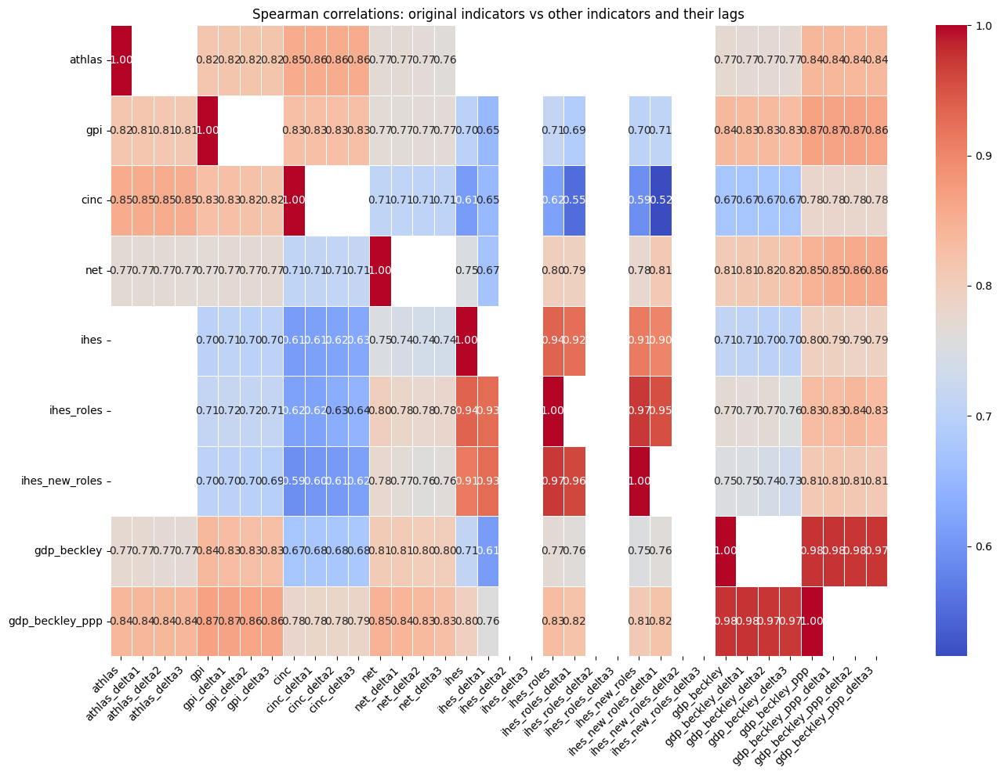

In [938]:
import seaborn as sns
import matplotlib.pyplot as plt

# df — ваш словарь DataFrame.
# 1. Отбираем только те DataFrame, где нет колонки indicator
filtered = {
    name: data[['country', 'year', 'value']].rename(columns={'value': name})
    for name, data in power_dfs.items()
    if 'indicator' not in data.columns
}

# 2. Создаём лаговые колонки и объединяем всё в одну таблицу
merged = None
for name, data in filtered.items():
    # Сортируем для корректного сдвига внутри каждой страны
    data = data.sort_values(['country', 'year'])
    for lag in [1, 2, 3]:
        data[f'{name}_delta{lag}'] = data.groupby('country')[name].shift(lag)
    
    # Объединяем с общей таблицей
    if merged is None:
        merged = data
    else:
        merged = merged.merge(data, on=['country', 'year'], how='outer')

# 3. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 4. Оставляем строки для исходных показателей (без суффиксов _delta*)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# 5. Создаём маску: True для ячеек, где исходный показатель коррелирует со своим же лагом
mask = pd.DataFrame(False, index=result.index, columns=result.columns)
for idx in result.index:
    for col in result.columns:
        if col.startswith(f'{idx}_delta'):
            mask.loc[idx, col] = True

# Применяем маску (заменяем на NaN)
result_masked = result.mask(mask)

# 6. Строим heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    result_masked,
    annot=True,           # показывать значения
    fmt=".2f",            # формат чисел
    cmap='coolwarm',      # цветовая схема
    mask=mask,            # скрыть собственные лаги
    cbar=True,
    linewidths=0.5
)
plt.title('Spearman correlations: original indicators vs other indicators and their lags')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

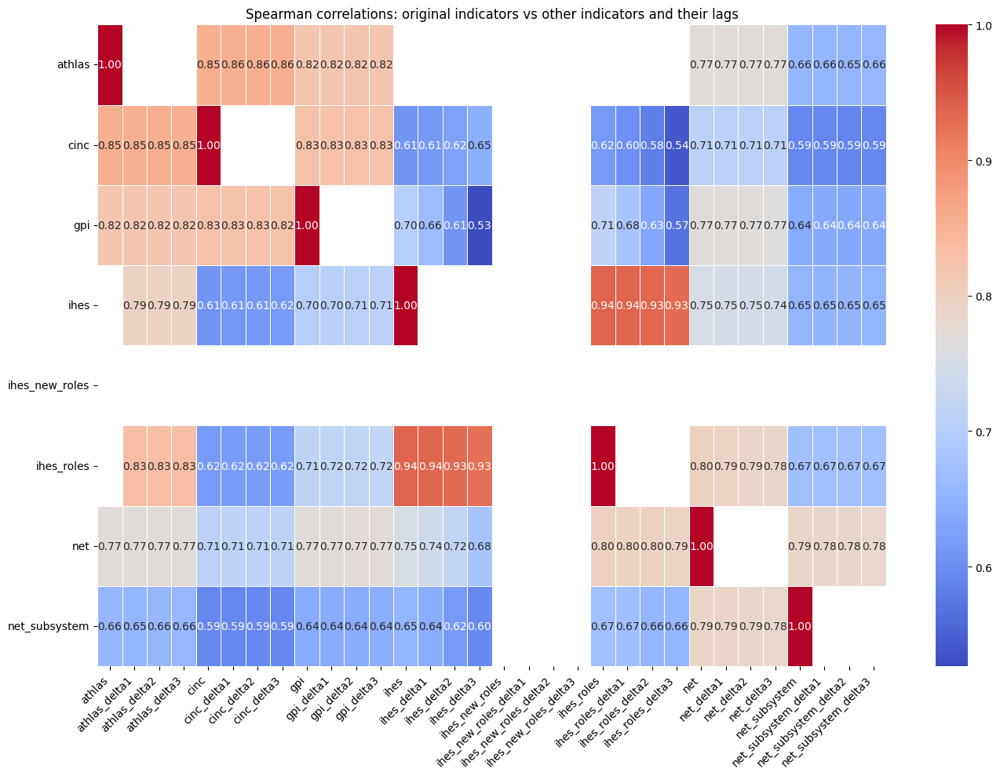

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce

# 1. Отбираем DataFrame без колонки indicator
filtered = {}
for name, data in power_dfs.items():
    if 'indicator' not in data.columns:
        # Оставляем только нужные колонки и переименовываем value в имя показателя
        filtered[name] = data[['country', 'year', 'value']].rename(columns={'value': name})

if not filtered:
    raise ValueError("Нет DataFrame без колонки 'indicator'")

# 2. Создаём общий набор всех уникальных country-year
all_frames = list(filtered.values())
country_year_frames = [power_dfs[['country', 'year']].drop_duplicates() for power_dfs in all_frames]
common_country_year = reduce(
    lambda left, right: pd.merge(left, right, on=['country', 'year'], how='outer'),
    country_year_frames
).drop_duplicates()

# 3. Добавляем к общему каркасу значения каждого показателя
merged = common_country_year.copy()
for name, df in filtered.items():
    merged = merged.merge(df, on=['country', 'year'], how='left')

# 4. Сортируем для корректного сдвига внутри страны
merged = merged.sort_values(['country', 'year']).reset_index(drop=True)

# 5. Вычисляем лаги для каждого показателя
for name in filtered.keys():
    for lag in [1, 2, 3]:
        merged[f'{name}_delta{lag}'] = merged.groupby('country')[name].shift(lag)

# 6. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 7. Оставляем в строках только исходные показатели (без _delta)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# 8. Маска: скрываем корреляции показателя со своими же лагами
mask = pd.DataFrame(False, index=result.index, columns=result.columns)
for idx in result.index:
    for col in result.columns:
        if col.startswith(f'{idx}_delta'):
            mask.loc[idx, col] = True

# 9. Применяем маску (ячейки станут NaN и не будут отображены)
result_masked = result.mask(mask)
# исправляем порядок
result_masked = result_masked.T.sort_index().T.sort_index()

# 10. Строим heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    result_masked,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    mask=mask,
    cbar=True,
    linewidths=0.5
)
plt.title('Spearman correlations: original indicators vs other indicators and their lags')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
result_masked.T.sort_index().T

,athlas,athlas_delta1,athlas_delta2,athlas_delta3,cinc,cinc_delta1,cinc_delta2,cinc_delta3,gpi,gpi_delta1,...,ihes_roles_delta2,ihes_roles_delta3,net,net_delta1,net_delta2,net_delta3,net_subsystem,net_subsystem_delta1,net_subsystem_delta2,net_subsystem_delta3
athlas,1.000000,NaN,NaN,NaN,0.854765,0.855070,0.855376,0.855685,0.819277,0.819662,...,NaN,NaN,0.770213,0.770043,0.770130,0.770266,0.656000,0.655398,0.653685,0.656174
gpi,0.819277,0.819138,0.819068,0.818898,0.826487,0.825889,0.825280,0.824662,1.000000,NaN,...,0.633130,0.570283,0.768509,0.767850,0.767301,0.766743,0.637727,0.636965,0.635059,0.635783
cinc,0.854765,0.854525,0.854289,0.854077,1.000000,NaN,NaN,NaN,0.826487,0.826631,...,0.582290,0.541064,0.709524,0.709309,0.709263,0.709313,0.591652,0.591664,0.590647,0.591499
net_subsystem,0.656000,0.654664,0.656252,0.656857,0.591652,0.592731,0.593386,0.594611,0.637727,0.639407,...,0.655319,0.655310,0.788912,0.788186,0.785040,0.782877,1.000000,NaN,NaN,NaN
net,0.770213,0.770144,0.770125,0.769996,0.709524,0.709854,0.710195,0.710550,0.768509,0.769710,...,0.796383,0.792566,1.000000,NaN,NaN,NaN,0.788912,0.784835,0.784282,0.782650
ihes,NaN,0.794872,0.794872,0.794872,0.609130,0.611821,0.614095,0.615951,0.701488,0.703308,...,0.934474,0.930559,0.750935,0.749215,0.747006,0.744308,0.652440,0.650589,0.651780,0.652829
ihes_roles,NaN,0.831795,0.831795,0.831795,0.616729,0.617906,0.618368,0.618114,0.714758,0.716207,...,NaN,NaN,0.798983,0.793532,0.788439,0.783704,0.672324,0.671238,0.671806,0.672186
ihes_new_roles,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### OIL OLD

In [70]:
global_predictor_dfs['oil']=global_predictor_dfs['oil'].rename({'Constant 2015 US dollar':'value','Year':'year'}, axis=1)

In [147]:
#p=power_dfs['net']
country_corr = dict()
country_corr_value = dict()
for country in power_dfs['net']['country'].unique():#['Russian Federation', 'Saudi Arabia', 'Brazil', 'United States', 'Norway', 'Qatar', 'Germany','Pakistan']:
    p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))
    oildelta=compute_deltas(global_predictor_dfs['oil'], horizons=(1, 2, 3))
    p = p[p['country']==country]
    p=p.merge(oildelta, on='year', suffixes=('net', 'oil'))
    p=p.merge(global_predictor_dfs['oil'][['value','year']], on='year', suffixes=('', ''))
    country_corr[country] = p[['delta_1net',	'delta_2net',	'delta_3net',	'delta_1oil',	'delta_2oil',	'delta_3oil','value']].corr()['delta_1net']
    country_corr_value[country] = country_corr[country]['value']
    print(country)
    print(country_corr[country])

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Australia
delta_1net    1.000000
delta_2net    0.691392
delta_3net    0.611987
delta_1oil   -0.164496
delta_2oil   -0.026137
delta_3oil    0.079658
value        -0.014841
Name: delta_1net, dtype: float64
Austria
delta_1net    1.000000
delta_2net    0.659621
delta_3net    0.463023
delta_1oil   -0.019202
delta_2oil    0.171620
delta_3oil    0.081552
value        -0.111067
Name: delta_1net, dtype: float64
Azerbaijan
delta_1net    1.000000
delta_2net    0.617241
delta_3net    0.587708
delta_1oil   -0.042307
delta_2oil   -0.036192
delta_3oil    0.088681
value         0.077466
Name: delta_1net, dtype: float64
Albania
delta_1net    1.000000
delta_2net    0.811310
delta_3net    0.651350
delta_1oil   -0.011056
delta_2oil    0.082027
delta_3oil    0.007564
value         0.123522
Name: delta_1net, dtype: float64
Algeria
delta_1net    1.000000
delta_2net    0.868809
delta_3net    0.780362
delta_1oil   -0.127420
delta_2oil   -0.132890
delta_3oil   -0.061921
value        -0.014150
Name: delta_1net, 

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Bahamas
delta_1net    1.000000
delta_2net    0.911730
delta_3net    0.795186
delta_1oil   -0.052162
delta_2oil   -0.122923
delta_3oil   -0.088844
value         0.185924
Name: delta_1net, dtype: float64
Bangladesh
delta_1net    1.000000
delta_2net    0.665667
delta_3net    0.601536
delta_1oil   -0.117271
delta_2oil   -0.093472
delta_3oil   -0.020395
value         0.135246
Name: delta_1net, dtype: float64
Barbados
delta_1net    1.000000
delta_2net    0.704479
delta_3net    0.555412
delta_1oil   -0.129940
delta_2oil    0.127037
delta_3oil    0.156425
value         0.140389
Name: delta_1net, dtype: float64
Bahrain
delta_1net    1.000000
delta_2net    0.908616
delta_3net    0.806020
delta_1oil   -0.118342
delta_2oil   -0.137103
delta_3oil   -0.225213
value         0.297346
Name: delta_1net, dtype: float64
Belize
delta_1net    1.000000
delta_2net    0.812659
delta_3net    0.628998
delta_1oil   -0.082798
delta_2oil   -0.158259
delta_3oil   -0.120789
value         0.026044
Name: delta_1net, dt

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Botswana
delta_1net    1.000000
delta_2net    0.715533
delta_3net    0.613628
delta_1oil   -0.126094
delta_2oil   -0.179053
delta_3oil   -0.114539
value        -0.088482
Name: delta_1net, dtype: float64
Brazil
delta_1net    1.000000
delta_2net    0.696306
delta_3net    0.565312
delta_1oil   -0.004331
delta_2oil    0.028829
delta_3oil    0.133438
value         0.239894
Name: delta_1net, dtype: float64
Brunei Darussalam
delta_1net    1.000000
delta_2net    0.795006
delta_3net    0.588578
delta_1oil   -0.257450
delta_2oil   -0.070413
delta_3oil    0.064938
value         0.150981
Name: delta_1net, dtype: float64
Burkina Faso
delta_1net    1.000000
delta_2net    0.889308
delta_3net    0.747502
delta_1oil    0.021718
delta_2oil    0.013240
delta_3oil    0.070087
value         0.176663
Name: delta_1net, dtype: float64
Burundi
delta_1net    1.000000
delta_2net    0.700592
delta_3net    0.567236
delta_1oil   -0.046028
delta_2oil   -0.067310
delta_3oil   -0.068086
value         0.159721
Name: de

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Viet Nam
delta_1net    1.000000
delta_2net    0.775033
delta_3net    0.619329
delta_1oil    0.087673
delta_2oil    0.045605
delta_3oil    0.062073
value         0.226114
Name: delta_1net, dtype: float64
German Democratic Republic
delta_1net    1.000000
delta_2net    0.681106
delta_3net    0.549979
delta_1oil    0.046326
delta_2oil   -0.038210
delta_3oil   -0.075921
value         0.068243
Name: delta_1net, dtype: float64
Gabon
delta_1net    1.000000
delta_2net    0.798694
delta_3net    0.634889
delta_1oil   -0.102709
delta_2oil   -0.184035
delta_3oil   -0.103724
value         0.056329
Name: delta_1net, dtype: float64
Haiti
delta_1net    1.000000
delta_2net    0.832731
delta_3net    0.661132
delta_1oil   -0.066947
delta_2oil   -0.130438
delta_3oil   -0.121955
value         0.044851
Name: delta_1net, dtype: float64
Guyana
delta_1net    1.000000
delta_2net    0.734686
delta_3net    0.625341
delta_1oil    0.173918
delta_2oil    0.202389
delta_3oil    0.045460
value        -0.014579
Name: de

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Honduras
delta_1net    1.000000
delta_2net    0.678267
delta_3net    0.533613
delta_1oil    0.013453
delta_2oil   -0.024974
delta_3oil    0.026239
value         0.177435
Name: delta_1net, dtype: float64
Grenada
delta_1net    1.000000
delta_2net    0.759580
delta_3net    0.650488
delta_1oil   -0.197793
delta_2oil   -0.179855
delta_3oil   -0.202583
value        -0.015070
Name: delta_1net, dtype: float64
Greece
delta_1net    1.000000
delta_2net    0.824571
delta_3net    0.713934
delta_1oil   -0.009561
delta_2oil   -0.004989
delta_3oil   -0.004348
value         0.391511
Name: delta_1net, dtype: float64
Georgia
delta_1net    1.000000
delta_2net    0.848299
delta_3net    0.749718
delta_1oil   -0.031119
delta_2oil   -0.036417
delta_3oil   -0.082024
value         0.370684
Name: delta_1net, dtype: float64
Denmark
delta_1net    1.000000
delta_2net    0.721484
delta_3net    0.646631
delta_1oil   -0.022272
delta_2oil   -0.034121
delta_3oil   -0.097667
value        -0.007429
Name: delta_1net, dtype

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Zimbabwe
delta_1net    1.000000
delta_2net    0.699508
delta_3net    0.516185
delta_1oil   -0.198089
delta_2oil   -0.131603
delta_3oil   -0.104231
value        -0.038116
Name: delta_1net, dtype: float64
Israel
delta_1net    1.000000
delta_2net    0.688915
delta_3net    0.652750
delta_1oil    0.099694
delta_2oil    0.003496
delta_3oil    0.005532
value         0.004093
Name: delta_1net, dtype: float64
India
delta_1net    1.000000
delta_2net    0.809141
delta_3net    0.718692
delta_1oil    0.203499
delta_2oil    0.190675
delta_3oil    0.241887
value         0.428248
Name: delta_1net, dtype: float64
Indonesia
delta_1net    1.000000
delta_2net    0.754998
delta_3net    0.675864
delta_1oil    0.065902
delta_2oil    0.070512
delta_3oil    0.131313
value         0.344023
Name: delta_1net, dtype: float64
Jordan
delta_1net    1.000000
delta_2net    0.693663
delta_3net    0.574976
delta_1oil   -0.239234
delta_2oil   -0.396971
delta_3oil   -0.368473
value        -0.142579
Name: delta_1net, dtype:

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Yemen
delta_1net    1.000000
delta_2net    0.704516
delta_3net    0.576230
delta_1oil    0.033661
delta_2oil    0.100425
delta_3oil    0.053463
value        -0.209462
Name: delta_1net, dtype: float64
Democratic People's Republic of Korea
delta_1net    1.000000
delta_2net    0.582577
delta_3net    0.509240
delta_1oil   -0.030674
delta_2oil   -0.155536
delta_3oil   -0.128996
value         0.008077
Name: delta_1net, dtype: float64
Cabo Verde
delta_1net    1.000000
delta_2net    0.840545
delta_3net    0.675897
delta_1oil   -0.076610
delta_2oil   -0.140806
delta_3oil   -0.108554
value        -0.000184
Name: delta_1net, dtype: float64
Kazakhstan
delta_1net    1.000000
delta_2net    0.849667
delta_3net    0.635421
delta_1oil    0.033211
delta_2oil    0.113521
delta_3oil    0.279331
value         0.142645
Name: delta_1net, dtype: float64
Cambodia
delta_1net    1.000000
delta_2net    0.822947
delta_3net    0.657200
delta_1oil   -0.083814
delta_2oil   -0.123551
delta_3oil   -0.113646
value      

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Kiribati
delta_1net    1.000000
delta_2net    0.706064
delta_3net    0.557607
delta_1oil    0.045534
delta_2oil   -0.049394
delta_3oil   -0.061973
value        -0.175648
Name: delta_1net, dtype: float64
China, People's Republic of
delta_1net    1.000000
delta_2net    0.717073
delta_3net    0.572923
delta_1oil    0.013924
delta_2oil    0.001695
delta_3oil   -0.102228
value         0.078878
Name: delta_1net, dtype: float64
Colombia
delta_1net    1.000000
delta_2net    0.751982
delta_3net    0.558729
delta_1oil   -0.037689
delta_2oil   -0.087519
delta_3oil    0.030224
value         0.160216
Name: delta_1net, dtype: float64
Comoros
delta_1net    1.000000
delta_2net    0.822254
delta_3net    0.645700
delta_1oil   -0.078384
delta_2oil   -0.146357
delta_3oil   -0.120367
value         0.003559
Name: delta_1net, dtype: float64
Congo
delta_1net    1.000000
delta_2net    0.903794
delta_3net    0.779053
delta_1oil    0.014756
delta_2oil   -0.001985
delta_3oil   -0.025872
value         0.091703
Nam

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Lesotho
delta_1net    1.000000
delta_2net    0.723632
delta_3net    0.490128
delta_1oil   -0.121128
delta_2oil   -0.010680
delta_3oil   -0.008387
value         0.085937
Name: delta_1net, dtype: float64
Liberia
delta_1net    1.000000
delta_2net    0.658224
delta_3net    0.502603
delta_1oil    0.112821
delta_2oil   -0.040931
delta_3oil   -0.116439
value         0.057258
Name: delta_1net, dtype: float64
Lebanon
delta_1net    1.000000
delta_2net    0.734608
delta_3net    0.465469
delta_1oil   -0.166352
delta_2oil   -0.148667
delta_3oil    0.048272
value        -0.030951
Name: delta_1net, dtype: float64
Libya
delta_1net    1.000000
delta_2net    0.643378
delta_3net    0.559563
delta_1oil   -0.048382
delta_2oil   -0.031026
delta_3oil   -0.047386
value         0.063841
Name: delta_1net, dtype: float64
Lithuania
delta_1net    1.000000
delta_2net    0.669031
delta_3net    0.457079
delta_1oil    0.152511
delta_2oil    0.188167
delta_3oil    0.153877
value         0.242817
Name: delta_1net, dtype

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Malaysia
delta_1net    1.000000
delta_2net    0.804652
delta_3net    0.684856
delta_1oil   -0.166092
delta_2oil   -0.182712
delta_3oil   -0.167336
value        -0.070911
Name: delta_1net, dtype: float64
Mali
delta_1net    1.000000
delta_2net    0.806492
delta_3net    0.675992
delta_1oil   -0.046404
delta_2oil   -0.076069
delta_3oil    0.011295
value         0.095564
Name: delta_1net, dtype: float64
Maldives
delta_1net    1.000000
delta_2net    0.816684
delta_3net    0.656173
delta_1oil   -0.052262
delta_2oil   -0.094118
delta_3oil   -0.118391
value         0.078190
Name: delta_1net, dtype: float64
Malta
delta_1net    1.000000
delta_2net    0.813158
delta_3net    0.674022
delta_1oil   -0.161708
delta_2oil   -0.149136
delta_3oil   -0.149090
value         0.032303
Name: delta_1net, dtype: float64
Morocco
delta_1net    1.000000
delta_2net    0.695390
delta_3net    0.684962
delta_1oil   -0.124600
delta_2oil   -0.230841
delta_3oil   -0.257136
value         0.005755
Name: delta_1net, dtype: f

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Mongolia
delta_1net    1.000000
delta_2net    0.865794
delta_3net    0.750558
delta_1oil   -0.139197
delta_2oil   -0.227428
delta_3oil   -0.235638
value         0.089462
Name: delta_1net, dtype: float64
Myanmar
delta_1net    1.000000
delta_2net    0.697919
delta_3net    0.717017
delta_1oil   -0.154578
delta_2oil   -0.185544
delta_3oil   -0.148322
value         0.274516
Name: delta_1net, dtype: float64
Namibia
delta_1net    1.000000
delta_2net    0.696302
delta_3net    0.601674
delta_1oil    0.011870
delta_2oil   -0.078268
delta_3oil   -0.076330
value         0.038668
Name: delta_1net, dtype: float64
Nauru
delta_1net    1.000000
delta_2net    0.768806
delta_3net    0.670747
delta_1oil   -0.095113
delta_2oil    0.000652
delta_3oil   -0.143590
value        -0.049950
Name: delta_1net, dtype: float64
Nepal
delta_1net    1.000000
delta_2net    0.837432
delta_3net    0.717936
delta_1oil   -0.032424
delta_2oil   -0.076109
delta_3oil    0.004723
value        -0.522599
Name: delta_1net, dtype: f

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

United Arab Emirates
delta_1net    1.000000
delta_2net    0.653106
delta_3net    0.506155
delta_1oil   -0.149249
delta_2oil   -0.079430
delta_3oil    0.213588
value        -0.062490
Name: delta_1net, dtype: float64
Oman
delta_1net    1.000000
delta_2net    0.703922
delta_3net    0.519377
delta_1oil   -0.014244
delta_2oil   -0.133802
delta_3oil   -0.152555
value        -0.099371
Name: delta_1net, dtype: float64
Pakistan
delta_1net    1.000000
delta_2net    0.619951
delta_3net    0.432051
delta_1oil    0.054298
delta_2oil   -0.003491
delta_3oil   -0.063766
value         0.187881
Name: delta_1net, dtype: float64
Palau
delta_1net    1.000000
delta_2net    0.659531
delta_3net    0.453863
delta_1oil   -0.162299
delta_2oil   -0.151940
delta_3oil   -0.197611
value        -0.206745
Name: delta_1net, dtype: float64
State of Palestine
delta_1net    1.000000
delta_2net    0.806011
delta_3net    0.619039
delta_1oil    0.156238
delta_2oil    0.029823
delta_3oil    0.085025
value         0.270252
Nam

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Republic of Korea
delta_1net    1.000000
delta_2net    0.843739
delta_3net    0.700690
delta_1oil   -0.157725
delta_2oil    0.085659
delta_3oil    0.390970
value         0.389105
Name: delta_1net, dtype: float64
Russian Federation
delta_1net    1.000000
delta_2net    0.712504
delta_3net    0.545494
delta_1oil    0.040098
delta_2oil    0.140365
delta_3oil    0.145047
value         0.142052
Name: delta_1net, dtype: float64
Rwanda
delta_1net    1.000000
delta_2net    0.714107
delta_3net    0.436773
delta_1oil   -0.077409
delta_2oil   -0.094239
delta_3oil   -0.125006
value         0.022784
Name: delta_1net, dtype: float64
Romania
delta_1net    1.000000
delta_2net    0.627557
delta_3net    0.596547
delta_1oil   -0.225520
delta_2oil   -0.285197
delta_3oil   -0.265460
value        -0.016018
Name: delta_1net, dtype: float64
United States
delta_1net    1.000000
delta_2net    0.815418
delta_3net    0.668345
delta_1oil   -0.133465
delta_2oil   -0.170089
delta_3oil   -0.212767
value        -0.3265

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Seychelles
delta_1net    1.000000
delta_2net    0.836015
delta_3net    0.707495
delta_1oil   -0.008726
delta_2oil   -0.090702
delta_3oil   -0.081087
value        -0.252674
Name: delta_1net, dtype: float64
Senegal
delta_1net    1.000000
delta_2net    0.742949
delta_3net    0.535924
delta_1oil    0.039234
delta_2oil    0.028372
delta_3oil    0.080238
value         0.146693
Name: delta_1net, dtype: float64
Saint Vincent and the Grenadines
delta_1net    1.000000
delta_2net    0.820117
delta_3net    0.645145
delta_1oil   -0.116326
delta_2oil   -0.180405
delta_3oil   -0.144169
value         0.004807
Name: delta_1net, dtype: float64
Saint Kitts and Nevis
delta_1net    1.000000
delta_2net    0.713576
delta_3net    0.579632
delta_1oil   -0.007629
delta_2oil   -0.103511
delta_3oil   -0.157918
value        -0.110687
Name: delta_1net, dtype: float64
Saint Lucia
delta_1net    1.000000
delta_2net    0.802119
delta_3net    0.657080
delta_1oil   -0.125053
delta_2oil   -0.196415
delta_3oil   -0.151151


INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Somalia
delta_1net    1.000000
delta_2net    0.846312
delta_3net    0.632648
delta_1oil    0.035735
delta_2oil   -0.079930
delta_3oil   -0.109697
value         0.098022
Name: delta_1net, dtype: float64
Sudan
delta_1net    1.000000
delta_2net    0.697942
delta_3net    0.415638
delta_1oil   -0.005012
delta_2oil    0.017709
delta_3oil   -0.000693
value         0.003034
Name: delta_1net, dtype: float64
Suriname
delta_1net    1.000000
delta_2net    0.798663
delta_3net    0.593399
delta_1oil   -0.042529
delta_2oil   -0.099545
delta_3oil   -0.059499
value         0.133314
Name: delta_1net, dtype: float64
Sierra Leone
delta_1net    1.000000
delta_2net    0.829298
delta_3net    0.675796
delta_1oil   -0.037513
delta_2oil   -0.142270
delta_3oil   -0.141205
value         0.029193
Name: delta_1net, dtype: float64
Tajikistan
delta_1net    1.000000
delta_2net    0.781164
delta_3net    0.477914
delta_1oil   -0.164875
delta_2oil   -0.209340
delta_3oil   -0.156295
value         0.082980
Name: delta_1net

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Tunisia
delta_1net    1.000000
delta_2net    0.715510
delta_3net    0.572808
delta_1oil   -0.181627
delta_2oil   -0.206006
delta_3oil   -0.048271
value        -0.125084
Name: delta_1net, dtype: float64
Turkmenistan
delta_1net    1.000000
delta_2net    0.597697
delta_3net    0.534515
delta_1oil   -0.241694
delta_2oil   -0.268787
delta_3oil   -0.261877
value        -0.081934
Name: delta_1net, dtype: float64
Türkiye
delta_1net    1.000000
delta_2net    0.732677
delta_3net    0.655689
delta_1oil   -0.128862
delta_2oil   -0.252470
delta_3oil   -0.375767
value         0.088942
Name: delta_1net, dtype: float64
Uganda
delta_1net    1.000000
delta_2net    0.701475
delta_3net    0.545345
delta_1oil   -0.008125
delta_2oil   -0.043541
delta_3oil    0.070572
value         0.191583
Name: delta_1net, dtype: float64
Uzbekistan
delta_1net    1.000000
delta_2net    0.869812
delta_3net    0.636502
delta_1oil   -0.085588
delta_2oil   -0.122048
delta_3oil   -0.135266
value         0.010360
Name: delta_1net

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Croatia
delta_1net    1.000000
delta_2net    0.608775
delta_3net   -0.032225
delta_1oil    0.008652
delta_2oil   -0.005935
delta_3oil    0.014563
value         0.057130
Name: delta_1net, dtype: float64
Central African Republic
delta_1net    1.000000
delta_2net    0.788667
delta_3net    0.626868
delta_1oil   -0.042051
delta_2oil   -0.099623
delta_3oil   -0.107346
value        -0.021375
Name: delta_1net, dtype: float64
Chad
delta_1net    1.000000
delta_2net    0.794652
delta_3net    0.651980
delta_1oil    0.027366
delta_2oil   -0.105704
delta_3oil   -0.210713
value         0.050069
Name: delta_1net, dtype: float64
Montenegro
delta_1net    1.000000
delta_2net   -0.703345
delta_3net   -0.525231
delta_1oil    0.087824
delta_2oil    0.197131
delta_3oil    0.248278
value        -0.013255
Name: delta_1net, dtype: float64
Czechia
delta_1net    1.000000
delta_2net    0.638437
delta_3net    0.546036
delta_1oil   -0.058279
delta_2oil   -0.024585
delta_3oil   -0.055821
value        -0.027694
Name: 

INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], dtype='object')
INFO:root:co country data found in Index(['year', 'Europe Brent Spot Price FOB  Dollars per Barrel', 'value'], 

Equatorial Guinea
delta_1net    1.000000
delta_2net    0.676708
delta_3net    0.514053
delta_1oil   -0.073880
delta_2oil   -0.118630
delta_3oil   -0.122349
value         0.011182
Name: delta_1net, dtype: float64
Eritrea
delta_1net    1.000000
delta_2net    0.711741
delta_3net    0.503582
delta_1oil   -0.295389
delta_2oil   -0.293313
delta_3oil   -0.186955
value        -0.210256
Name: delta_1net, dtype: float64
Kingdom of Eswatini
delta_1net    1.000000
delta_2net    0.729673
delta_3net    0.528781
delta_1oil    0.033102
delta_2oil    0.023311
delta_3oil    0.071968
value         0.139337
Name: delta_1net, dtype: float64
Estonia
delta_1net    1.000000
delta_2net    0.807617
delta_3net    0.540597
delta_1oil    0.058061
delta_2oil    0.247752
delta_3oil    0.226227
value         0.286976
Name: delta_1net, dtype: float64
Ethiopia
delta_1net    1.000000
delta_2net    0.828651
delta_3net    0.621899
delta_1oil    0.016591
delta_2oil   -0.079320
delta_3oil   -0.141465
value         0.064998


In [154]:
corr_df=pd.DataFrame.from_dict(country_corr_value, columns=['correl'], orient='index')

In [160]:
corr_df.sort_values('correl').head(50)

,correl
Ireland,-0.716474
Philippines,-0.643370
Nepal,-0.522599
Costa Rica,-0.383383
Bhutan,-0.373987
France,-0.356163
San Marino,-0.348618
Timor-Leste,-0.346778
Belgium,-0.346537
United States,-0.326516


## HEGEMON COHESION

In [223]:
hc = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']=='United States'].rename({'country_b':'country'}, axis=1)

In [228]:
p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))
p.merge(hc, on=['country','year']).loc[:,'delta_1':'value'].corr()['value']

delta_1   -0.019331
delta_2   -0.023758
delta_3   -0.026584
value      1.000000
Name: value, dtype: float64